## Load Experiment Results Data

In [1]:
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt 
from gym_insurance.constants import BUDGET_LIST
import pandas as pd
from pathlib import Path

def read_parquet_files_into_dataframe(folder_path: str) -> pd.DataFrame:
    """
    List all parquet files in the specified folder and read them into a single DataFrame.
    
    :param folder_path: The directory containing parquet files.
    :return: A concatenated DataFrame containing data from all parquet files.
    """
    # List all .parquet files in the folder
    parquet_files = [f for f in Path(folder_path).glob("*.parquet")]
    print(parquet_files)

    # Check if there are parquet files in the folder
    if not parquet_files:
        print(f"No parquet files found in {folder_path}")
        return pd.DataFrame()

    # Read all parquet files into a list of DataFrames
    dataframes = []
    for file in parquet_files:
        print(f"Reading {file}...")
        df = pd.read_parquet(file)
        dataframes.append(df)

    # Concatenate all DataFrames into a single DataFrame
    combined_dataframe = pd.concat(dataframes, axis=0, ignore_index=True)
    combined_dataframe["steps"] = pd.to_numeric(combined_dataframe["steps"])
    combined_dataframe["rewards"] = pd.to_numeric(combined_dataframe["rewards"] )
    combined_dataframe["episodes"] = pd.to_numeric(combined_dataframe["episodes"] )

    return combined_dataframe

# Example usage:
random_folder_path = "..\\.temp\\data\\experiment_results\\random\\results"
dqn_folder_path = "..\\.temp\\data\\experiment_results\\dqn\\insurenv\\"


random_df = read_parquet_files_into_dataframe(random_folder_path).assign(experiment='random')
dqn_df = read_parquet_files_into_dataframe(dqn_folder_path).assign(experiment='dqn')


data = pd.concat(
    [random_df, 
    dqn_df], 
    axis = 0).query("initial_budget in (10_000_000,20_000_000, 30_000_000) ")


[WindowsPath('../.temp/data/experiment_results/random/results/results_10000000.parquet'), WindowsPath('../.temp/data/experiment_results/random/results/results_20000000.parquet'), WindowsPath('../.temp/data/experiment_results/random/results/results_30000000.parquet')]
Reading ..\.temp\data\experiment_results\random\results\results_10000000.parquet...
Reading ..\.temp\data\experiment_results\random\results\results_20000000.parquet...
Reading ..\.temp\data\experiment_results\random\results\results_30000000.parquet...
[WindowsPath('../.temp/data/experiment_results/dqn/insurenv/results_10000000.parquet'), WindowsPath('../.temp/data/experiment_results/dqn/insurenv/results_20000000.parquet'), WindowsPath('../.temp/data/experiment_results/dqn/insurenv/results_30000000.parquet')]
Reading ..\.temp\data\experiment_results\dqn\insurenv\results_10000000.parquet...
Reading ..\.temp\data\experiment_results\dqn\insurenv\results_20000000.parquet...
Reading ..\.temp\data\experiment_results\dqn\insurenv\

In [5]:
import os
import pandas as pd
from benfordslaw import benfordslaw

# Create a directory to store the results if it doesn't exist
results_dir = ".temp/experiment_results"
os.makedirs(results_dir, exist_ok=True)

# Assuming your dataset is loaded into a DataFrame called 'data'
# The dataset includes columns: experiment, rewards, wc, woc,
# valor_indenizacao, initial_budget, decision, episodes

# Define the positions to analyze (first, second, and third digits)
pos_values = [1, 2, 3]

# Group the data by experiment, decision, initial_budget, and episodes
groups = data.groupby(['experiment', 'decision', 'initial_budget', 'episodes'])

# Prepare a list to store summary results
summary_results = []

# Iterate over each group and apply Benford's Law analysis
for (experiment, decision, initial_budget, episodes), group in groups:
    valor_indenizacao = group['valor_indenizacao'].dropna().values
    
    if len(valor_indenizacao) == 0:
        print(
            f"No indemnity values available for Experiment: {experiment}, "
            f"Decision: {decision}, Initial Budget: {initial_budget}, Episodes: {episodes}"
        )
        continue
    
    for pos in pos_values:
        # Initialize the Benford's Law analyzer for this position
        bl = benfordslaw(method='ssd', alpha=0.10, pos=pos)
        
        # Apply Benford's Law to the valor_indenizacao values
        results = bl.fit(valor_indenizacao)
        
        # Append results to the summary list
        summary_results.append({
            'experiment': experiment,
            'decision': decision,
            'initial_budget': initial_budget,
            'episodes': episodes,
            'digit_position': pos,
            'statistic': results['t'],                # The test statistic
            'p_value': results['P'],                  # The p-value
            'is_significant': results['P_significant'],  # Significance flag
        })
    
# Create a summary DataFrame
summary_df = pd.DataFrame(summary_results)

# Save the summary DataFrame to the results directory
summary_filename = os.path.join(results_dir, 'benford_summary_results.csv')
summary_df.to_csv(summary_filename, index=False)
print(f"Summary results saved to: {summary_filename}")



[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0136084, Tstat=12.5651
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0394277, Tstat=10.0601
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0463716, Tstat=9.66986
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.204843, Tstat=5.9247
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.196742, Tstat=6.03239
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.104666, Tstat=7.66461
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.5493, Tstat=3.05116
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.506436, Tstat=3.31578
[benfordslaw] >Analyzing digit position: [3]
[ben

In [9]:
import os
import numpy as np
import pandas as pd
from benfordslaw import benfordslaw
from scipy.stats import norm

# Create a directory to store the results if it doesn't exist
results_dir = ".temp/experiment_results"
os.makedirs(results_dir, exist_ok=True)

# Assuming your dataset is loaded into a DataFrame called 'data'
# The dataset includes columns: experiment, rewards, wc, woc,
# valor_indenizacao, initial_budget, decision, episodes

# Define the positions to analyze (first, second, and third digits)
pos_values = [1, 2, 3]

# Group the data by experiment, decision, initial_budget, and episodes
groups = data.groupby(['experiment', 'decision', 'initial_budget', 'episodes'])

# Prepare a list to store summary results
summary_results = []

# Confidence level for intervals (e.g., 95%)
confidence_level = 0.95
z_score = norm.ppf(1 - (1 - confidence_level) / 2)

# Iterate over each group and apply Benford's Law analysis
for (experiment, decision, initial_budget, episodes), group in groups:
    valor_indenizacao = group['valor_indenizacao'].dropna().values
    
    if len(valor_indenizacao) == 0:
        print(
            f"No indemnity values available for Experiment: {experiment}, "
            f"Decision: {decision}, Initial Budget: {initial_budget}, Episodes: {episodes}"
        )
        continue
    
    for pos in pos_values:
        # Initialize the Benford's Law analyzer for this position
        bl = benfordslaw(method='ssd', alpha=0.10, pos=pos)
        
        # Apply Benford's Law to the valor_indenizacao values
        results = bl.fit(valor_indenizacao)
        
        # Calculate Cramér's V
        chi_squared = results['t']  # Chi-squared statistic
        n = len(valor_indenizacao)
        k = len(results['percentage_emp'])  # Number of categories
        cramers_v = np.sqrt(chi_squared / (n * (k - 1)))
        
        # Calculate confidence intervals for observed proportions
        observed_props = results['percentage_emp'] / 100
        confidence_intervals = []
        for p in observed_props:
            se = np.sqrt(p * (1 - p) / n)
            ci_lower = p - z_score * se
            ci_upper = p + z_score * se
            # Ensure the confidence intervals are within [0, 1]
            ci_lower = np.maximum(ci_lower, 0)
            ci_upper = np.minimum(ci_upper, 1)
            confidence_intervals.append((ci_lower, ci_upper))
        
        # Append results to the summary list
        summary_results.append({
            'experiment': experiment,
            'decision': decision,
            'initial_budget': initial_budget,
            'episodes': episodes,
            'digit_position': pos,
            'statistic': chi_squared,
            'p_value': results['P'],
            'is_significant': results['P_significant'],
            'cramers_v': cramers_v,
            'observed_proportions': observed_props,
            'confidence_intervals': confidence_intervals,
        })

# Create a summary DataFrame
summary_df = pd.DataFrame(summary_results)

# Save the summary DataFrame to the results directory
summary_filename = os.path.join(results_dir, 'benford_summary_results.csv')
summary_df.to_csv(summary_filename, index=False)
print(f"Summary results saved to: {summary_filename}")
    


[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0136084, Tstat=12.5651
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0394277, Tstat=10.0601
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0463716, Tstat=9.66986
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.204843, Tstat=5.9247
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.196742, Tstat=6.03239
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.104666, Tstat=7.66461
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.5493, Tstat=3.05116
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.506436, Tstat=3.31578
[benfordslaw] >Analyzing digit position: [3]
[ben

In [10]:
summary_df

,experiment,decision,initial_budget,episodes,digit_position,statistic,p_value,is_significant,cramers_v,observed_proportions,confidence_intervals
0,dqn,0.0,10000000,1,1,12.565101,0.013608,True,0.723565,"[[0.01, 0.0], [0.02, 0.33333333333333326], [0....","[([0.0, 0.0], [0.12259135894148633, 0.0]), ([0..."
1,dqn,0.0,10000000,1,2,10.060079,0.039428,True,0.610406,"[[0.0, 0.0], [0.01, 0.0], [0.02, 0.0], [0.03, ...","[([0.0, 0.0], [0.0, 0.0]), ([0.0, 0.0], [0.122..."
2,dqn,0.0,10000000,1,3,9.669860,0.046372,True,0.598450,"[[0.0, 0.0], [0.01, 0.33333333333333326], [0.0...","[([0.0, 0.0], [0.0, 0.0]), ([0.0, 0.0], [0.122..."
3,dqn,0.0,10000000,2,1,5.924702,0.204843,False,0.304259,"[[0.01, 0.25], [0.02, 0.25], [0.03, 0.375], [0...","[([0.0, 0.0], [0.07894784471329745, 0.55005697..."
4,dqn,0.0,10000000,2,2,6.032394,0.196742,False,0.289453,"[[0.0, 0.0], [0.01, 0.0], [0.02, 0.125], [0.03...","[([0.0, 0.0], [0.0, 0.0]), ([0.0, 0.0], [0.078..."
...,...,...,...,...,...,...,...,...,...,...,...
4831,random,1.0,30000000,140,2,9.191411,0.056489,True,0.291729,"[[0.0, 0.16666666666666663], [0.01, 0.08333333...","[([0.0, 0.0], [0.0, 0.37752521864694333]), ([0..."
4832,random,1.0,30000000,140,3,11.534866,0.021167,True,0.326809,"[[0.0, 0.08333333333333331], [0.01, 0.08333333...","[([0.0, 0.0], [0.0, 0.23971022075206433]), ([0..."
4833,random,1.0,30000000,141,1,10.588373,0.031601,True,0.575227,"[[0.01, 0.25], [0.02, 0.0], [0.03, 0.0], [0.04...","[([0.0, 0.0], [0.10750697708993937, 0.67434465..."
4834,random,1.0,30000000,141,2,6.703928,0.152386,False,0.431532,"[[0.0, 0.0], [0.01, 0.0], [0.02, 0.0], [0.03, ...","[([0.0, 0.0], [0.0, 0.0]), ([0.0, 0.0], [0.107..."


In [25]:
import plotly.express as px
px.box(summary_df.query("experiment=='dqn'"), 
       x= 'digit_position',
       y = 'cramers_v', color = 'decision', facet_row = 'experiment', facet_col = 'initial_budget', height=1000)

In [17]:
px.box(summary_df.query("digit_position==1"), 
       #x= 'episodes',
       y = 'p_value', color = 'decision', facet_row = 'experiment', facet_col = 'initial_budget', height=1000)

In [18]:
px.box(summary_df.query("digit_position==2"), 
       #x= 'episodes',
       y = 'p_value', color = 'decision', facet_row = 'experiment', facet_col = 'initial_budget', height=1000)

In [26]:
px.box(summary_df.query("digit_position==3"), 
       #x= 'episodes',
       y = 'p_value', color = 'decision', facet_row = 'experiment', facet_col = 'initial_budget', height=1000)

In [42]:
px.line(summary_df.query("initial_budget==20_000_000"), 
       x= 'episodes',
       y = ['p_value'], color = 'decision', facet_row = 'experiment', facet_col = 'digit_position', height=1000)

In [41]:
px.line(summary_df.query("initial_budget==10_000_000"), 
       x= 'episodes',
       y = ['p_value'], color = 'decision', facet_row = 'experiment', facet_col = 'digit_position', height=1000)

In [44]:
summary_df.columns

Index(['experiment', 'decision', 'initial_budget', 'episodes',
       'digit_position', 'statistic', 'p_value', 'is_significant', 'cramers_v',
       'observed_proportions', 'confidence_intervals'],
      dtype='object')

In [47]:
fig = px.line(
    summary_df.query("initial_budget == 10_000_000"), 
    x='episodes',
    y='cramers_v',
    color='decision', 
    facet_row='experiment', 
    facet_col='digit_position', 
    height=1000
)

fig.update_yaxes(matches=None)

fig.show()

In [48]:
fig = px.line(
    summary_df.query("initial_budget == 20_000_000"), 
    x='episodes',
    y='cramers_v',
    color='decision', 
    facet_row='experiment', 
    facet_col='digit_position', 
    height=1000
)

fig.update_yaxes(matches=None)

fig.show()

In [46]:
fig = px.line(
    summary_df.query("initial_budget == 30_000_000"), 
    x='episodes',
    y='cramers_v',
    color='decision', 
    facet_row='experiment', 
    facet_col='digit_position', 
    height=1000
)

fig.update_yaxes(matches=None)

fig.show()

In [43]:
px.line(summary_df.query("initial_budget==30_000_000"), 
       x= 'episodes',
       y = ['p_value'], color = 'decision', facet_row = 'experiment', facet_col = 'digit_position', height=1000)

In [35]:
px.box(summary_df.query("episodes>32 and initial_budget==10_000_000"), y = 'p_value', color = 'decision', facet_col='experiment')

In [36]:
px.box(summary_df.query("episodes>100 and initial_budget==20_000_000"), y = 'p_value', color = 'decision', facet_col='experiment')

In [40]:
px.box(summary_df.query("episodes>77 and initial_budget==20_000_000"), y = 'p_value', color = 'decision', facet_col='experiment', facet_row = 'digit_position', height=1000)

In [51]:
summary_df

,experiment,decision,initial_budget,episodes,digit_position,statistic,p_value,is_significant,cramers_v,observed_proportions,confidence_intervals
0,dqn,0.0,10000000,1,1,12.565101,0.013608,True,0.723565,"[[0.01, 0.0], [0.02, 0.33333333333333326], [0....","[([0.0, 0.0], [0.12259135894148633, 0.0]), ([0..."
1,dqn,0.0,10000000,1,2,10.060079,0.039428,True,0.610406,"[[0.0, 0.0], [0.01, 0.0], [0.02, 0.0], [0.03, ...","[([0.0, 0.0], [0.0, 0.0]), ([0.0, 0.0], [0.122..."
2,dqn,0.0,10000000,1,3,9.669860,0.046372,True,0.598450,"[[0.0, 0.0], [0.01, 0.33333333333333326], [0.0...","[([0.0, 0.0], [0.0, 0.0]), ([0.0, 0.0], [0.122..."
3,dqn,0.0,10000000,2,1,5.924702,0.204843,False,0.304259,"[[0.01, 0.25], [0.02, 0.25], [0.03, 0.375], [0...","[([0.0, 0.0], [0.07894784471329745, 0.55005697..."
4,dqn,0.0,10000000,2,2,6.032394,0.196742,False,0.289453,"[[0.0, 0.0], [0.01, 0.0], [0.02, 0.125], [0.03...","[([0.0, 0.0], [0.0, 0.0]), ([0.0, 0.0], [0.078..."
...,...,...,...,...,...,...,...,...,...,...,...
4831,random,1.0,30000000,140,2,9.191411,0.056489,True,0.291729,"[[0.0, 0.16666666666666663], [0.01, 0.08333333...","[([0.0, 0.0], [0.0, 0.37752521864694333]), ([0..."
4832,random,1.0,30000000,140,3,11.534866,0.021167,True,0.326809,"[[0.0, 0.08333333333333331], [0.01, 0.08333333...","[([0.0, 0.0], [0.0, 0.23971022075206433]), ([0..."
4833,random,1.0,30000000,141,1,10.588373,0.031601,True,0.575227,"[[0.01, 0.25], [0.02, 0.0], [0.03, 0.0], [0.04...","[([0.0, 0.0], [0.10750697708993937, 0.67434465..."
4834,random,1.0,30000000,141,2,6.703928,0.152386,False,0.431532,"[[0.0, 0.0], [0.01, 0.0], [0.02, 0.0], [0.03, ...","[([0.0, 0.0], [0.0, 0.0]), ([0.0, 0.0], [0.107..."


In [54]:
from pprint import pprint 

In [59]:
pprint(list(sorted(data.columns))[20:])

['evento_preponderante_22',
 'evento_preponderante_23',
 'evento_preponderante_24',
 'evento_preponderante_25',
 'evento_preponderante_3',
 'evento_preponderante_4',
 'evento_preponderante_5',
 'evento_preponderante_6',
 'evento_preponderante_7',
 'evento_preponderante_8',
 'evento_preponderante_9',
 'experiment',
 'first_digit_0',
 'first_digit_1',
 'first_digit_2',
 'first_digit_3',
 'first_digit_4',
 'first_digit_5',
 'first_digit_6',
 'first_digit_7',
 'first_digit_8',
 'first_digit_9',
 'initial_budget',
 'nr_documento_segurado',
 'nr_proposta',
 'qt_max_niveldecobertura',
 'qt_max_nr_area_total',
 'qt_max_nr_produtividade_segurada',
 'qt_max_pe_taxa',
 'qt_max_valor_indenizacao',
 'qt_max_vl_limite_garantia',
 'qt_max_vl_premio_liquido',
 'qt_max_vl_subvencao_federal',
 'qt_min_niveldecobertura',
 'qt_min_nr_area_total',
 'qt_min_nr_produtividade_segurada',
 'qt_min_pe_taxa',
 'qt_min_valor_indenizacao',
 'qt_min_vl_limite_garantia',
 'qt_min_vl_premio_liquido',
 'qt_min_vl_subve

In [89]:
decision_analysis = data.pivot_table(
    index = [ 'nr_documento_segurado', 'nr_proposta', 'experiment', 'initial_budget'],
columns = [ 'decision'],
values= 'valor_indenizacao',
aggfunc='count').sort_index().reset_index().fillna(0).merge(summary_df)

In [113]:
data["n_experiments"] = data.groupby( ['nr_documento_segurado', 'nr_proposta'])["experiment"].transform('nunique')

In [114]:
data["n_episodes"] = data.groupby( ['nr_documento_segurado', 'nr_proposta'])["episodes"].transform('nunique')

In [115]:
data["n_decision"] = data.groupby( ['nr_documento_segurado', 'nr_proposta'])["decision"].transform('nunique')

In [129]:
summary_df.columns

Index(['experiment', 'decision', 'initial_budget', 'episodes',
       'digit_position', 'statistic', 'p_value', 'is_significant', 'cramers_v',
       'observed_proportions', 'confidence_intervals'],
      dtype='object')

In [122]:
data.query("n_decision>1 and n_experiments>1").pivot_table(index=['nr_documento_segurado', 'nr_proposta', "experiment", 'decision'], columns = ['initial_budget'], values = 'steps', aggfunc='nunique').reset_index()

initial_budget,nr_documento_segurado,nr_proposta,experiment,decision,10000000,20000000,30000000
0,***00093900,118112125366903,dqn,0.0,1.0,1.0,1.0
1,***00093900,118112125366903,random,0.0,NaN,NaN,1.0
2,***00093900,118112125366903,random,1.0,1.0,1.0,NaN
3,***00260935,28635045,dqn,0.0,NaN,3.0,3.0
4,***00260935,28635045,dqn,1.0,1.0,NaN,NaN
...,...,...,...,...,...,...,...
3989,***99907902,63954,random,1.0,NaN,1.0,NaN
3990,***99981903,2121115398,dqn,0.0,1.0,2.0,NaN
3991,***99981903,2121115398,dqn,1.0,NaN,NaN,1.0
3992,***99981903,2121115398,random,0.0,1.0,NaN,NaN


In [130]:
data.query("n_decision>1 and n_experiments>1 and initial_budget==10_000_000").merge(summary_df).pivot_table(index=['nr_documento_segurado', 'nr_proposta', "experiment"], columns = ['decision', 'is_significant'], values = 'episodes', aggfunc='nunique').reset_index()

decision       nr_documento_segurado           nr_proposta experiment   0.0  \
is_significant                                                        False   
0                        ***00093900       118112125366903        dqn  96.0   
1                        ***00093900       118112125366903     random   NaN   
2                        ***00260935              28635045        dqn   NaN   
3                        ***00318987  10000116410000344692        dqn  15.0   
4                        ***00318987  10000116410000344692     random   NaN   
...                              ...                   ...        ...   ...   
1924                     ***99802968  10000116410000277971        dqn  11.0   
1925                     ***99802968  10000116410000277971     random   NaN   
1926                     ***99907902                 63954        dqn   6.0   
1927                     ***99981903            2121115398        dqn  93.0   
1928                     ***99981903            2121115398     random   1.0   

decision               1.0       
is_significant  True False True  
0               61.0   NaN  NaN  
1                NaN   NaN  1.0  
2                NaN  57.0  NaN  
3                NaN   NaN  NaN  
4                NaN   1.0  1.0  
...              ...   ...  ...  
1924             NaN   NaN  NaN  
1925             NaN   1.0  1.0  
1926             NaN   NaN  NaN  
1927            58.0   NaN  NaN  
1928             1.0   NaN  NaN  

[1929 rows x 7 columns]

In [134]:
data.query("n_decision>1 and n_experiments>1 and initial_budget==10_000_000").merge(summary_df).pivot_table(index=['nr_documento_segurado', 'nr_proposta', "experiment"], columns = ['decision', 'is_significant'], values = 'episodes', aggfunc='nunique').reset_index()

decision       nr_documento_segurado           nr_proposta experiment   0.0  \
is_significant                                                        False   
0                        ***00093900       118112125366903        dqn  96.0   
1                        ***00093900       118112125366903     random   NaN   
2                        ***00260935              28635045        dqn   NaN   
3                        ***00318987  10000116410000344692        dqn  15.0   
4                        ***00318987  10000116410000344692     random   NaN   
...                              ...                   ...        ...   ...   
1924                     ***99802968  10000116410000277971        dqn  11.0   
1925                     ***99802968  10000116410000277971     random   NaN   
1926                     ***99907902                 63954        dqn   6.0   
1927                     ***99981903            2121115398        dqn  93.0   
1928                     ***99981903            2121115398     random   1.0   

decision               1.0       
is_significant  True False True  
0               61.0   NaN  NaN  
1                NaN   NaN  1.0  
2                NaN  57.0  NaN  
3                NaN   NaN  NaN  
4                NaN   1.0  1.0  
...              ...   ...  ...  
1924             NaN   NaN  NaN  
1925             NaN   1.0  1.0  
1926             NaN   NaN  NaN  
1927            58.0   NaN  NaN  
1928             1.0   NaN  NaN  

[1929 rows x 7 columns]

In [145]:
# Assuming 'data' and 'summary_df' are your existing DataFrames

# Perform the query, merge, pivot, and reset index
df_pivot = (
    data.query("n_decision > 1 and n_experiments > 1 and initial_budget == 10_000_000")
        .merge(summary_df)
        .pivot_table(
            index=['nr_documento_segurado', 'nr_proposta', 'experiment'],
            columns=['decision', 'is_significant'],
            values='episodes',
            aggfunc='nunique'
        )
        .reset_index()
)

In [147]:
# Perform the query, merge, pivot, and reset index
df_pivot = (
    data.query("n_decision > 1 and n_experiments > 1 and initial_budget == 10_000_000")
        .merge(summary_df)
        .pivot_table(
            index=['nr_documento_segurado', 'nr_proposta', 'experiment'],
            columns=['decision', 'is_significant'],
            values='episodes',
            aggfunc='nunique'
        )
        .reset_index()
)

# Flatten MultiIndex columns and handle float column names
df_pivot.columns = [
    f"{str(col[0])}_{str(col[1])}" if col[1] not in [None, ''] else str(col[0])
    for col in df_pivot.columns
]

# Display the cleaned DataFrame
df_pivot.head()


,nr_documento_segurado,nr_proposta,experiment,0.0_False,0.0_True,1.0_False,1.0_True
0,***00093900,118112125366903,dqn,96.0,61.0,NaN,NaN
1,***00093900,118112125366903,random,NaN,NaN,NaN,1.0
2,***00260935,28635045,dqn,NaN,NaN,57.0,NaN
3,***00318987,10000116410000344692,dqn,15.0,NaN,NaN,NaN
4,***00318987,10000116410000344692,random,NaN,NaN,1.0,1.0


In [155]:
df_pivot['total'] = df_pivot.filter(regex="True|False").sum(axis=1)

In [158]:
df_pivot.sort_values("0.0_True", ascending=False)

,nr_documento_segurado,nr_proposta,experiment,0.0_False,0.0_True,1.0_False,1.0_True,total
883,***43458949,16546158,dqn,115.0,76.0,NaN,NaN,191.0
619,***29739904,208526389,dqn,114.0,76.0,NaN,NaN,190.0
1286,***65100998,2120926324,dqn,115.0,76.0,NaN,NaN,191.0
1443,***74542961,02011165098,dqn,115.0,76.0,NaN,NaN,191.0
355,***16142915,117641356,dqn,115.0,76.0,NaN,NaN,191.0
...,...,...,...,...,...,...,...,...
1919,***99065995,59691,dqn,16.0,NaN,NaN,NaN,16.0
1921,***99182904,245576933,random,NaN,NaN,1.0,1.0,2.0
1924,***99802968,10000116410000277971,dqn,11.0,NaN,NaN,NaN,11.0
1925,***99802968,10000116410000277971,random,NaN,NaN,1.0,1.0,2.0


0.3885350318471338

In [71]:
data.pivot_table(
    index = [ 'nr_documento_segurado',
 'nr_proposta', 'experiment', 'initial_budget', 'decision'],
values= 'valor_indenizacao',
aggfunc='count').fillna(0).reset_index().merge(summary_df)

,nr_documento_segurado,nr_proposta,experiment,initial_budget,decision,valor_indenizacao,episodes,digit_position,statistic,p_value,is_significant,cramers_v,observed_proportions,confidence_intervals
0,***00006949,10000116410000347145,dqn,20000000,1.0,82,1,1,7.076659,0.131892,False,0.470261,"[[0.01, 0.5], [0.02, 0.0], [0.03, 0.25], [0.04...","[([0.0, 0.010009003864986488], [0.107506977089..."
1,***00006949,10000116410000347145,dqn,20000000,1.0,82,1,2,6.478920,0.166123,False,0.424229,"[[0.0, 0.0], [0.01, 0.25], [0.02, 0.25], [0.03...","[([0.0, 0.0], [0.0, 0.0]), ([0.0, 0.0], [0.107..."
2,***00006949,10000116410000347145,dqn,20000000,1.0,82,1,3,11.430094,0.022133,True,0.563474,"[[0.0, 0.0], [0.01, 0.0], [0.02, 0.0], [0.03, ...","[([0.0, 0.0], [0.0, 0.0]), ([0.0, 0.0], [0.107..."
3,***00006949,10000116410000347145,dqn,20000000,1.0,82,2,1,5.559634,0.234537,False,0.215245,"[[0.01, 0.26666666666666666], [0.02, 0.1333333...","[([0.0, 0.04287828242467359], [0.0603523864544..."
4,***00006949,10000116410000347145,dqn,20000000,1.0,82,2,2,9.689126,0.046003,True,0.267902,"[[0.0, 0.0], [0.01, 0.13333333333333333], [0.0...","[([0.0, 0.0], [0.0, 0.0]), ([0.0, 0.0], [0.060..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11834563,***99995949,5143,dqn,30000000,1.0,32,120,2,0.832186,0.934082,False,0.011973,"[[0.0, 0.10077519379844961], [0.01, 0.12093023...","[([0.0, 0.07754358990757083], [0.0, 0.12400679..."
11834564,***99995949,5143,dqn,30000000,1.0,32,120,3,6.108908,0.191161,False,0.032440,"[[0.0, 0.10232558139534884], [0.01, 0.10852713...","[([0.0, 0.0789361443664358], [0.0, 0.125715018..."
11834565,***99995949,5143,dqn,30000000,1.0,32,121,1,1.350447,0.852760,False,0.016091,"[[0.01, 0.30368098159509205], [0.02, 0.1610429...","[([0.002362664124756864, 0.2683840284056962], ..."
11834566,***99995949,5143,dqn,30000000,1.0,32,121,2,1.014103,0.907650,False,0.013146,"[[0.0, 0.09969325153374232], [0.01, 0.11963190...","[([0.0, 0.07669724484117149], [0.0, 0.12268925..."


In [63]:
data.groupby(["experiment", "initial_budget"])[[ 'nr_documento_segurado',
 'nr_proposta',
]].agg(['nunique'])

nr_documento_segurado nr_proposta
                                        nunique     nunique
experiment initial_budget                                  
dqn        10000000                        4848        5311
           20000000                        8197        9524
           30000000                        9452       11298
random     10000000                         922         940
           20000000                        1328        1356
           30000000                        1661        1702

In [440]:
import os
import pandas as pd
from benfordslaw import benfordslaw

# Create a directory to store the results if it doesn't exist
results_dir = ".temp/experiment_results"
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

# Initialize the Benford's Law analyzer with method='ssd' for the Chi-squared test
bl = benfordslaw(method='ssd', alpha = 0.10)

# Assuming your dataset is loaded into a DataFrame called 'data'
# The dataset includes columns: experiment, rewards, wc, woc, valor_indenizacao, initial_budget, decision, episode

# Group the data by experiment, decision, initial_budget, and episode
groups = data.groupby(['experiment', 'decision', 'initial_budget', 'episodes'])

# Prepare a list to store summary results
summary_results = []

# Iterate over each group and apply Benford's Law analysis
for (experiment, decision, initial_budget, episode), group in groups:
    valor_indenizacao = group['valor_indenizacao'].dropna().values
    
    if len(valor_indenizacao) == 0:
        print(f"No indemnity values available for Experiment: {experiment}, Decision: {decision}, Initial Budget: {initial_budget}, Episode: {episode}")
        continue
    
    # Apply Benford's Law to the valor_indenizacao values
    results = bl.fit(valor_indenizacao)
    
    # Generate plot and save it
    plot_title = f"Benford's Law Analysis for Experiment: {experiment}, Decision: {decision}, Budget: {initial_budget}, Episode: {episode}"

    
    # Append results to the summary list
    summary_results.append({
        'experiment': experiment,
        'decision': decision,
        'initial_budget': initial_budget,
        'episode': episode,
        'KS_stat': results['t'],  # The test statistic for the KS test
        'p_value': results['P'],  # The p-value for the KS test
        'P_significant': results['P_significant'],  # whether it's significant
        'percentage_emp': results['percentage_emp']  # empirical distribution
    })

# Create a summary DataFrame
summary_df = pd.DataFrame(summary_results)

# Save the summary DataFrame to the results directory
summary_filename = f"{results_dir}/benford_summary_results.csv"
summary_df.to_csv(summary_filename, index=False)
print(f"Summary results saved to: {summary_filename}")


[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0136084, Tstat=12.5651
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.204843, Tstat=5.9247
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.5493, Tstat=3.05116
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.253325, Tstat=5.349
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.636048, Tstat=2.54808
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.408443, Tstat=3.98203
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.673175, Tstat=2.34177
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.371729, Tstat=4.26183
[benfordslaw] >Analyzing digit position: [1]
[b

In [441]:
summary_df.pivot_table(index = ["episode"], columns = ["experiment","initial_budget", "decision"], values = "KS_stat").T

episode                                   0          1          2    \
experiment initial_budget decision                                    
dqn        10000000       0.0             NaN  12.565101   5.924702   
                          1.0             NaN  10.655256   6.788238   
           20000000       0.0             NaN   4.777967   5.764489   
                          1.0             NaN   7.076659   5.559634   
           30000000       0.0             NaN   4.777967   4.341847   
                          1.0             NaN   7.076659   1.785116   
random     10000000       0.0       14.884744   8.161154   8.204264   
                          1.0       14.478455  11.006118  13.109566   
           20000000       0.0        2.536083   2.271624  12.512054   
                          1.0       10.642097   4.521152   4.979178   
           30000000       0.0        1.041439   2.445180   8.723767   
                          1.0        6.596997   4.259108   2.961652   

episode                                   3          4          5    \
experiment initial_budget decision                                    
dqn        10000000       0.0        3.051165   5.349001   2.548078   
                          1.0       11.493631   6.659381   7.256085   
           20000000       0.0        6.552244   4.843893   3.141243   
                          1.0        6.796381   2.723401   4.790652   
           30000000       0.0        9.344867   3.054338   0.900171   
                          1.0        2.132497   7.357912   1.201980   
random     10000000       0.0       15.199501  14.478455  20.110510   
                          1.0       15.647698  10.989379   9.895385   
           20000000       0.0        4.259108   6.088018  11.463640   
                          1.0        8.404869   6.883849  20.426267   
           30000000       0.0       14.478455   2.600002   9.621357   
                          1.0        4.907089   3.298106   3.256922   

episode                                   6          7          8    \
experiment initial_budget decision                                    
dqn        10000000       0.0        3.982033   2.341770   4.261828   
                          1.0        6.378651  11.945302  12.651043   
           20000000       0.0        1.826600   1.157066   4.116793   
                          1.0        2.499401   2.950274   5.327077   
           30000000       0.0        0.428980   1.835583   1.814121   
                          1.0        2.650247   2.844969   3.664073   
random     10000000       0.0       13.388088  14.478455   7.880793   
                          1.0       10.526543  14.478455   8.152841   
           20000000       0.0        6.792451  10.642097   4.040626   
                          1.0        5.432258  15.647698   5.133714   
           30000000       0.0        5.835421   6.043175   3.965855   
                          1.0        6.390415   7.671982   8.601276   

episode                                   9    ...        134       135  \
experiment initial_budget decision             ...                        
dqn        10000000       0.0        3.654032  ...        NaN       NaN   
                          1.0       11.986199  ...        NaN       NaN   
           20000000       0.0        1.928925  ...  10.095163  9.008309   
                          1.0        4.695604  ...   1.824294  1.698891   
           30000000       0.0        2.316818  ...        NaN       NaN   
                          1.0        1.213925  ...        NaN       NaN   
random     10000000       0.0       18.423891  ...        NaN       NaN   
                          1.0       11.006118  ...        NaN       NaN   
           20000000       0.0       15.201999  ...        NaN       NaN   
                          1.0       10.942863  ...        NaN       NaN   
           30000000       0.0        8.061664  ...        NaN       NaN   
                          1.0        3.3

In [442]:
summary_df.pivot_table(index = ["episode"], columns = ["experiment","initial_budget", "decision"], values = "p_value").T

episode                                  0         1         2         3    \
experiment initial_budget decision                                           
dqn        10000000       0.0            NaN  0.013608  0.204843  0.549300   
                          1.0            NaN  0.030724  0.147511  0.021542   
           20000000       0.0            NaN  0.310847  0.217440  0.161528   
                          1.0            NaN  0.131892  0.234537  0.147048   
           30000000       0.0            NaN  0.310847  0.361714  0.053034   
                          1.0            NaN  0.131892  0.775204  0.711405   
random     10000000       0.0       0.004946  0.085850  0.084376  0.004305   
                          1.0       0.005915  0.026495  0.010753  0.003530   
           20000000       0.0       0.638186  0.685940  0.013923  0.372074   
                          1.0       0.030895  0.340047  0.289441  0.077824   
           30000000       0.0       0.903449  0.654478  0.068387  0.005915   
                          1.0       0.158780  0.372074  0.564263  0.296964   

episode                                  4         5         6         7    \
experiment initial_budget decision                                           
dqn        10000000       0.0       0.253325  0.636048  0.408443  0.673175   
                          1.0       0.155021  0.122958  0.172599  0.017763   
           20000000       0.0       0.303693  0.534473  0.767612  0.885116   
                          1.0       0.605126  0.309460  0.644743  0.566181   
           30000000       0.0       0.548774  0.924536  0.980036  0.765966   
                          1.0       0.118140  0.877772  0.617948  0.584095   
random     10000000       0.0       0.005915  0.000475  0.009527  0.005915   
                          1.0       0.026684  0.042227  0.032433  0.005915   
           20000000       0.0       0.192671  0.021819  0.147271  0.030895   
                          1.0       0.142155  0.000411  0.245749  0.003530   
           30000000       0.0       0.626823  0.047312  0.211781  0.195947   
                          1.0       0.509232  0.515786  0.171827  0.104360   

episode                                  8         9    ...       134  \
experiment initial_budget decision                      ...             
dqn        10000000       0.0       0.371729  0.454847  ...       NaN   
                          1.0       0.013113  0.017454  ...       NaN   
           20000000       0.0       0.390430  0.748830  ...  0.038855   
                          1.0       0.255353  0.319980  ...  0.768035   
           30000000       0.0       0.769898  0.677709  ...       NaN   
                          1.0       0.453373  0.875801  ...       NaN   
random     10000000       0.0       0.096044  0.001020  ...       NaN   
                          1.0       0.086137  0.026495  ...       NaN   
           20000000       0.0       0.400536  0.004300  ...       NaN   
                          1.0       0.273851  0.027214  ...       NaN   
           30000000       0.0       0.410647  0.089345  ...       NaN   
                          1.0       0.071876  0.504935  ...       NaN   

episode                                  135       136       137       138  \
experiment initial_budget decision                                           
dqn        10000000       0.0            NaN       NaN       NaN       NaN   
                          1.0            NaN       NaN       NaN       NaN   
           20000000       0.0       0.060892  0.068822  0.067094  0.080349   
                          1.0       0.790919  0.777517  0.726237  0.759156   
           30000000       0.0            NaN       NaN       NaN       NaN   
                          1.0            NaN       NaN       NaN       NaN   
random     10000000       0.0            NaN       NaN       NaN       NaN   
                          1.0            NaN       NaN       NaN       NaN   
           

In [443]:
summary_df.pivot_table(index = ["episode"], columns = ["experiment","initial_budget", "decision"], values = "P_significant").reset_index()

experiment     episode      dqn                                    random  \
initial_budget         10000000      20000000      30000000      10000000   
decision                    0.0  1.0      0.0  1.0      0.0  1.0      0.0   
0                    0      NaN  NaN      NaN  NaN      NaN  NaN      1.0   
1                    1      1.0  1.0      0.0  0.0      0.0  0.0      1.0   
2                    2      0.0  0.0      0.0  0.0      0.0  0.0      1.0   
3                    3      0.0  1.0      0.0  0.0      1.0  0.0      1.0   
4                    4      0.0  0.0      0.0  0.0      0.0  0.0      1.0   
..                 ...      ...  ...      ...  ...      ...  ...      ...   
139                139      NaN  NaN      1.0  0.0      NaN  NaN      NaN   
140                140      NaN  NaN      1.0  0.0      NaN  NaN      NaN   
141                141      NaN  NaN      1.0  0.0      NaN  NaN      NaN   
142                142      NaN  NaN      1.0  0.0      NaN  NaN      NaN   
143                143      NaN  NaN      1.0  0.0      NaN  NaN      NaN   

experiment                                       
initial_budget      20000000      30000000       
decision        1.0      0.0  1.0      0.0  1.0  
0               1.0      0.0  1.0      0.0  0.0  
1               1.0      0.0  0.0      0.0  0.0  
2               1.0      1.0  0.0      1.0  0.0  
3               1.0      0.0  1.0      1.0  0.0  
4               1.0      0.0  0.0      0.0  0.0  
..              ...      ...  ...      ...  ...  
139             NaN      NaN  NaN      NaN  NaN  
140             NaN      NaN  NaN      NaN  NaN  
141             NaN      NaN  NaN      NaN  NaN  
142             NaN      NaN  NaN      NaN  NaN  
143             NaN      NaN  NaN      NaN  NaN  

[144 rows x 13 columns]

In [444]:
import plotly.express as px
px.line(summary_df,x = 'episode', y ="p_value", color = 'decision', facet_row = 'experiment', facet_col = 'initial_budget', height=1000)

<Axes: xlabel='episode'>

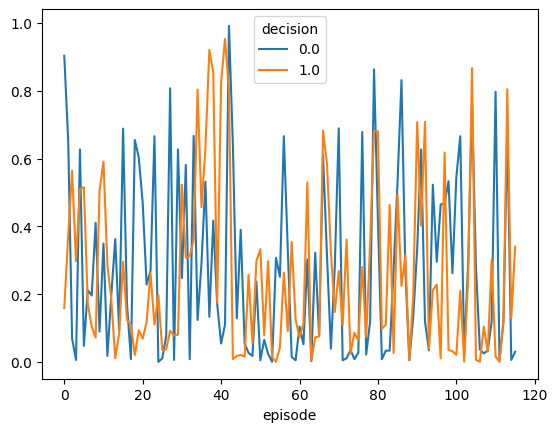

In [416]:
summary_df.query("initial_budget == 30_000_000 and experiment=='random'").pivot_table(index= 'episode', columns='decision', values = 'p_value').plot()

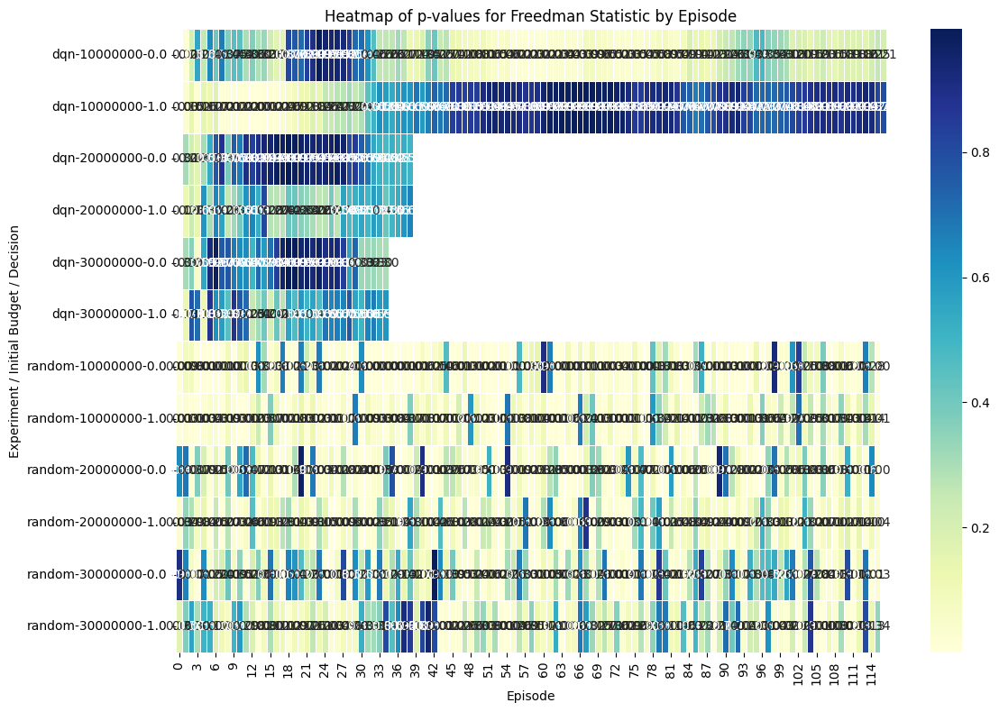

In [267]:
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming 'summary_df' is your DataFrame, and the pivot table has already been created

# Create the pivot table for the heatmap
pivot_table = summary_df.pivot_table(
    index=["experiment", "initial_budget", "decision"], 
    columns="episode", 
    values="p_value"
)

# Plot the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(pivot_table, cmap="YlGnBu", annot=True, fmt=".2f", linewidths=.5)

# Set plot labels and title
plt.title('Heatmap of p-values for Freedman Statistic by Episode')
plt.xlabel('Episode')
plt.ylabel('Experiment / Initial Budget / Decision')

# Show the plot
plt.tight_layout()
plt.show()


Analyzing random, Decision 0.0, Budget 10000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[chi2] No anomaly detected. P=0.0561527, Tstat=15.1576
Analyzing random, Decision 0.0, Budget 10000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[chi2] No anomaly detected. P=0.691478, Tstat=6.47615
Analyzing random, Decision 0.0, Budget 10000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[chi2] No anomaly detected. P=0.994775, Tstat=1.75509
Analyzing random, Decision 0.0, Budget 20000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[chi2] No anomaly detected. P=0.171612, Tstat=11.5666
Analyzing random, Decision 0.0, Budget 20000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[chi2] No anomaly detected. P=0.552989, Tstat=7.81405
Analyzing random, Decision 0.0, Budget 20000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[ch

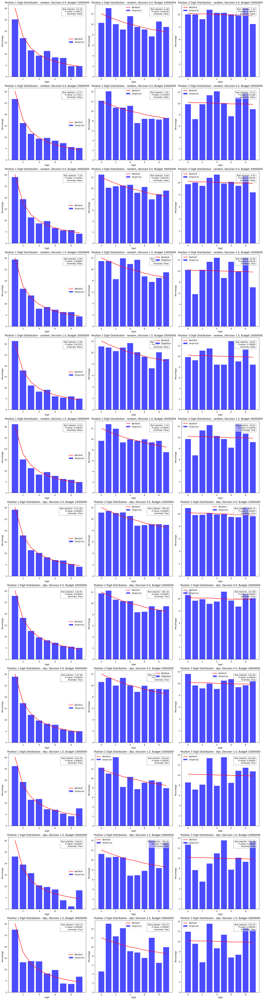

Report saved to .temp/experiment_results/plots/benford_report.png
Summary of Benford's Law Analysis:


In [268]:
import pandas as pd
import matplotlib.pyplot as plt
from benfordslaw import benfordslaw
import numpy as np
import os
import math

class BenfordAnalyzer:
    def __init__(self, data, experiments, decisions, budgets, save_dir=".temp/experiment_results/plots"):
        """
        Initialize the BenfordAnalyzer with dataset, experiment, decision, and budget combinations.
        """
        self.data = data.dropna(subset=['value'])  # Clean the data by dropping NaN values
        self.experiments = experiments
        self.decisions = decisions
        self.budgets = budgets
        self.save_dir = save_dir  # Directory to save plots
        if not os.path.exists(self.save_dir):
            os.makedirs(self.save_dir)

    def analyze(self):
        """
        Analyze the dataset using Benford's Law for the first three digits across various combinations.
        """
        # Determine the number of plot rows required
        total_plots = len(self.experiments) * len(self.decisions) * len(self.budgets)
        ncols = 3  # Fixed number of columns for 1st, 2nd, and 3rd digits
        nrows = total_plots  # Number of rows is total plots, as we have 3 columns per row

        fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 6 * nrows))

        # Flatten axes array to easily reference each plot position
        axes = axes.reshape(-1, ncols)

        plot_idx = 0  # Keeps track of plot position for each combination

        # Loop through each combination
        for experiment in self.experiments:
            for decision in self.decisions:
                for initial_budget in self.budgets:
                    # Filter dataset for the specific combination
                    subset = self.data[(self.data['experiment'] == experiment) & 
                                       (self.data['decision'] == decision) & 
                                       (self.data['initial_budget'] == initial_budget)]
                    
                    # Check if there are values to analyze
                    if subset.empty:
                        print(f"No data for {experiment}, Decision {decision}, Budget {initial_budget}.")
                        continue
                    
                    # Perform Benford's Law analysis and plot all positions in one row (1st, 2nd, and 3rd digit)
                    self._analyze_subset(subset, experiment, decision, initial_budget, axes[plot_idx])
                    plot_idx += 1

        # Hide any unused subplots
        for i in range(plot_idx, len(axes)):
            for ax in axes[i]:
                ax.remove()  # Remove any extra unused axes

        # Save the entire report as a one-page PNG file
        report_filename = f"{self.save_dir}/benford_report.png"
        plt.tight_layout()
        plt.subplots_adjust(top=0.95)
        plt.savefig(report_filename)
        plt.show()
        print(f"Report saved to {report_filename}")
        plt.close(fig)  # Close the figure

    def _analyze_subset(self, subset, experiment, decision, initial_budget, axes_row):
        """
        Helper function to analyze a specific subset of data for the first three digit positions and plot them.
        Adds annotations to the plots with statistical results.
        """
        # Perform Benford's Law analysis for each position (1st, 2nd, and 3rd digit)
        for pos in range(1, 4):  # Looping through first, second, and third digits
            benford = benfordslaw(pos=pos)
            values = subset['value'].astype(float).values

            print(f"Analyzing {experiment}, Decision {decision}, Budget {initial_budget}, Position {pos}:")
            
            # Fit the data to Benford's Law
            benford.fit(values)
            
            # Adjust digit range depending on the digit position
            if pos == 1:
                digit_range = range(1, 10)  # Digits 1 to 9
            else:
                digit_range = range(0, 10)  # Digits 0 to 9 for positions 2 and 3
            
            # Plot empirical and expected Benford distribution
            axes = axes_row[pos - 1]
            axes.bar(digit_range, benford.results['percentage_emp'][:, 1], color='blue', alpha=0.7, label='Empirical')
            axes.plot(digit_range, benford.leading_digits, 'r-', label='Benford', linewidth=2)
            axes.set_title(f'Position {pos} Digit Distribution - {experiment}, Decision {decision}, Budget {initial_budget}')
            axes.set_xlabel('Digit')
            axes.set_ylabel('Percentage')
            axes.legend()

            # Add annotations directly on the plot
            p_value = benford.results['P']
            t_stat = benford.results['t']
            anomaly_detected = benford.results['P_significant']
            annotation_text = f"Test statistic: {t_stat:.2f}\nP-value: {p_value:.5f}\nAnomaly: {anomaly_detected}"
            axes.text(0.95, 0.95, annotation_text, transform=axes.transAxes, fontsize=10,
                      verticalalignment='top', horizontalalignment='right', bbox=dict(facecolor='white', alpha=0.5))

    def summarize(self):
        """
        Generate automated reports based on the analysis.
        This could be expanded to generate CSV reports, alerts, etc.
        """
        print("Summary of Benford's Law Analysis:")
        # This is a placeholder; you could expand this to create more detailed reports or alerts
        # based on the goodness-of-fit test results.


# Example usage:
# Assuming `data` is your DataFrame with the necessary columns
experiments = ['random', 'dqn']
decisions = [0.0, 1.0]
budgets = list(data.initial_budget.unique())

# Create an instance of the BenfordAnalyzer class
benford_analyzer = BenfordAnalyzer(data, experiments, decisions, budgets)

# Perform the analysis
benford_analyzer.analyze()

# Optionally, generate a summary report
benford_analyzer.summarize()



In [87]:
data.groupby('experiment').episodes.max()

experiment
dqn       116
random      3
Name: episodes, dtype: int64

# Results Analysis  

In [88]:
data.groupby(["experiment","episodes", "initial_budget"])['steps'].max()

experiment  episodes  initial_budget
dqn         1         10000000           5.0
            2         10000000           9.0
                      20000000          13.0
                      30000000           9.0
            3         10000000           9.0
                                        ... 
random      2         20000000          11.0
                      30000000          12.0
            3         10000000           4.0
                      20000000           4.0
                      30000000          12.0
Name: steps, Length: 134, dtype: float64

Analyzing random, Decision 0.0, Budget 10000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.650314, Tstat=2.46834
Goodness-of-Fit Results for Position 1:
Test statistic: 2.468341335662538, p-value: 0.6503135976758636
Anomaly detected: False


Analyzing random, Decision 0.0, Budget 10000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.287742, Tstat=4.99567
Goodness-of-Fit Results for Position 2:
Test statistic: 4.995666985391051, p-value: 0.28774237859102153
Anomaly detected: False


Analyzing random, Decision 0.0, Budget 10000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00518688, Tstat=14.777
Goodness-of-Fit Results for Position 3:
Test statistic: 14.77696452015061, p-value: 0.005186881369337505
Anomaly detected: True


Plot saved to .temp/experiment_results/plots/random_decision_0.0_budge

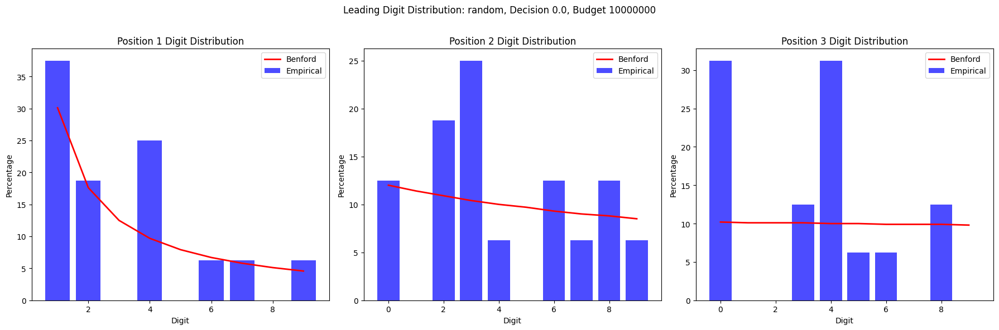

Analyzing random, Decision 0.0, Budget 20000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.288668, Tstat=4.98667
Goodness-of-Fit Results for Position 1:
Test statistic: 4.9866662955281384, p-value: 0.2886683549176909
Anomaly detected: False


Analyzing random, Decision 0.0, Budget 20000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0422123, Tstat=9.89624
Goodness-of-Fit Results for Position 2:
Test statistic: 9.896235671627593, p-value: 0.042212326796386694
Anomaly detected: True


Analyzing random, Decision 0.0, Budget 20000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.126206, Tstat=7.18951
Goodness-of-Fit Results for Position 3:
Test statistic: 7.189511437657915, p-value: 0.12620595703967252
Anomaly detected: False


Plot saved to .temp/experiment_results/plots/random_decision_0.0_budg

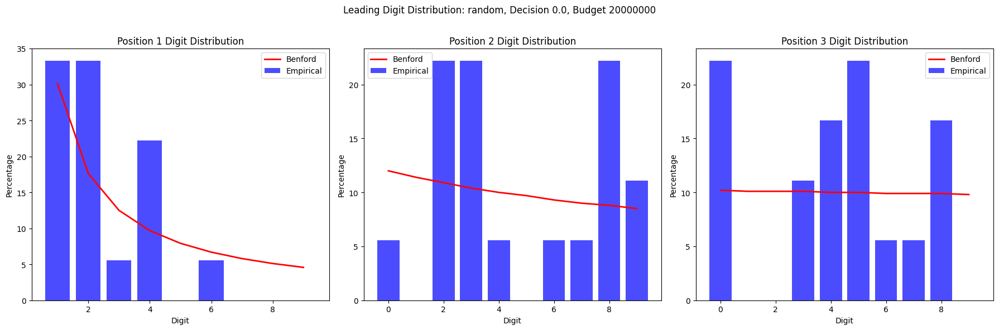

Analyzing random, Decision 0.0, Budget 30000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.961291, Tstat=0.61581
Goodness-of-Fit Results for Position 1:
Test statistic: 0.6158100382766202, p-value: 0.961290732951899
Anomaly detected: False


Analyzing random, Decision 0.0, Budget 30000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.405234, Tstat=4.0057
Goodness-of-Fit Results for Position 2:
Test statistic: 4.005704225041751, p-value: 0.4052344172433265
Anomaly detected: False


Analyzing random, Decision 0.0, Budget 30000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.146808, Tstat=6.8006
Goodness-of-Fit Results for Position 3:
Test statistic: 6.800603367512138, p-value: 0.14680815968043084
Anomaly detected: False


Plot saved to .temp/experiment_results/plots/random_decision_0.0_budget

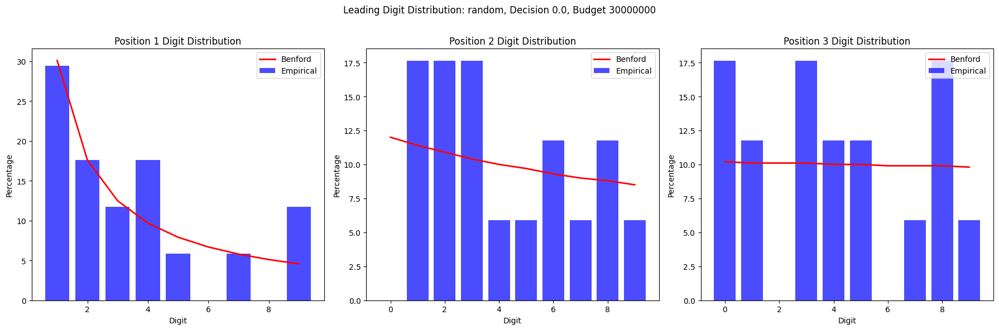

Analyzing random, Decision 1.0, Budget 10000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.23615, Tstat=5.54099
Goodness-of-Fit Results for Position 1:
Test statistic: 5.540993136585644, p-value: 0.2361495803289726
Anomaly detected: False


Analyzing random, Decision 1.0, Budget 10000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.294557, Tstat=4.92999
Goodness-of-Fit Results for Position 2:
Test statistic: 4.9299868334661525, p-value: 0.29455701832313164
Anomaly detected: False


Analyzing random, Decision 1.0, Budget 10000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0758369, Tstat=8.46886
Goodness-of-Fit Results for Position 3:
Test statistic: 8.468856196308797, p-value: 0.07583688420945377
Anomaly detected: False


Plot saved to .temp/experiment_results/plots/random_decision_1.0_bu

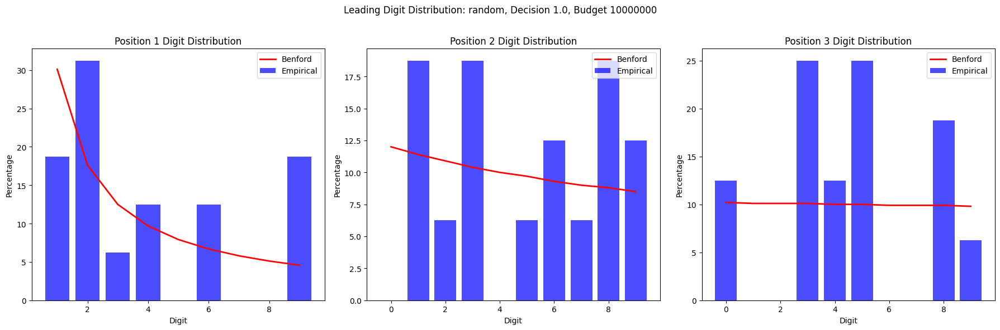

Analyzing random, Decision 1.0, Budget 20000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.161502, Tstat=6.55267
Goodness-of-Fit Results for Position 1:
Test statistic: 6.552672973716397, p-value: 0.16150166854533382
Anomaly detected: False


Analyzing random, Decision 1.0, Budget 20000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.739615, Tstat=1.97904
Goodness-of-Fit Results for Position 2:
Test statistic: 1.979035181869318, p-value: 0.7396150741390597
Anomaly detected: False


Analyzing random, Decision 1.0, Budget 20000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0157661, Tstat=12.2233
Goodness-of-Fit Results for Position 3:
Test statistic: 12.223250008996924, p-value: 0.015766083899243336
Anomaly detected: True


Plot saved to .temp/experiment_results/plots/random_decision_1.0_budg

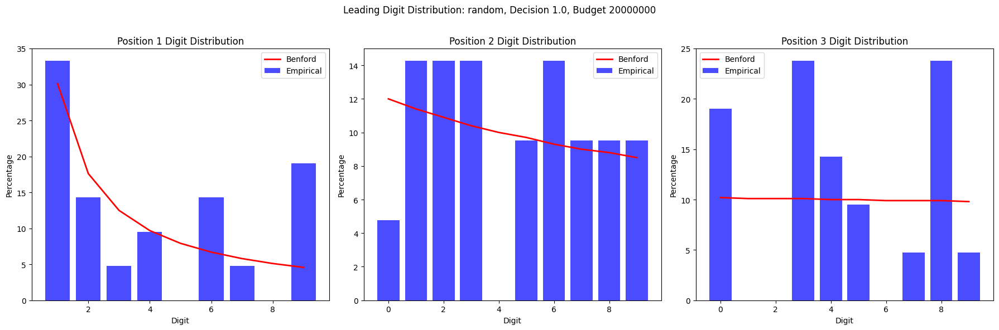

Analyzing random, Decision 1.0, Budget 30000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.288639, Tstat=4.98695
Goodness-of-Fit Results for Position 1:
Test statistic: 4.986951592518847, p-value: 0.28863896569322456
Anomaly detected: False


Analyzing random, Decision 1.0, Budget 30000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.133419, Tstat=7.04711
Goodness-of-Fit Results for Position 2:
Test statistic: 7.0471117184566445, p-value: 0.1334194331735639
Anomaly detected: False


Analyzing random, Decision 1.0, Budget 30000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0226963, Tstat=11.371
Goodness-of-Fit Results for Position 3:
Test statistic: 11.370981945951772, p-value: 0.022696346351141893
Anomaly detected: True


Plot saved to .temp/experiment_results/plots/random_decision_1.0_budg

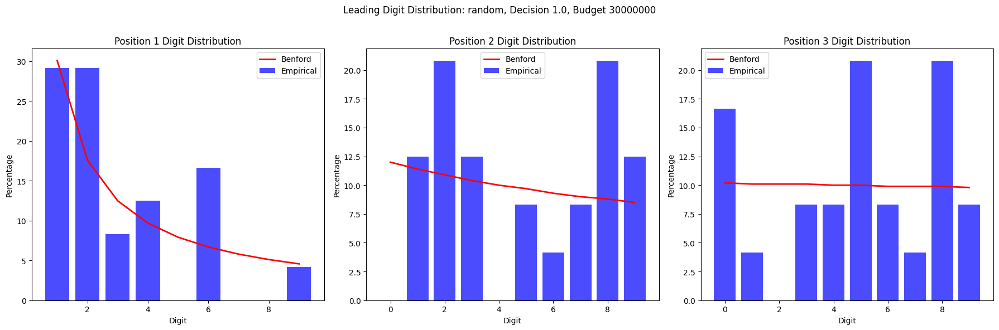

Analyzing dqn, Decision 0.0, Budget 10000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=6.08154e-245, Tstat=1137.35
Goodness-of-Fit Results for Position 1:
Test statistic: 1137.3463044007035, p-value: 6.081542487227317e-245
Anomaly detected: True


Analyzing dqn, Decision 0.0, Budget 10000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] Anomaly detected! P=1.04822e-160, Tstat=748.588
Goodness-of-Fit Results for Position 2:
Test statistic: 748.588462005765, p-value: 1.048220757822043e-160
Anomaly detected: True


Analyzing dqn, Decision 0.0, Budget 10000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=5.19891e-136, Tstat=634.532
Goodness-of-Fit Results for Position 3:
Test statistic: 634.532023421483, p-value: 5.1989073804186505e-136
Anomaly detected: True


Plot saved to .temp/experiment_results/plots/dqn_decision_0.0_budge

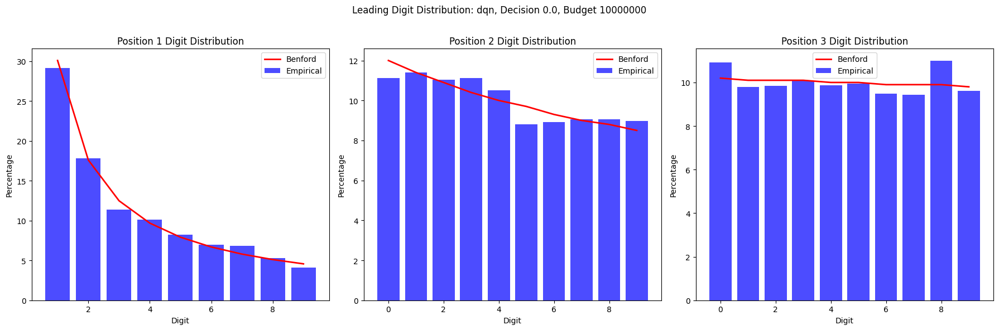

Analyzing dqn, Decision 0.0, Budget 20000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0123918, Tstat=12.782
Goodness-of-Fit Results for Position 1:
Test statistic: 12.781954375509184, p-value: 0.012391838228716177
Anomaly detected: True


Analyzing dqn, Decision 0.0, Budget 20000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00168921, Tstat=17.301
Goodness-of-Fit Results for Position 2:
Test statistic: 17.301012267255338, p-value: 0.0016892075411679577
Anomaly detected: True


Analyzing dqn, Decision 0.0, Budget 20000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=1.52413e-05, Tstat=27.5702
Goodness-of-Fit Results for Position 3:
Test statistic: 27.57024495822931, p-value: 1.5241310176219853e-05
Anomaly detected: True


Plot saved to .temp/experiment_results/plots/dqn_decision_0.0_budget_2000000

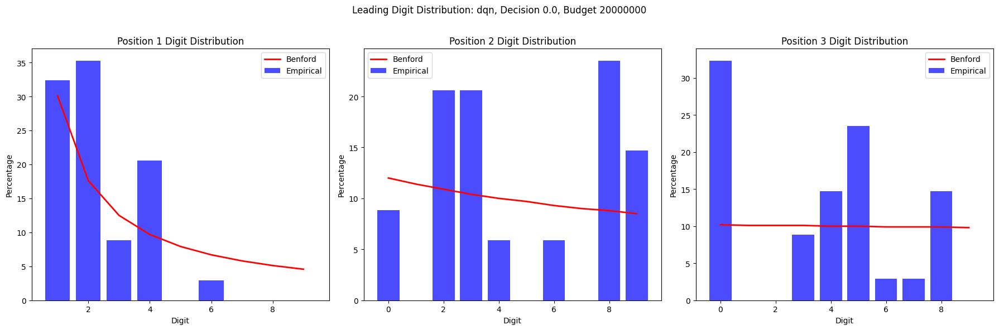

Analyzing dqn, Decision 0.0, Budget 30000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.181022, Tstat=6.25317
Goodness-of-Fit Results for Position 1:
Test statistic: 6.253172860443675, p-value: 0.1810221471556068
Anomaly detected: False


Analyzing dqn, Decision 0.0, Budget 30000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0536375, Tstat=9.3174
Goodness-of-Fit Results for Position 2:
Test statistic: 9.317401821754881, p-value: 0.05363751408584066
Anomaly detected: False


Analyzing dqn, Decision 0.0, Budget 30000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00248465, Tstat=16.4378
Goodness-of-Fit Results for Position 3:
Test statistic: 16.437753363894238, p-value: 0.0024846499694205623
Anomaly detected: True


Plot saved to .temp/experiment_results/plots/dqn_decision_0.0_budget_3000000

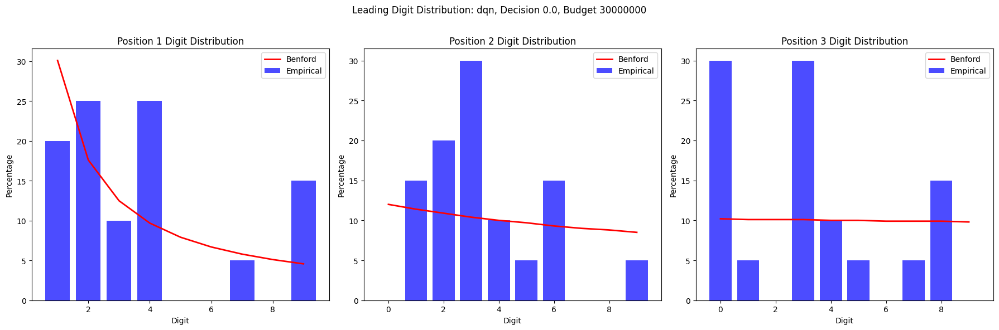

Analyzing dqn, Decision 1.0, Budget 10000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=4.42382e-137, Tstat=639.476
Goodness-of-Fit Results for Position 1:
Test statistic: 639.4755560591825, p-value: 4.423820145017003e-137
Anomaly detected: True


Analyzing dqn, Decision 1.0, Budget 10000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] Anomaly detected! P=1.10925e-80, Tstat=378.704
Goodness-of-Fit Results for Position 2:
Test statistic: 378.7039891902155, p-value: 1.1092540981083788e-80
Anomaly detected: True


Analyzing dqn, Decision 1.0, Budget 10000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=5.49297e-191, Tstat=888.378
Goodness-of-Fit Results for Position 3:
Test statistic: 888.3775634350771, p-value: 5.49297204481625e-191
Anomaly detected: True


Plot saved to .temp/experiment_results/plots/dqn_decision_1.0_budget_

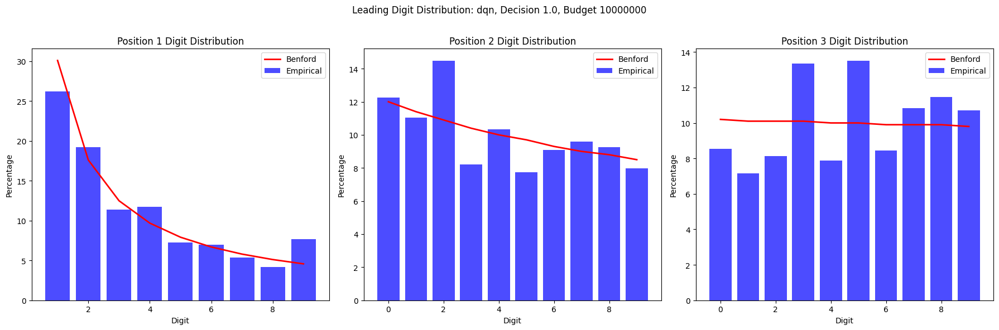

Analyzing dqn, Decision 1.0, Budget 20000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.000268493, Tstat=21.3612
Goodness-of-Fit Results for Position 1:
Test statistic: 21.36123469633806, p-value: 0.00026849278469673885
Anomaly detected: True


Analyzing dqn, Decision 1.0, Budget 20000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.307462, Tstat=4.809
Goodness-of-Fit Results for Position 2:
Test statistic: 4.809004642587668, p-value: 0.3074620685903238
Anomaly detected: False


Analyzing dqn, Decision 1.0, Budget 20000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=5.89409e-06, Tstat=29.6034
Goodness-of-Fit Results for Position 3:
Test statistic: 29.603353143347995, p-value: 5.894089285991071e-06
Anomaly detected: True


Plot saved to .temp/experiment_results/plots/dqn_decision_1.0_budget_200000

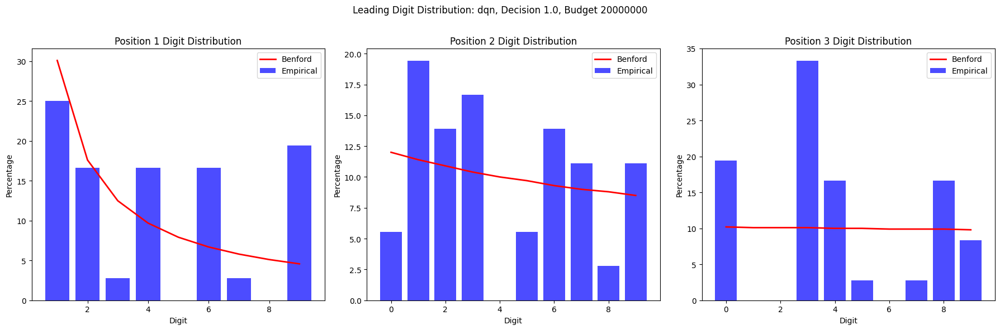

Analyzing dqn, Decision 1.0, Budget 30000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00593714, Tstat=14.4698
Goodness-of-Fit Results for Position 1:
Test statistic: 14.469820729837396, p-value: 0.005937139151235732
Anomaly detected: True


Analyzing dqn, Decision 1.0, Budget 30000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] Anomaly detected! P=2.72864e-06, Tstat=31.2449
Goodness-of-Fit Results for Position 2:
Test statistic: 31.24492274836166, p-value: 2.7286420268255257e-06
Anomaly detected: True


Analyzing dqn, Decision 1.0, Budget 30000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0037019, Tstat=15.5406
Goodness-of-Fit Results for Position 3:
Test statistic: 15.540553272310287, p-value: 0.003701902927515875
Anomaly detected: True


Plot saved to .temp/experiment_results/plots/dqn_decision_1.0_budget_300000

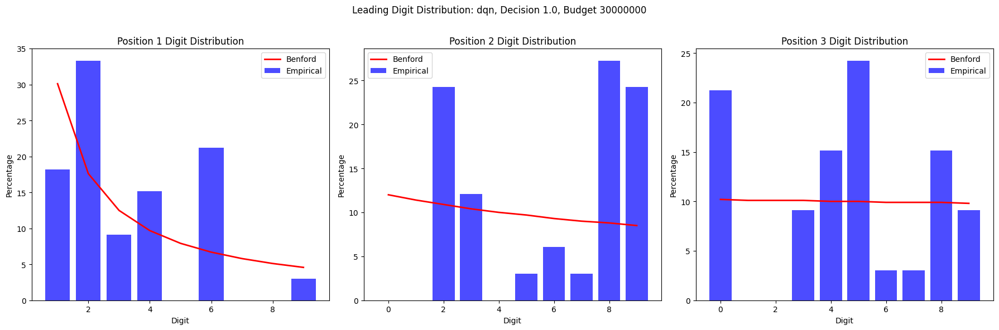

Summary of Benford's Law Analysis:


In [89]:
import pandas as pd
import matplotlib.pyplot as plt
from benfordslaw import benfordslaw
import numpy as np
import os

class BenfordAnalyzer:
    def __init__(self, data, experiments, decisions, budgets, save_dir=".temp/experiment_results/plots"):
        """
        Initialize the BenfordAnalyzer with dataset, experiment, decision, and budget combinations.
        """
        self.data = data.dropna(subset=['value'])  # Clean the data by dropping NaN values
        self.experiments = experiments
        self.decisions = decisions
        self.budgets = budgets
        self.save_dir = save_dir  # Directory to save plots
        if not os.path.exists(self.save_dir):
            os.makedirs(self.save_dir)

    def analyze(self):
        """
        Analyze the dataset using Benford's Law for the first three digits across various combinations.
        """
        # Loop through each combination
        for experiment in self.experiments:
            for decision in self.decisions:
                for initial_budget in self.budgets:
                    # Filter dataset for the specific combination
                    subset = self.data[(self.data['experiment'] == experiment) & 
                                       (self.data['decision'] == decision) & 
                                       (self.data['initial_budget'] == initial_budget)]
                    
                    # Check if there are values to analyze
                    if subset.empty:
                        print(f"No data for {experiment}, Decision {decision}, Budget {initial_budget}.")
                        continue
                    
                    # Perform Benford's Law analysis for first digit, second digit, and third digit
                    self._analyze_subset(subset, experiment, decision, initial_budget)

    def _analyze_subset(self, subset, experiment, decision, initial_budget):
        """
        Helper function to analyze a specific subset of data for the first three digit positions.
        """
        # Initialize subplots: 1 row, 3 columns for positions 1, 2, and 3
        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        
        # Perform Benford's Law analysis for each position (1st, 2nd, and 3rd digit)
        for pos in range(1, 4):  # Looping through first, second, and third digits
            benford = benfordslaw(pos=pos, method = 'ds')
            values = subset['value'].astype(float).values

            print(f"Analyzing {experiment}, Decision {decision}, Budget {initial_budget}, Position {pos}:")
            
            # Fit the data to Benford's Law
            benford.fit(values)
            
            # Adjust digit range depending on the digit position
            if pos == 1:
                digit_range = range(1, 10)  # Digits 1 to 9
            else:
                digit_range = range(0, 10)  # Digits 0 to 9 for positions 2 and 3
            
            # Plot empirical and expected Benford distribution
            axes[pos - 1].bar(digit_range, benford.results['percentage_emp'][:, 1], color='blue', alpha=0.7, label='Empirical')
            axes[pos - 1].plot(digit_range, benford.leading_digits, 'r-', label='Benford', linewidth=2)
            axes[pos - 1].set_title(f'Position {pos} Digit Distribution')
            axes[pos - 1].set_xlabel('Digit')
            axes[pos - 1].set_ylabel('Percentage')
            axes[pos - 1].legend()

            # Perform statistical tests and print a summary of results
            self._goodness_of_fit(benford, values, pos)

        # Adjust the layout, save the plot, and display it
        fig.suptitle(f'Leading Digit Distribution: {experiment}, Decision {decision}, Budget {initial_budget}')
        plt.tight_layout()
        plt.subplots_adjust(top=0.85)
        
        # Save plot to file
        plot_filename = f"{self.save_dir}/{experiment}_decision_{decision}_budget_{initial_budget}.png"
        plt.savefig(plot_filename)
        print(f"Plot saved to {plot_filename}")
        
        # Show plot on the screen
        plt.show()
        plt.close(fig)  # Close the plot to avoid memory issues

    def _goodness_of_fit(self, benford, values, pos):
        """
        Perform goodness-of-fit tests and report the results.
        """
        # Access the correct keys from the results dictionary
        p_value = benford.results['P']
        t_stat = benford.results['t']

        print(f"Goodness-of-Fit Results for Position {pos}:")
        print(f"Test statistic: {t_stat}, p-value: {p_value}")
        print(f"Anomaly detected: {benford.results['P_significant']}")
        print("\n")

    def summarize(self):
        """
        Generate automated reports based on the analysis.
        This could be expanded to generate CSV reports, alerts, etc.
        """
        print("Summary of Benford's Law Analysis:")
        # This is a placeholder; you could expand this to create more detailed reports or alerts
        # based on the goodness-of-fit test results.


# Example usage:
# Assuming `data` is your DataFrame with the necessary columns
experiments = ['random', 'dqn']
decisions = [0.0, 1.0]
budgets = list(data.initial_budget.unique())

# Create an instance of the BenfordAnalyzer class
benford_analyzer = BenfordAnalyzer(data, experiments, decisions, budgets)

# Perform the analysis
benford_analyzer.analyze()

# Optionally, generate a summary report
benford_analyzer.summarize()


[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0136084, Tstat=12.5651


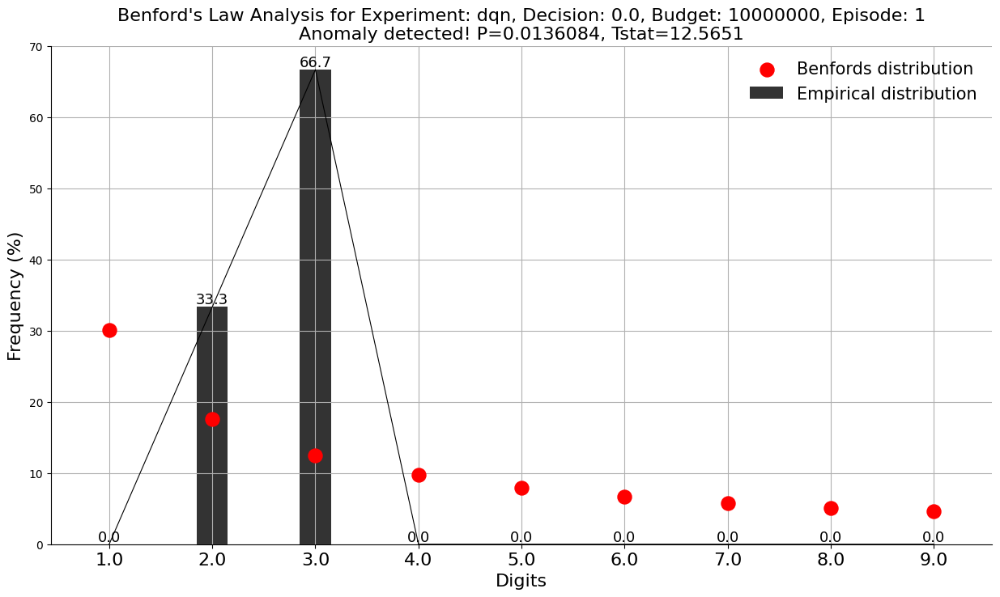

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget10000000_episode1.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.326749, Tstat=4.63579


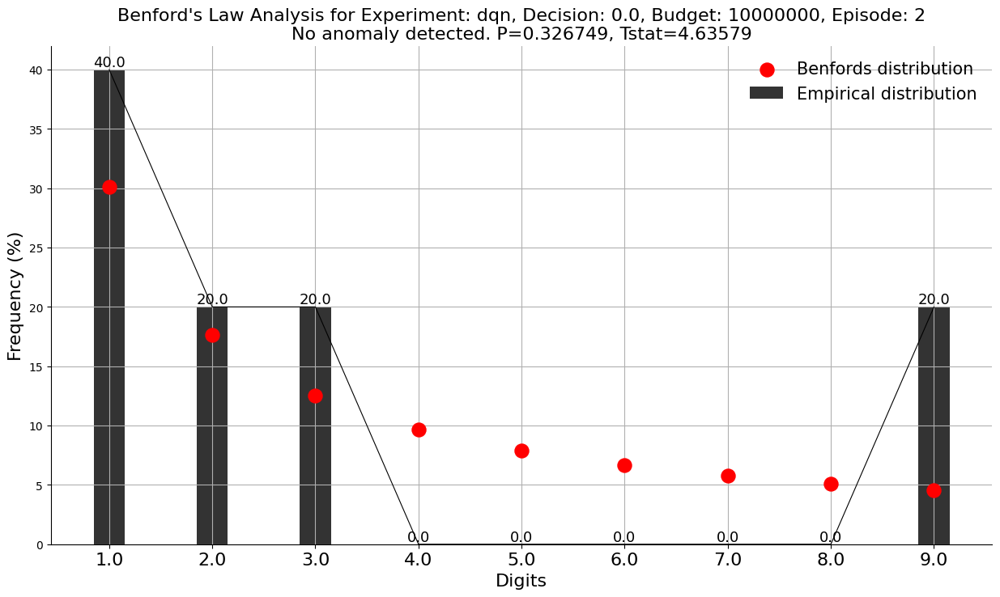

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget10000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.119073, Tstat=7.33791


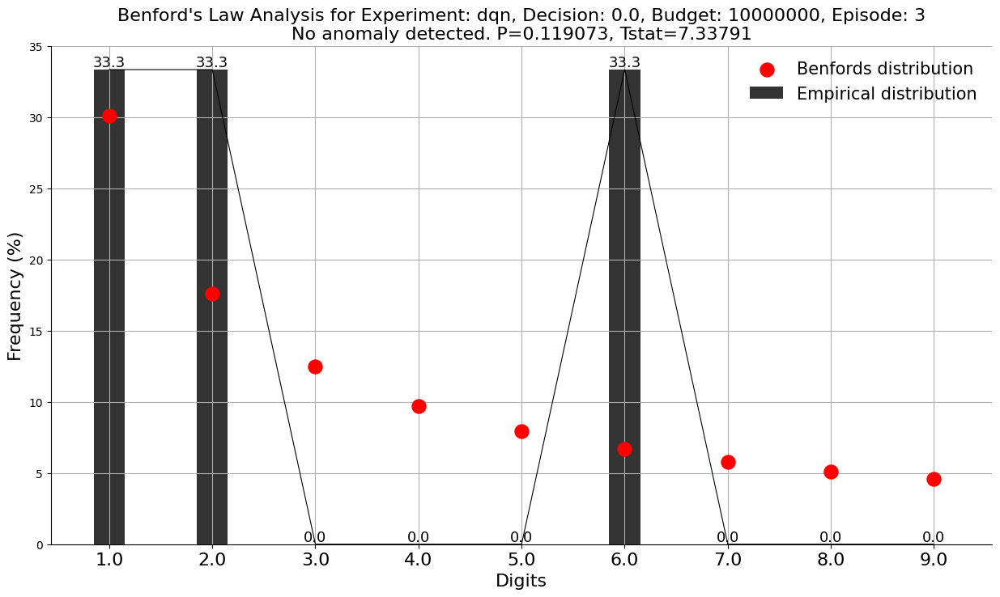

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget10000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.406326, Tstat=3.99764


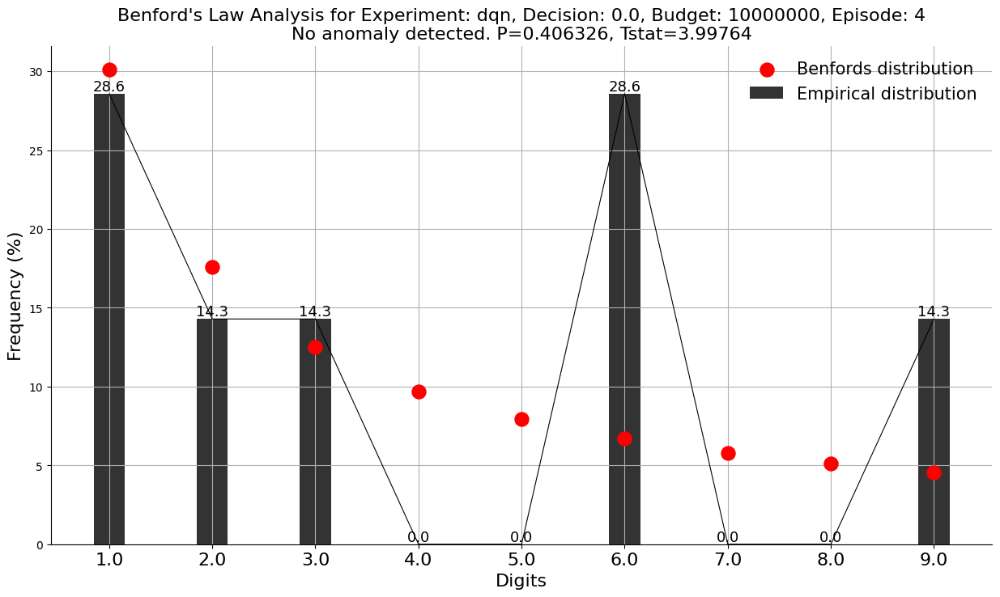

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget10000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


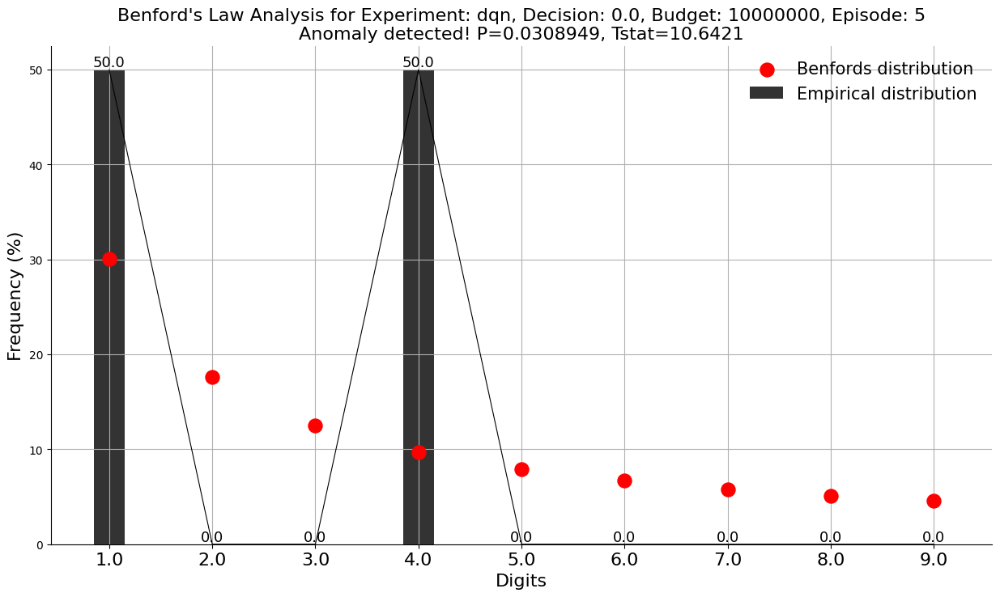

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget10000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.153496, Tstat=6.68509


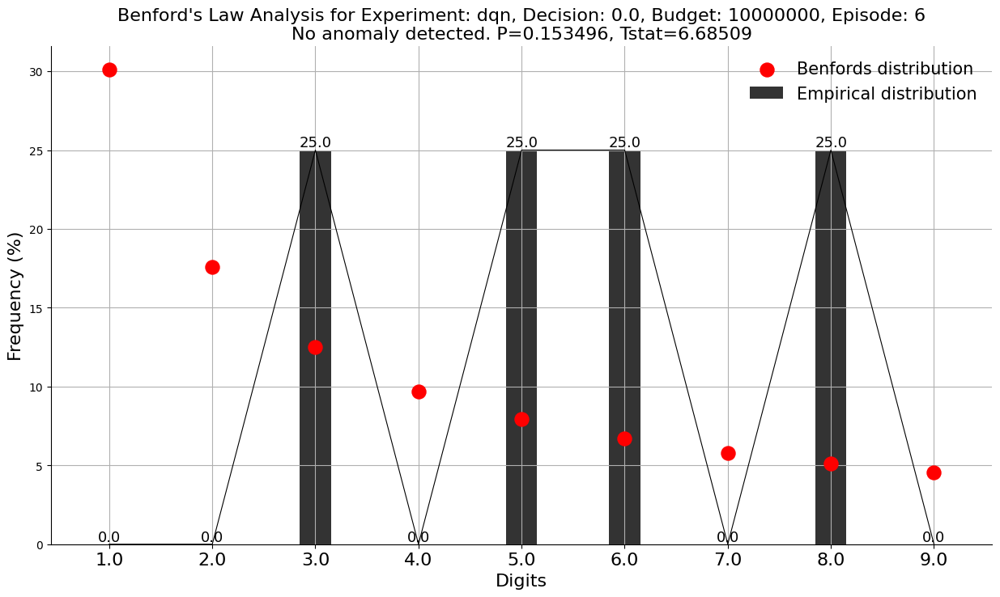

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget10000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0145698, Tstat=12.4067


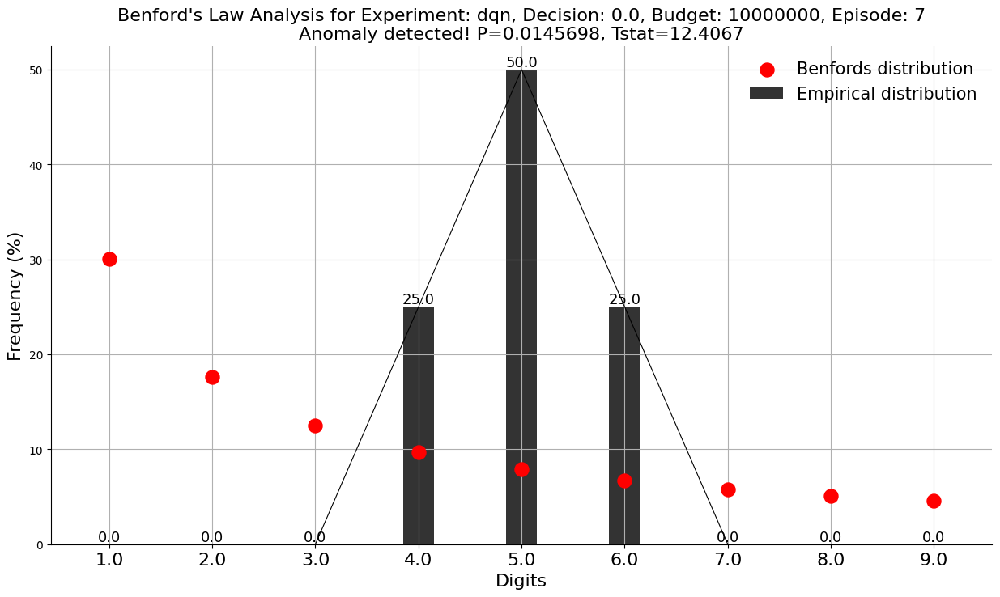

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget10000000_episode7.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0390577, Tstat=10.0827


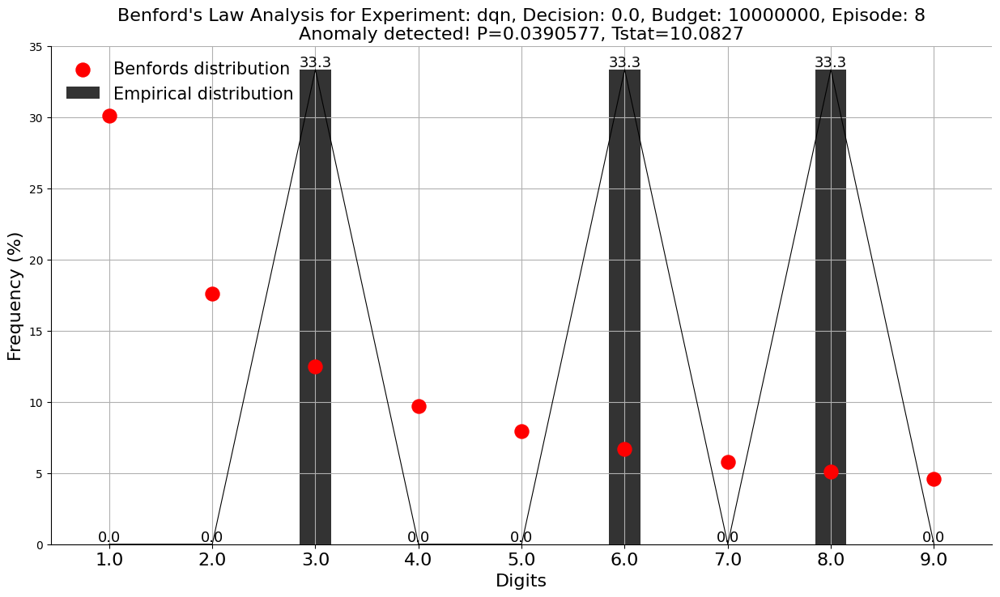

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget10000000_episode8.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00591466, Tstat=14.4785


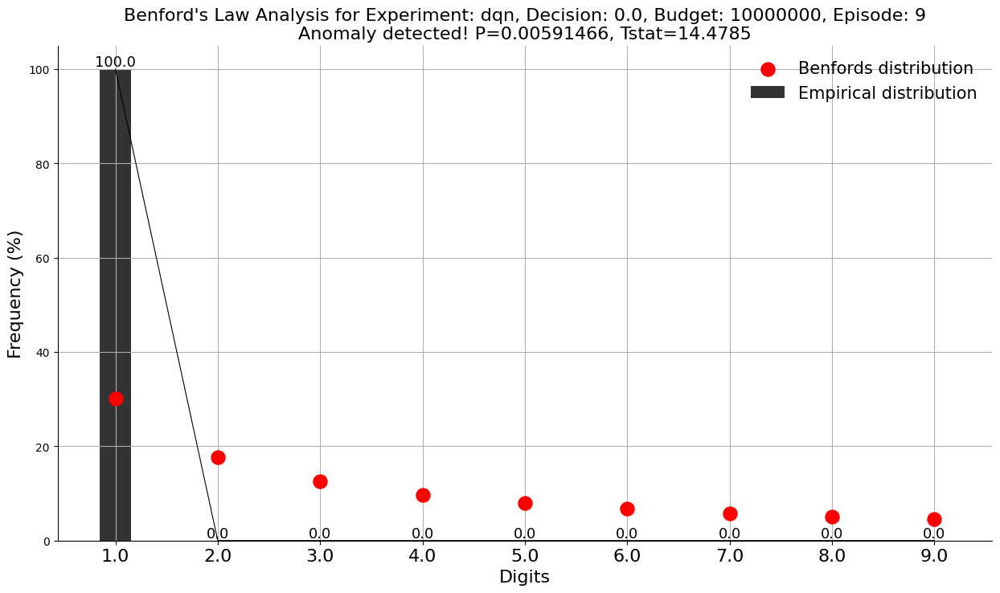

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget10000000_episode9.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.310847, Tstat=4.77797


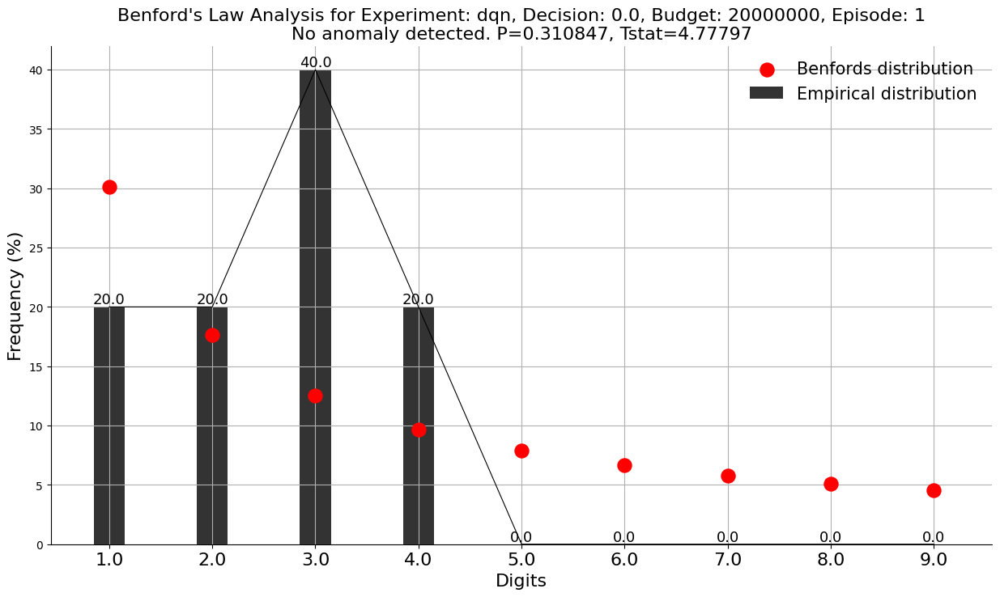

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000_episode1.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.142155, Tstat=6.88385


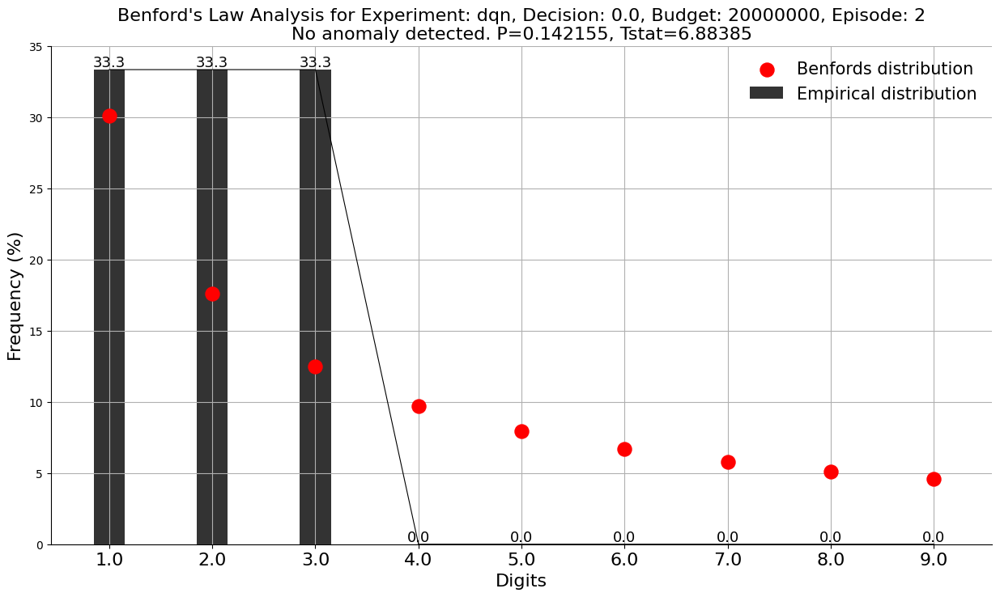

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.667268, Tstat=2.37435


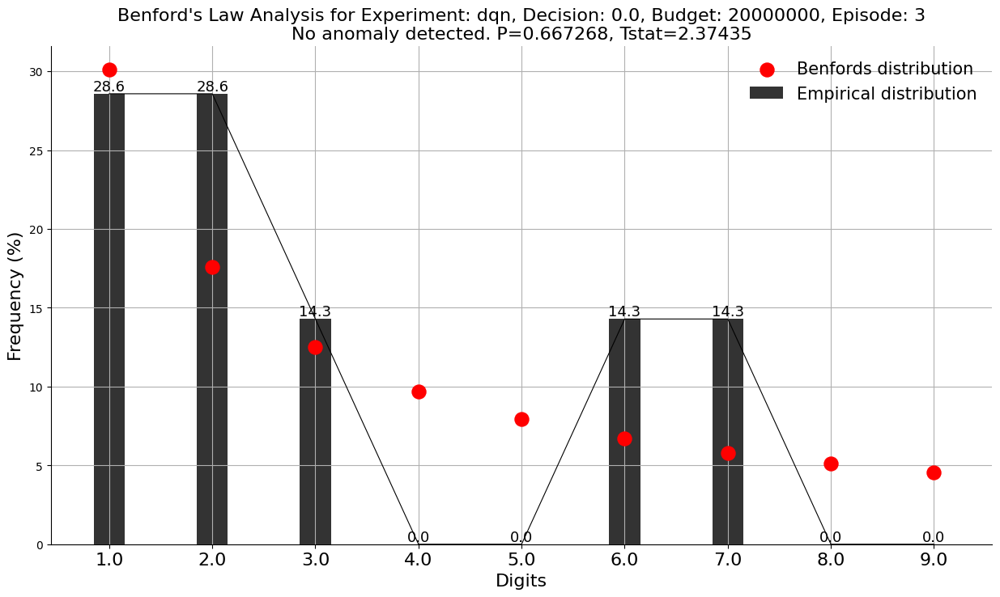

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0718944, Tstat=8.60065


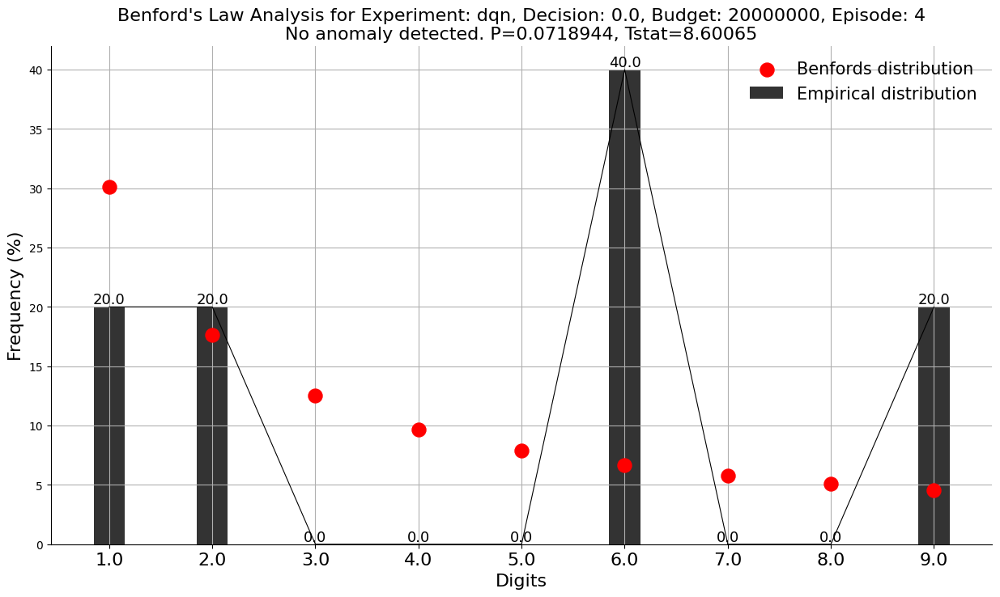

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0155856, Tstat=12.25


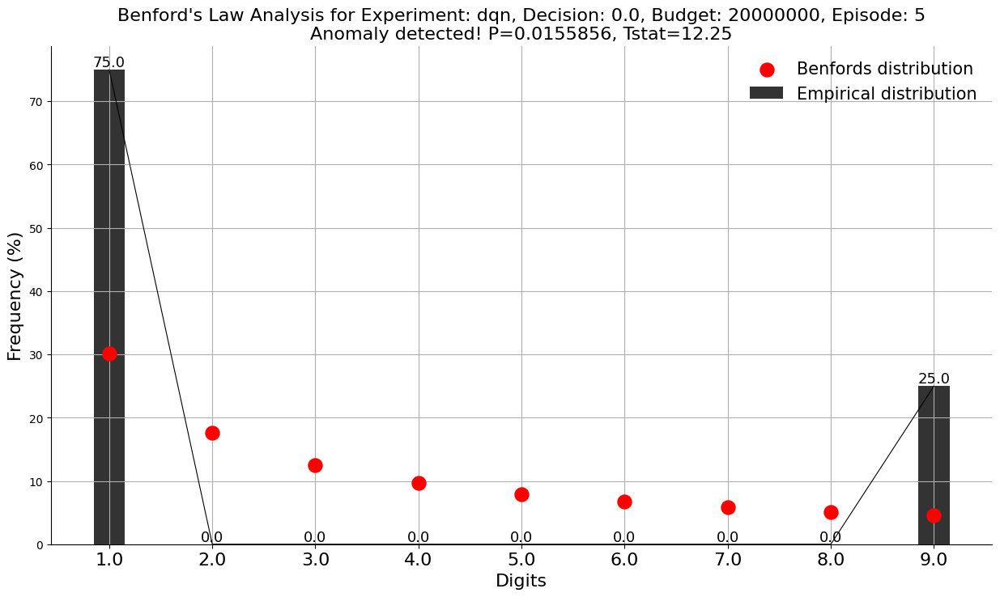

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0727958, Tstat=8.56993


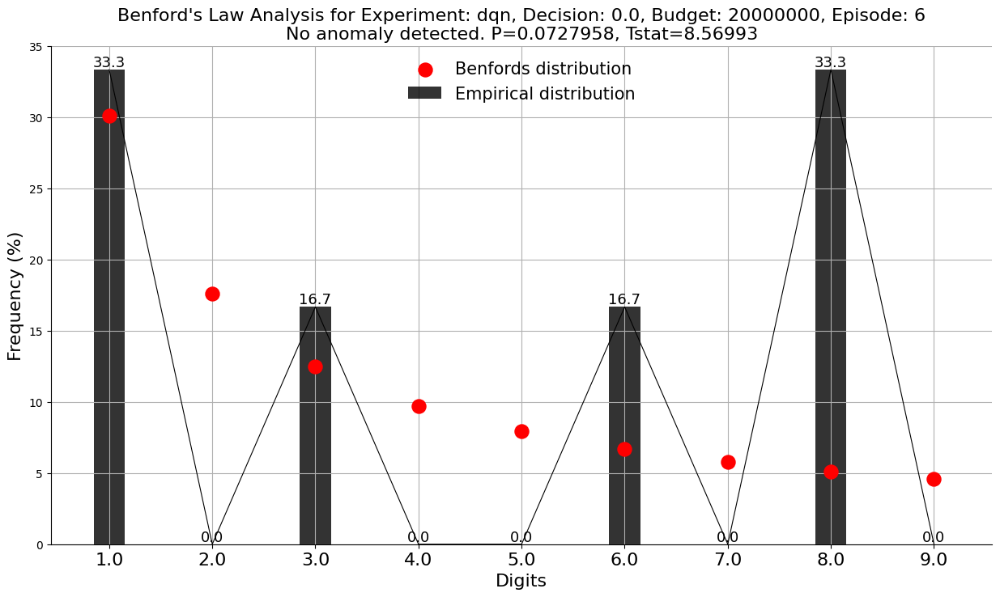

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0307243, Tstat=10.6553


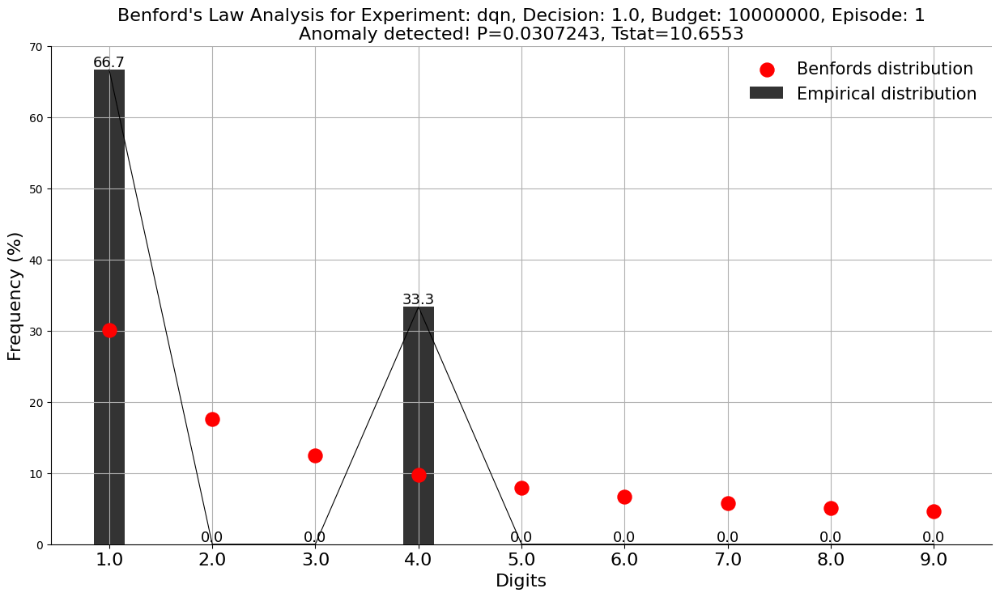

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget10000000_episode1.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0426635, Tstat=9.87067


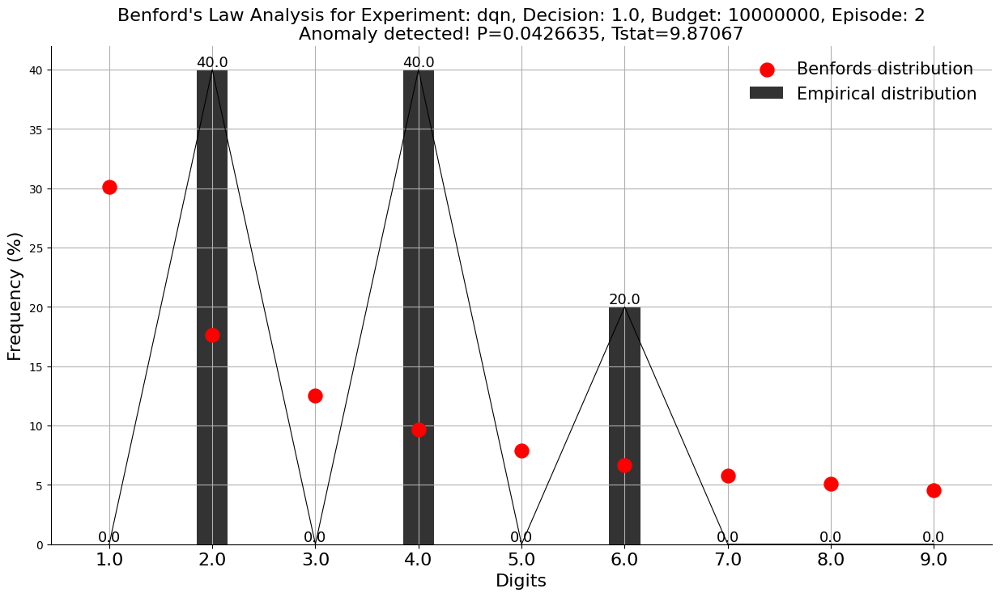

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget10000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0683828, Tstat=8.72393


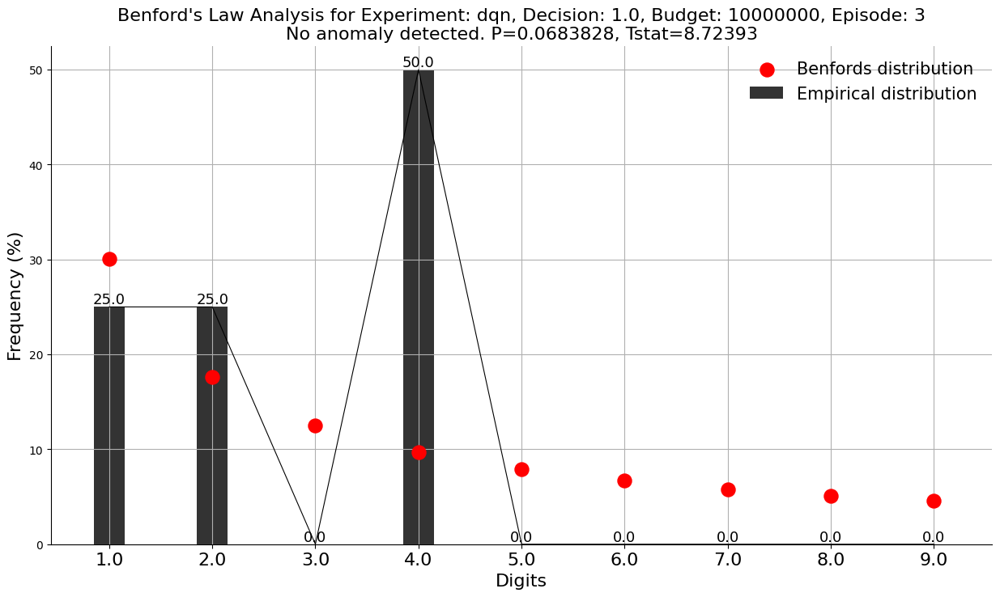

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget10000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.109918, Tstat=7.54094


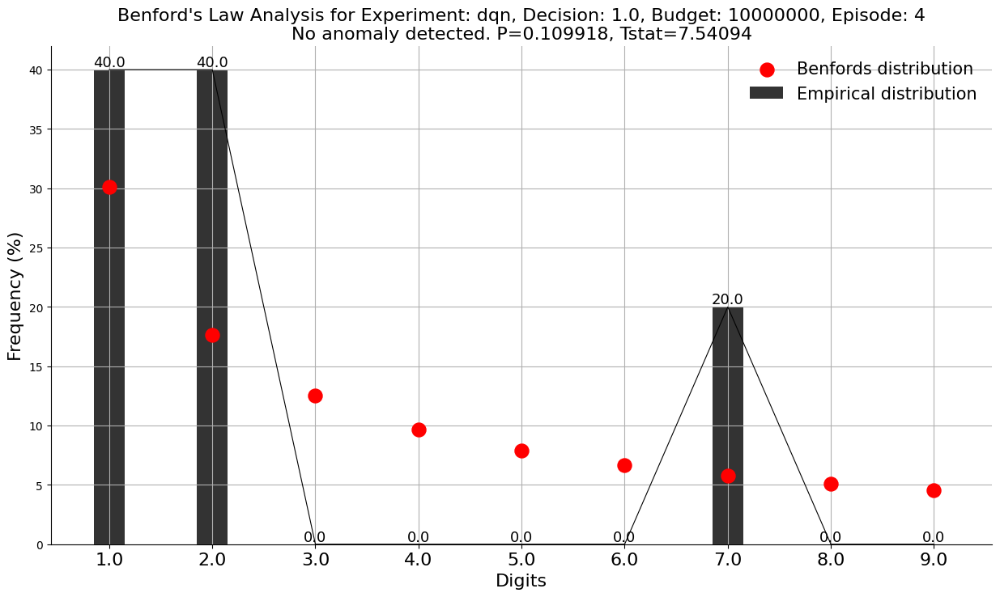

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget10000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0163313, Tstat=12.1412


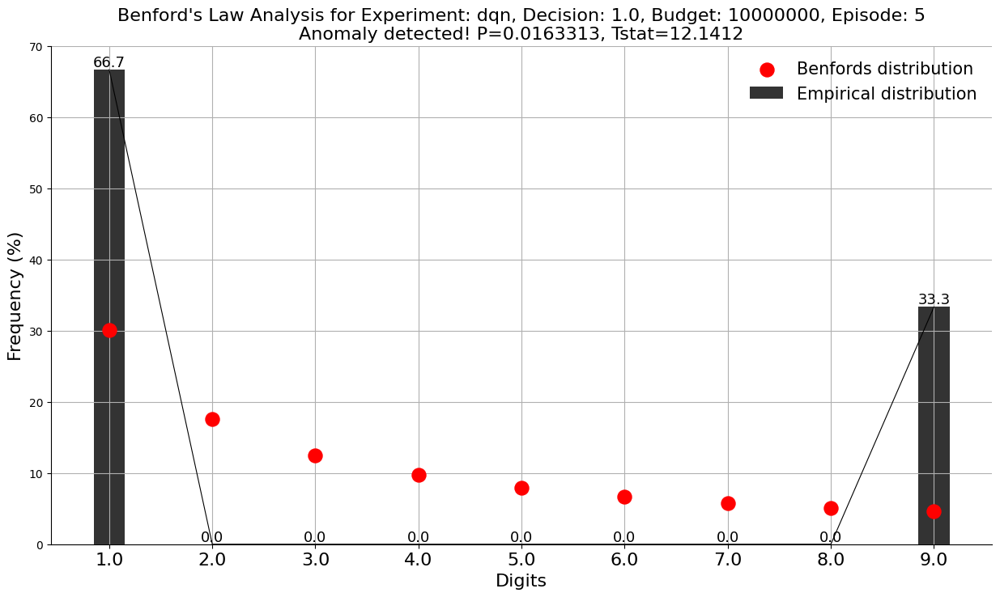

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget10000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0752678, Tstat=8.48748


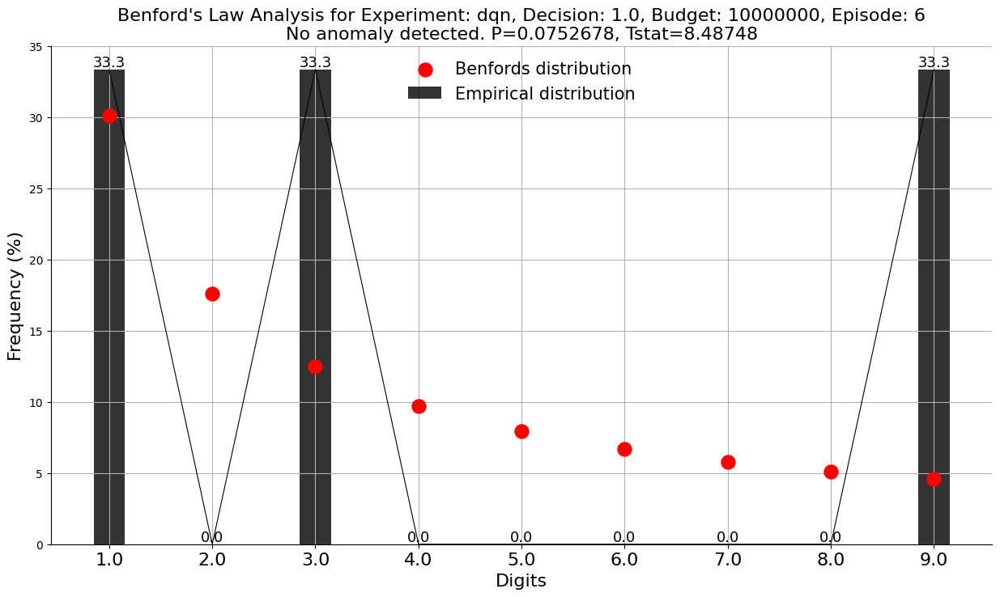

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget10000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=5.78869e-09, Tstat=44.215


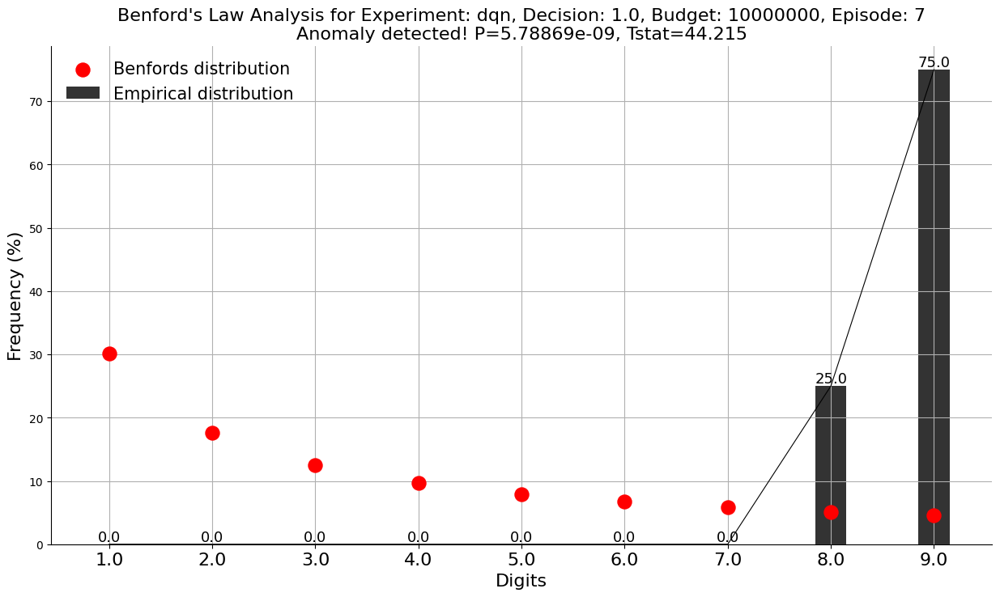

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget10000000_episode7.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0417726, Tstat=9.92141


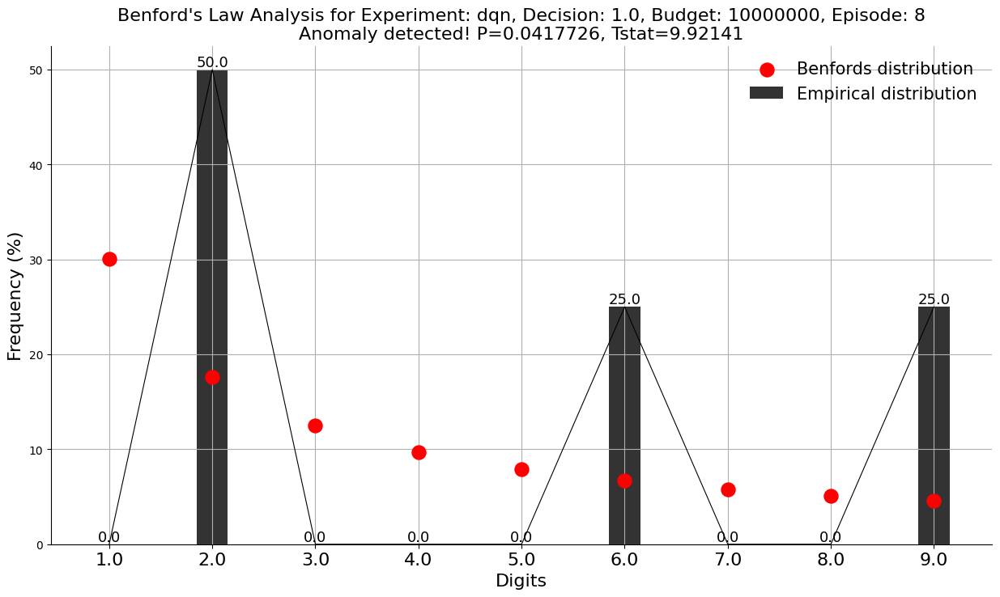

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget10000000_episode8.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00591466, Tstat=14.4785


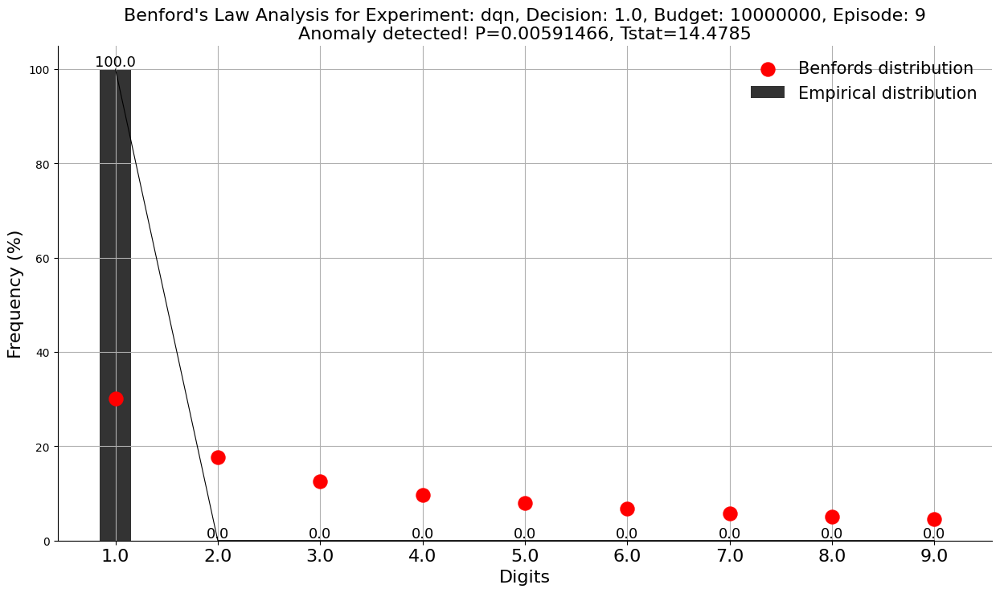

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget10000000_episode9.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.131892, Tstat=7.07666


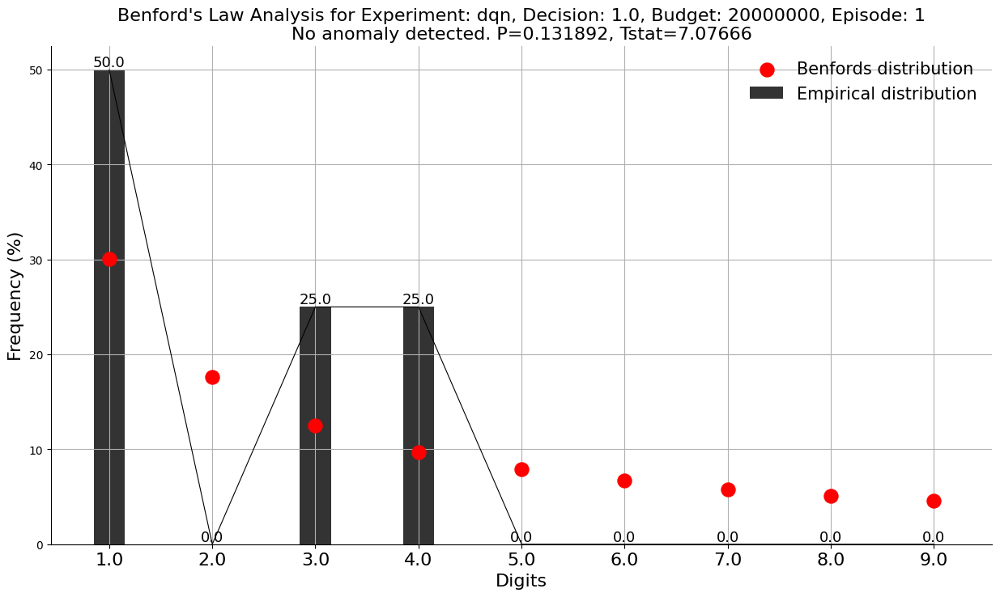

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000_episode1.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.233203, Tstat=5.57514


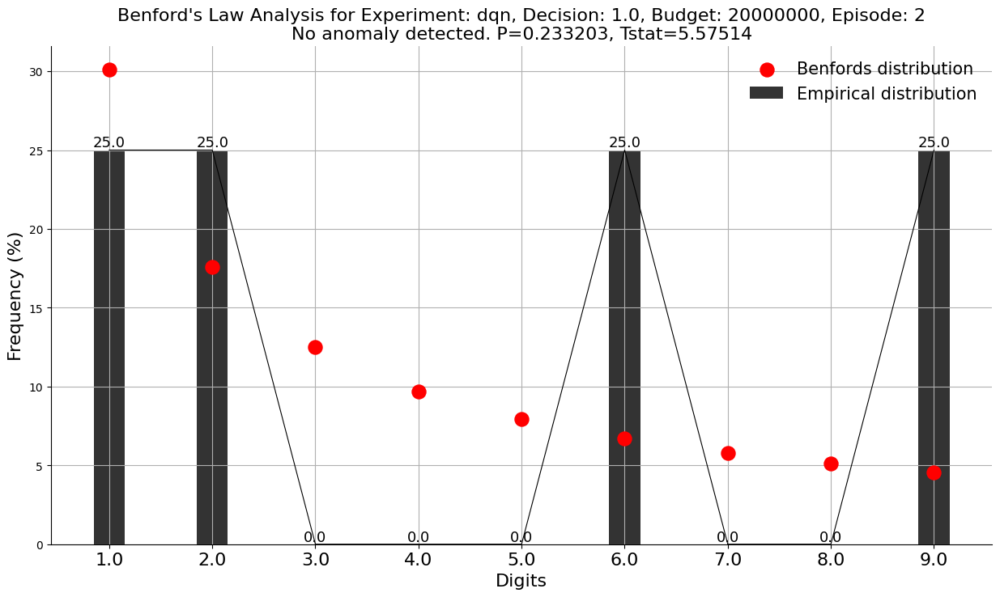

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0896608, Tstat=8.05286


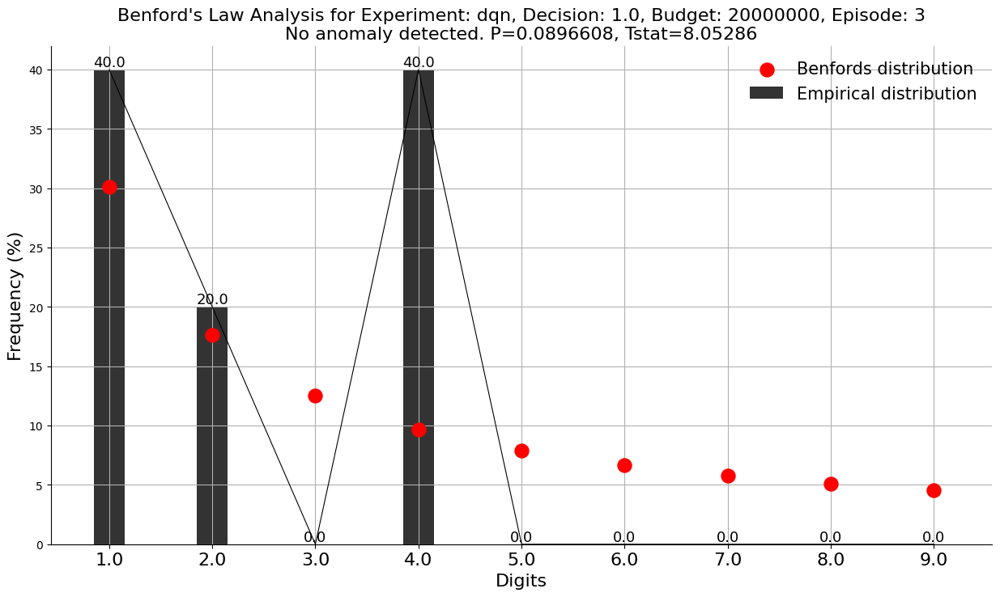

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.344957, Tstat=4.47974


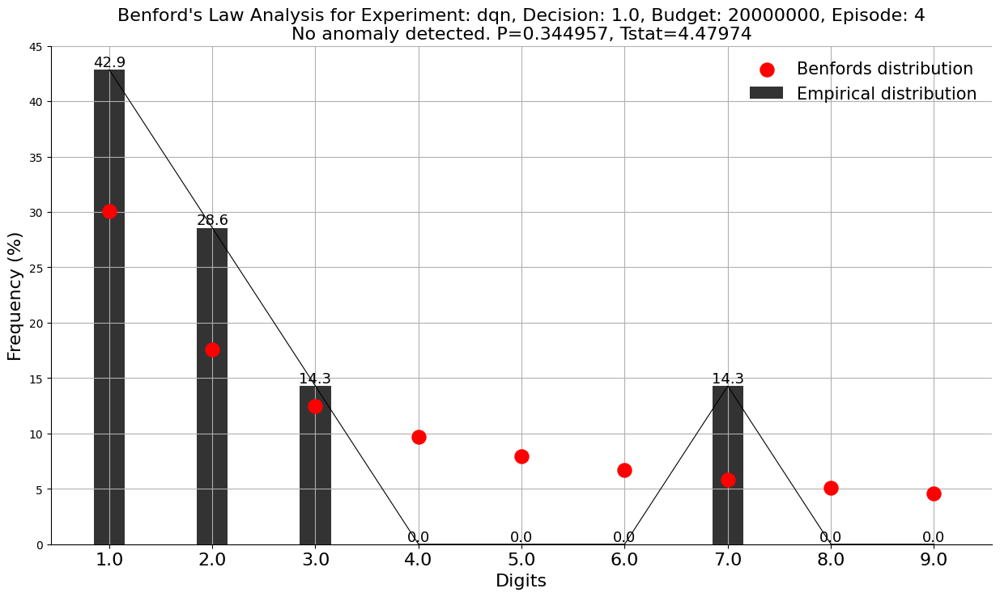

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.128483, Tstat=7.14376


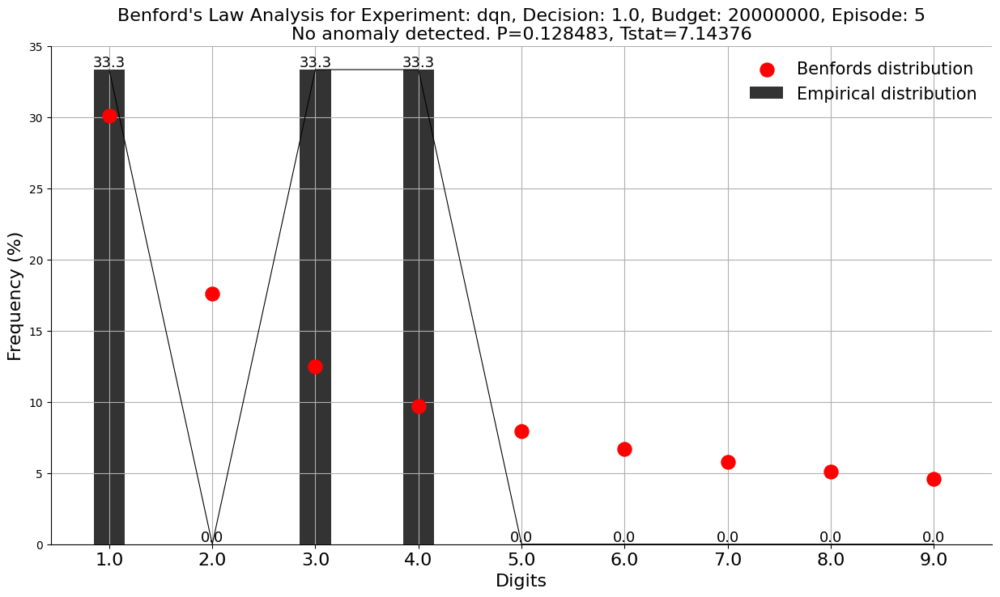

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.164319, Tstat=6.50749


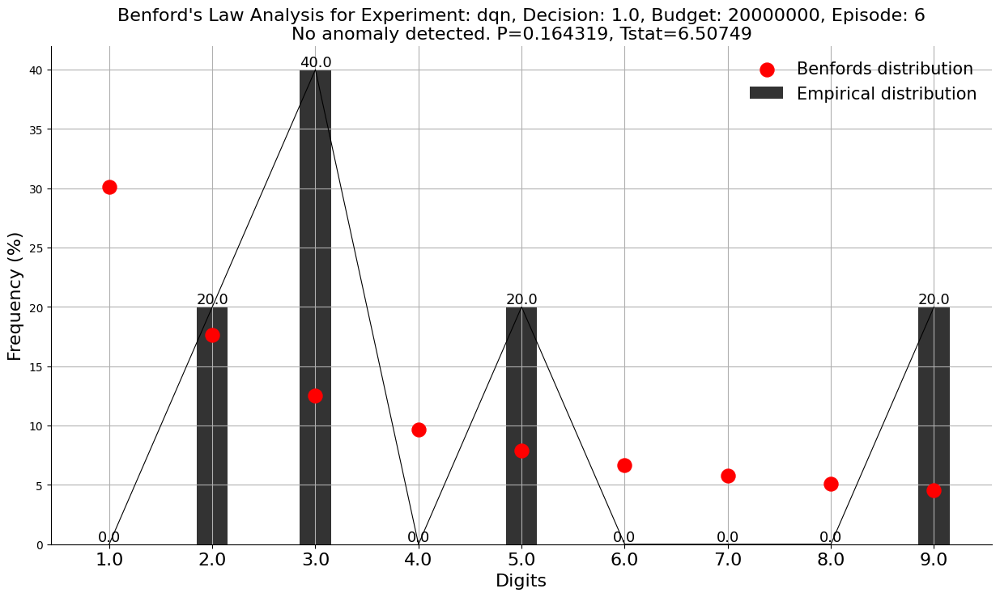

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


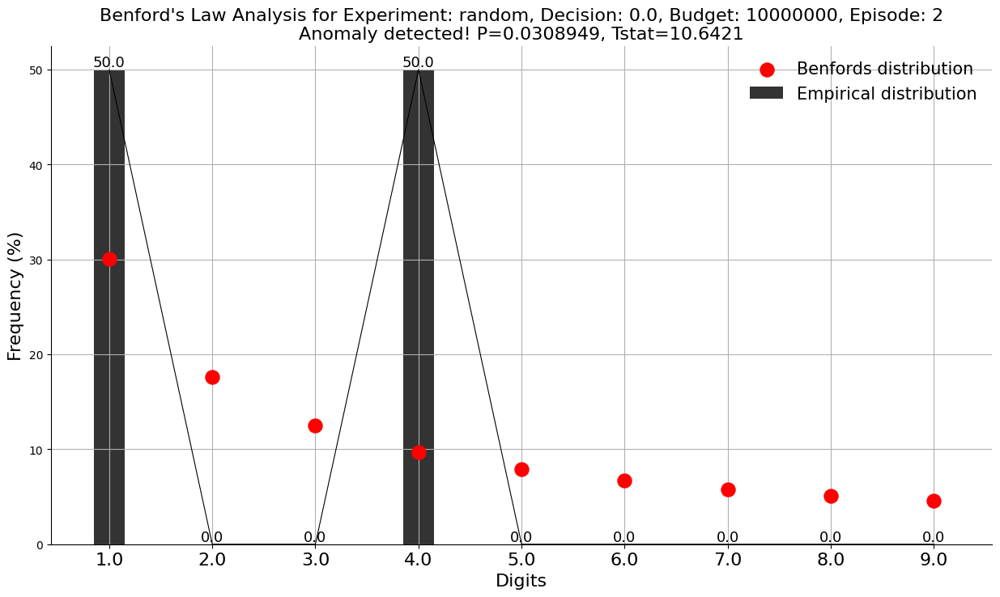

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget10000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.866127, Tstat=1.27189


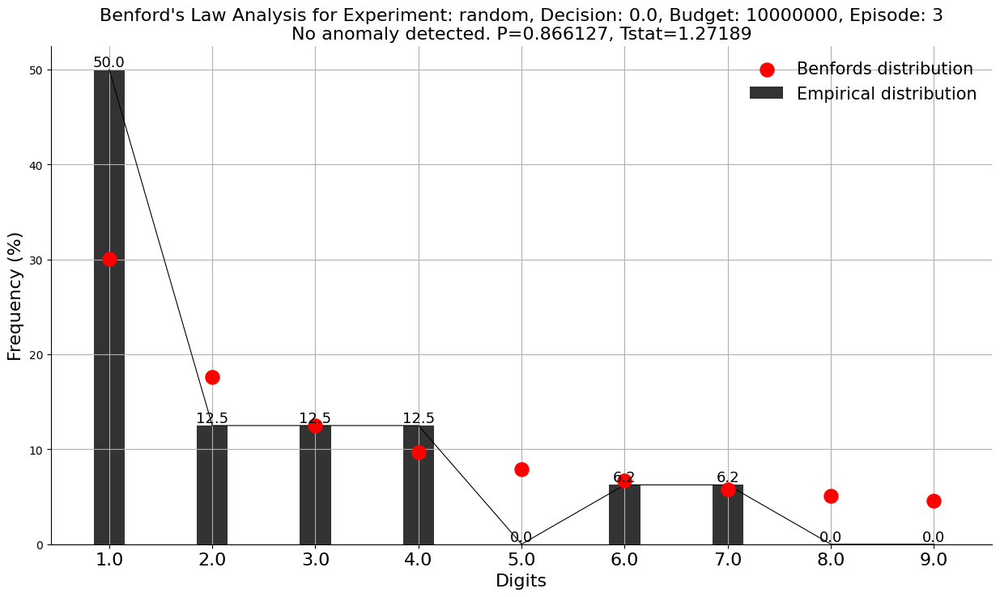

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget10000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00592606, Tstat=14.4741


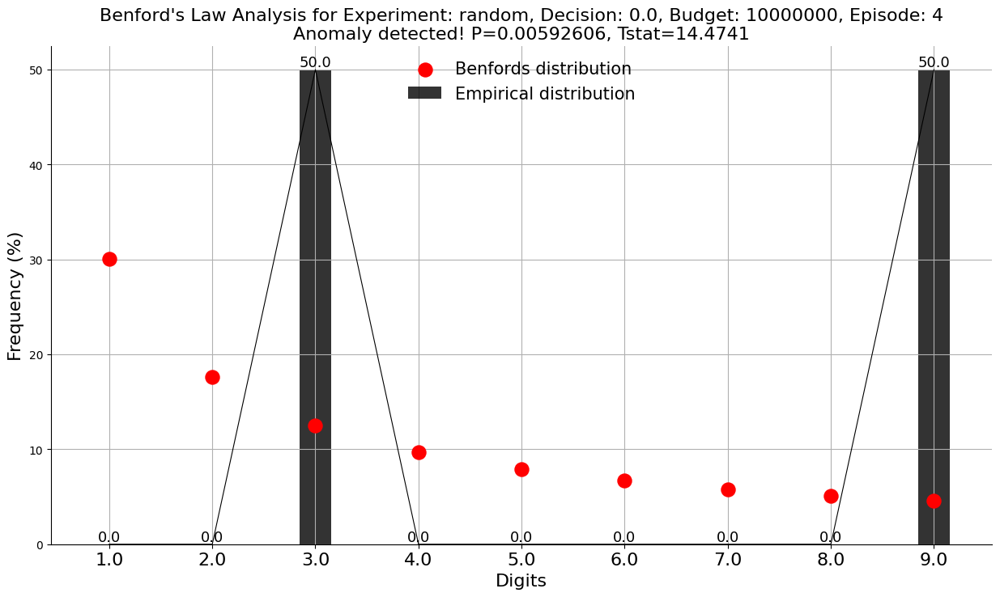

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget10000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00219082, Tstat=16.7198


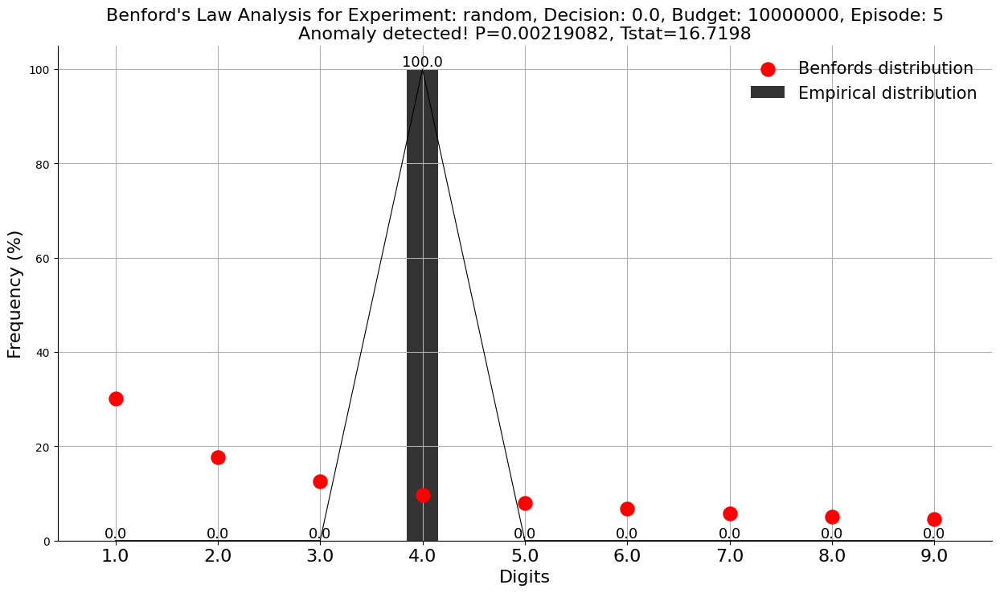

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget10000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.196862, Tstat=6.03077


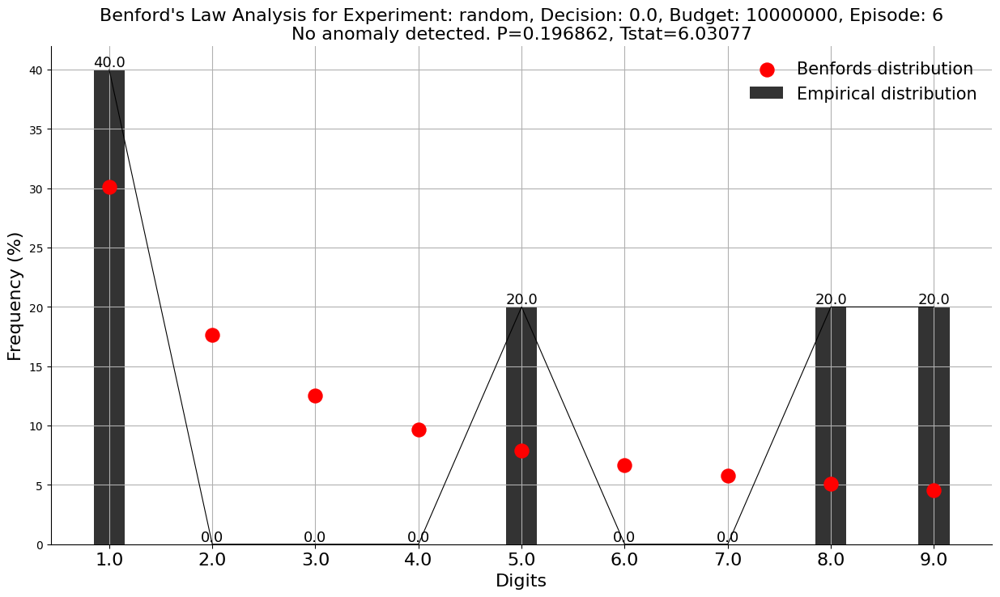

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget10000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0386294, Tstat=10.1091


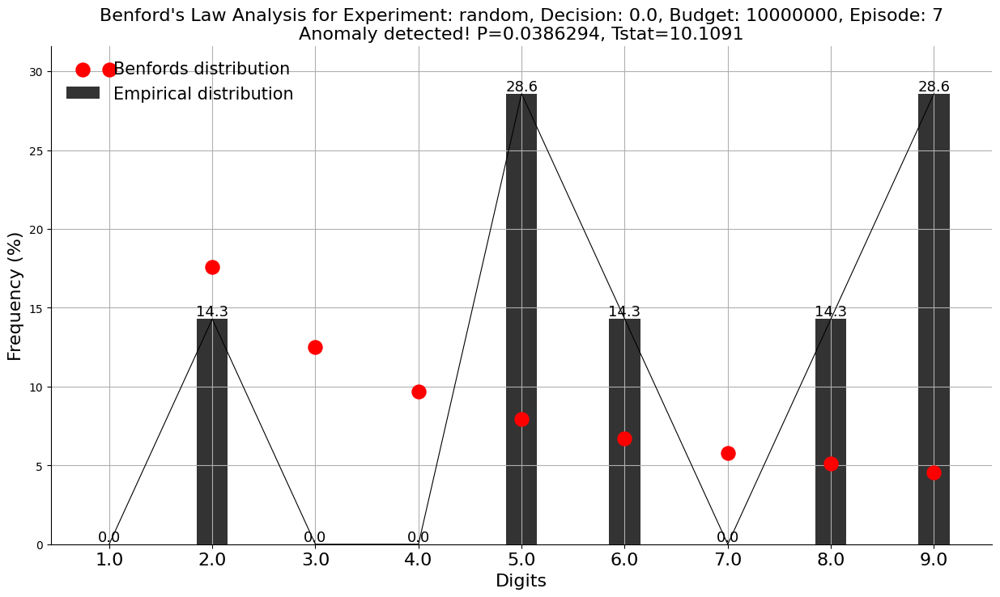

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget10000000_episode7.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0299526, Tstat=10.7157


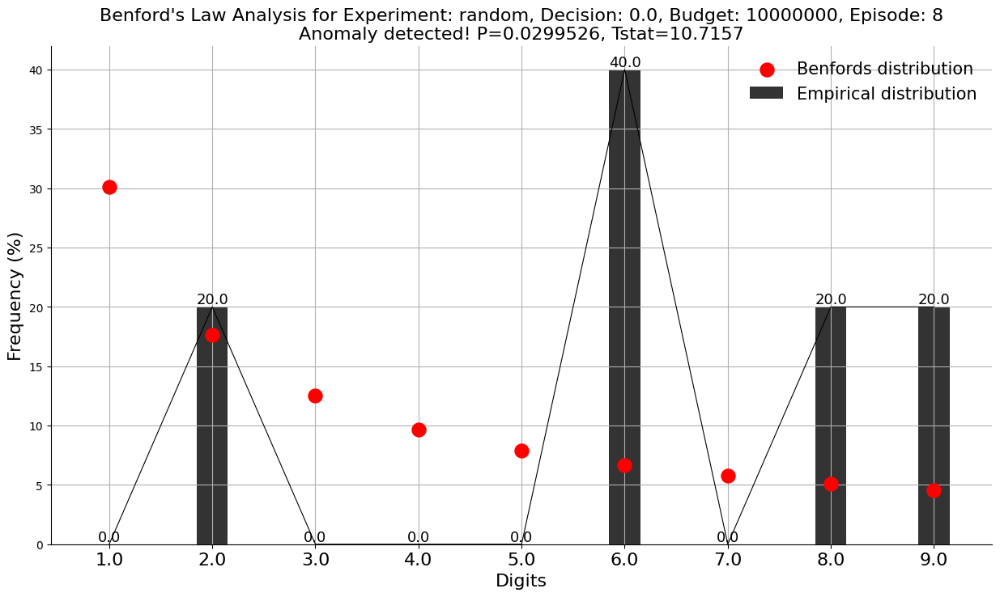

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget10000000_episode8.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.276429, Tstat=5.10765


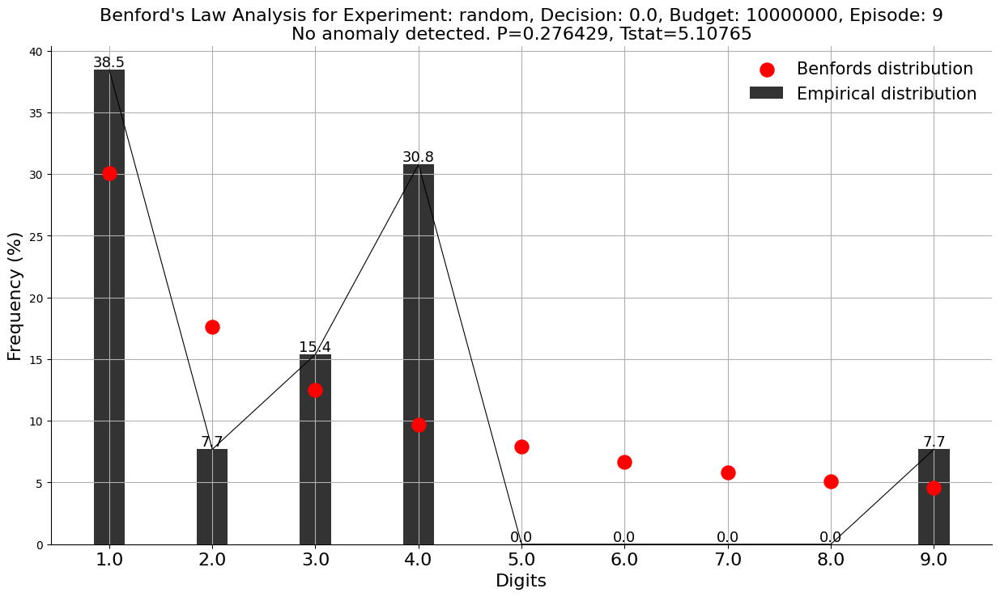

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget10000000_episode9.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0177328, Tstat=11.9492


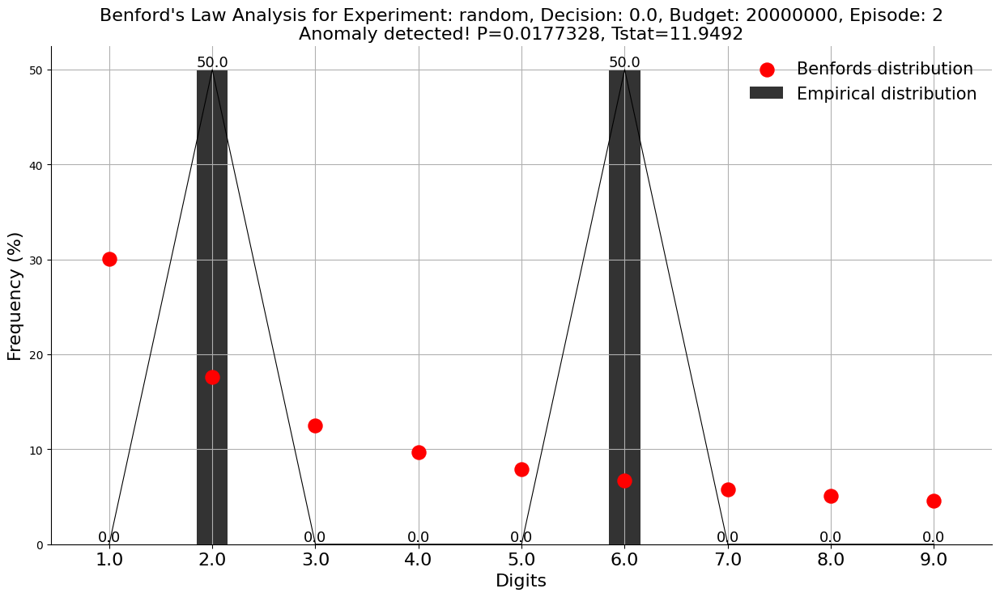

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


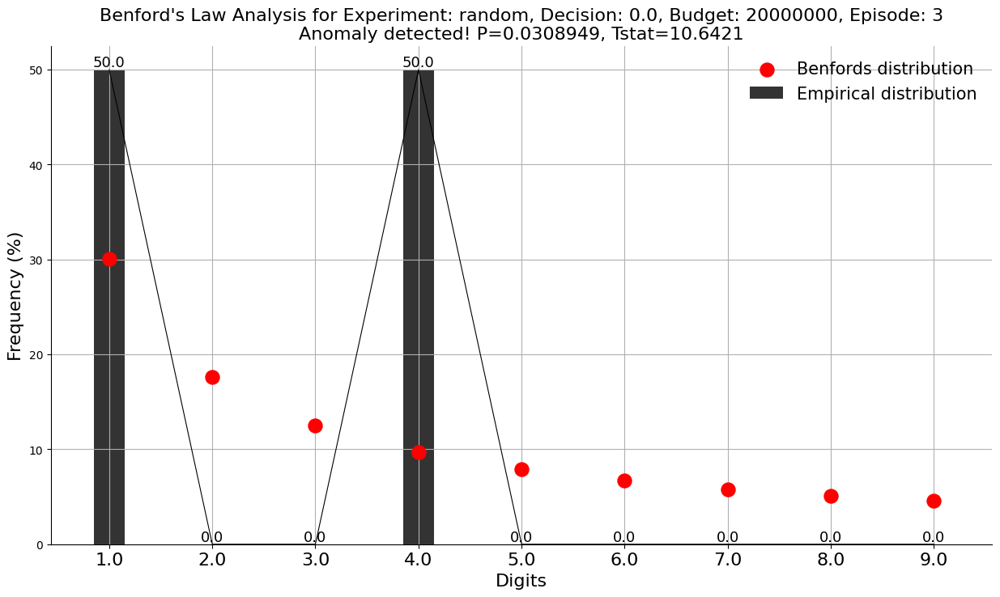

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.212204, Tstat=5.83006


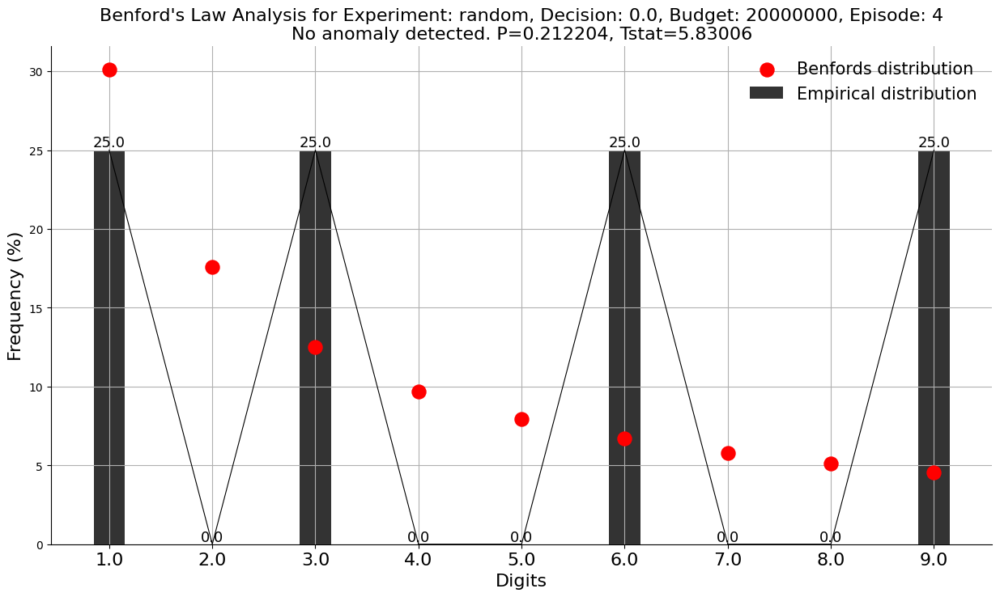

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00430483, Tstat=15.1995


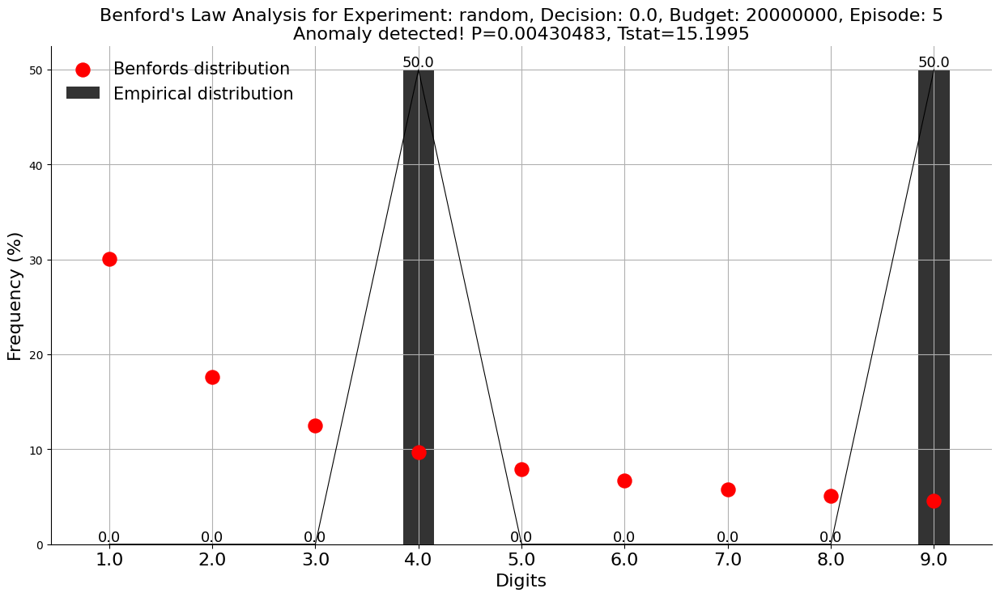

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.021819, Tstat=11.4636


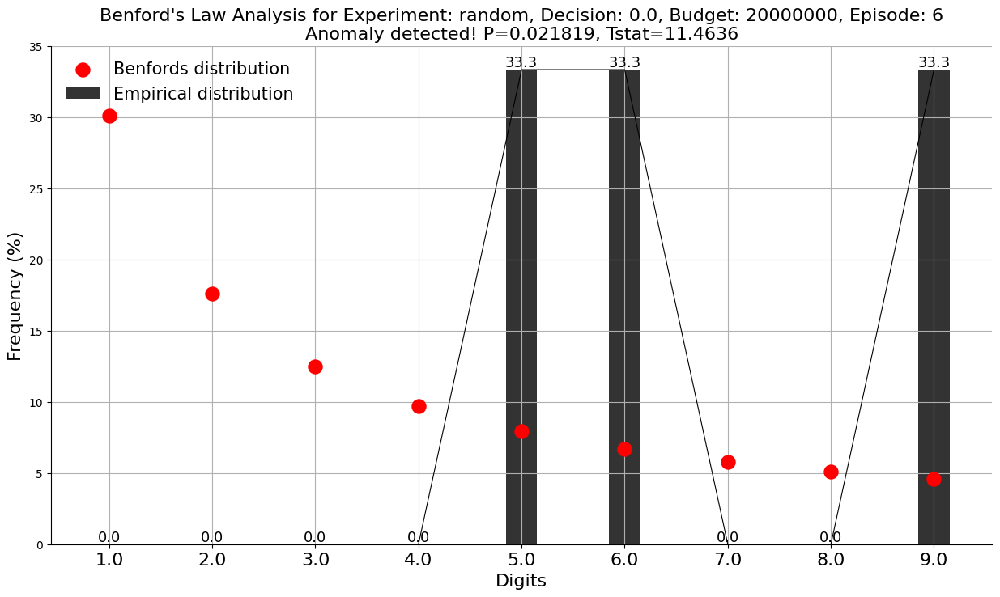

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0175504, Tstat=11.9734


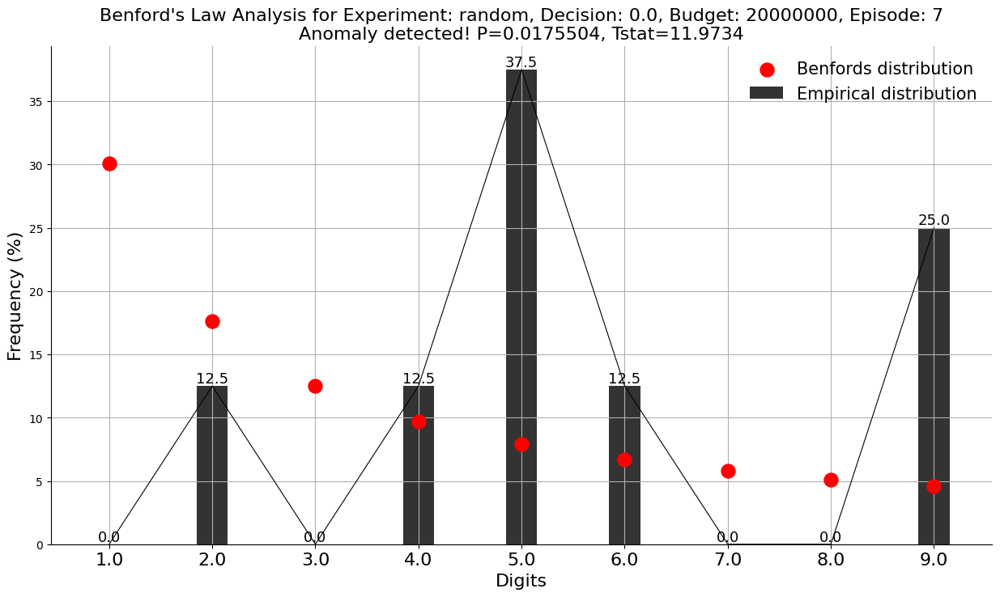

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode7.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.381597, Tstat=4.18461


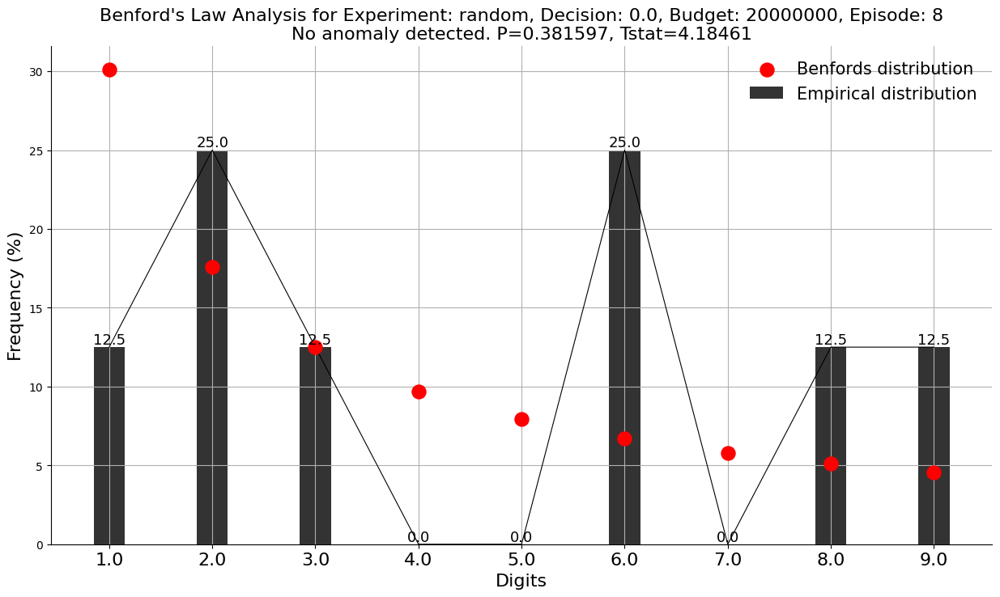

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode8.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0797203, Tstat=8.34522


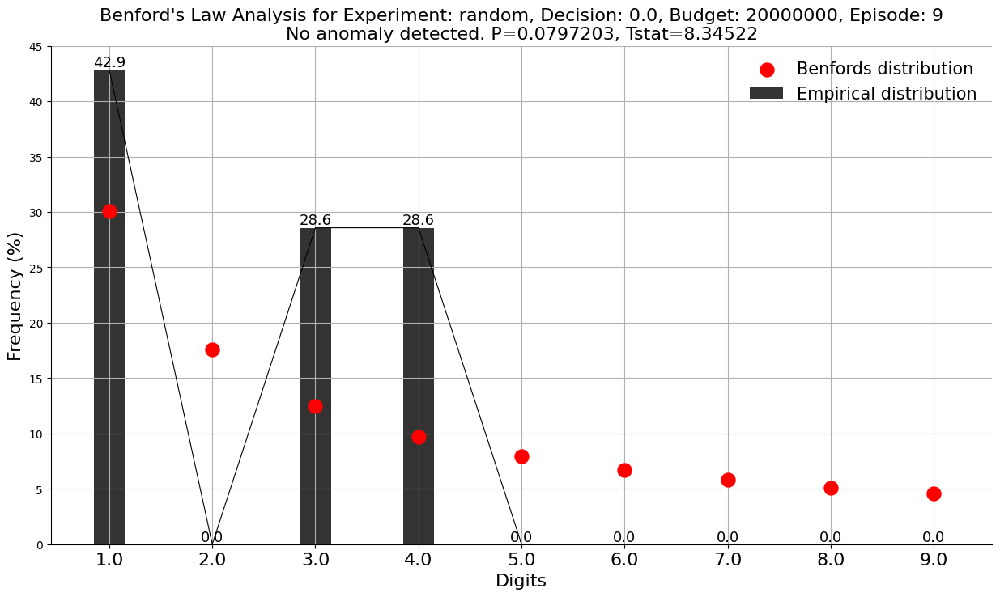

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode9.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.19828, Tstat=6.01165


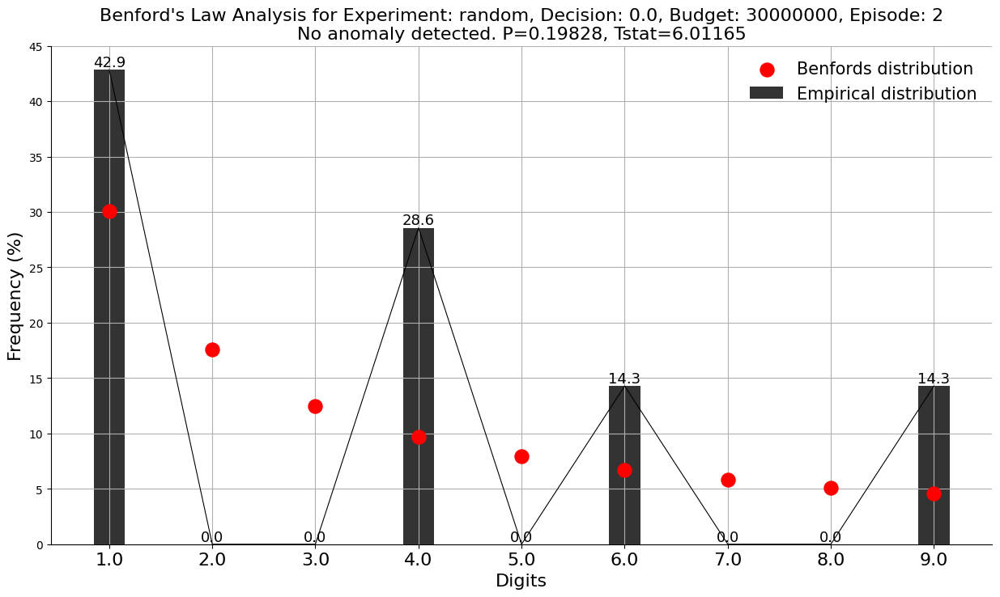

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget30000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.292509, Tstat=4.94959


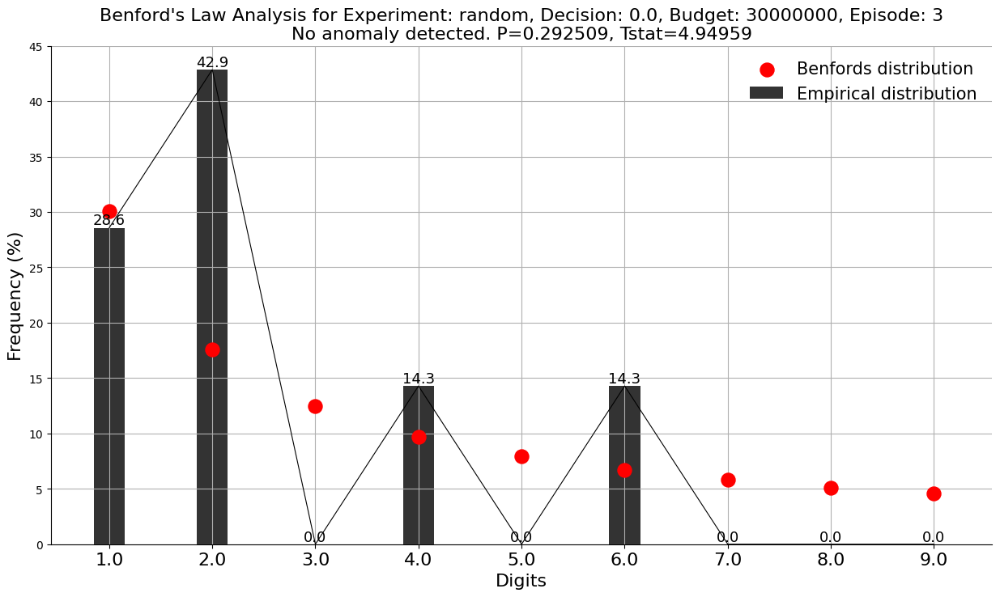

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget30000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0653749, Tstat=8.83439


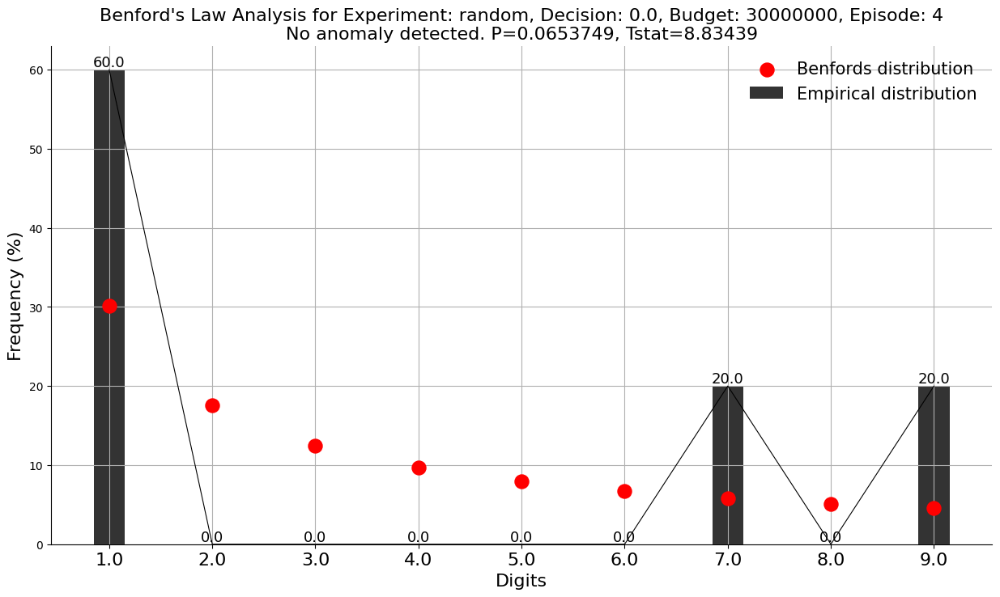

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget30000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00353024, Tstat=15.6477


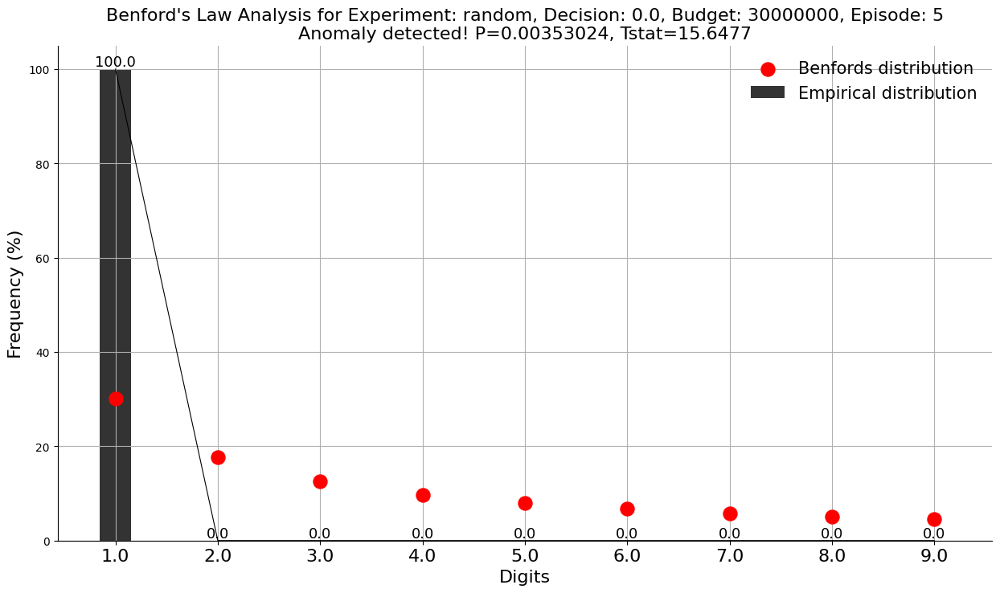

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget30000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0163853, Tstat=12.1336


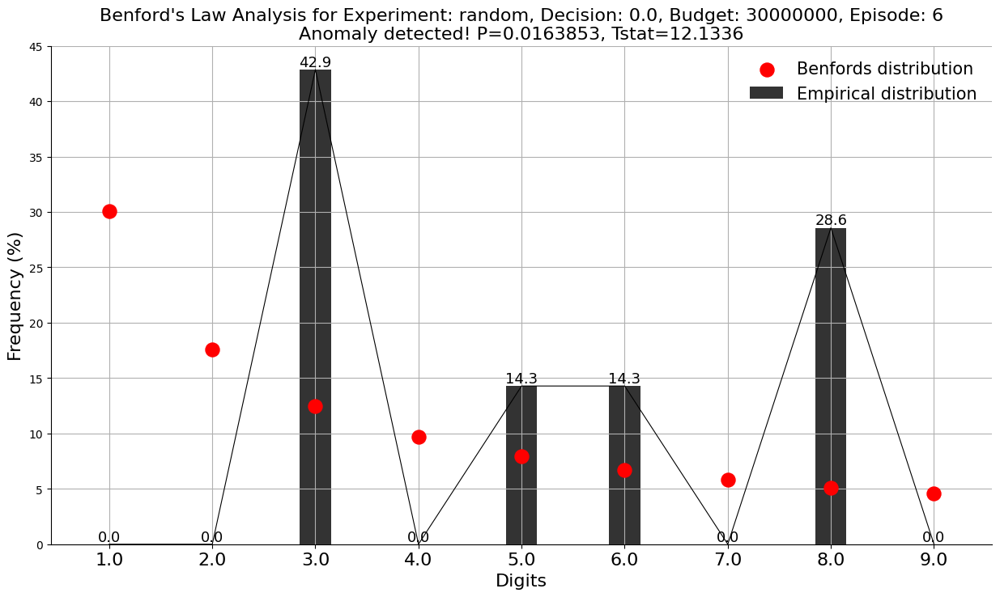

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget30000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.315575, Tstat=4.73508


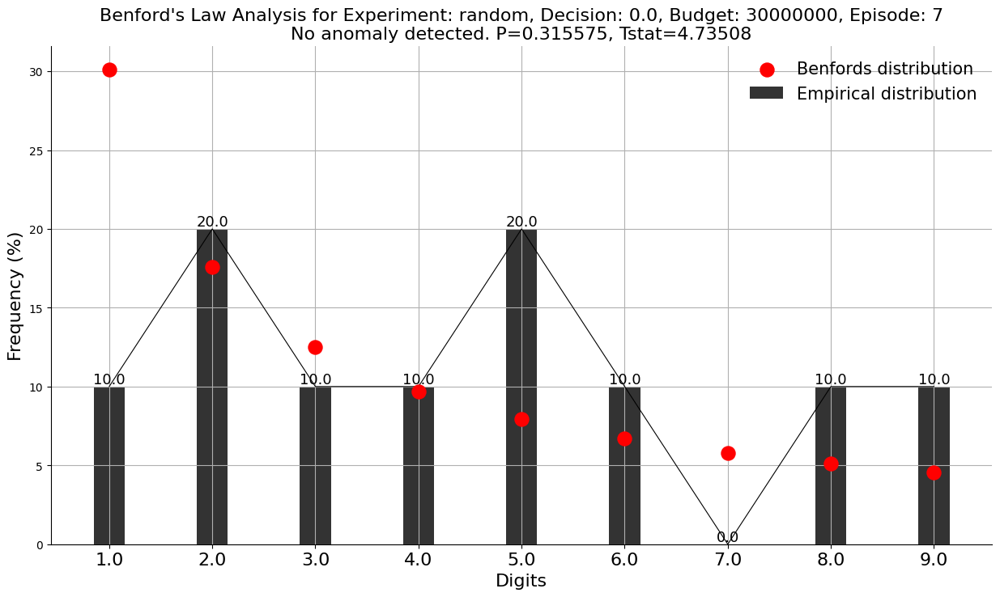

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget30000000_episode7.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00484497, Tstat=14.9317


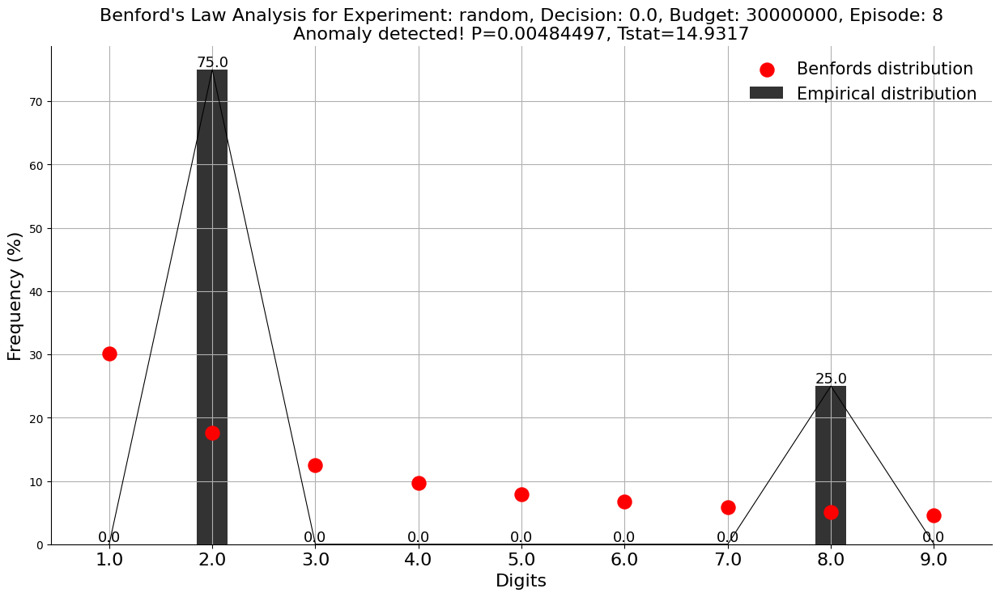

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget30000000_episode8.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.359999, Tstat=4.35573


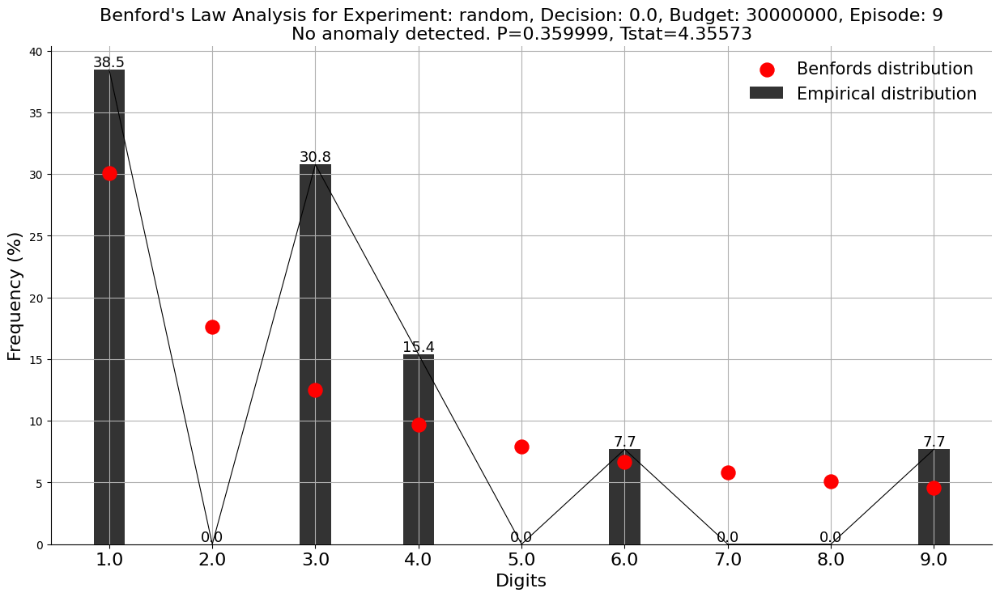

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget30000000_episode9.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.575748, Tstat=2.89383


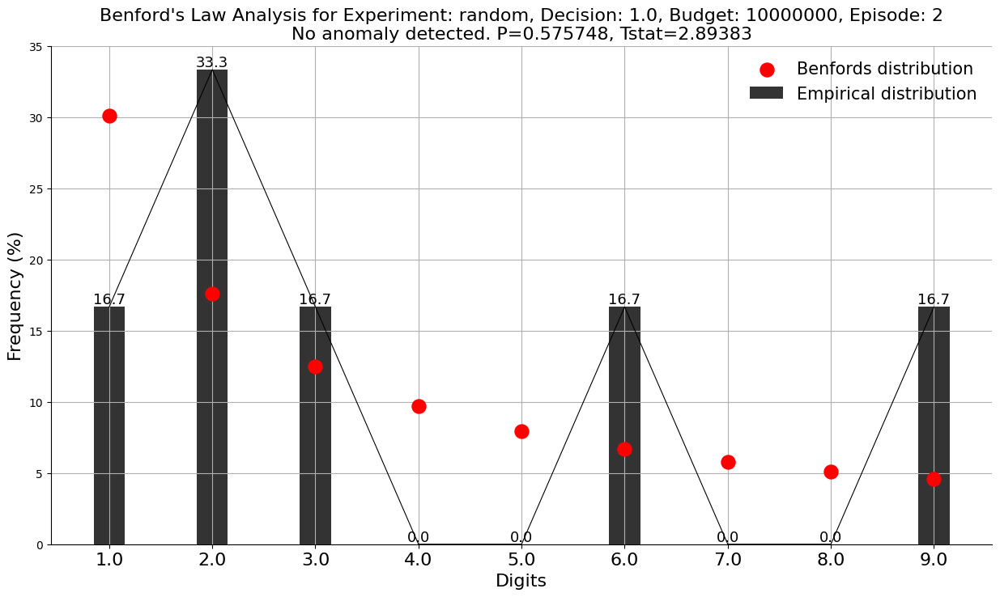

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget10000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.584483, Tstat=2.84271


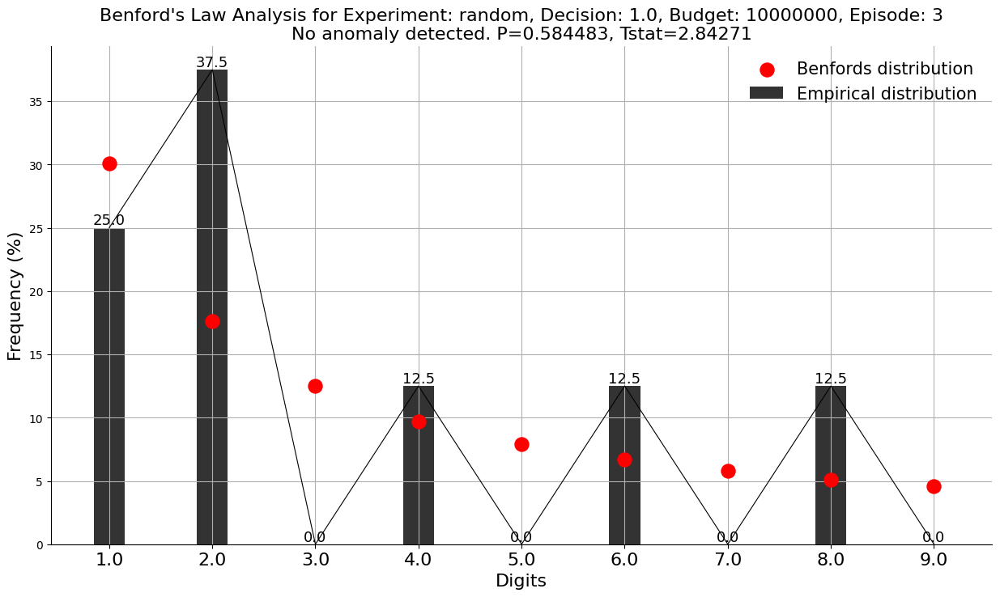

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget10000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.101392, Tstat=7.74466


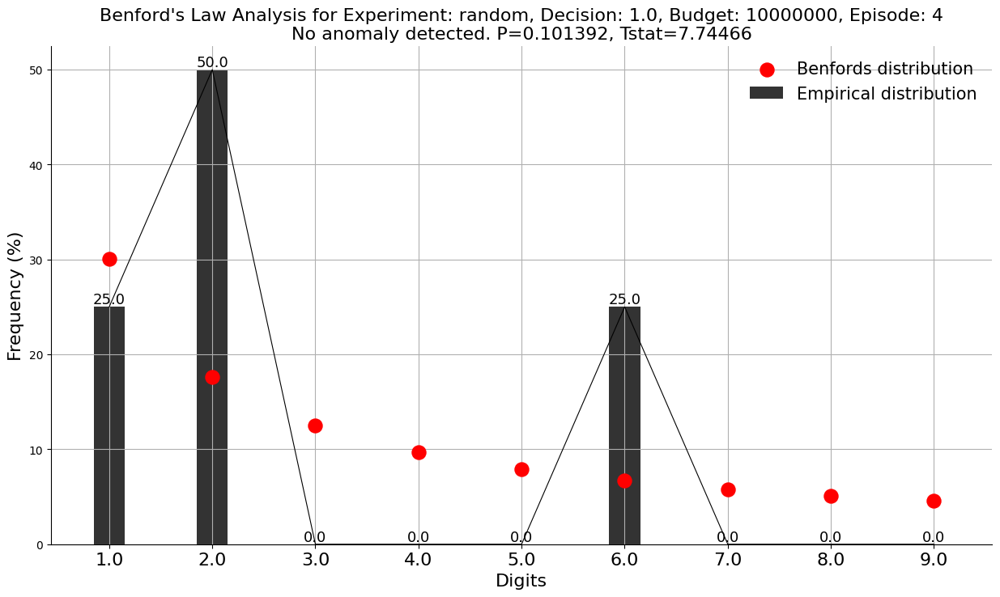

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget10000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0155856, Tstat=12.25


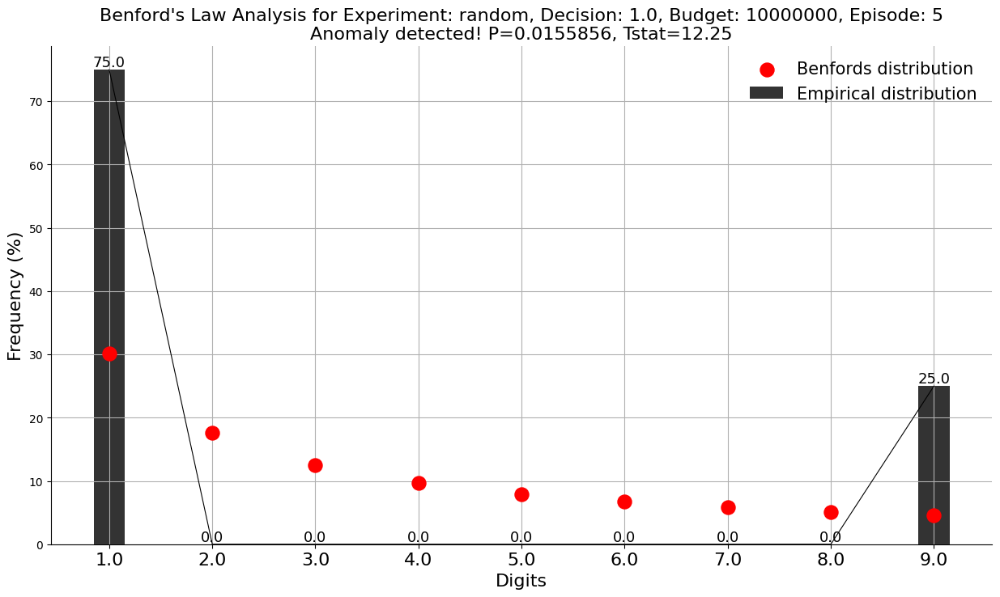

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget10000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00638448, Tstat=14.3043


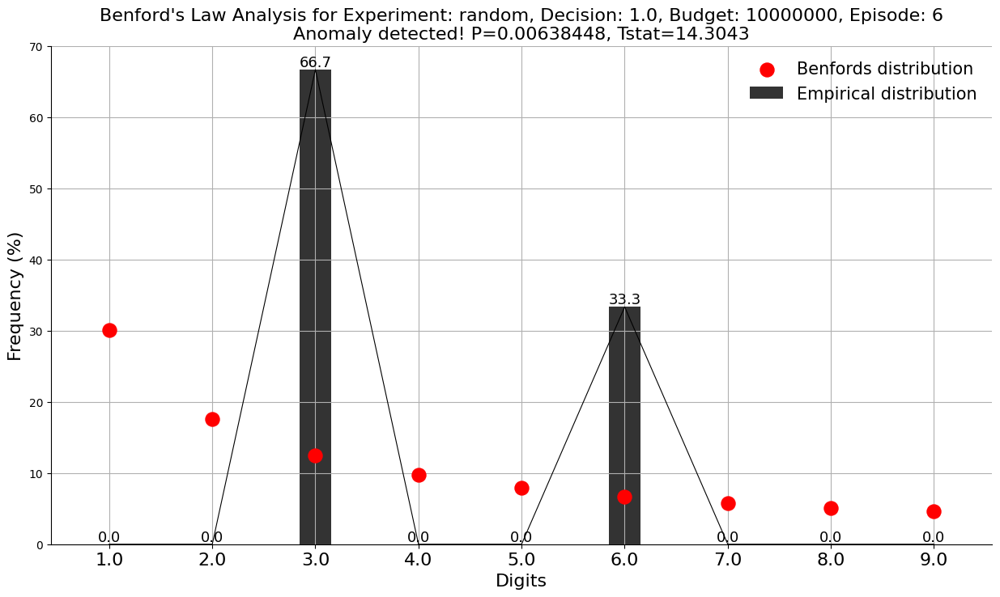

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget10000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0388277, Tstat=10.0968


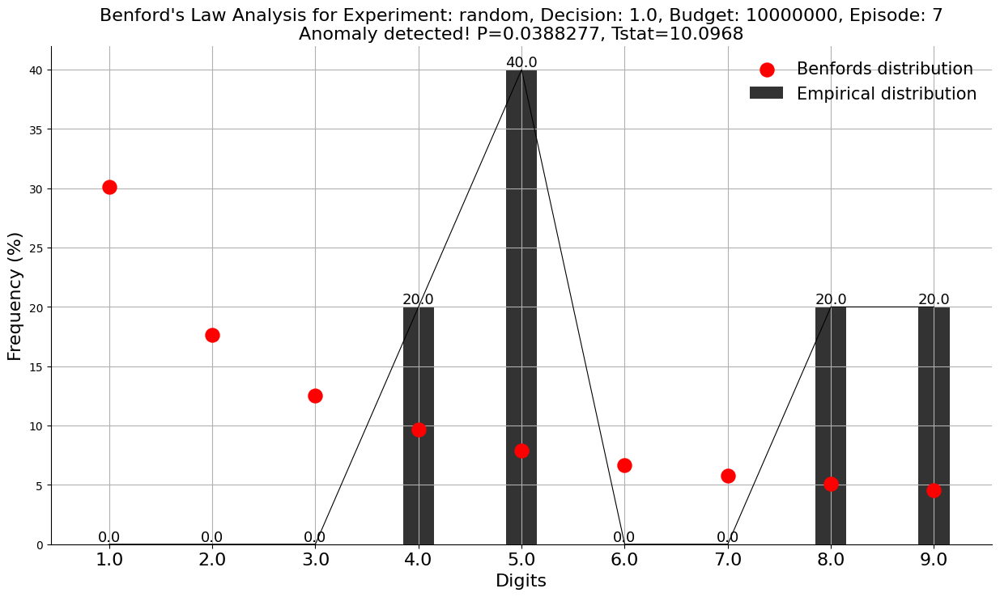

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget10000000_episode7.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.125009, Tstat=7.21386


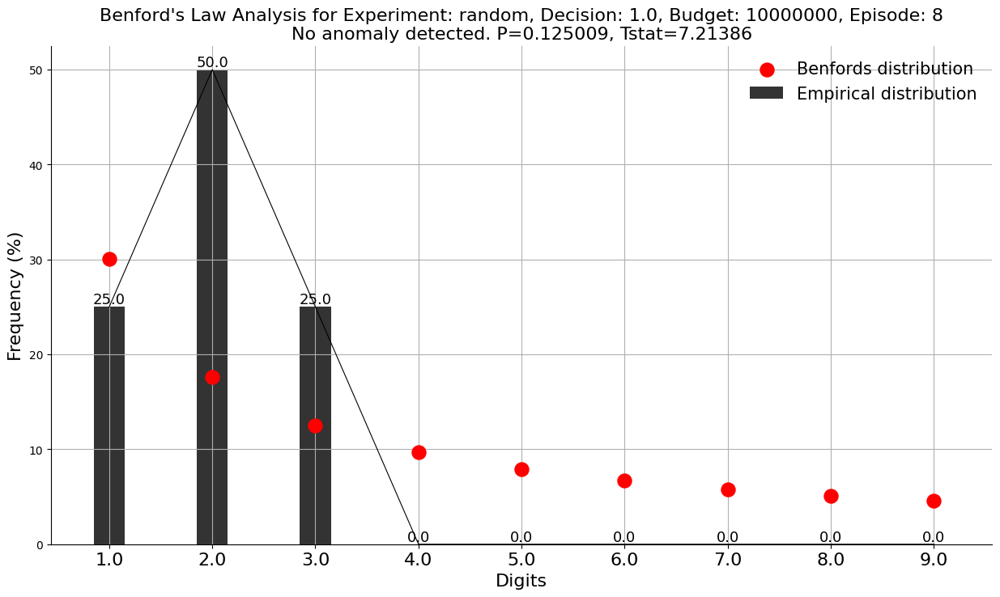

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget10000000_episode8.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.331621, Tstat=4.59335


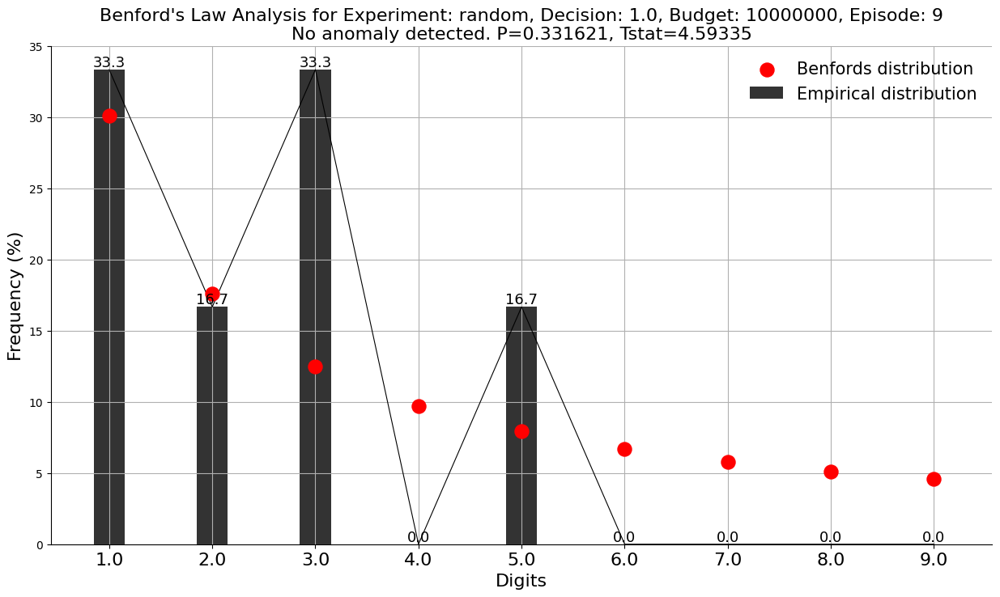

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget10000000_episode9.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0332745, Tstat=10.4656


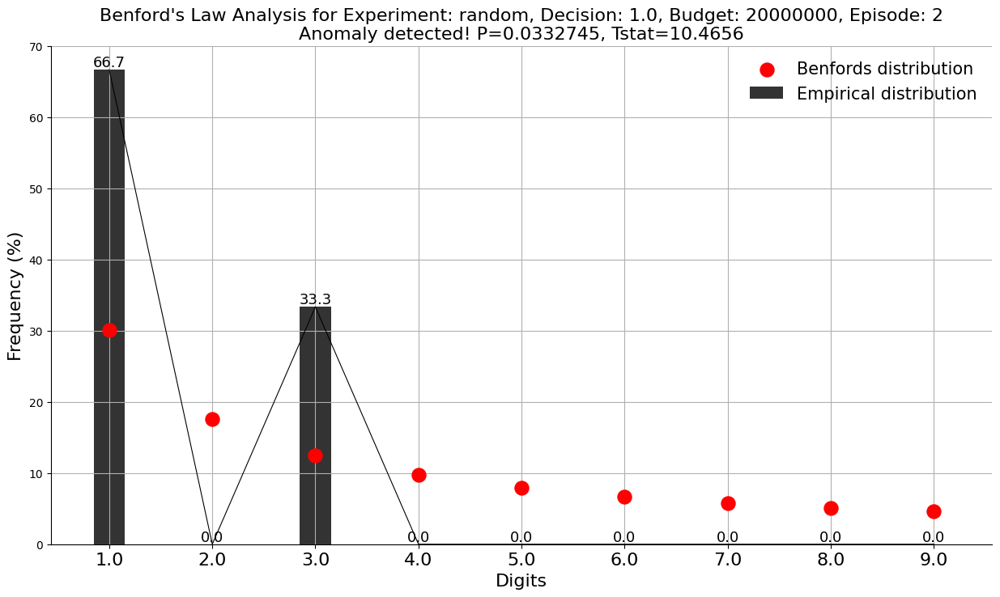

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0761977, Tstat=8.45712


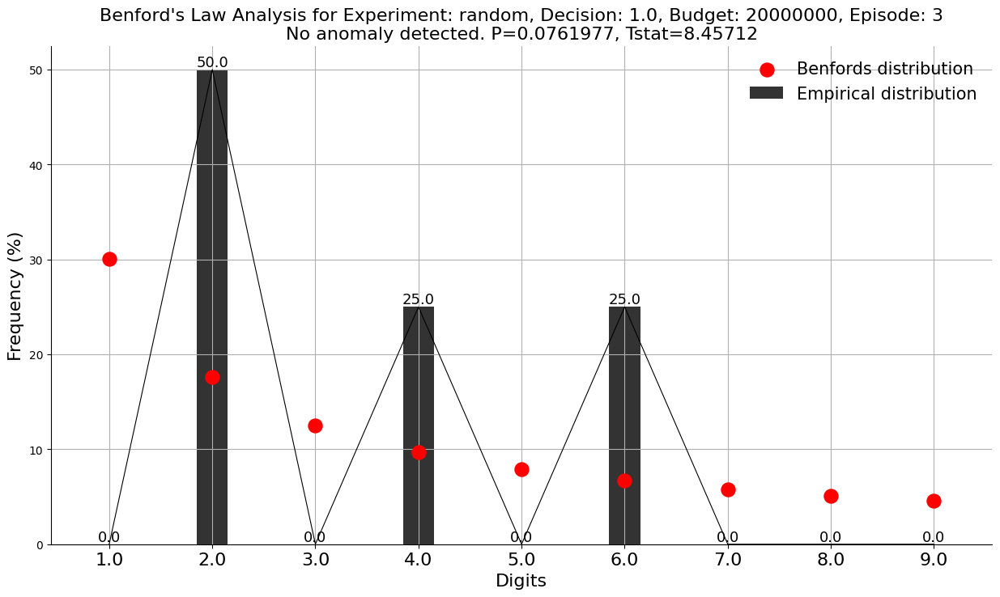

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.257011, Tstat=5.30926


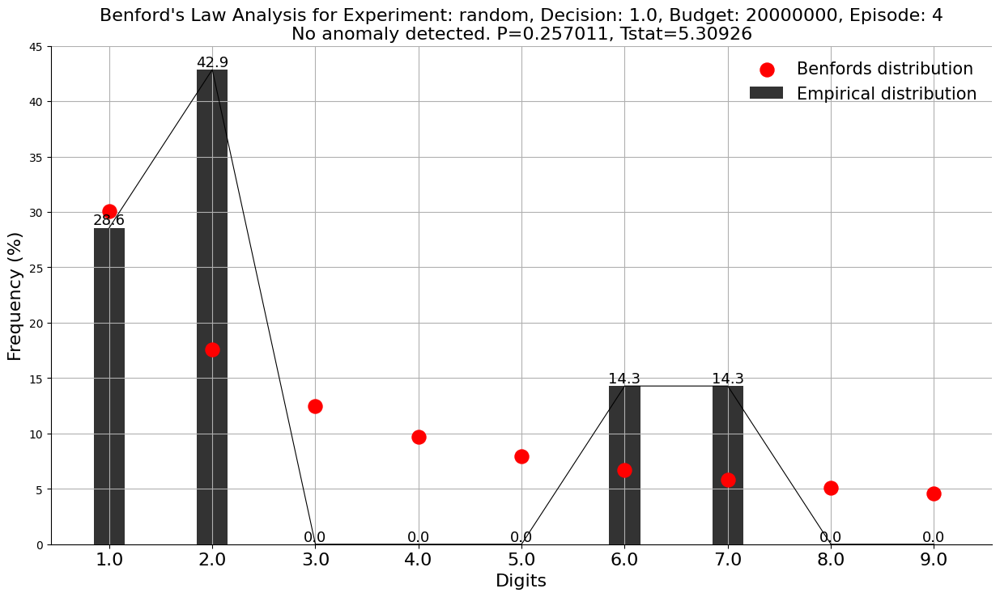

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00353024, Tstat=15.6477


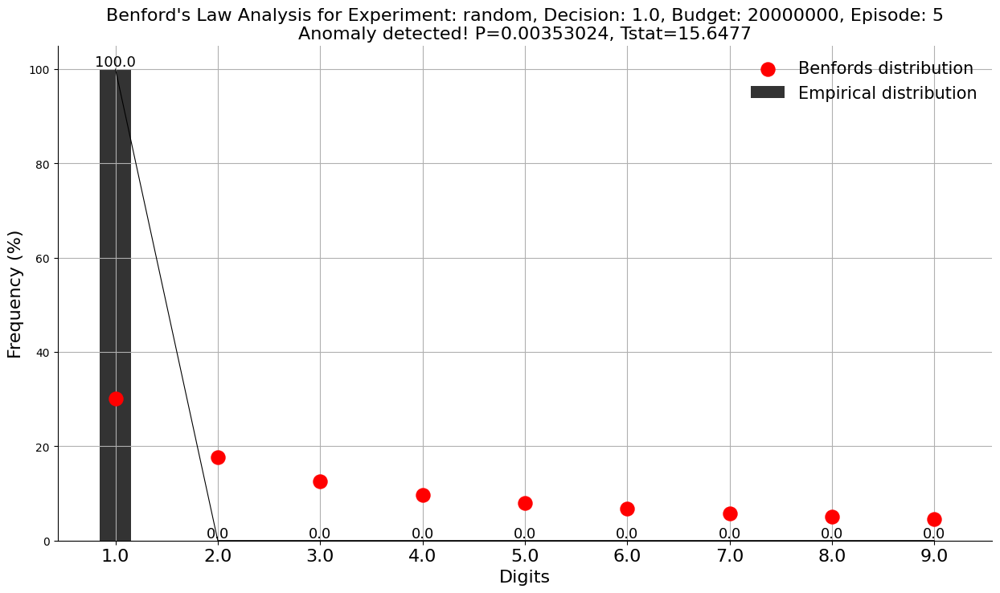

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0140021, Tstat=12.499


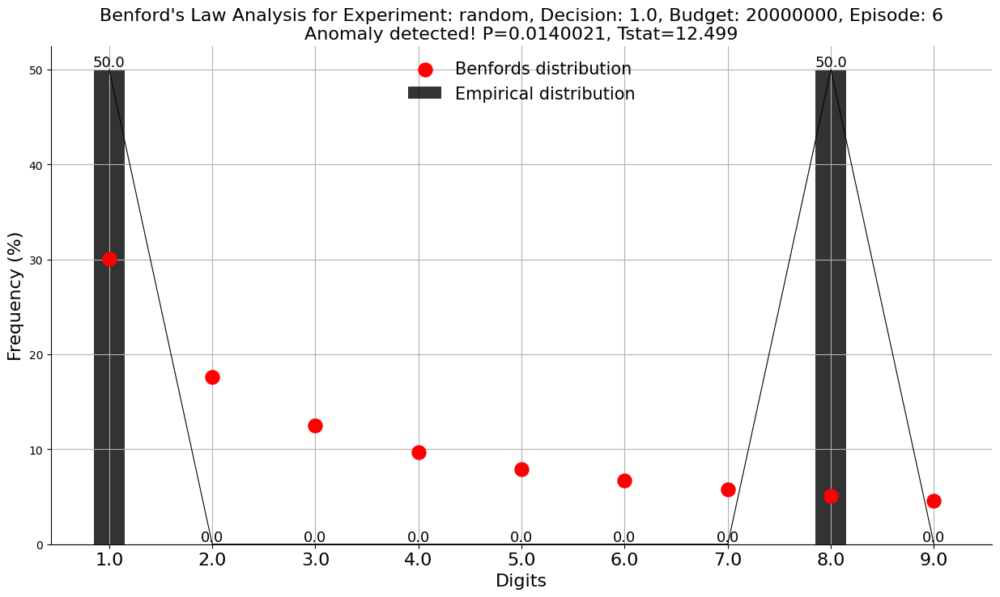

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.000759068, Tstat=19.0769


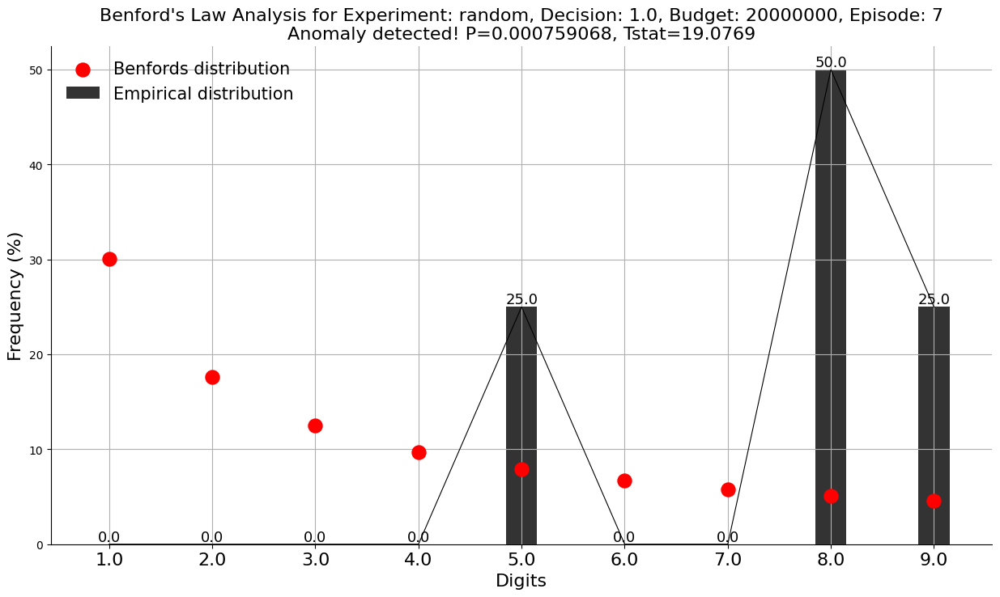

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode7.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0625288, Tstat=8.94344


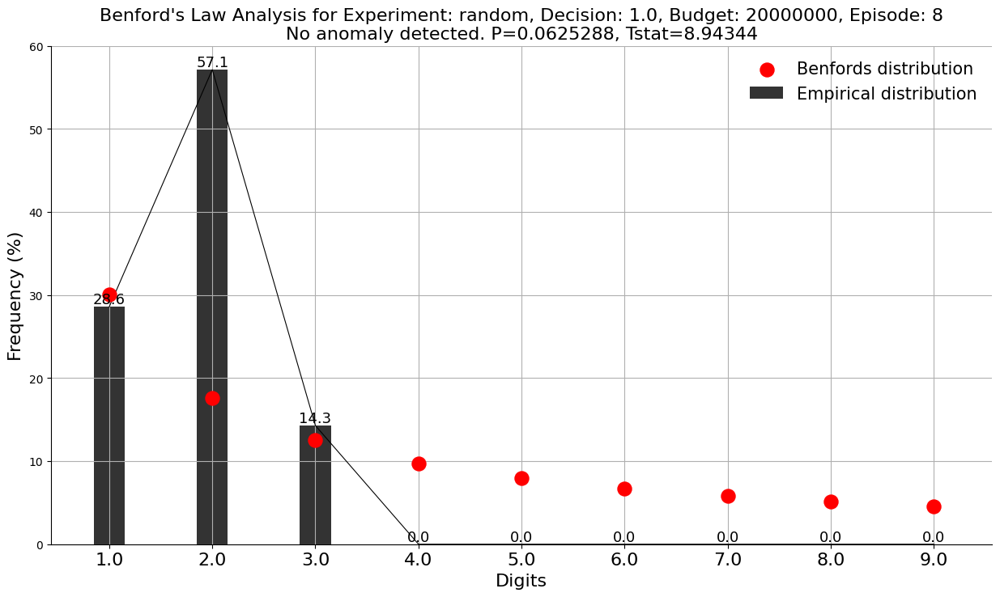

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode8.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.093476, Tstat=7.94869


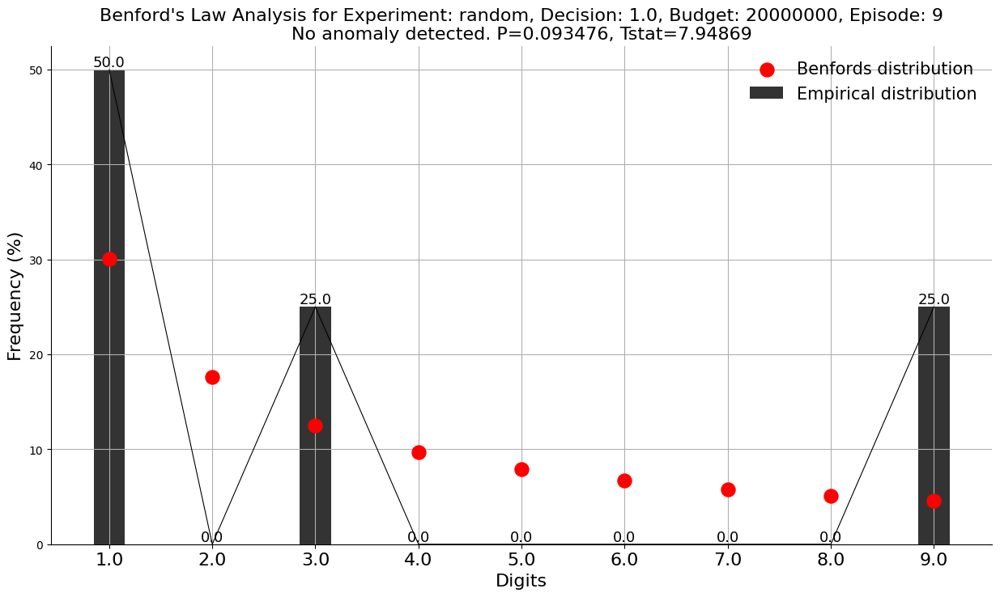

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode9.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.533655, Tstat=3.14626


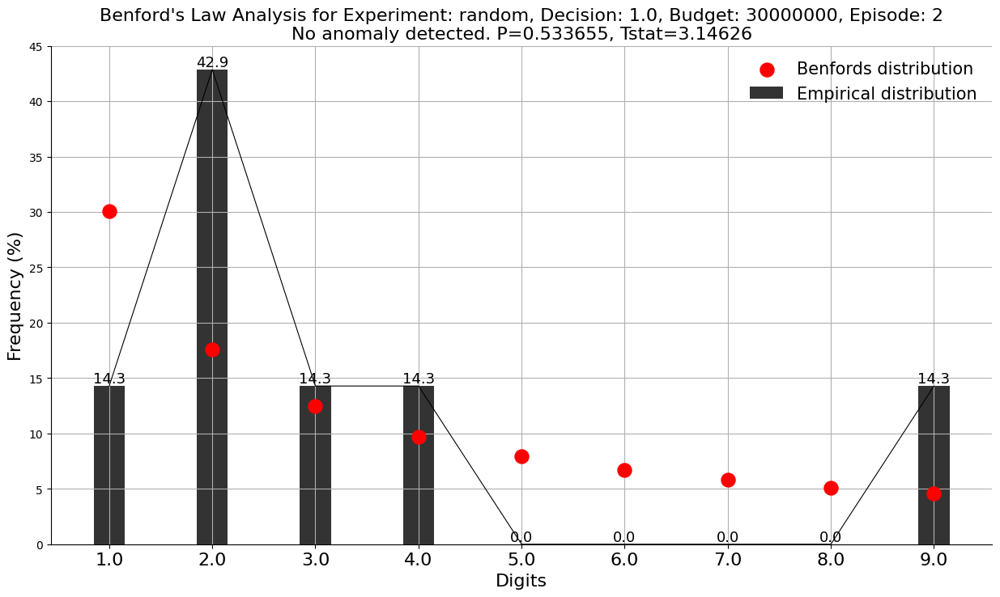

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget30000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.295479, Tstat=4.9212


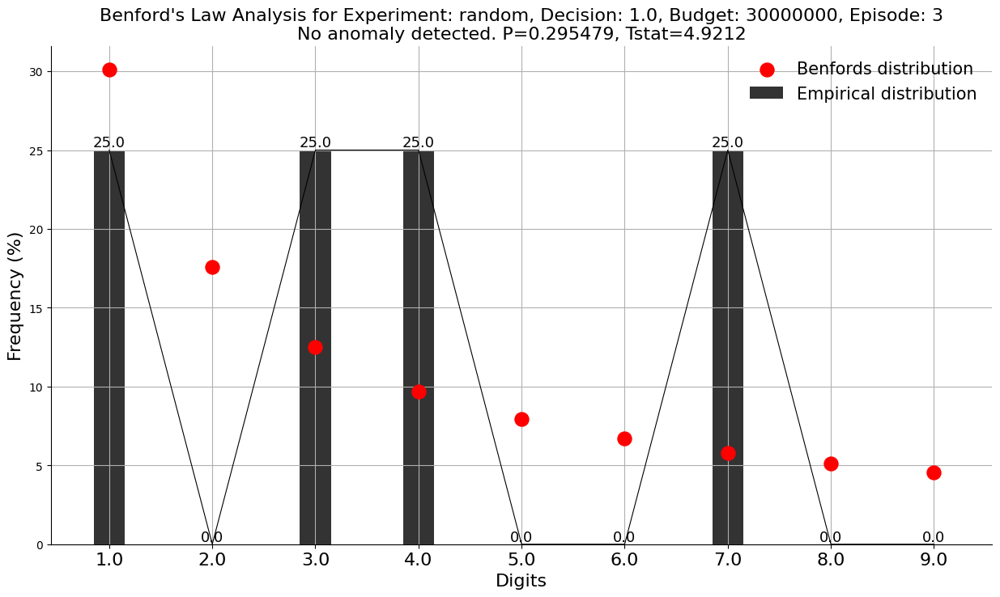

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget30000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.133516, Tstat=7.04525


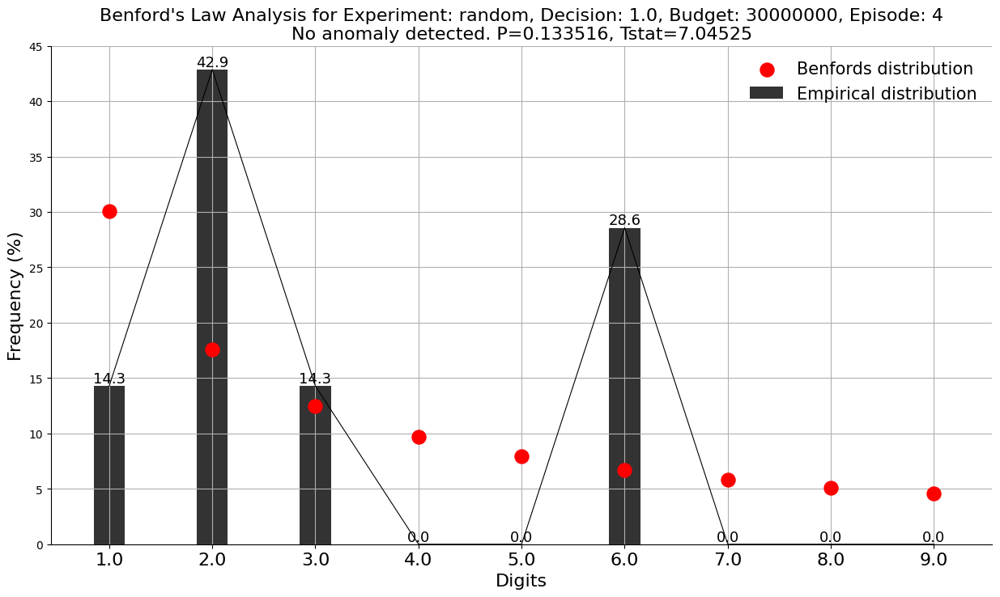

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget30000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.929371, Tstat=0.866112


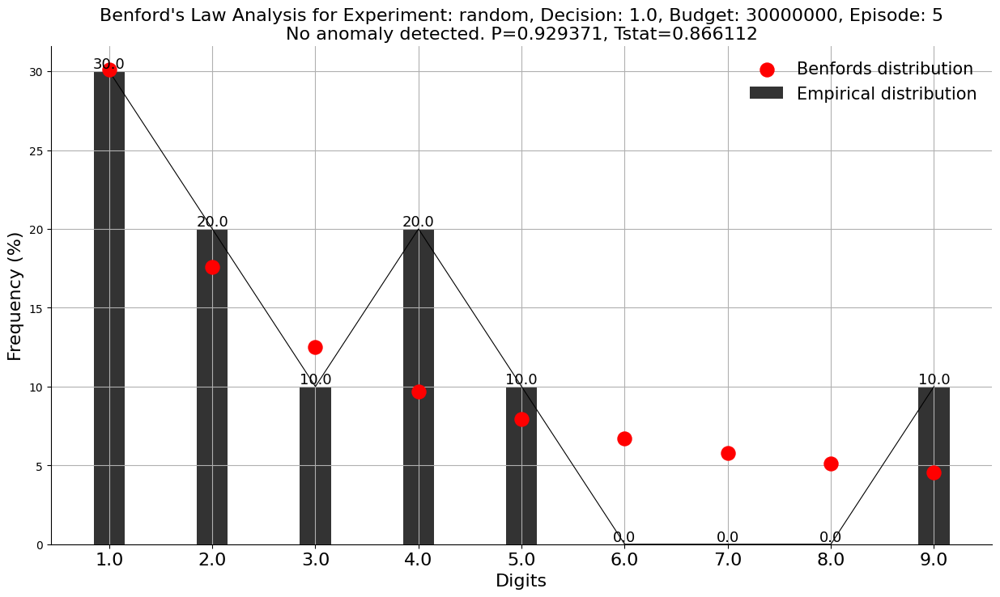

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget30000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.10195, Tstat=7.73085


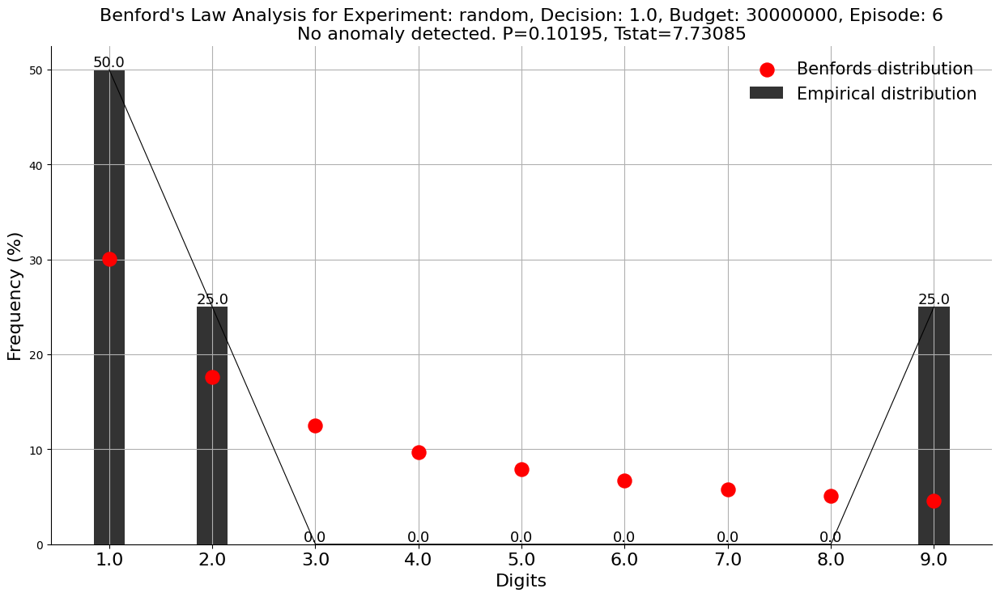

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget30000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0159616, Tstat=12.1946


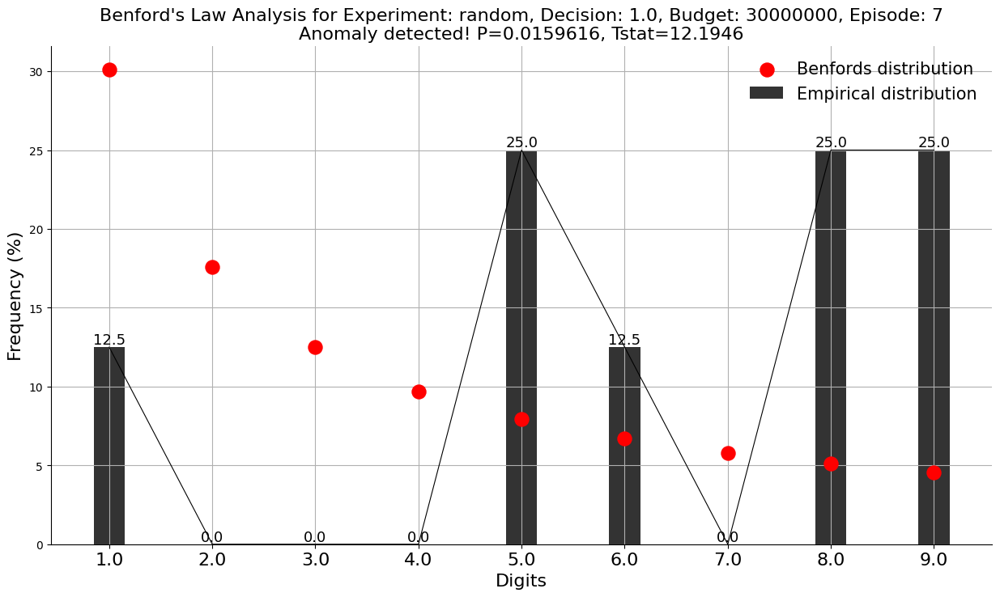

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget30000000_episode7.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0638947, Tstat=8.89053


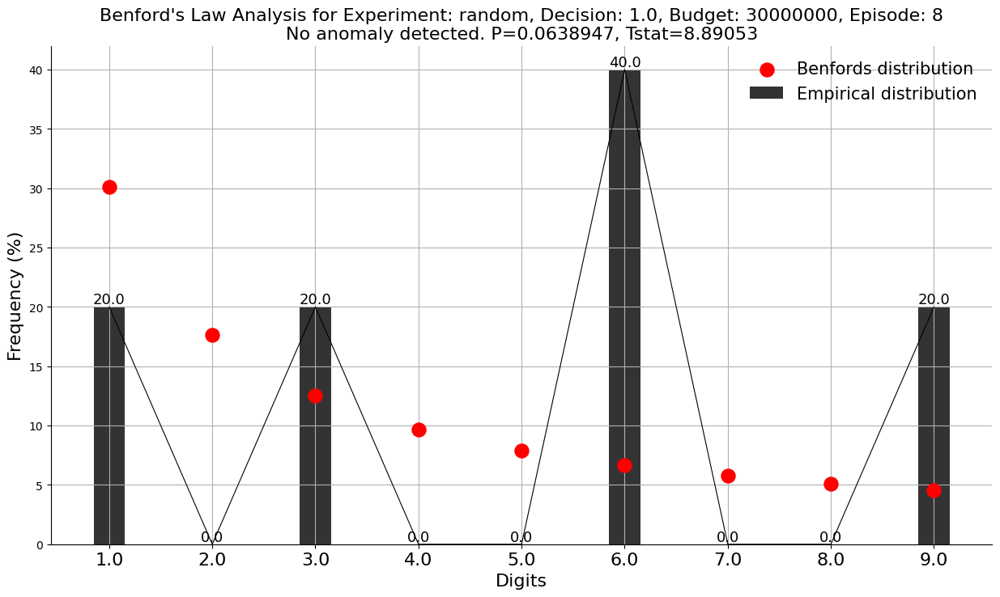

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget30000000_episode8.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.291242, Tstat=4.96177


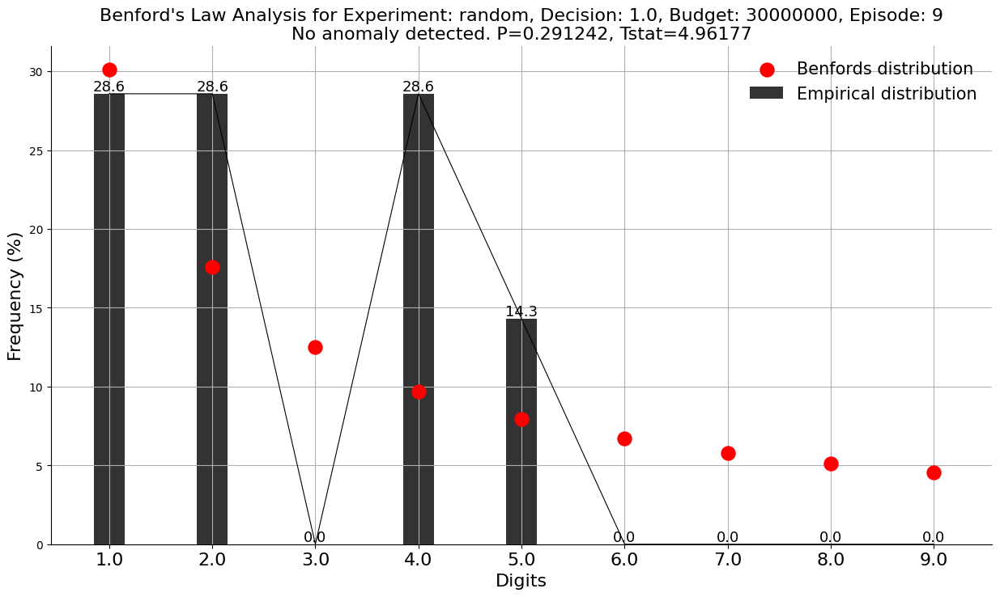

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget30000000_episode9.png
Summary results saved to: .temp/experiment_results/benford_summary_results.csv


In [59]:
import os
import pandas as pd
from benfordslaw import benfordslaw

# Create a directory to store the results if it doesn't exist
results_dir = ".temp/experiment_results"
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

# Initialize the Benford's Law analyzer with method='ssd' for the Chi-squared test
bl = benfordslaw(method='ssd')

# Assuming your dataset is loaded into a DataFrame called 'data'
# The dataset includes columns: experiment, rewards, wc, woc, valor_indenizacao, initial_budget, decision, episode

# Group the data by experiment, decision, initial_budget, and episode
groups = data.groupby(['experiment', 'decision', 'initial_budget', 'episodes'])

# Prepare a list to store summary results
summary_results = []

# Iterate over each group and apply Benford's Law analysis
for (experiment, decision, initial_budget, episode), group in groups:
    valor_indenizacao = group['valor_indenizacao'].dropna().values
    
    if len(valor_indenizacao) == 0:
        print(f"No indemnity values available for Experiment: {experiment}, Decision: {decision}, Initial Budget: {initial_budget}, Episode: {episode}")
        continue
    
    # Apply Benford's Law to the valor_indenizacao values
    results = bl.fit(valor_indenizacao)
    
    # Generate plot and save it
    plot_title = f"Benford's Law Analysis for Experiment: {experiment}, Decision: {decision}, Budget: {initial_budget}, Episode: {episode}"
    fig, ax = bl.plot(title=plot_title)
    
    # Save the plot to the results directory
    plot_filename = f"{results_dir}/benford_plot_{experiment}_dec{decision}_budget{initial_budget}_episode{episode}.png"
    fig.savefig(plot_filename)
    print(f"Plot saved to: {plot_filename}")
    
    # Append results to the summary list
    summary_results.append({
        'experiment': experiment,
        'decision': decision,
        'initial_budget': initial_budget,
        'episode': episode,
        'KS_stat': results['t'],  # The test statistic for the KS test
        'p_value': results['P'],  # The p-value for the KS test
        'P_significant': results['P_significant'],  # whether it's significant
        'percentage_emp': results['percentage_emp']  # empirical distribution
    })

# Create a summary DataFrame
summary_df = pd.DataFrame(summary_results)

# Save the summary DataFrame to the results directory
summary_filename = f"{results_dir}/benford_summary_results.csv"
summary_df.to_csv(summary_filename, index=False)
print(f"Summary results saved to: {summary_filename}")


In [60]:
summary_df.pivot_table(
    index = 'epispode', 
    ''
)

,experiment,decision,initial_budget,episode,KS_stat,p_value,P_significant,percentage_emp
0,dqn,0.0,10000000,1,12.565101,0.013608,True,"[[1.0, 0.0], [2.0, 33.33333333333333], [3.0, 6..."
1,dqn,0.0,10000000,2,4.635786,0.326749,False,"[[1.0, 40.0], [2.0, 20.0], [3.0, 20.0], [4.0, ..."
2,dqn,0.0,10000000,3,7.337907,0.119073,False,"[[1.0, 33.33333333333333], [2.0, 33.3333333333..."
3,dqn,0.0,10000000,4,3.997637,0.406326,False,"[[1.0, 28.57142857142857], [2.0, 14.2857142857..."
4,dqn,0.0,10000000,5,10.642097,0.030895,True,"[[1.0, 50.0], [2.0, 0.0], [3.0, 0.0], [4.0, 50..."
...,...,...,...,...,...,...,...,...
73,random,1.0,30000000,5,0.866112,0.929371,False,"[[1.0, 30.0], [2.0, 20.0], [3.0, 10.0], [4.0, ..."
74,random,1.0,30000000,6,7.730851,0.101950,False,"[[1.0, 50.0], [2.0, 25.0], [3.0, 0.0], [4.0, 0..."
75,random,1.0,30000000,7,12.194562,0.015962,True,"[[1.0, 12.5], [2.0, 0.0], [3.0, 0.0], [4.0, 0...."
76,random,1.0,30000000,8,8.890530,0.063895,False,"[[1.0, 20.0], [2.0, 0.0], [3.0, 20.0], [4.0, 0..."


Analyzing random, Decision 0.0, Budget 10000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[chi2] No anomaly detected. P=0.176938, Tstat=11.4607
Analyzing random, Decision 0.0, Budget 10000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[chi2] No anomaly detected. P=0.977811, Tstat=2.60886
Analyzing random, Decision 0.0, Budget 10000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[chi2] No anomaly detected. P=0.423982, Tstat=9.14518
Analyzing random, Decision 0.0, Budget 20000000, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[chi2] Anomaly detected! P=0.00276054, Tstat=23.5167
Analyzing random, Decision 0.0, Budget 20000000, Position 2:
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[chi2] No anomaly detected. P=0.813189, Tstat=5.23689
Analyzing random, Decision 0.0, Budget 20000000, Position 3:
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[chi2

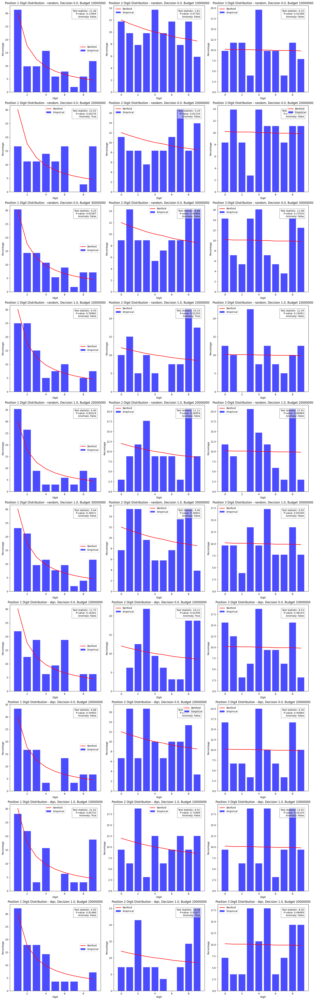

Report saved to .temp/experiment_results/plots/benford_report.png
Summary of Benford's Law Analysis:


In [47]:
import pandas as pd
import matplotlib.pyplot as plt
from benfordslaw import benfordslaw
import numpy as np
import os
import math

class BenfordAnalyzer:
    def __init__(self, data, experiments, decisions, budgets, save_dir=".temp/experiment_results/plots"):
        """
        Initialize the BenfordAnalyzer with dataset, experiment, decision, and budget combinations.
        """
        self.data = data.dropna(subset=['value'])  # Clean the data by dropping NaN values
        self.experiments = experiments
        self.decisions = decisions
        self.budgets = budgets
        self.save_dir = save_dir  # Directory to save plots
        if not os.path.exists(self.save_dir):
            os.makedirs(self.save_dir)

    def analyze(self):
        """
        Analyze the dataset using Benford's Law for the first three digits across various combinations.
        """
        # Determine the number of plot rows required
        total_plots = len(self.experiments) * len(self.decisions) * len(self.budgets)
        ncols = 3  # Fixed number of columns for 1st, 2nd, and 3rd digits
        nrows = total_plots  # Number of rows is total plots, as we have 3 columns per row

        fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 6 * nrows))

        # Flatten axes array to easily reference each plot position
        axes = axes.reshape(-1, ncols)

        plot_idx = 0  # Keeps track of plot position for each combination

        # Loop through each combination
        for experiment in self.experiments:
            for decision in self.decisions:
                for initial_budget in self.budgets:
                    # Filter dataset for the specific combination
                    subset = self.data[(self.data['experiment'] == experiment) & 
                                       (self.data['decision'] == decision) & 
                                       (self.data['initial_budget'] == initial_budget)]
                    
                    # Check if there are values to analyze
                    if subset.empty:
                        print(f"No data for {experiment}, Decision {decision}, Budget {initial_budget}.")
                        continue
                    
                    # Perform Benford's Law analysis and plot all positions in one row (1st, 2nd, and 3rd digit)
                    self._analyze_subset(subset, experiment, decision, initial_budget, axes[plot_idx])
                    plot_idx += 1

        # Hide any unused subplots
        for i in range(plot_idx, len(axes)):
            for ax in axes[i]:
                ax.remove()  # Remove any extra unused axes

        # Save the entire report as a one-page PNG file
        report_filename = f"{self.save_dir}/benford_report.png"
        plt.tight_layout()
        plt.subplots_adjust(top=0.95)
        plt.savefig(report_filename)
        plt.show()
        print(f"Report saved to {report_filename}")
        plt.close(fig)  # Close the figure

    def _analyze_subset(self, subset, experiment, decision, initial_budget, axes_row):
        """
        Helper function to analyze a specific subset of data for the first three digit positions and plot them.
        Adds annotations to the plots with statistical results.
        """
        # Perform Benford's Law analysis for each position (1st, 2nd, and 3rd digit)
        for pos in range(1, 4):  # Looping through first, second, and third digits
            benford = benfordslaw(pos=pos)
            values = subset['value'].astype(float).values

            print(f"Analyzing {experiment}, Decision {decision}, Budget {initial_budget}, Position {pos}:")
            
            # Fit the data to Benford's Law
            benford.fit(values)
            
            # Adjust digit range depending on the digit position
            if pos == 1:
                digit_range = range(1, 10)  # Digits 1 to 9
            else:
                digit_range = range(0, 10)  # Digits 0 to 9 for positions 2 and 3
            
            # Plot empirical and expected Benford distribution
            axes = axes_row[pos - 1]
            axes.bar(digit_range, benford.results['percentage_emp'][:, 1], color='blue', alpha=0.7, label='Empirical')
            axes.plot(digit_range, benford.leading_digits, 'r-', label='Benford', linewidth=2)
            axes.set_title(f'Position {pos} Digit Distribution - {experiment}, Decision {decision}, Budget {initial_budget}')
            axes.set_xlabel('Digit')
            axes.set_ylabel('Percentage')
            axes.legend()

            # Add annotations directly on the plot
            p_value = benford.results['P']
            t_stat = benford.results['t']
            anomaly_detected = benford.results['P_significant']
            annotation_text = f"Test statistic: {t_stat:.2f}\nP-value: {p_value:.5f}\nAnomaly: {anomaly_detected}"
            axes.text(0.95, 0.95, annotation_text, transform=axes.transAxes, fontsize=10,
                      verticalalignment='top', horizontalalignment='right', bbox=dict(facecolor='white', alpha=0.5))

    def summarize(self):
        """
        Generate automated reports based on the analysis.
        This could be expanded to generate CSV reports, alerts, etc.
        """
        print("Summary of Benford's Law Analysis:")
        # This is a placeholder; you could expand this to create more detailed reports or alerts
        # based on the goodness-of-fit test results.


# Example usage:
# Assuming `data` is your DataFrame with the necessary columns
experiments = ['random', 'dqn']
decisions = [0.0, 1.0]
budgets = list(data.initial_budget.unique())

# Create an instance of the BenfordAnalyzer class
benford_analyzer = BenfordAnalyzer(data, experiments, decisions, budgets)

# Perform the analysis
benford_analyzer.analyze()

# Optionally, generate a summary report
benford_analyzer.summarize()



# Decision Analytics

In [48]:

# Assuming 'data' is your DataFrame
# Perform the statistical analysis

data["steps"] = pd.to_numeric(data["steps"])
grouped_stats = data.groupby(['experiment', 'initial_budget'])['rewards'].agg(['mean', 'median', 'std', 'min', 'max', 'count'])

# To get more insights, you might want to calculate the interquartile range (IQR)
def calculate_iqr(series):
    return series.quantile(0.75) - series.quantile(0.25)

# Adding IQR to the grouped statistics
grouped_stats['iqr'] = data.groupby(['experiment', 'initial_budget'])['steps'].apply(calculate_iqr)

# Reset index to make 'experiment' and 'initial_budget' as columns again
grouped_stats = grouped_stats.reset_index()

# Display the statistics
print(grouped_stats)

# Optionally, save this to a CSV file
output_stats_path = 'experiment_results/stats/episode_length_stats.csv'
os.makedirs('experiment_results/stats', exist_ok=True)
grouped_stats.to_csv(output_stats_path, index=False)

print(f"Statistical analysis results saved to {output_stats_path}")

  experiment  initial_budget      mean    median       std       min  \
0        dqn        10000000  0.195164  0.188585  0.765649 -1.322909   
1        dqn        20000000  0.003254  0.156074  0.903338 -1.339426   
2     random        10000000  0.317042  0.260325  0.814669 -1.258094   
3     random        20000000  0.147966  0.183803  0.836693 -1.335787   
4     random        30000000  0.196168  0.225566  0.909768 -1.287459   

        max  count  iqr  
0  1.149732     64  4.0  
1  1.277278     58  5.0  
2  1.212755     91  8.0  
3  1.164233     70  5.0  
4  1.261054    108  7.0  
Statistical analysis results saved to experiment_results/stats/episode_length_stats.csv


In [49]:
data.groupby(["experiment", "decision"]).rewards.describe().T

experiment        dqn                 random            
decision          0.0        1.0         0.0         1.0
count       62.000000  60.000000  143.000000  126.000000
mean         0.488795  -0.293768    0.713671   -0.330637
std          0.658970   0.817223    0.524892    0.828019
min         -1.149732  -1.339426   -1.155271   -1.335787
25%          0.000000  -1.178519    0.000000   -1.103512
50%          1.000000   0.156562    1.000000    0.155543
75%          1.000000   0.213415    1.000000    0.230124
max          1.277278   1.149732    1.261054    1.234693

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0136084, Tstat=12.5651


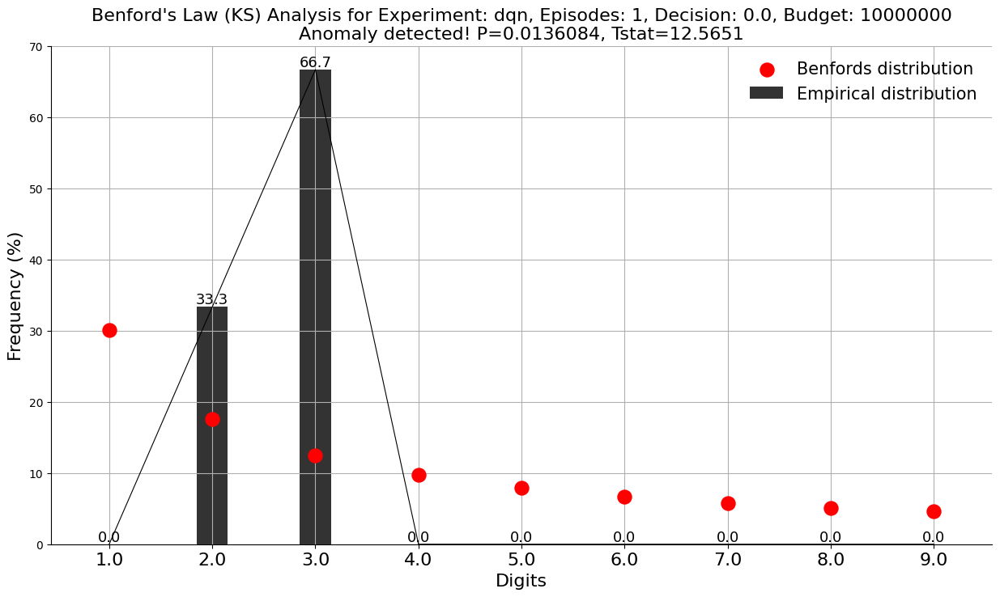

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep1_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.310847, Tstat=4.77797


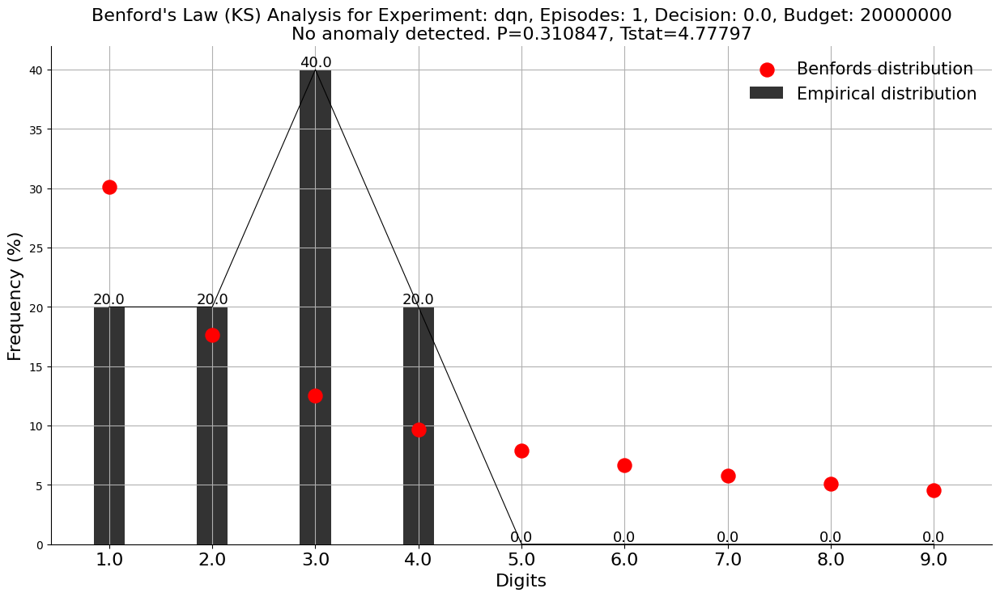

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep1_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0307243, Tstat=10.6553


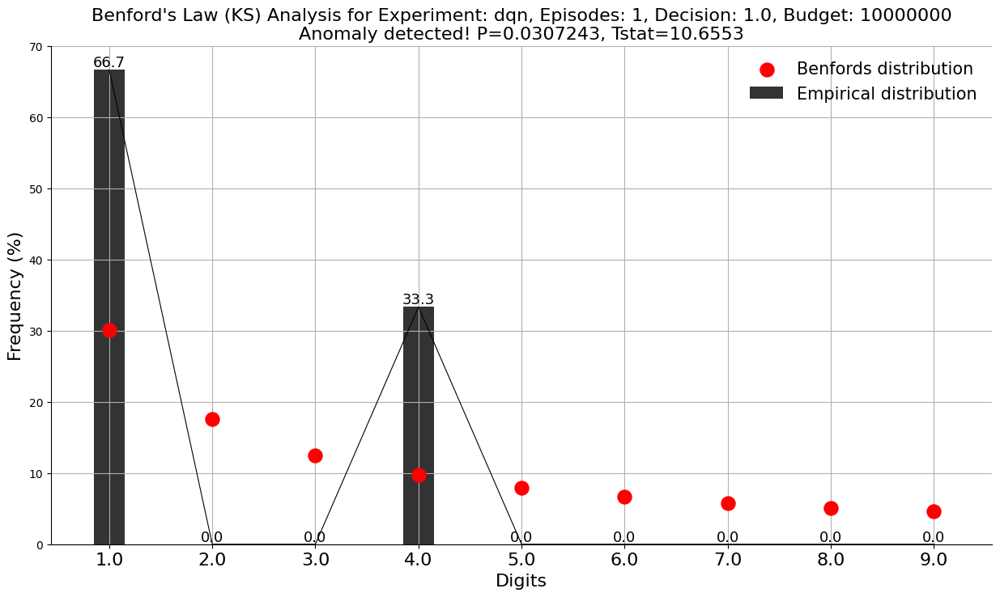

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep1_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.131892, Tstat=7.07666


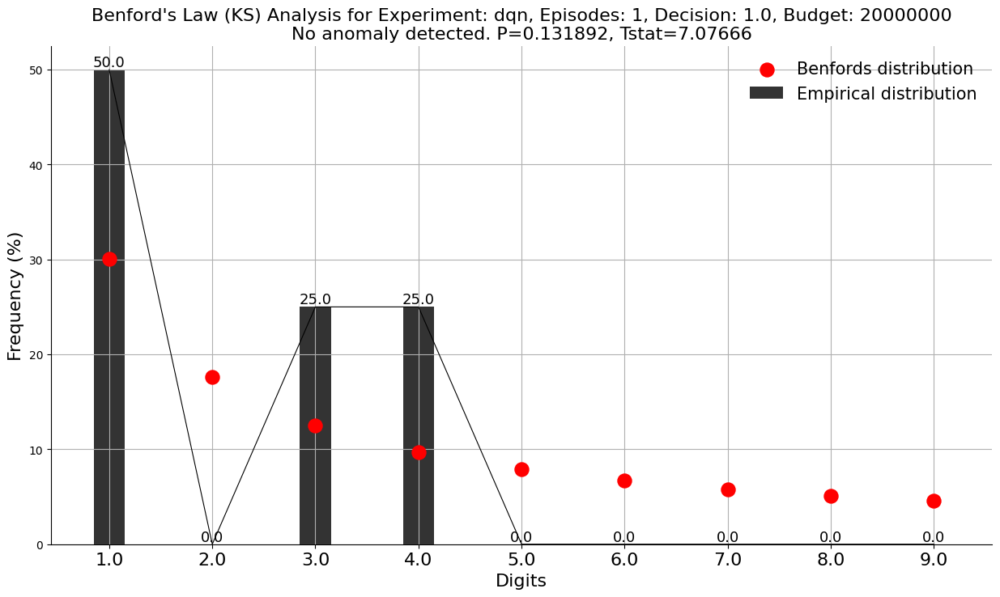

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep1_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.326749, Tstat=4.63579


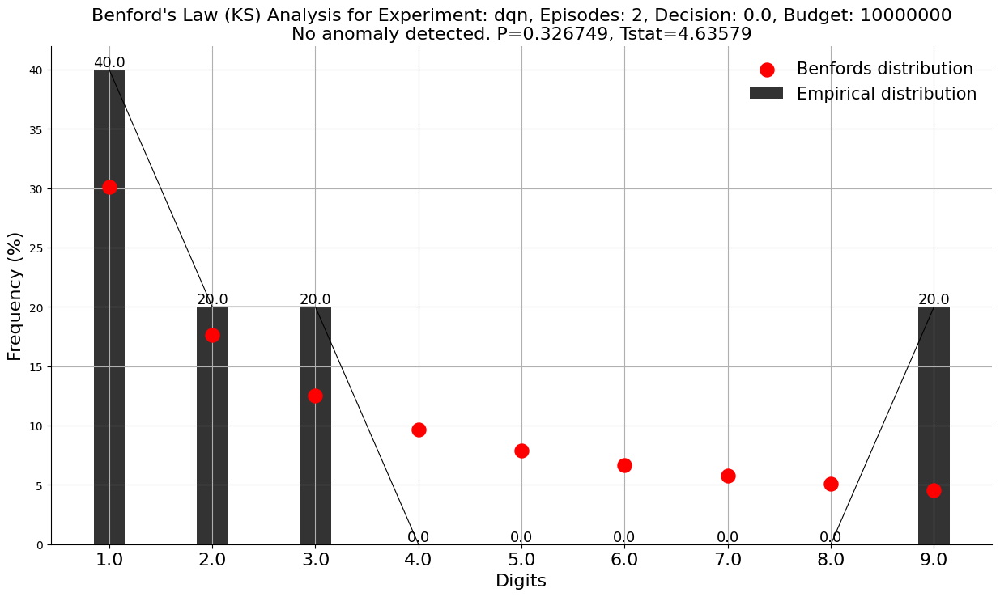

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep2_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.142155, Tstat=6.88385


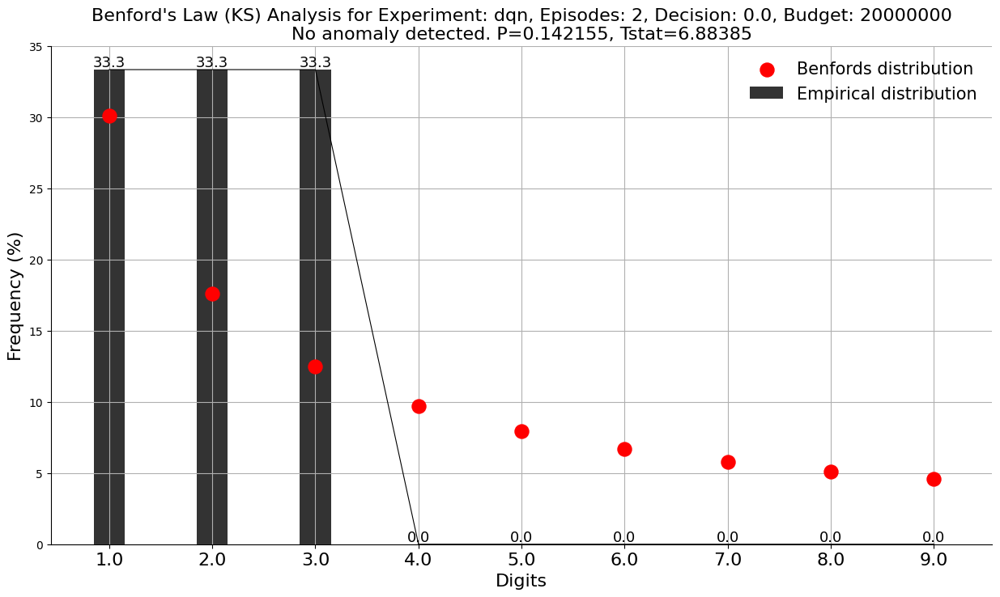

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep2_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0426635, Tstat=9.87067


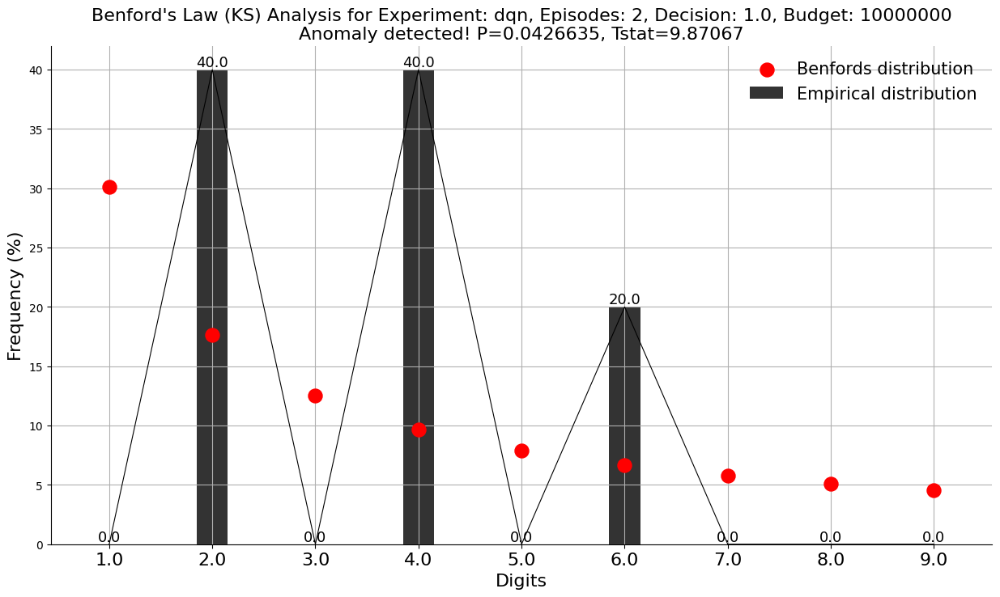

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep2_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.233203, Tstat=5.57514


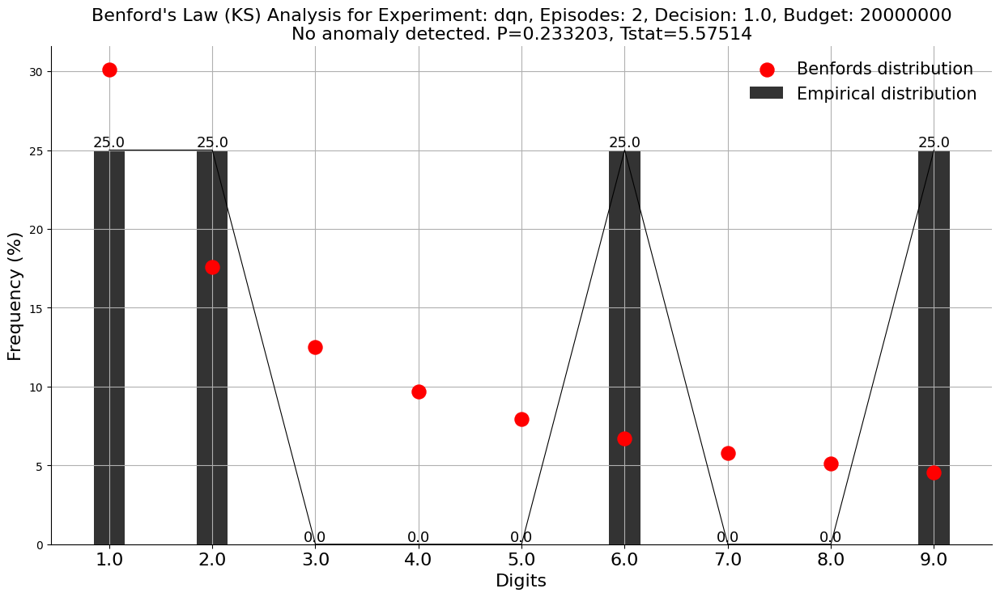

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep2_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.119073, Tstat=7.33791


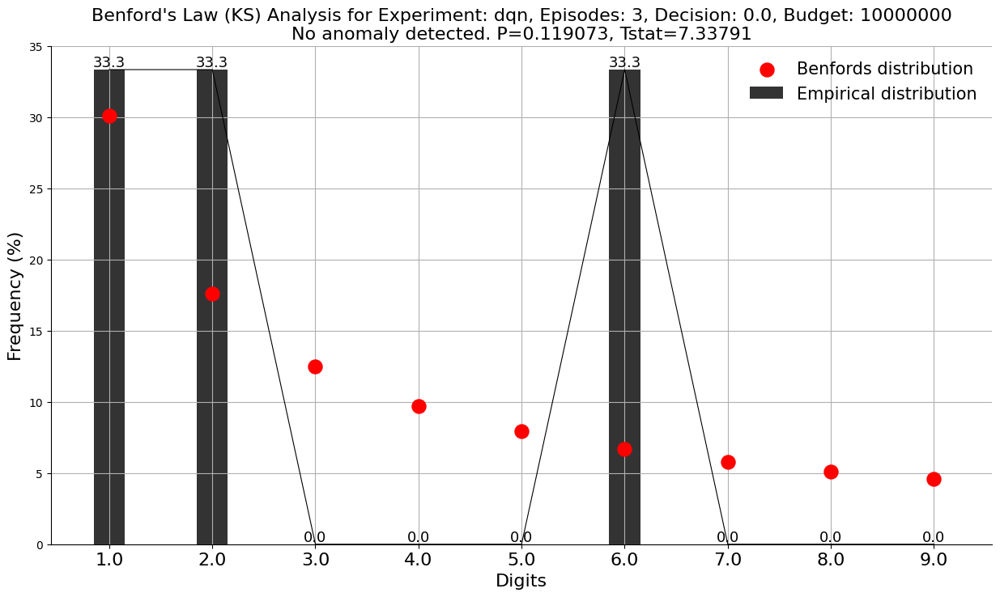

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep3_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.667268, Tstat=2.37435


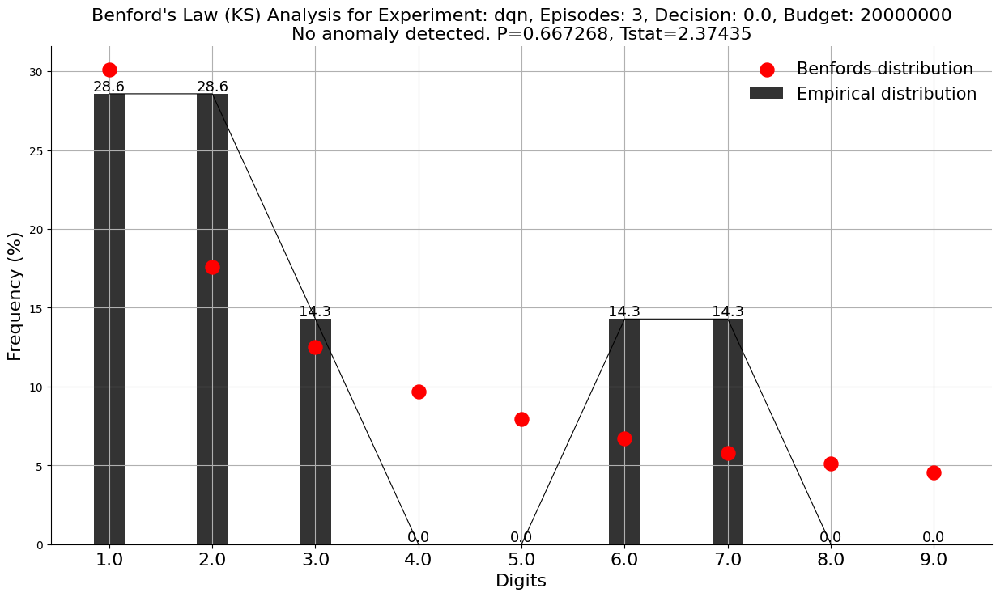

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep3_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0683828, Tstat=8.72393


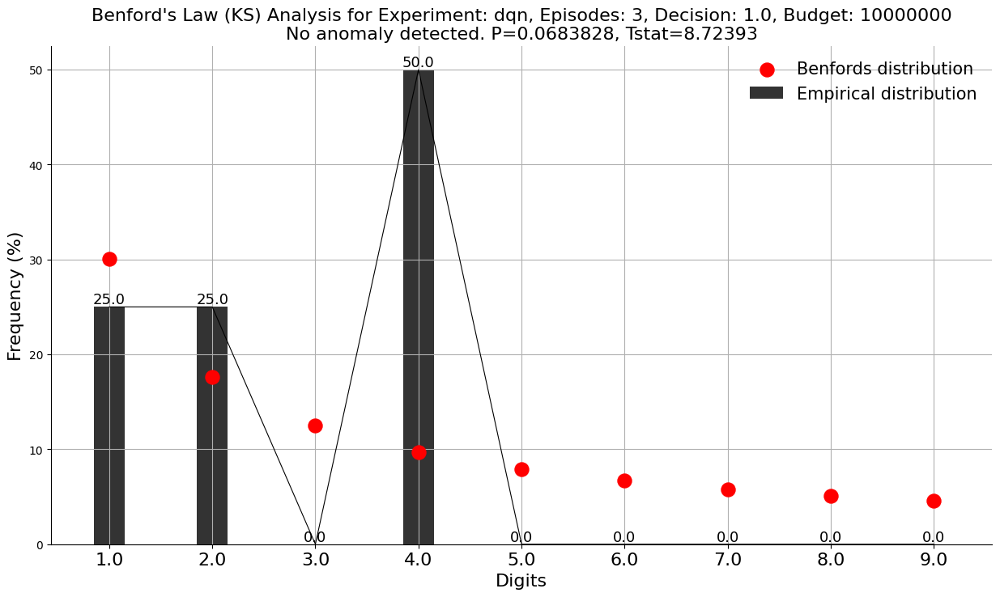

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep3_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0896608, Tstat=8.05286


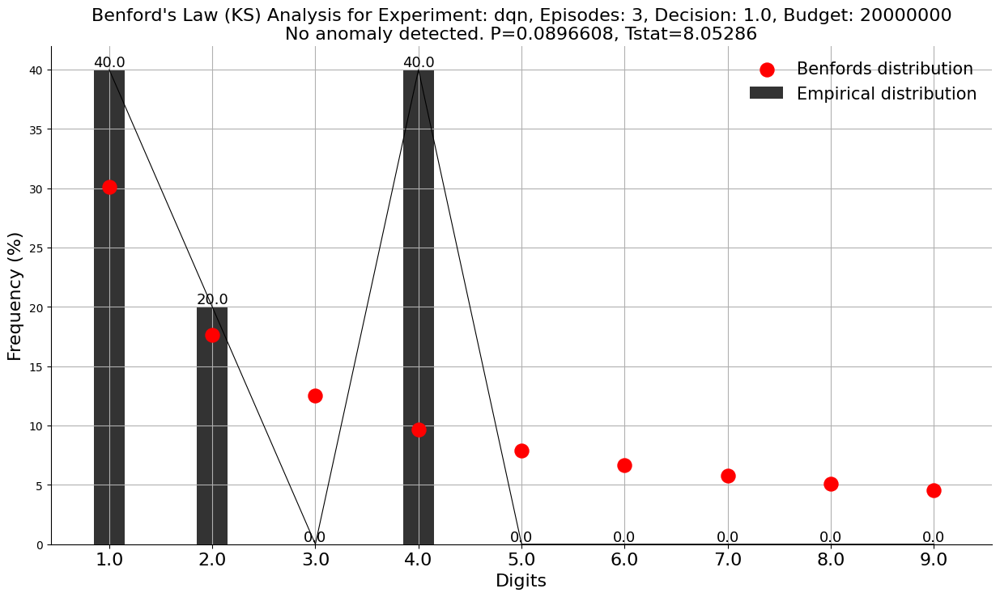

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep3_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.406326, Tstat=3.99764


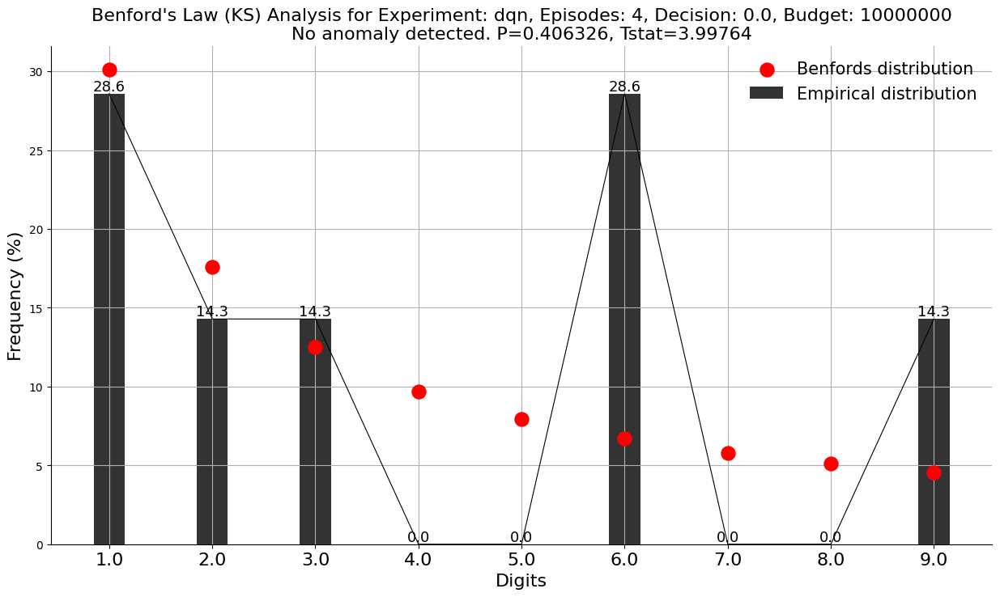

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep4_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0718944, Tstat=8.60065


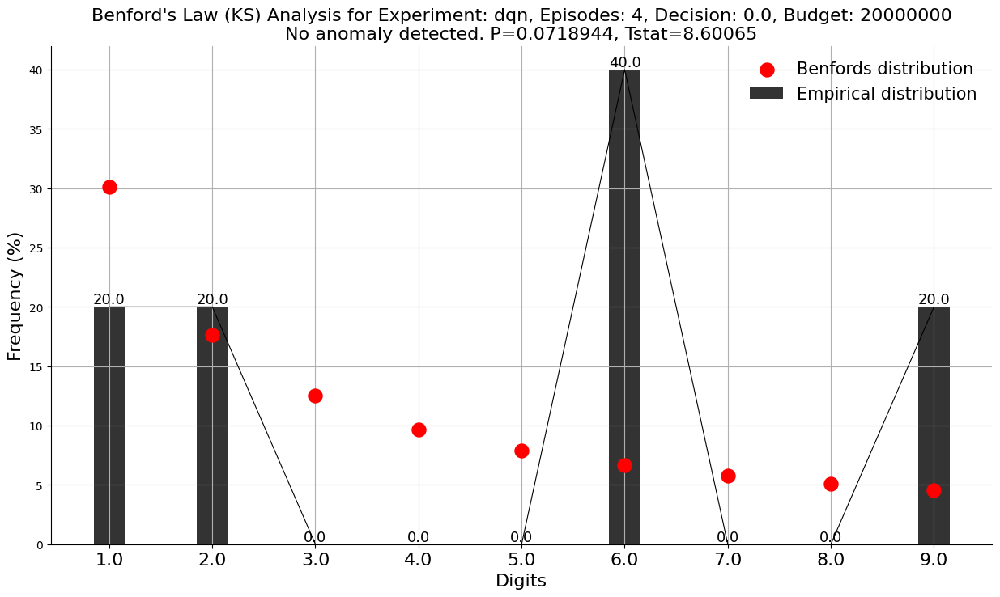

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep4_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.109918, Tstat=7.54094


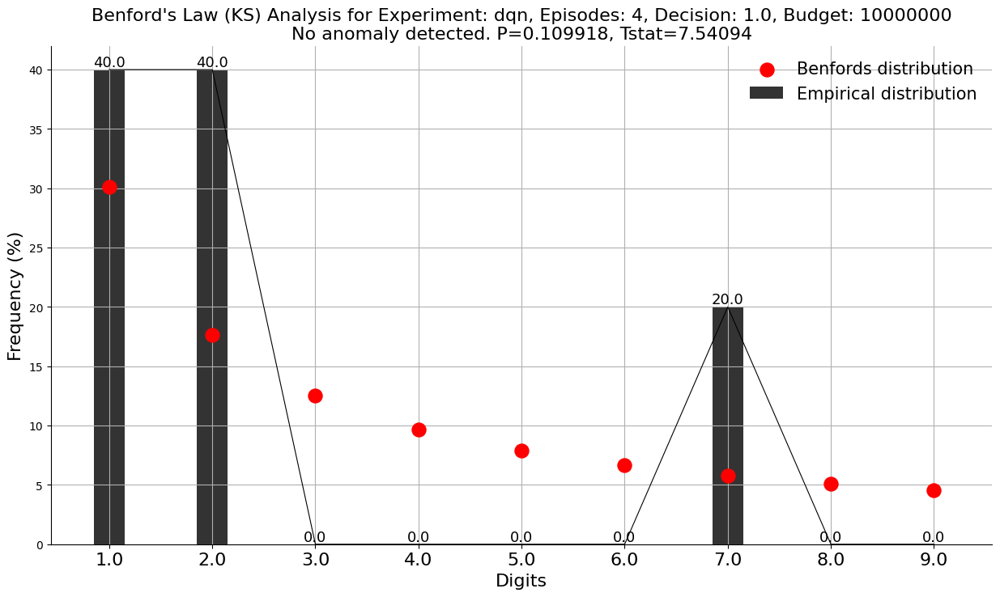

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep4_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.344957, Tstat=4.47974


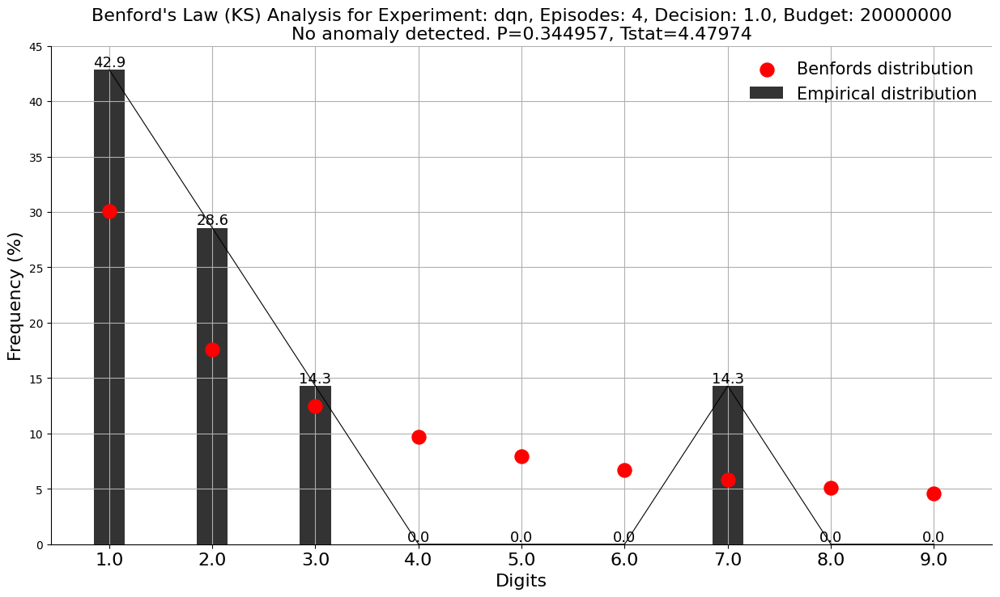

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep4_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


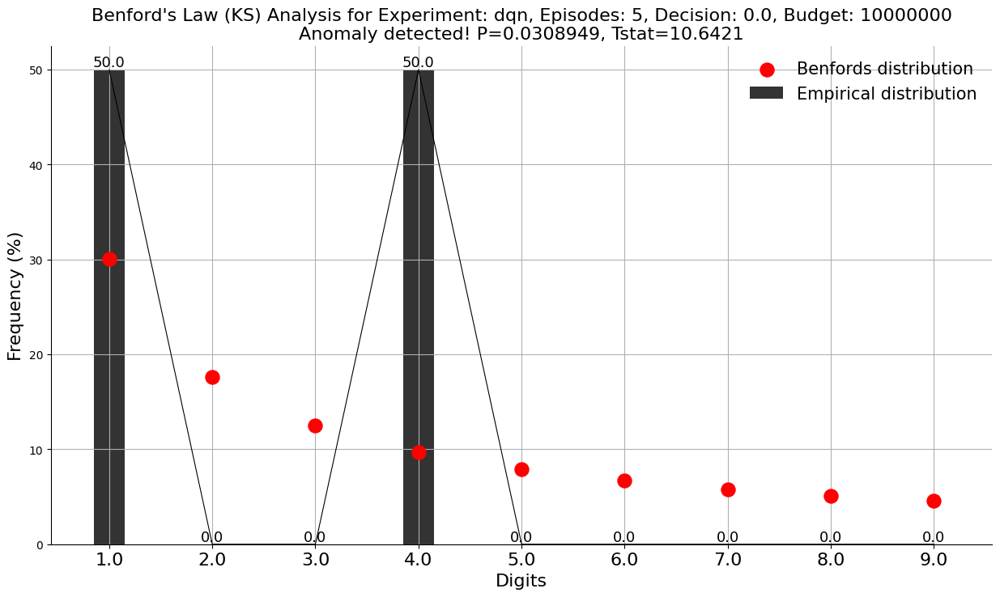

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep5_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0155856, Tstat=12.25


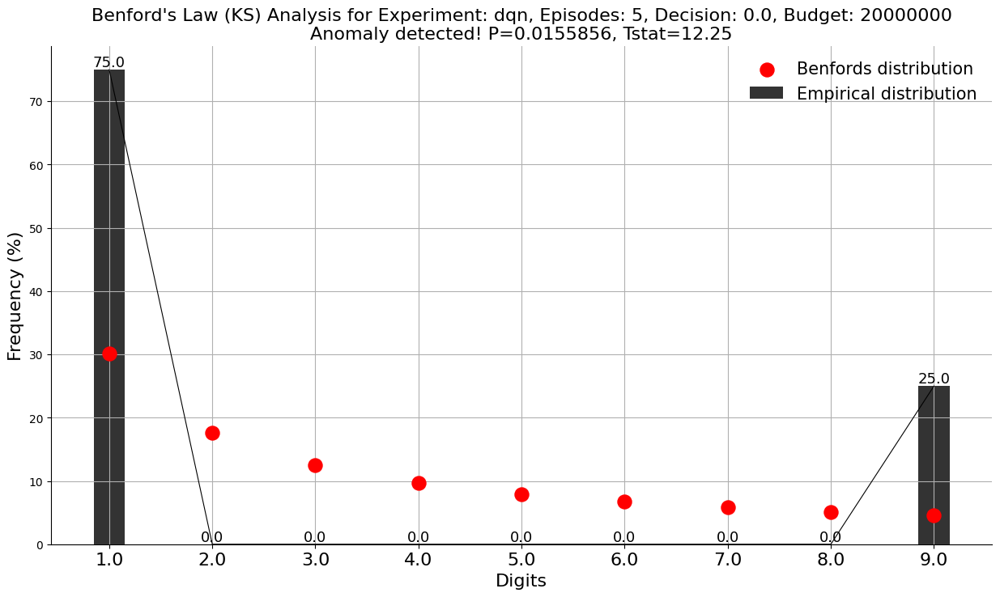

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep5_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0163313, Tstat=12.1412


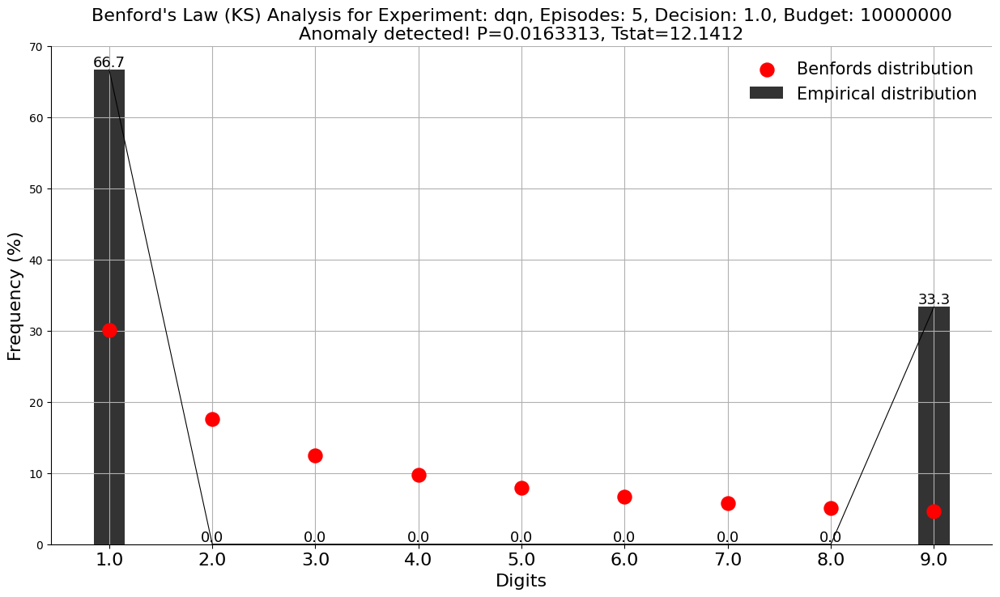

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep5_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.128483, Tstat=7.14376


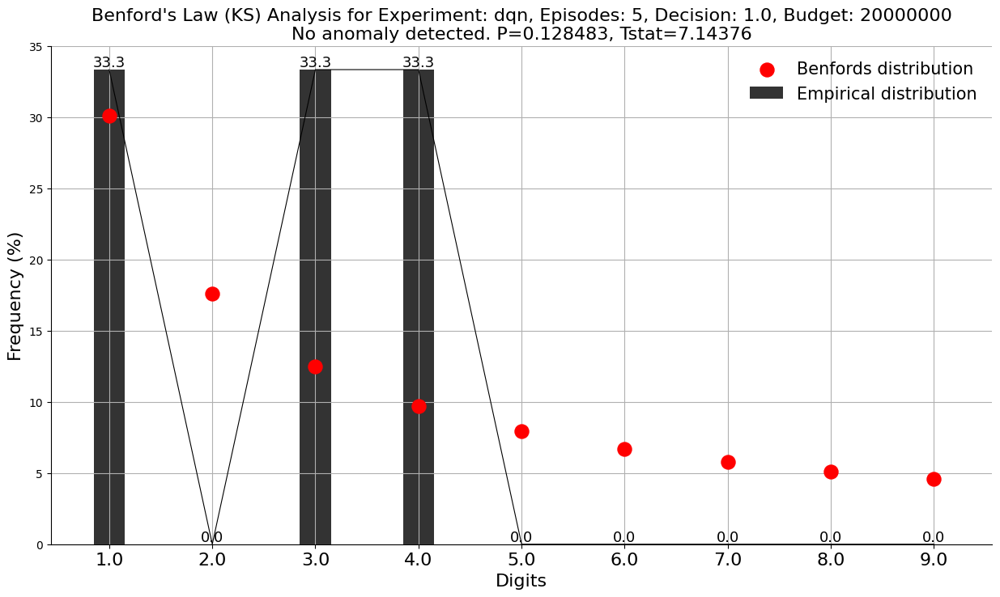

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep5_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.153496, Tstat=6.68509


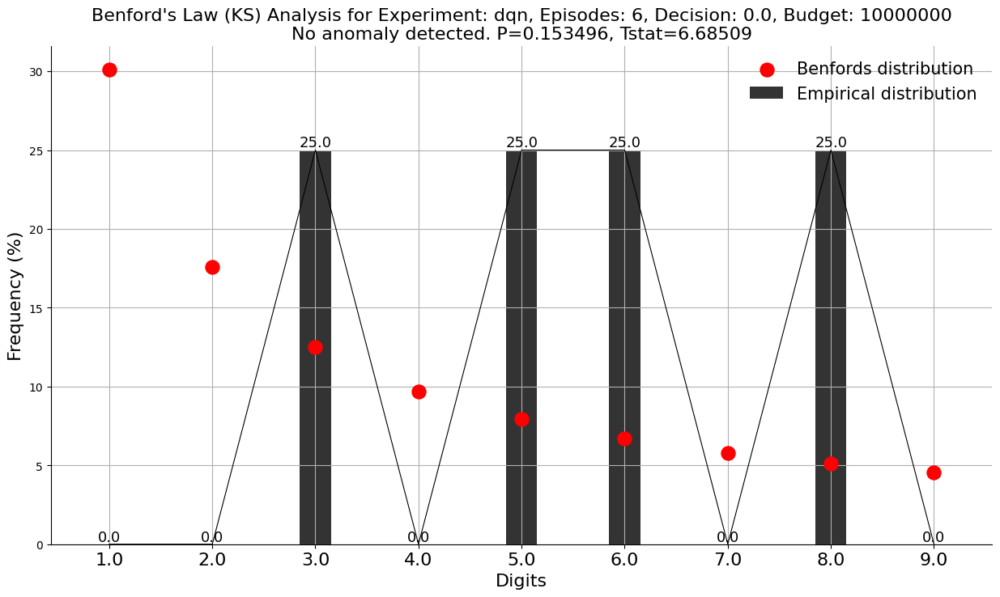

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep6_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0727958, Tstat=8.56993


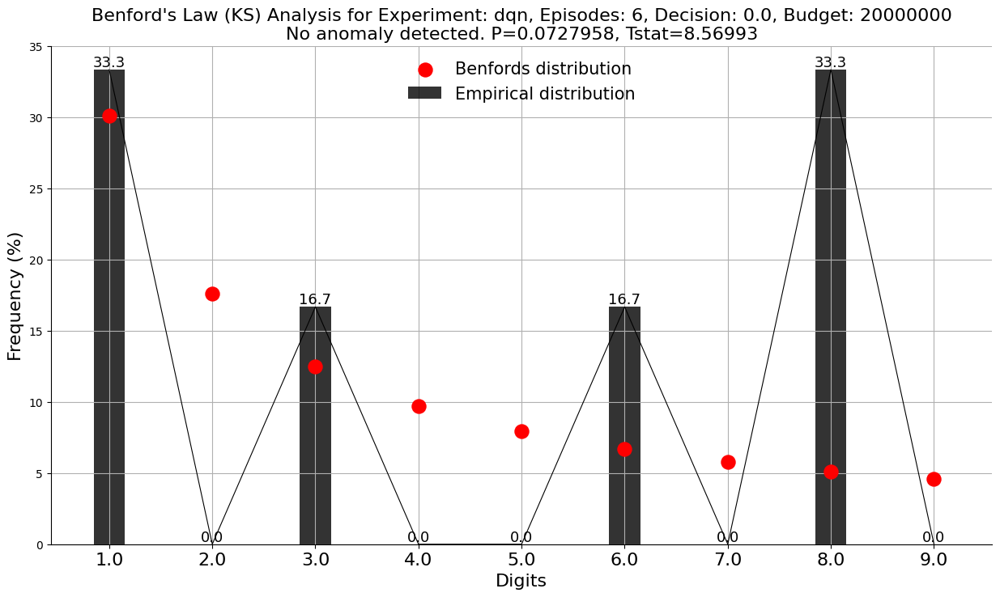

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep6_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0752678, Tstat=8.48748


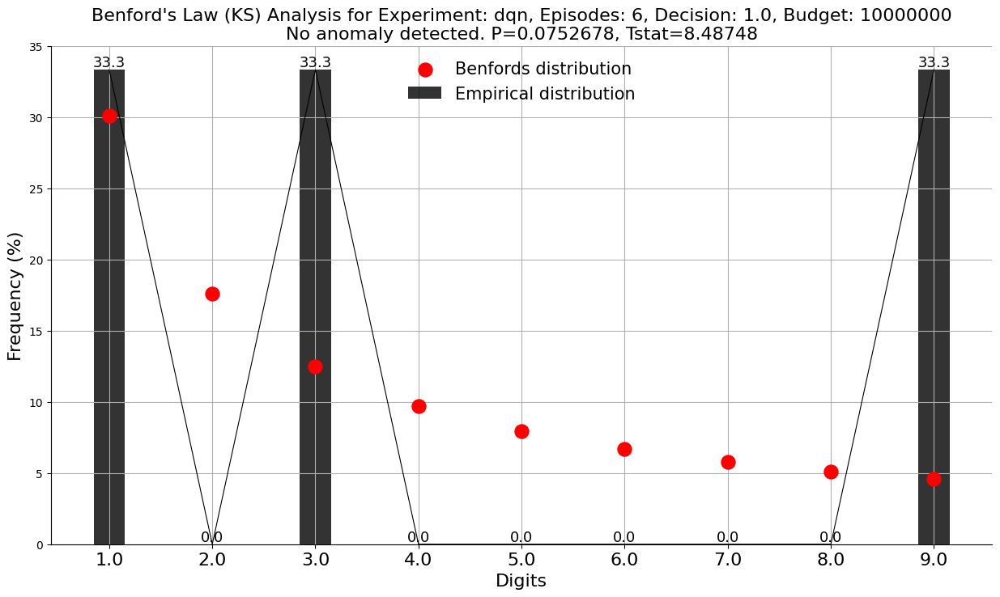

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep6_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.164319, Tstat=6.50749


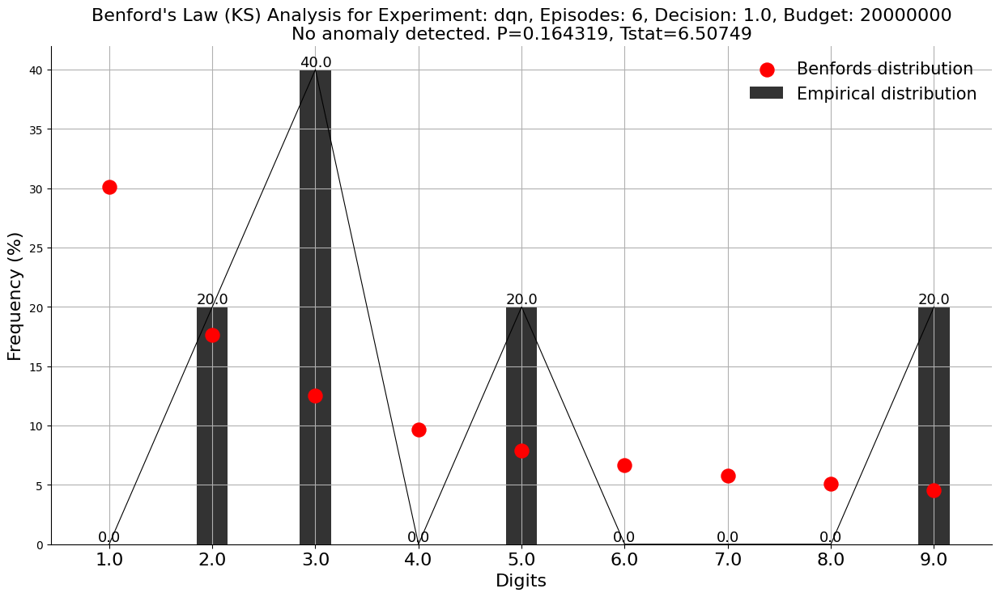

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep6_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0145698, Tstat=12.4067


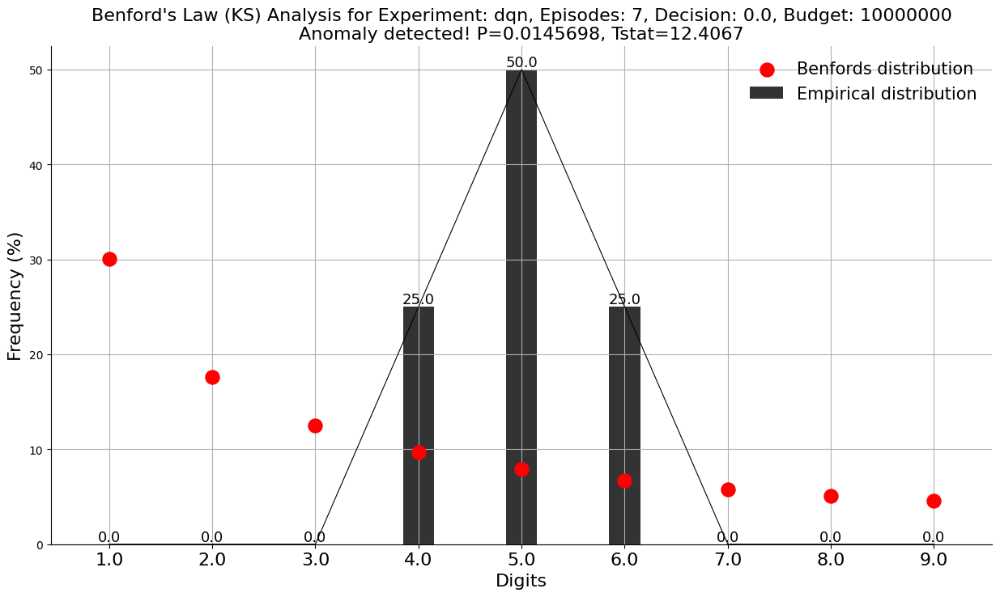

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep7_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=5.78869e-09, Tstat=44.215


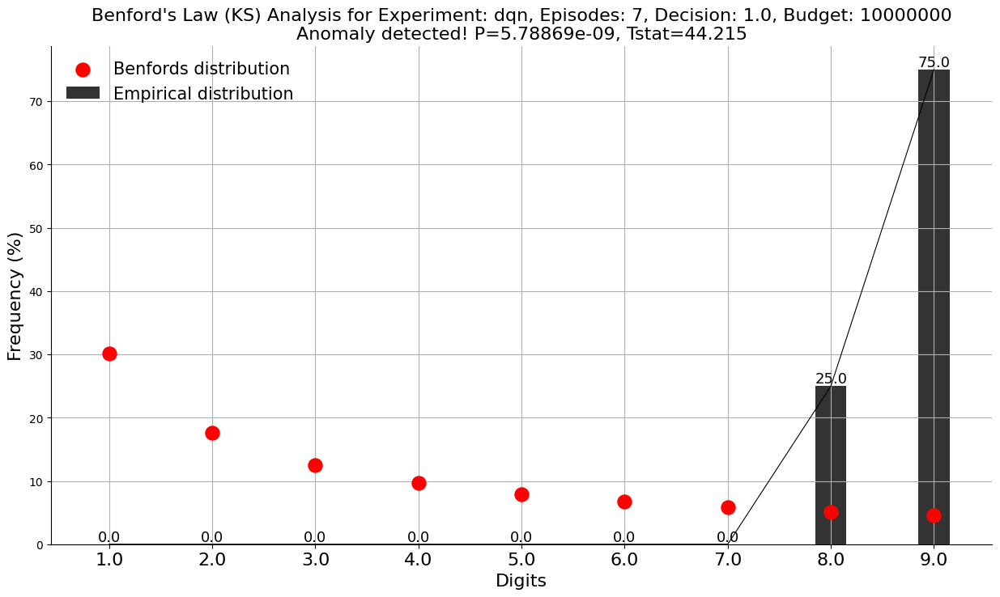

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep7_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0390577, Tstat=10.0827


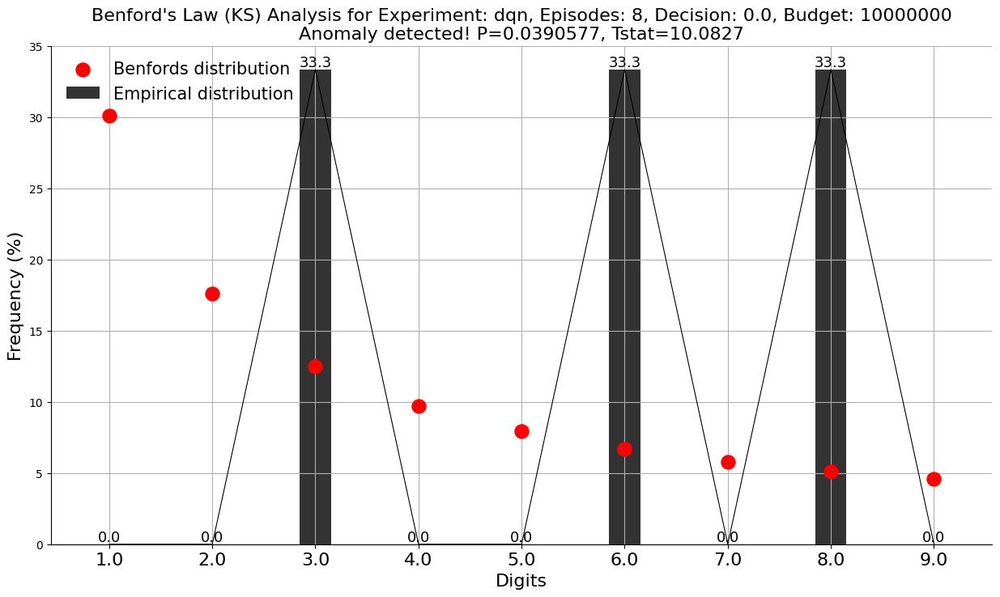

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep8_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0417726, Tstat=9.92141


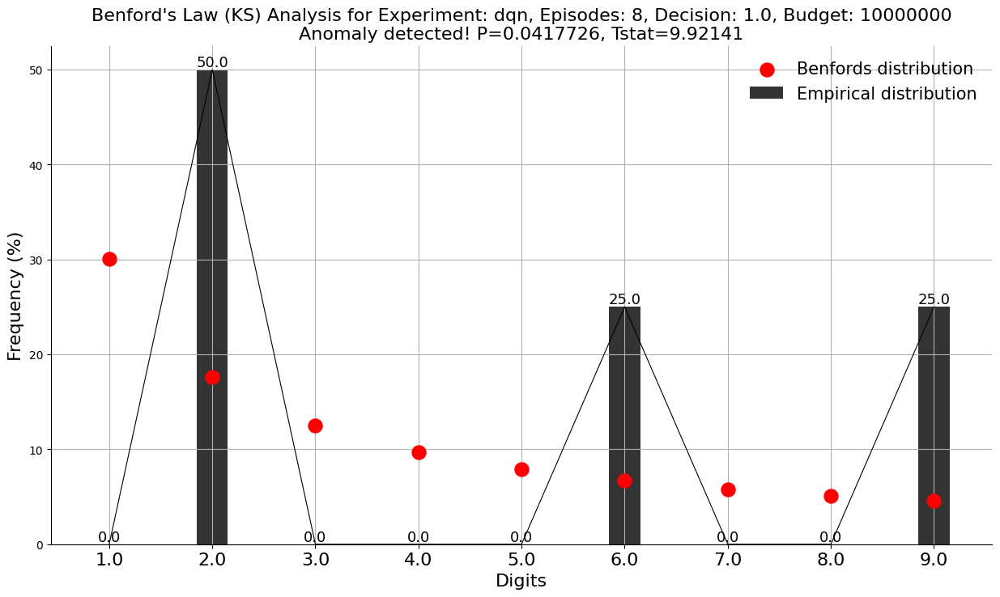

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep8_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00591466, Tstat=14.4785


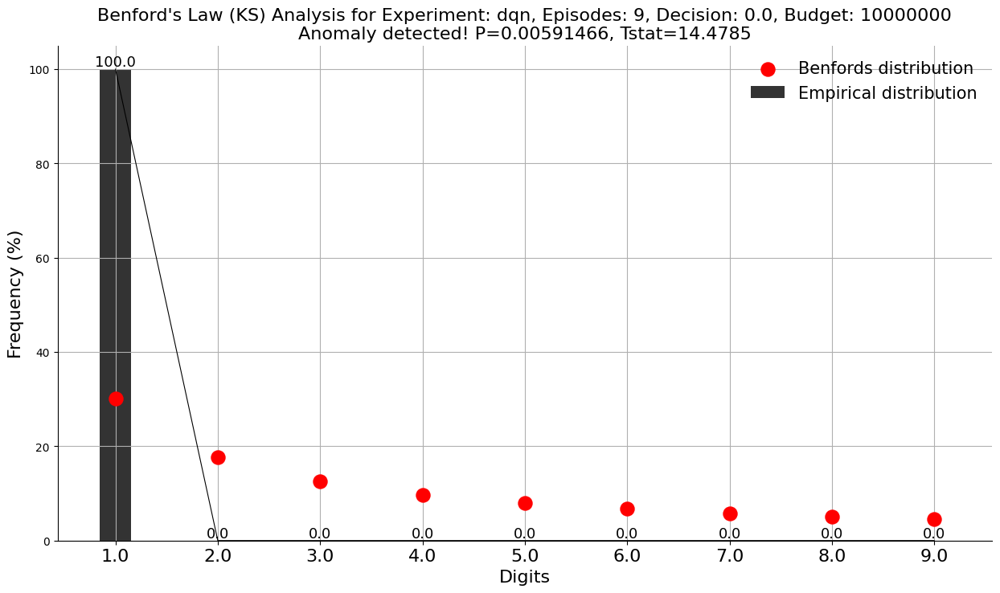

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep9_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00591466, Tstat=14.4785


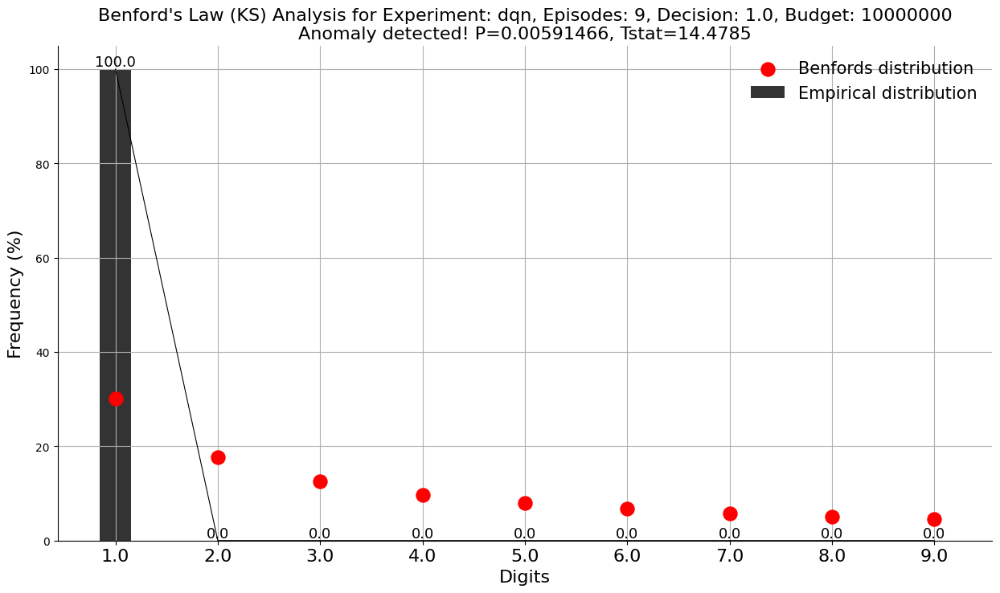

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_dqn_ep9_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


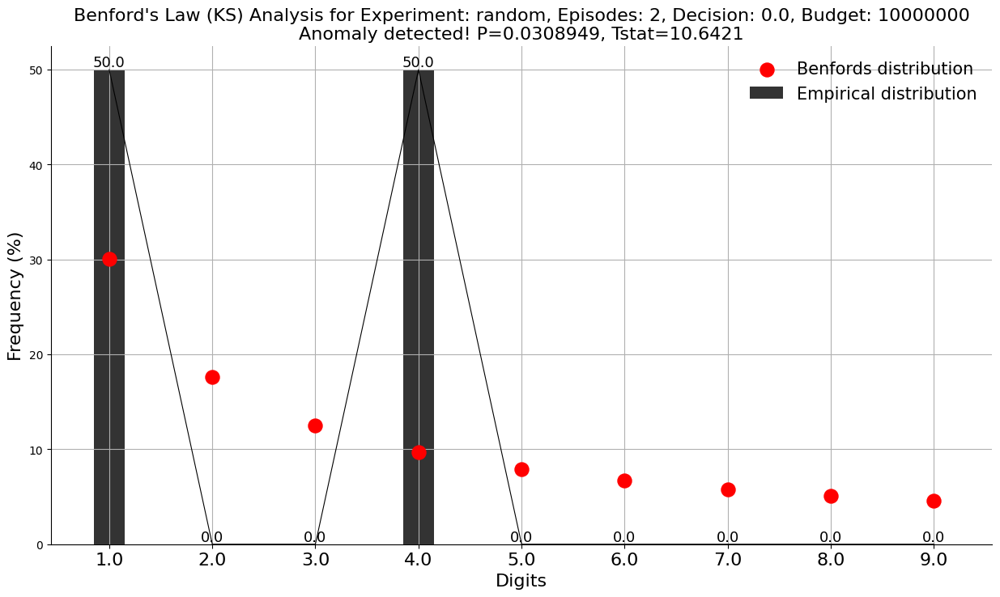

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep2_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0177328, Tstat=11.9492


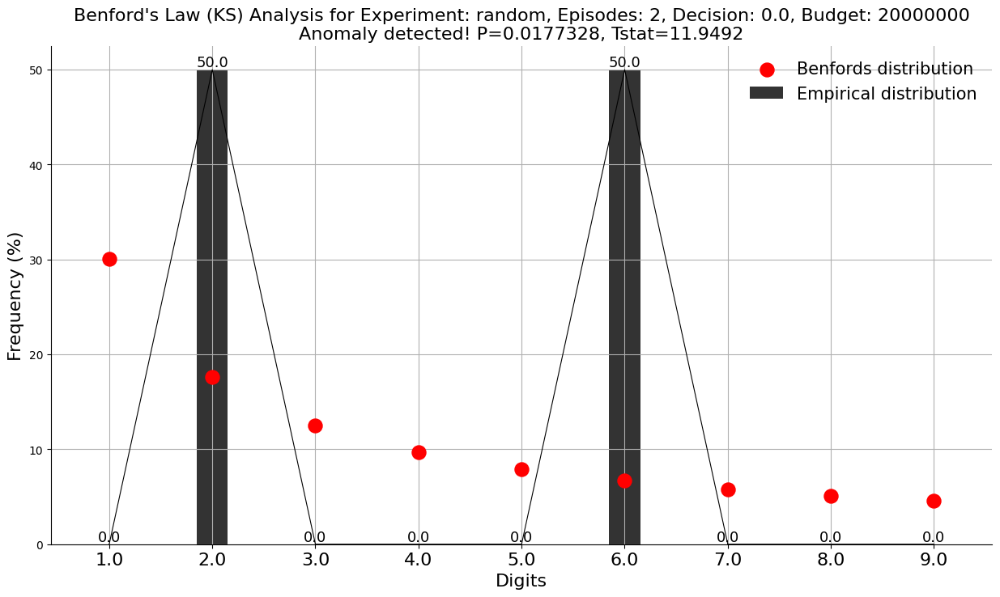

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep2_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.19828, Tstat=6.01165


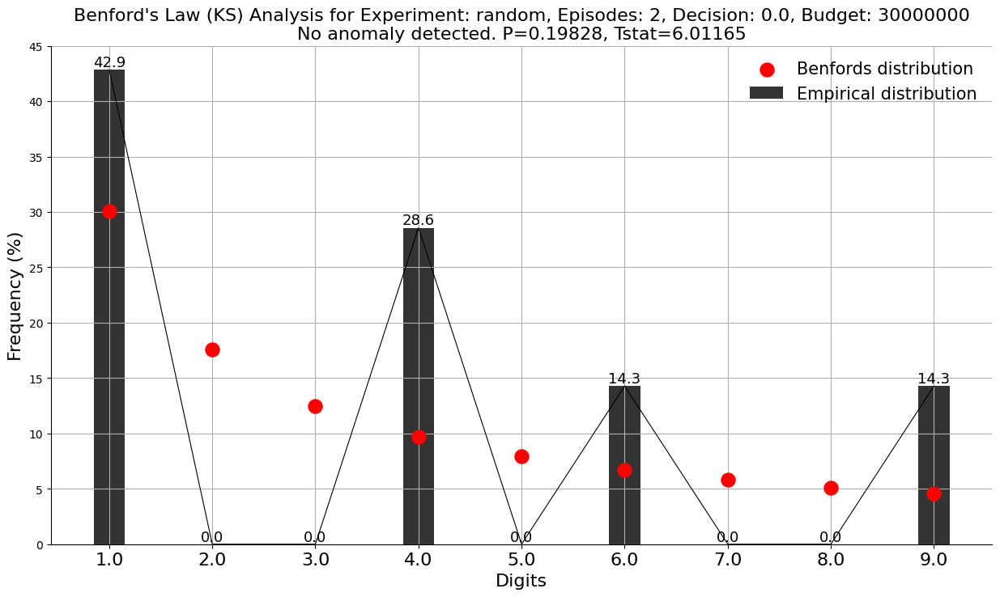

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep2_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.575748, Tstat=2.89383


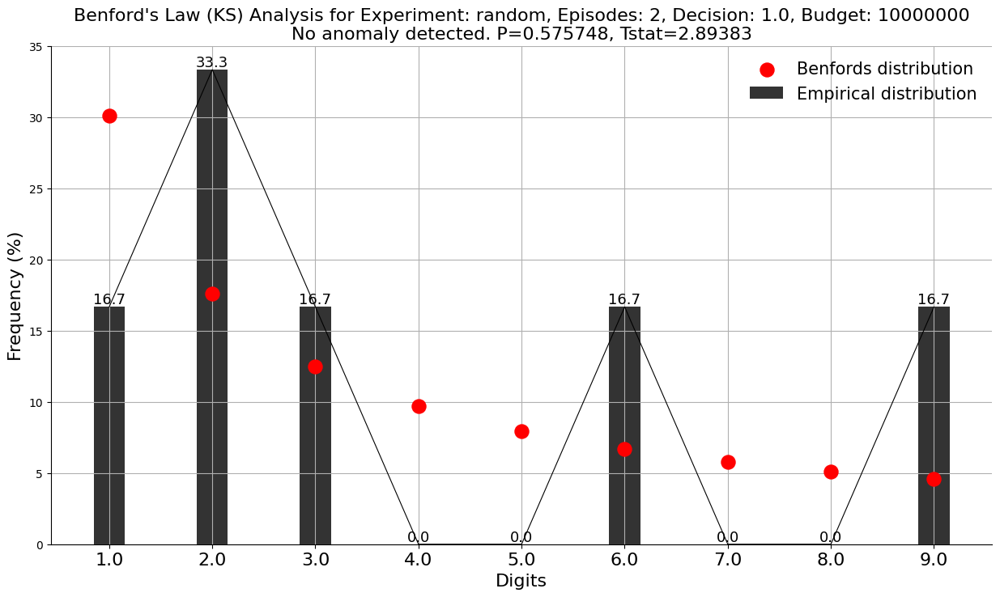

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep2_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0332745, Tstat=10.4656


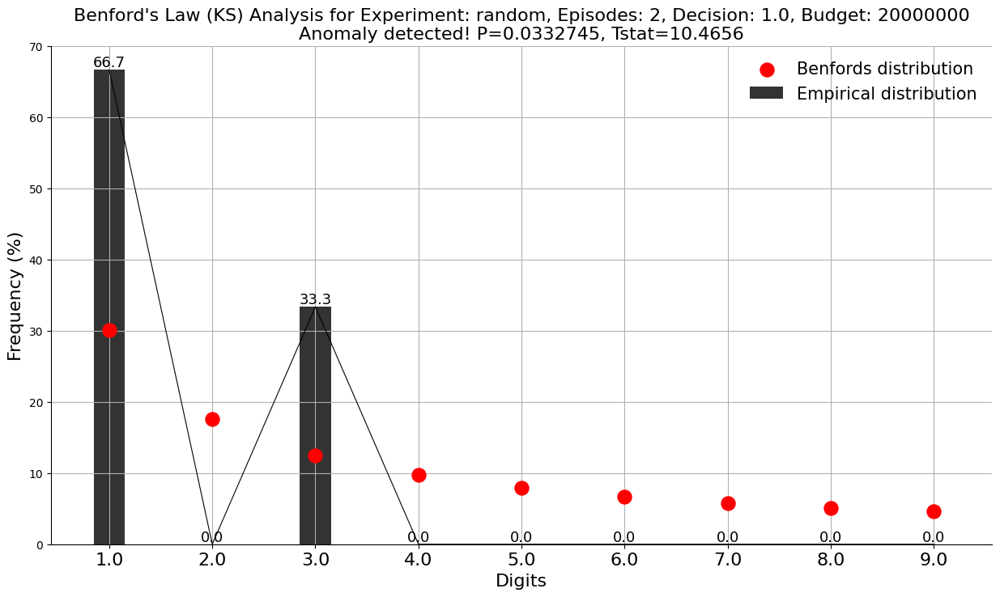

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep2_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.533655, Tstat=3.14626


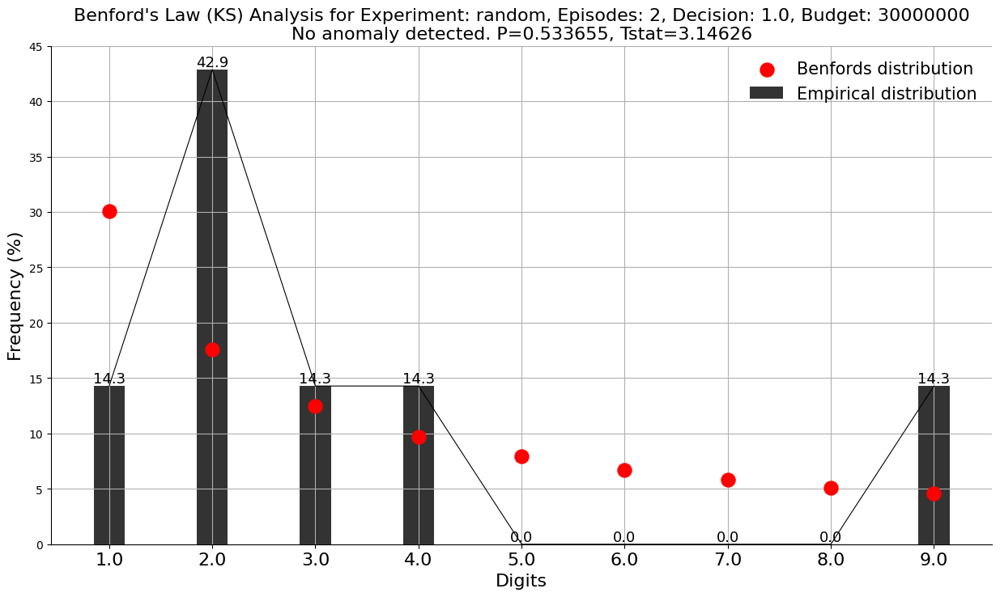

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep2_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.866127, Tstat=1.27189


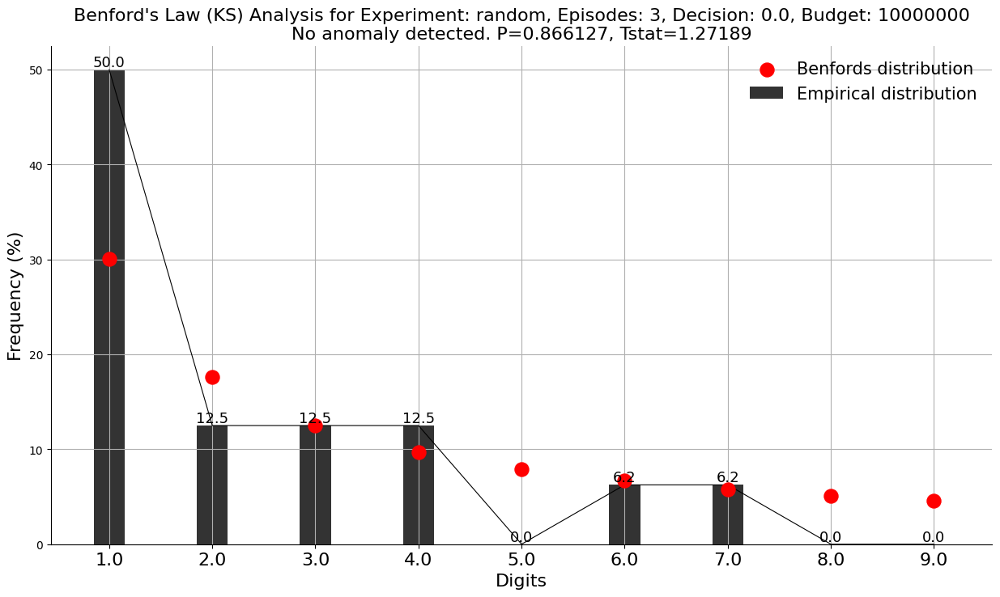

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep3_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


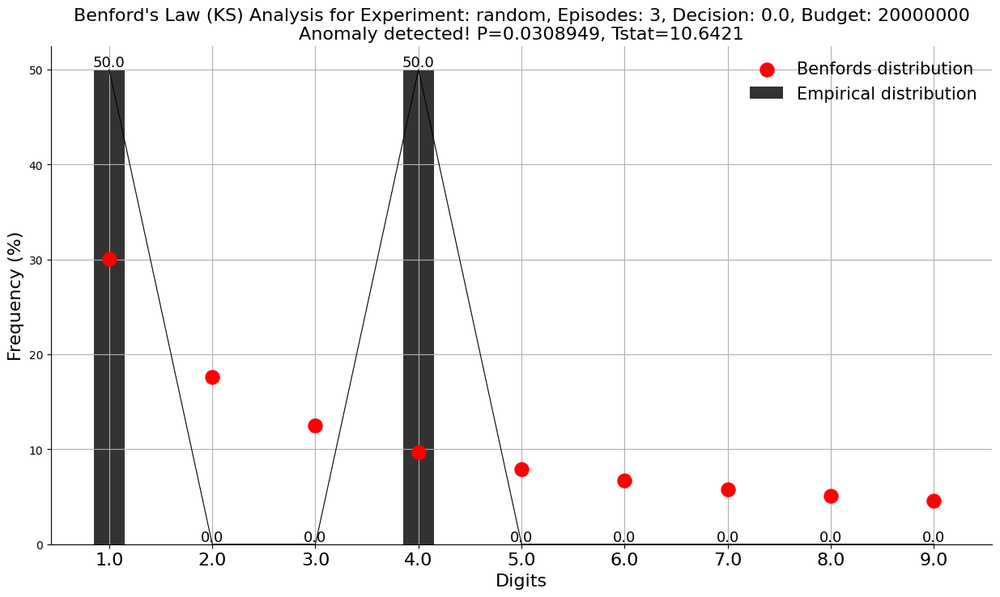

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep3_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.292509, Tstat=4.94959


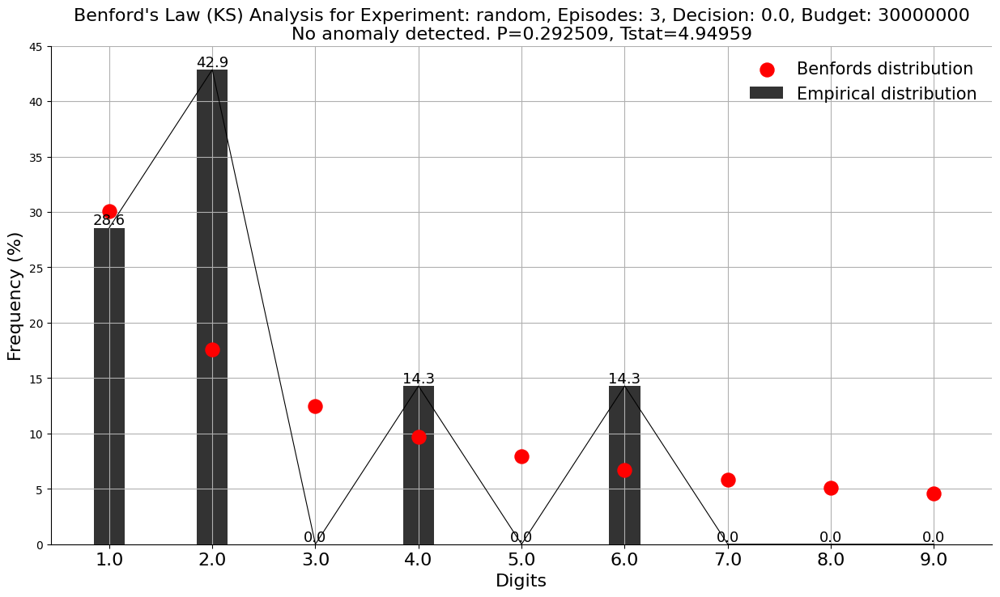

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep3_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.584483, Tstat=2.84271


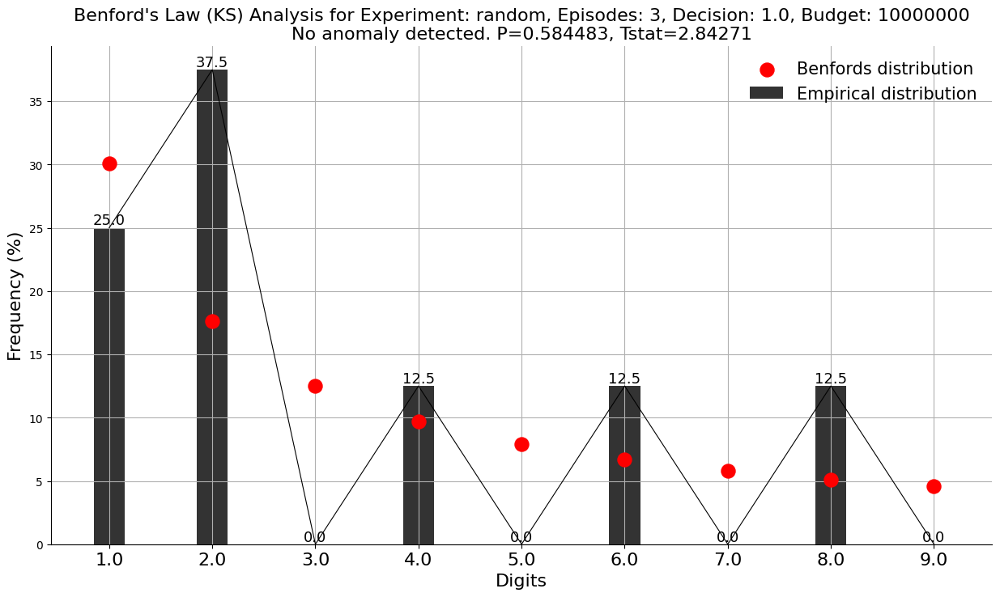

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep3_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0761977, Tstat=8.45712


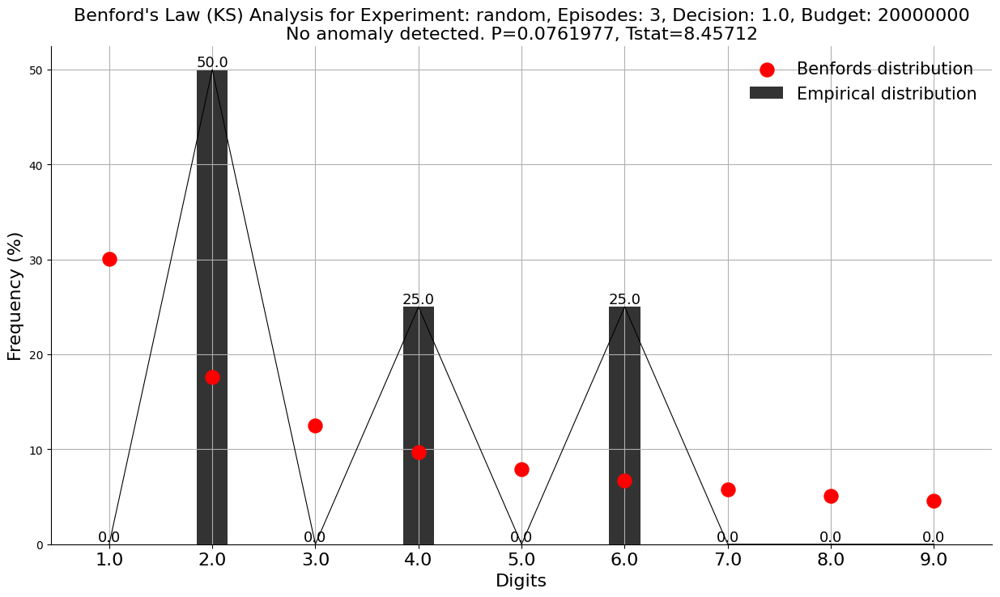

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep3_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.295479, Tstat=4.9212


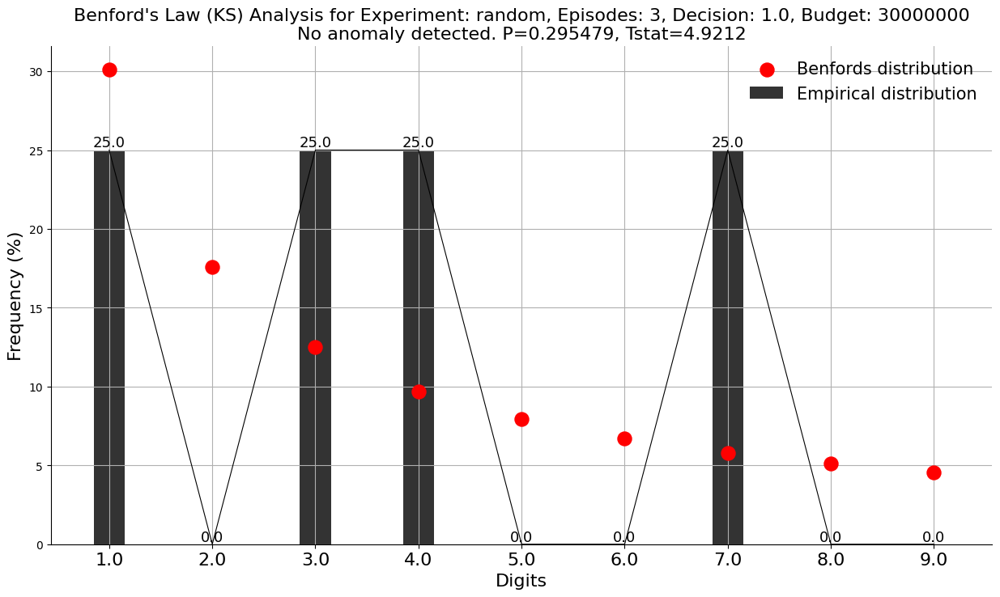

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep3_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00592606, Tstat=14.4741


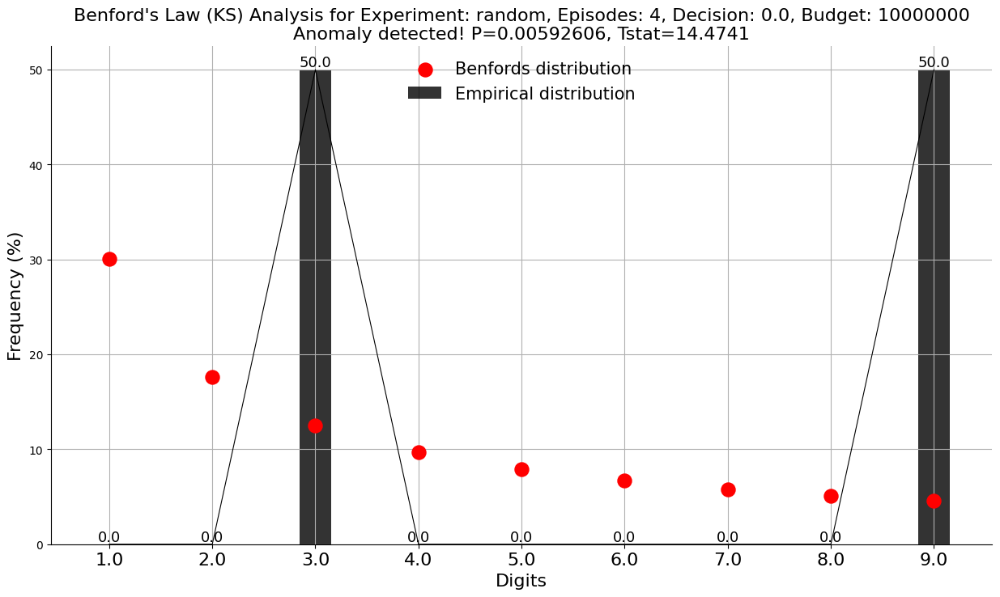

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep4_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.212204, Tstat=5.83006


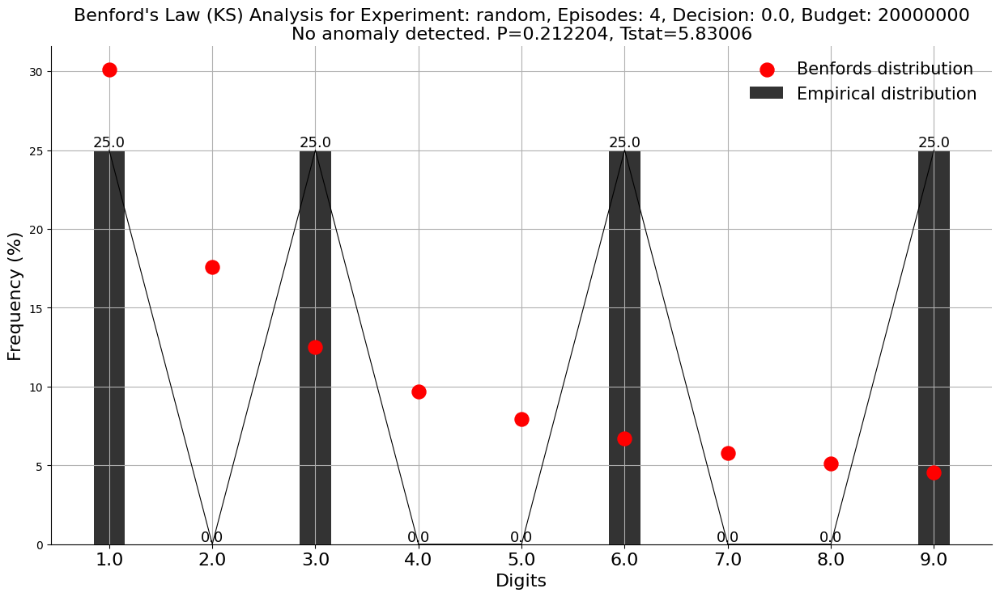

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep4_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0653749, Tstat=8.83439


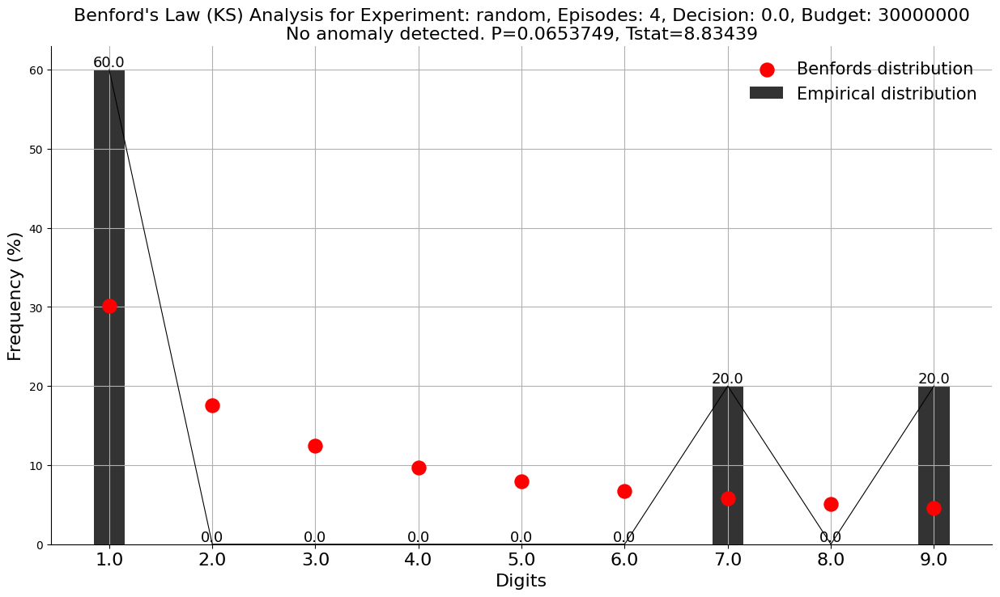

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep4_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.101392, Tstat=7.74466


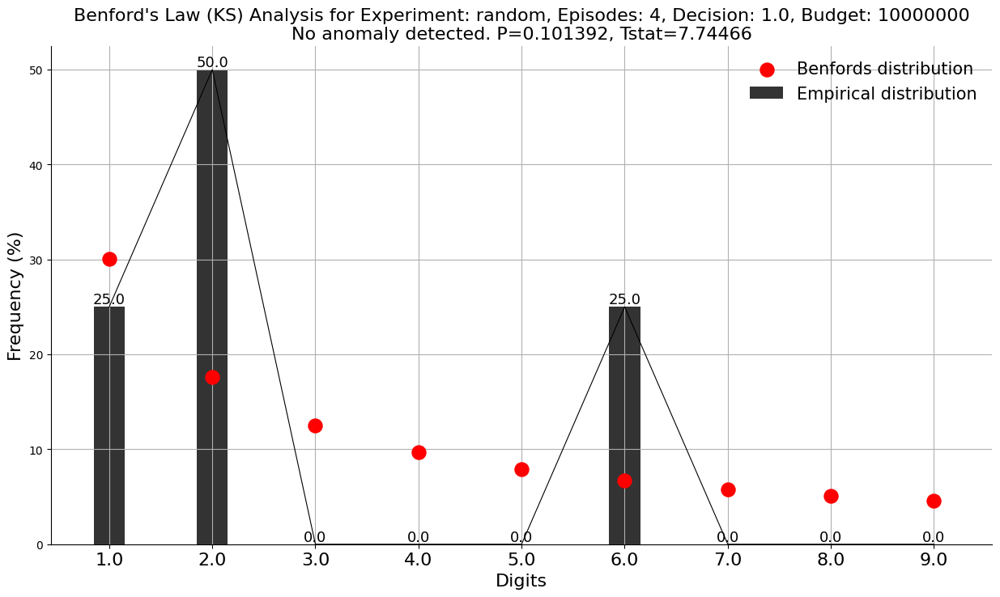

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep4_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.257011, Tstat=5.30926


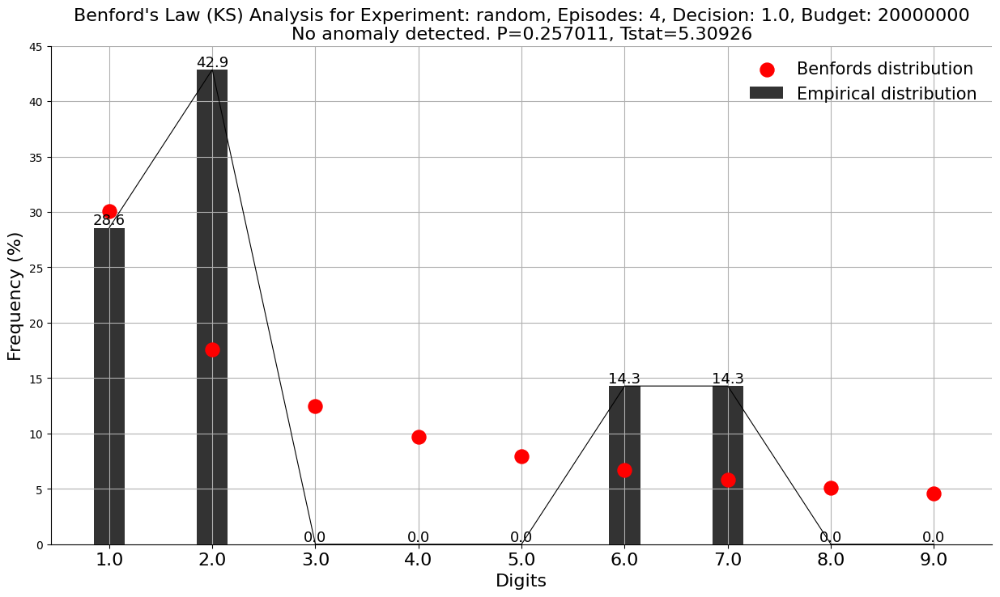

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep4_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.133516, Tstat=7.04525


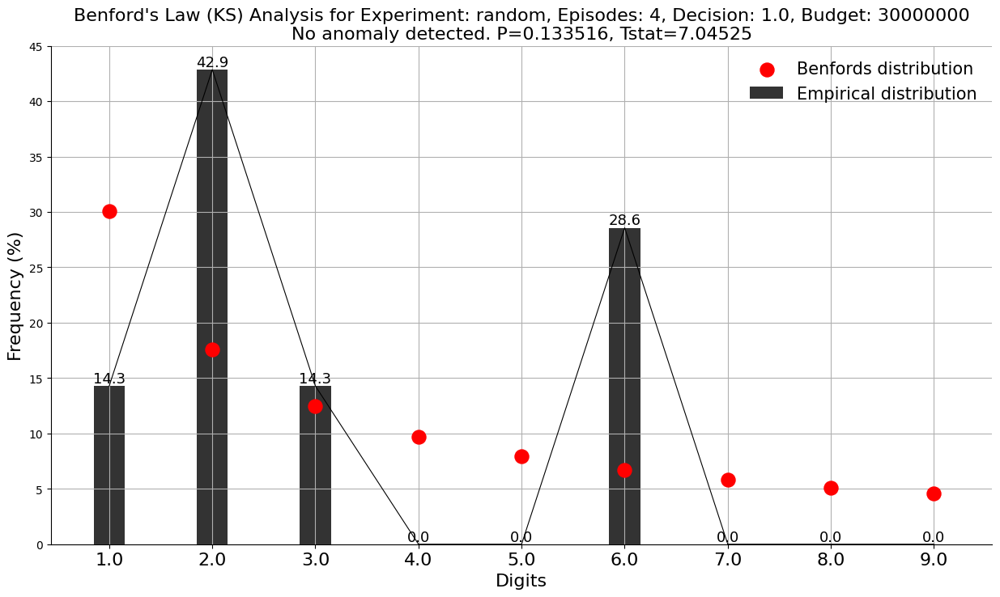

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep4_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00219082, Tstat=16.7198


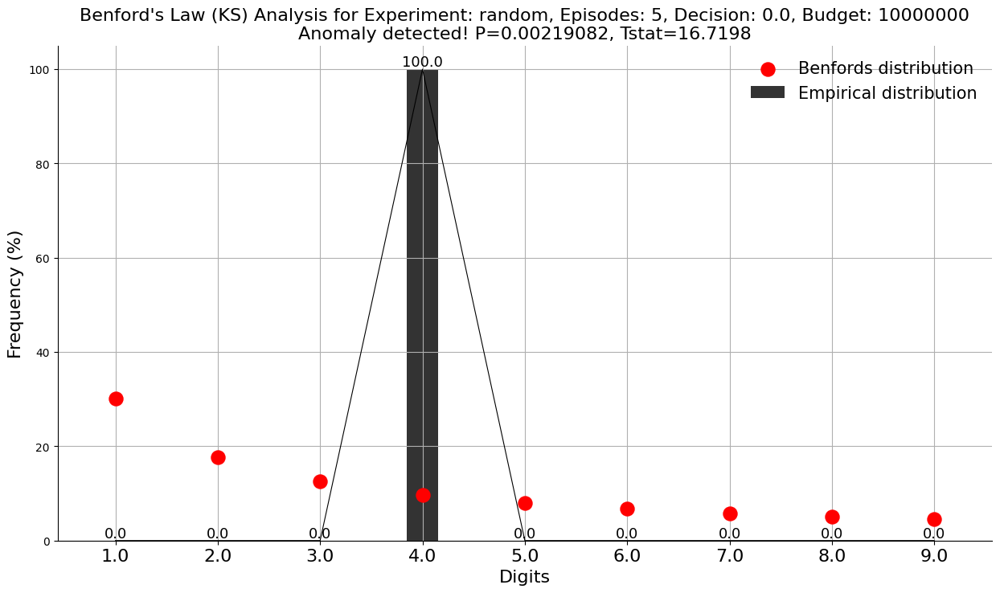

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep5_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00430483, Tstat=15.1995


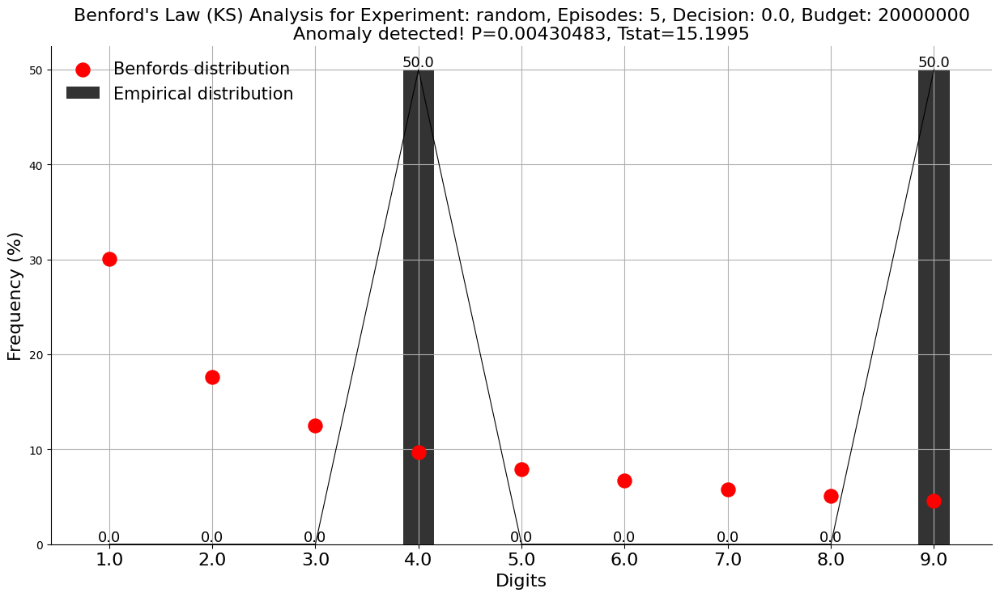

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep5_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00353024, Tstat=15.6477


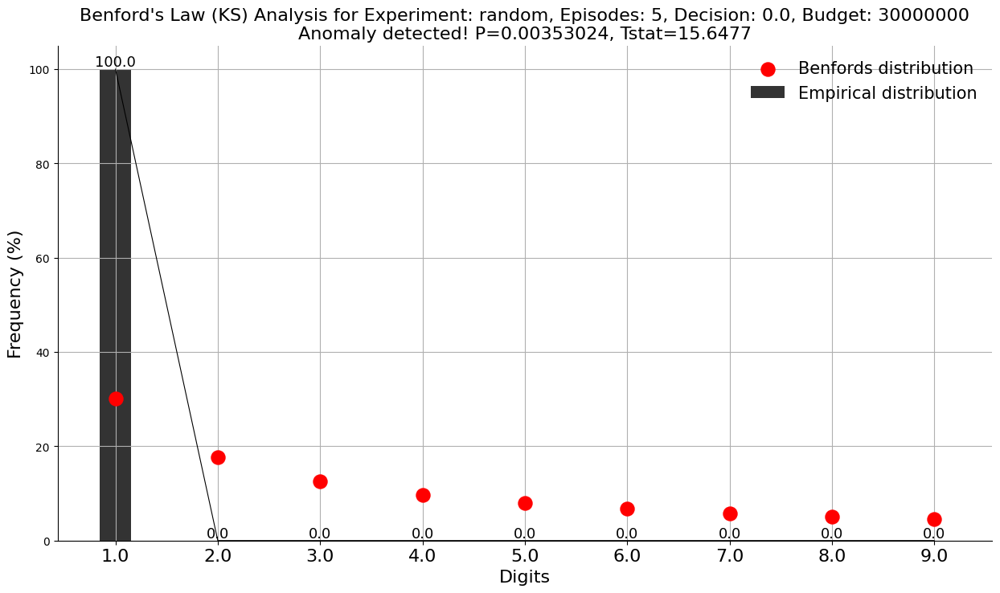

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep5_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0155856, Tstat=12.25


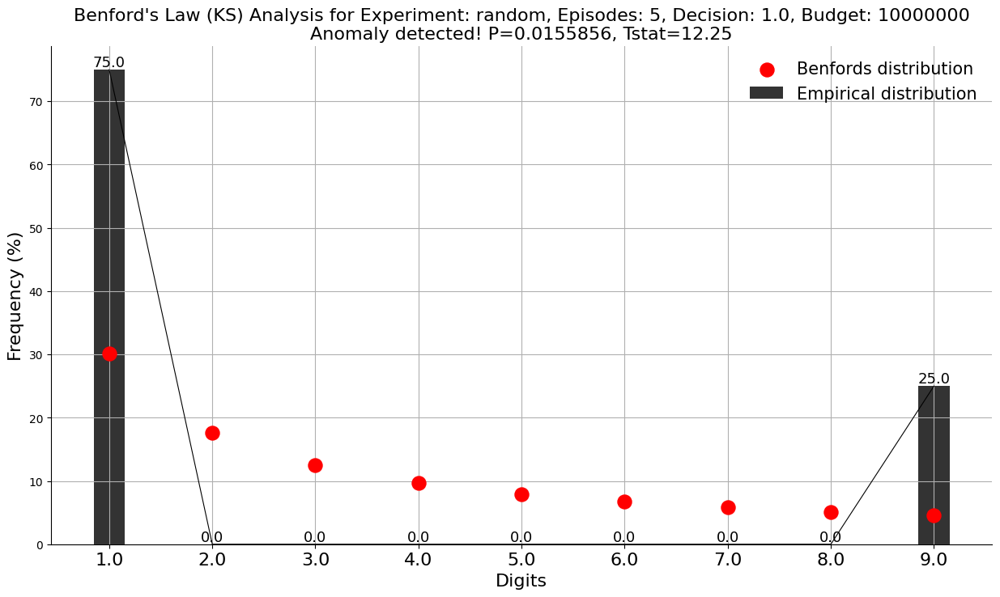

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep5_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00353024, Tstat=15.6477


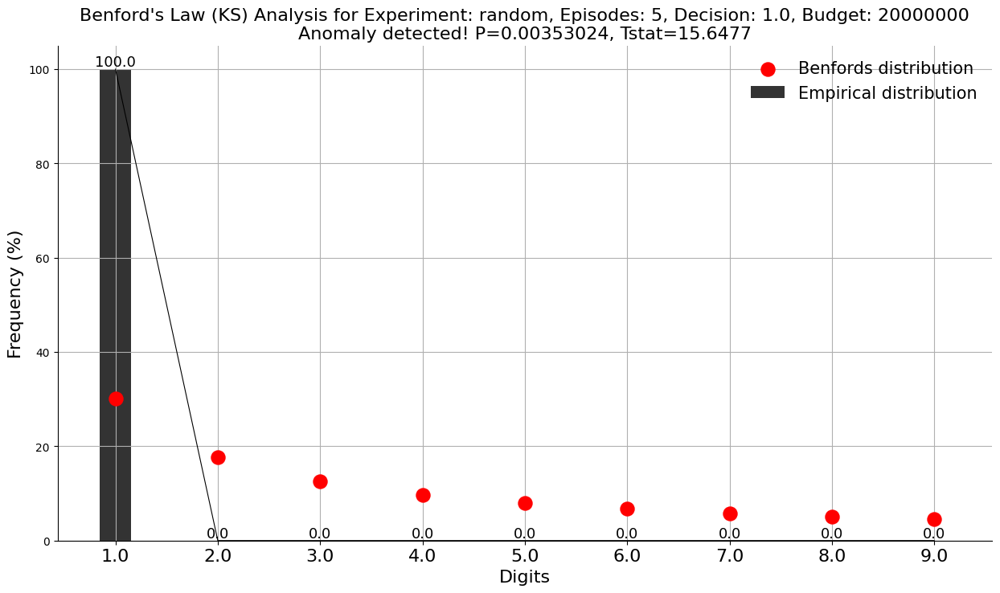

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep5_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.929371, Tstat=0.866112


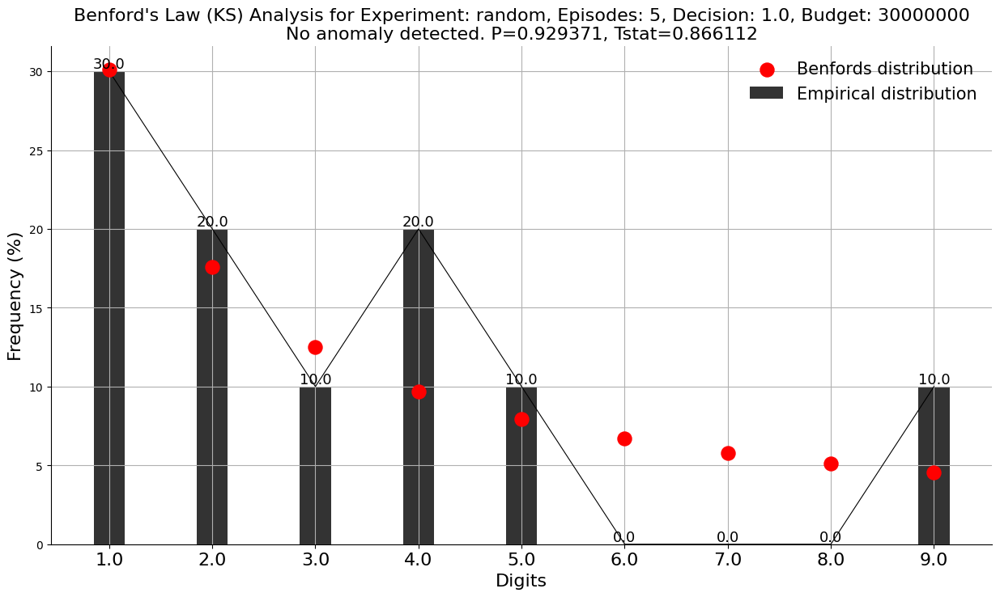

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep5_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.196862, Tstat=6.03077


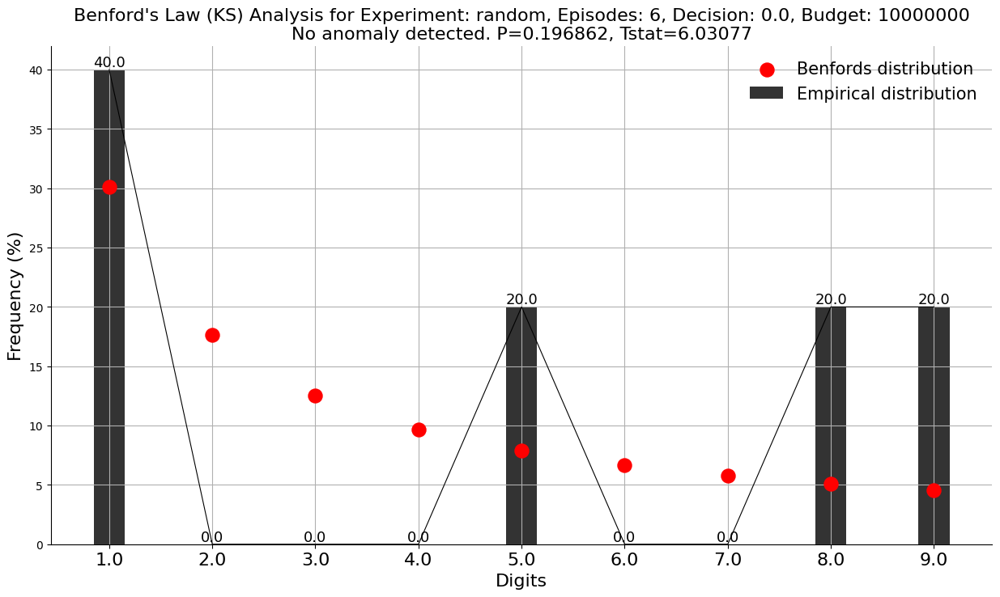

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep6_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.021819, Tstat=11.4636


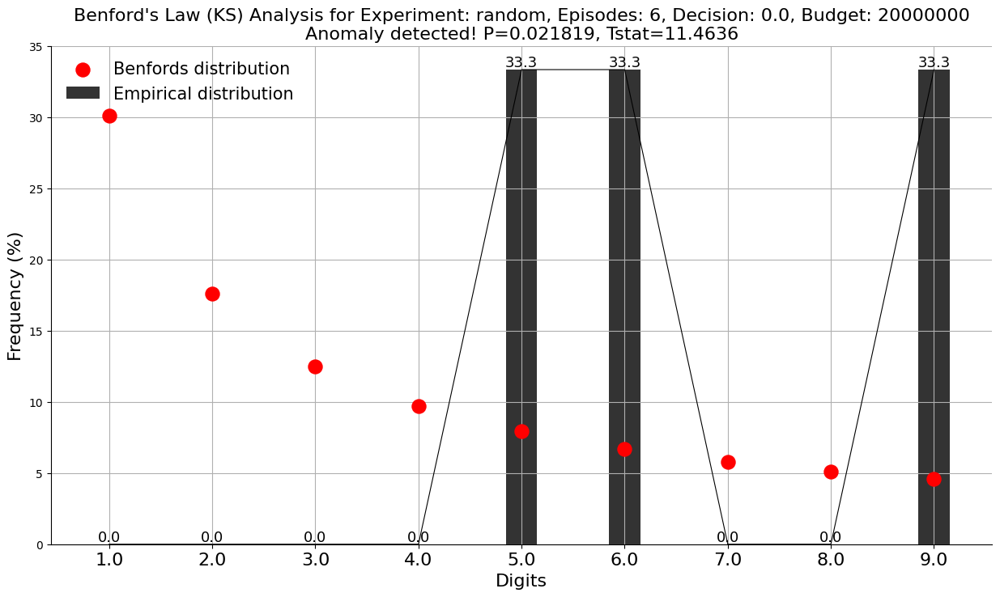

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep6_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0163853, Tstat=12.1336


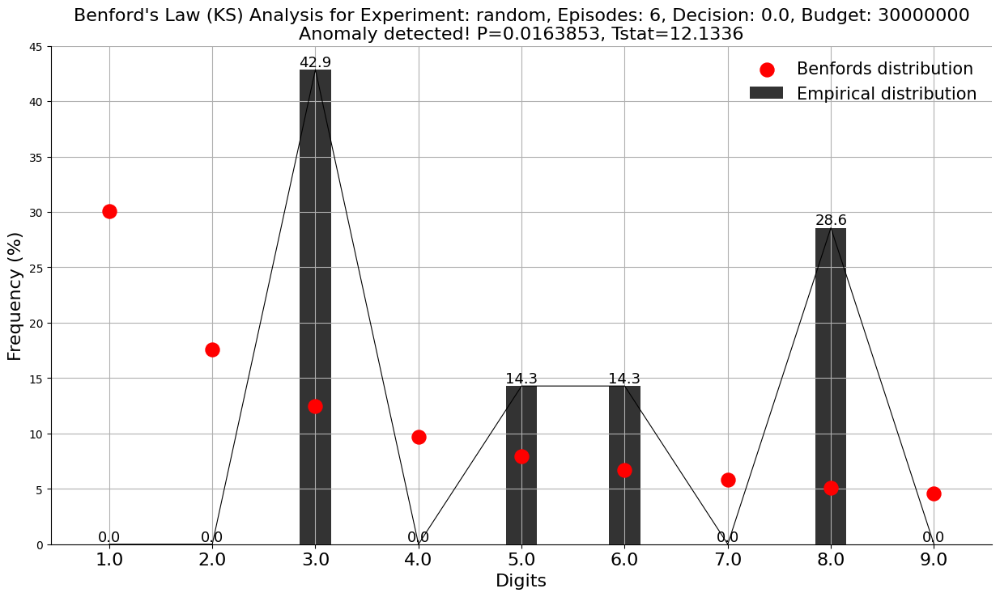

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep6_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00638448, Tstat=14.3043


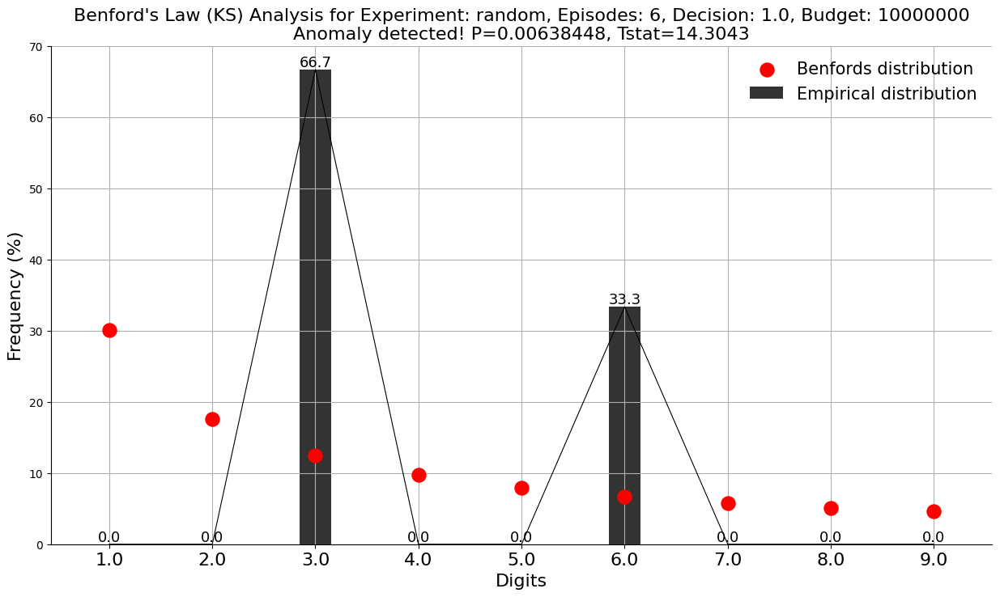

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep6_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0140021, Tstat=12.499


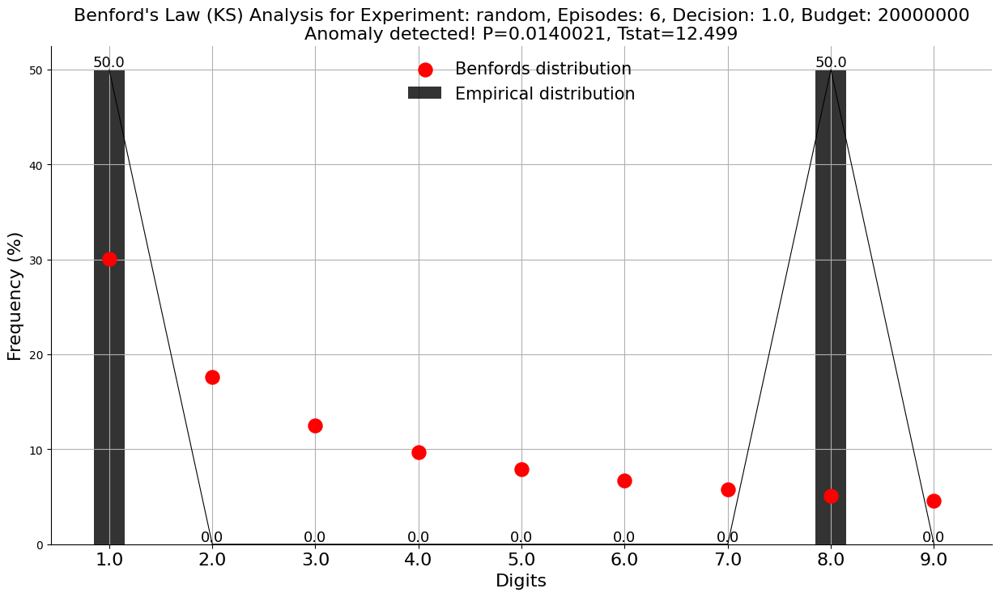

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep6_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.10195, Tstat=7.73085


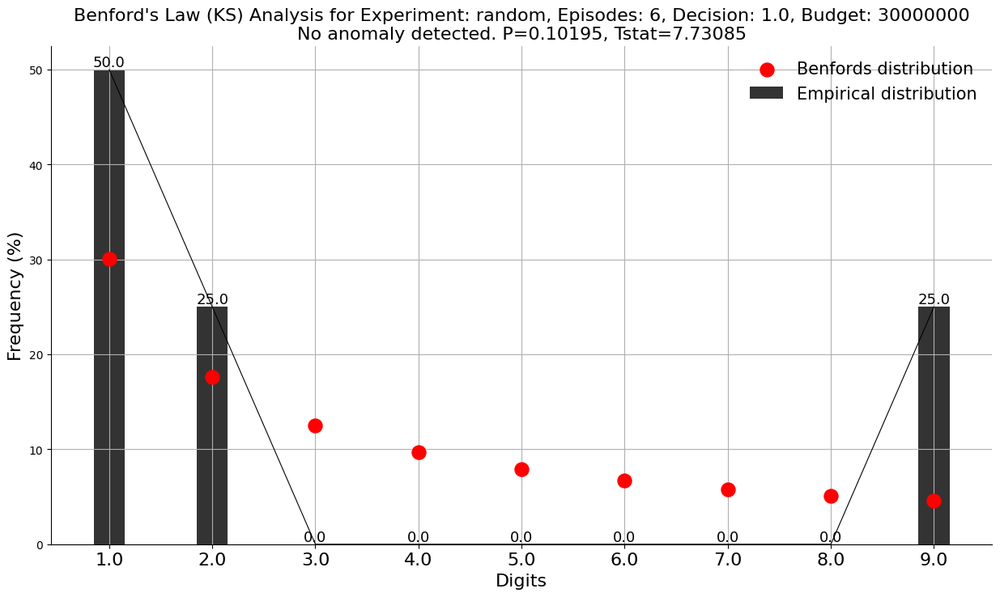

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep6_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0386294, Tstat=10.1091


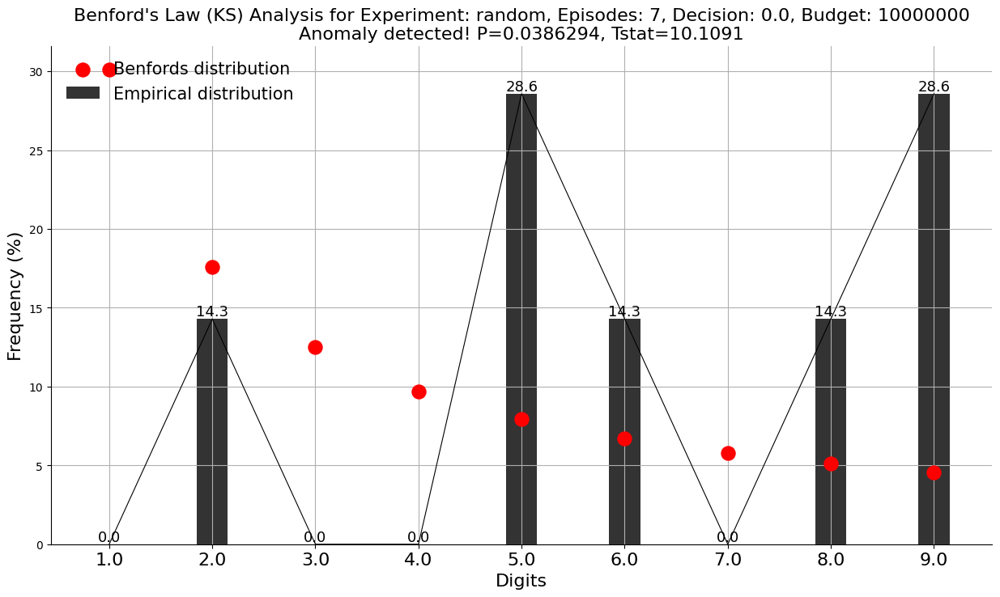

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep7_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0175504, Tstat=11.9734


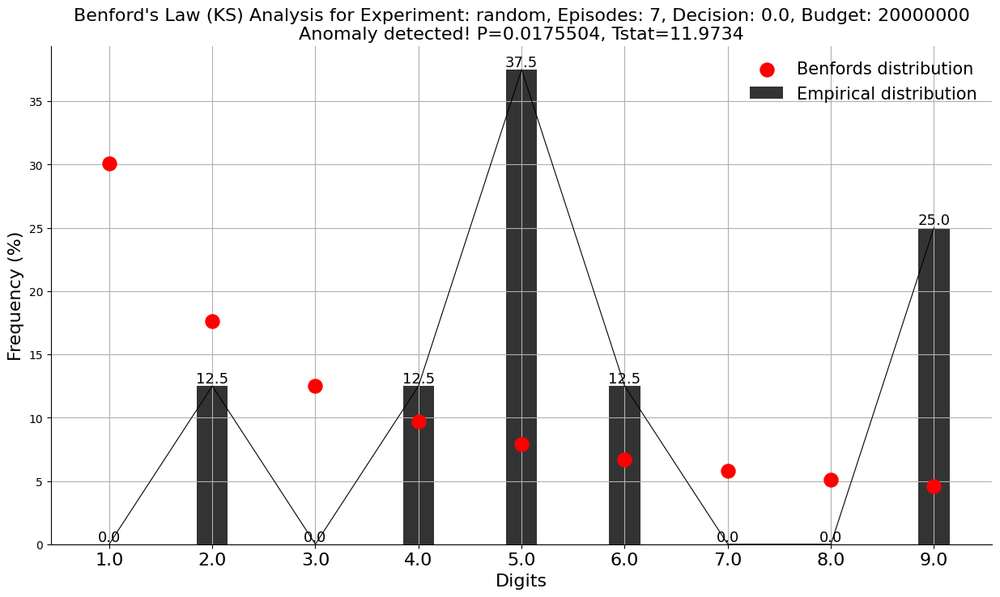

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep7_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.315575, Tstat=4.73508


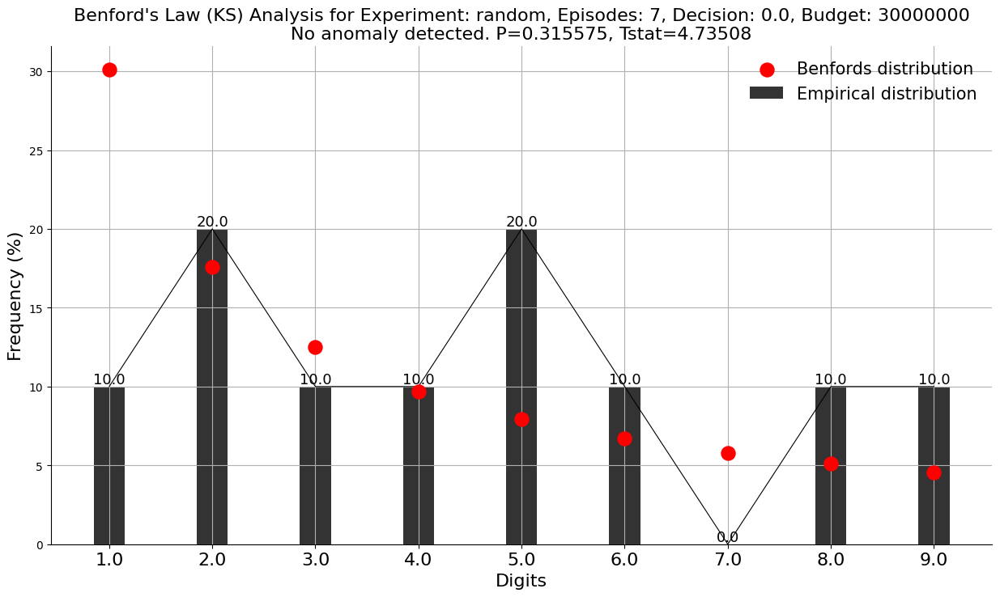

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep7_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0388277, Tstat=10.0968


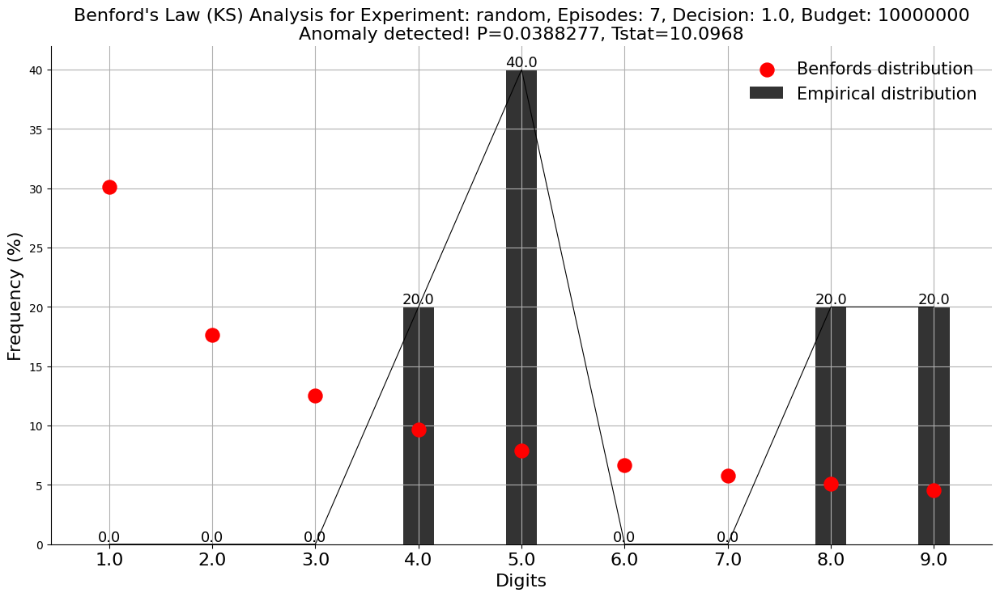

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep7_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.000759068, Tstat=19.0769


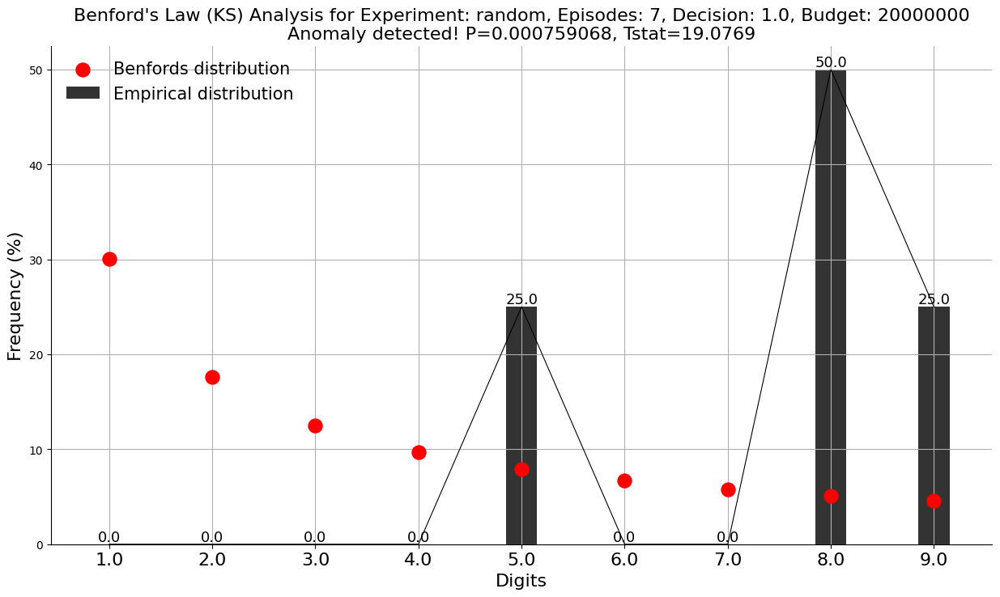

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep7_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0159616, Tstat=12.1946


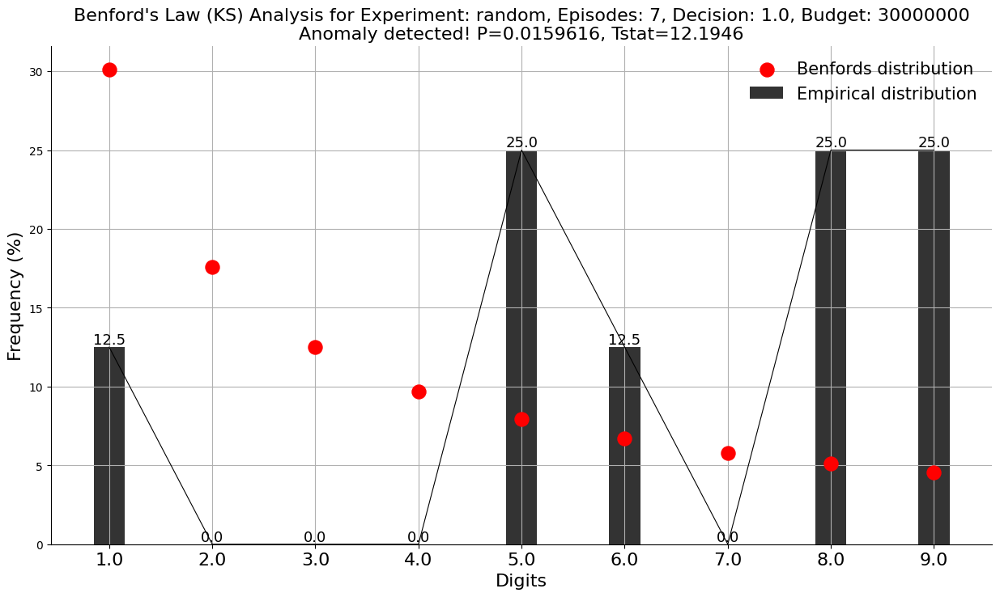

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep7_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0299526, Tstat=10.7157


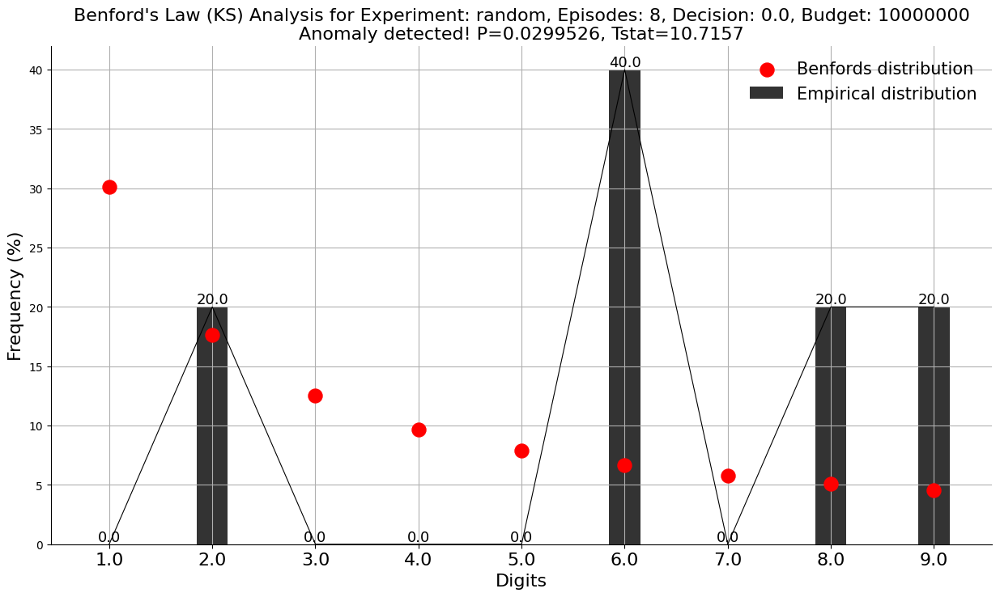

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep8_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.381597, Tstat=4.18461


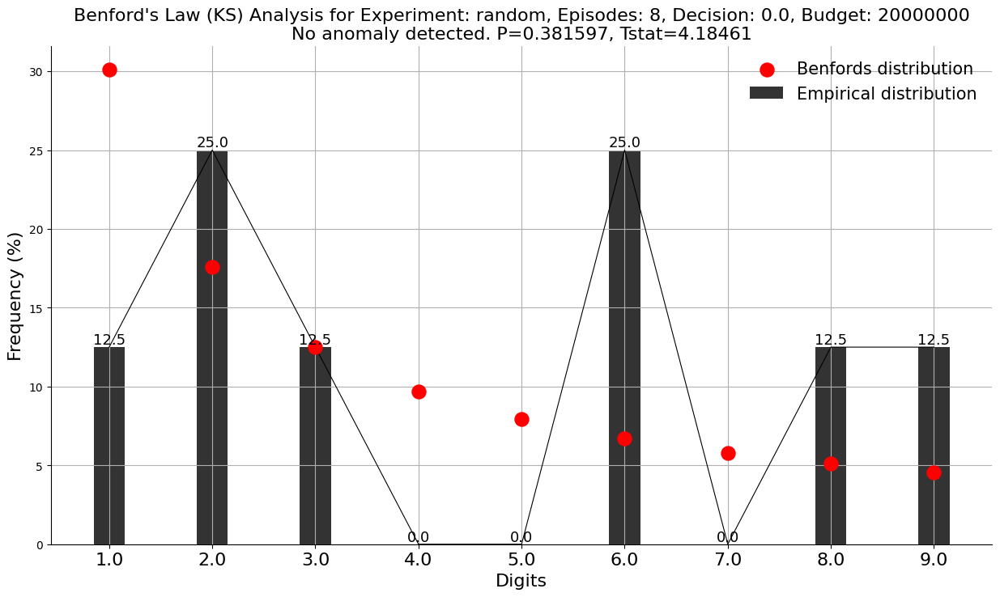

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep8_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00484497, Tstat=14.9317


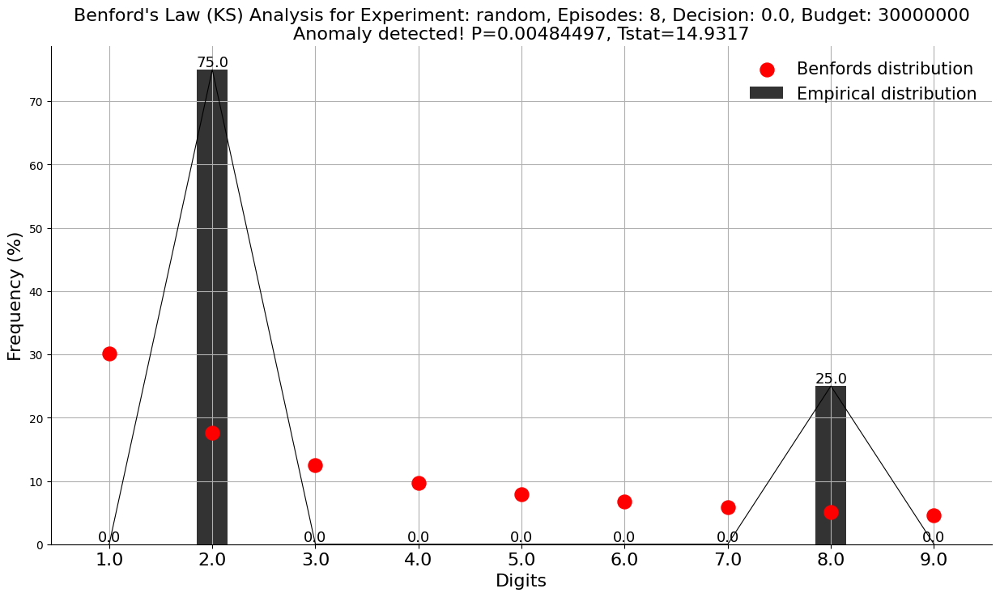

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep8_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.125009, Tstat=7.21386


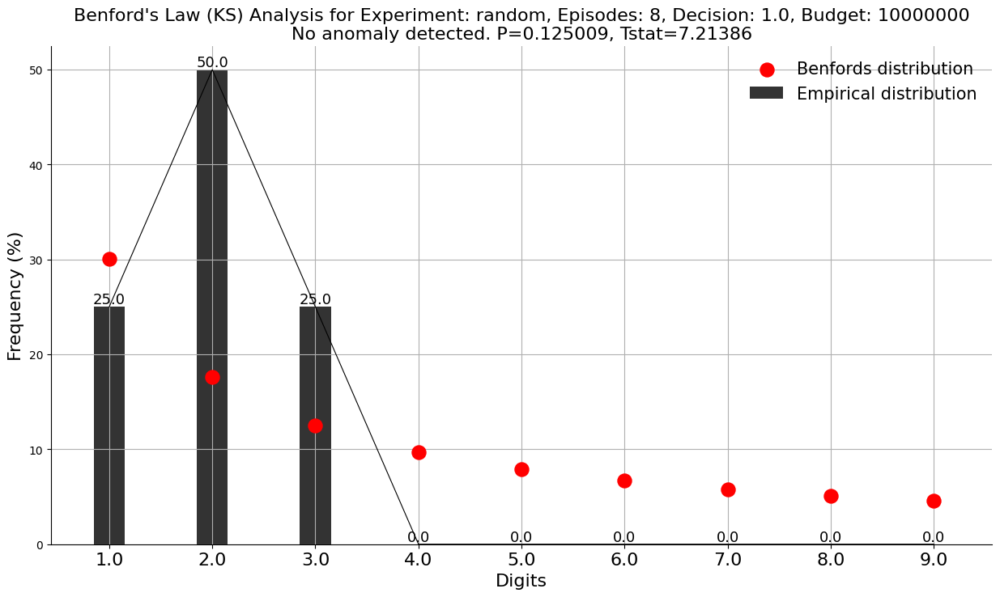

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep8_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0625288, Tstat=8.94344


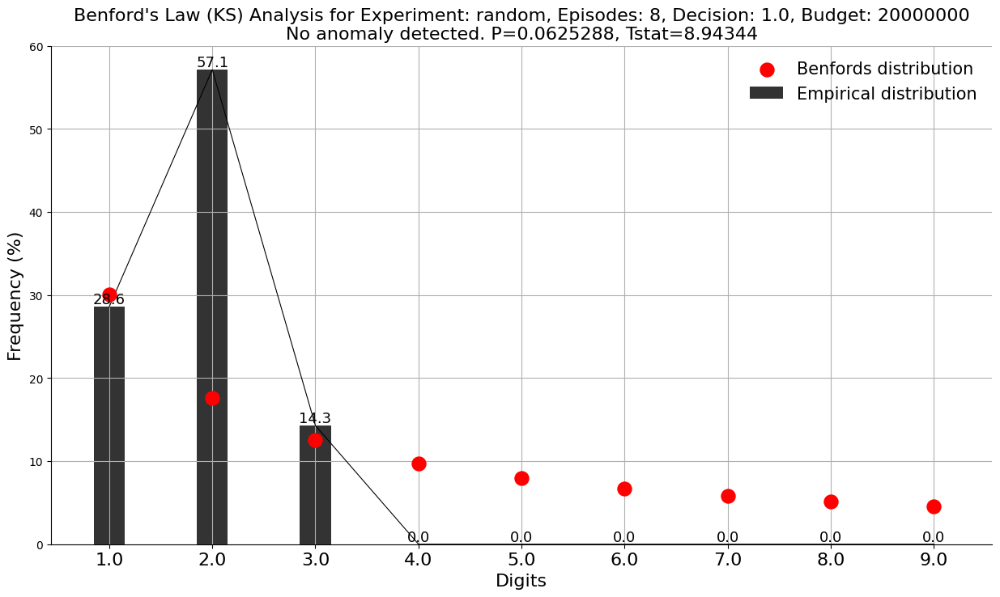

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep8_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0638947, Tstat=8.89053


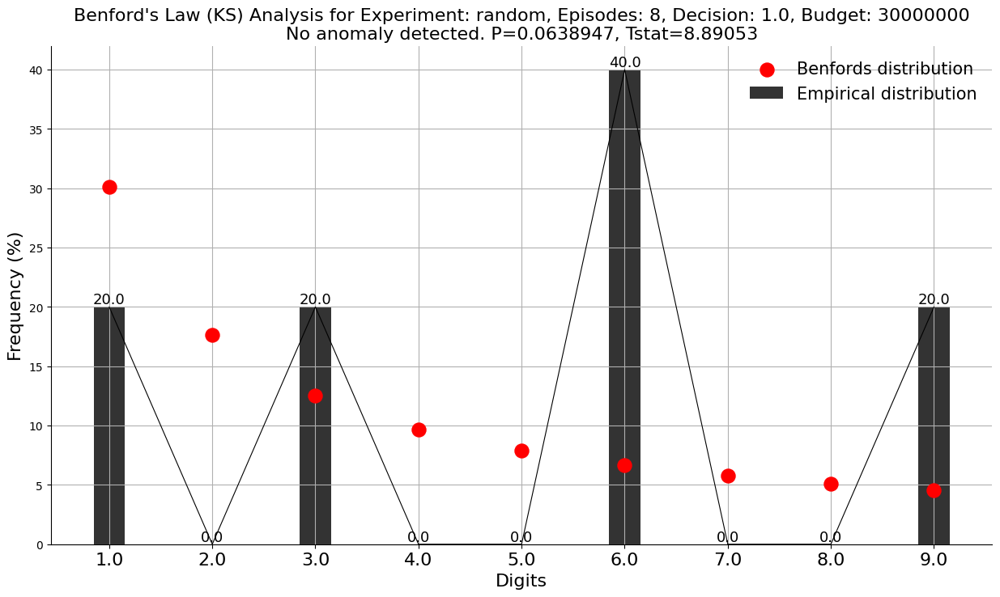

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep8_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.276429, Tstat=5.10765


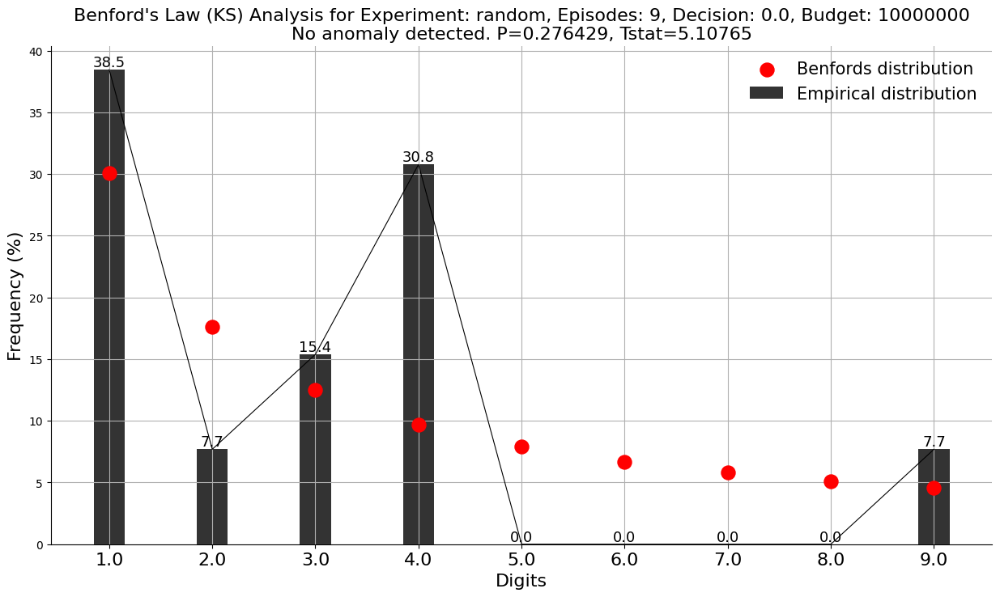

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep9_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0797203, Tstat=8.34522


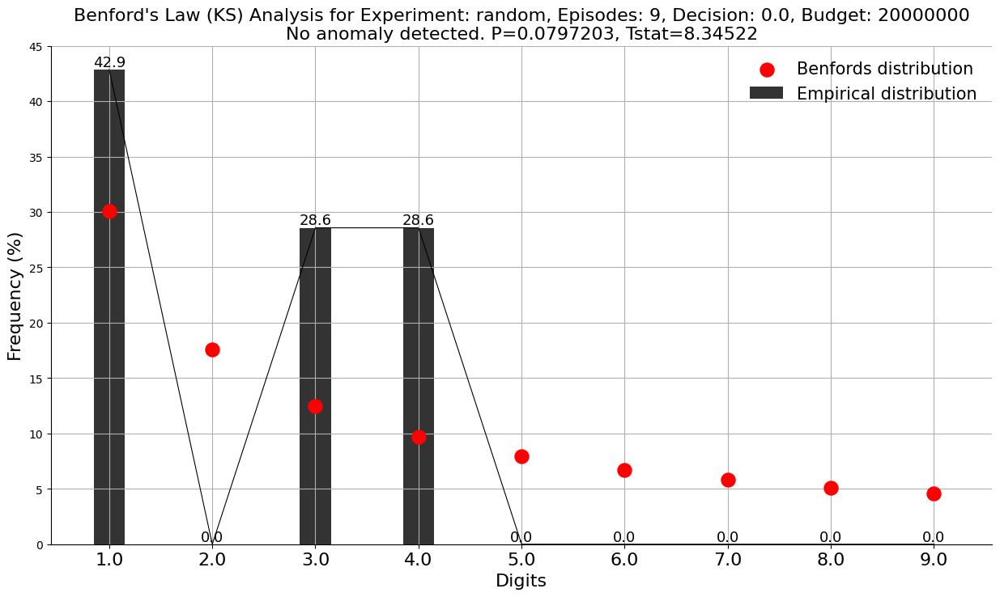

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep9_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.359999, Tstat=4.35573


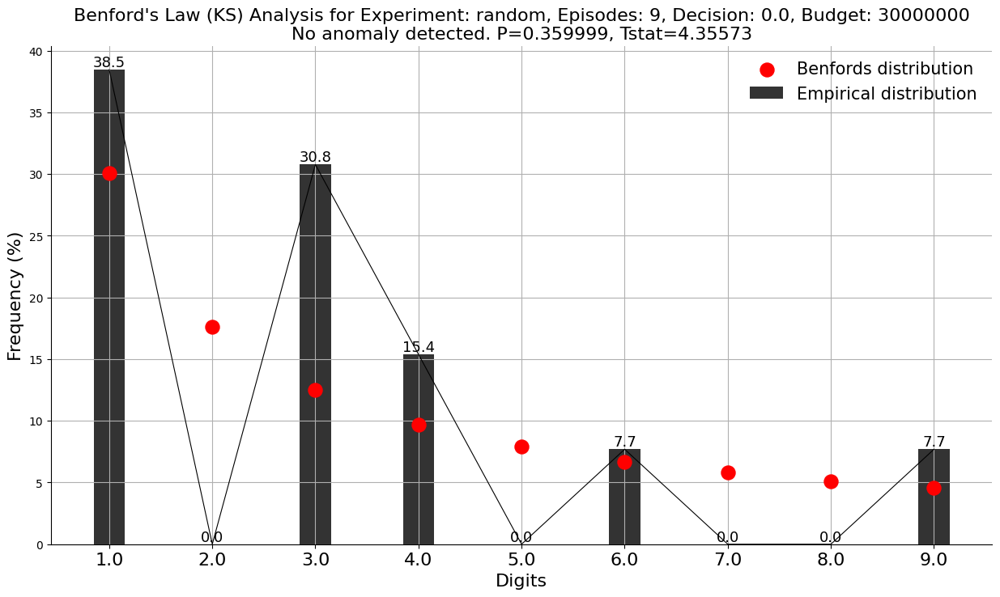

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep9_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.331621, Tstat=4.59335


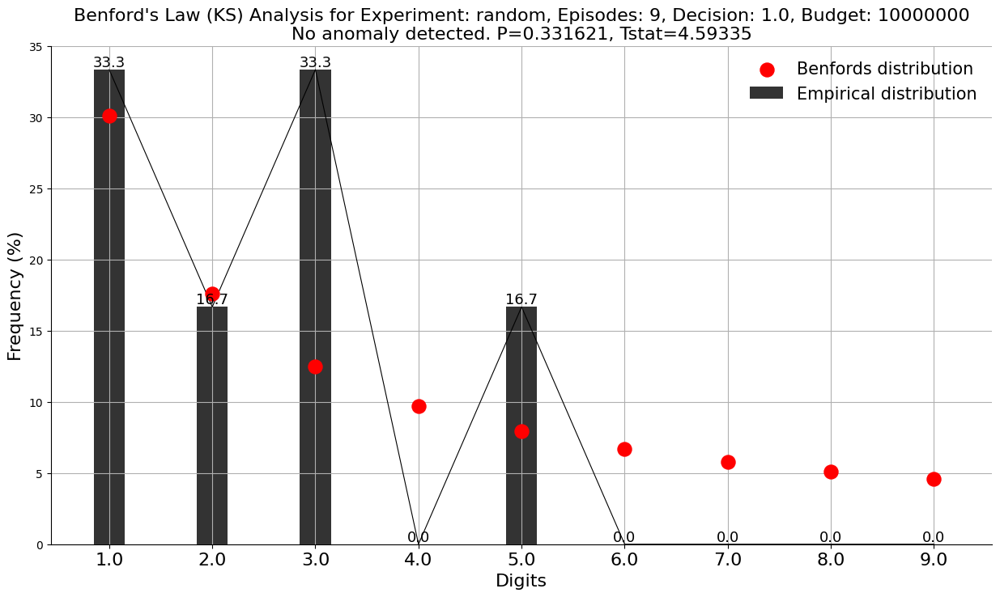

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep9_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.093476, Tstat=7.94869


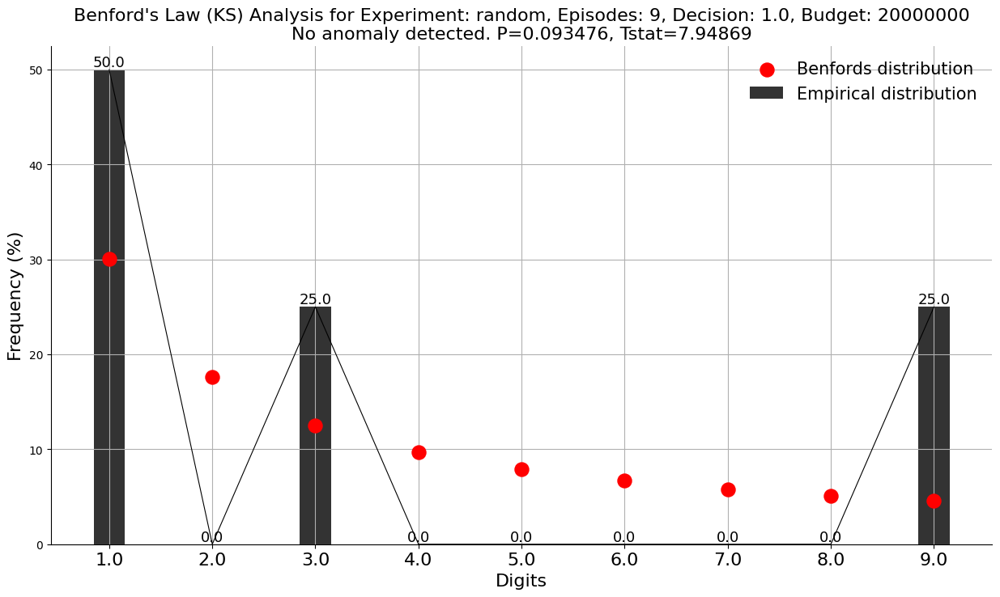

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep9_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.291242, Tstat=4.96177


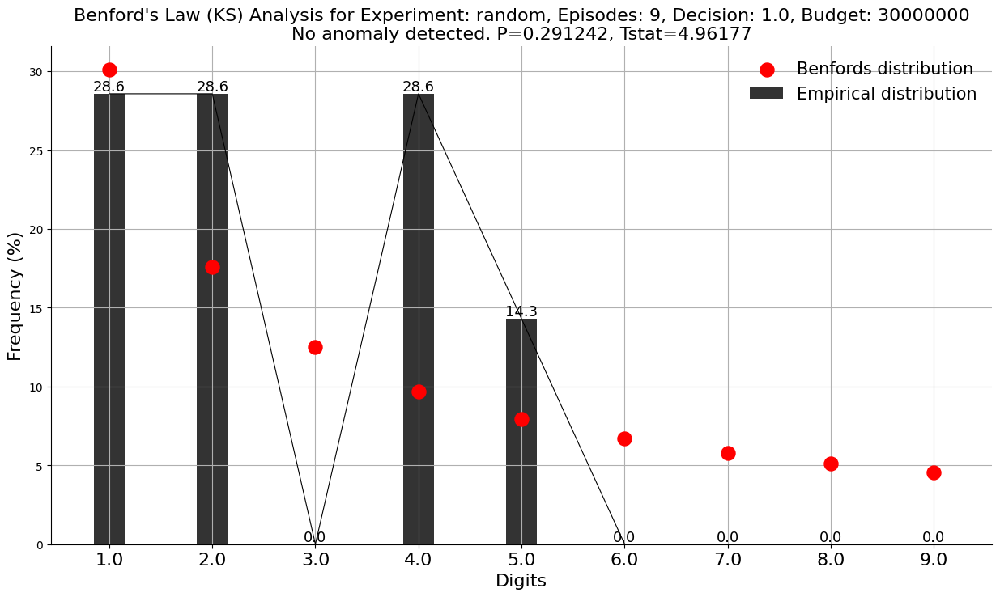

Plot saved to: .temp/data/experiment_results/insurenv/benford_plot_random_ep9_dec1.0_budget30000000.png
Summary results saved to: .temp/data/experiment_results/insurenv/benford_summary_results.csv
Final random plot saved to: .temp/data/experiment_results/insurenv/final_benford_random_plot.png
Final dqn plot saved to: .temp/data/experiment_results/insurenv/final_benford_dqn_plot.png


In [50]:
import os
import pandas as pd
from benfordslaw import benfordslaw

# Create a directory to store the results if it doesn't exist
results_dir = ".temp/data/experiment_results/insurenv"
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

# Initialize the Benford's Law analyzer with method='ks' for Kolmogorov-Smirnov test
bl = benfordslaw(method='freedman')

# Assuming your dataset is loaded into a DataFrame called 'data'
# The dataset includes columns: experiment, episodes, rewards, wc, woc, valor_indenizacao, initial_budget, decision

# Filter for "random" and "dqn" experiments
experiments_of_interest = ['random', 'dqn']
filtered_data = data[data['experiment'].isin(experiments_of_interest)]

# Group the data by experiment, episodes, decision, and initial_budget
groups = filtered_data.groupby(['experiment', "episodes", 'decision', 'initial_budget'])

# Prepare a list to store summary results
summary_results = []

# Dictionary to store final figures
final_figures = {}

# Iterate over each group and apply Benford's Law analysis
for (experiment, episodes, decision, initial_budget), group in groups:
    valor_indenizacao = group['valor_indenizacao'].dropna().values
    
    if len(valor_indenizacao) == 0:
        print(f"No indemnity values available for Experiment: {experiment}, Episodes: {episodes}, Decision: {decision}, Initial Budget: {initial_budget}")
        continue
    
    # Apply Benford's Law with Kolmogorov-Smirnov test to the valor_indenizacao values
    results = bl.fit(valor_indenizacao)
    
    # Generate plot and save it
    plot_title = f"Benford's Law (KS) Analysis for Experiment: {experiment}, Episodes: {episodes}, Decision: {decision}, Budget: {initial_budget}"
    fig, ax = bl.plot(title=plot_title)
    
    # Save the plot to the results directory
    plot_filename = f"{results_dir}/benford_plot_{experiment}_ep{episodes}_dec{decision}_budget{initial_budget}.png"
    fig.savefig(plot_filename)
    
    # Store figures for final random and dqn plot
    if experiment in final_figures:
        final_figures[experiment] = fig  # Capture only the last figure for each experiment
    else:
        final_figures[experiment] = fig
    
    print(f"Plot saved to: {plot_filename}")
    
    # Append KS results to the summary list
    summary_results.append({
        'experiment': experiment,
        'episodes': episodes,
        'decision': decision,
        'initial_budget': initial_budget,
        'KS_stat': results['t'],  # The test statistic for the KS test
        'p_value': results['P'],  # The p-value for the KS test
        'P_significant': results['P_significant'],  # whether it's significant
        'percentage_emp': results['percentage_emp']  # empirical distribution
    })

# Create a summary DataFrame
summary_df = pd.DataFrame(summary_results)

# Save the summary DataFrame to the results directory
summary_filename = f"{results_dir}/benford_summary_results.csv"
summary_df.to_csv(summary_filename, index=False)
print(f"Summary results saved to: {summary_filename}")

# Save final plots for "random" and "dqn"
if 'random' in final_figures:
    random_fig_filename = f"{results_dir}/final_benford_random_plot.png"
    final_figures['random'].savefig(random_fig_filename)
    print(f"Final random plot saved to: {random_fig_filename}")

if 'dqn' in final_figures:
    dqn_fig_filename = f"{results_dir}/final_benford_dqn_plot.png"
    final_figures['dqn'].savefig(dqn_fig_filename)
    print(f"Final dqn plot saved to: {dqn_fig_filename}")


[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0136084, Tstat=12.5651


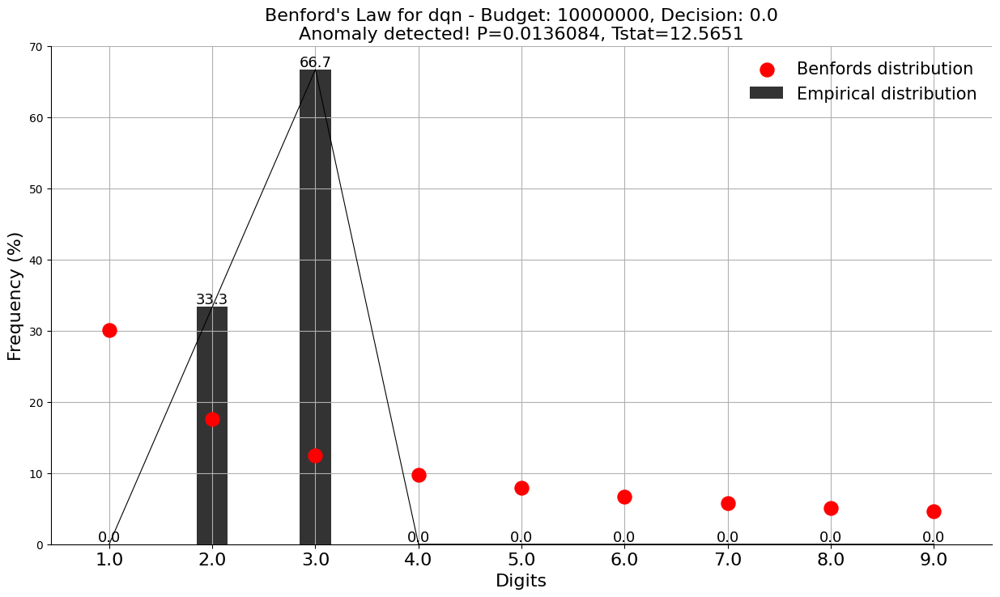

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.310847, Tstat=4.77797


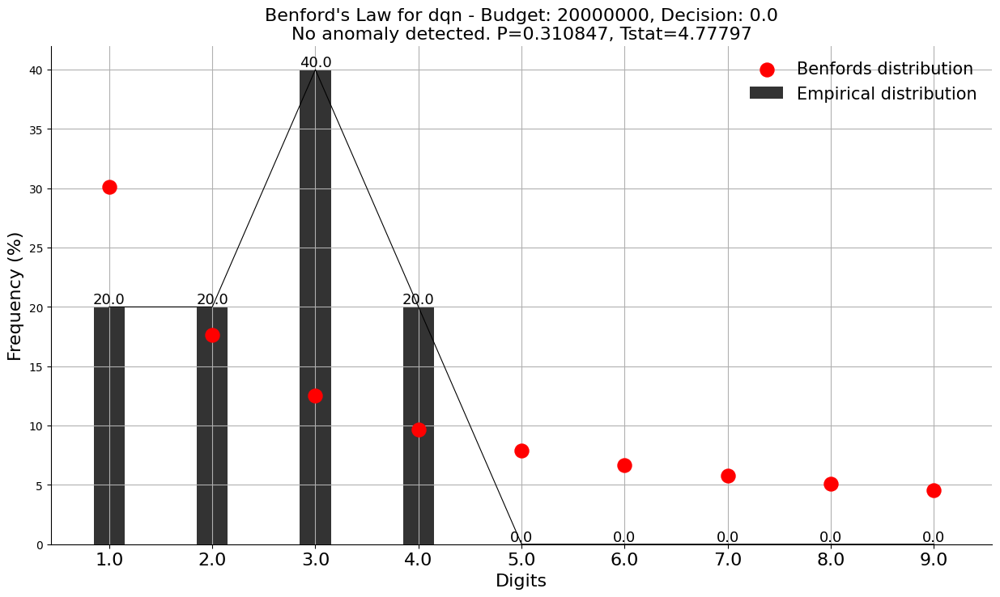

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0307243, Tstat=10.6553


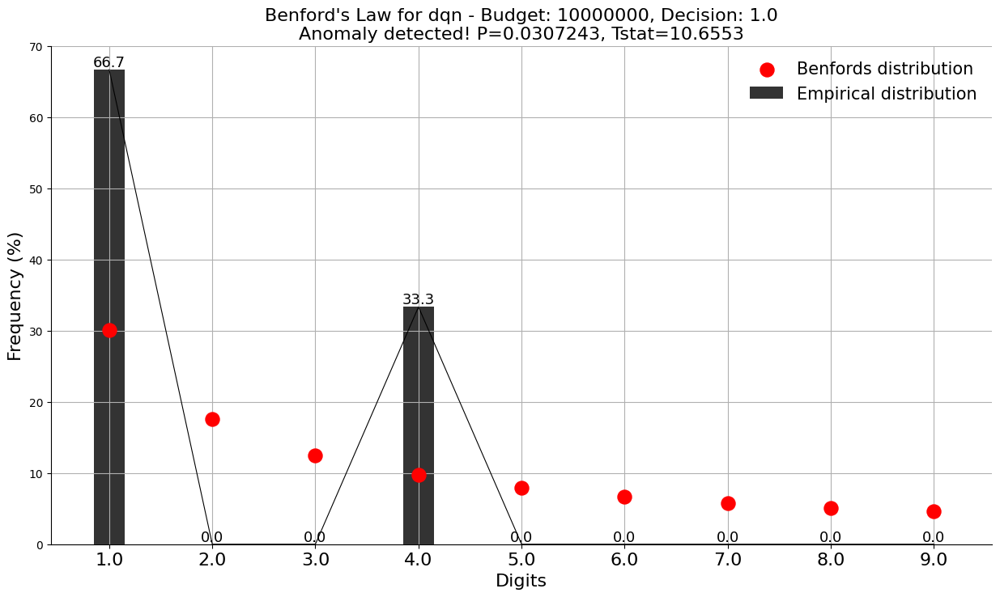

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.131892, Tstat=7.07666


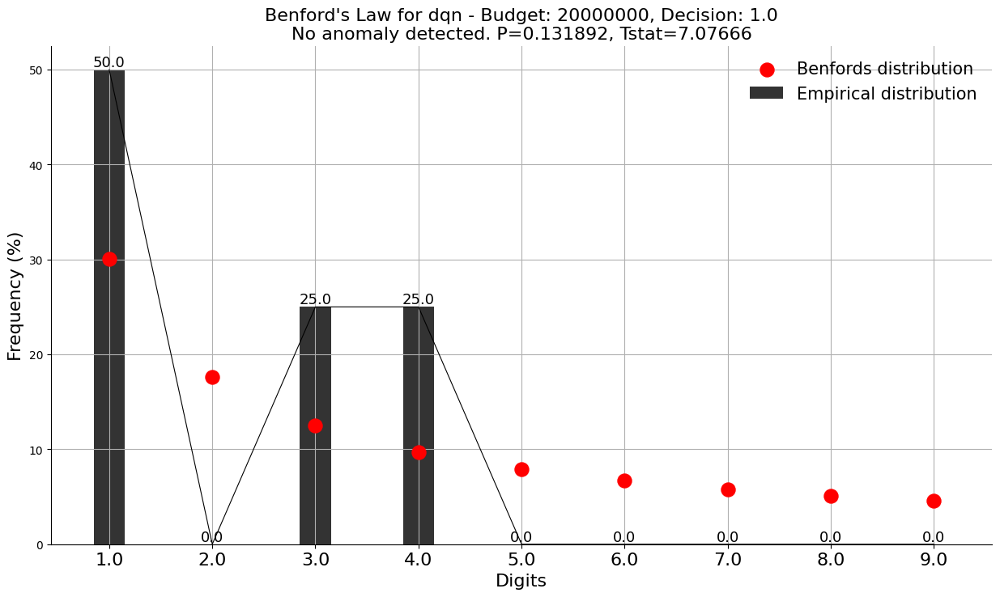

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.326749, Tstat=4.63579


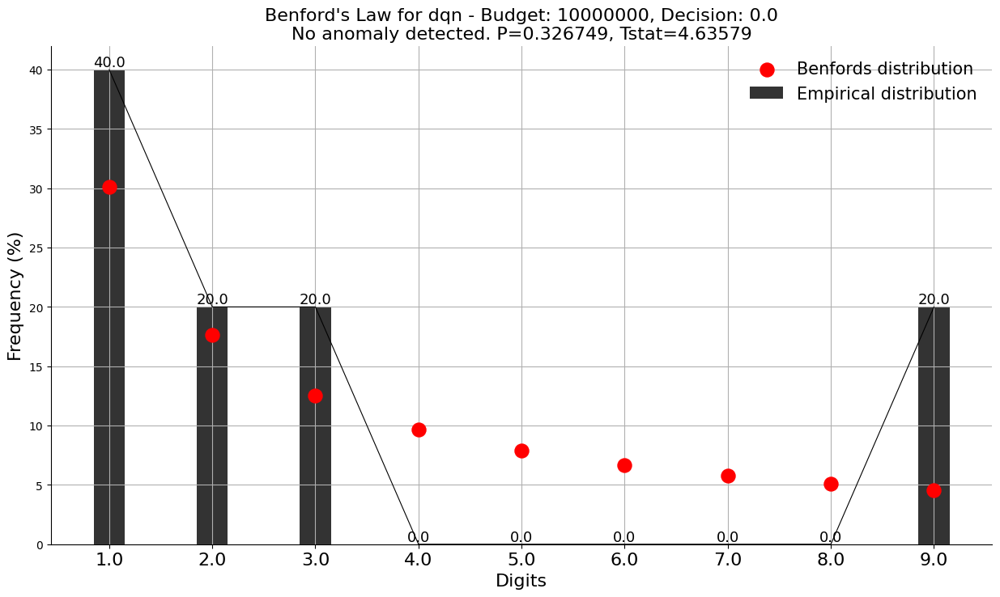

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.142155, Tstat=6.88385


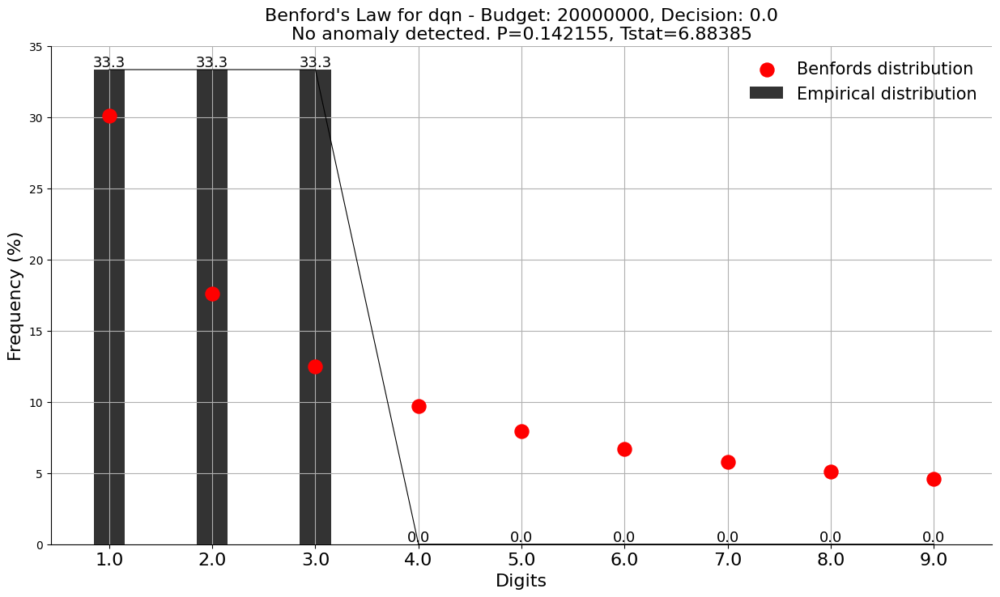

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0426635, Tstat=9.87067


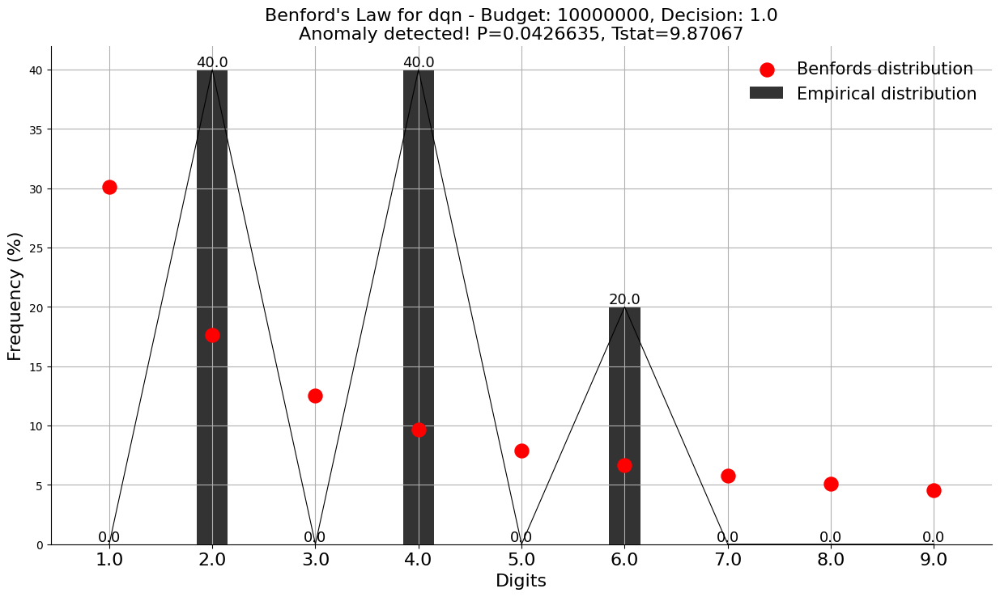

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.233203, Tstat=5.57514


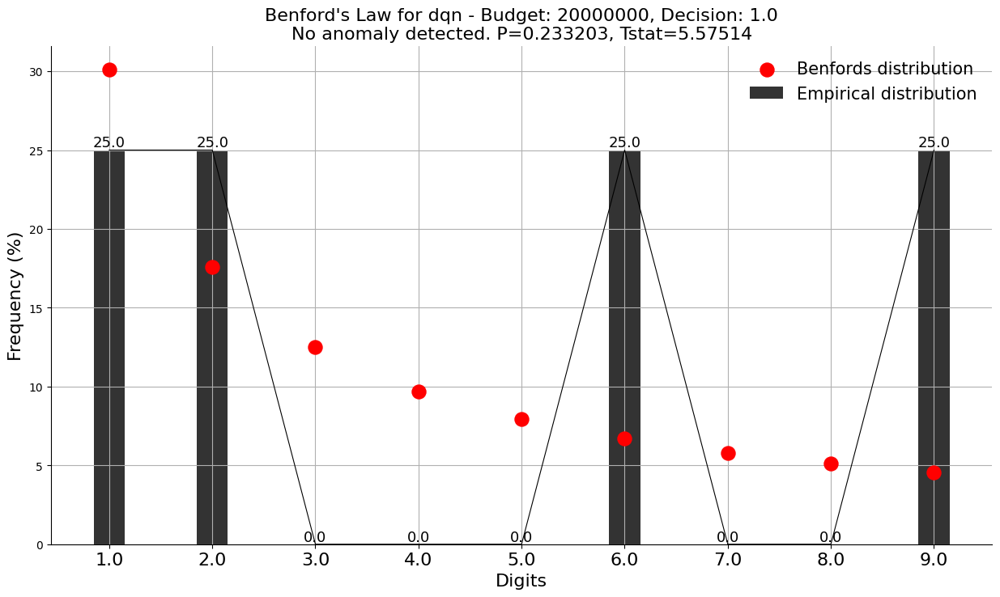

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.119073, Tstat=7.33791


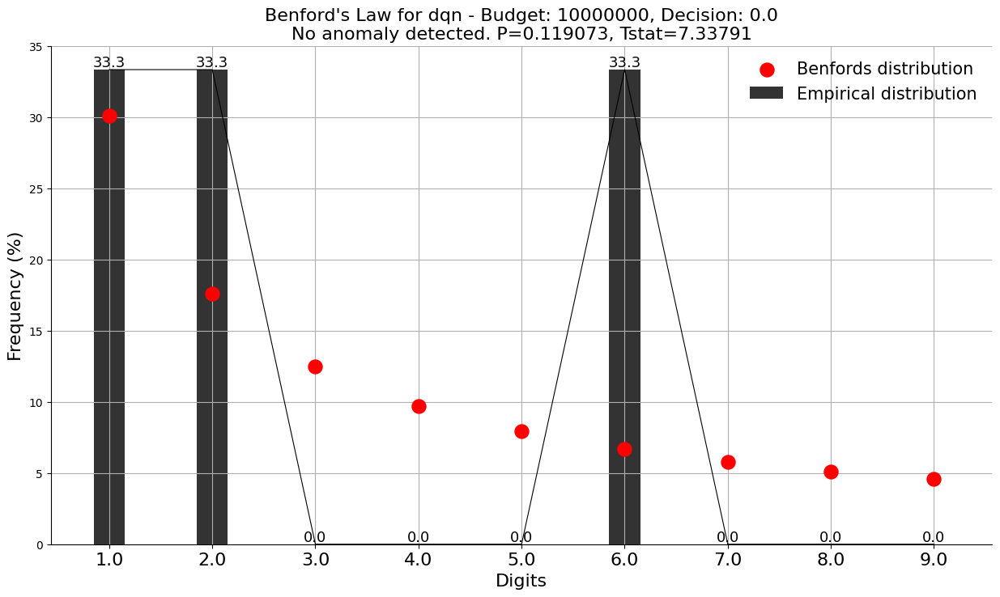

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.667268, Tstat=2.37435


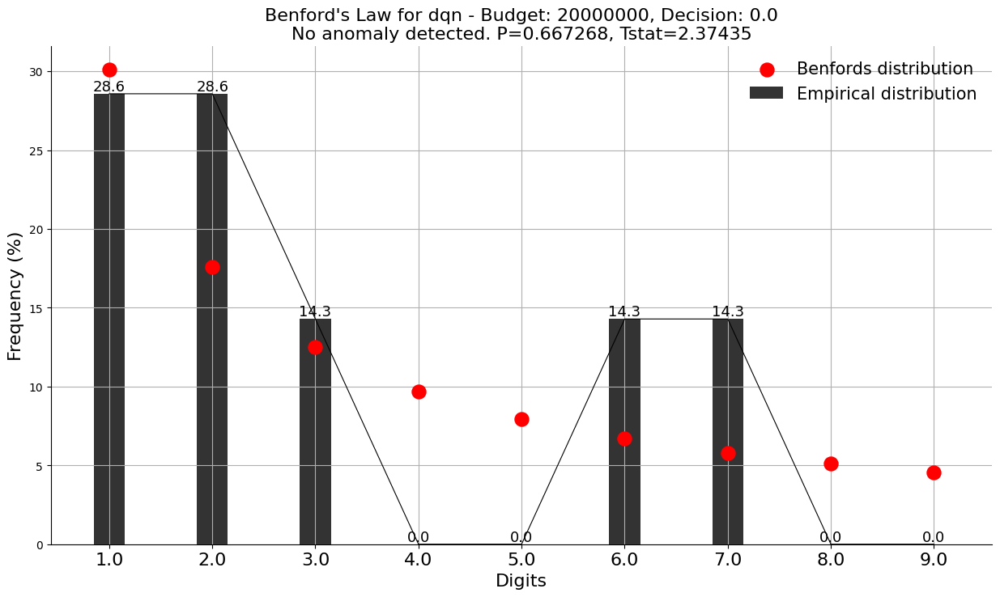

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0683828, Tstat=8.72393


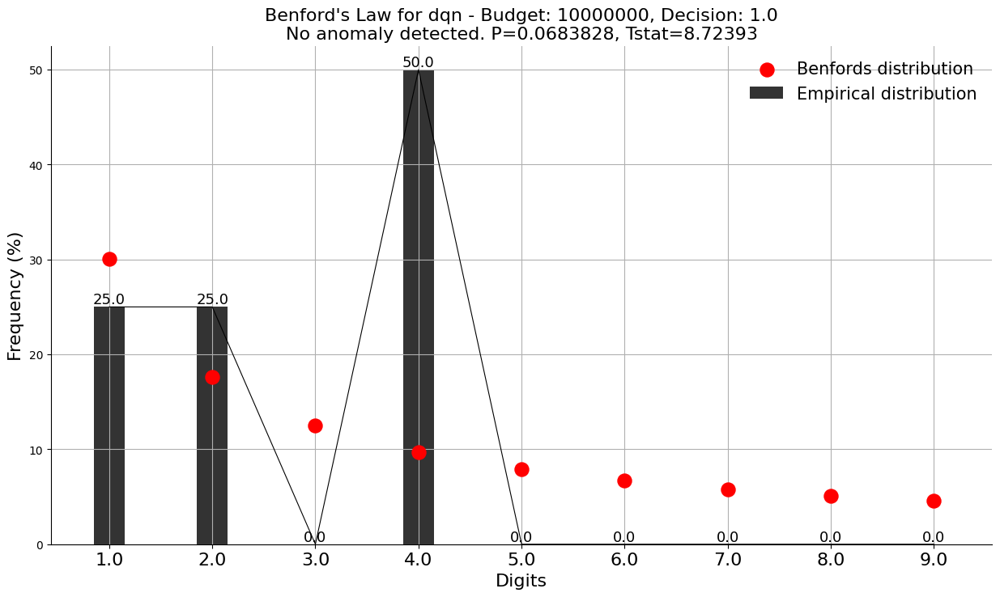

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0896608, Tstat=8.05286


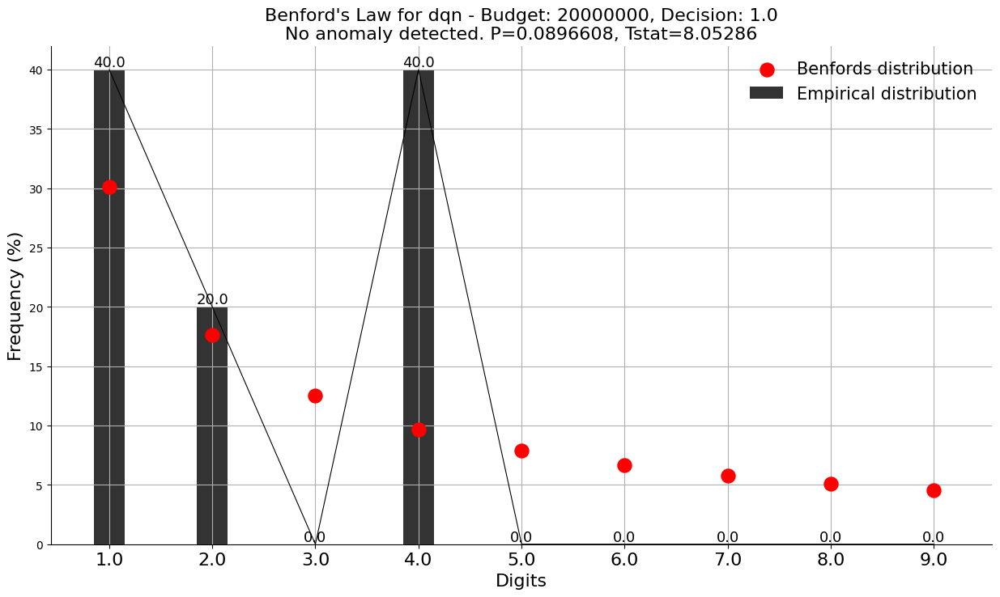

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.406326, Tstat=3.99764


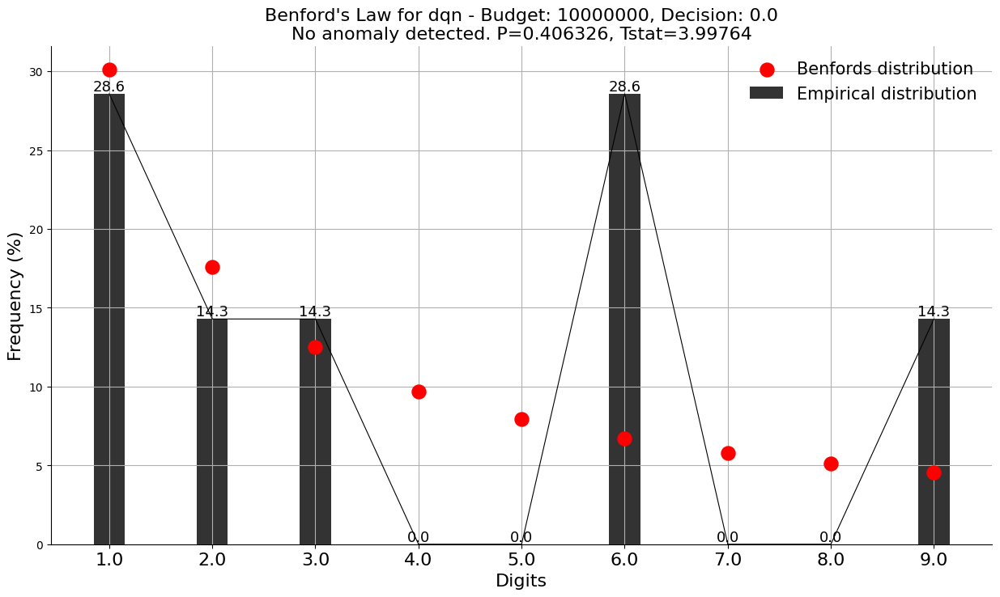

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0718944, Tstat=8.60065


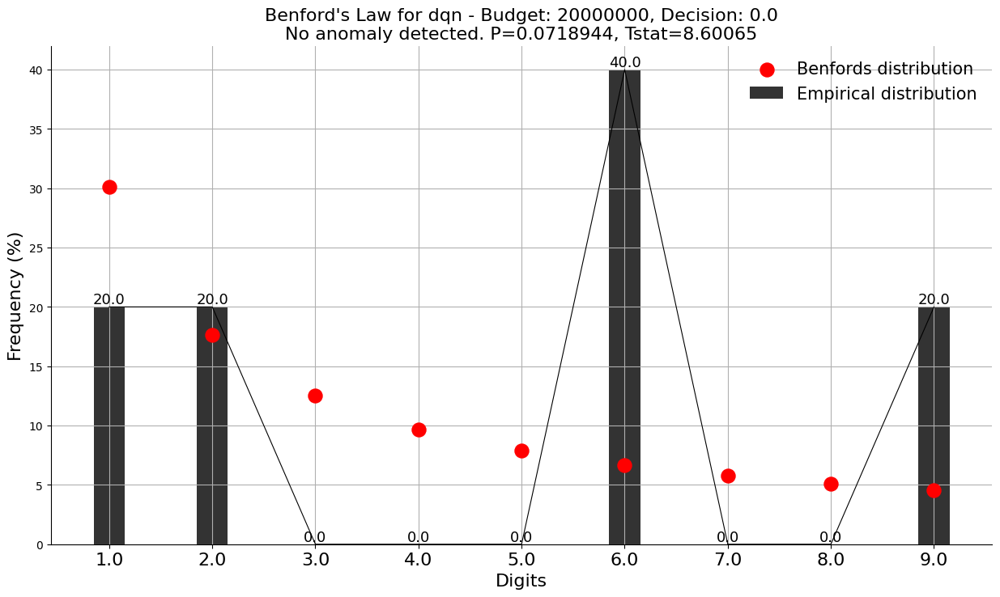

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.109918, Tstat=7.54094


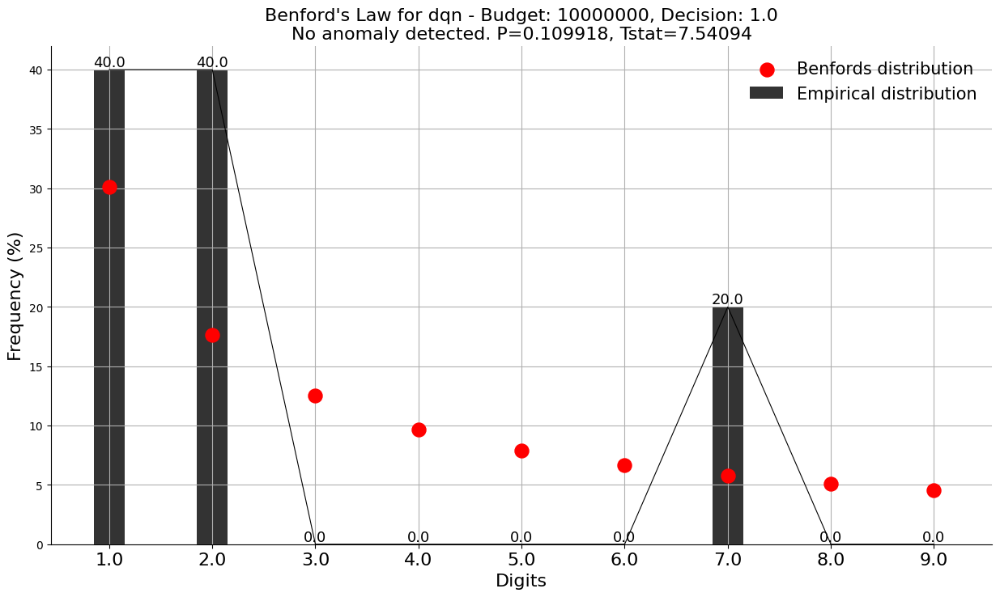

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.344957, Tstat=4.47974


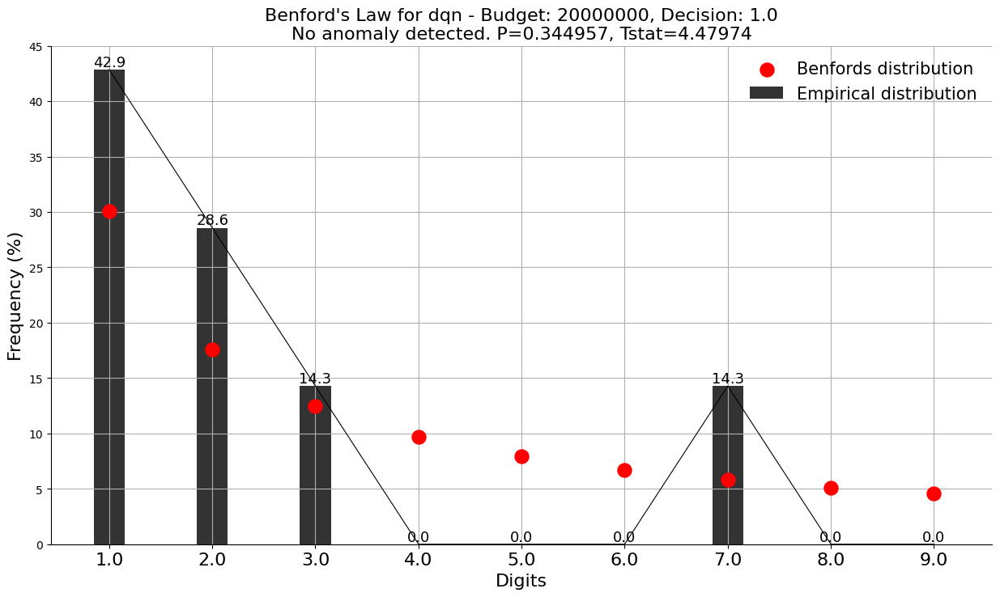

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


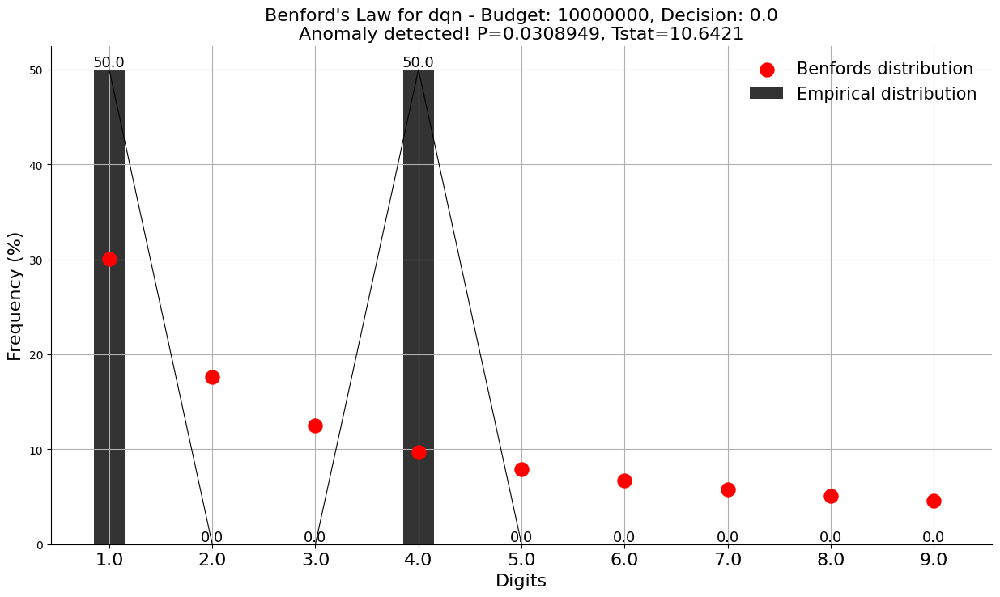

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0155856, Tstat=12.25


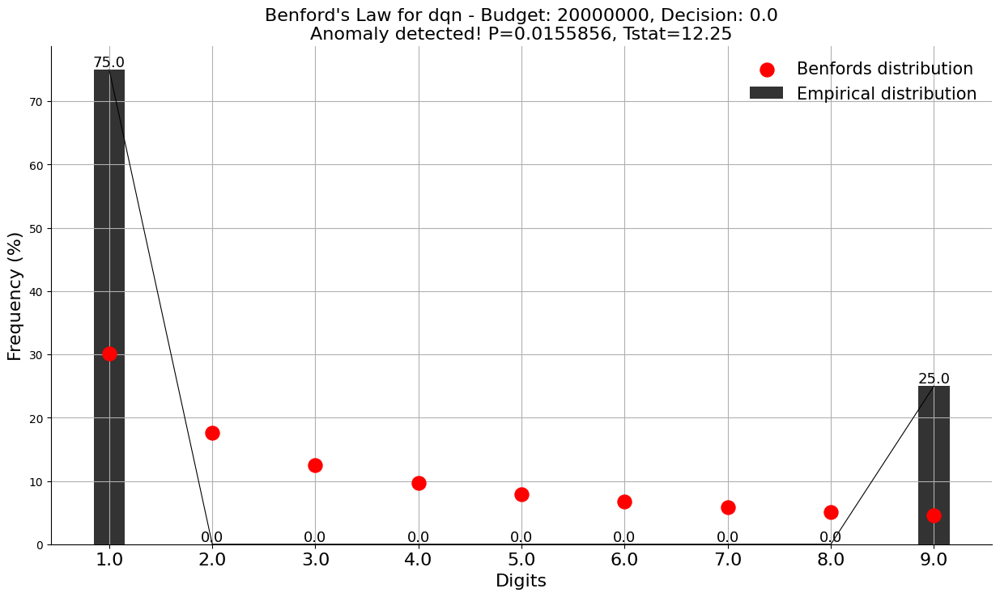

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0163313, Tstat=12.1412


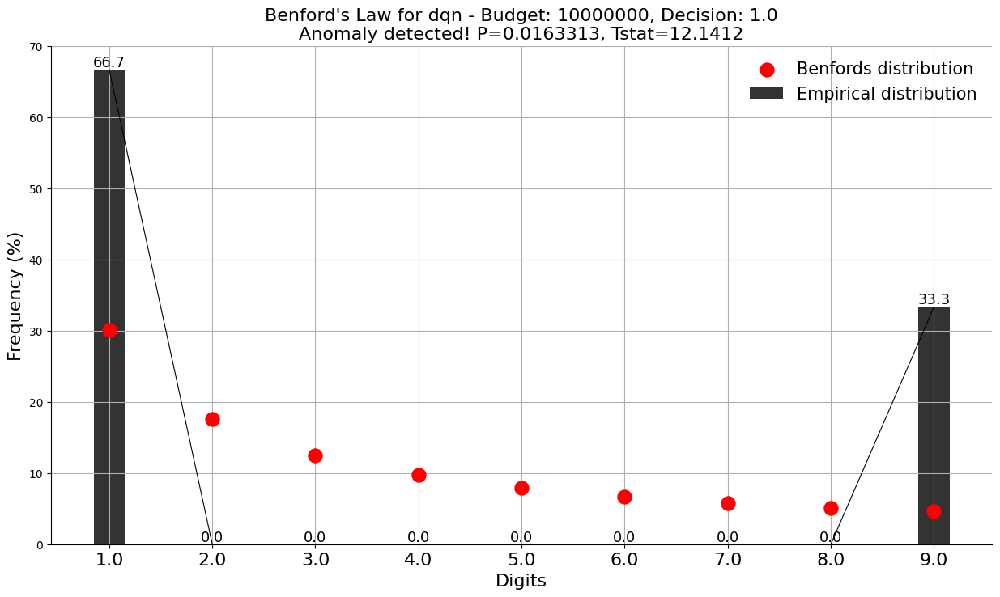

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.128483, Tstat=7.14376


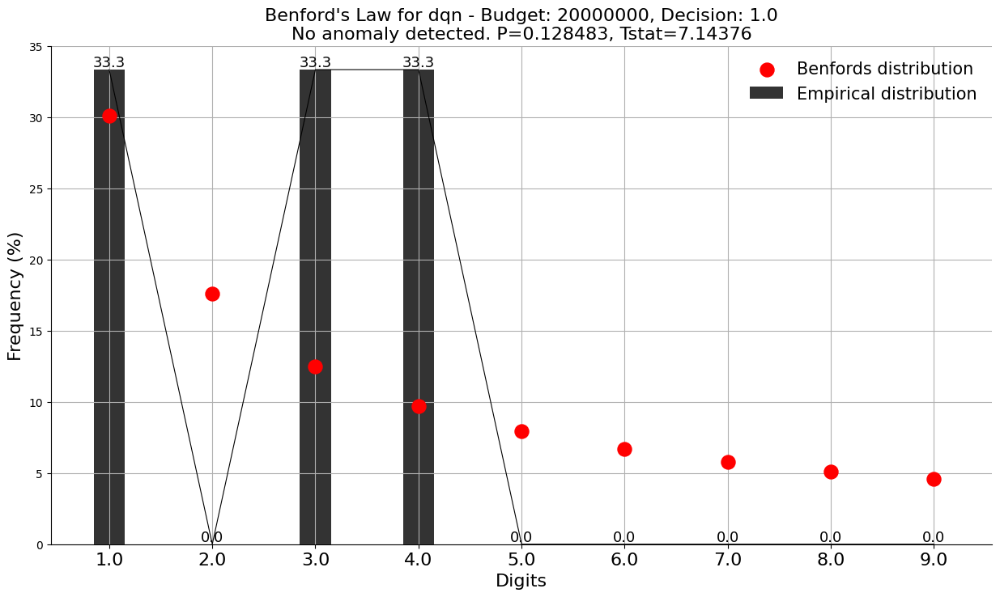

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.153496, Tstat=6.68509


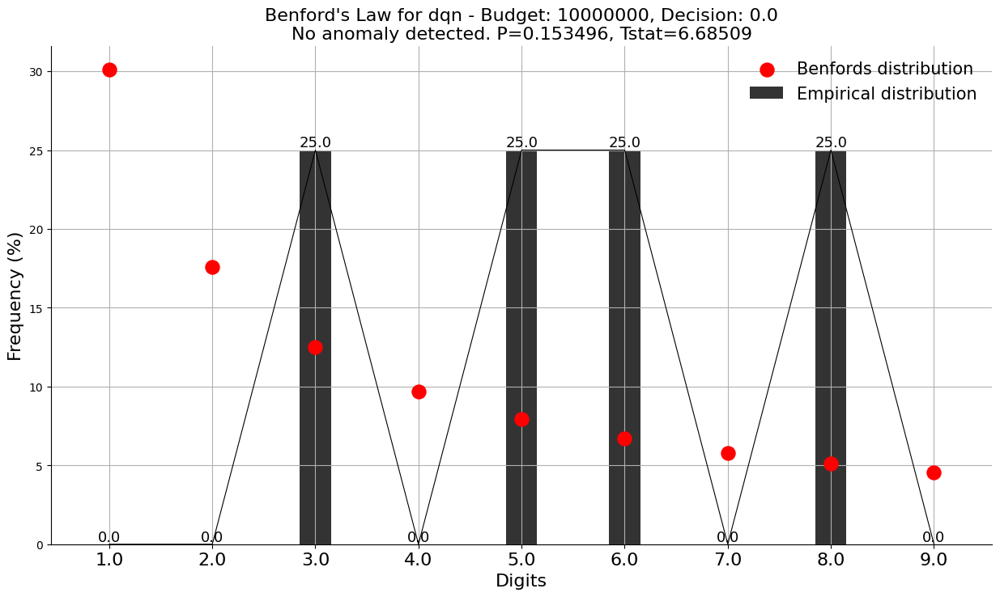

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0727958, Tstat=8.56993


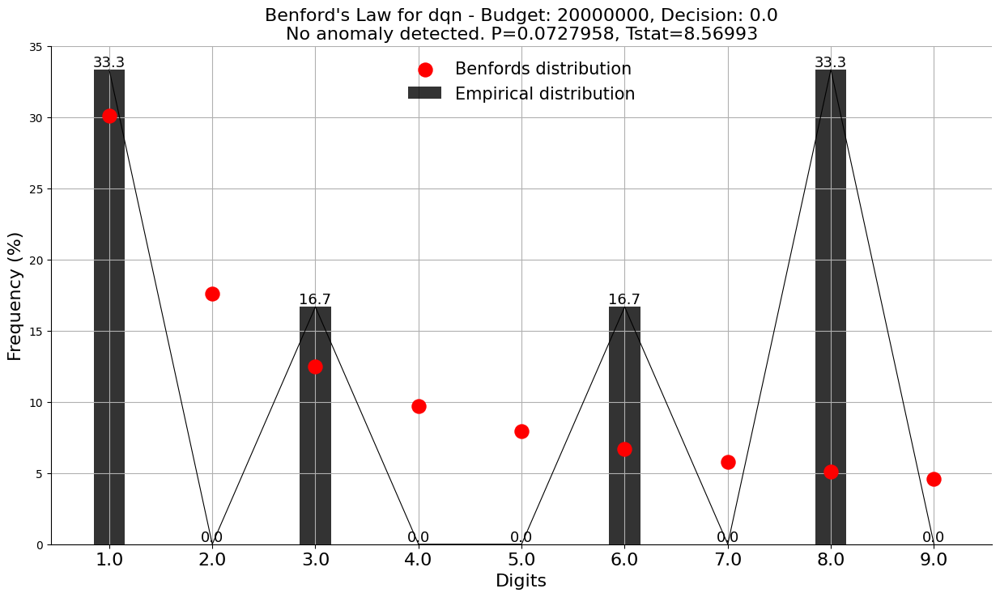

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0752678, Tstat=8.48748


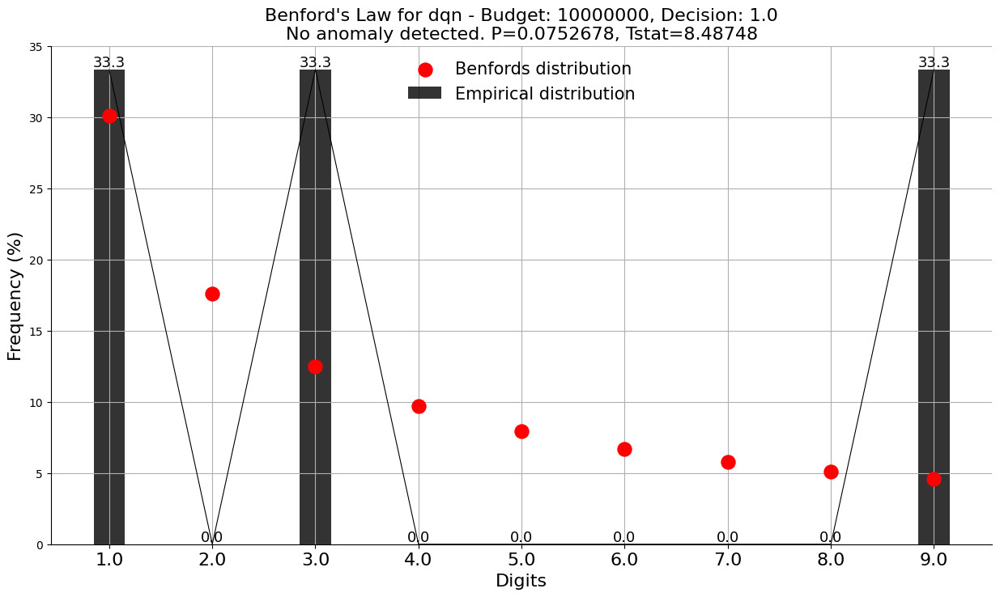

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.164319, Tstat=6.50749


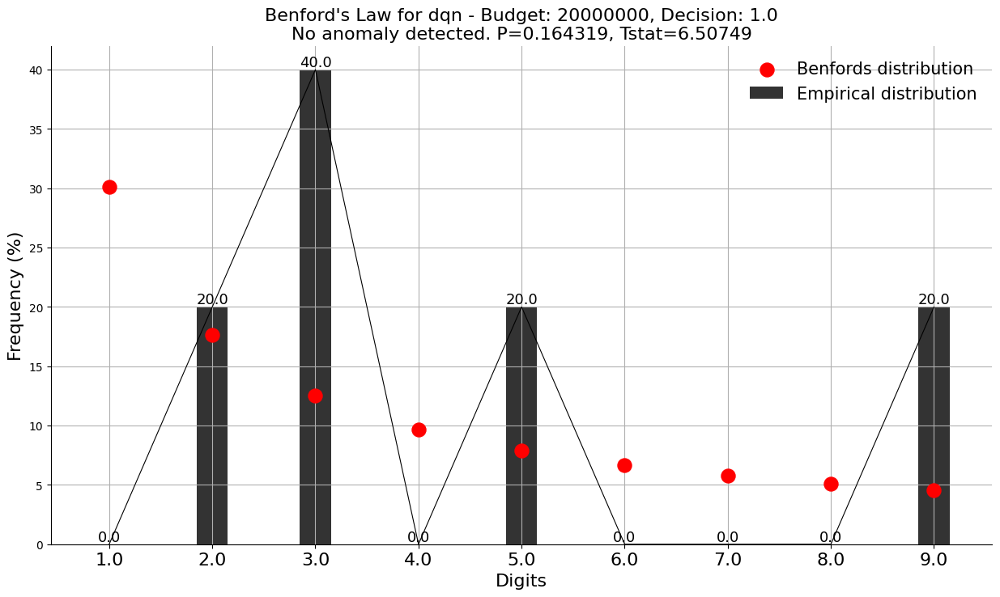

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0145698, Tstat=12.4067


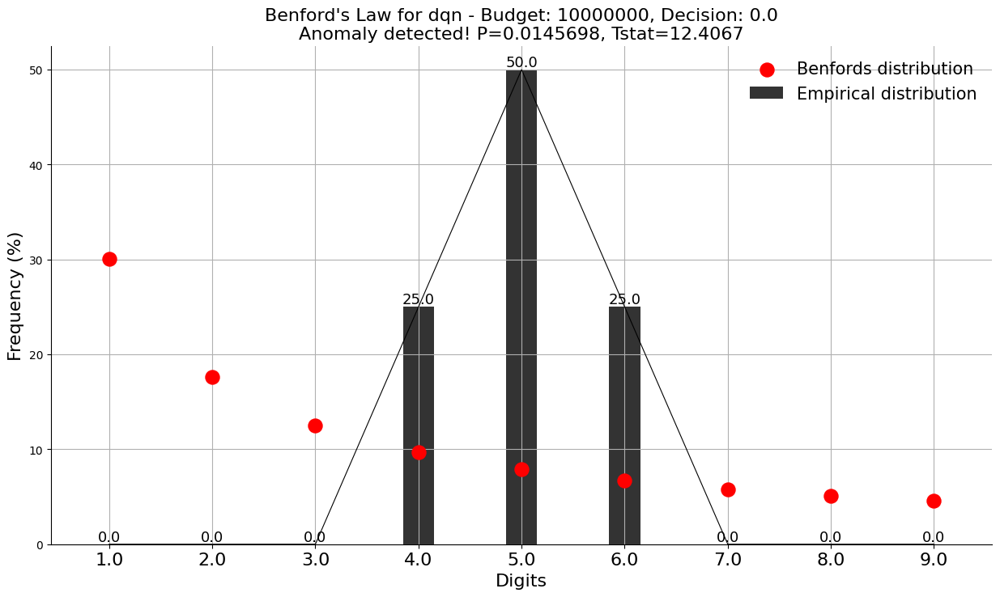

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=5.78869e-09, Tstat=44.215


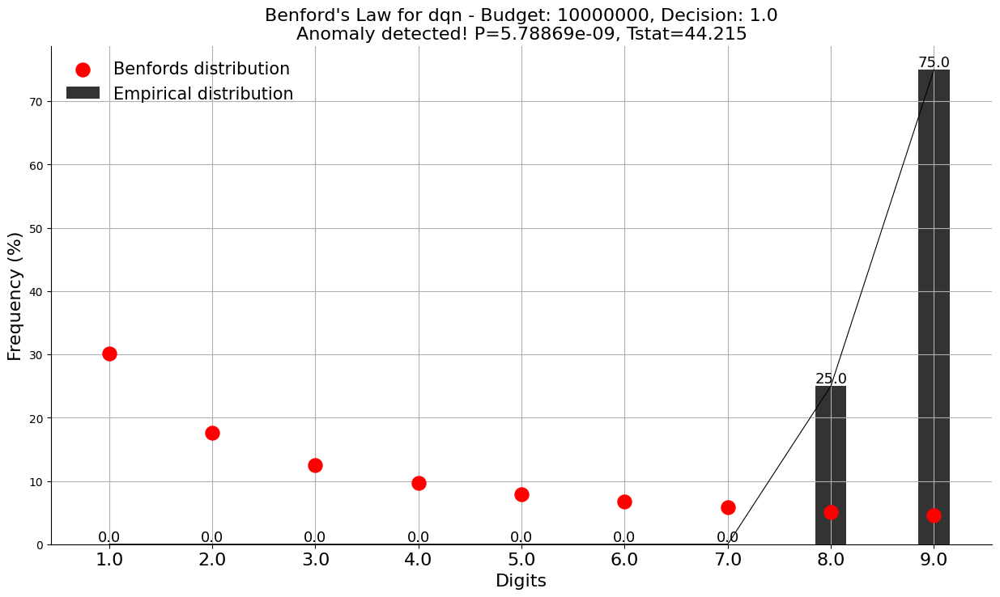

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0390577, Tstat=10.0827


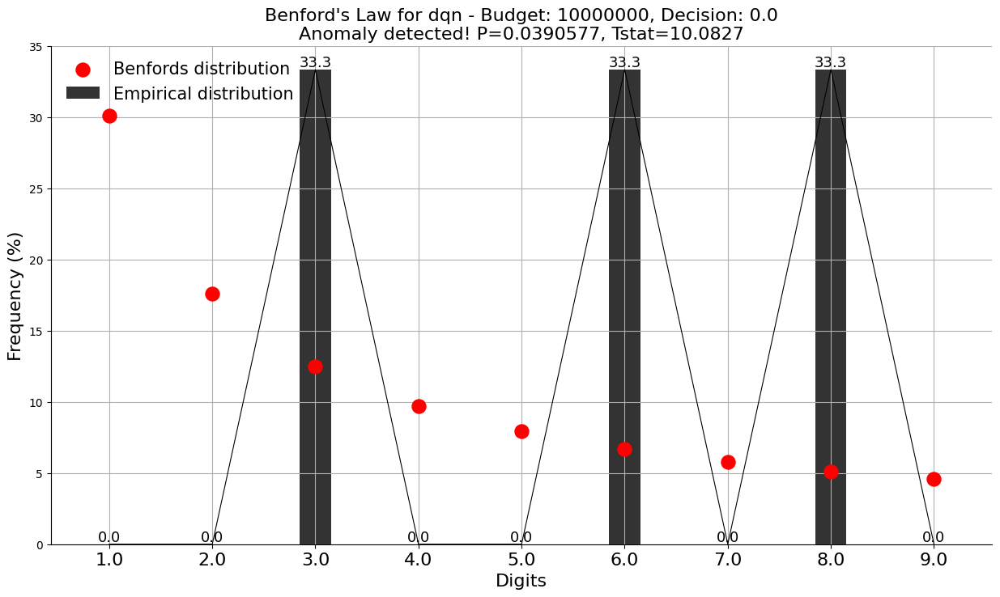

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0417726, Tstat=9.92141


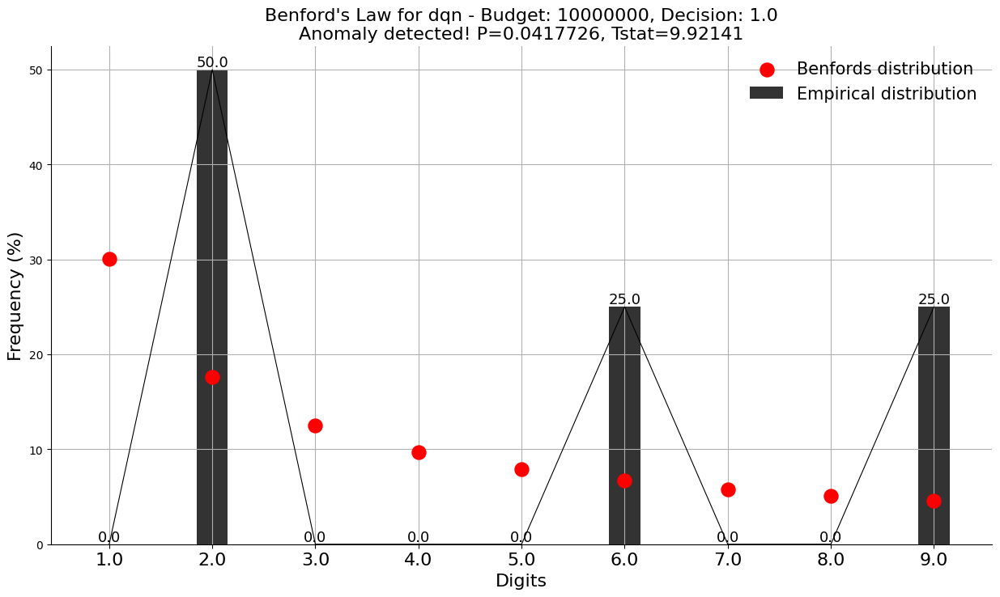

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00591466, Tstat=14.4785


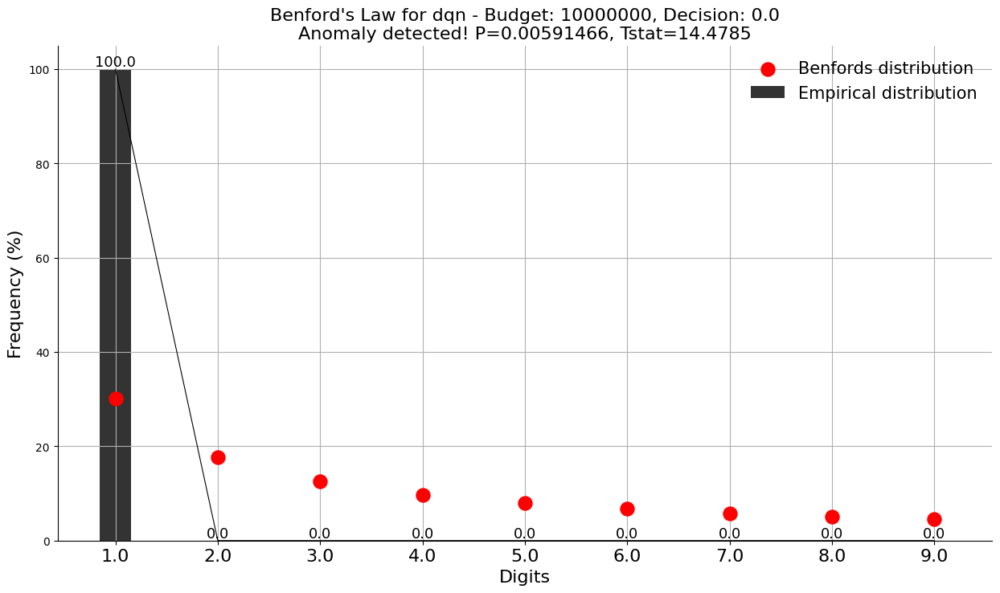

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00591466, Tstat=14.4785


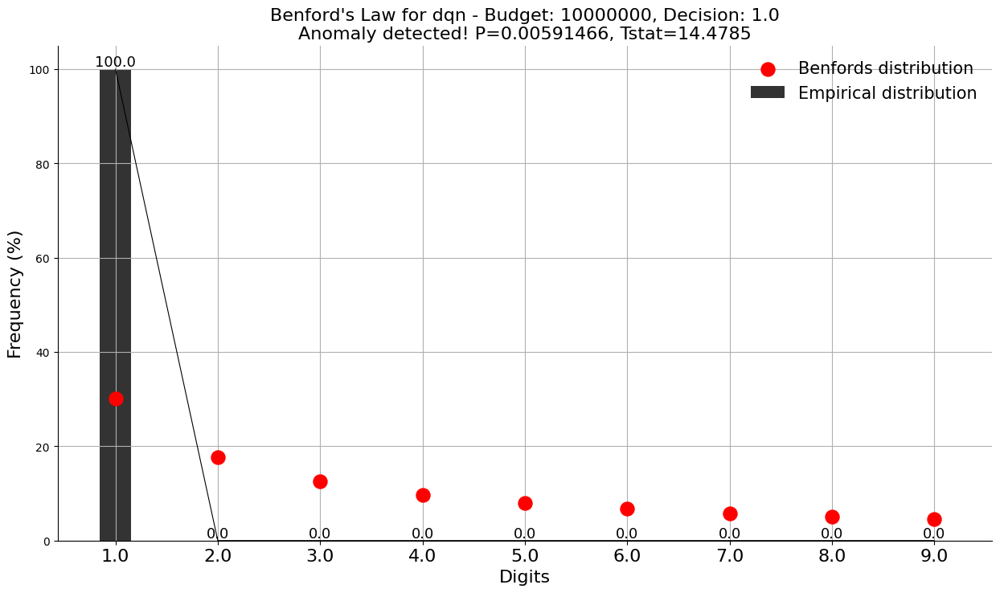

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


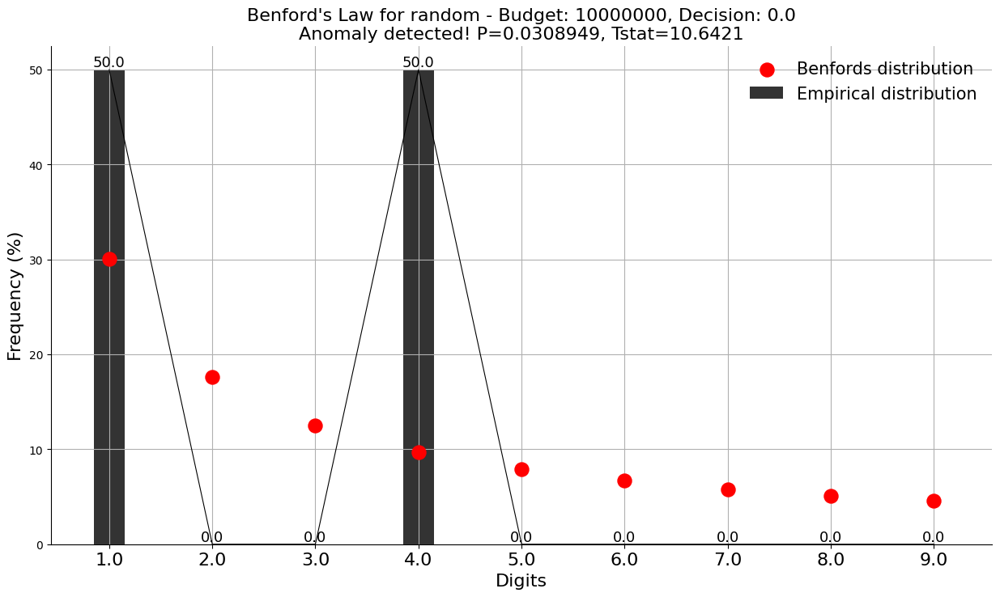

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0177328, Tstat=11.9492


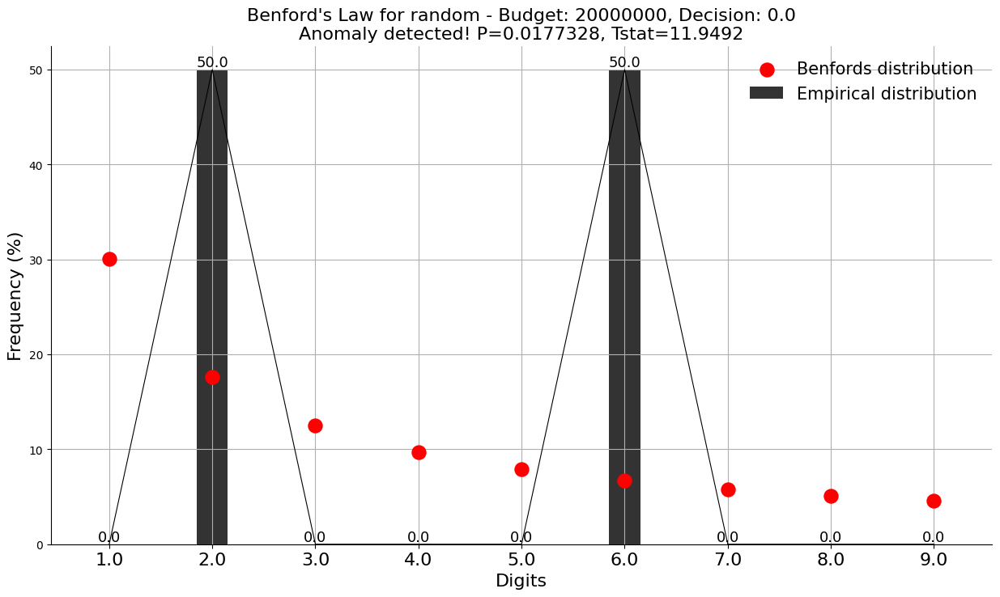

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.19828, Tstat=6.01165


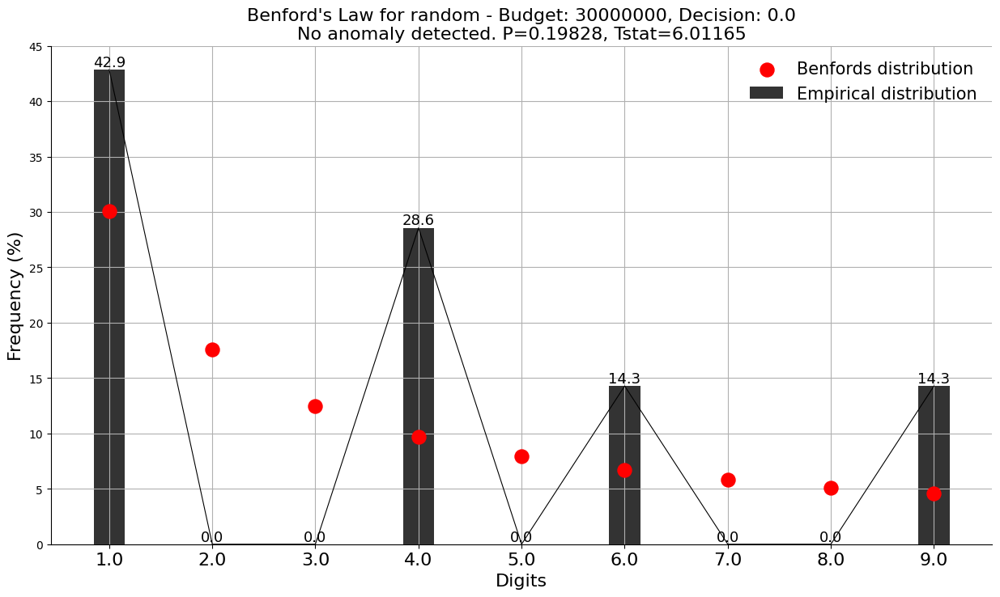

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.575748, Tstat=2.89383


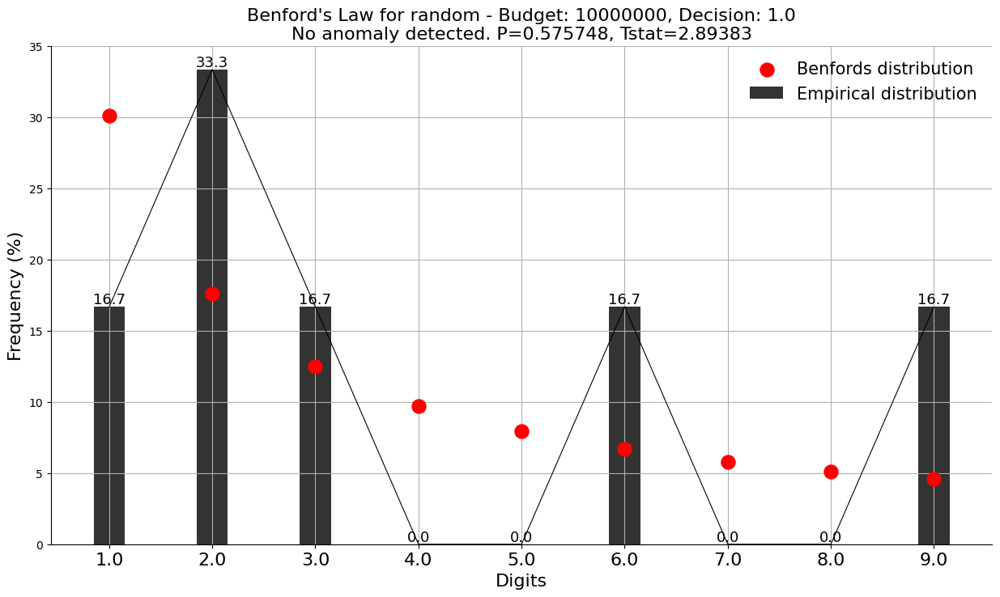

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0332745, Tstat=10.4656


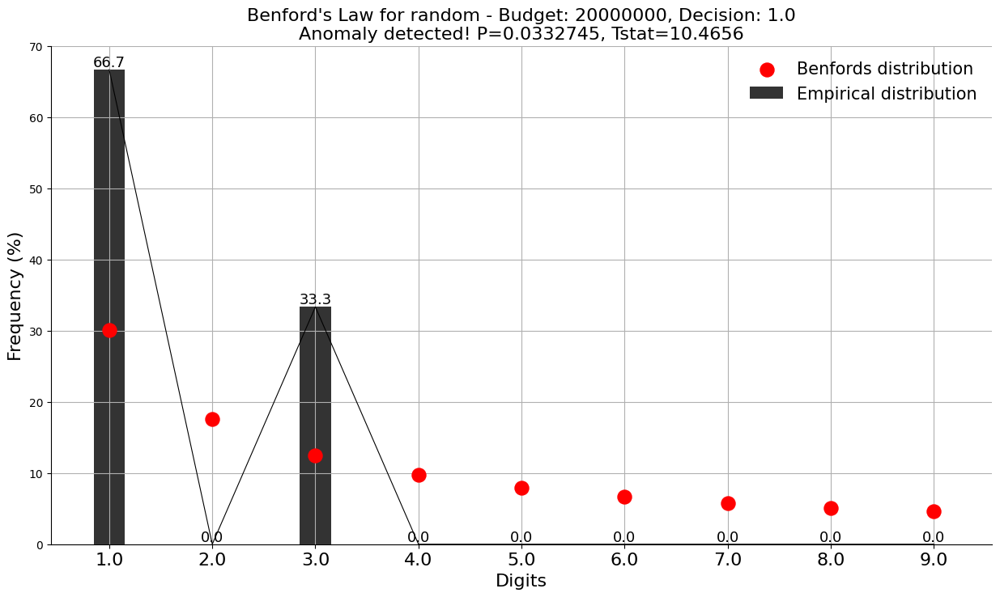

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.533655, Tstat=3.14626


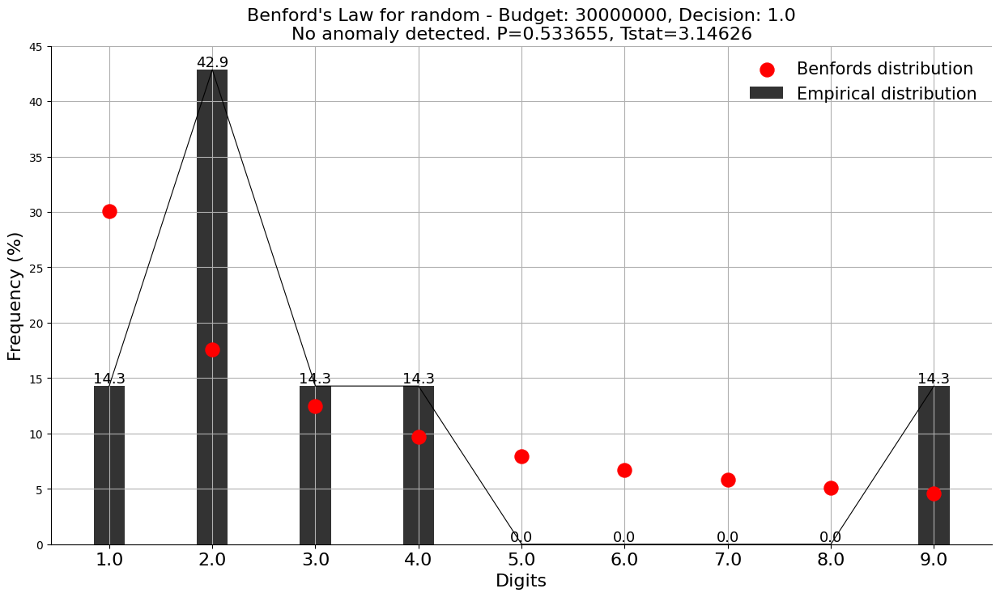

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.866127, Tstat=1.27189


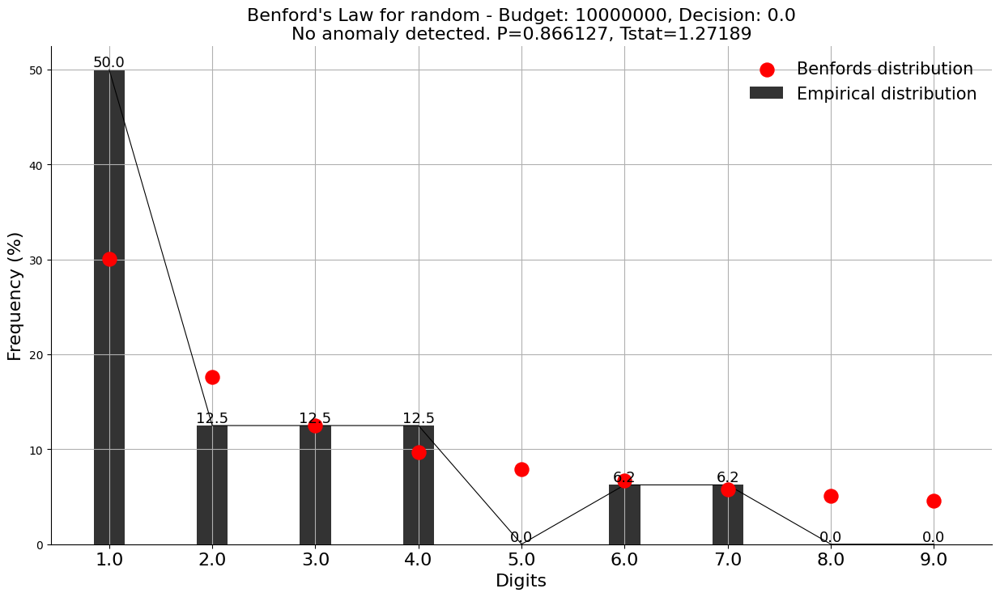

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


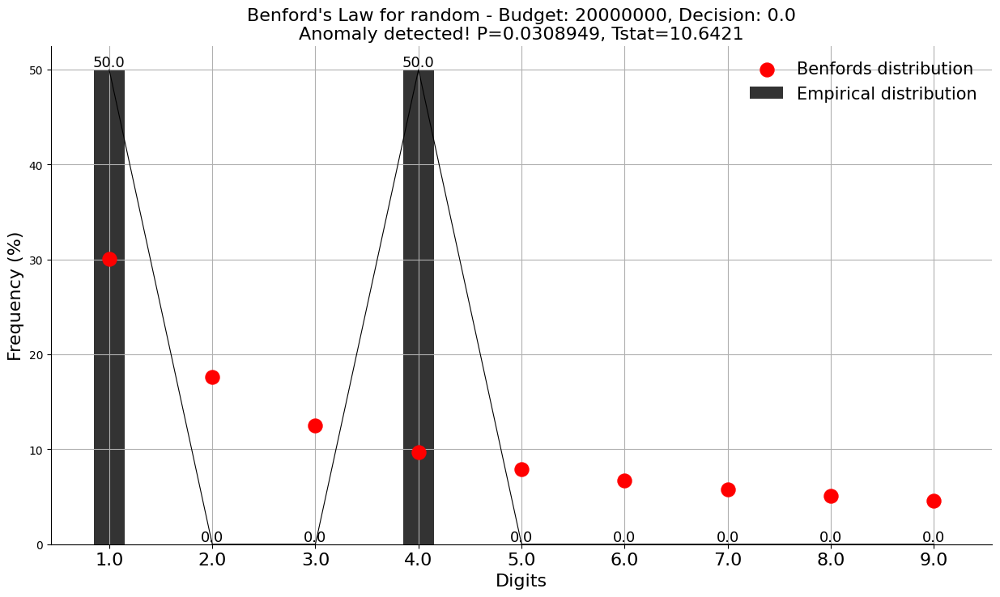

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.292509, Tstat=4.94959


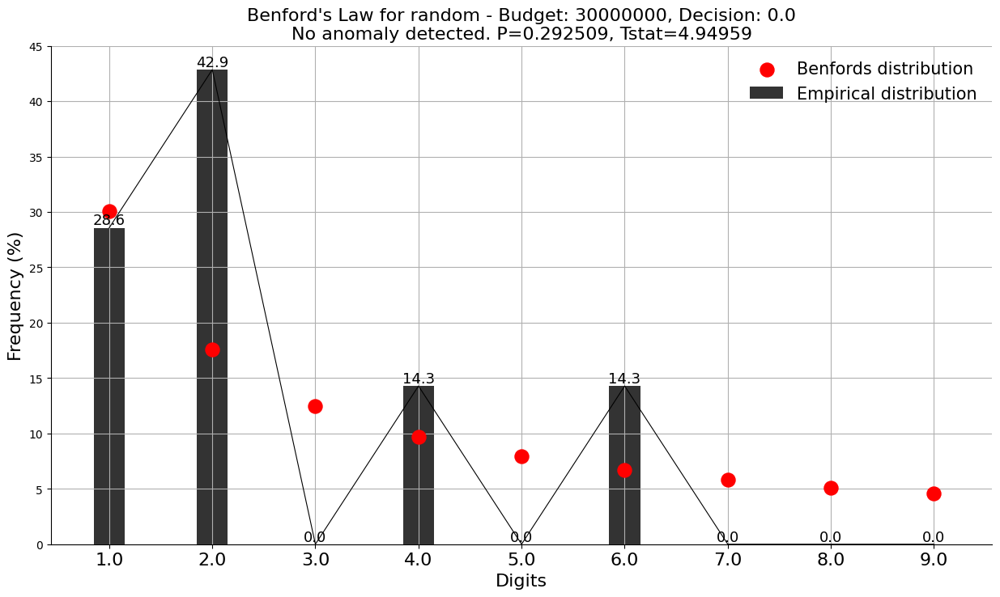

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.584483, Tstat=2.84271


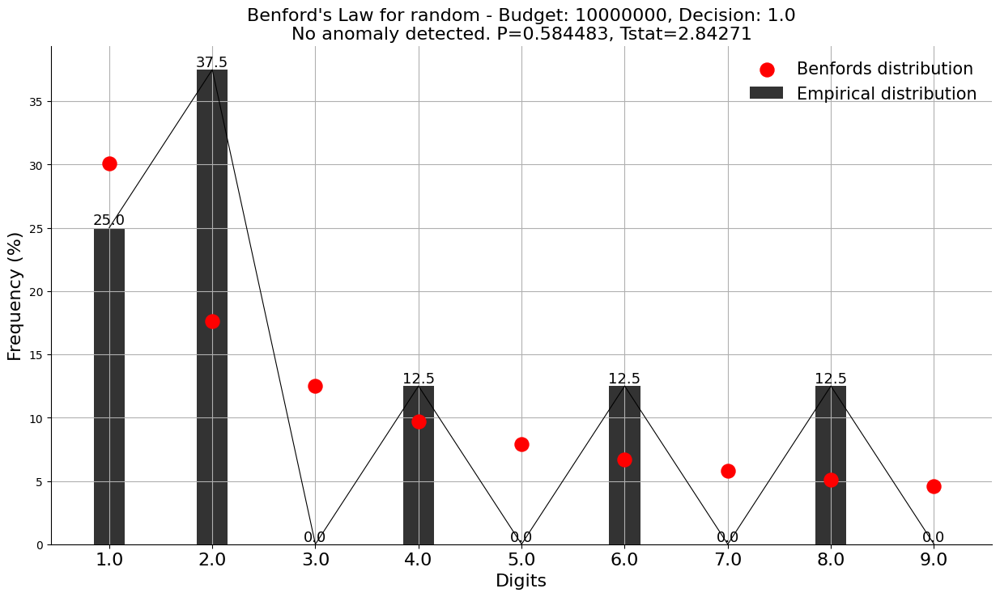

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0761977, Tstat=8.45712


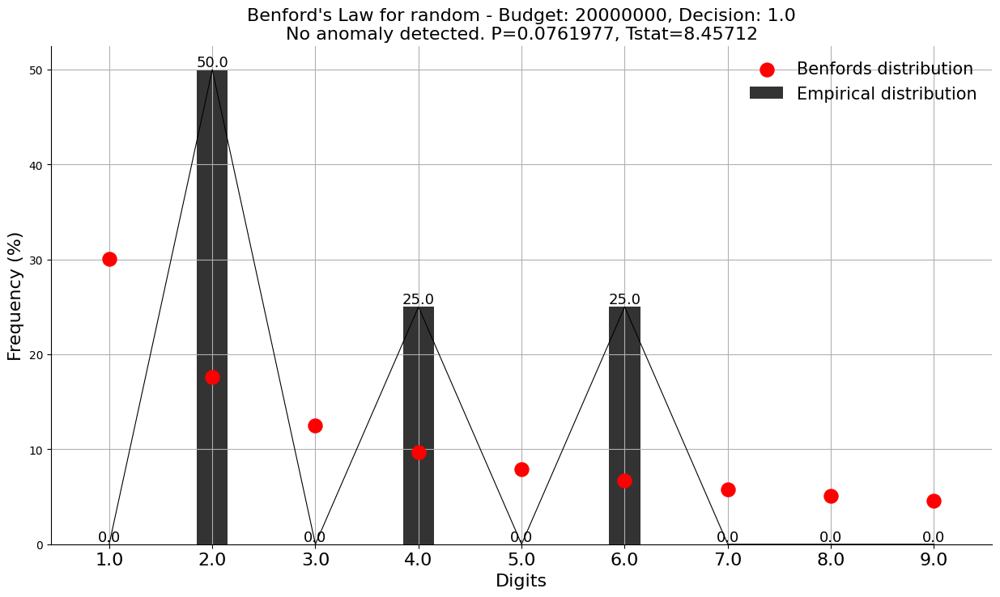

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.295479, Tstat=4.9212


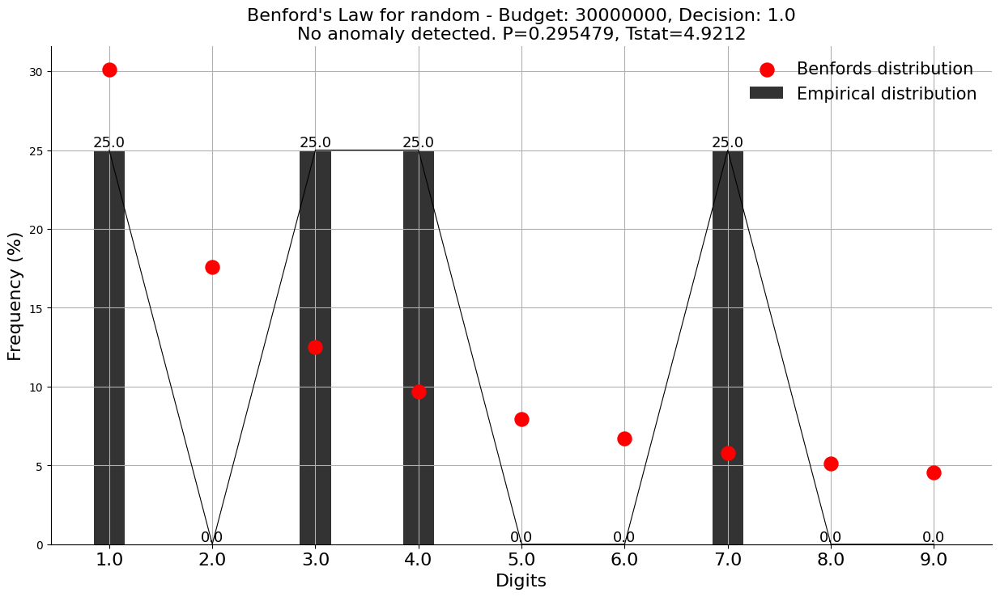

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00592606, Tstat=14.4741


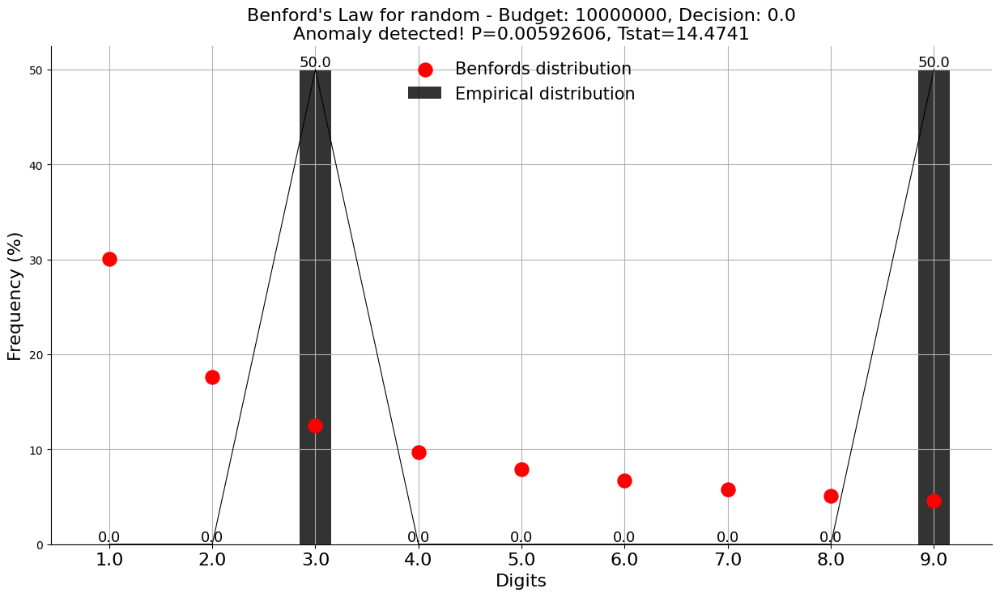

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.212204, Tstat=5.83006


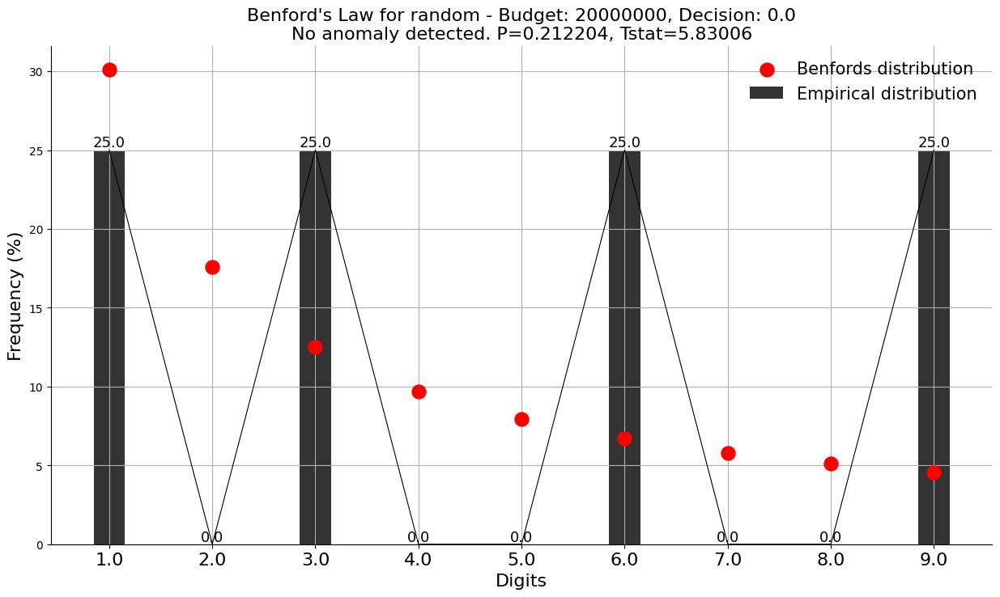

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0653749, Tstat=8.83439


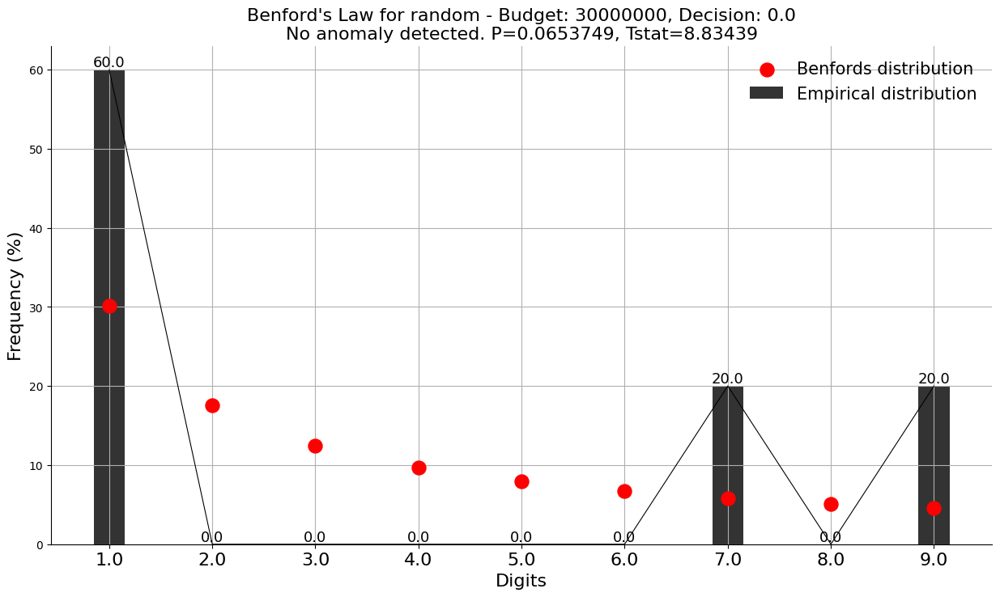

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.101392, Tstat=7.74466


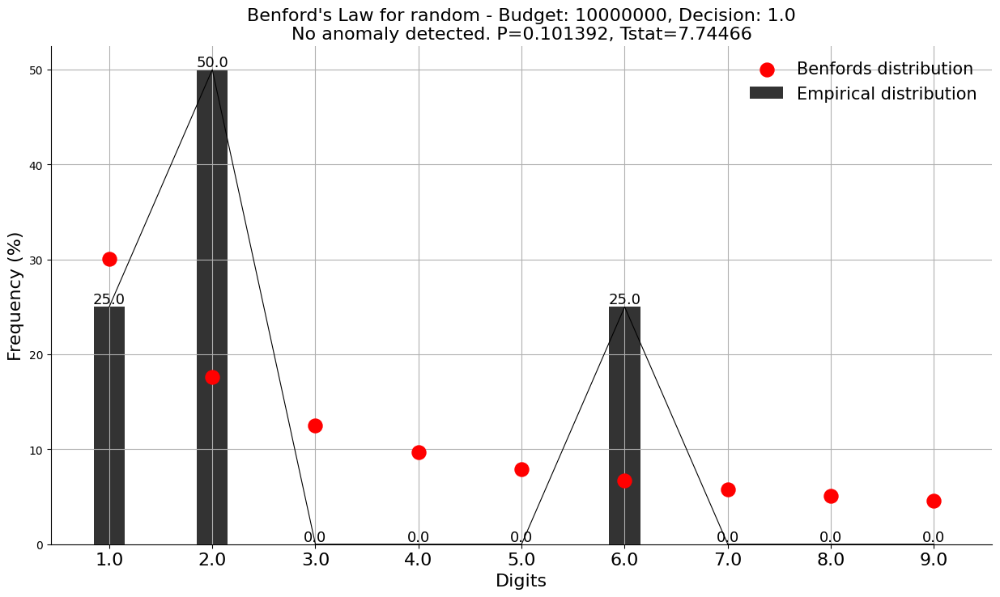

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.257011, Tstat=5.30926


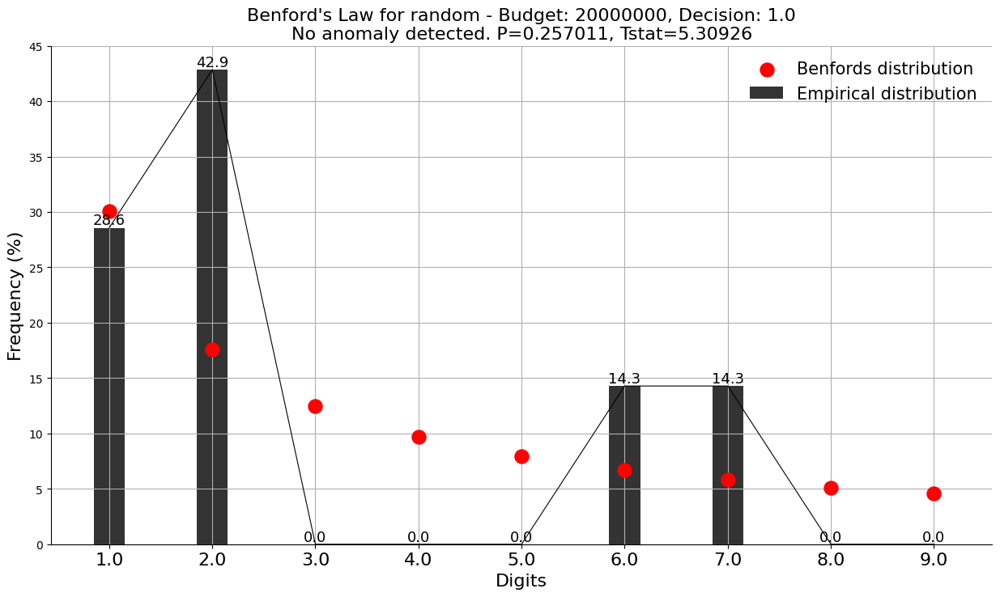

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.133516, Tstat=7.04525


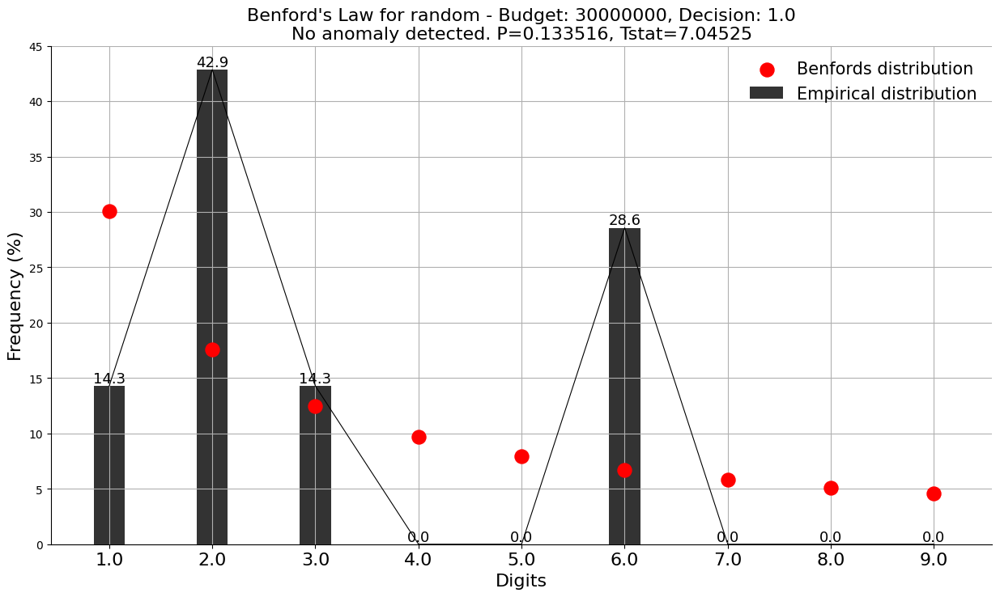

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00219082, Tstat=16.7198


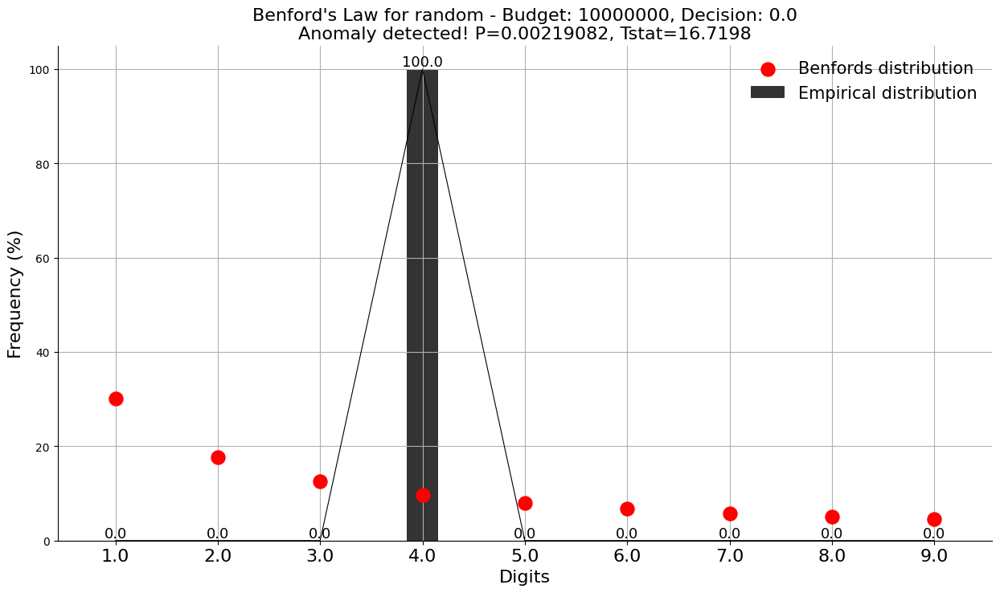

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00430483, Tstat=15.1995


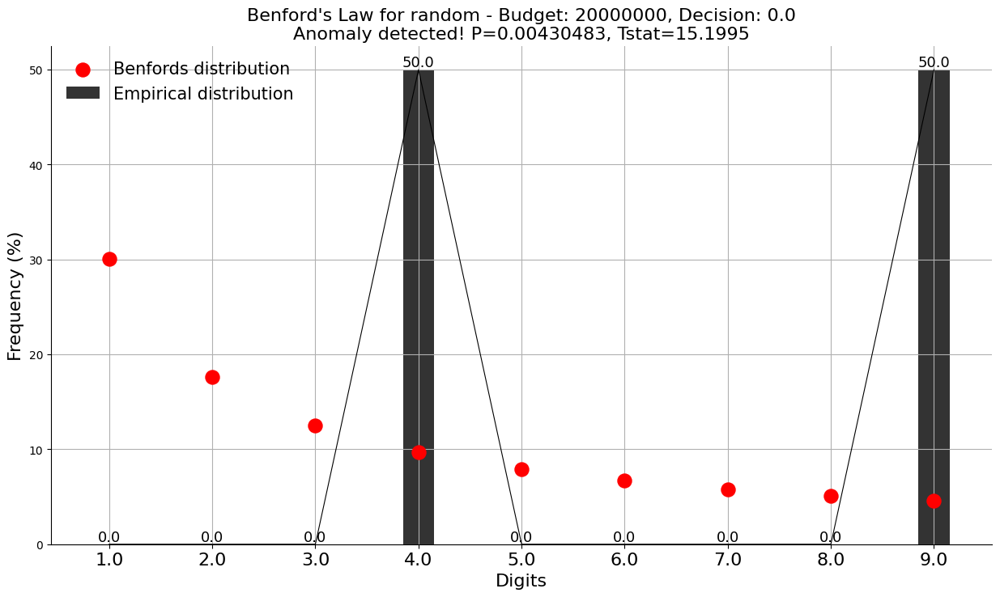

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00353024, Tstat=15.6477


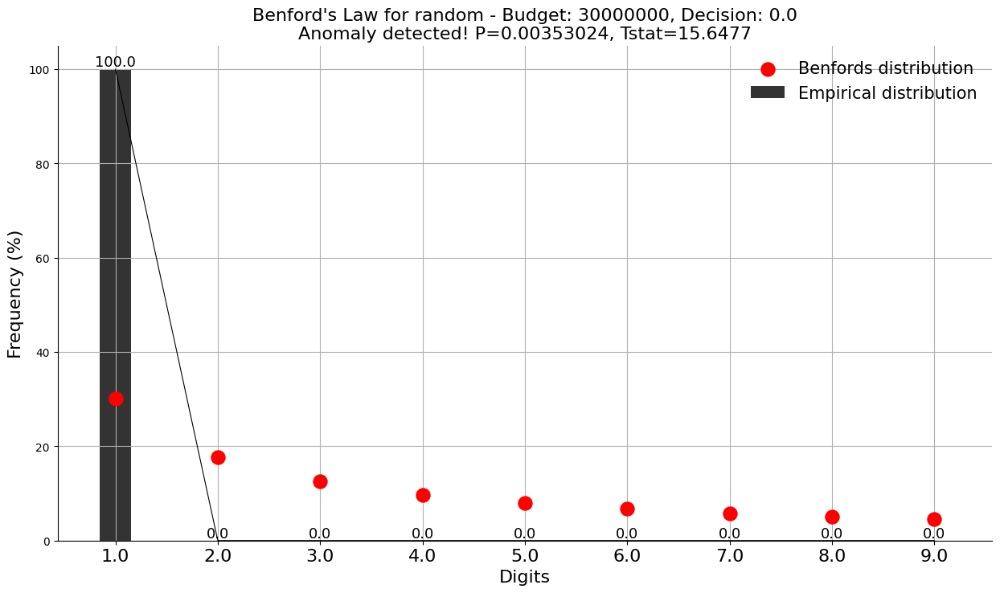

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0155856, Tstat=12.25


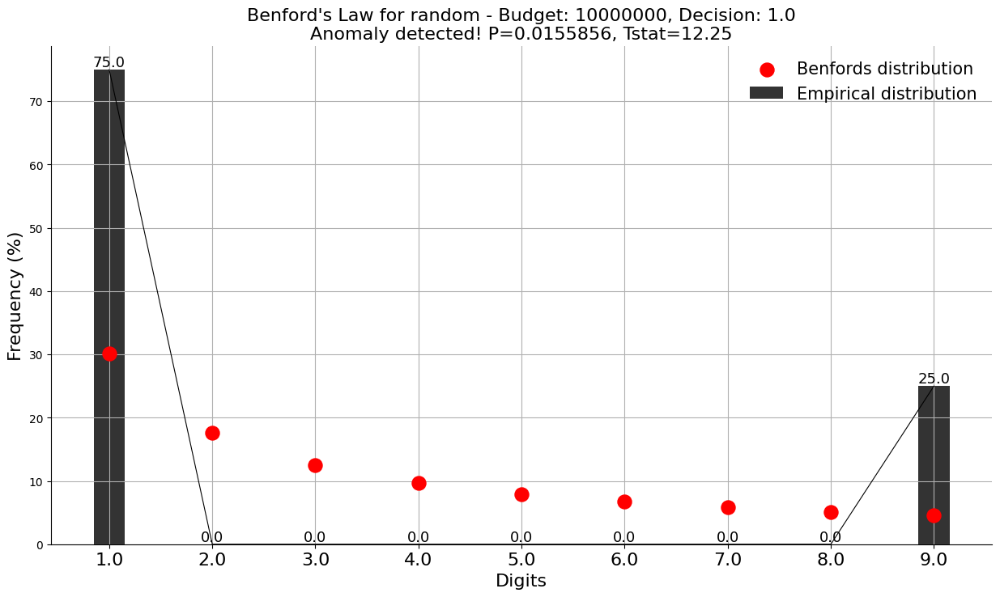

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00353024, Tstat=15.6477


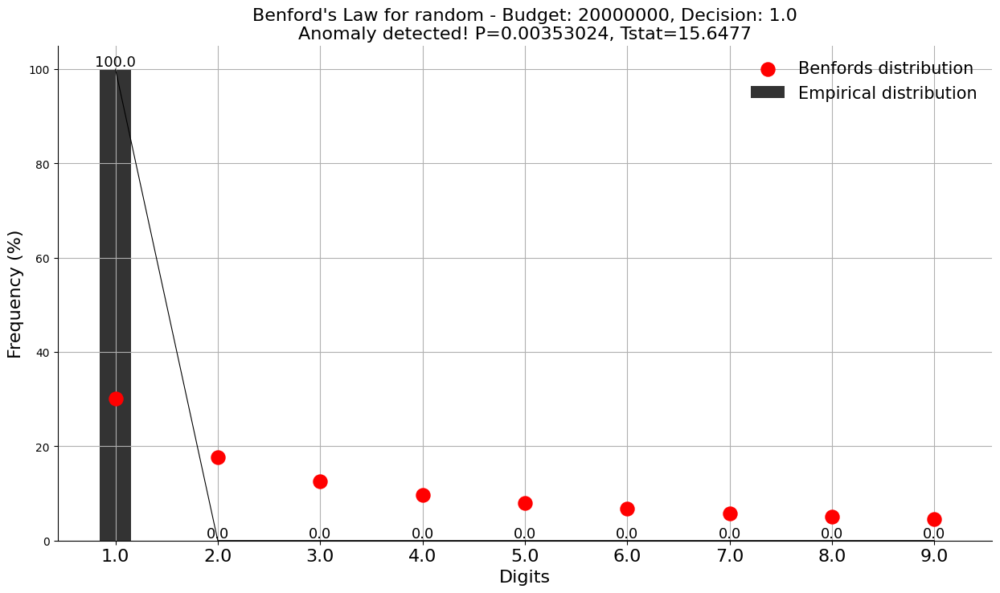

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.929371, Tstat=0.866112


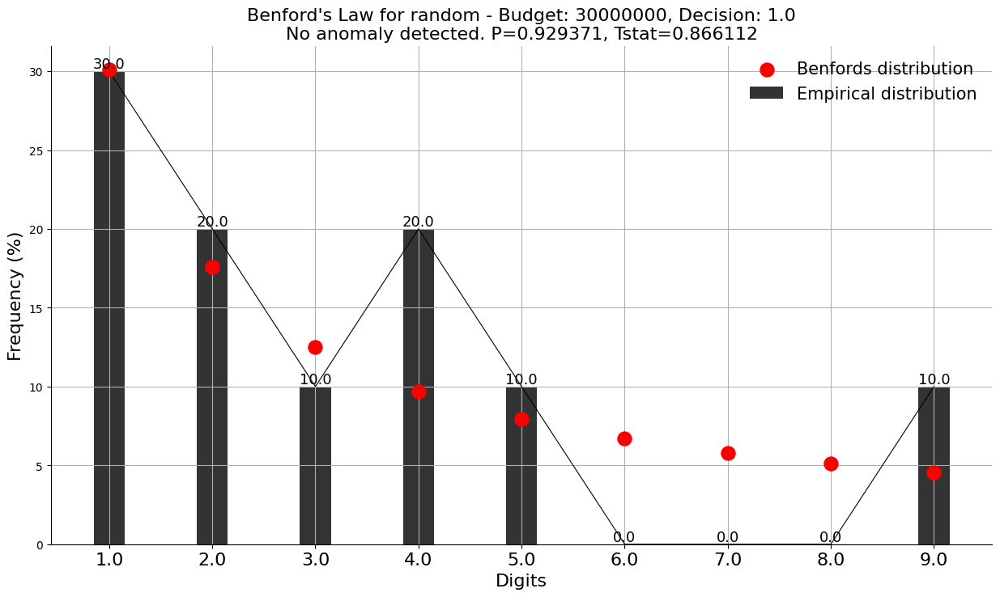

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.196862, Tstat=6.03077


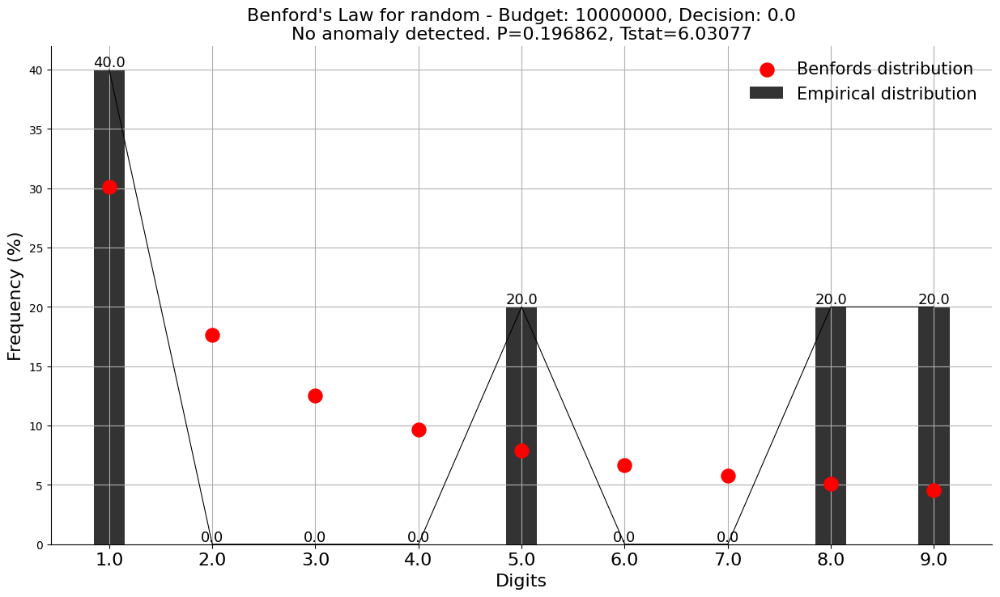

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.021819, Tstat=11.4636


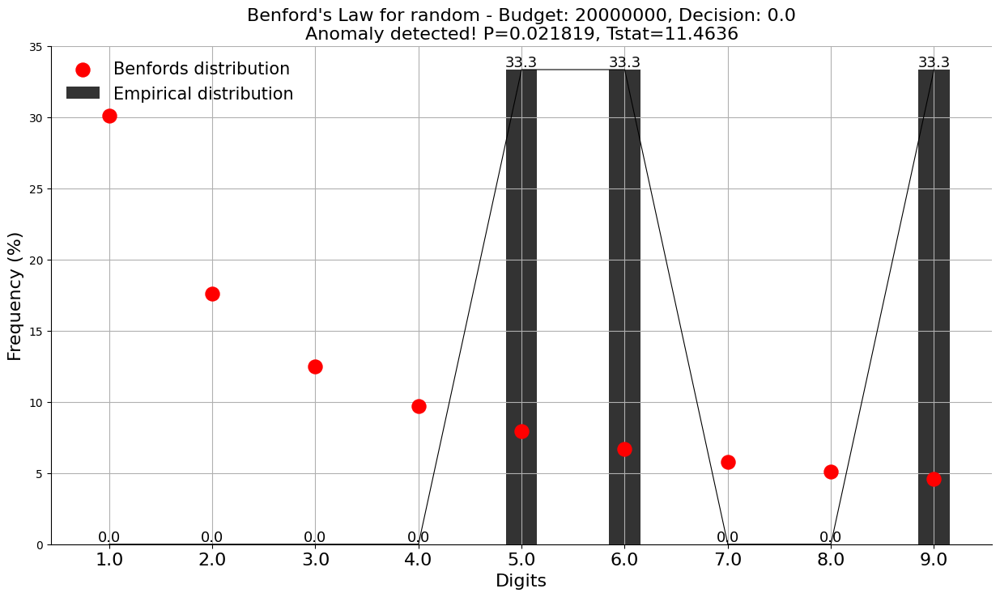

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0163853, Tstat=12.1336


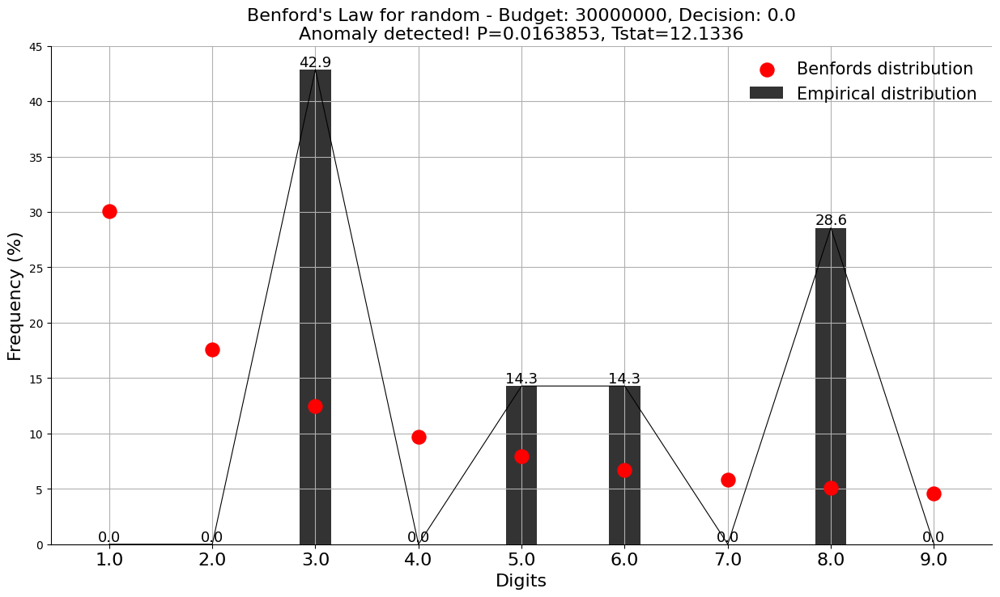

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00638448, Tstat=14.3043


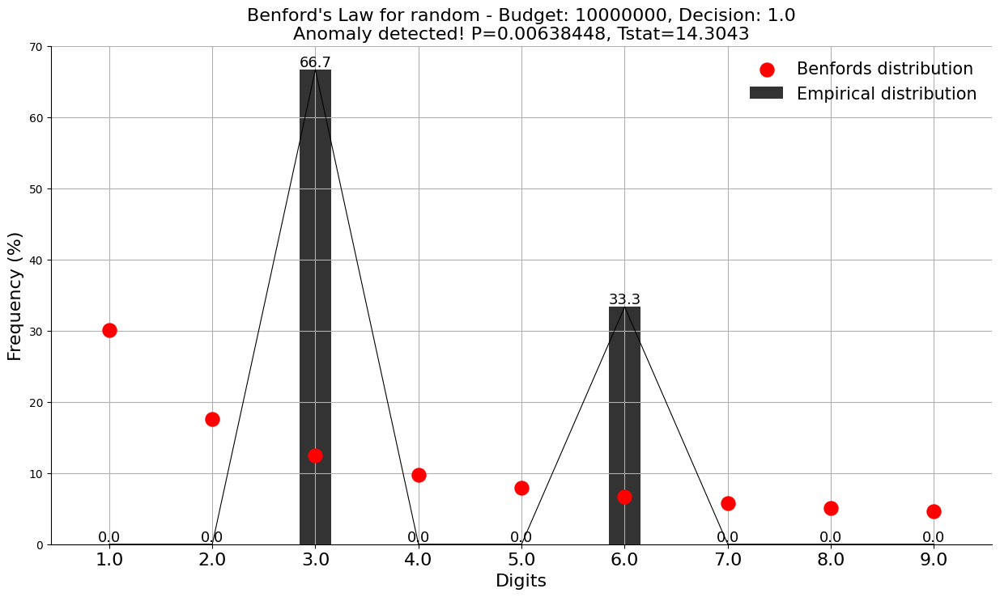

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0140021, Tstat=12.499


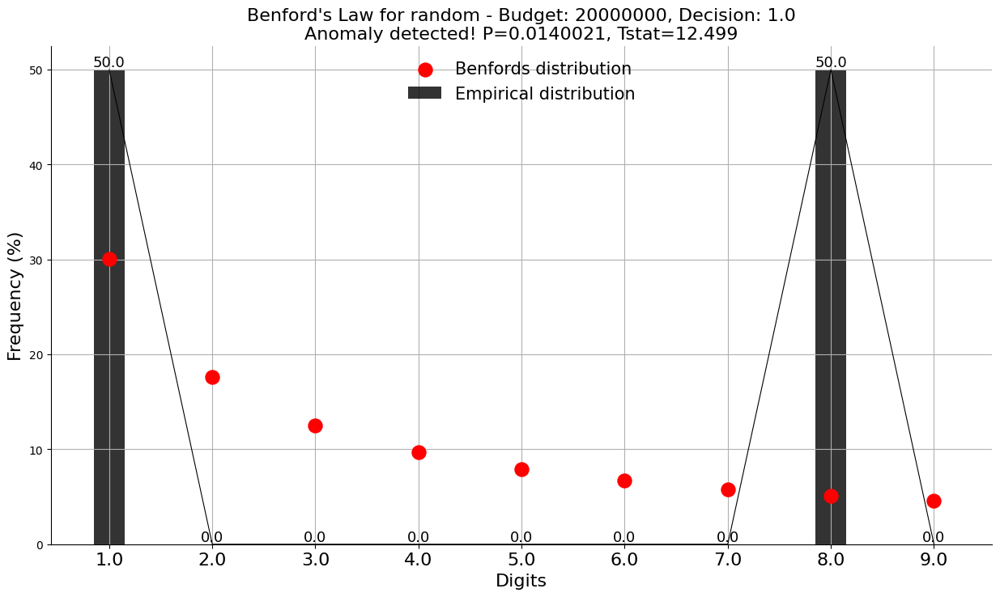

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.10195, Tstat=7.73085


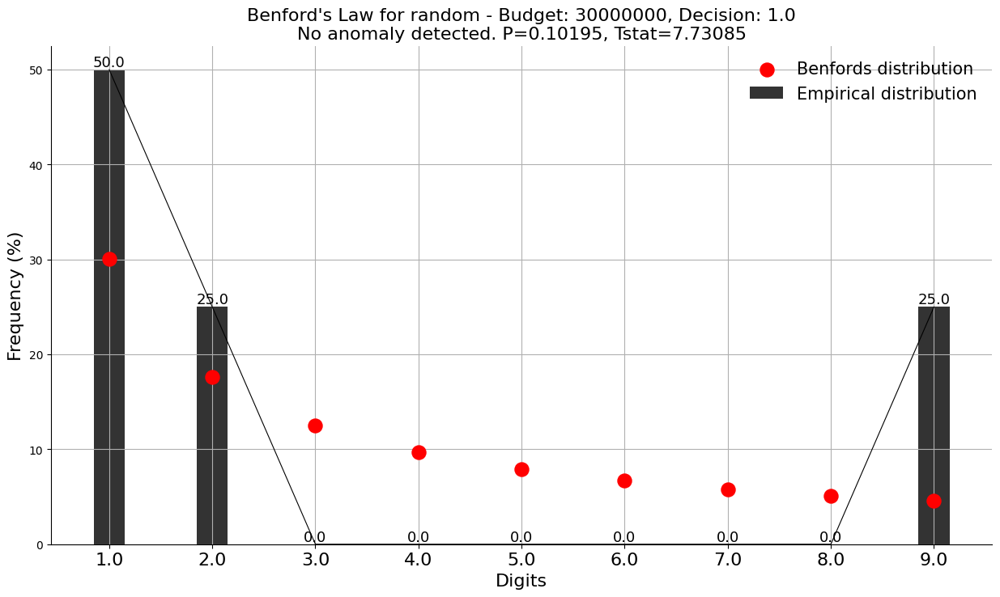

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0386294, Tstat=10.1091


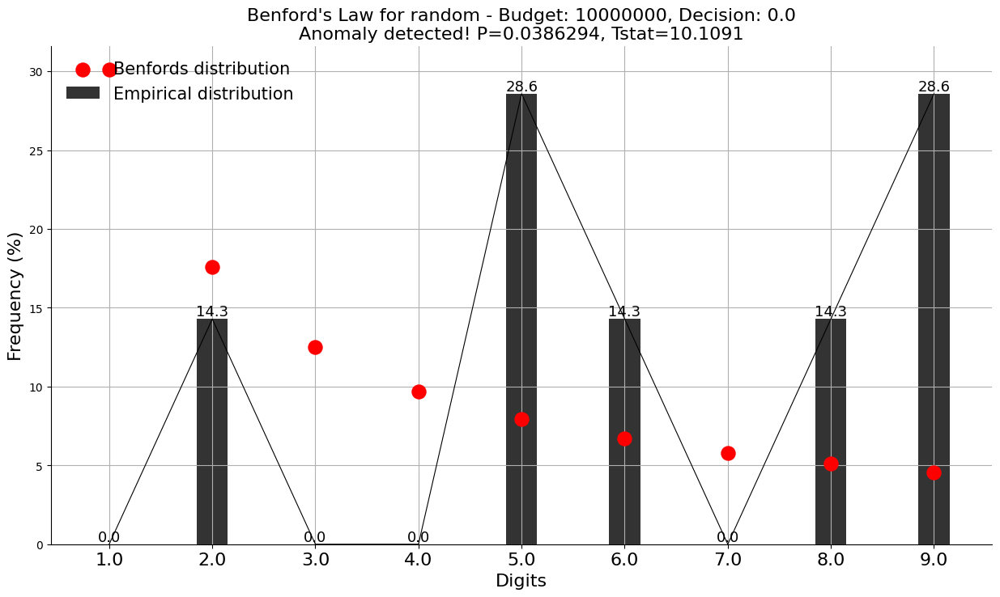

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0175504, Tstat=11.9734


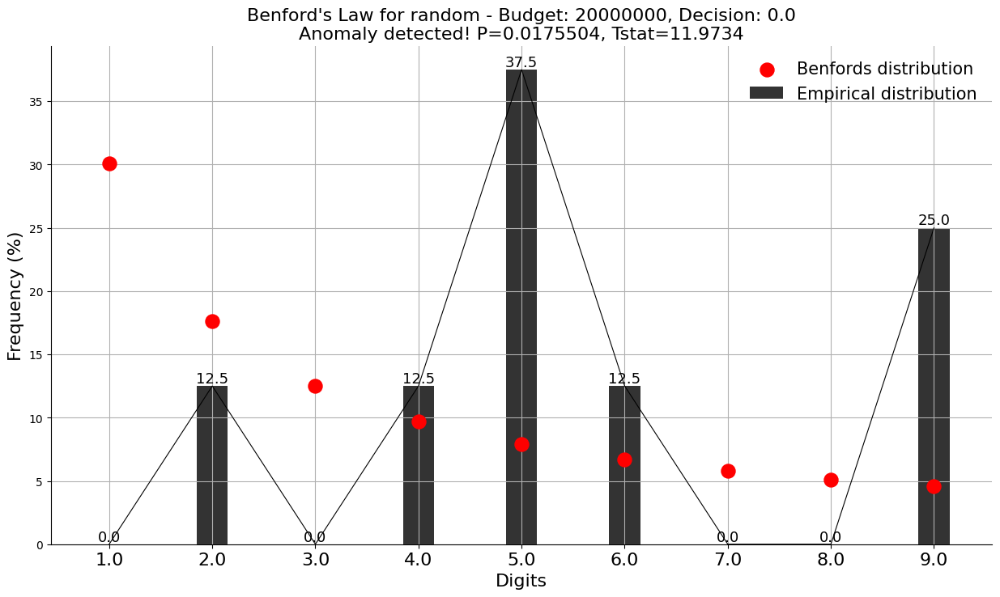

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.315575, Tstat=4.73508


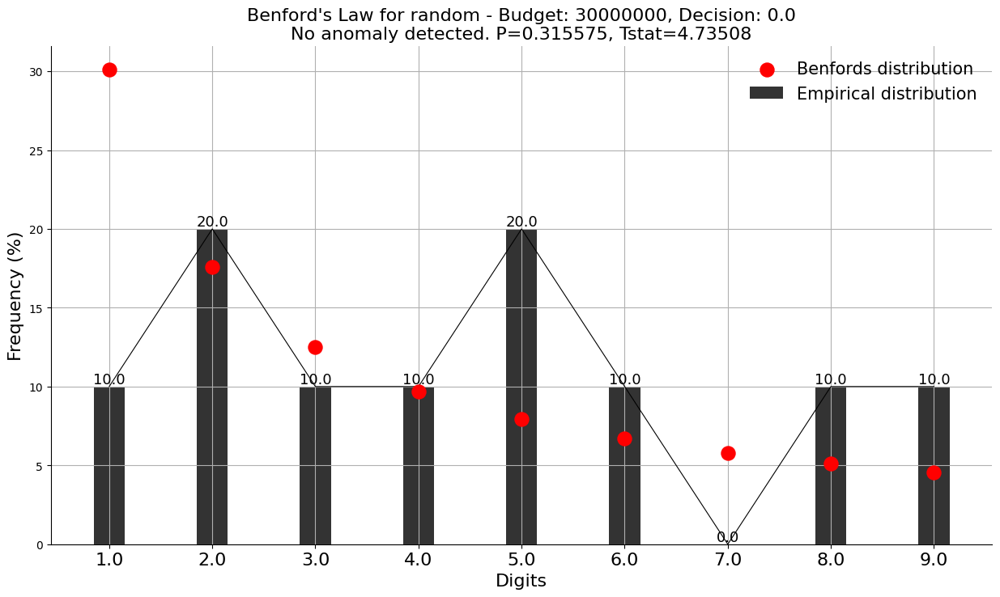

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0388277, Tstat=10.0968


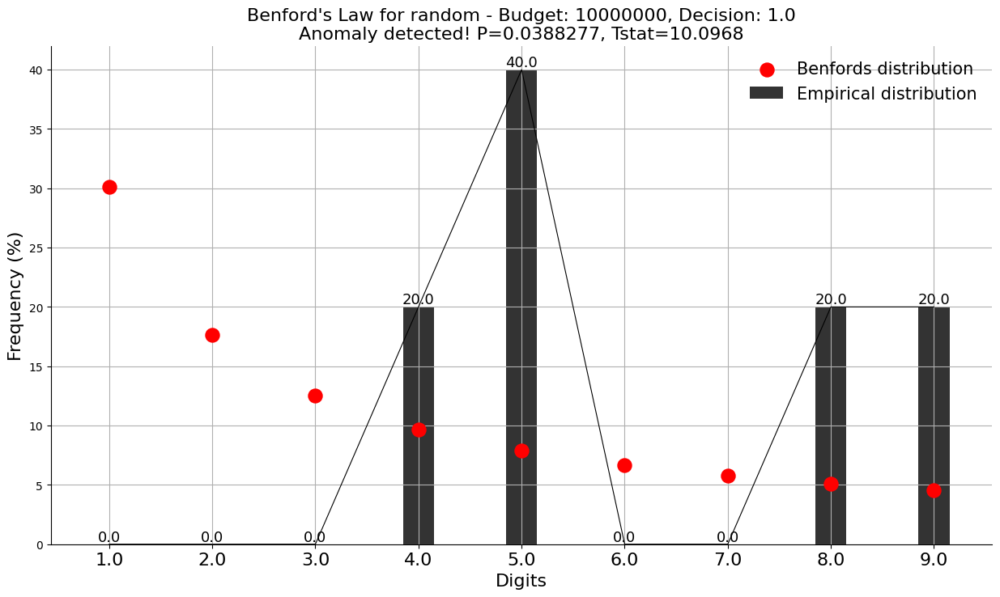

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.000759068, Tstat=19.0769


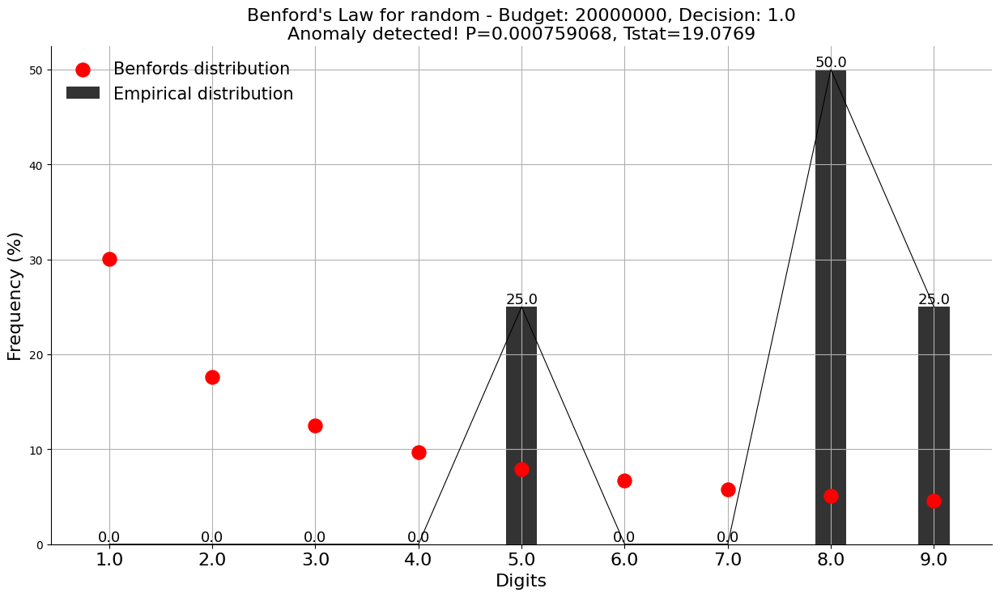

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0159616, Tstat=12.1946


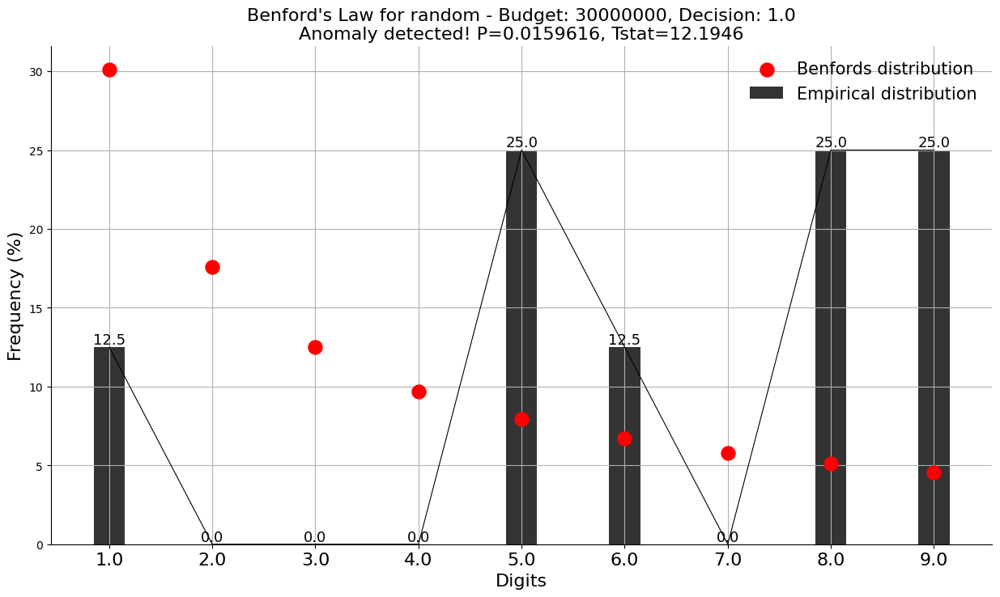

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0299526, Tstat=10.7157


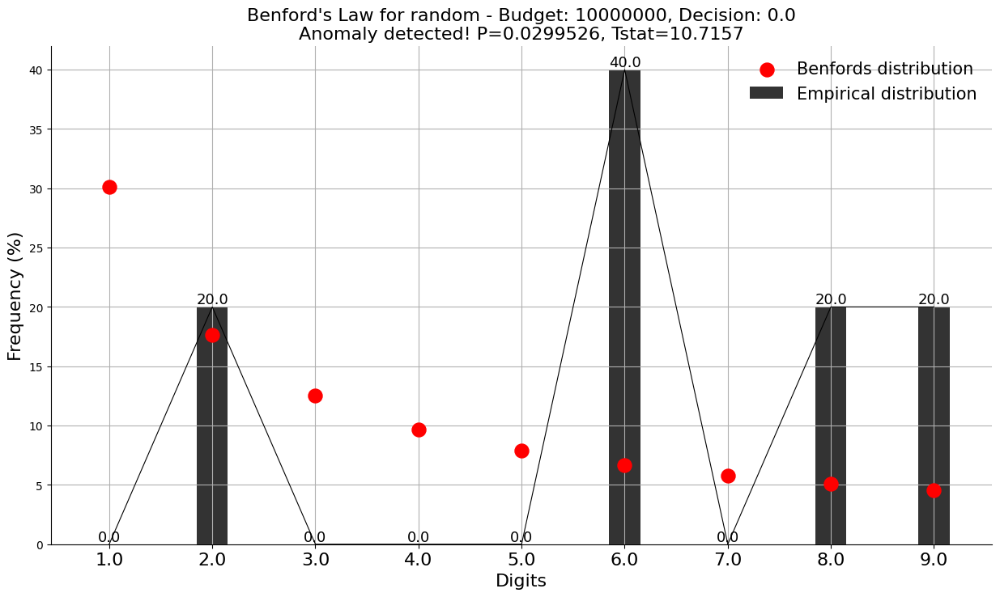

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.381597, Tstat=4.18461


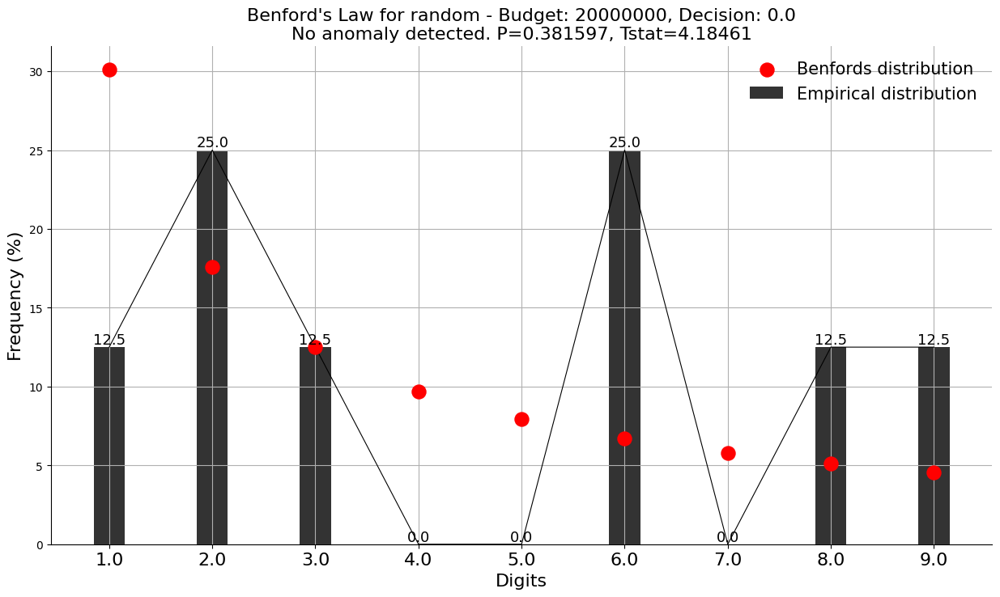

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00484497, Tstat=14.9317


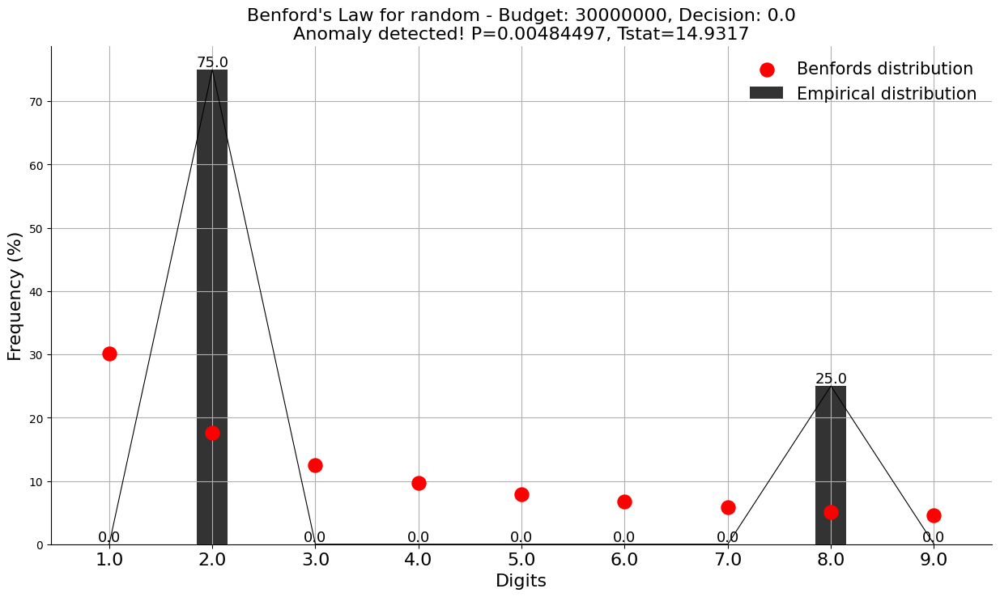

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.125009, Tstat=7.21386


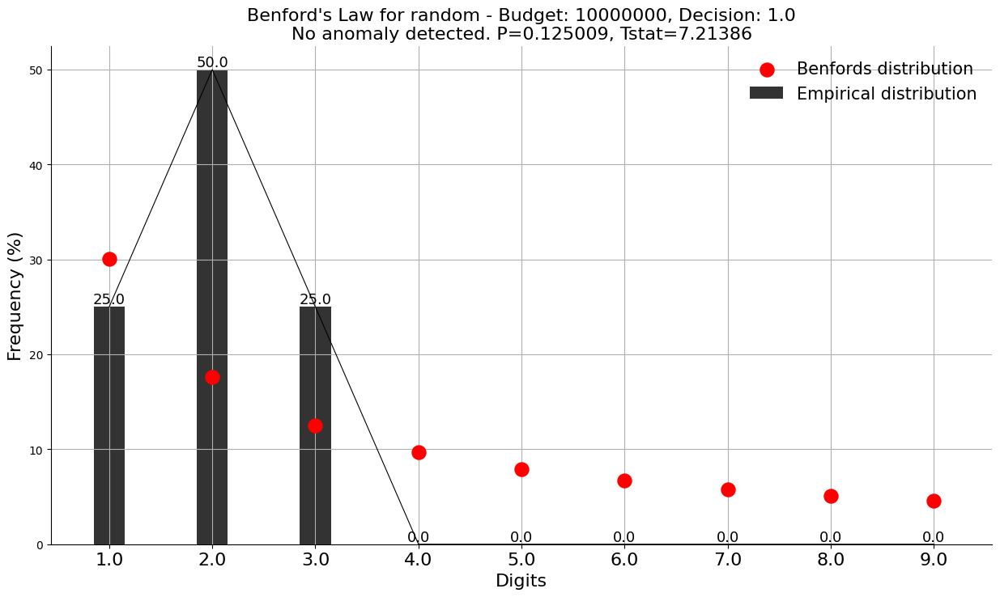

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0625288, Tstat=8.94344


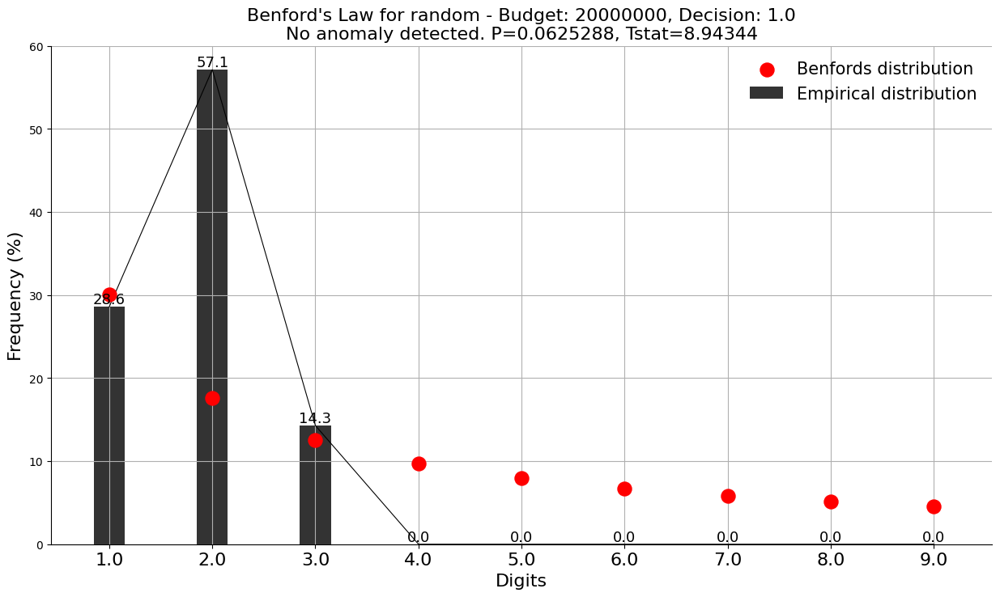

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0638947, Tstat=8.89053


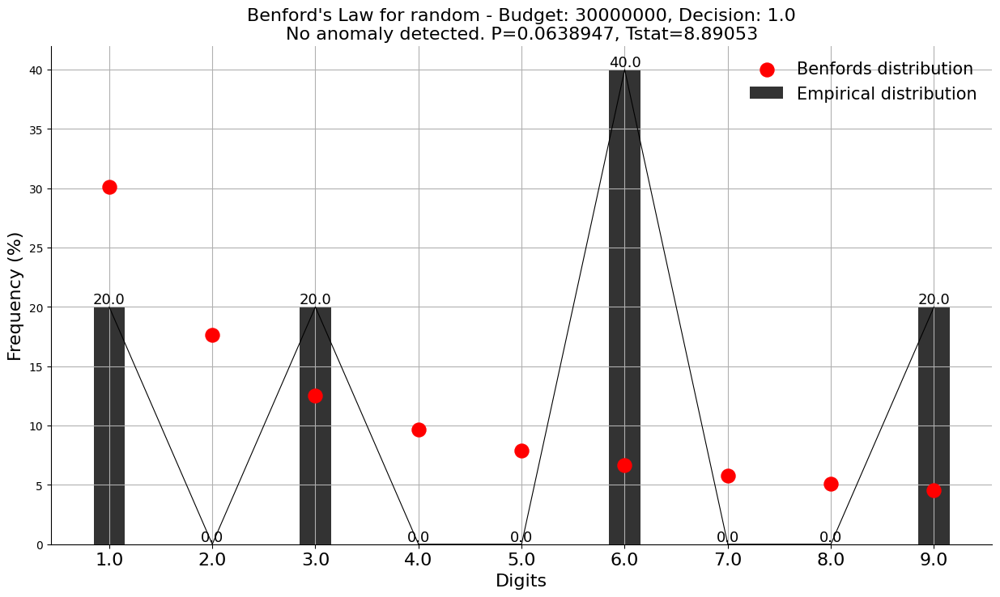

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.276429, Tstat=5.10765


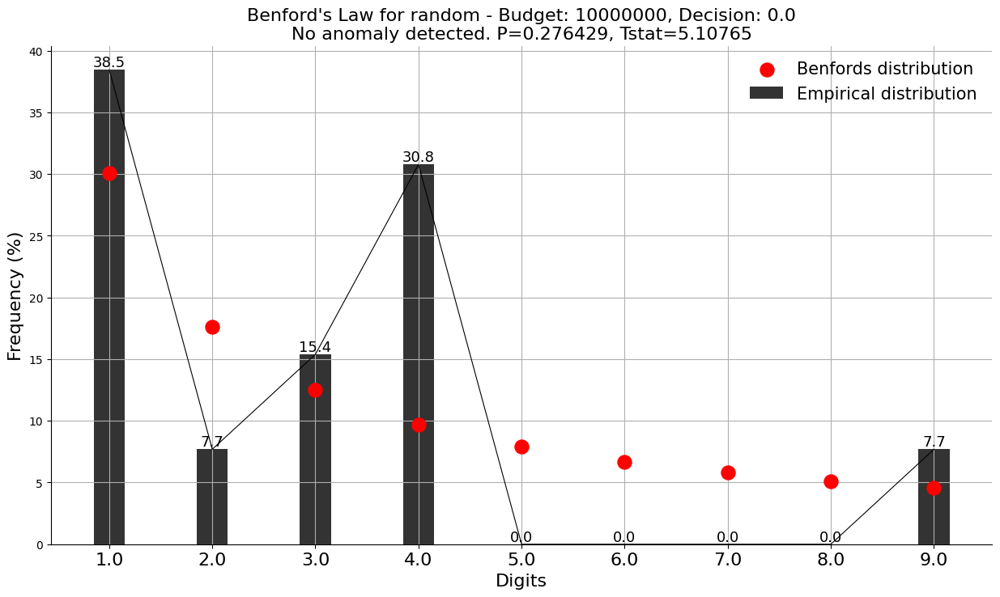

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0797203, Tstat=8.34522


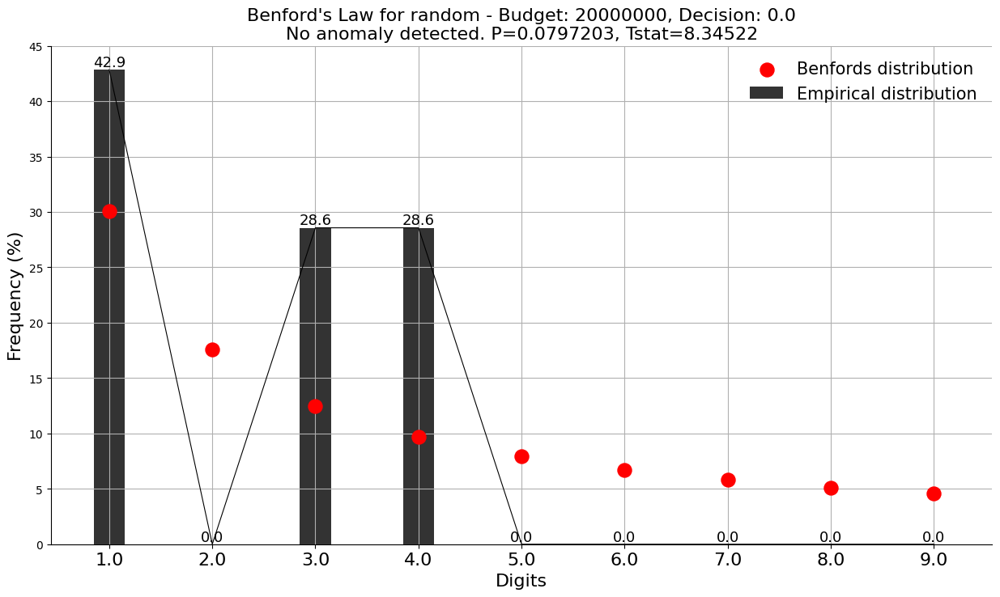

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.359999, Tstat=4.35573


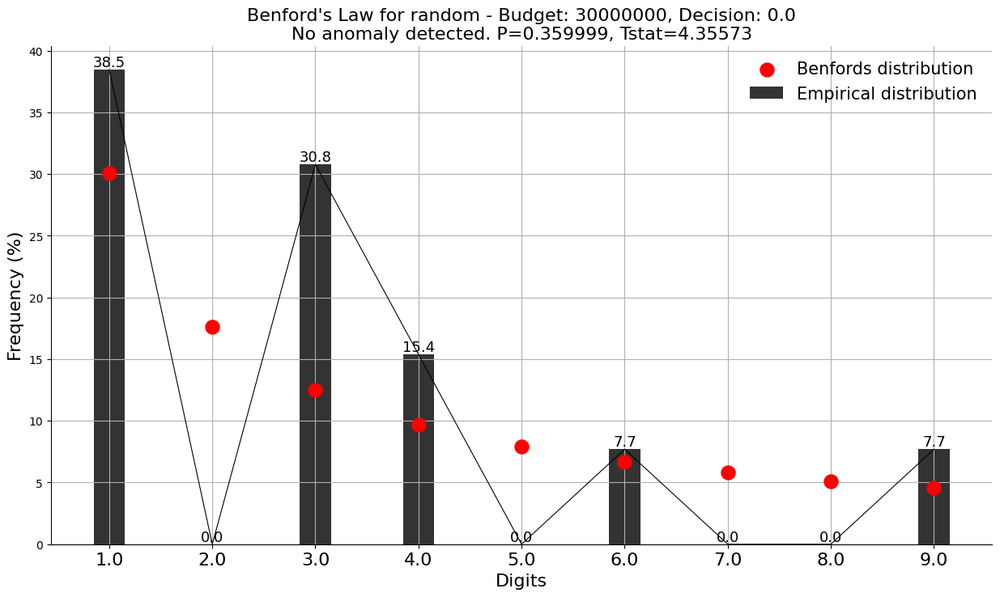

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.331621, Tstat=4.59335


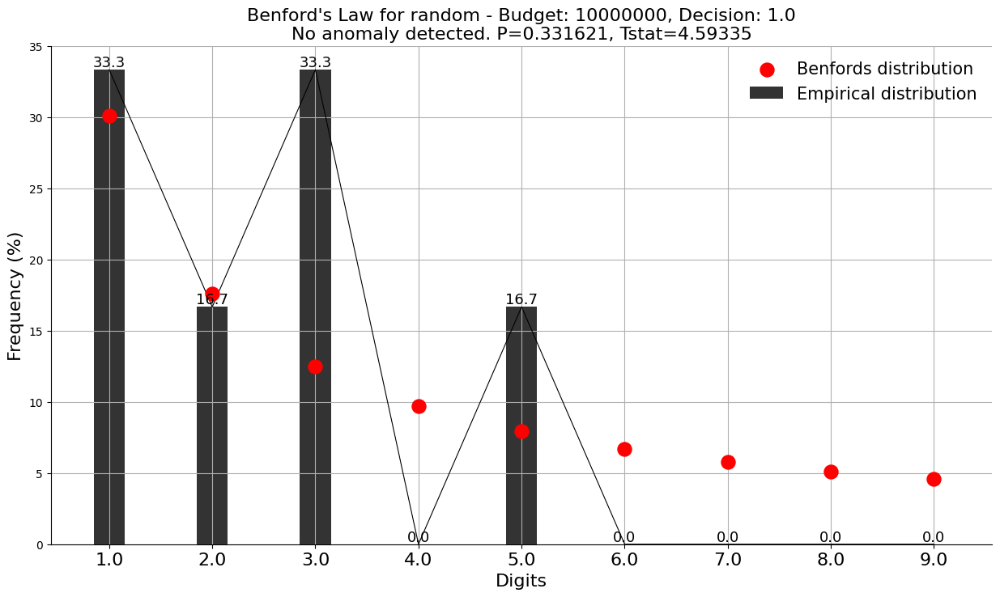

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.093476, Tstat=7.94869


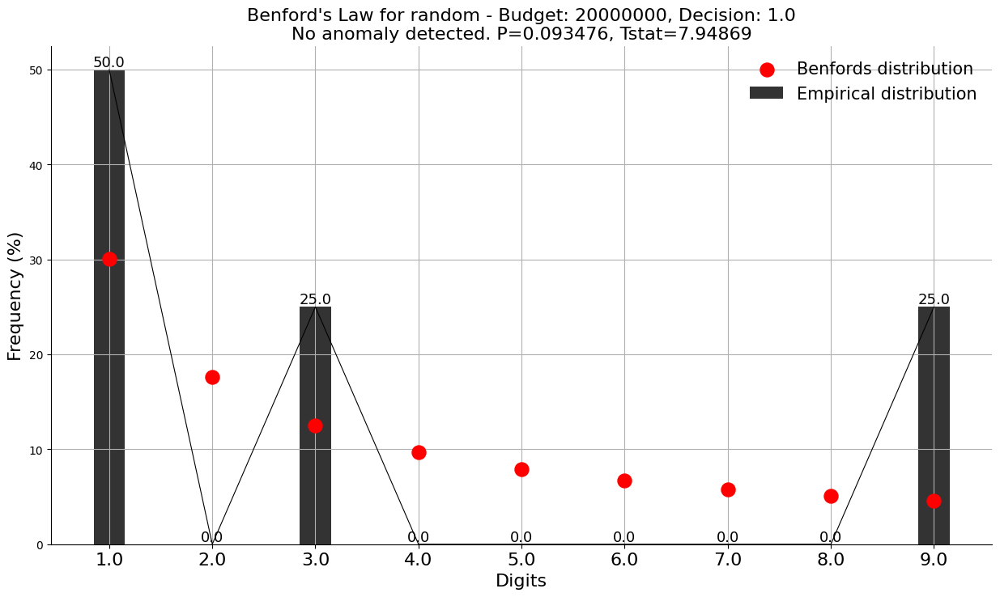

[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.291242, Tstat=4.96177


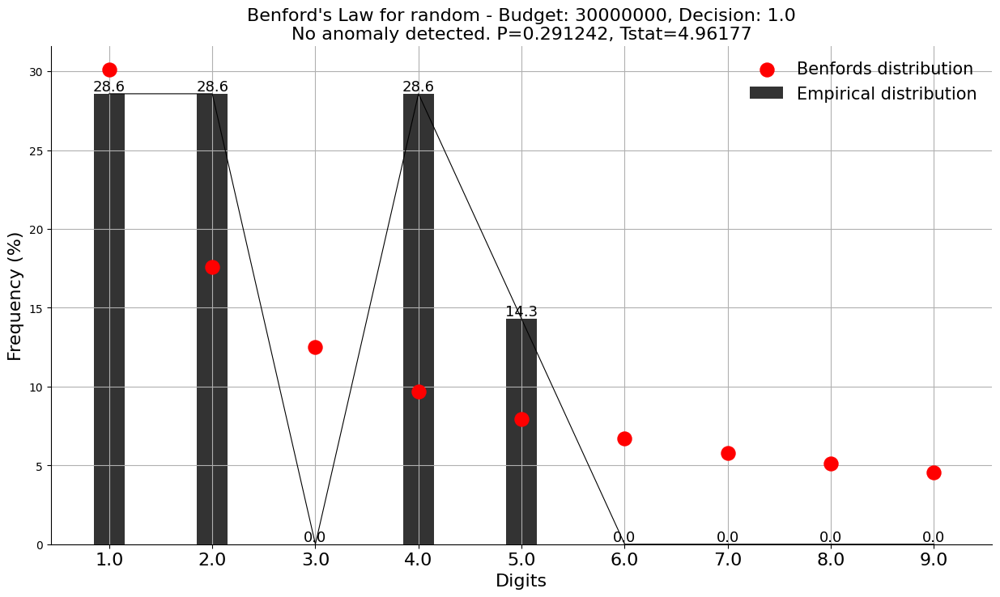

Summary results saved to: .temp/experiment_results/insurenv/benford_summary_results.csv
Grid plot saved to: .temp/experiment_results/insurenv/benford_grid_dqn.png
Grid plot saved to: .temp/experiment_results/insurenv/benford_grid_random.png


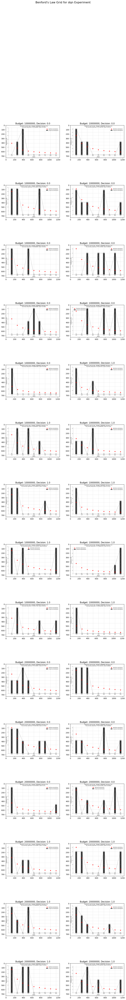




In [51]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from benfordslaw import benfordslaw

# Create a directory to store the results if it doesn't exist
results_dir = ".temp/experiment_results/insurenv"
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

# Initialize the Benford's Law analyzer with method='ks' for Kolmogorov-Smirnov test
bl = benfordslaw(method='freedman')

# Assuming your dataset is loaded into a DataFrame called 'data'
# The dataset includes columns: experiment, episodes, rewards, wc, woc, valor_indenizacao, initial_budget, decision

# Filter for "random" and "dqn" experiments
experiments_of_interest = ['random', 'dqn']
filtered_data = data[data['experiment'].isin(experiments_of_interest)]

# Group the data by experiment, episodes, decision, and initial_budget
groups = filtered_data.groupby(['experiment', 'episodes', 'decision', 'initial_budget'])

# Prepare a list to store summary results
summary_results = []

# Dictionary to store the figures for grid plots
final_figures_grid = {}

# Iterate over each group and apply Benford's Law analysis
for (experiment, episodes, decision, initial_budget), group in groups:
    valor_indenizacao = group['valor_indenizacao'].dropna().values
    
    if len(valor_indenizacao) == 0:
        print(f"No indemnity values available for Experiment: {experiment}, Episodes: {episodes}, Decision: {decision}, Initial Budget: {initial_budget}")
        continue
    
    # Apply Benford's Law with Kolmogorov-Smirnov test to the valor_indenizacao values
    results = bl.fit(valor_indenizacao)
    
    # Save KS results to the summary list
    summary_results.append({
        'experiment': experiment,
        'episodes': episodes,
        'decision': decision,
        'initial_budget': initial_budget,
        'KS_stat': results['t'],  # The test statistic for the KS test
        'p_value': results['P'],  # The p-value for the KS test
        'P_significant': results['P_significant'],  # whether it's significant
        'percentage_emp': results['percentage_emp']  # empirical distribution
    })
    
    # Collect the plot for the current experiment to create a grid later
    if experiment not in final_figures_grid:
        final_figures_grid[experiment] = []
    
    # Store plot data in the list for the grid creation
    final_figures_grid[experiment].append((initial_budget, decision, bl.plot(title=f"Benford's Law for {experiment} - Budget: {initial_budget}, Decision: {decision}")[0]))

# Create a summary DataFrame
summary_df = pd.DataFrame(summary_results)

# Save the summary DataFrame to the results directory
summary_filename = f"{results_dir}/benford_summary_results.csv"
summary_df.to_csv(summary_filename, index=False)
print(f"Summary results saved to: {summary_filename}")

# Now create the grid of plots for each experiment (random, dqn), ordered by budget and decision

for experiment, plots in final_figures_grid.items():
    # Sort plots by initial_budget and decision
    plots.sort(key=lambda x: (x[0], x[1]))  # Sorting by initial_budget and decision
    
    # Number of rows and columns for the grid
    num_plots = len(plots)
    num_cols = 2  # Fixing number of columns
    num_rows = (num_plots + num_cols - 1) // num_cols  # Calculate number of rows needed
    
    # Create the figure and axes for the grid
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(12, num_rows * 6))
    fig.suptitle(f"Benford's Law Grid for {experiment} Experiment", fontsize=16)
    
    # Flatten the axes array if there are multiple rows and columns
    if num_rows > 1:
        axes = axes.flatten()
    else:
        axes = [axes]
    
    # Plot each subplot in the grid
    for i, (initial_budget, decision, plot_fig) in enumerate(plots):
        # Clear the axis and plot in the grid axis
        axes[i].clear()
        plot_fig.axes[0].get_figure().axes[0].cla()  # Clear the axis of the old figure
        axes[i].imshow(plot_fig.canvas.buffer_rgba())
        axes[i].set_title(f"Budget: {initial_budget}, Decision: {decision}")
    
    # Hide any unused axes
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
    
    # Save the final grid figure
    grid_filename = f"{results_dir}/benford_grid_{experiment}.png"
    fig.savefig(grid_filename)
    print(f"Grid plot saved to: {grid_filename}")



[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0136084, Tstat=12.5651


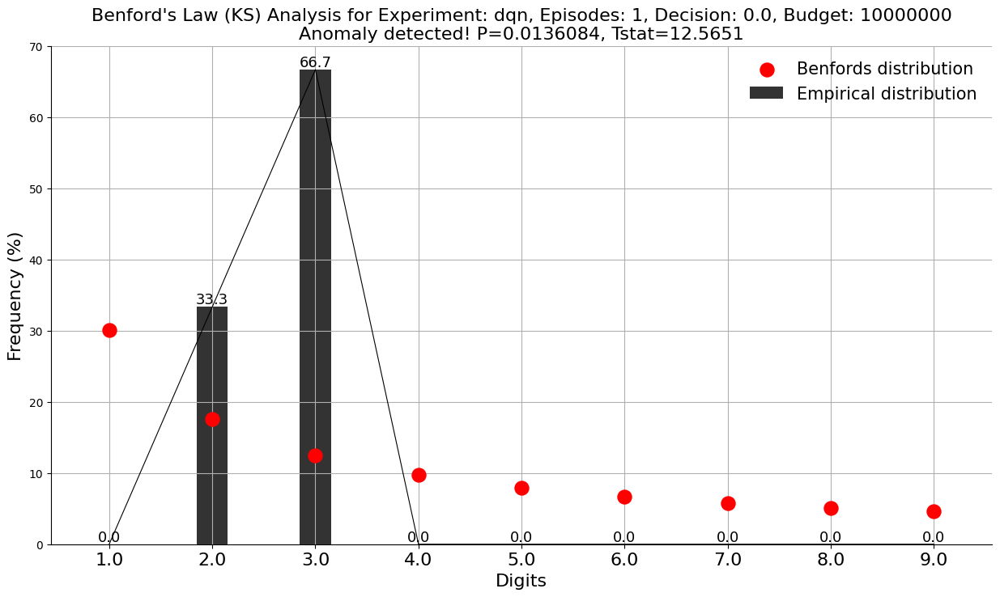

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep1_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.310847, Tstat=4.77797


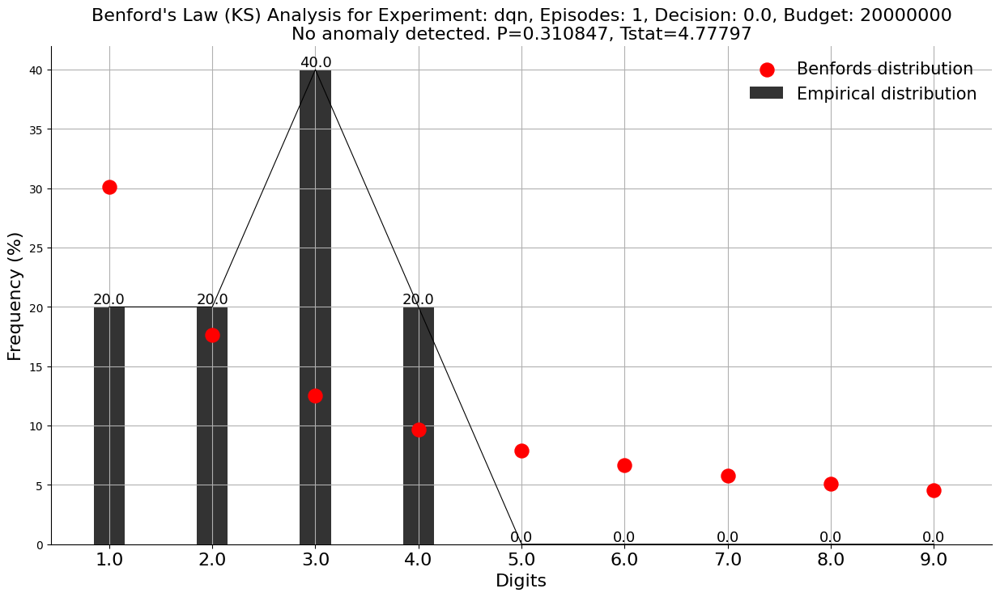

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep1_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0307243, Tstat=10.6553


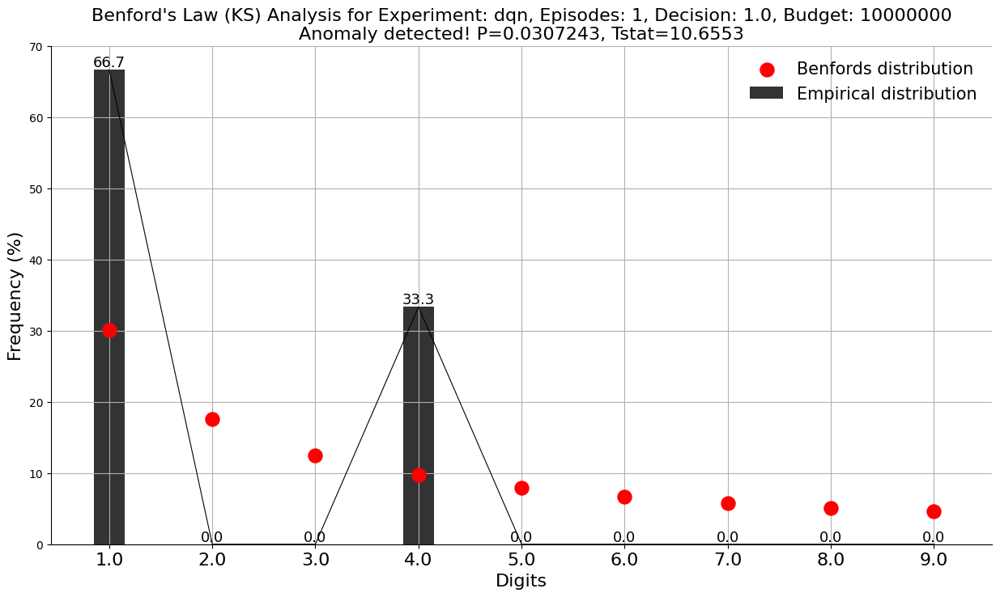

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep1_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.131892, Tstat=7.07666


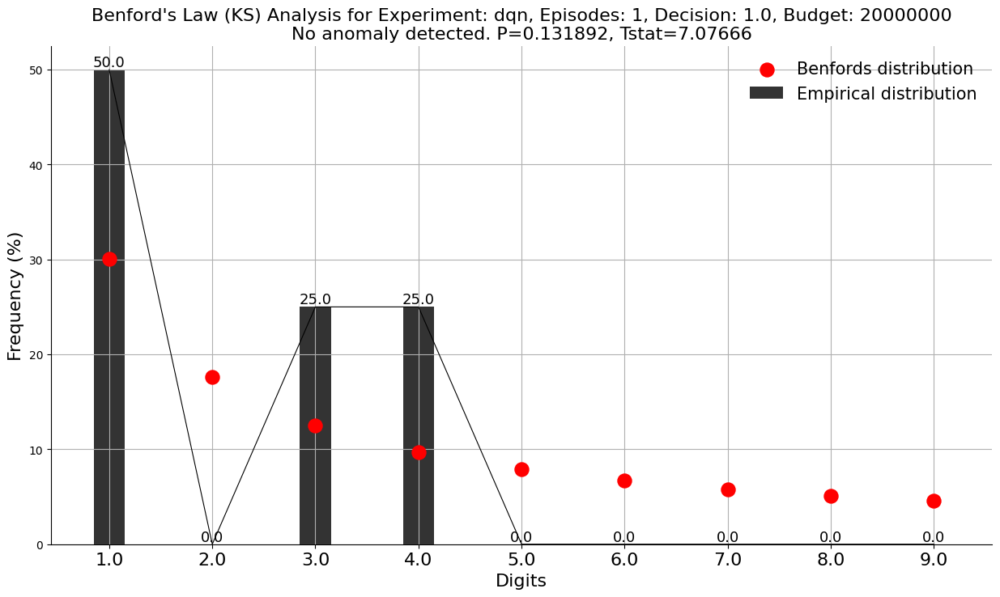

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep1_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.326749, Tstat=4.63579


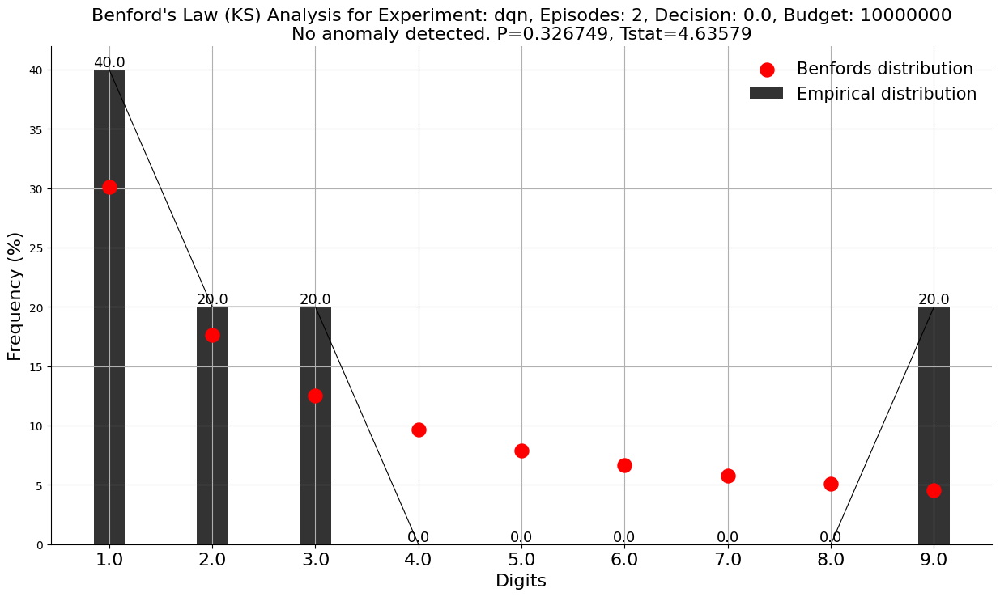

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep2_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.142155, Tstat=6.88385


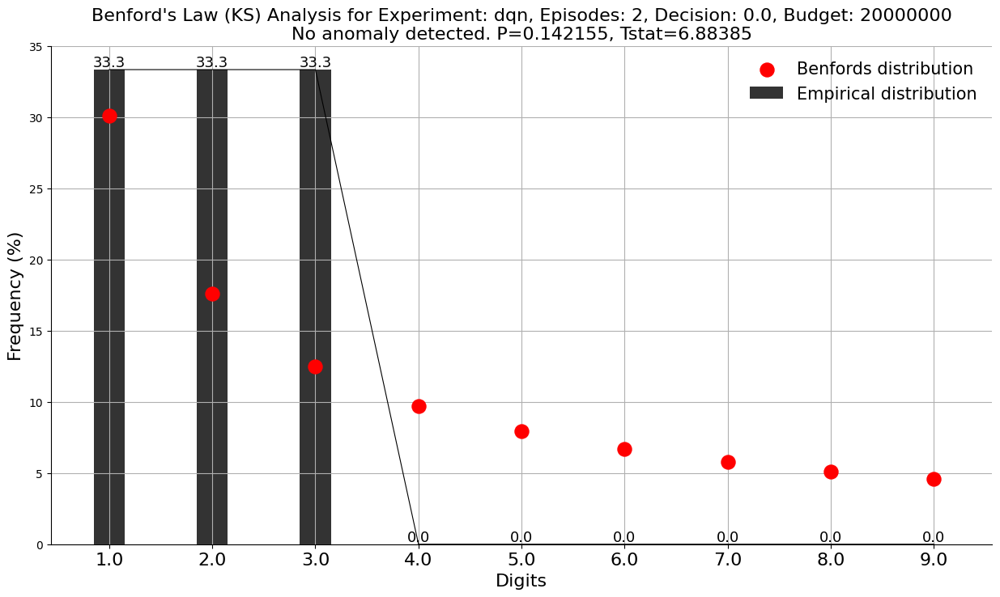

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep2_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0426635, Tstat=9.87067


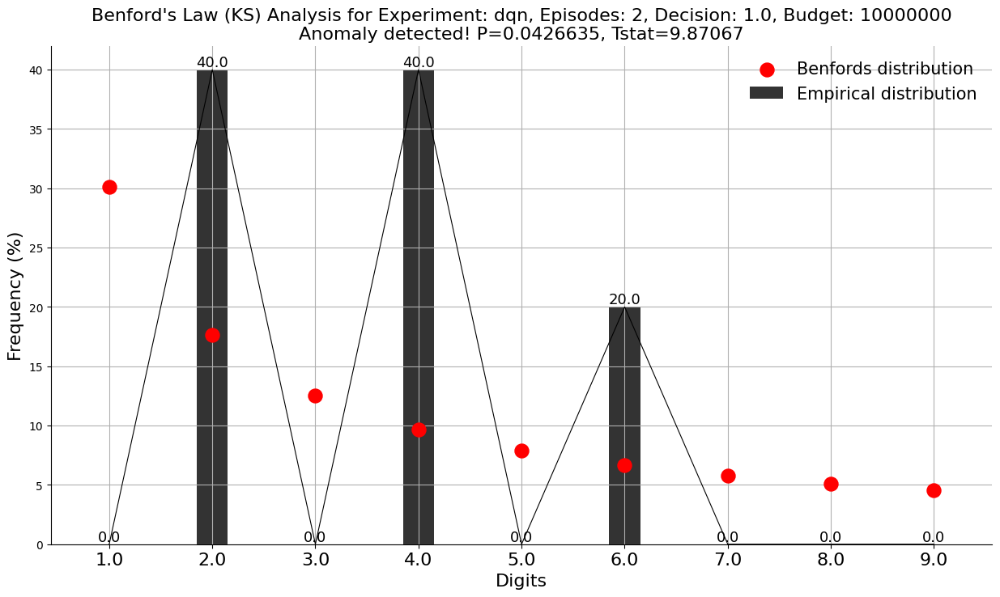

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep2_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.233203, Tstat=5.57514


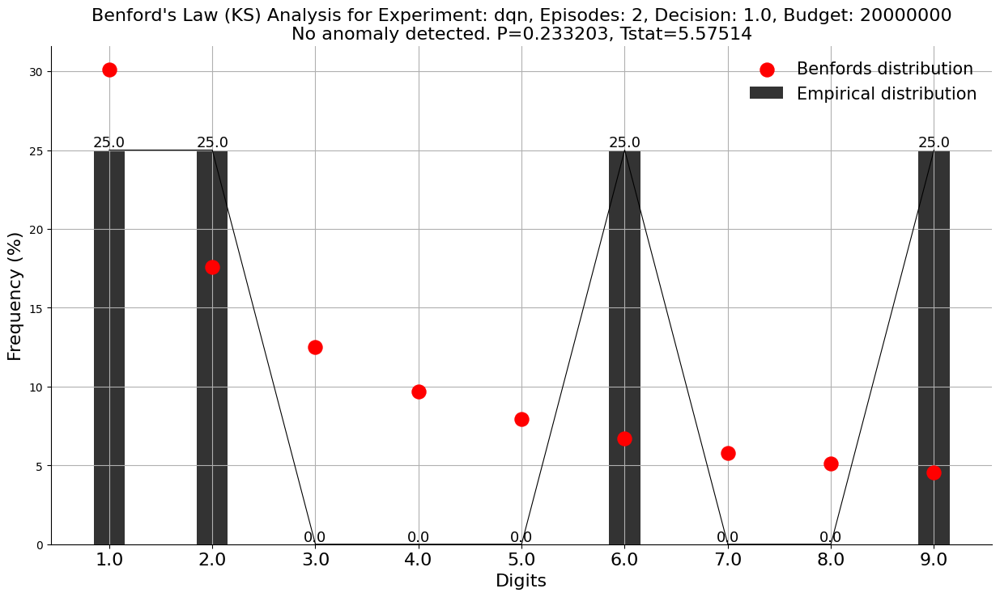

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep2_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.119073, Tstat=7.33791


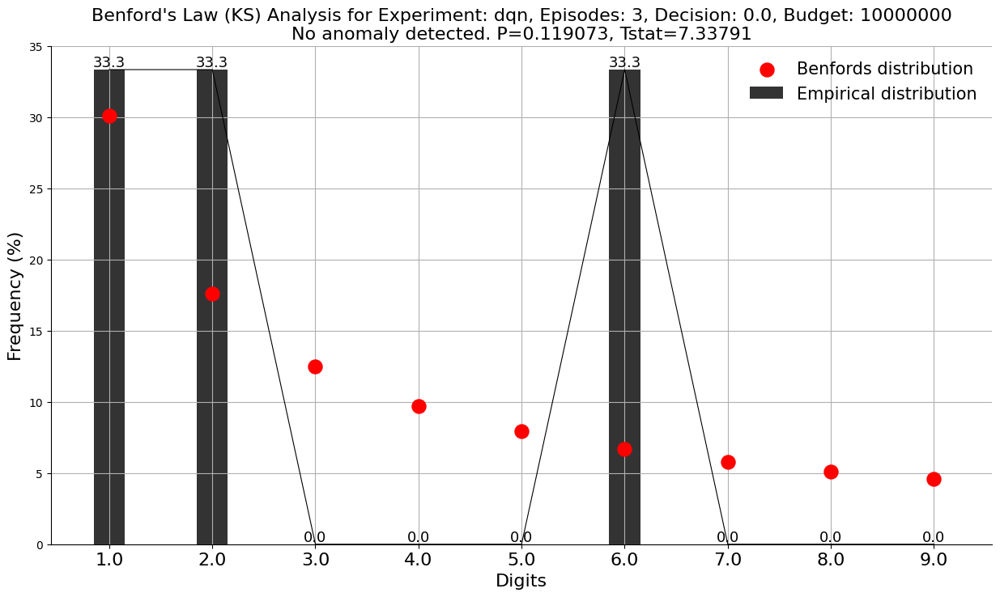

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep3_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.667268, Tstat=2.37435


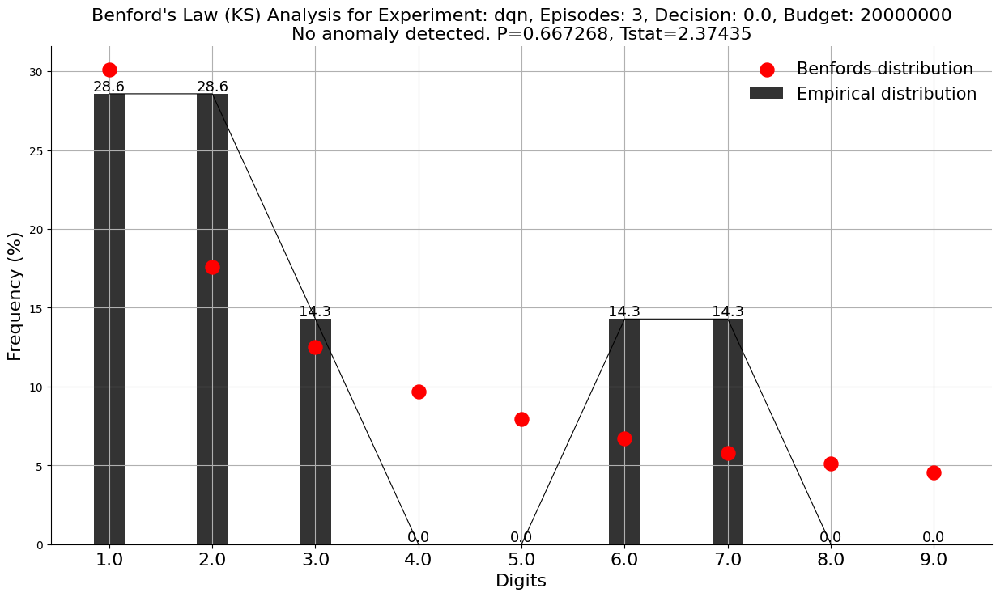

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep3_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0683828, Tstat=8.72393


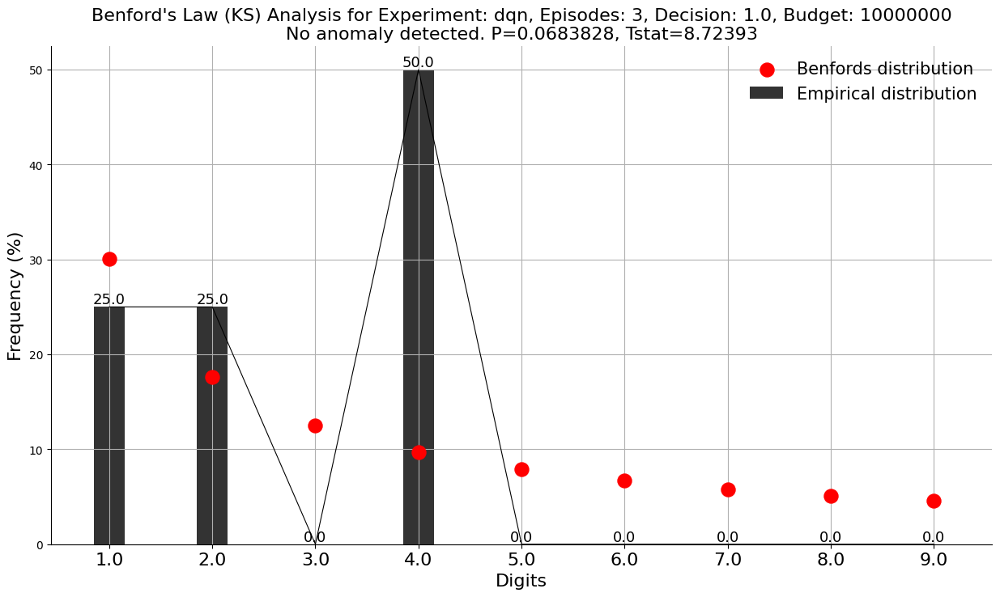

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep3_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0896608, Tstat=8.05286


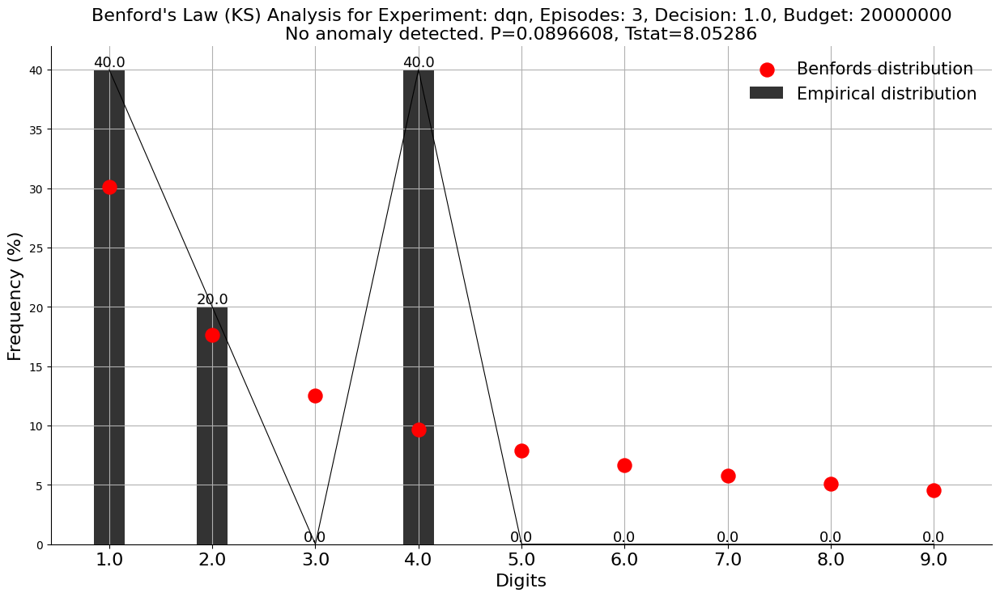

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep3_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.406326, Tstat=3.99764


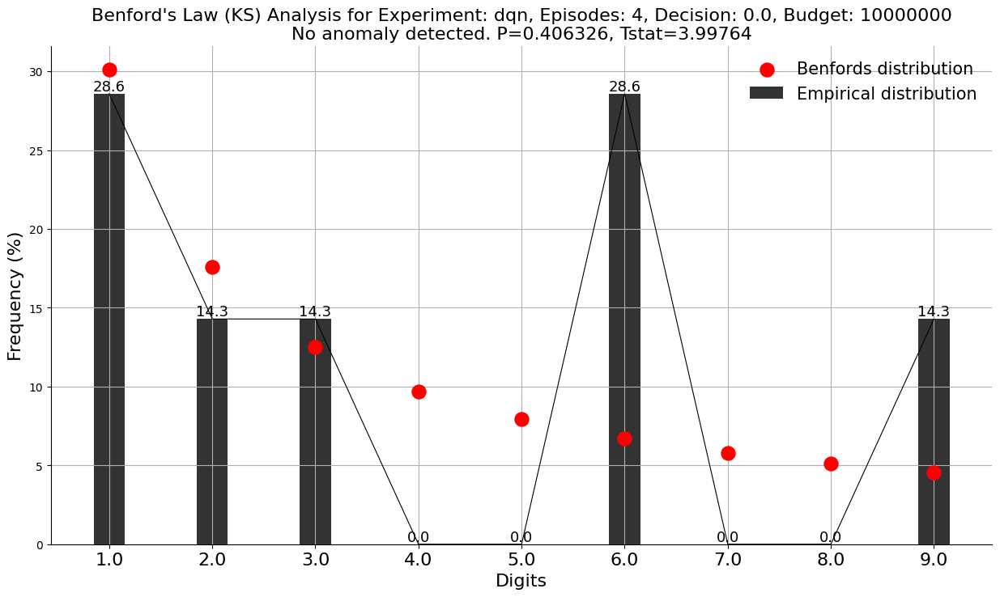

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep4_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0718944, Tstat=8.60065


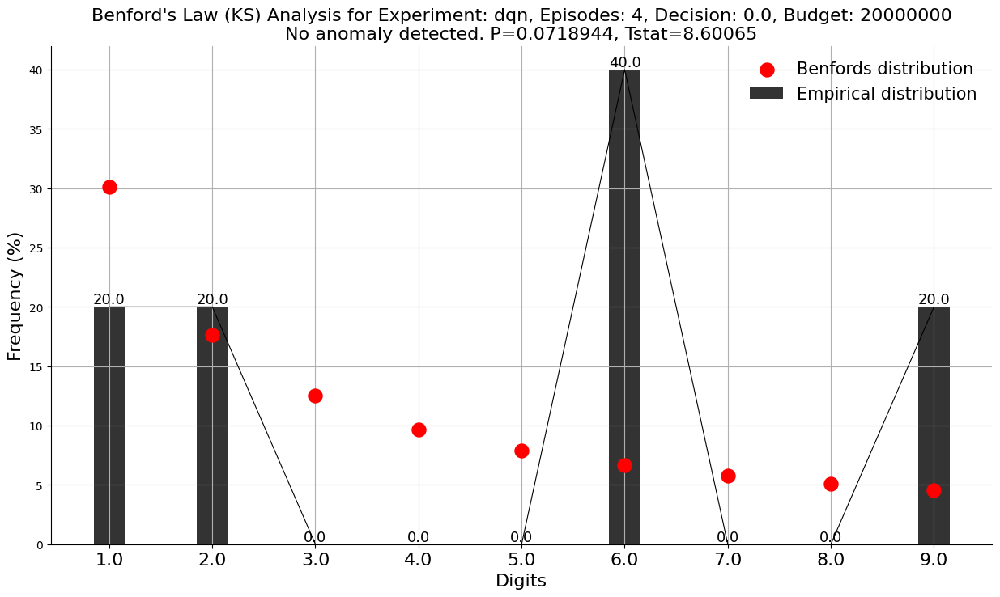

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep4_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.109918, Tstat=7.54094


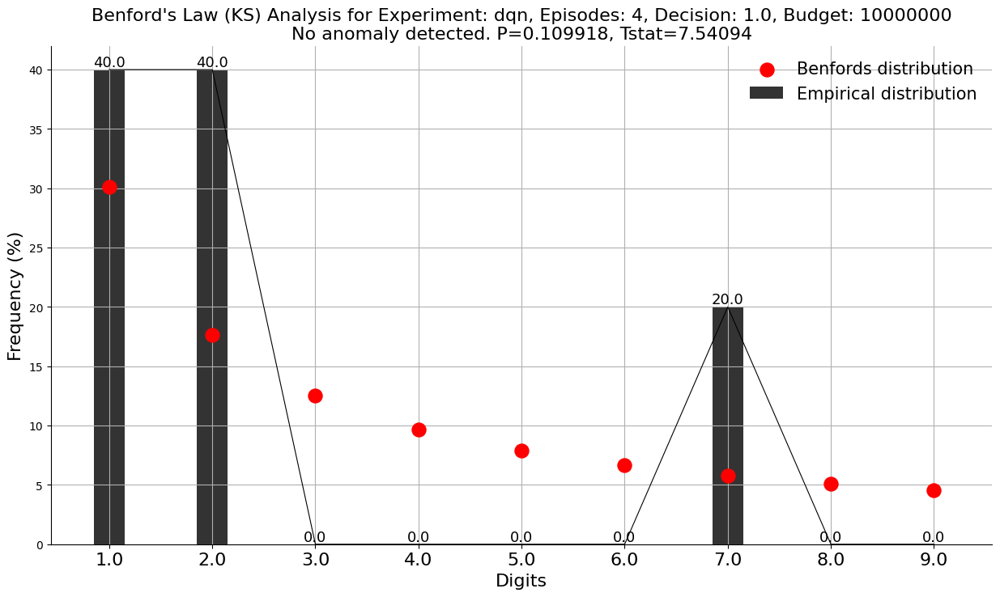

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep4_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.344957, Tstat=4.47974


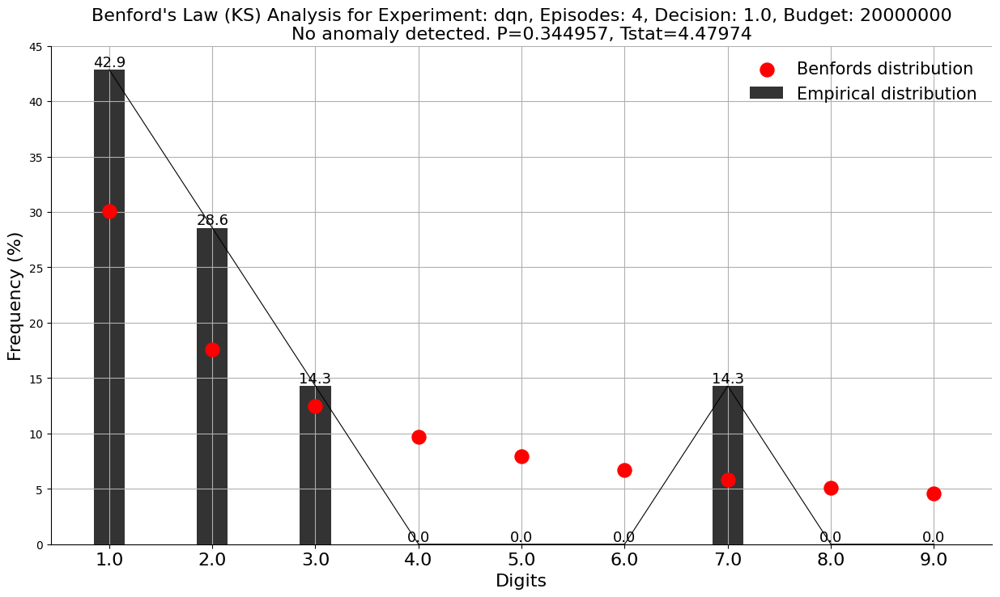

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep4_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


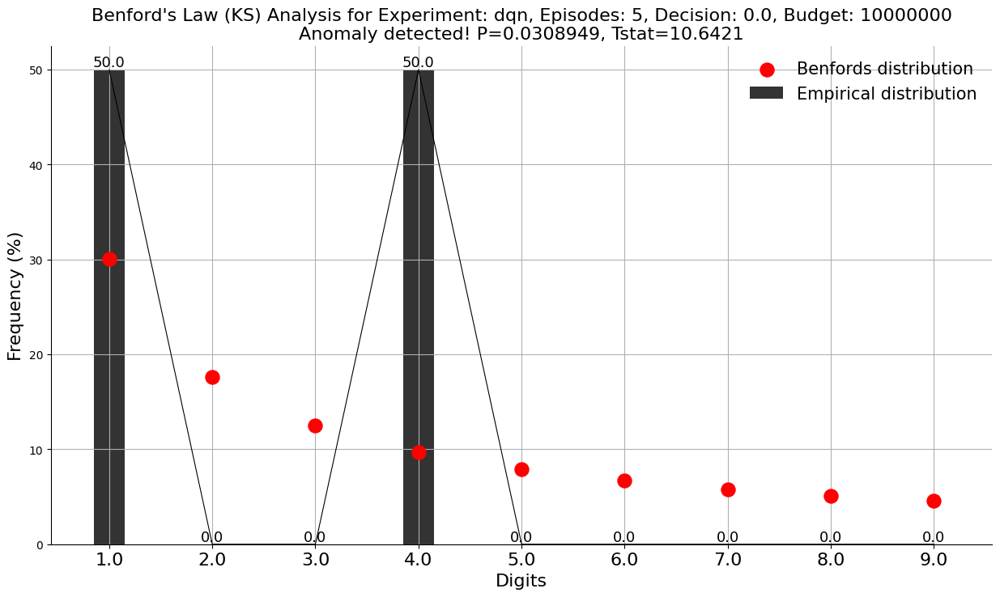

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep5_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0155856, Tstat=12.25


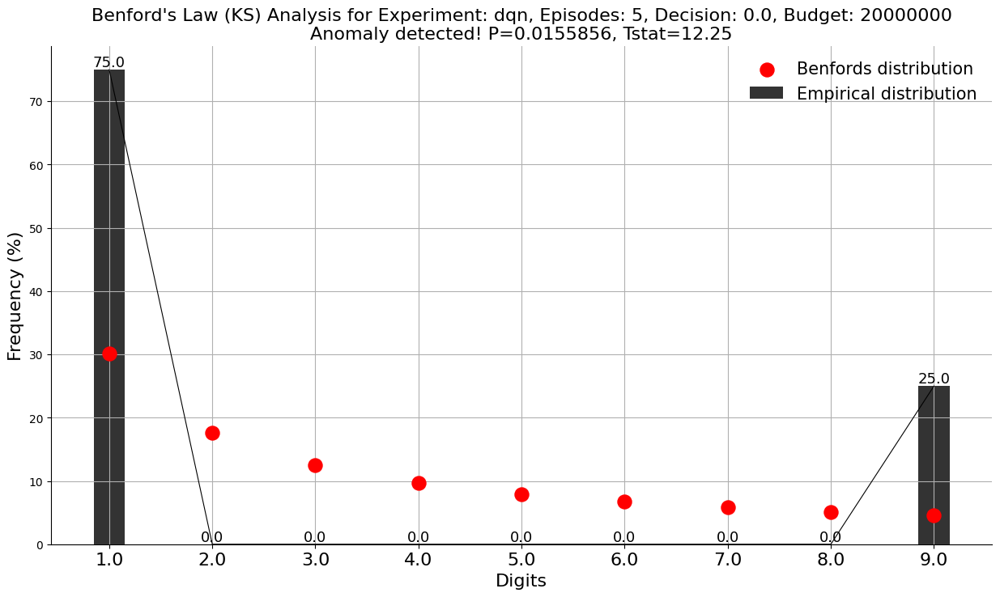

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep5_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0163313, Tstat=12.1412


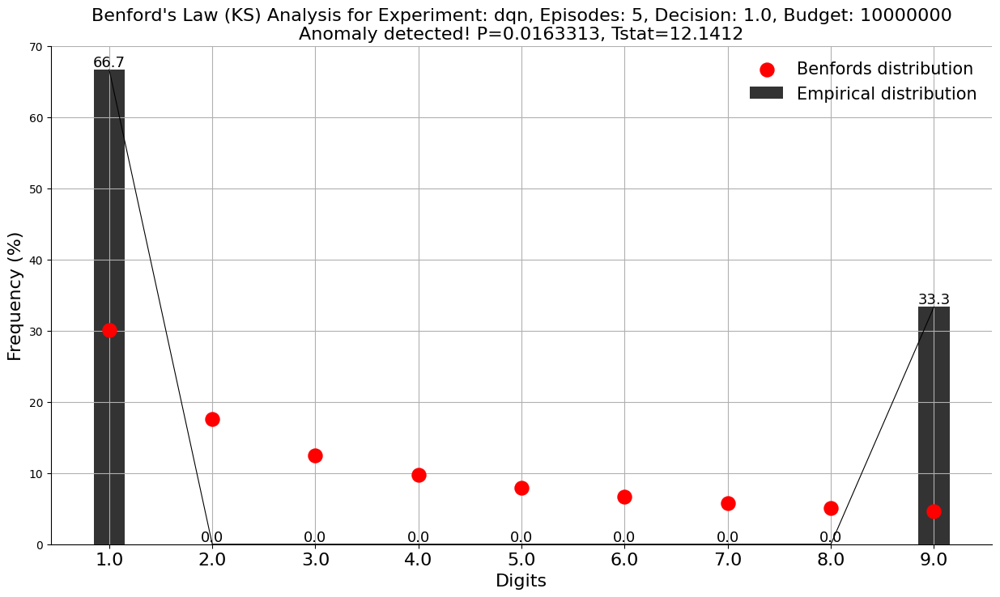

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep5_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.128483, Tstat=7.14376


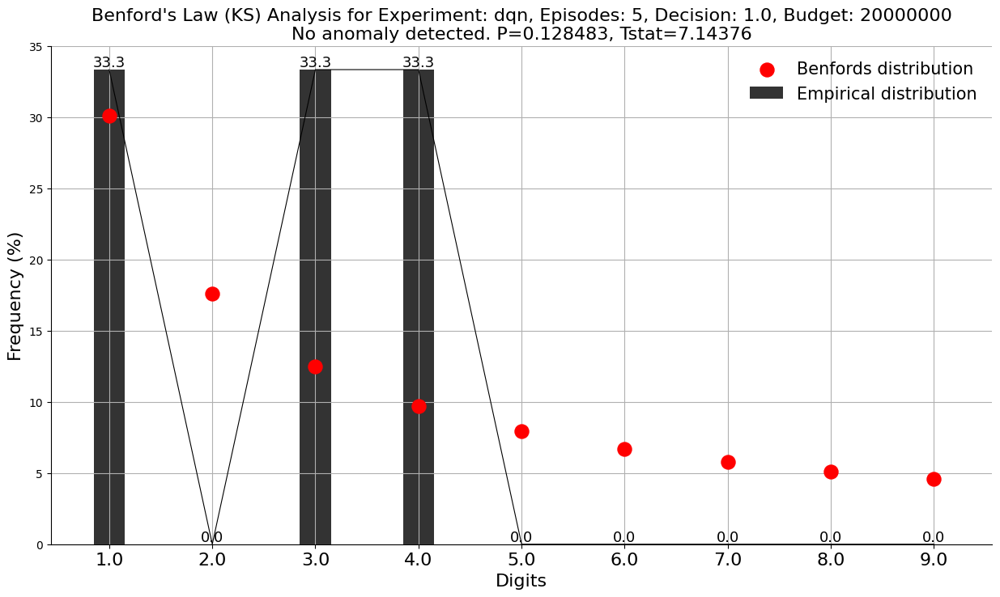

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep5_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.153496, Tstat=6.68509


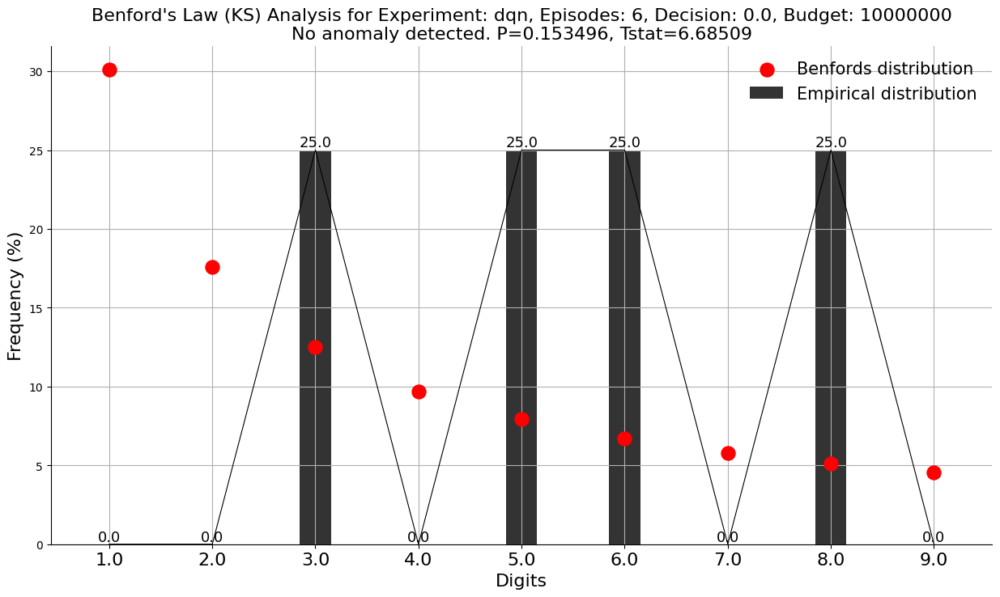

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep6_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0727958, Tstat=8.56993


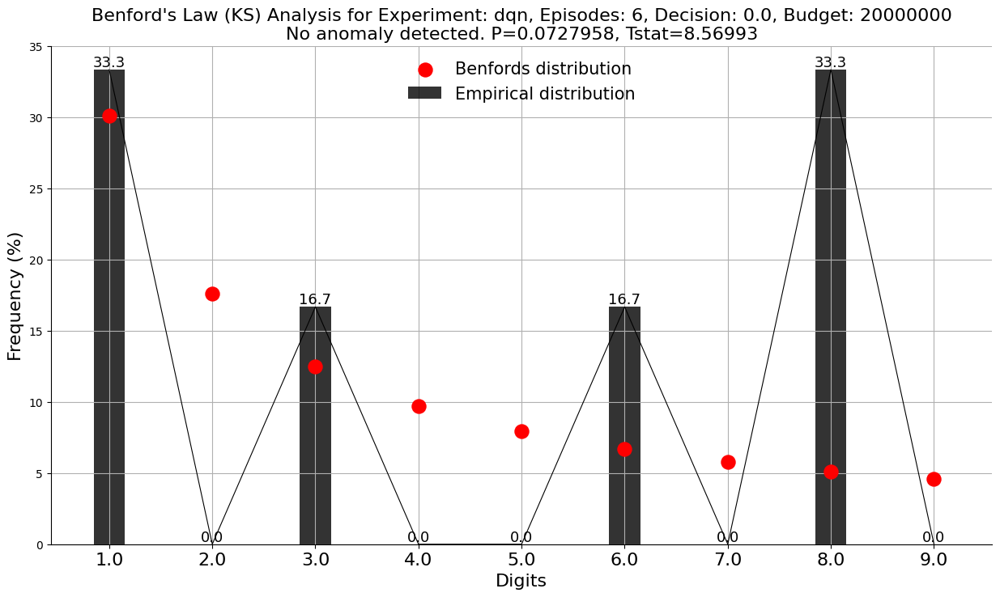

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep6_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0752678, Tstat=8.48748


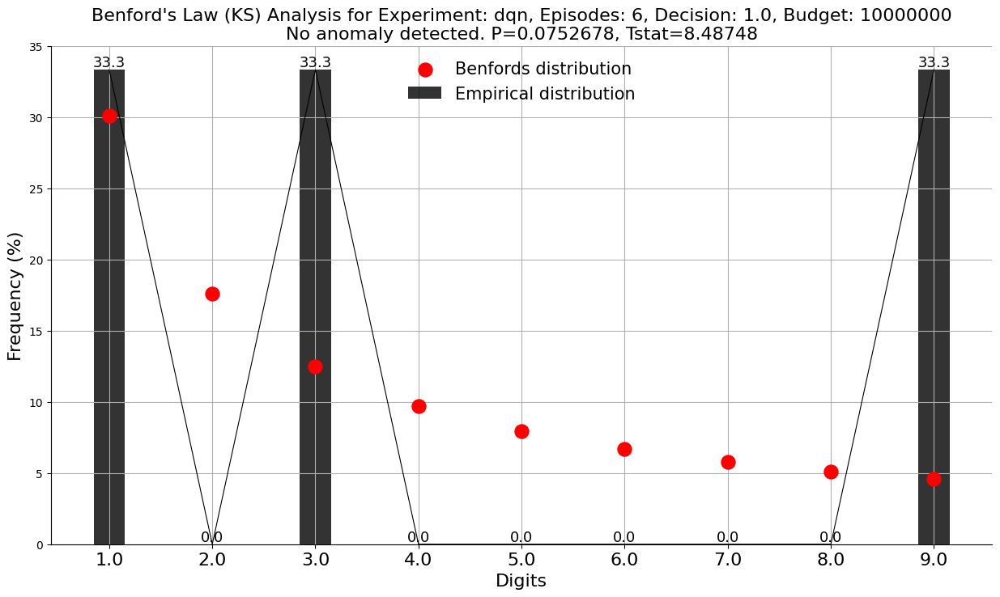

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep6_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.164319, Tstat=6.50749


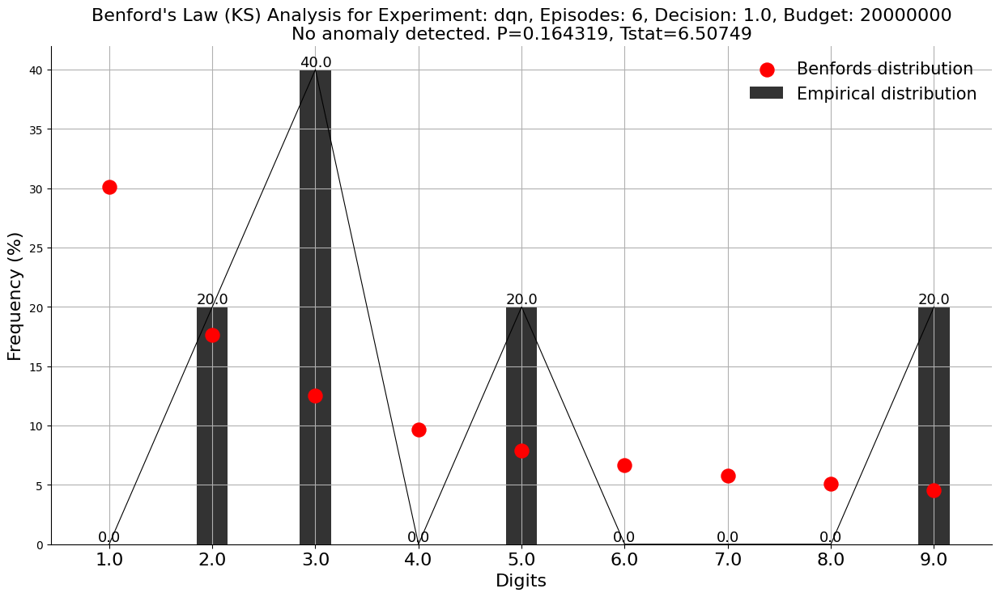

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep6_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0145698, Tstat=12.4067


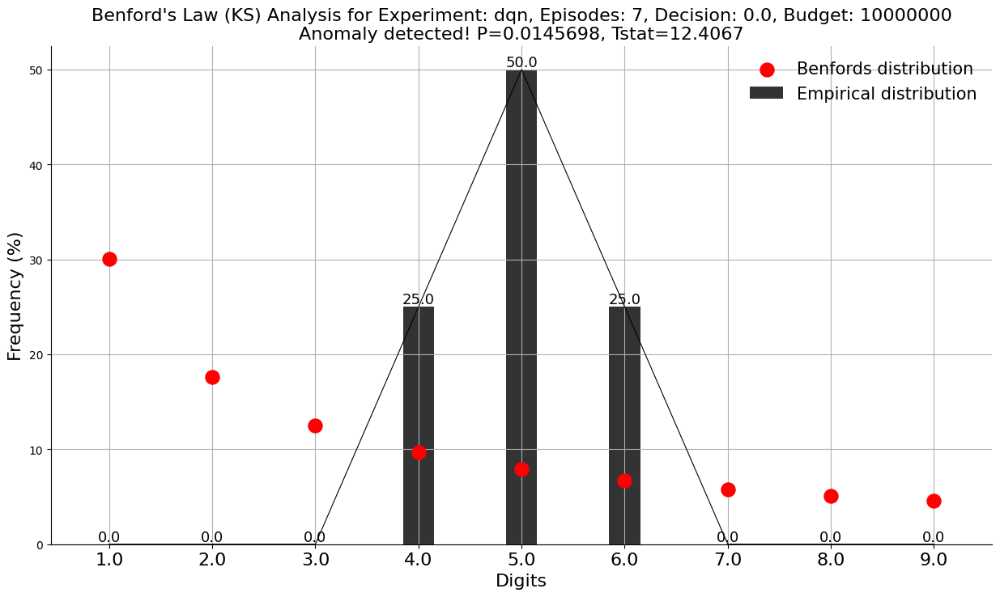

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep7_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=5.78869e-09, Tstat=44.215


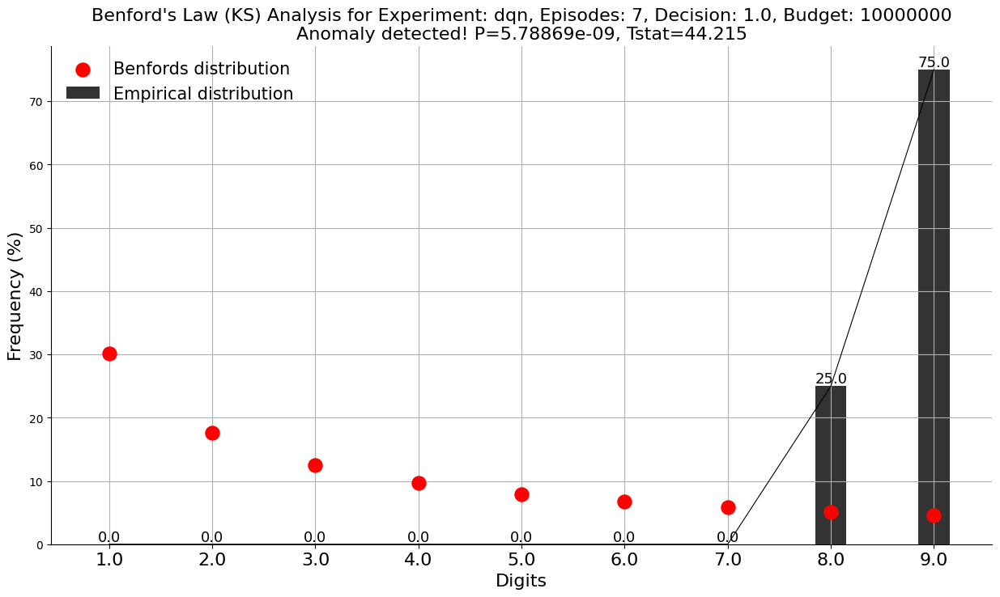

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep7_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0390577, Tstat=10.0827


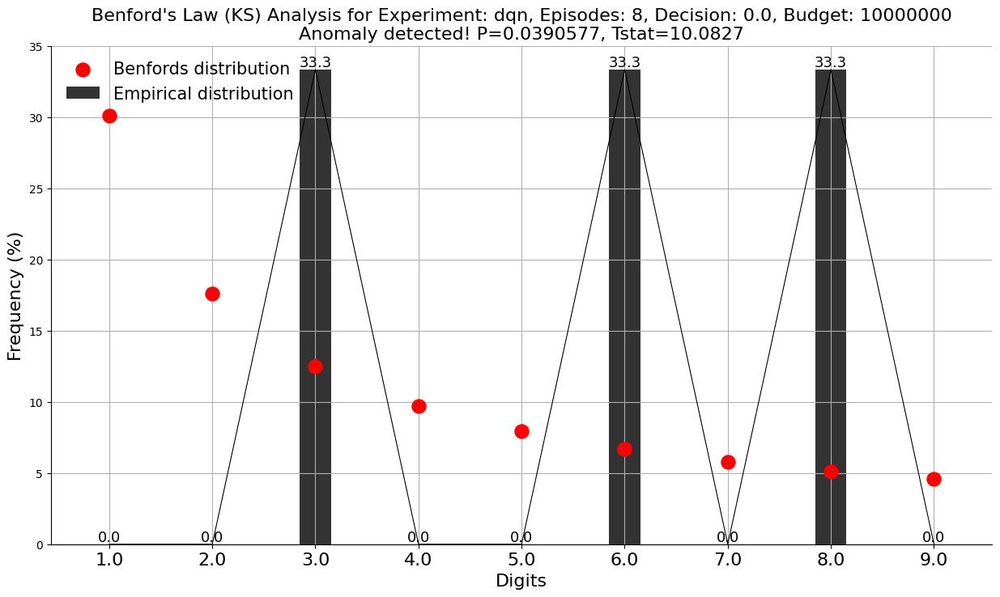

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep8_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0417726, Tstat=9.92141


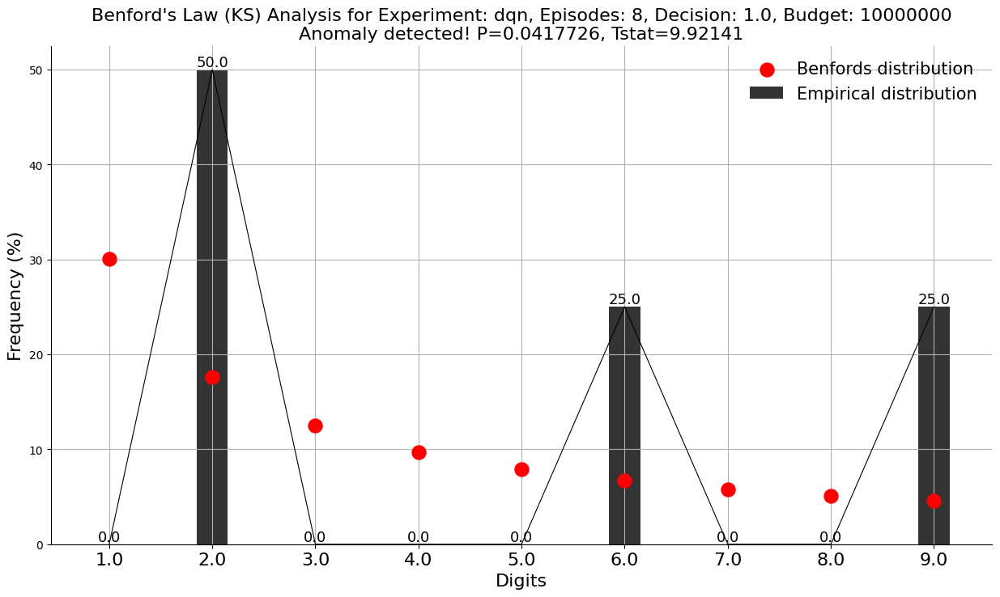

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep8_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00591466, Tstat=14.4785


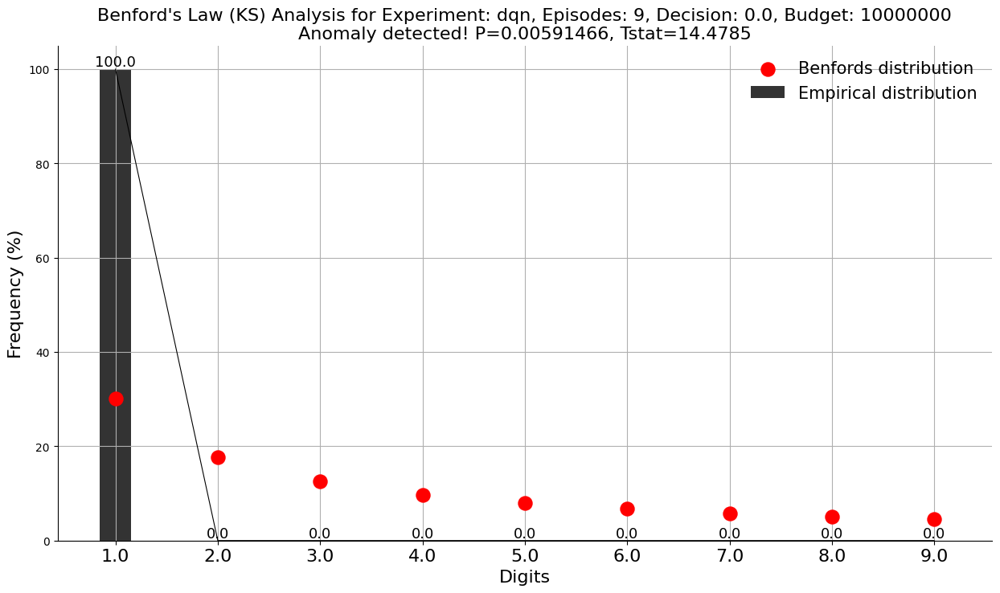

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep9_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00591466, Tstat=14.4785


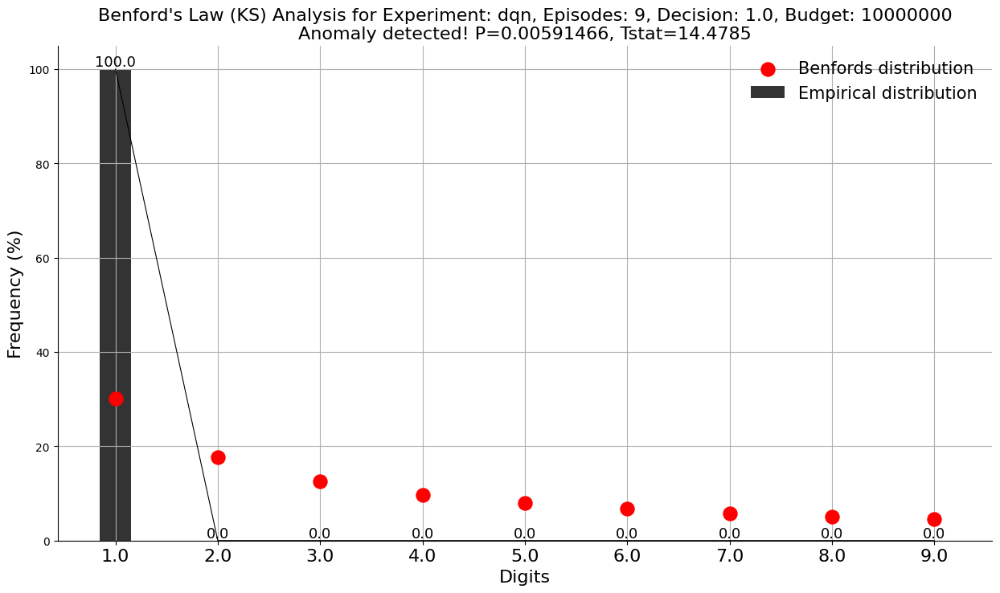

Plot saved to: .temp/experiment_results/benford_plot_dqn_ep9_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


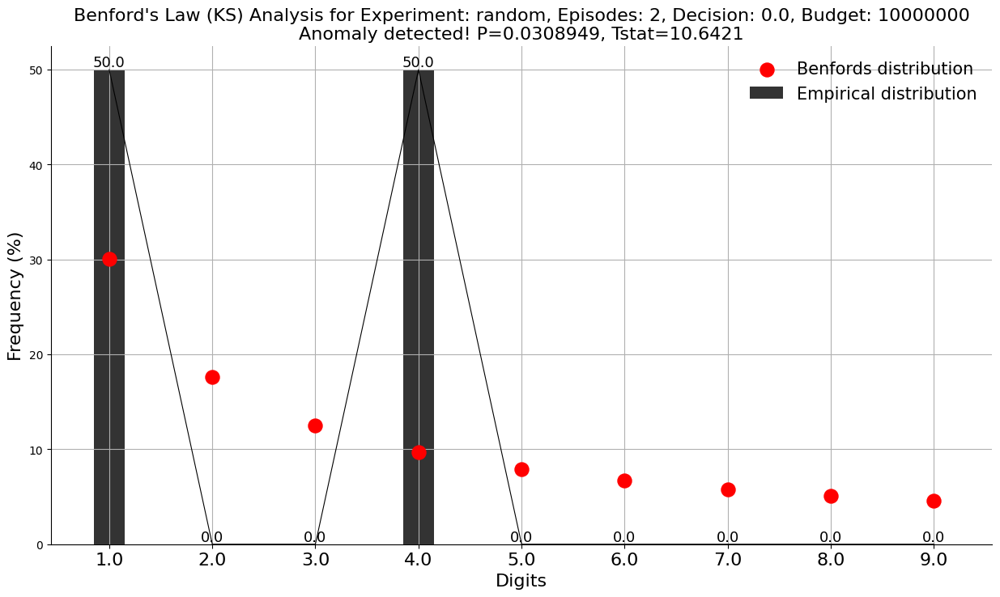

Plot saved to: .temp/experiment_results/benford_plot_random_ep2_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0177328, Tstat=11.9492


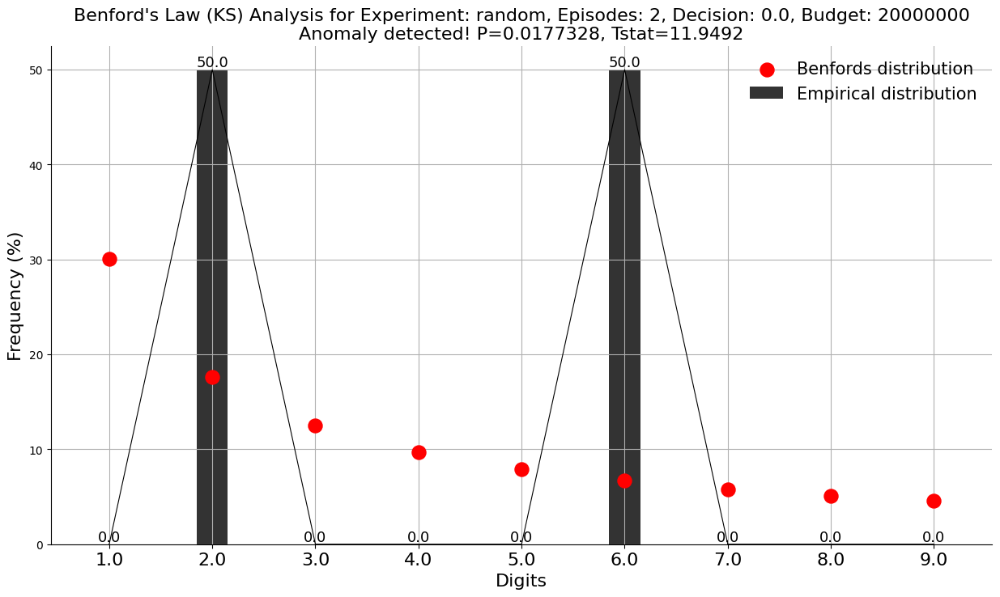

Plot saved to: .temp/experiment_results/benford_plot_random_ep2_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.19828, Tstat=6.01165


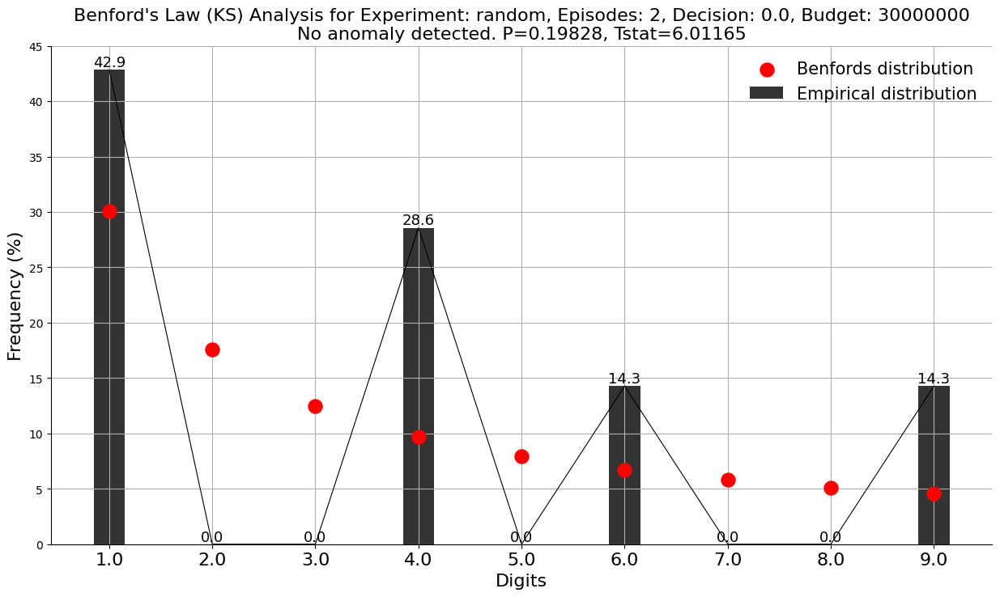

Plot saved to: .temp/experiment_results/benford_plot_random_ep2_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.575748, Tstat=2.89383


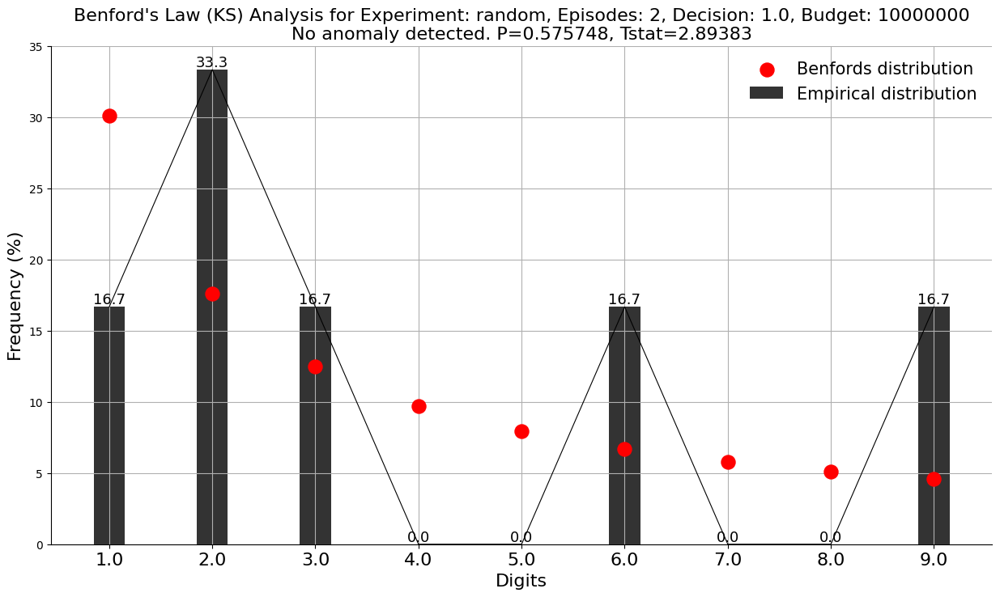

Plot saved to: .temp/experiment_results/benford_plot_random_ep2_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0332745, Tstat=10.4656


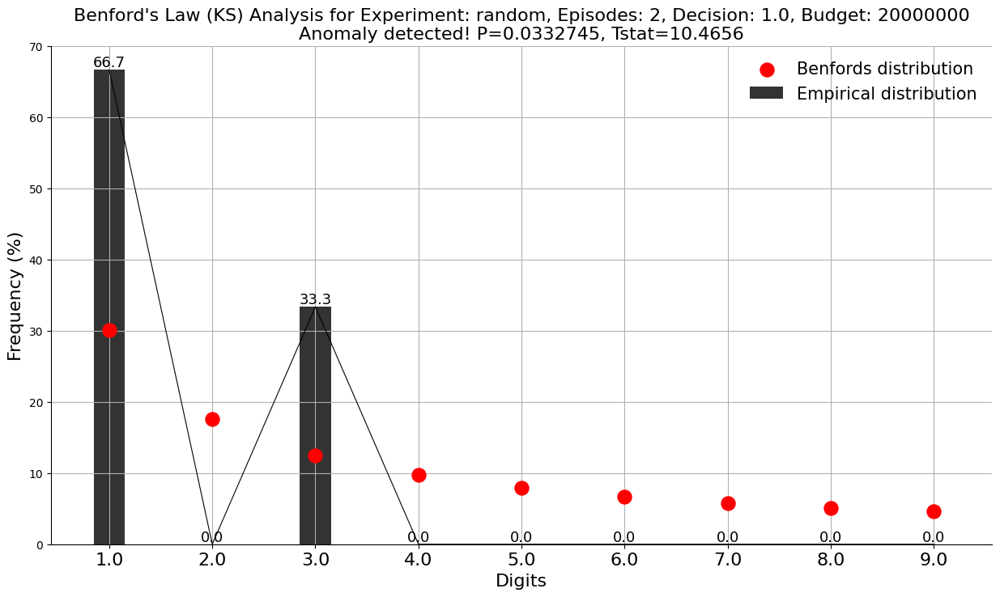

Plot saved to: .temp/experiment_results/benford_plot_random_ep2_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.533655, Tstat=3.14626


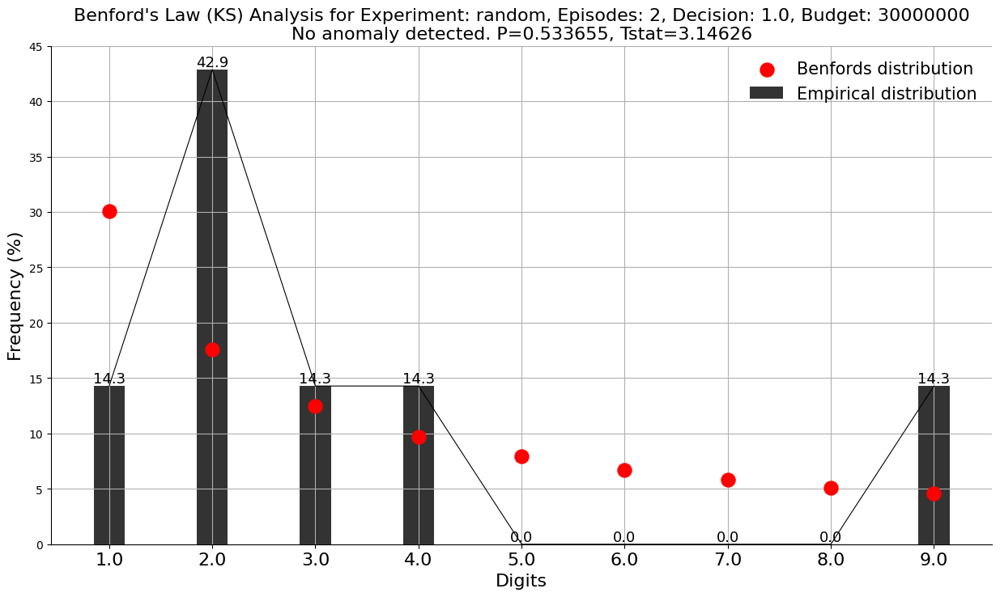

Plot saved to: .temp/experiment_results/benford_plot_random_ep2_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.866127, Tstat=1.27189


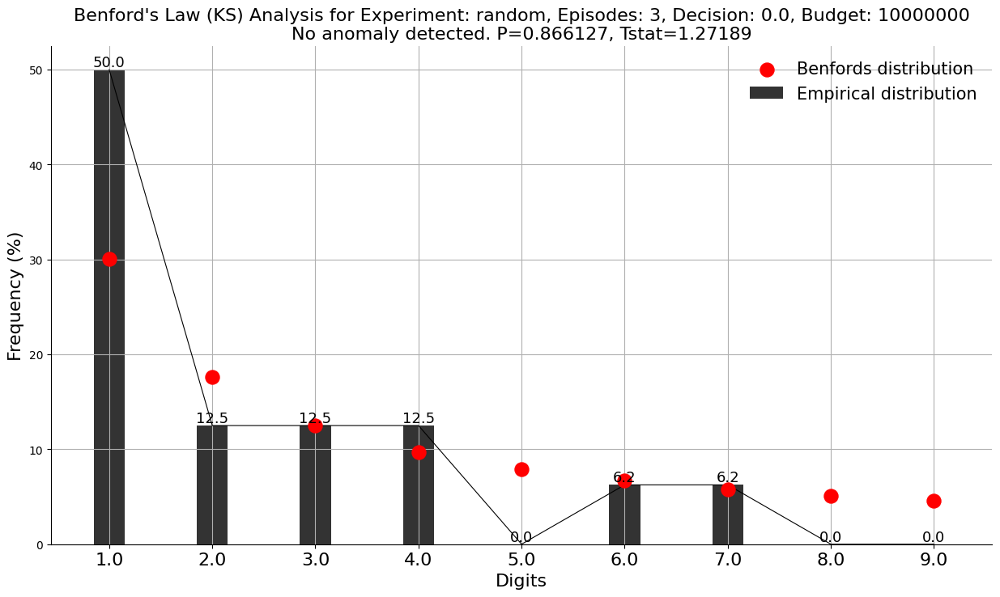

Plot saved to: .temp/experiment_results/benford_plot_random_ep3_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


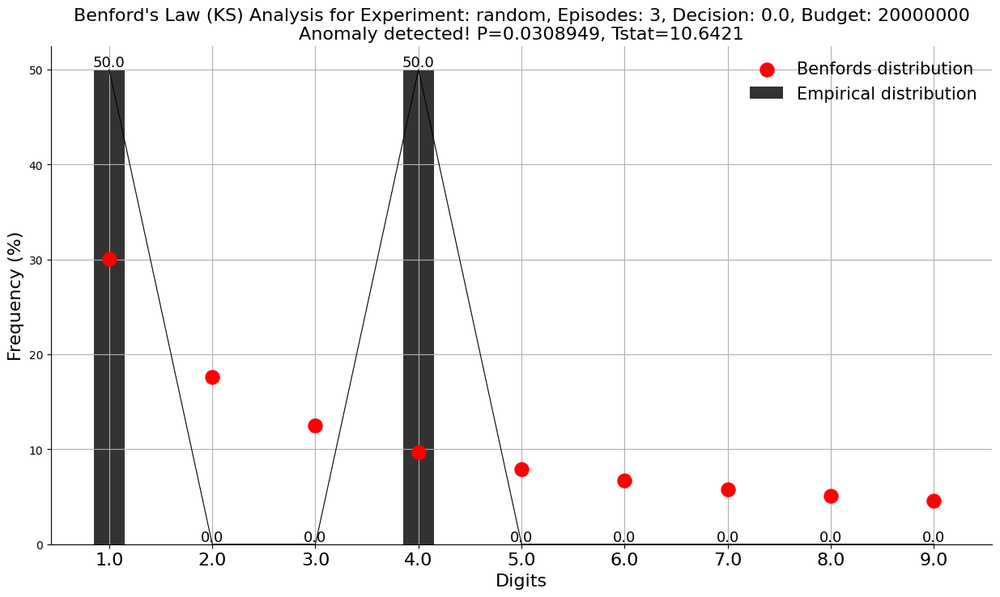

Plot saved to: .temp/experiment_results/benford_plot_random_ep3_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.292509, Tstat=4.94959


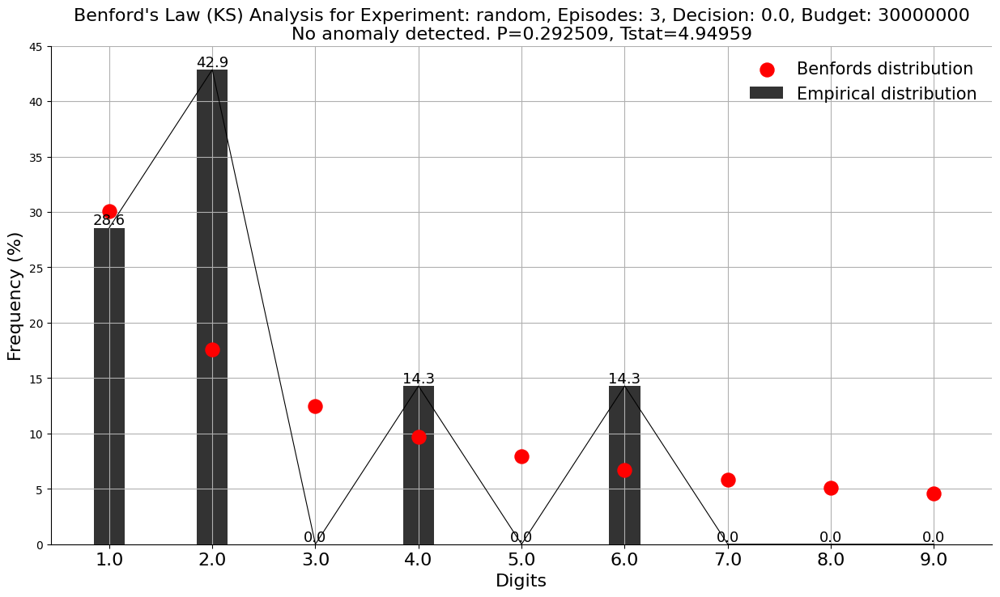

Plot saved to: .temp/experiment_results/benford_plot_random_ep3_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.584483, Tstat=2.84271


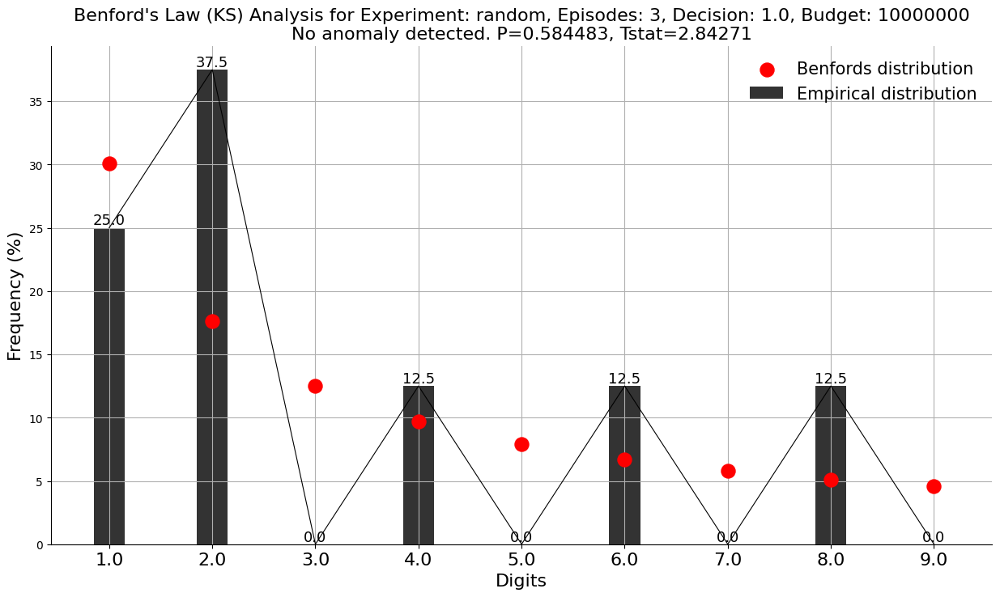

Plot saved to: .temp/experiment_results/benford_plot_random_ep3_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0761977, Tstat=8.45712


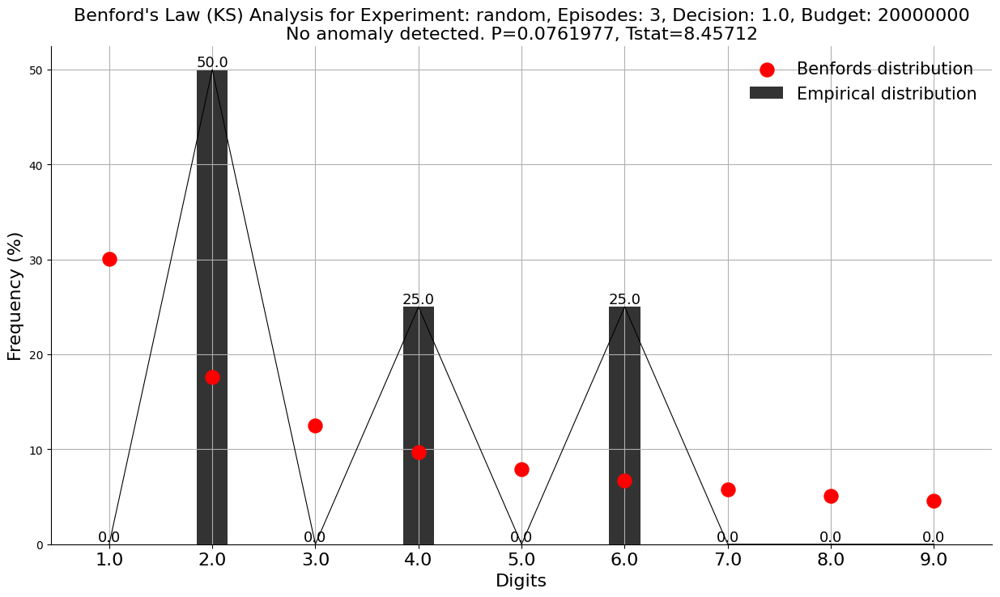

Plot saved to: .temp/experiment_results/benford_plot_random_ep3_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.295479, Tstat=4.9212


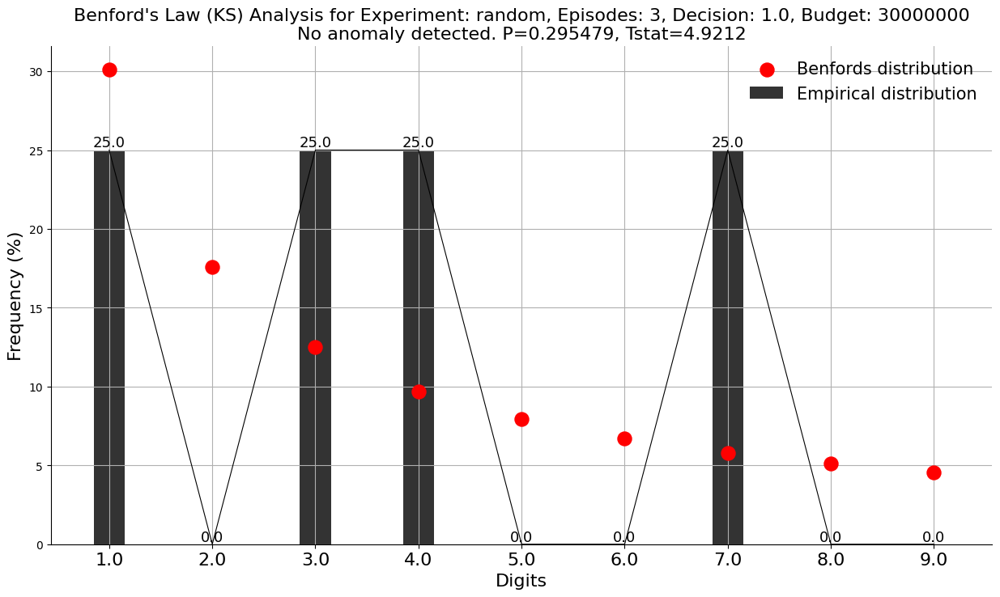

Plot saved to: .temp/experiment_results/benford_plot_random_ep3_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00592606, Tstat=14.4741


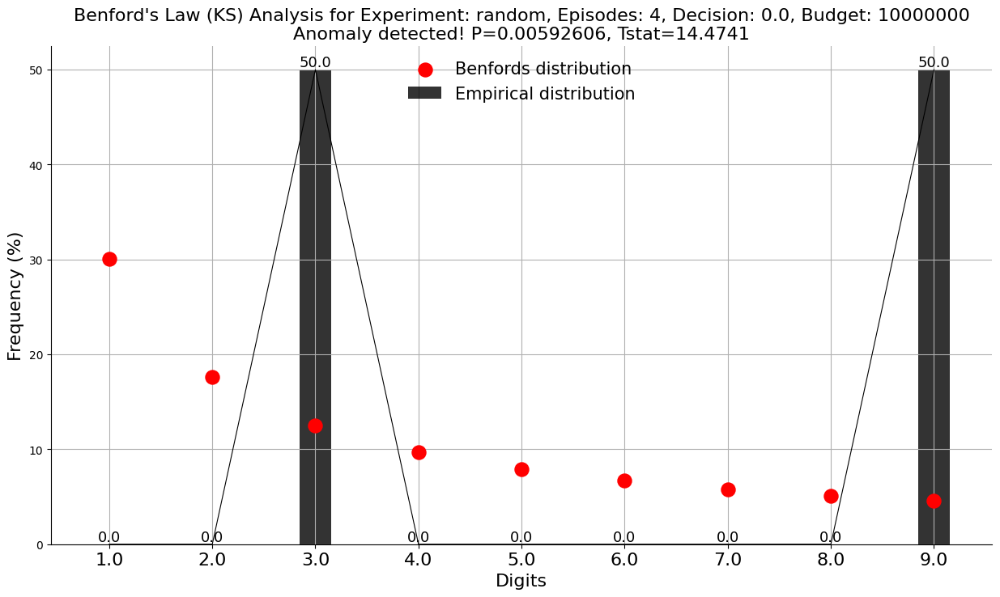

Plot saved to: .temp/experiment_results/benford_plot_random_ep4_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.212204, Tstat=5.83006


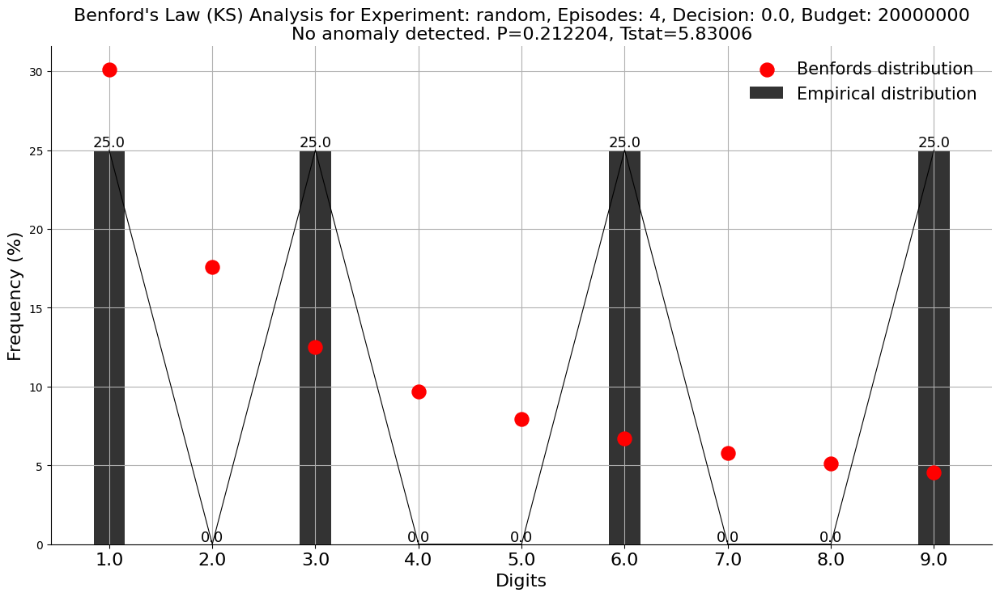

Plot saved to: .temp/experiment_results/benford_plot_random_ep4_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0653749, Tstat=8.83439


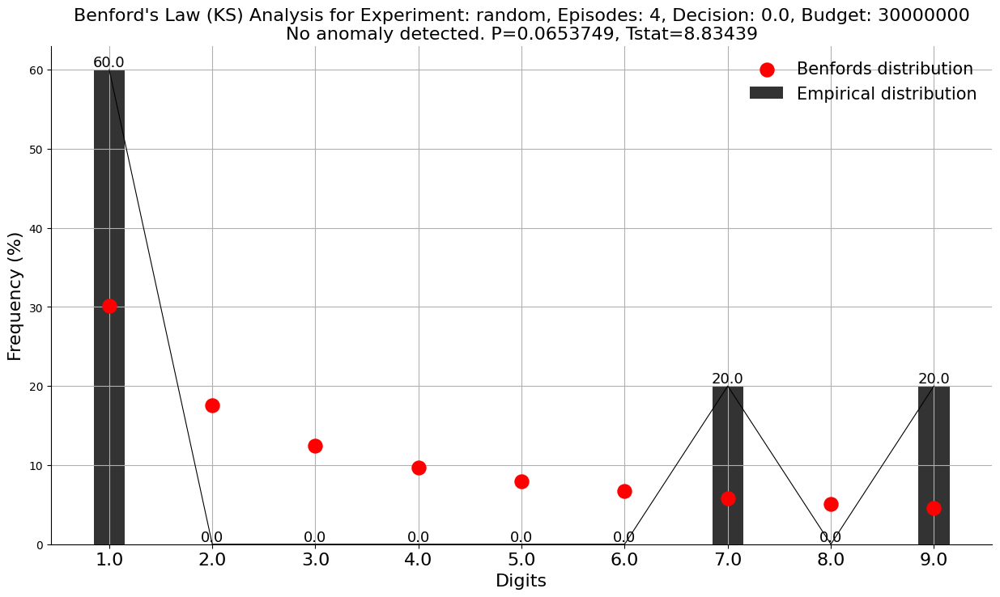

Plot saved to: .temp/experiment_results/benford_plot_random_ep4_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.101392, Tstat=7.74466


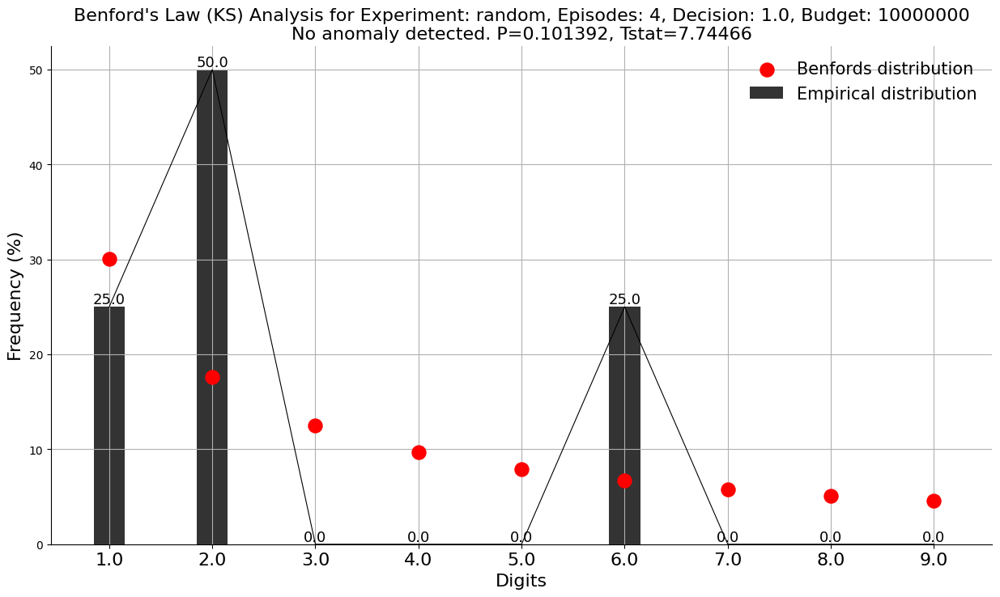

Plot saved to: .temp/experiment_results/benford_plot_random_ep4_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.257011, Tstat=5.30926


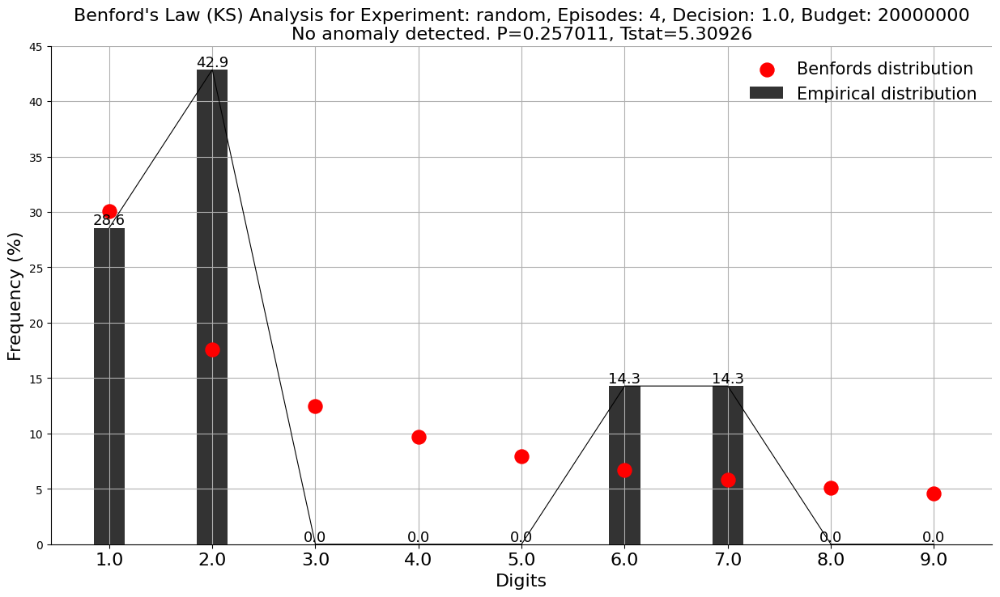

Plot saved to: .temp/experiment_results/benford_plot_random_ep4_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.133516, Tstat=7.04525


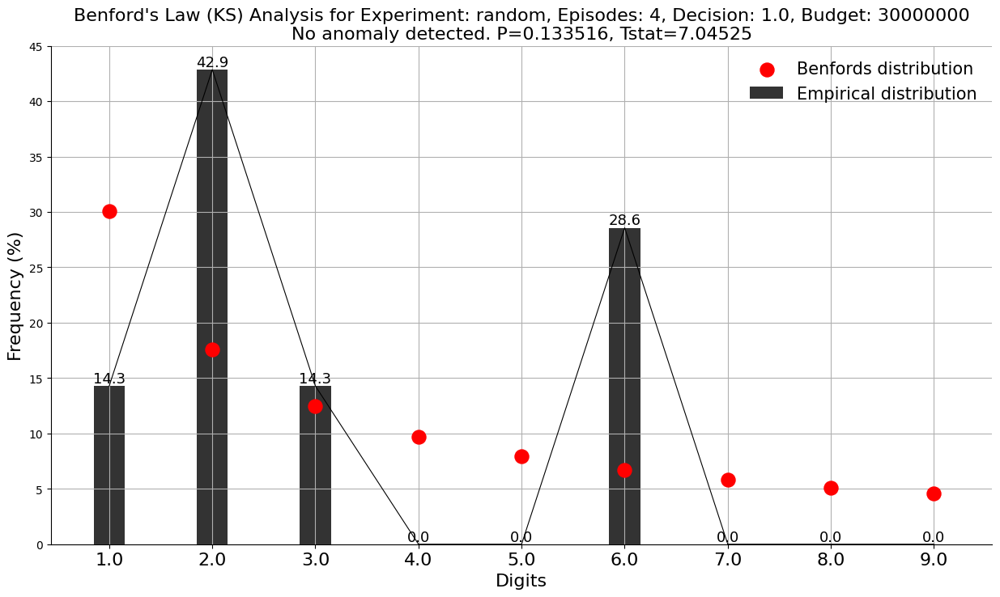

Plot saved to: .temp/experiment_results/benford_plot_random_ep4_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00219082, Tstat=16.7198


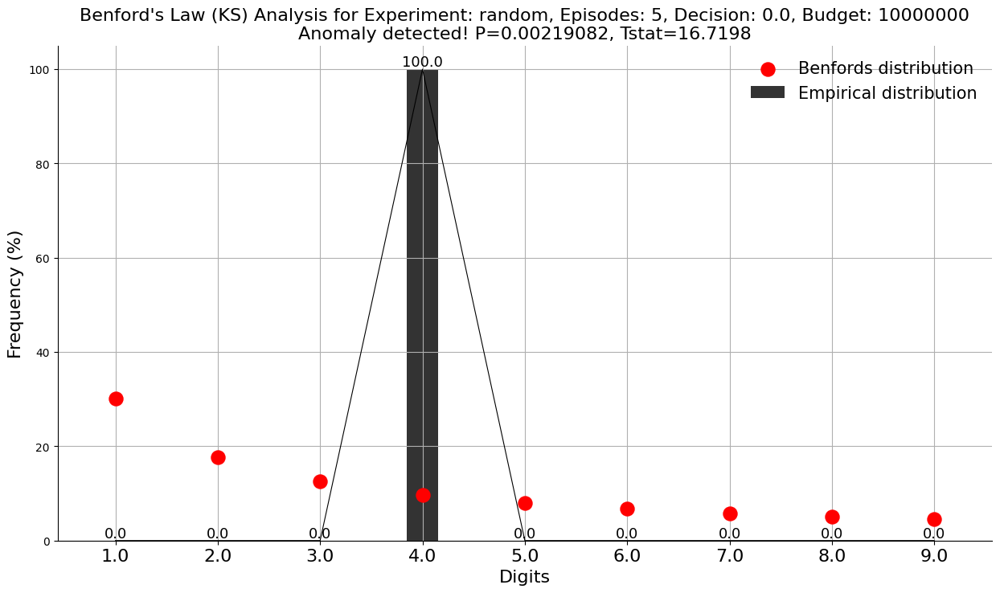

Plot saved to: .temp/experiment_results/benford_plot_random_ep5_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00430483, Tstat=15.1995


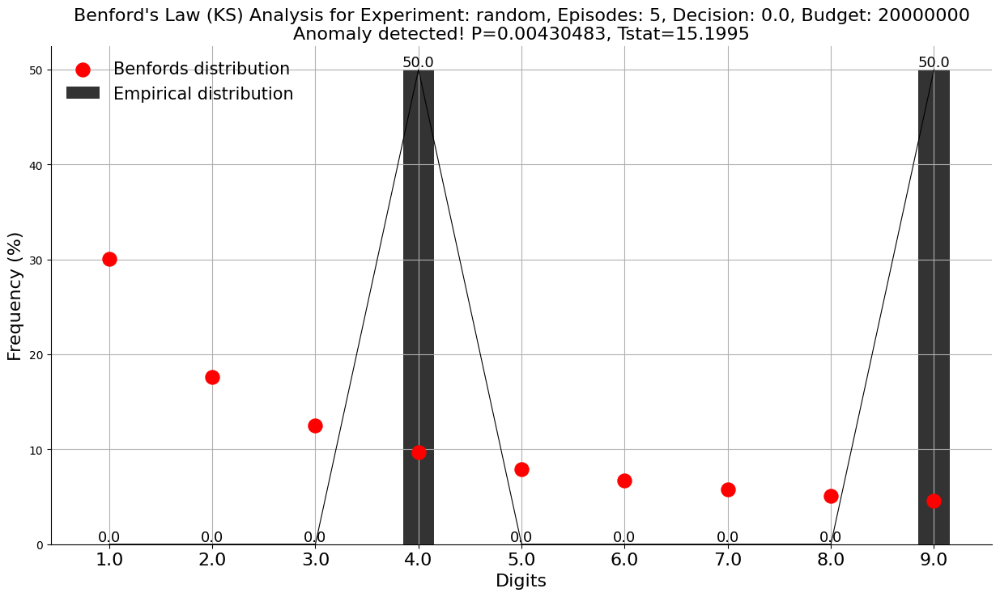

Plot saved to: .temp/experiment_results/benford_plot_random_ep5_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00353024, Tstat=15.6477


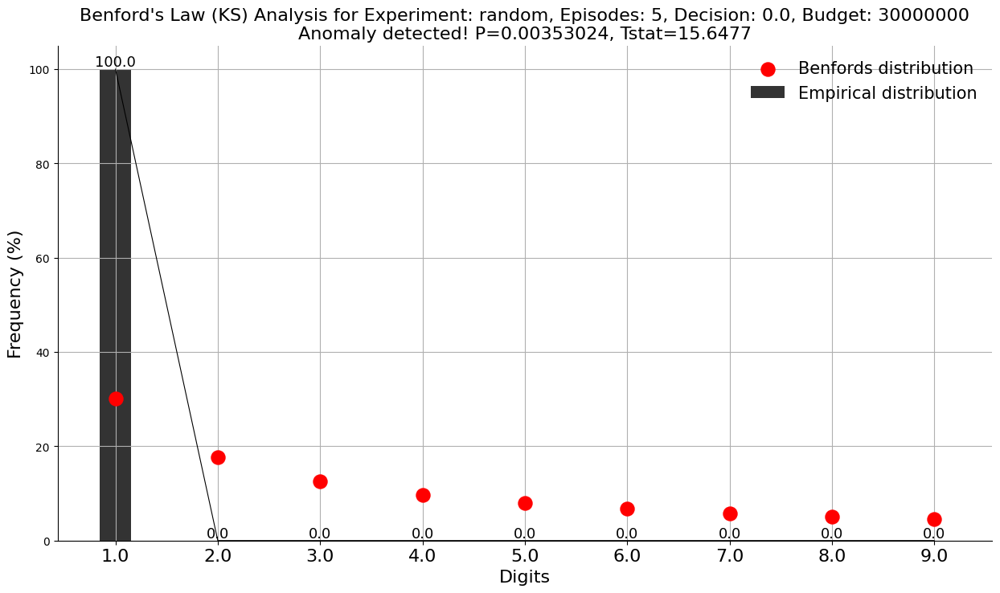

Plot saved to: .temp/experiment_results/benford_plot_random_ep5_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0155856, Tstat=12.25


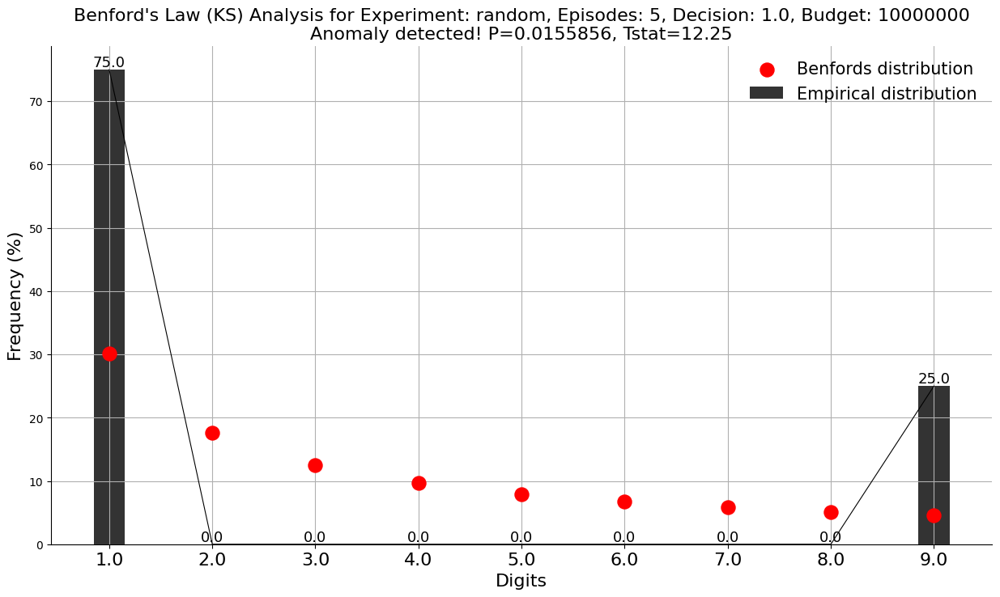

Plot saved to: .temp/experiment_results/benford_plot_random_ep5_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00353024, Tstat=15.6477


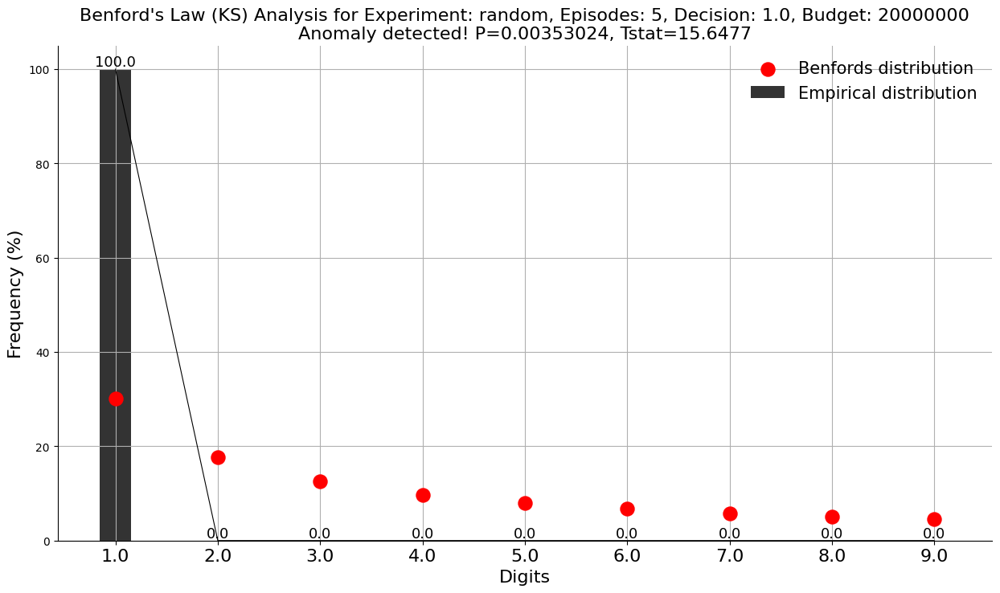

Plot saved to: .temp/experiment_results/benford_plot_random_ep5_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.929371, Tstat=0.866112


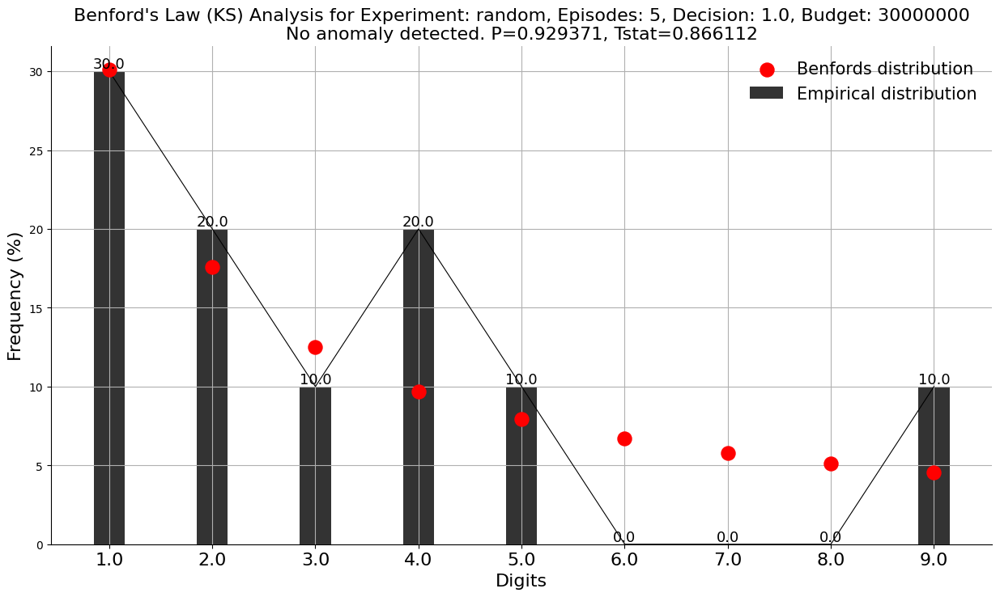

Plot saved to: .temp/experiment_results/benford_plot_random_ep5_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.196862, Tstat=6.03077


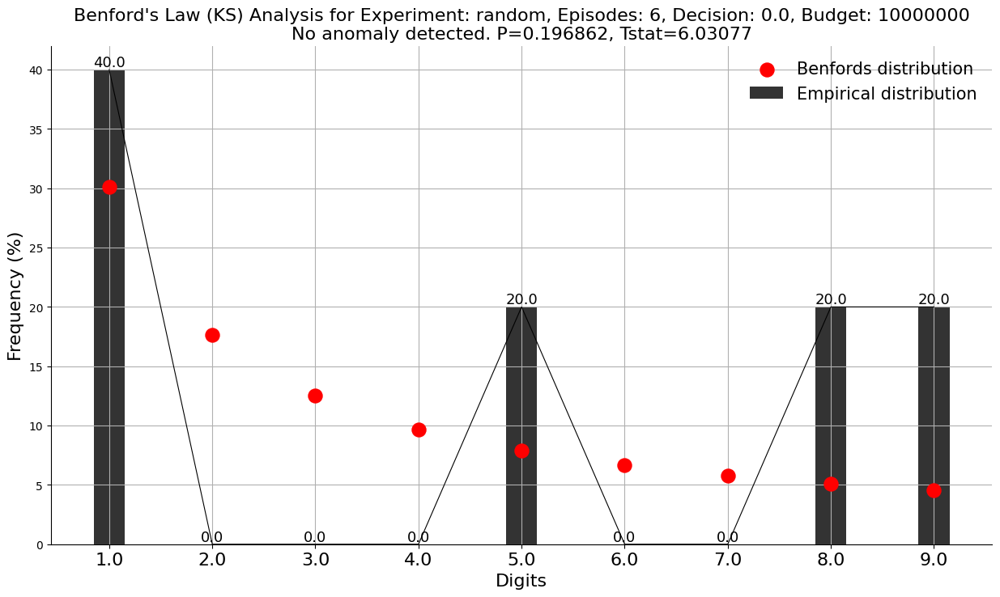

Plot saved to: .temp/experiment_results/benford_plot_random_ep6_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.021819, Tstat=11.4636


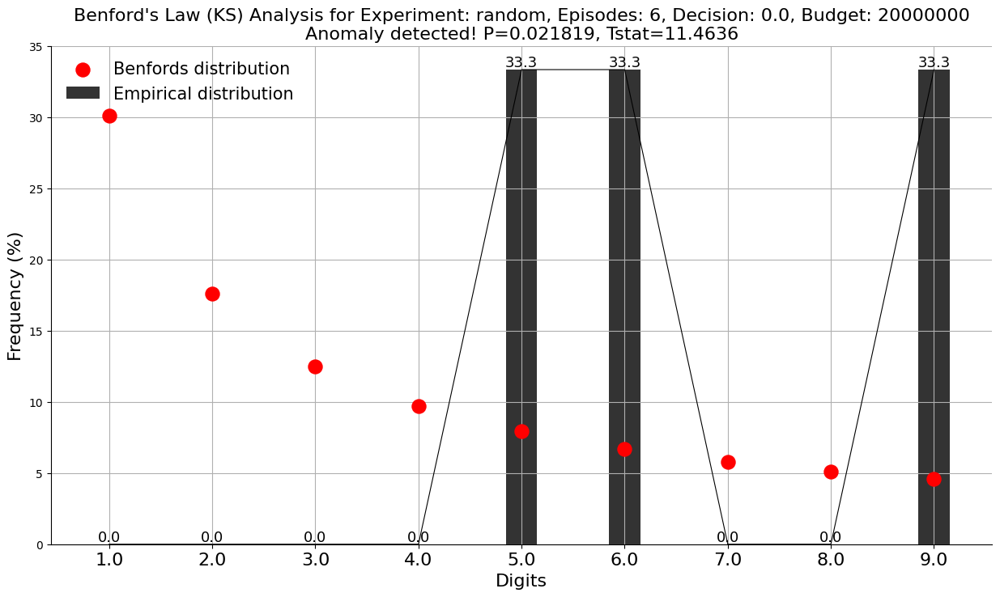

Plot saved to: .temp/experiment_results/benford_plot_random_ep6_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0163853, Tstat=12.1336


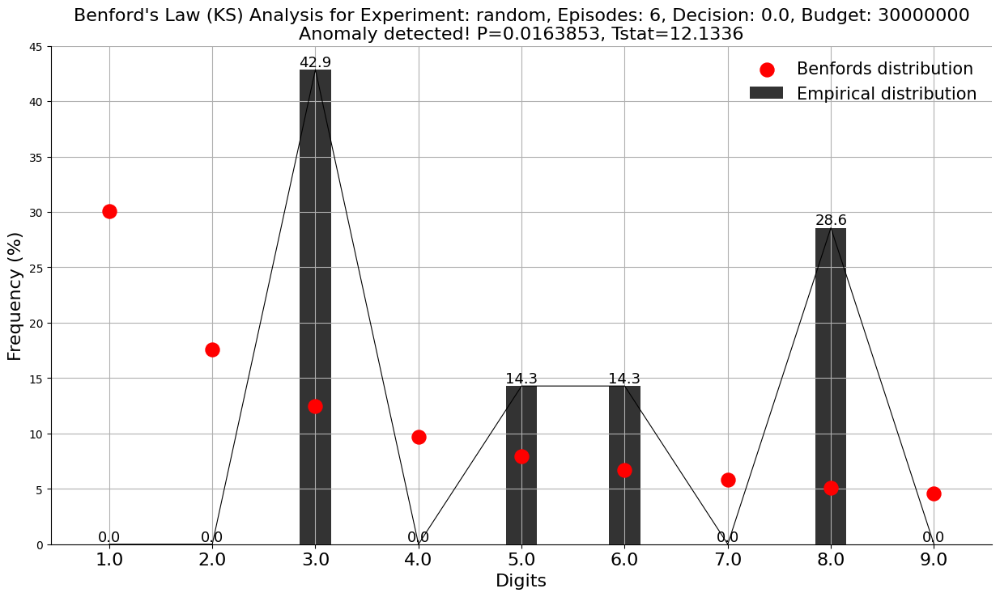

Plot saved to: .temp/experiment_results/benford_plot_random_ep6_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00638448, Tstat=14.3043


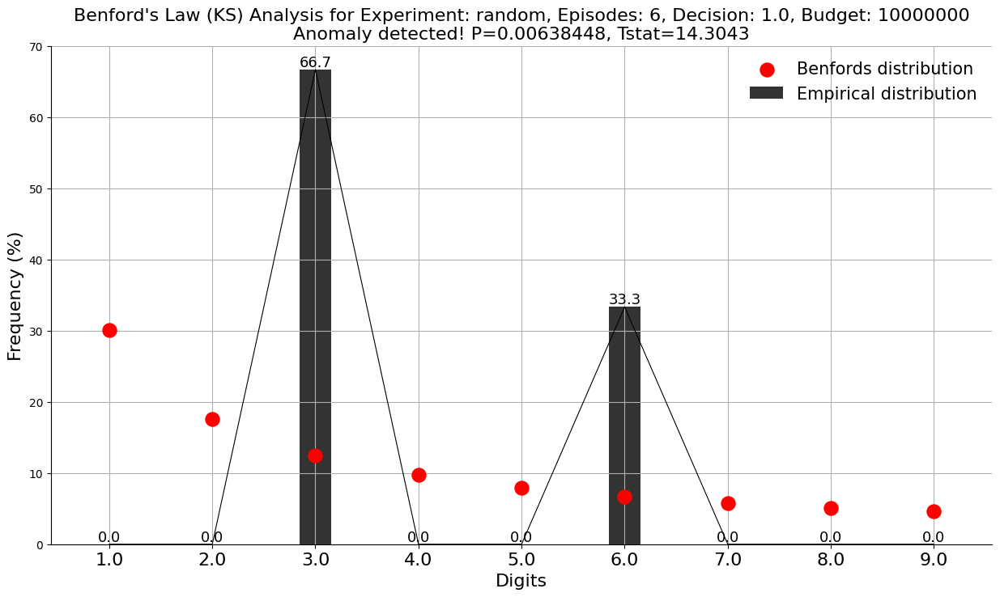

Plot saved to: .temp/experiment_results/benford_plot_random_ep6_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0140021, Tstat=12.499


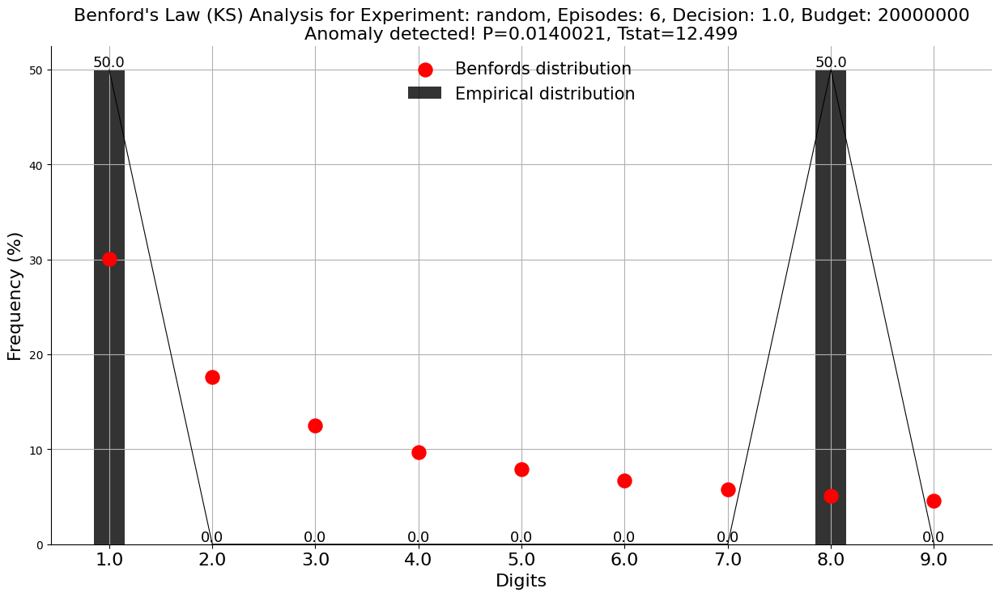

Plot saved to: .temp/experiment_results/benford_plot_random_ep6_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.10195, Tstat=7.73085


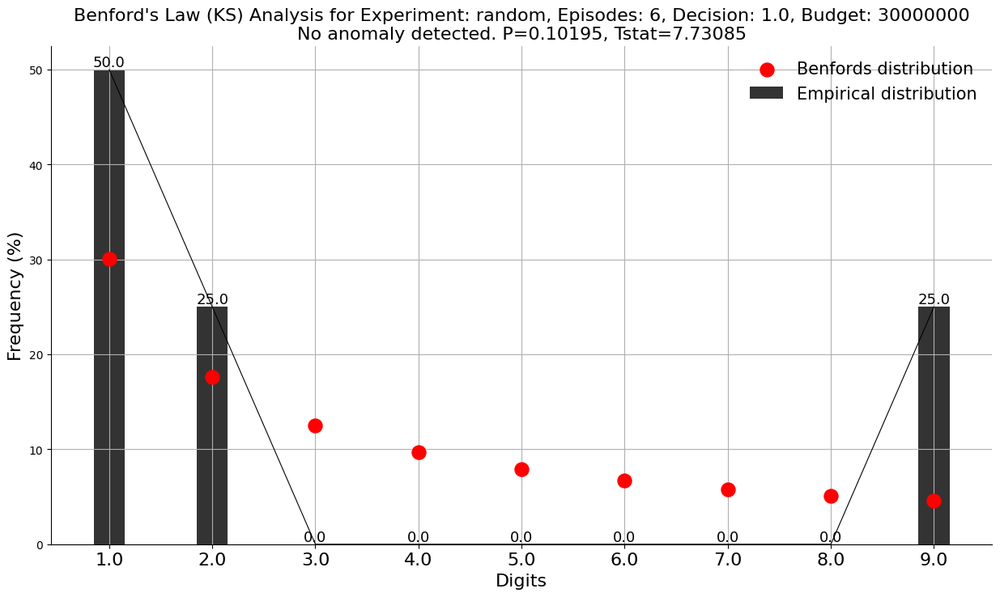

Plot saved to: .temp/experiment_results/benford_plot_random_ep6_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0386294, Tstat=10.1091


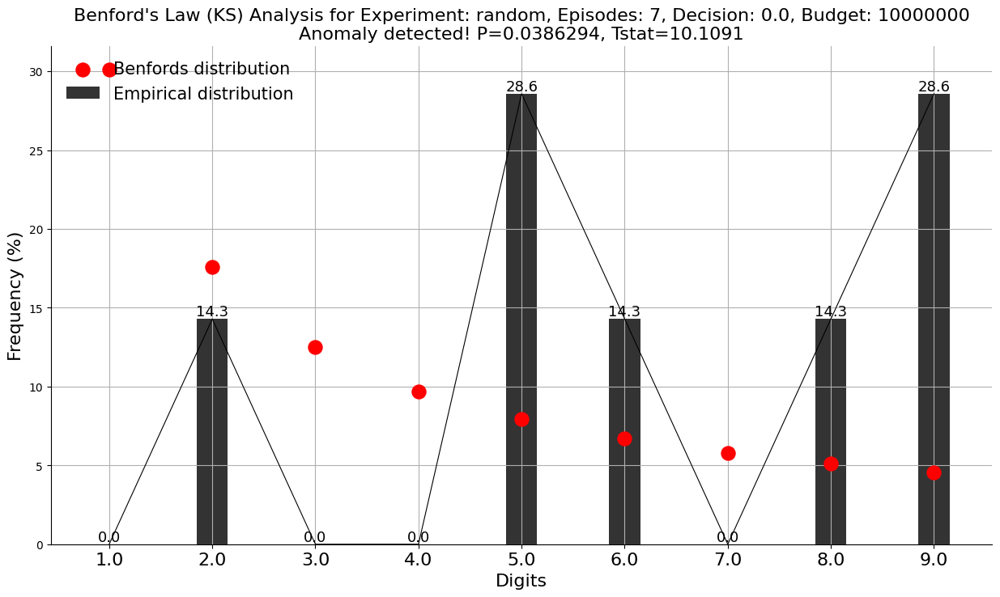

Plot saved to: .temp/experiment_results/benford_plot_random_ep7_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0175504, Tstat=11.9734


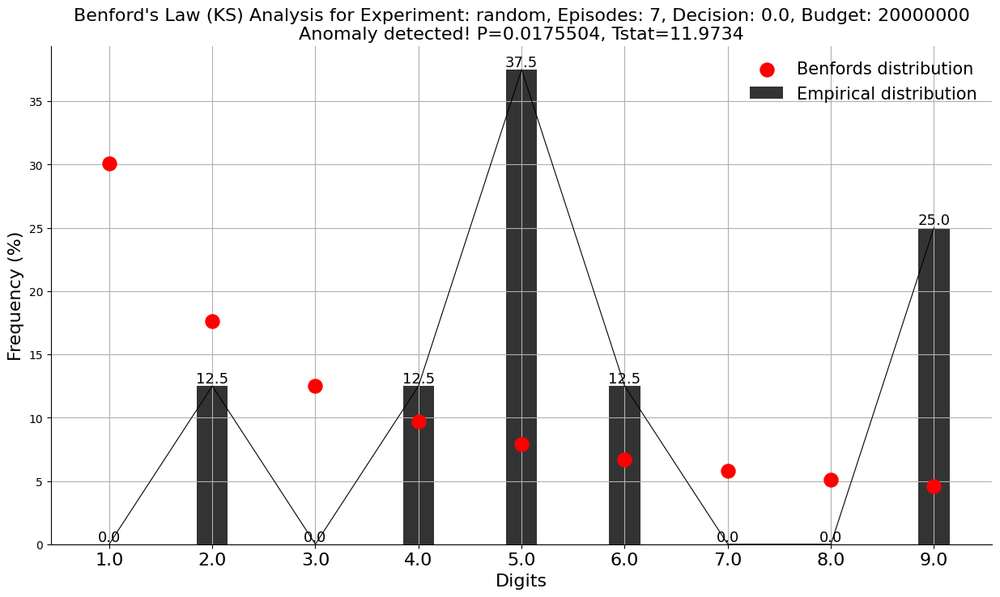

Plot saved to: .temp/experiment_results/benford_plot_random_ep7_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.315575, Tstat=4.73508


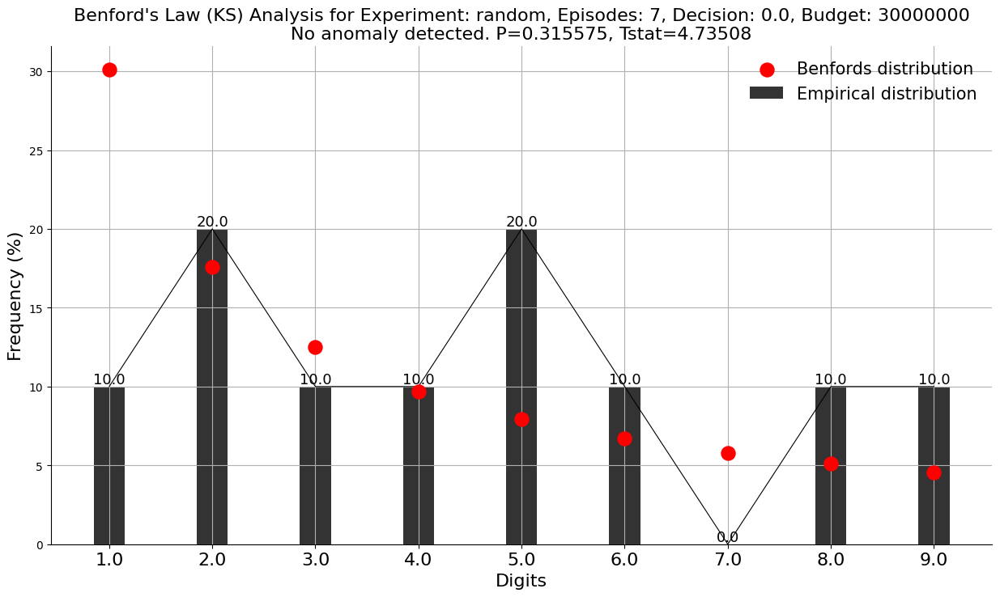

Plot saved to: .temp/experiment_results/benford_plot_random_ep7_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0388277, Tstat=10.0968


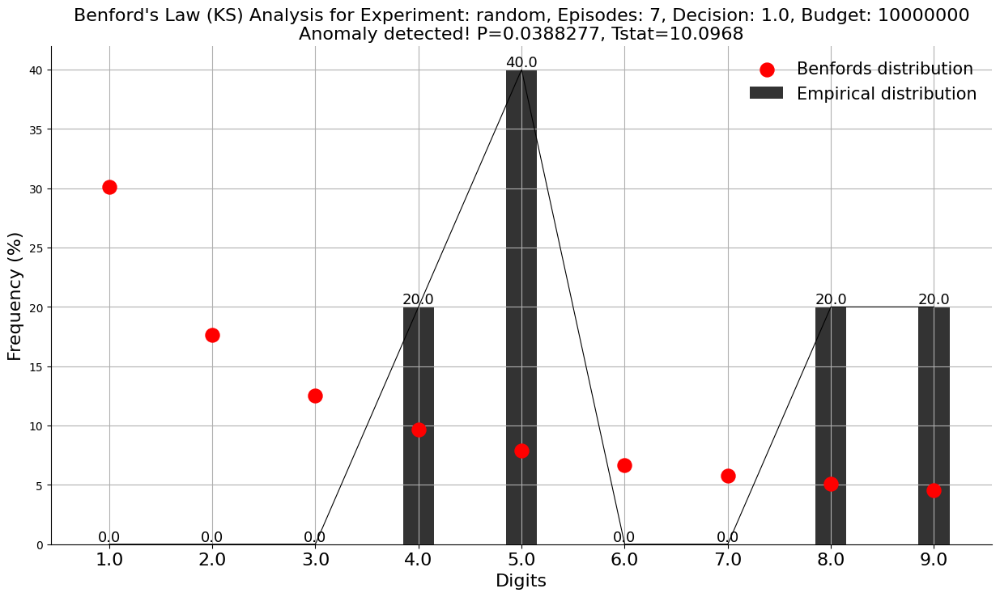

Plot saved to: .temp/experiment_results/benford_plot_random_ep7_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.000759068, Tstat=19.0769


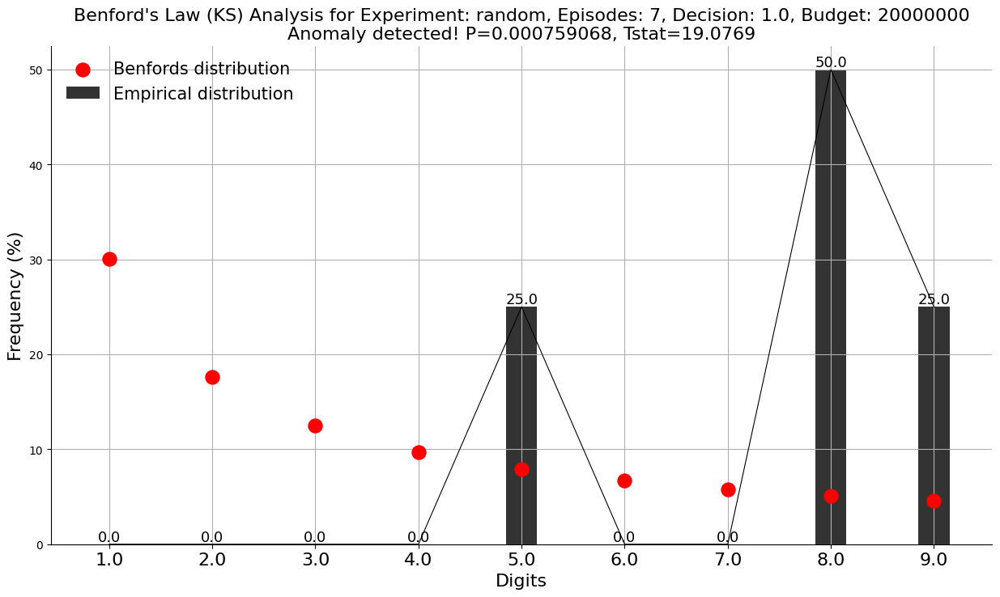

Plot saved to: .temp/experiment_results/benford_plot_random_ep7_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0159616, Tstat=12.1946


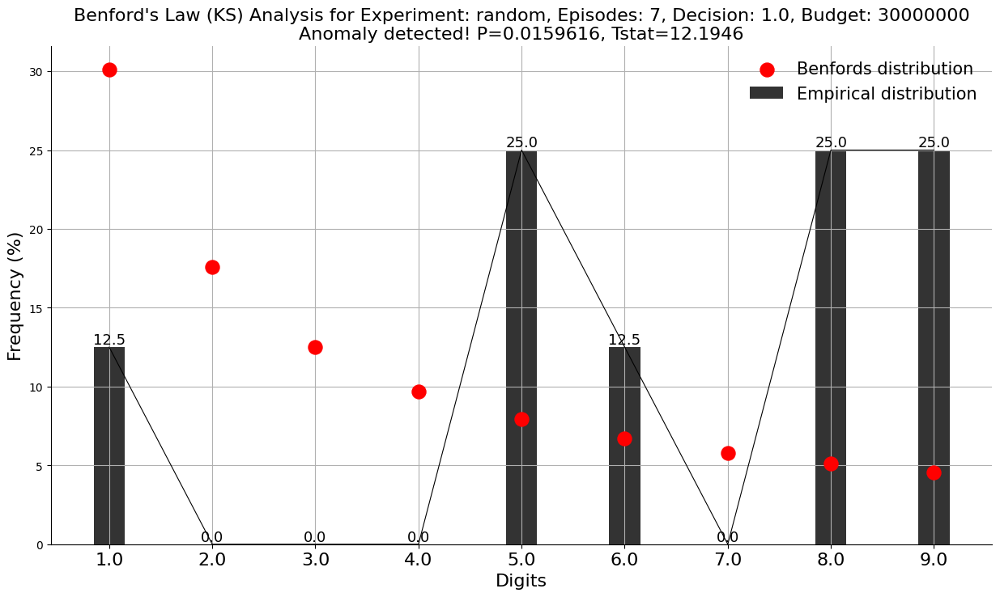

Plot saved to: .temp/experiment_results/benford_plot_random_ep7_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0299526, Tstat=10.7157


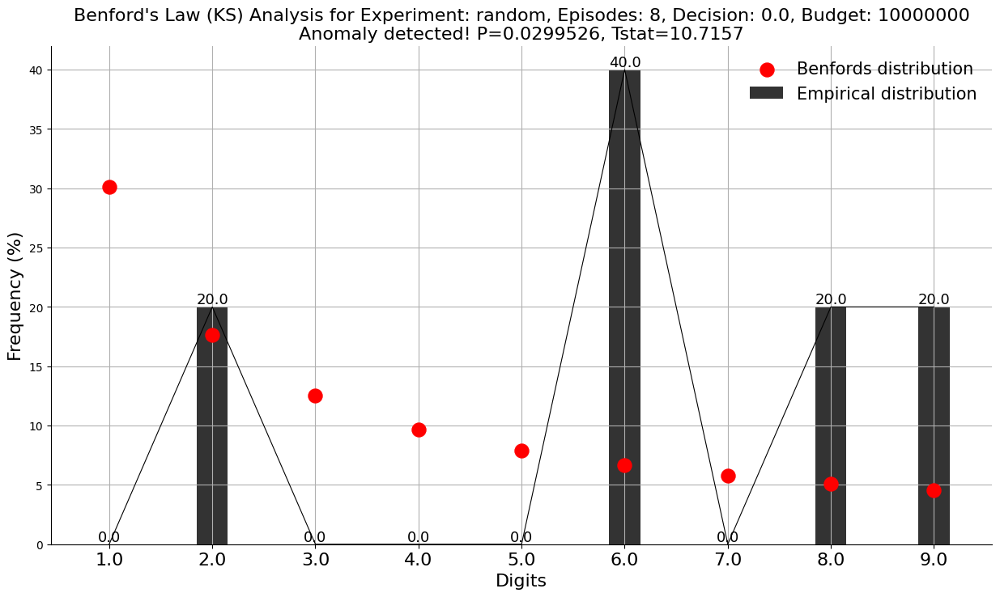

Plot saved to: .temp/experiment_results/benford_plot_random_ep8_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.381597, Tstat=4.18461


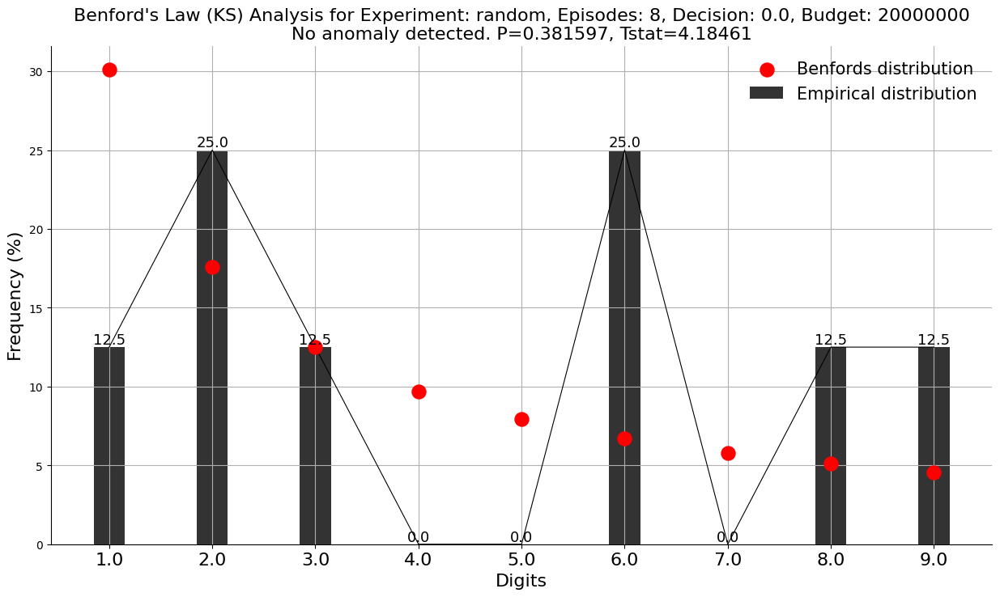

Plot saved to: .temp/experiment_results/benford_plot_random_ep8_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00484497, Tstat=14.9317


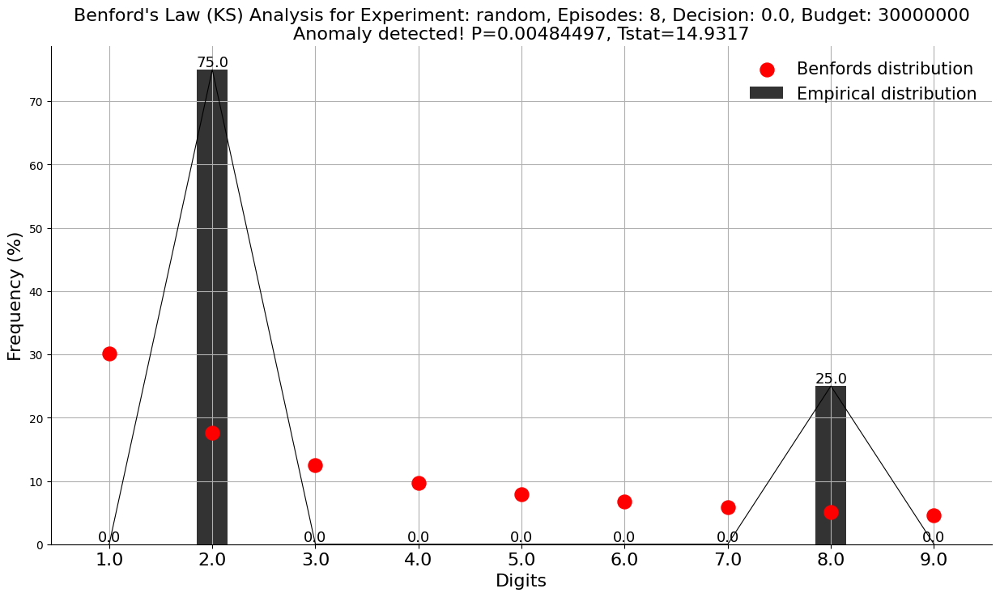

Plot saved to: .temp/experiment_results/benford_plot_random_ep8_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.125009, Tstat=7.21386


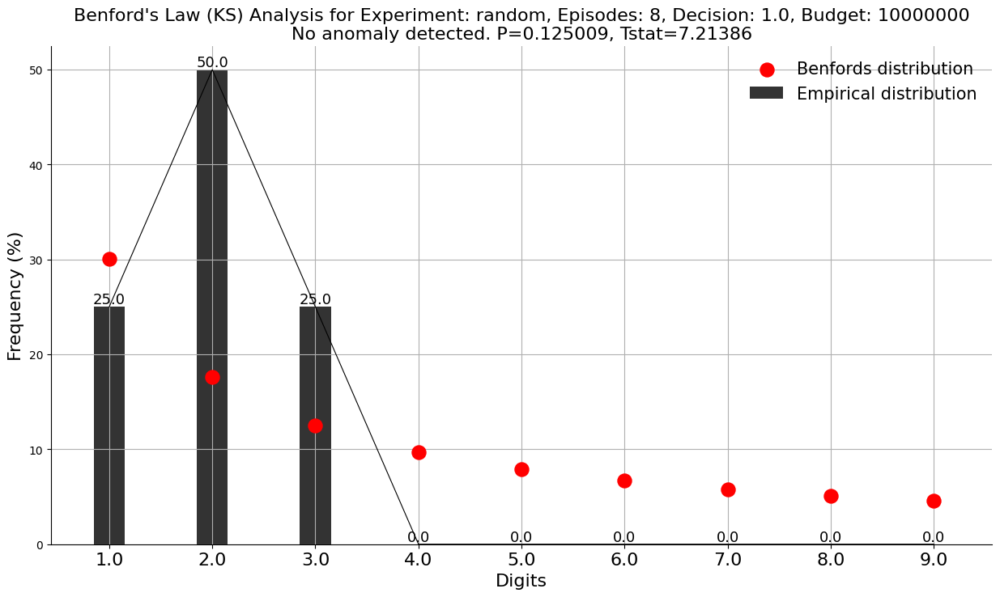

Plot saved to: .temp/experiment_results/benford_plot_random_ep8_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0625288, Tstat=8.94344


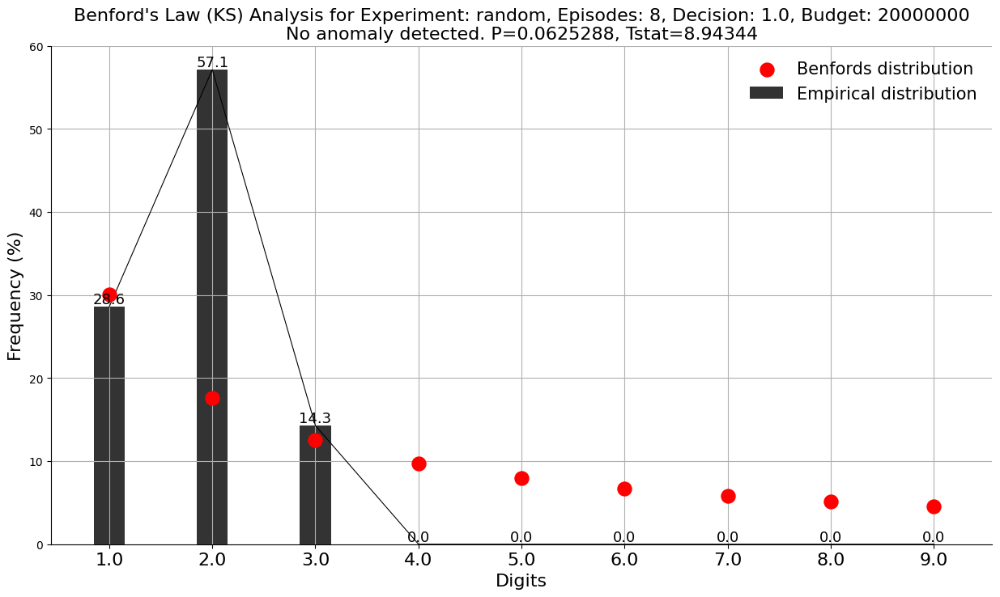

Plot saved to: .temp/experiment_results/benford_plot_random_ep8_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0638947, Tstat=8.89053


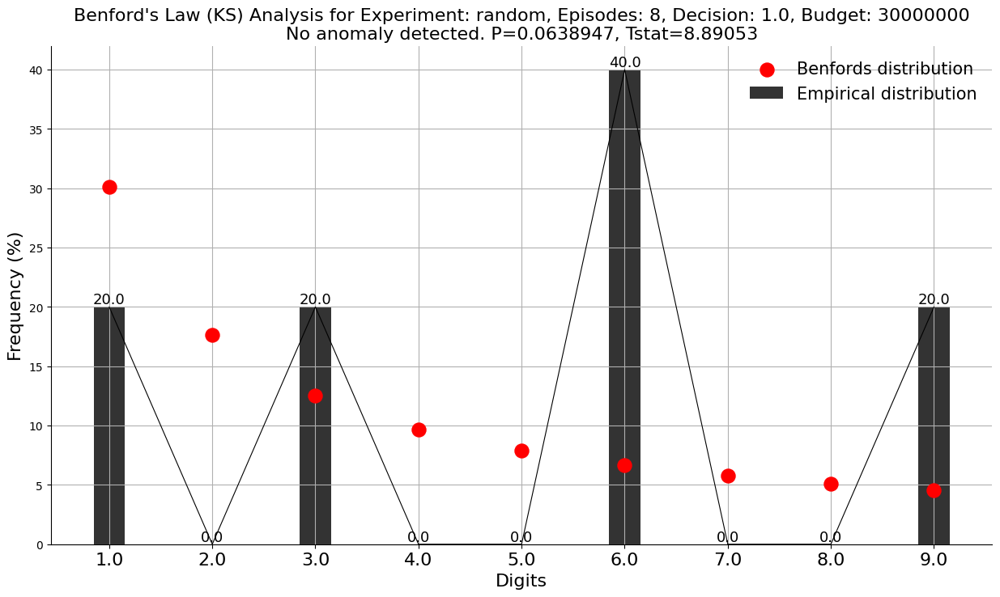

Plot saved to: .temp/experiment_results/benford_plot_random_ep8_dec1.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.276429, Tstat=5.10765


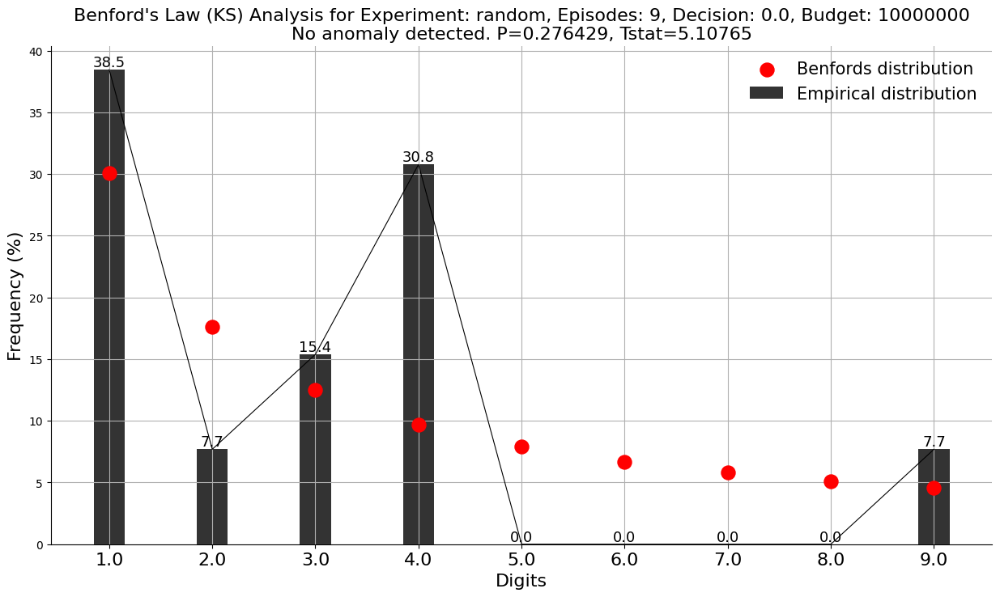

Plot saved to: .temp/experiment_results/benford_plot_random_ep9_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0797203, Tstat=8.34522


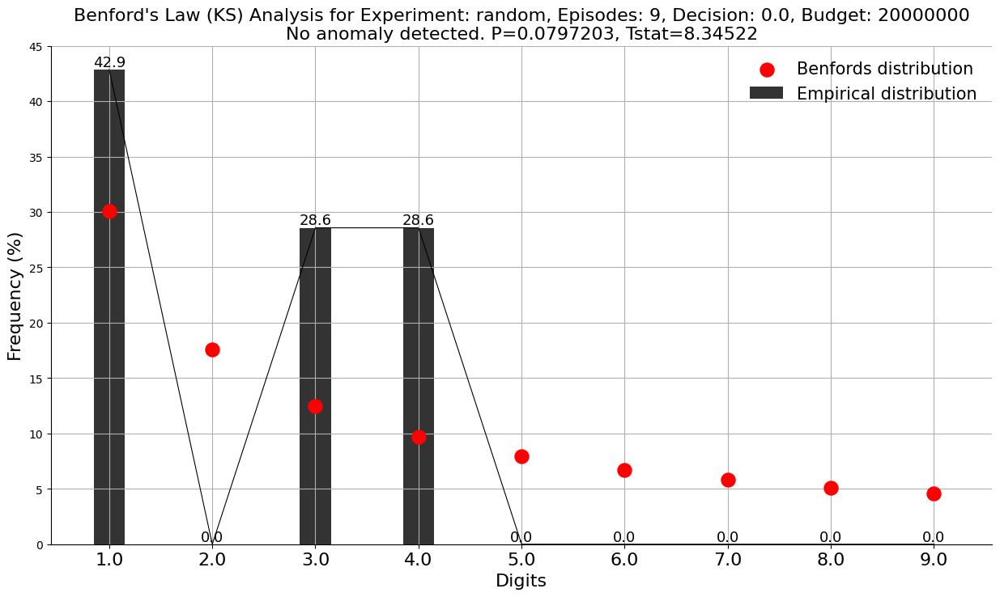

Plot saved to: .temp/experiment_results/benford_plot_random_ep9_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.359999, Tstat=4.35573


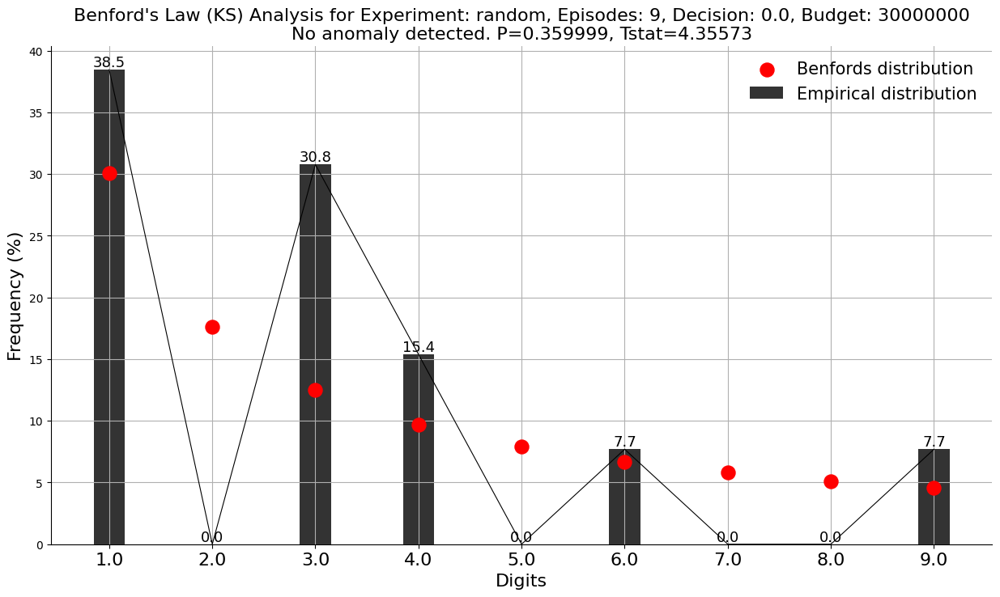

Plot saved to: .temp/experiment_results/benford_plot_random_ep9_dec0.0_budget30000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.331621, Tstat=4.59335


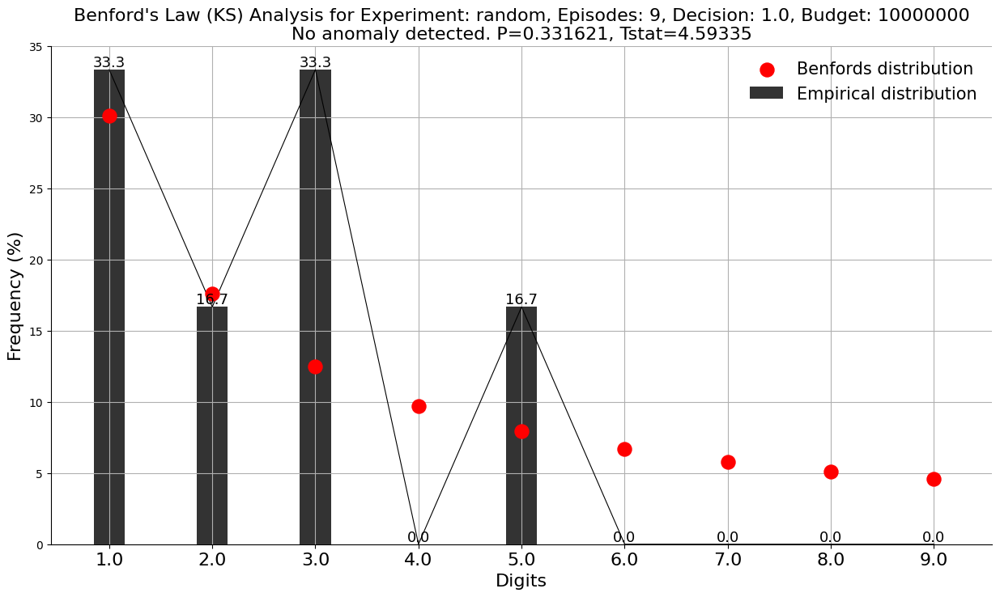

Plot saved to: .temp/experiment_results/benford_plot_random_ep9_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.093476, Tstat=7.94869


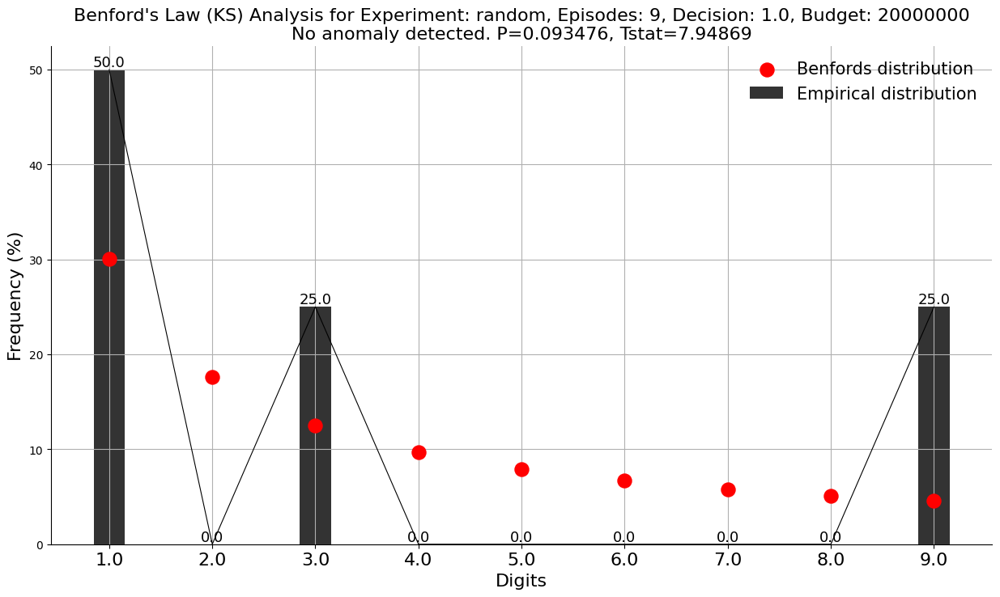

Plot saved to: .temp/experiment_results/benford_plot_random_ep9_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.291242, Tstat=4.96177


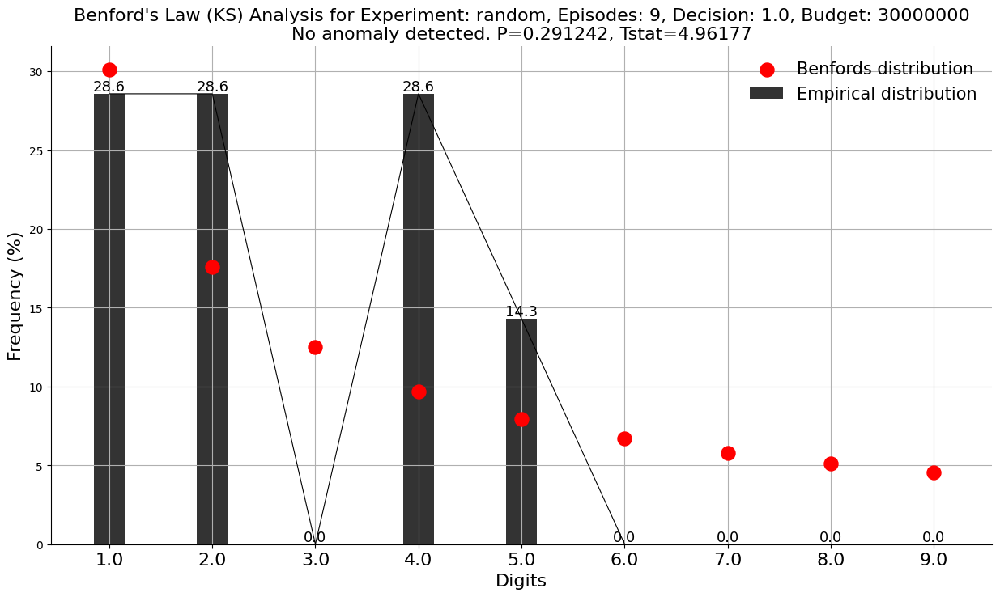

Plot saved to: .temp/experiment_results/benford_plot_random_ep9_dec1.0_budget30000000.png
Summary results saved to: .temp/experiment_results/plots/benford_summary_results.csv


In [52]:
import os
import pandas as pd
from benfordslaw import benfordslaw

# Create a directory to store the results if it doesn't exist
results_dir = ".temp/experiment_results"
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

# Initialize the Benford's Law analyzer with method='ks' for Kolmogorov-Smirnov test
bl = benfordslaw(method='freedman')

# Assuming your dataset is loaded into a DataFrame called 'data'
# The dataset includes columns: experiment, episodes, rewards, wc, woc, valor_indenizacao, initial_budget, decision

# Group the data by experiment, episodes, decision, and initial_budget
groups = data.groupby(['experiment', "episodes", 'decision', 'initial_budget'])

# Prepare a list to store summary results
summary_results = []

# Iterate over each group and apply Benford's Law analysis
for (experiment, episodes, decision, initial_budget), group in groups:
    valor_indenizacao = group['valor_indenizacao'].dropna().values
    
    if len(valor_indenizacao) == 0:
        print(f"No indemnity values available for Experiment: {experiment}, Episodes: {episodes}, Decision: {decision}, Initial Budget: {initial_budget}")
        continue
    
    # Apply Benford's Law with Kolmogorov-Smirnov test to the valor_indenizacao values
    results = bl.fit(valor_indenizacao)
    
    # Generate plot and save it
    plot_title = f"Benford's Law (KS) Analysis for Experiment: {experiment}, Episodes: {episodes}, Decision: {decision}, Budget: {initial_budget}"
    fig, ax = bl.plot(title=plot_title)
    
    # Save the plot to the results directory
    plot_filename = f"{results_dir}/benford_plot_{experiment}_ep{episodes}_dec{decision}_budget{initial_budget}.png"
    fig.savefig(plot_filename)
    print(f"Plot saved to: {plot_filename}")
    
    # Append KS results to the summary list
    summary_results.append({
        'experiment': experiment,
        'episodes': episodes,
        'decision': decision,
        'initial_budget': initial_budget,
        'KS_stat': results['t'],  # The test statistic for the KS test
        'p_value': results['P'],  # The p-value for the KS test
        'P_significant': results['P_significant'],  # whether it's significant
        'percentage_emp': results['percentage_emp']  # empirical distribution
    })

# Create a summary DataFrame
summary_df = pd.DataFrame(summary_results)

# Save the summary DataFrame to the results directory
summary_filename = f"{results_dir}/plots/benford_summary_results.csv"
summary_df.to_csv(summary_filename, index=False)
print(f"Summary results saved to: {summary_filename}")



Analyzing random, Decision 0.0, Budget 10000000, Method ks, Position 1:
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[ks] No anomaly detected. P=0.989469, Tstat=0.222222


KeyError: 'P_Freedman'

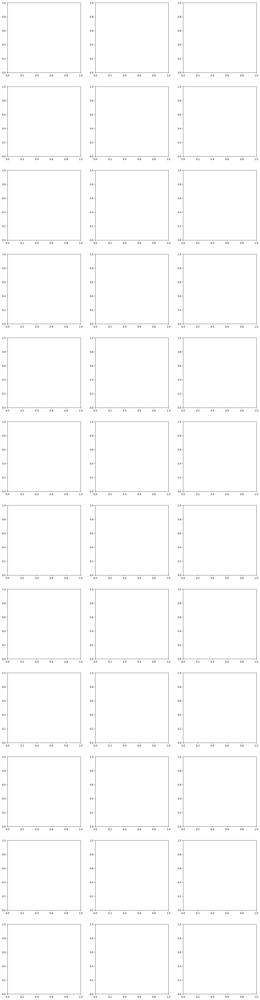

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
from benfordslaw import benfordslaw
import os

class BenfordAnalyzer:
    def __init__(self, data, experiments, decisions, budgets, methods, save_dir="../temp/plots"):
        """
        Initialize the BenfordAnalyzer with dataset, experiment, decision, and budget combinations.
        """
        self.data = data.dropna(subset=['value'])  # Clean the data by dropping NaN values
        self.experiments = experiments
        self.decisions = decisions
        self.budgets = budgets
        self.methods = methods  # Added to handle different methods (e.g., KS, Freedman, Chi-squared)
        self.save_dir = save_dir  # Directory to save plots
        self.results = []  # To store the results for each experiment, decision, budget
        if not os.path.exists(self.save_dir):
            os.makedirs(self.save_dir)

    def analyze(self):
        """
        Analyze the dataset using Benford's Law for the first three digits across various combinations.
        """
        # Determine the number of plot rows required
        total_plots = len(self.experiments) * len(self.decisions) * len(self.budgets)
        ncols = 3  # Fixed number of columns for 1st, 2nd, and 3rd digits
        nrows = total_plots  # Number of rows is total plots, as we have 3 columns per row

        fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 6 * nrows))

        # Flatten axes array to easily reference each plot position
        axes = axes.reshape(-1, ncols)

        plot_idx = 0  # Keeps track of plot position for each combination

        # Loop through each combination
        for experiment in self.experiments:
            for decision in self.decisions:
                for initial_budget in self.budgets:
                    for method in self.methods:
                        # Filter dataset for the specific combination
                        subset = self.data[(self.data['experiment'] == experiment) & 
                                           (self.data['decision'] == decision) & 
                                           (self.data['initial_budget'] == initial_budget)]
                        
                        # Check if there are values to analyze
                        if subset.empty:
                            print(f"No data for {experiment}, Decision {decision}, Budget {initial_budget}.")
                            continue
                        
                        # Perform Benford's Law analysis and plot all positions in one row (1st, 2nd, and 3rd digit)
                        self._analyze_subset(subset, experiment, decision, initial_budget, method, axes[plot_idx])
                        plot_idx += 1

        # Hide any unused subplots
        for i in range(plot_idx, len(axes)):
            for ax in axes[i]:
                ax.remove()  # Remove any extra unused axes

        # Save the entire report as a one-page PNG file
        report_filename = f"{self.save_dir}/benford_report.png"
        plt.tight_layout()
        plt.subplots_adjust(top=0.95)
        plt.savefig(report_filename)
        plt.show()
        print(f"Report saved to {report_filename}")
        plt.close(fig)  # Close the figure

        # Save the statistical results to CSV
        results_df = pd.DataFrame(self.results)
        results_csv_path = "../temp/data/experiment_results/insurenv/benford_results.csv"
        results_df.to_csv(results_csv_path, index=False)
        print(f"Results saved to {results_csv_path}")

    def _analyze_subset(self, subset, experiment, decision, initial_budget, method, axes_row):
        """
        Helper function to analyze a specific subset of data for the first three digit positions and plot them.
        Adds annotations to the plots with statistical results and stores these results.
        """
        # Perform Benford's Law analysis for each position (1st, 2nd, and 3rd digit)
        for pos in range(1, 4):  # Looping through first, second, and third digits
            benford = benfordslaw(pos=pos, method=method)  # Now using the method parameter
            values = subset['value'].astype(float).values

            print(f"Analyzing {experiment}, Decision {decision}, Budget {initial_budget}, Method {method}, Position {pos}:")
            
            # Fit the data to Benford's Law
            benford.fit(values)
            
            # Store the statistical results
            result_entry = {
                'experiment': experiment,
                'decision': decision,
                'initial_budget': initial_budget,
                'method': method,
                'digit_position': pos,
                'p_value_ks': benford.results['P'],  # KS test p-value
                'p_value_freedman': benford.results['P_Freedman'],  # Freedman test p-value
                'p_value_chi2': benford.results['P_Chi2'],  # Chi-squared test p-value
                'test_stat_ks': benford.results['t'],  # KS test statistic
                'test_stat_freedman': benford.results['t_Freedman'],  # Freedman test statistic
                'test_stat_chi2': benford.results['t_Chi2'],  # Chi-squared test statistic
                'anomaly_detected': benford.results['P_significant']  # Whether an anomaly was detected
            }
            self.results.append(result_entry)

            # Adjust digit range depending on the digit position
            if pos == 1:
                digit_range = range(1, 10)  # Digits 1 to 9
            else:
                digit_range = range(0, 10)  # Digits 0 to 9 for positions 2 and 3
            
            # Plot empirical and expected Benford distribution
            axes = axes_row[pos - 1]
            axes.bar(digit_range, benford.results['percentage_emp'][:, 1], color='blue', alpha=0.7, label='Empirical')
            axes.plot(digit_range, benford.leading_digits, 'r-', label='Benford', linewidth=2)
            axes.set_title(f'Position {pos} Digit Distribution - {experiment}, Decision {decision}, Budget {initial_budget}, Method {method}')
            axes.set_xlabel('Digit')
            axes.set_ylabel('Percentage')
            axes.legend()

            # Add annotations directly on the plot
            p_value = benford.results['P']
            t_stat = benford.results['t']
            anomaly_detected = benford.results['P_significant']
            annotation_text = f"Test statistic: {t_stat:.2f}\nP-value: {p_value:.5f}\nAnomaly: {anomaly_detected}"
            axes.text(0.95, 0.95, annotation_text, transform=axes.transAxes, fontsize=10,
                      verticalalignment='top', horizontalalignment='right', bbox=dict(facecolor='white', alpha=0.5))

    def summarize(self):
        """
        Generate automated reports based on the analysis.
        This could be expanded to generate CSV reports, alerts, etc.
        """
        print("Summary of Benford's Law Analysis:")
        # This is a placeholder; you could expand this to create more detailed reports or alerts
        # based on the goodness-of-fit test results.


# Example usage:
# Assuming `data` is your DataFrame with the necessary columns
experiments = ['random', 'dqn']
decisions = [0.0, 1.0]
budgets = list(data.initial_budget.unique())
methods = ['ks', 'freedman', 'chi2']  # Define the methods you want to use

# Create an instance of the BenfordAnalyzer class
benford_analyzer = BenfordAnalyzer(data, experiments, decisions, budgets, methods)

# Perform the analysis
benford_analyzer.analyze()

# Optionally, generate a summary report
benford_analyzer.summarize()


[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.310847, Tstat=4.77797


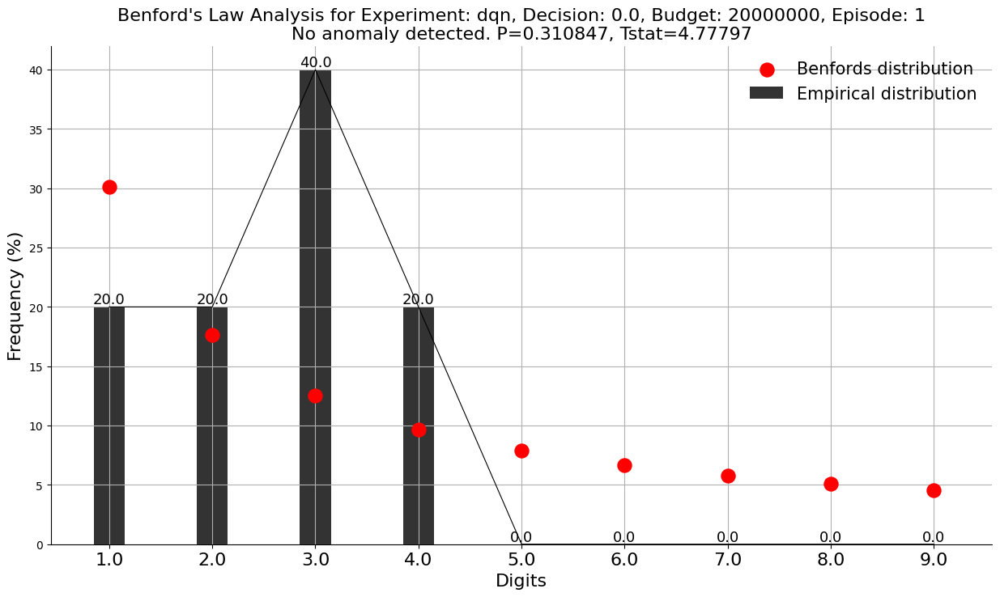

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000_episode1.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.142155, Tstat=6.88385


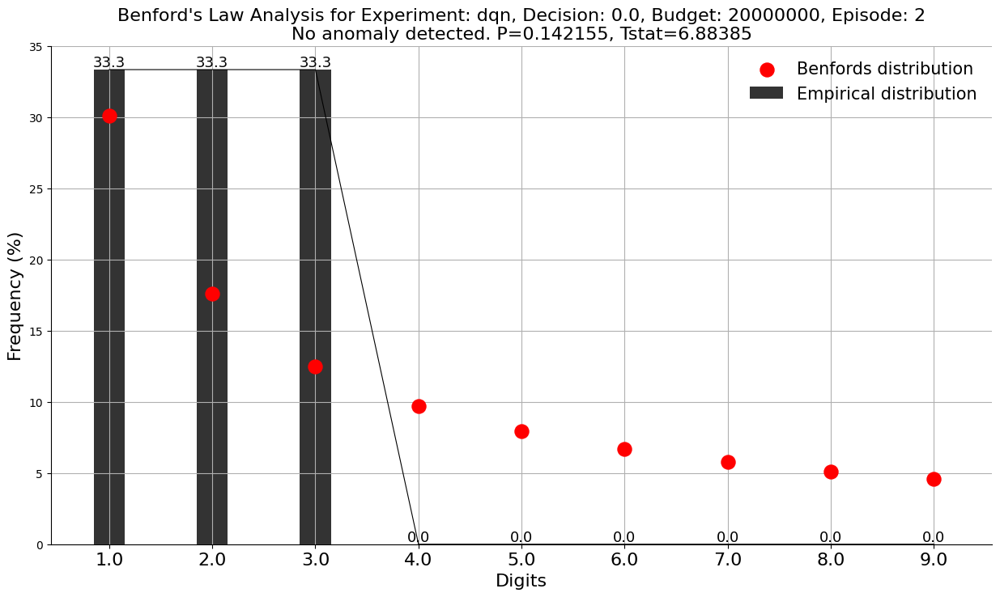

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.667268, Tstat=2.37435


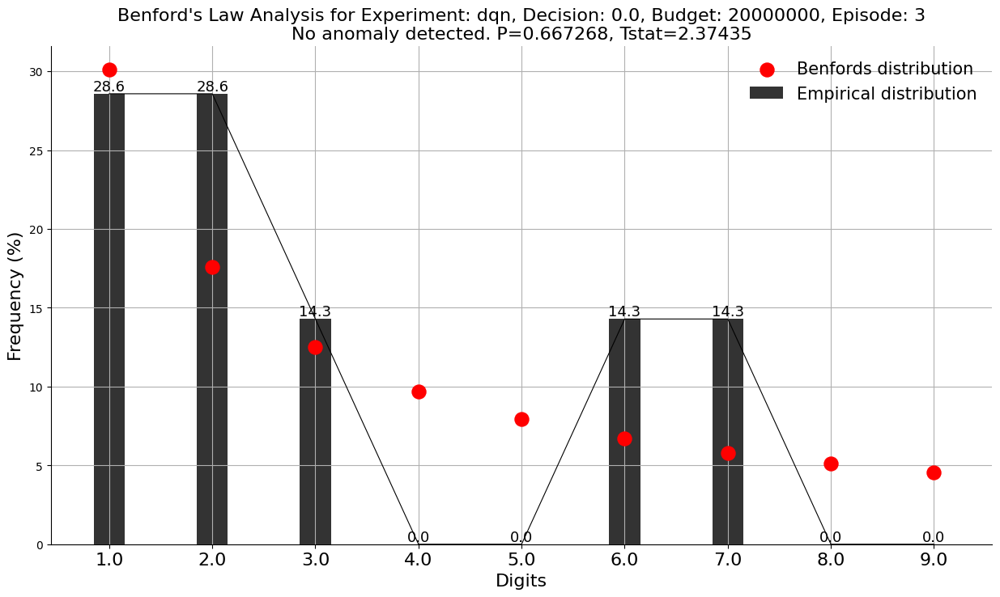

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0718944, Tstat=8.60065


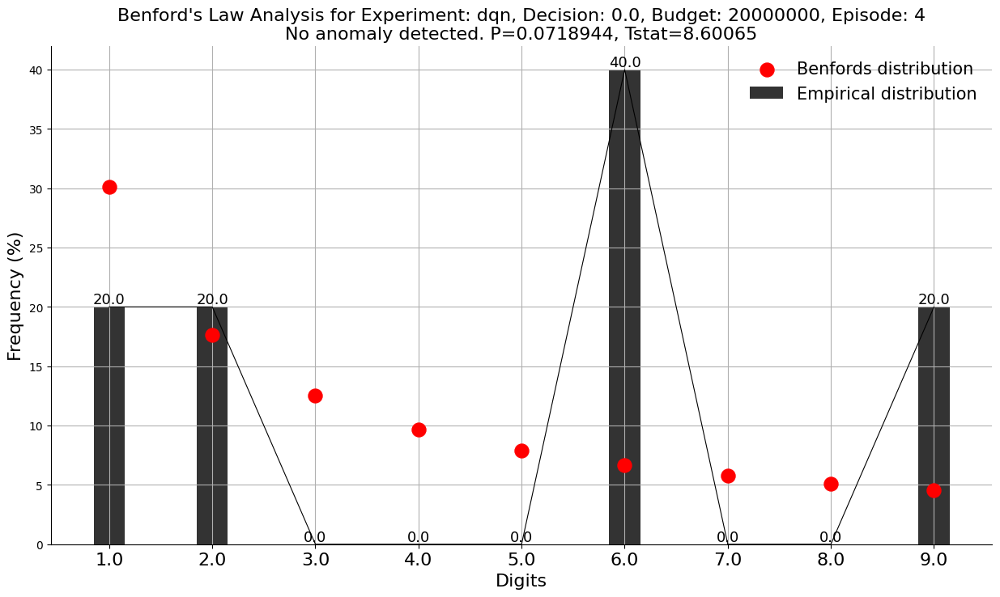

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0155856, Tstat=12.25


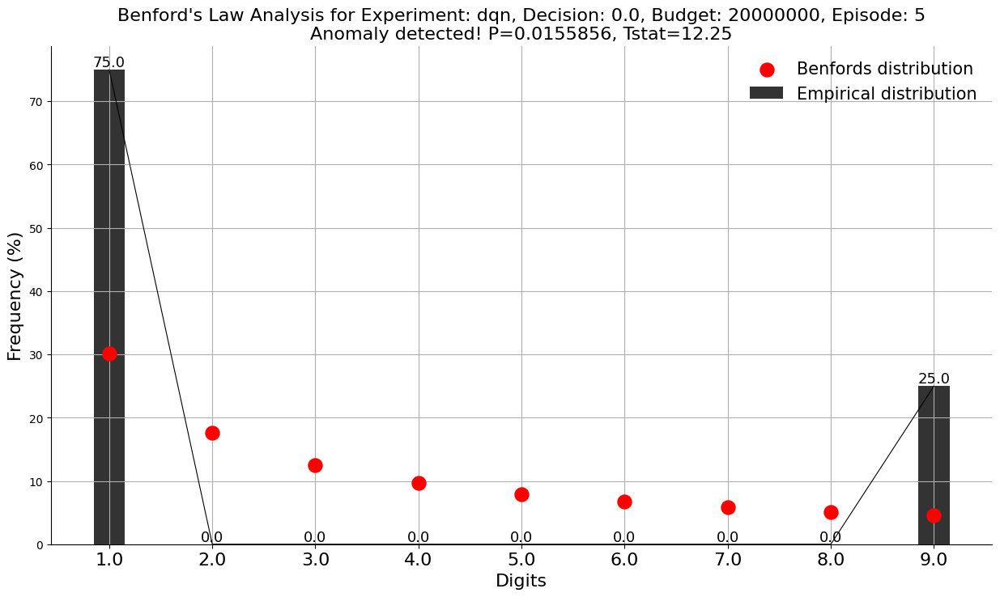

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0727958, Tstat=8.56993


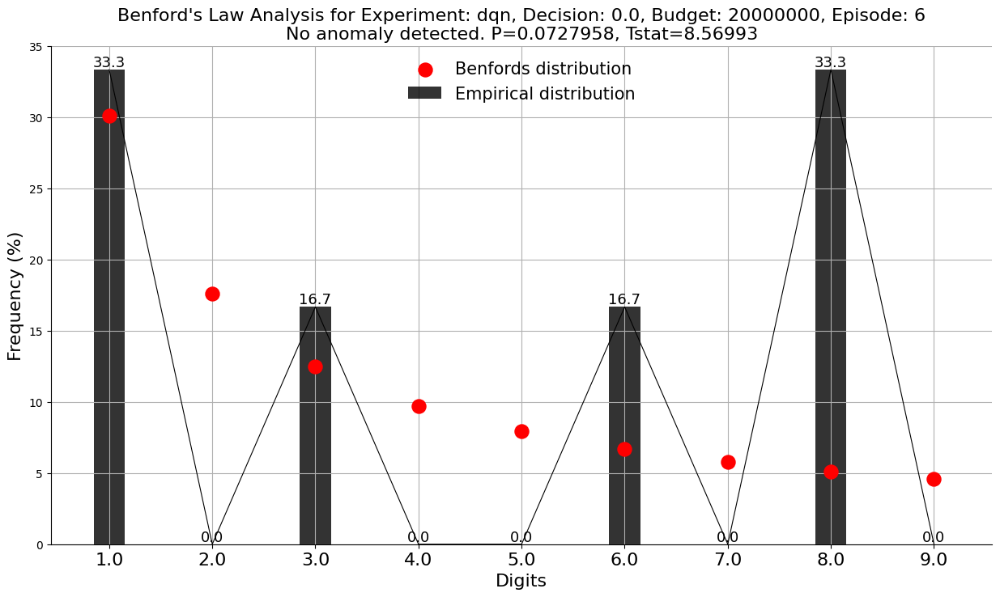

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.131892, Tstat=7.07666


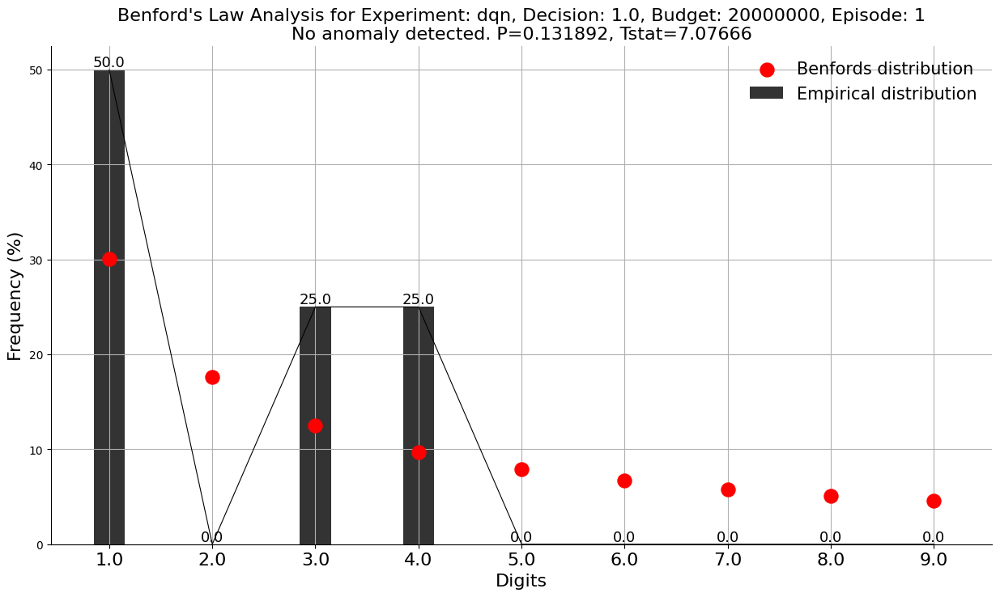

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000_episode1.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.233203, Tstat=5.57514


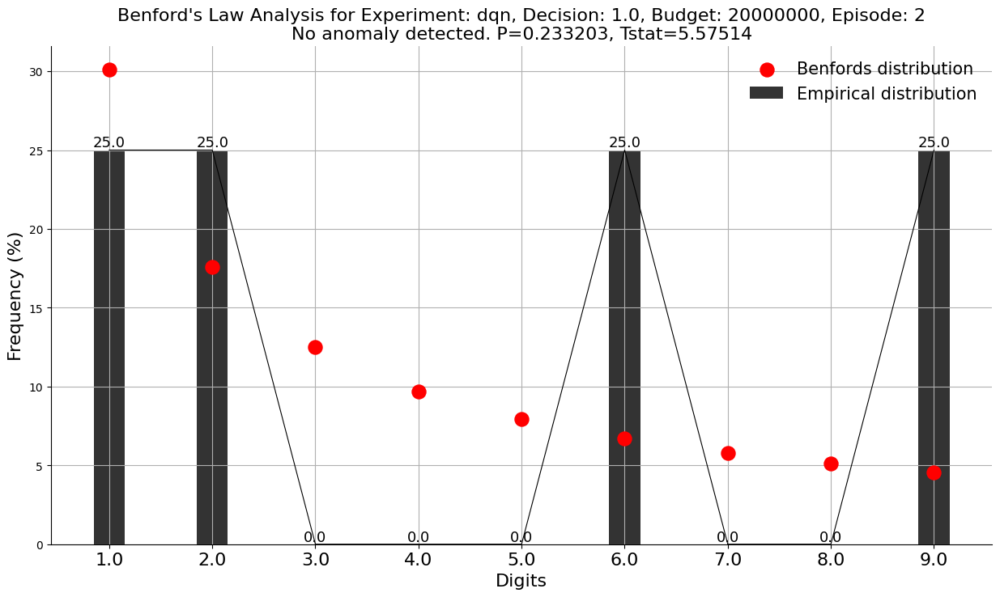

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0896608, Tstat=8.05286


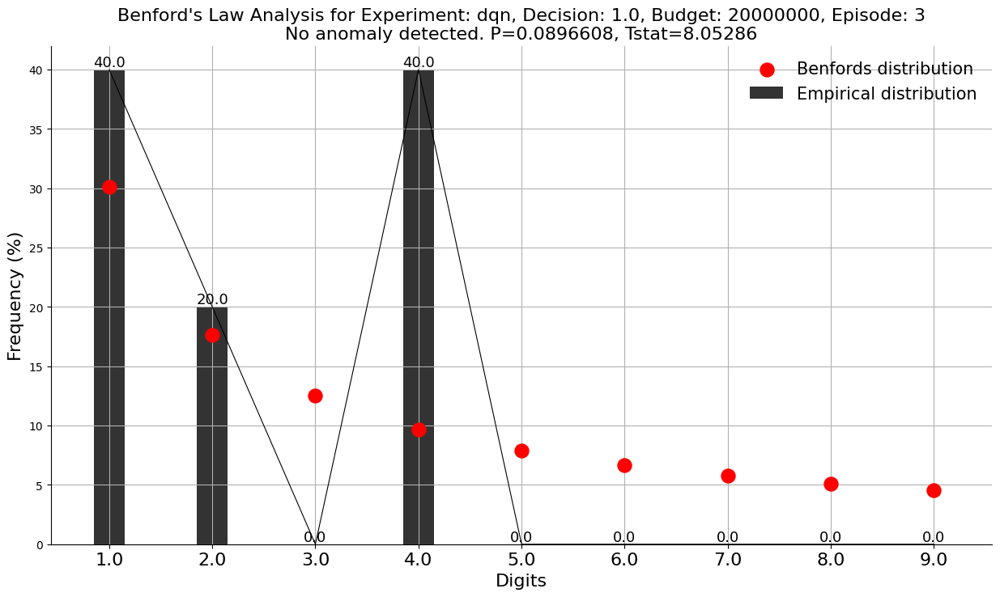

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.344957, Tstat=4.47974


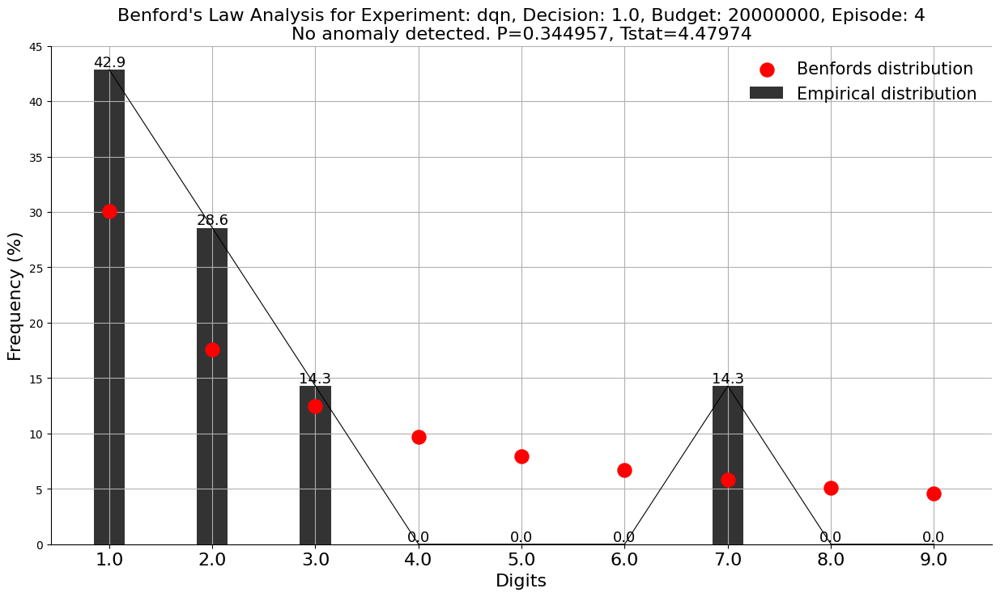

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.128483, Tstat=7.14376


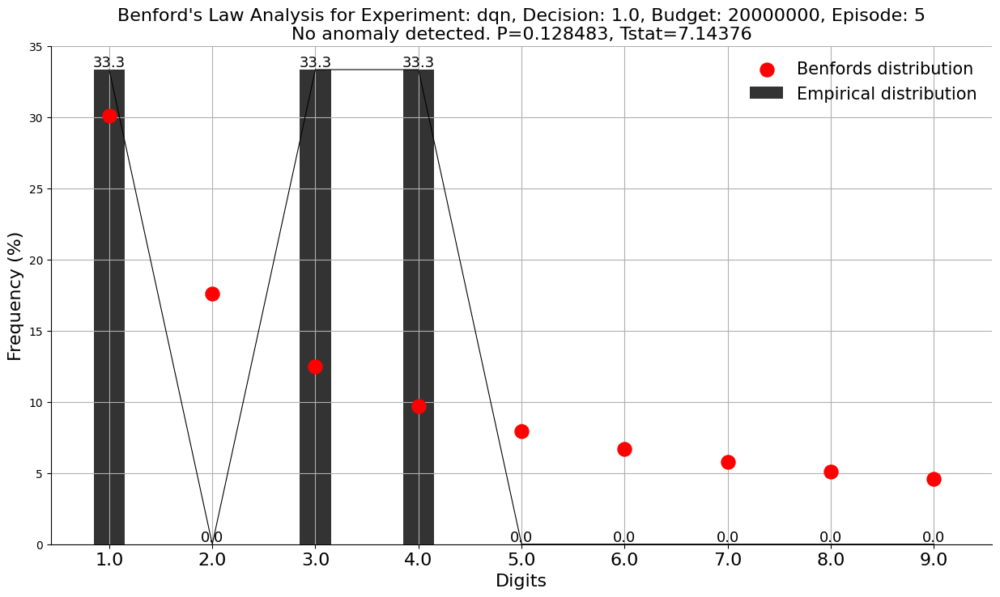

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.164319, Tstat=6.50749


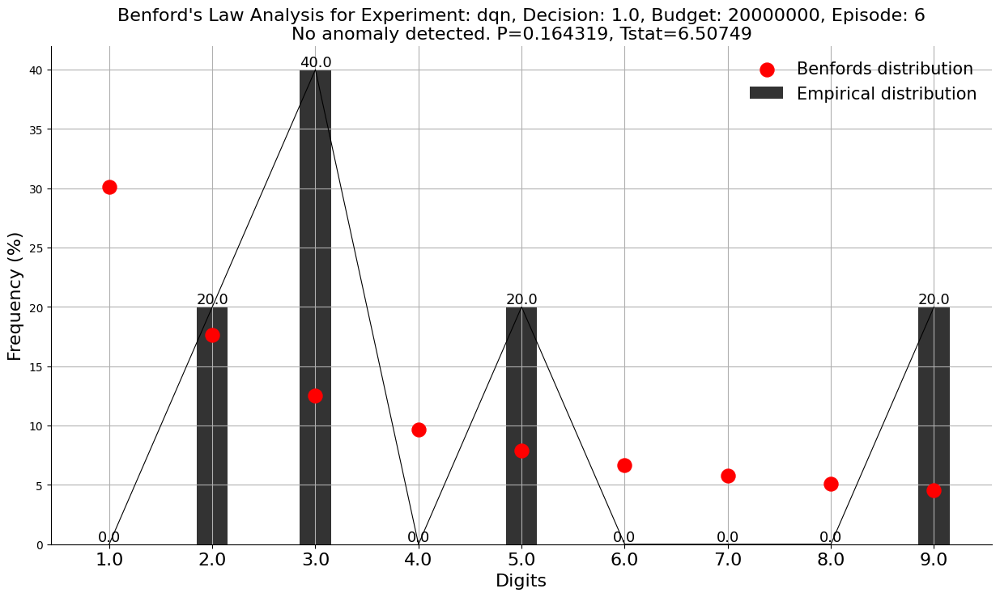

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0177328, Tstat=11.9492


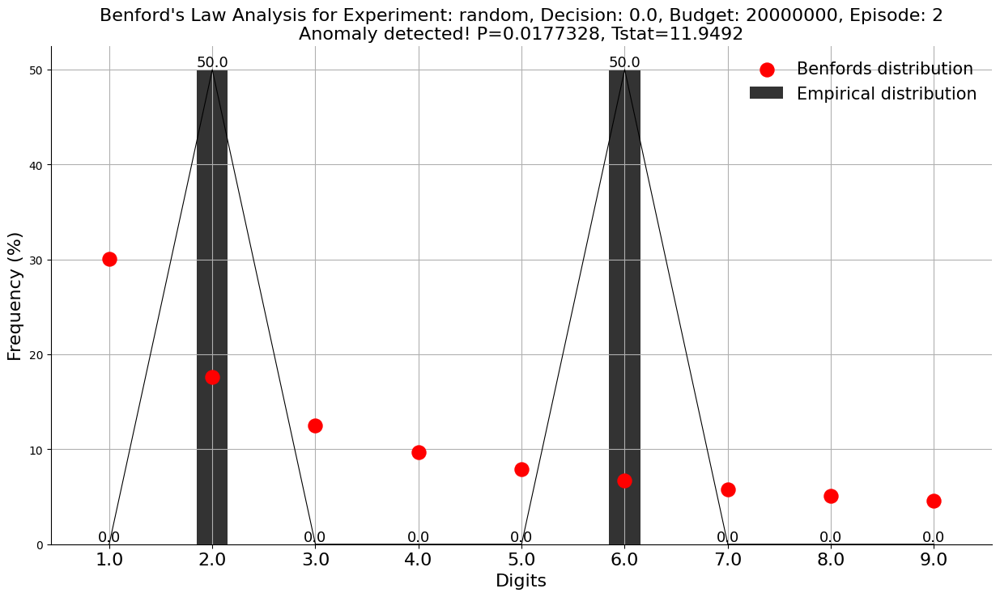

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0308949, Tstat=10.6421


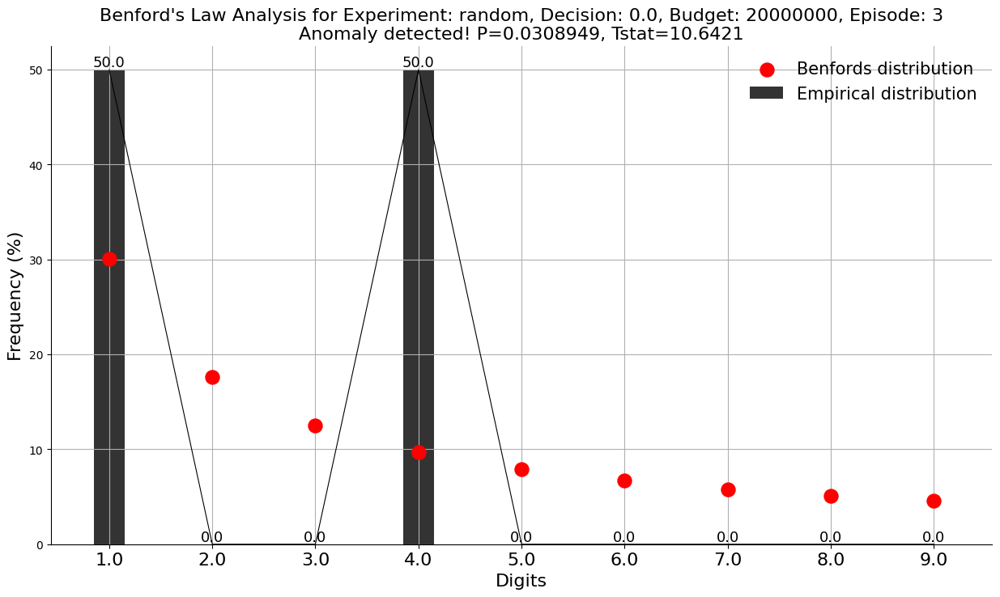

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.212204, Tstat=5.83006


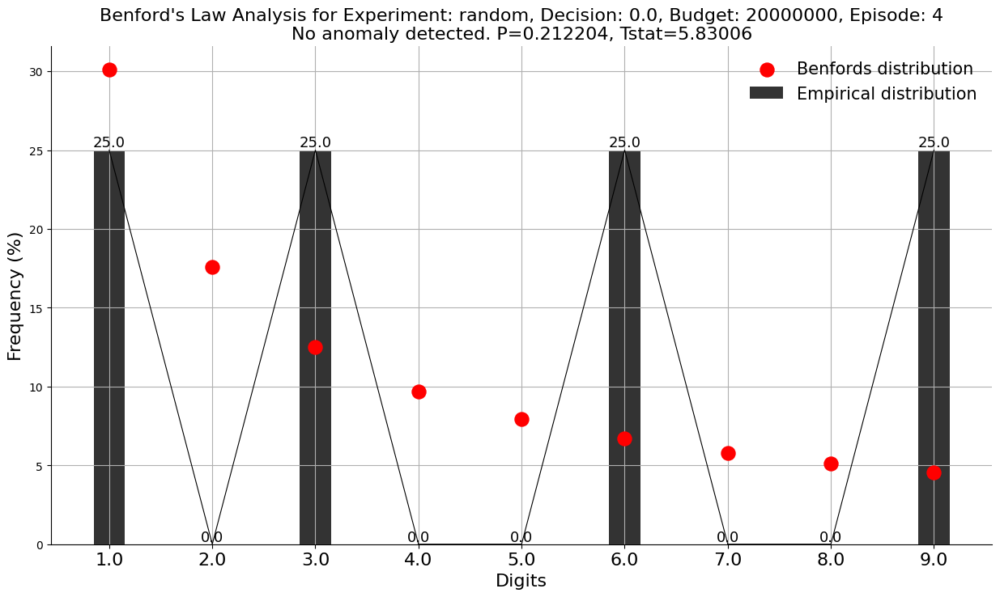

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00430483, Tstat=15.1995


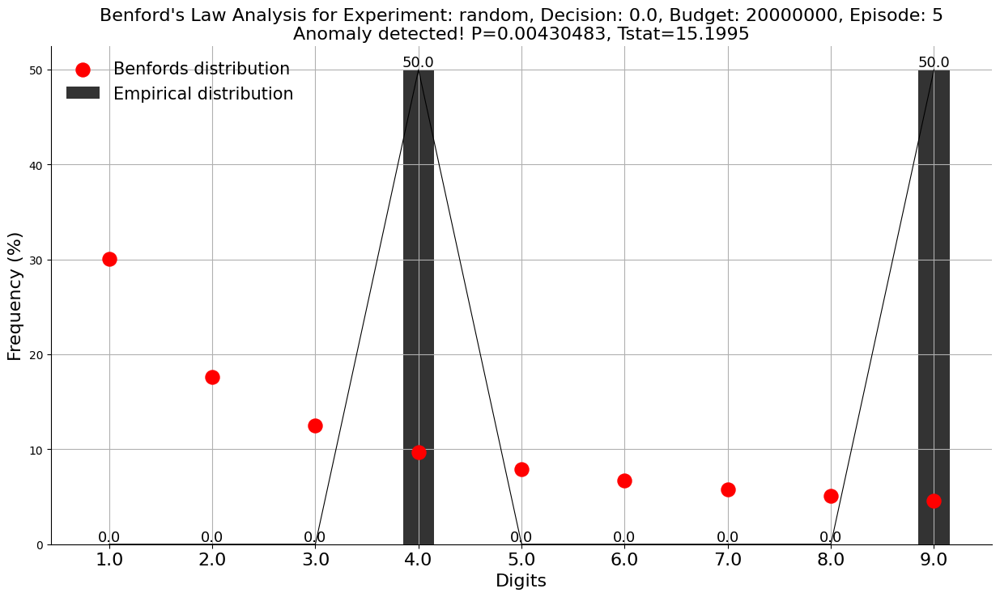

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.021819, Tstat=11.4636


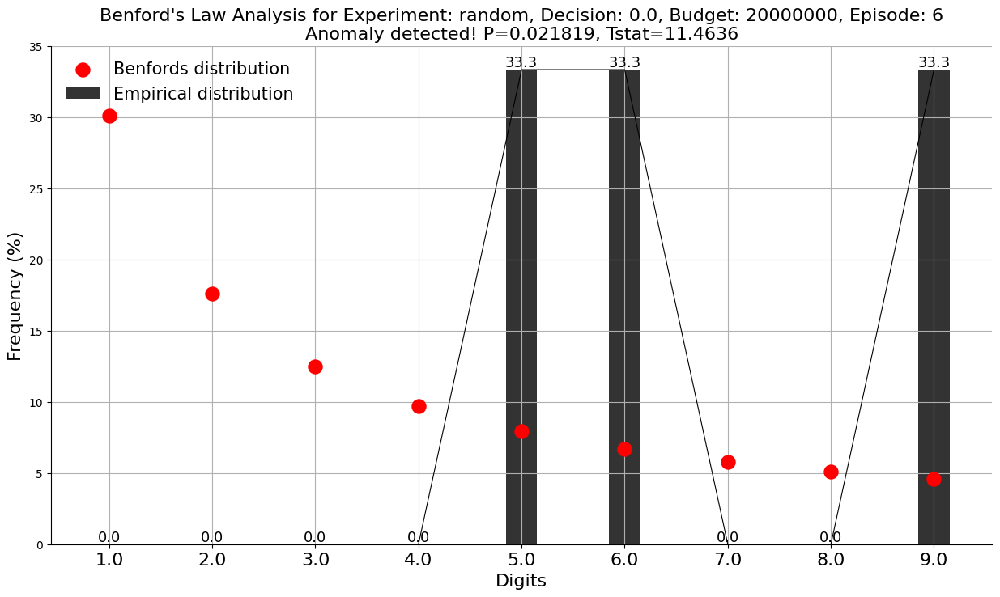

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0175504, Tstat=11.9734


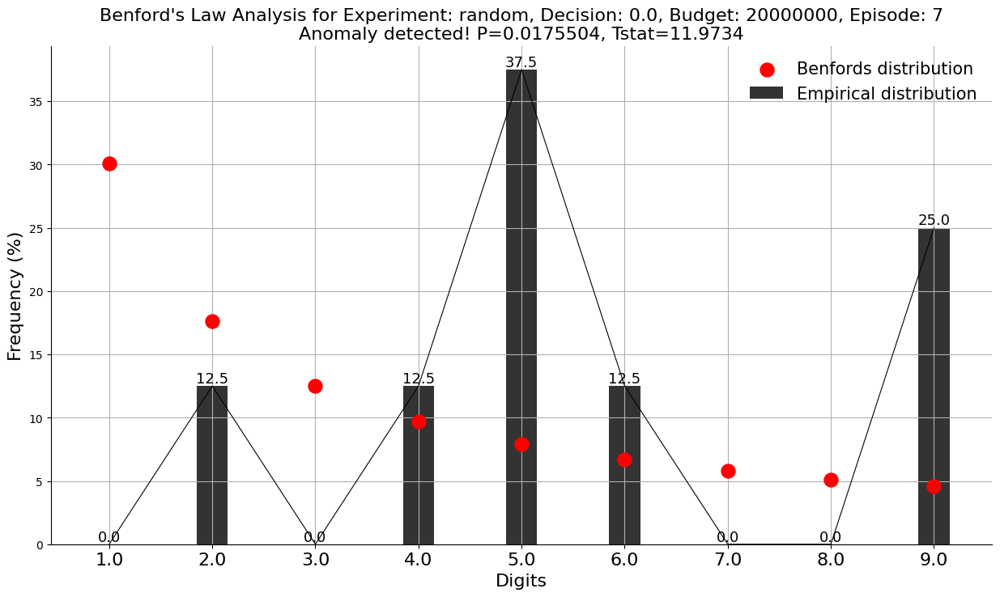

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode7.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.381597, Tstat=4.18461


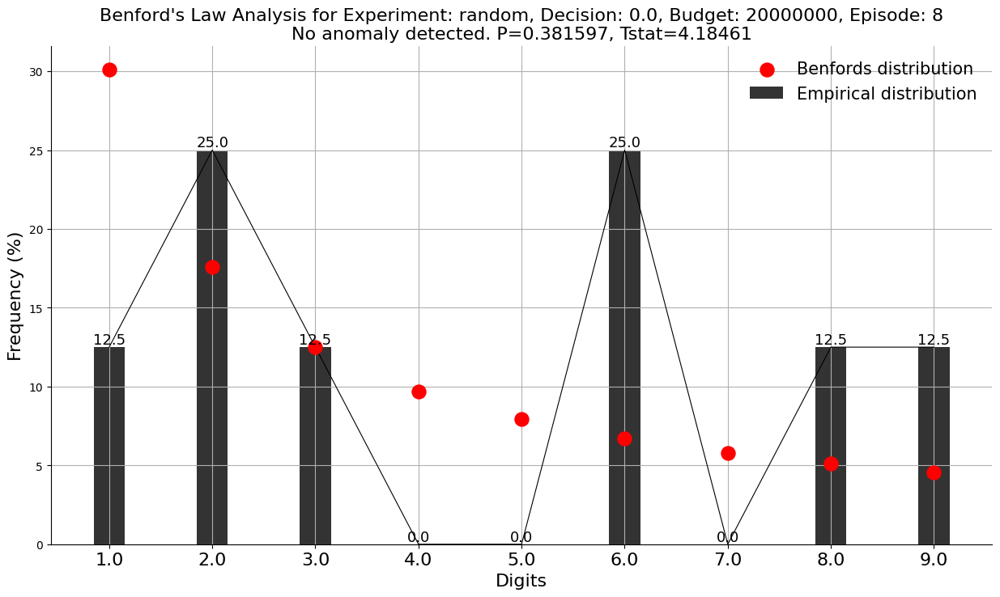

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode8.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0797203, Tstat=8.34522


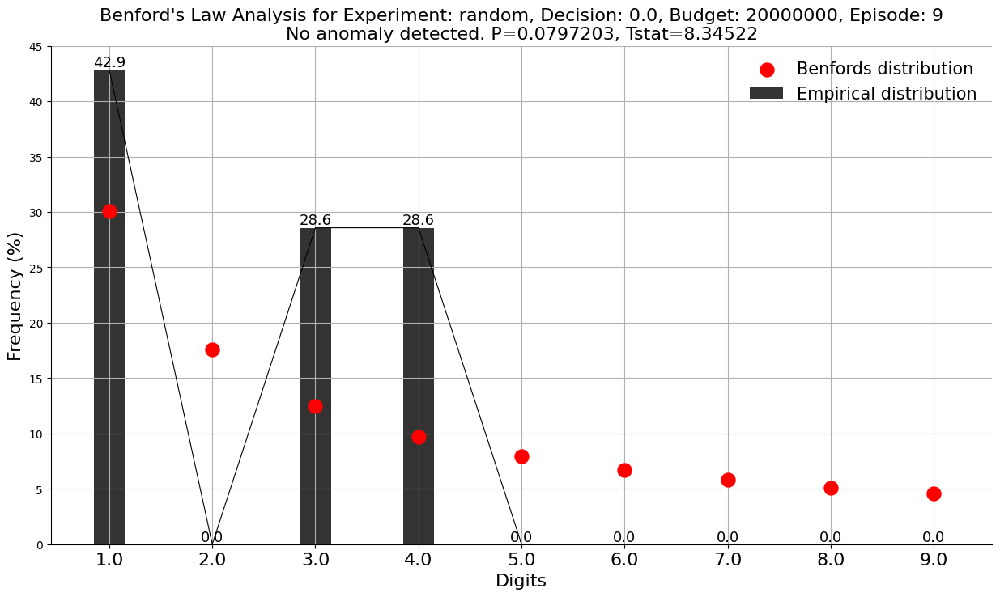

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000_episode9.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0332745, Tstat=10.4656


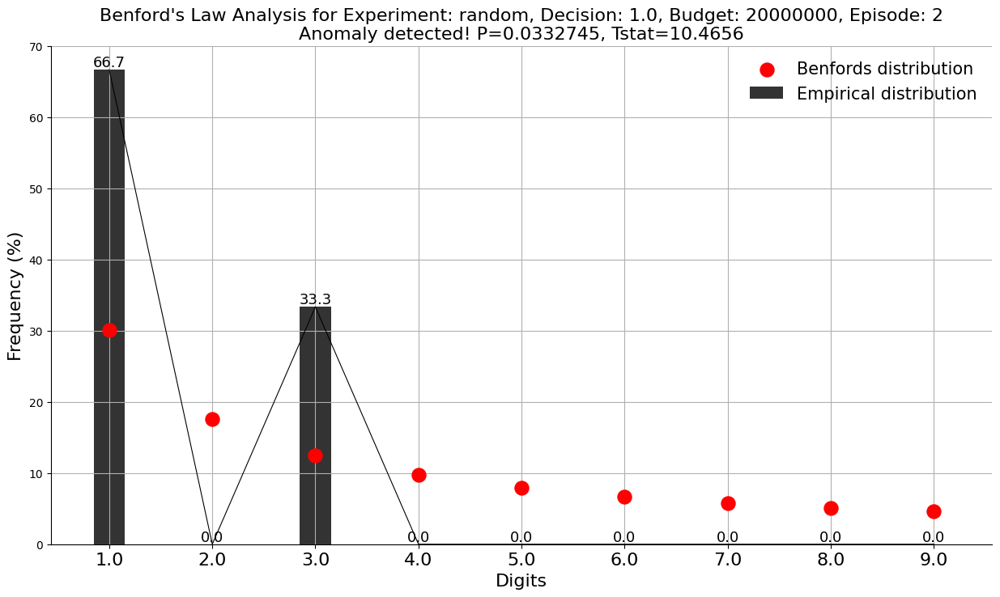

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode2.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0761977, Tstat=8.45712


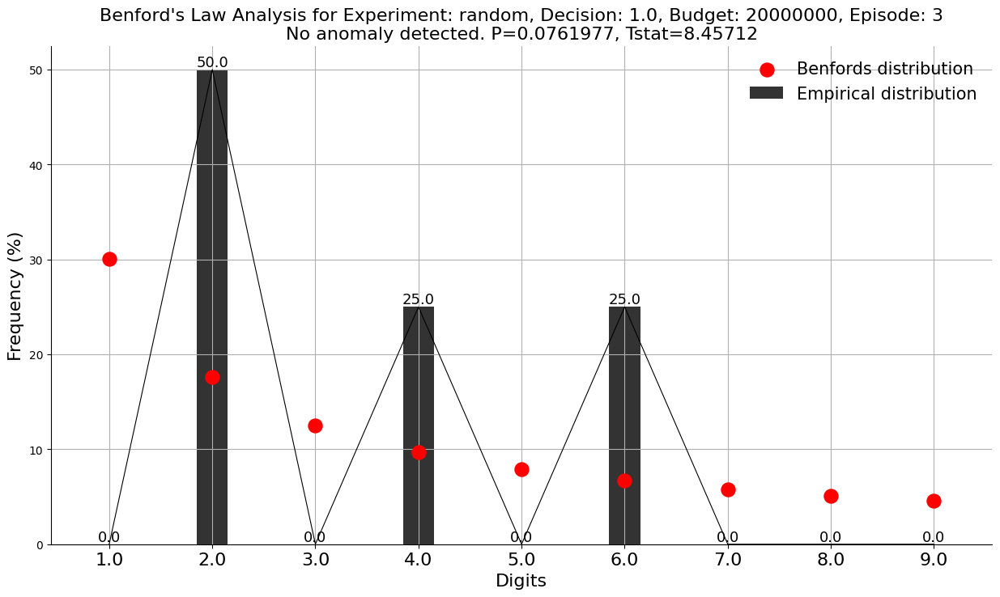

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode3.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.257011, Tstat=5.30926


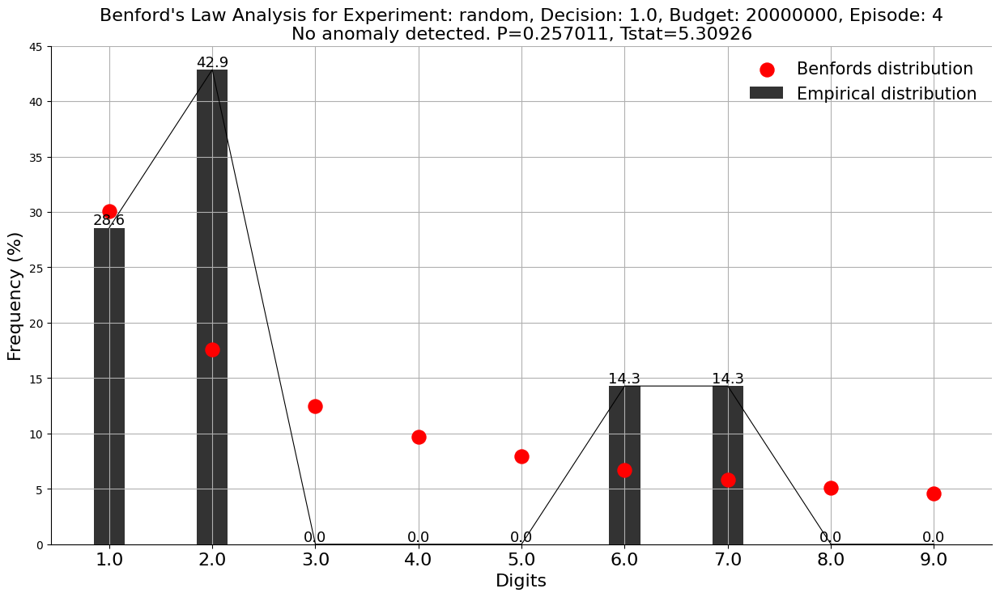

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode4.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00353024, Tstat=15.6477


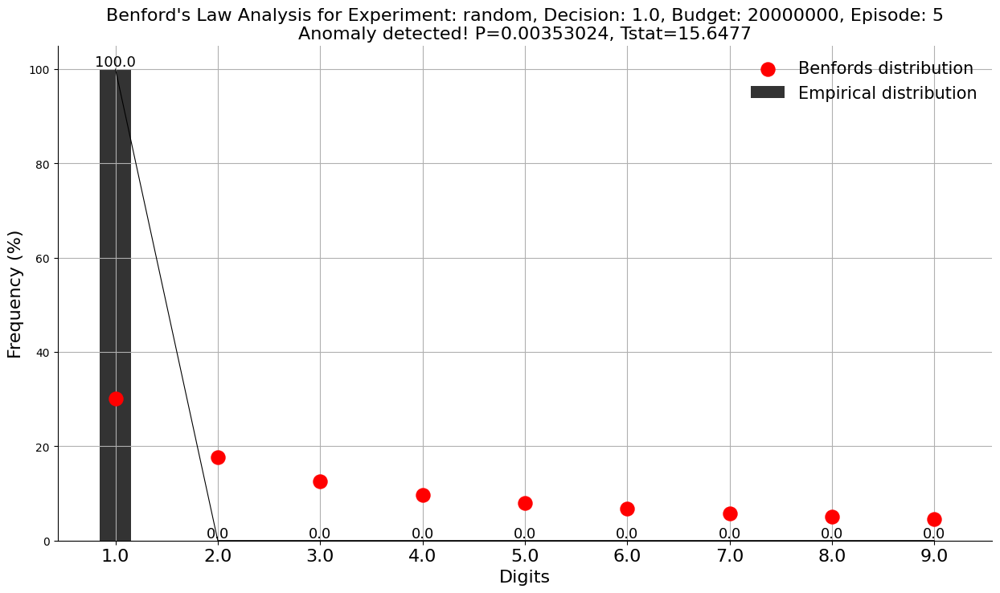

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode5.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0140021, Tstat=12.499


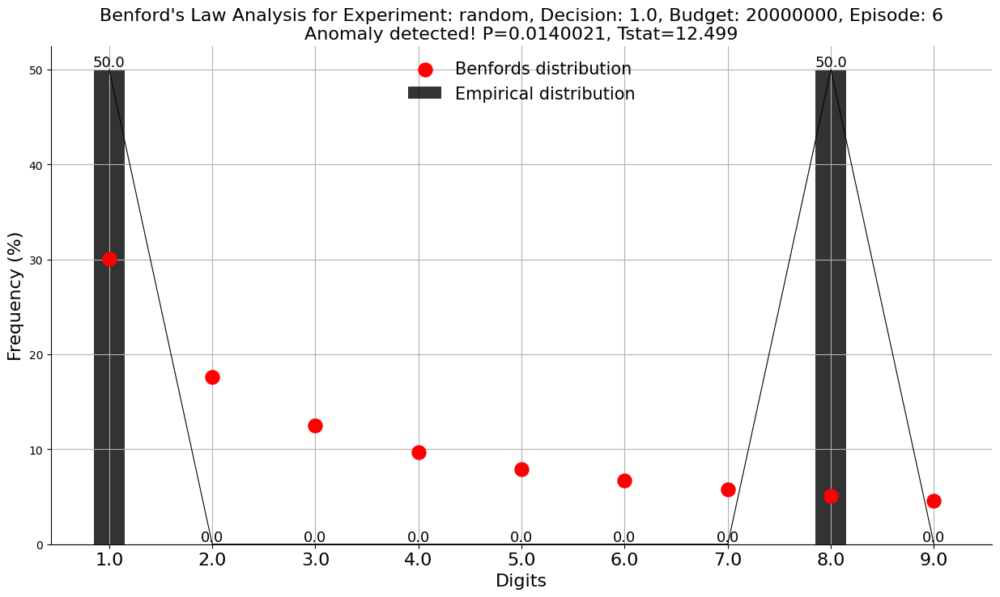

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode6.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.000759068, Tstat=19.0769


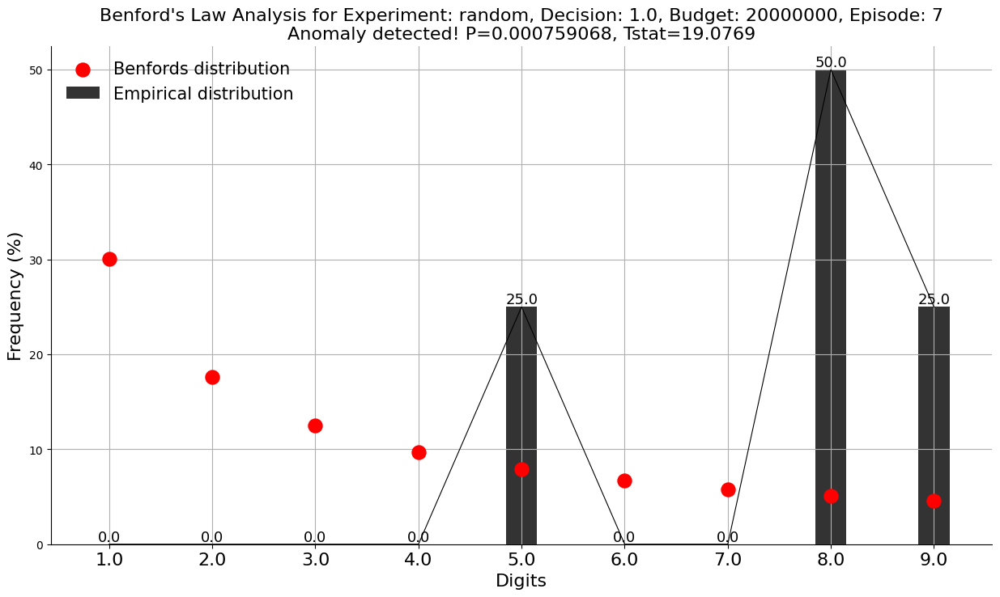

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode7.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0625288, Tstat=8.94344


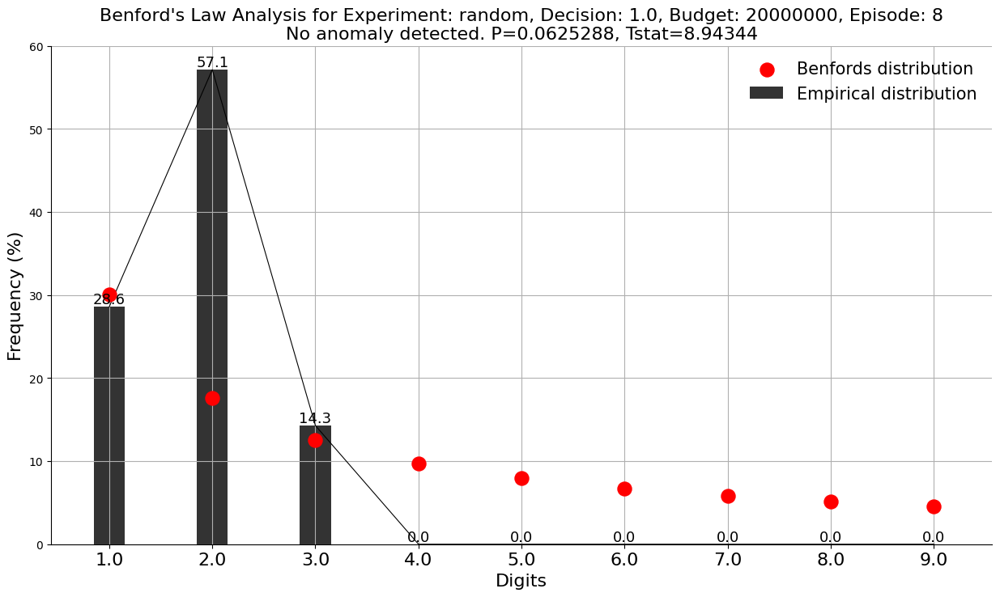

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode8.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.093476, Tstat=7.94869


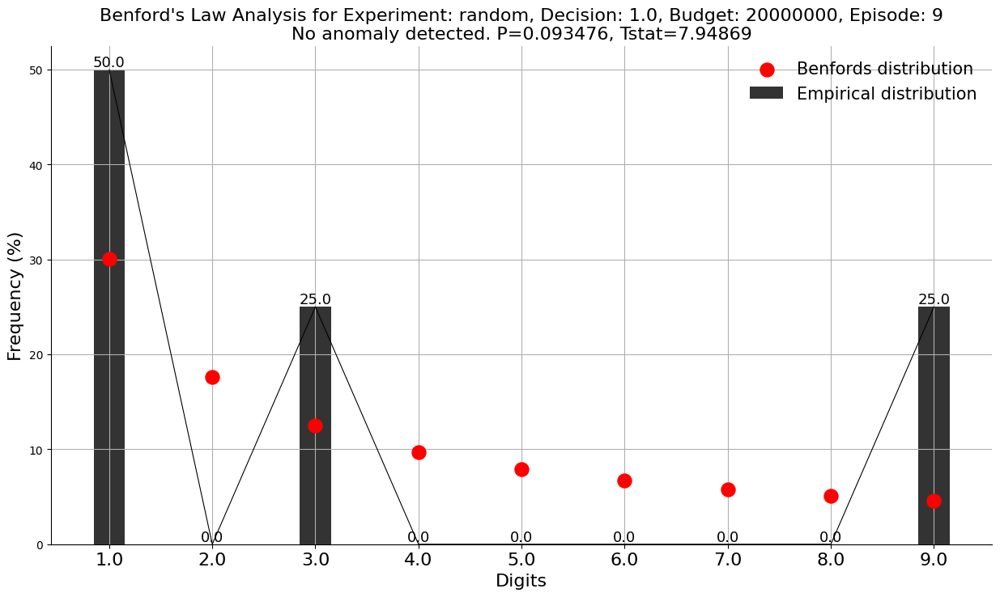

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000_episode9.png
Summary results saved to: .temp/experiment_results/benford_summary_results.csv


In [40]:
import os
import pandas as pd
from benfordslaw import benfordslaw

# Create a directory to store the results if it doesn't exist
results_dir = ".temp/experiment_results"
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

# Initialize the Benford's Law analyzer with method='ssd' for the Chi-squared test
bl = benfordslaw(method='ssd')

# Assuming your dataset is loaded into a DataFrame called 'data'
# The dataset includes columns: experiment, rewards, wc, woc, valor_indenizacao, initial_budget, decision, episode

# Group the data by experiment, decision, initial_budget, and episode
groups = data.groupby(['experiment', 'decision', 'initial_budget', 'episodes'])

# Prepare a list to store summary results
summary_results = []

# Iterate over each group and apply Benford's Law analysis
for (experiment, decision, initial_budget, episode), group in groups:
    valor_indenizacao = group['valor_indenizacao'].dropna().values
    
    if len(valor_indenizacao) == 0:
        print(f"No indemnity values available for Experiment: {experiment}, Decision: {decision}, Initial Budget: {initial_budget}, Episode: {episode}")
        continue
    
    # Apply Benford's Law to the valor_indenizacao values
    results = bl.fit(valor_indenizacao)
    
    # Generate plot and save it
    plot_title = f"Benford's Law Analysis for Experiment: {experiment}, Decision: {decision}, Budget: {initial_budget}, Episode: {episode}"
    fig, ax = bl.plot(title=plot_title)
    
    # Save the plot to the results directory
    plot_filename = f"{results_dir}/benford_plot_{experiment}_dec{decision}_budget{initial_budget}_episode{episode}.png"
    fig.savefig(plot_filename)
    print(f"Plot saved to: {plot_filename}")
    
    # Append results to the summary list
    summary_results.append({
        'experiment': experiment,
        'decision': decision,
        'initial_budget': initial_budget,
        'episode': episode,
        'KS_stat': results['t'],  # The test statistic for the KS test
        'p_value': results['P'],  # The p-value for the KS test
        'P_significant': results['P_significant'],  # whether it's significant
        'percentage_emp': results['percentage_emp']  # empirical distribution
    })

# Create a summary DataFrame
summary_df = pd.DataFrame(summary_results)

# Save the summary DataFrame to the results directory
summary_filename = f"{results_dir}/benford_summary_results.csv"
summary_df.to_csv(summary_filename, index=False)
print(f"Summary results saved to: {summary_filename}")


[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.37919, Tstat=4.20331


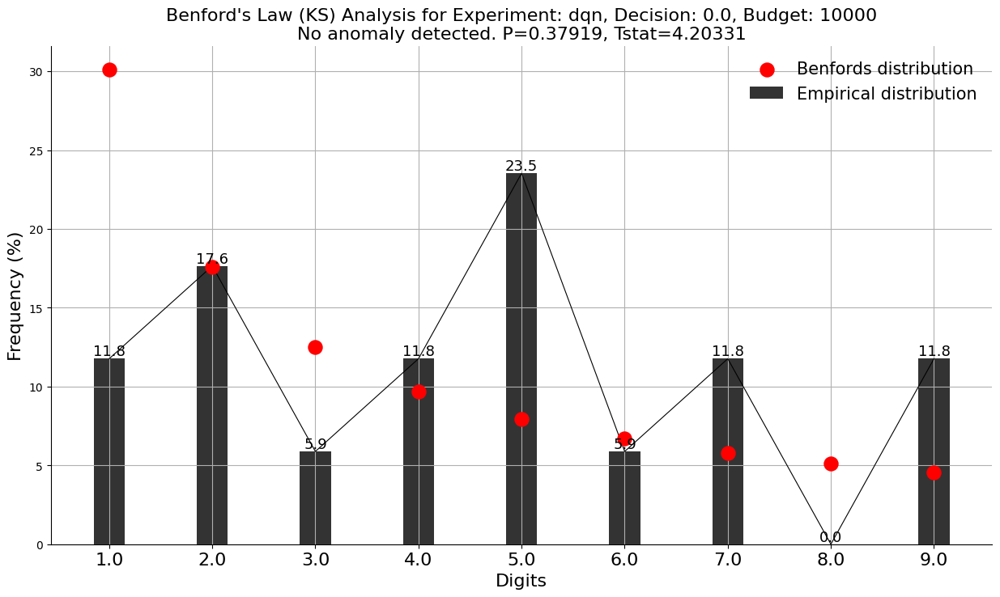

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget10000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.454847, Tstat=3.65403


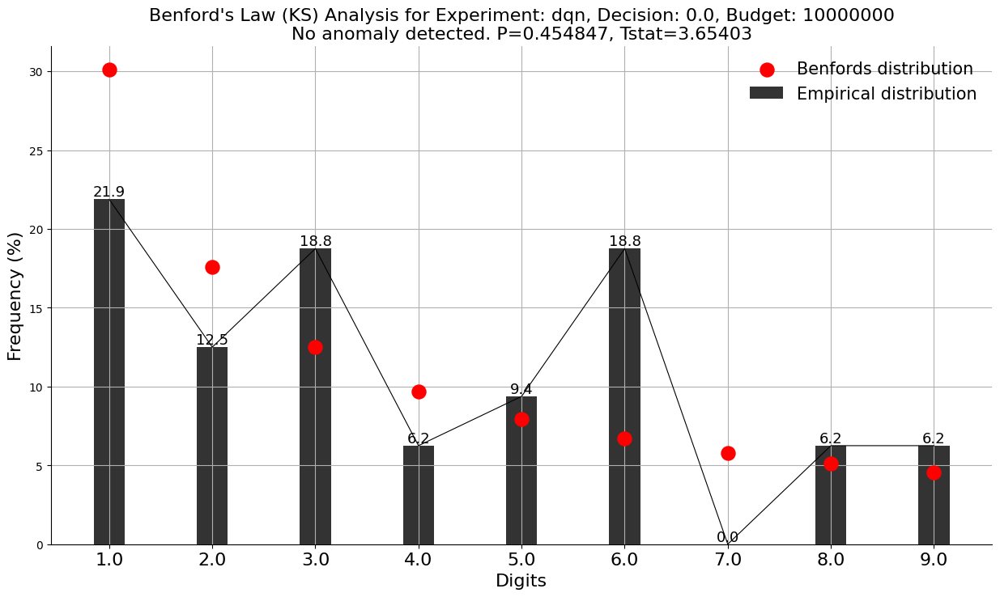

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.74883, Tstat=1.92892


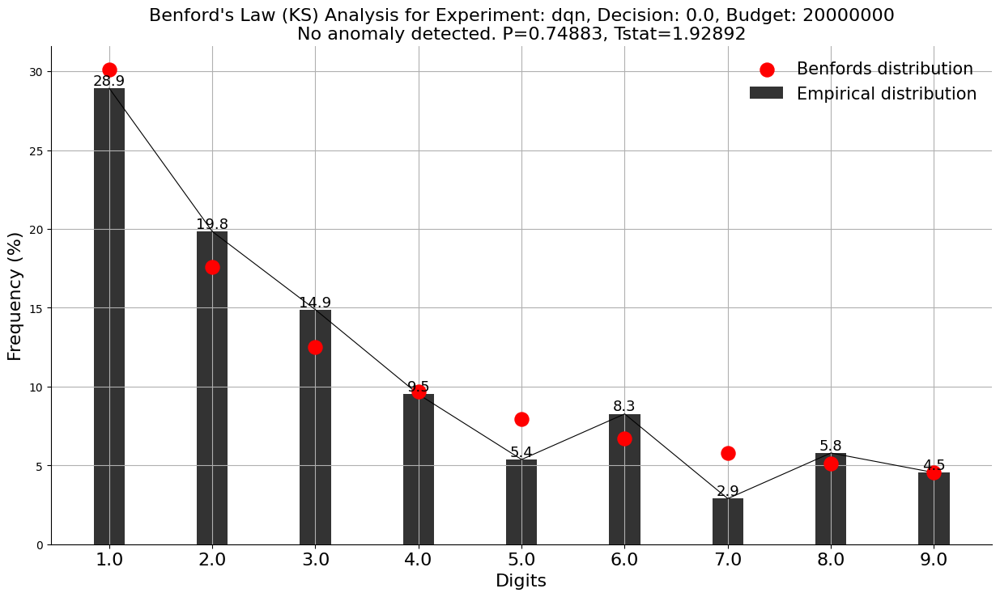

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.69391, Tstat=2.22798


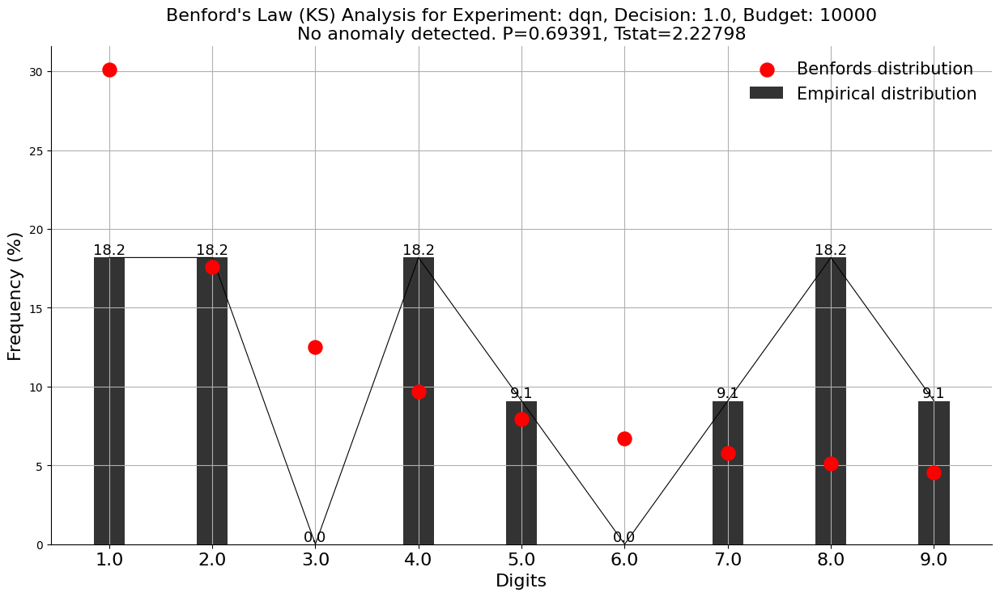

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget10000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0174542, Tstat=11.9862


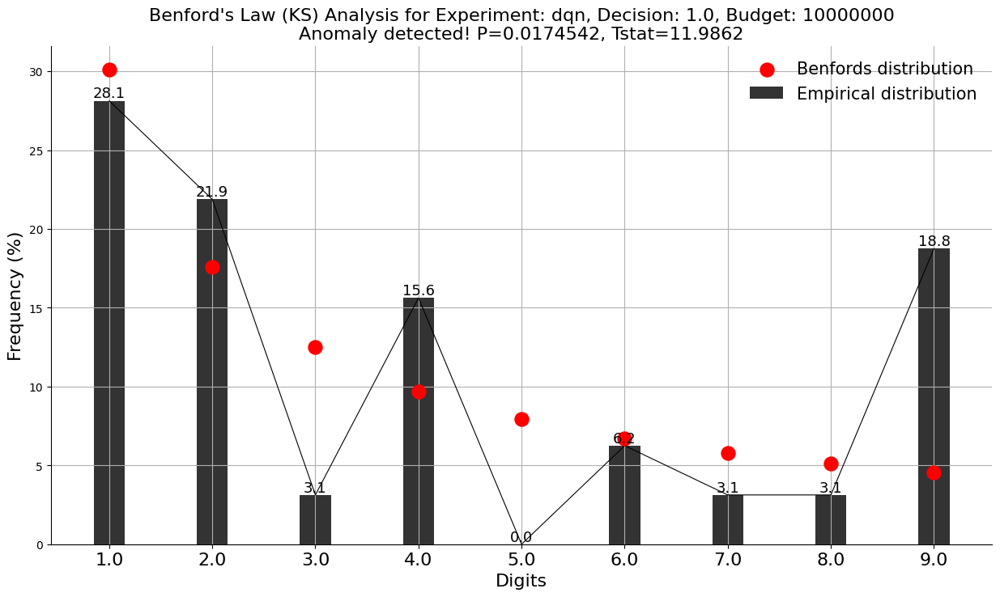

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.31998, Tstat=4.6956


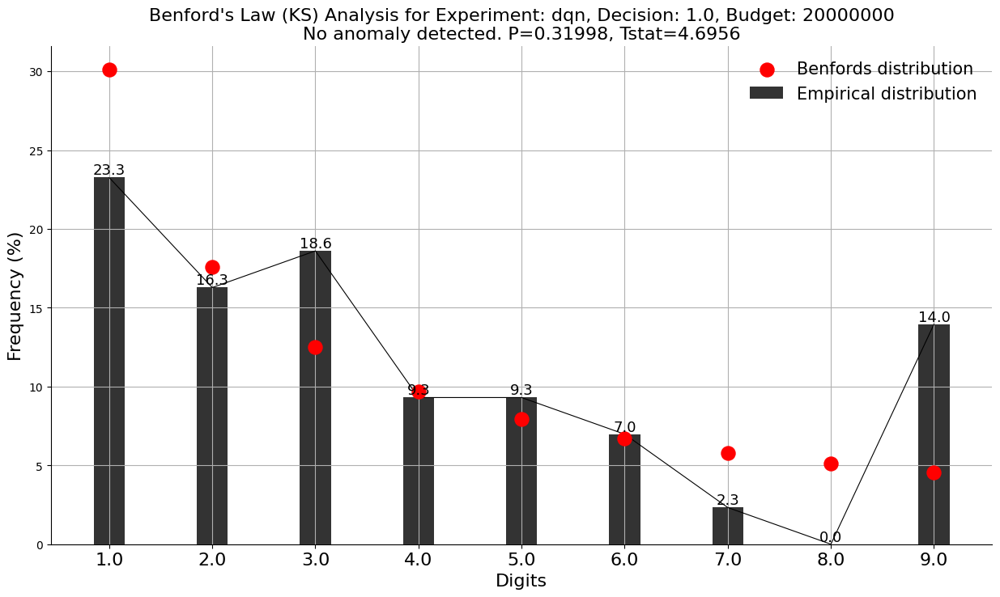

Plot saved to: .temp/experiment_results/benford_plot_dqn_dec1.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.333516, Tstat=4.57698


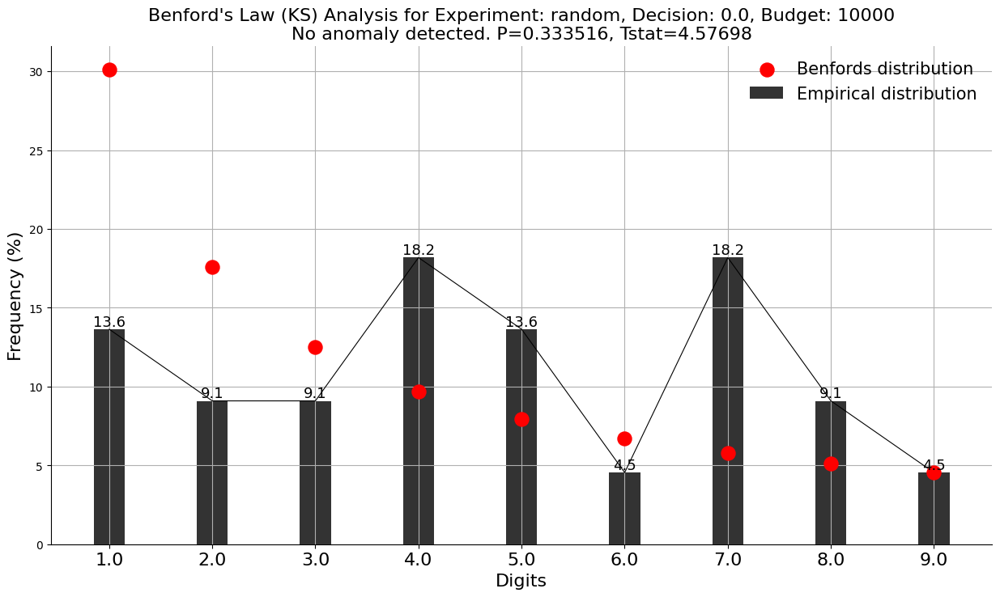

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget10000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.48015, Tstat=3.48508


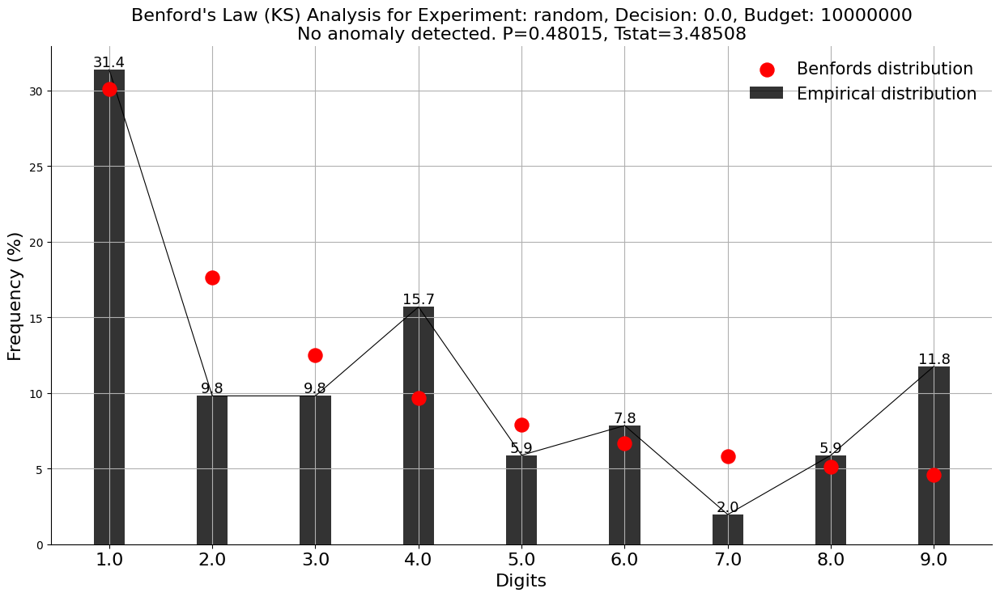

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00770632, Tstat=13.8746


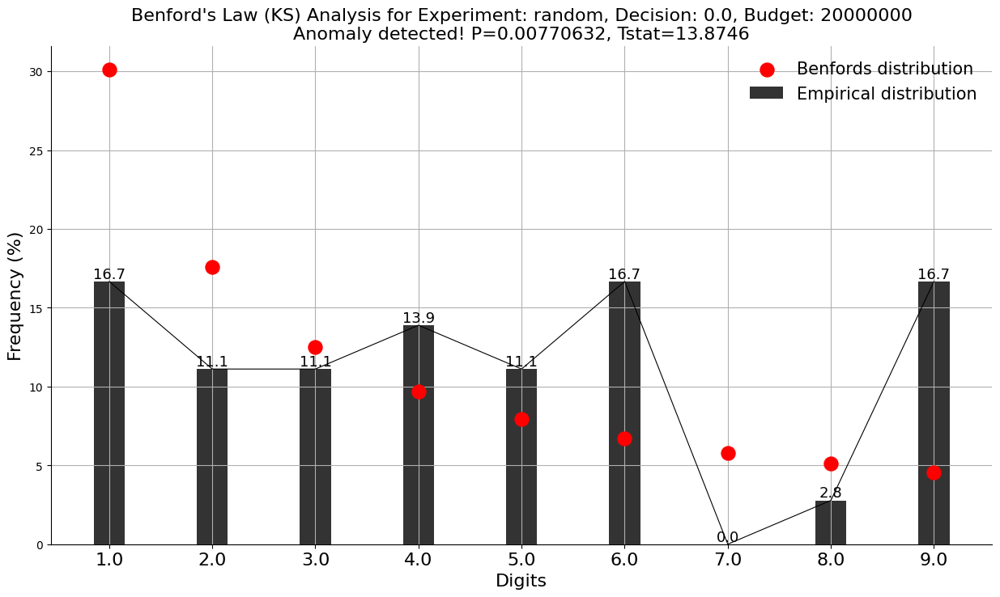

Plot saved to: .temp/experiment_results/benford_plot_random_dec0.0_budget20000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.405706, Tstat=4.00221


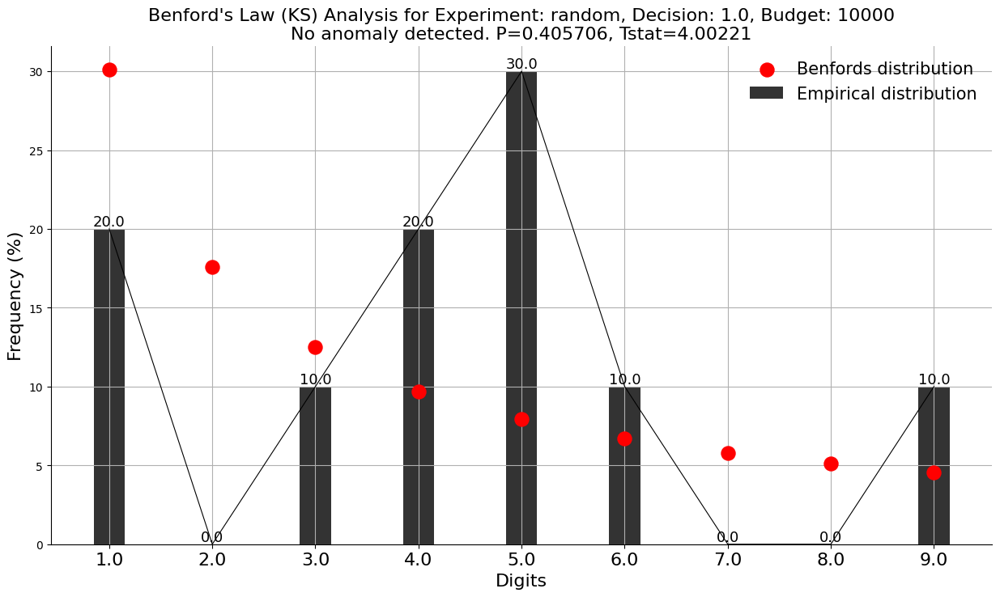

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget10000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.903038, Tstat=1.04409


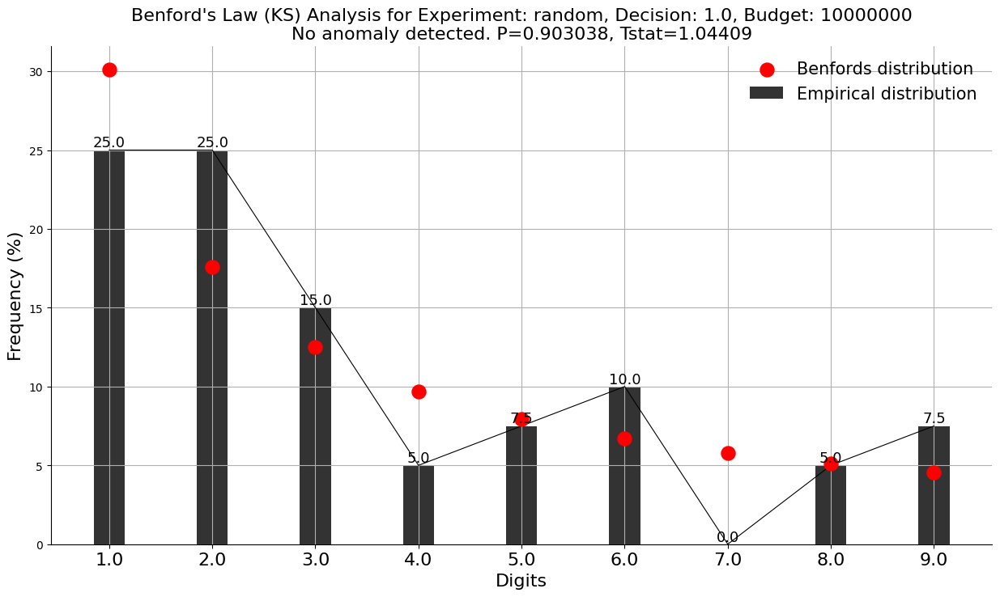

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget10000000.png
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.800989, Tstat=1.6433


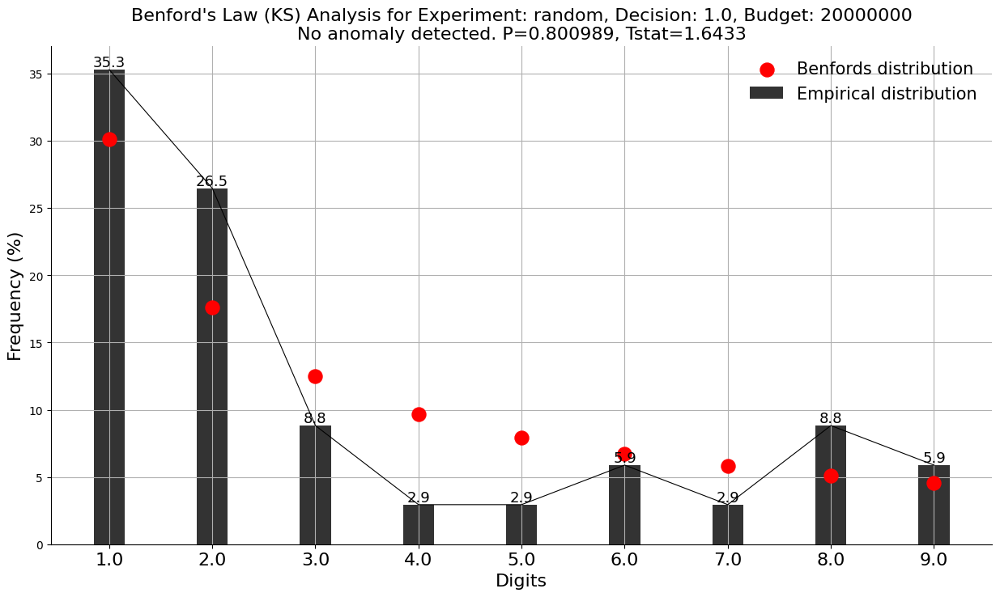

Plot saved to: .temp/experiment_results/benford_plot_random_dec1.0_budget20000000.png
Summary results saved to: .temp/experiment_results/benford_summary_results.csv


In [13]:
import os
import pandas as pd
from benfordslaw import benfordslaw

# Create a directory to store the results if it doesn't exist
results_dir = ".temp/experiment_results"
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

# Initialize the Benford's Law analyzer with method='ks' for Kolmogorov-Smirnov test
bl = benfordslaw(method='ssd')

# Assuming your dataset is loaded into a DataFrame called 'data'
# The dataset includes columns: experiment, rewards, wc, woc, valor_indenizacao, initial_budget, decision

# Group the data by experiment, decision, and initial_budget (removing episodes dimension)
groups = data.groupby(['experiment', 'decision', 'initial_budget'])

# Prepare a list to store summary results
summary_results = []

# Iterate over each group and apply Benford's Law analysis
for (experiment, decision, initial_budget), group in groups:
    valor_indenizacao = group['valor_indenizacao'].dropna().values
    
    if len(valor_indenizacao) == 0:
        print(f"No indemnity values available for Experiment: {experiment}, Decision: {decision}, Initial Budget: {initial_budget}")
        continue
    
    # Apply Benford's Law with Kolmogorov-Smirnov test to the valor_indenizacao values
    results = bl.fit(valor_indenizacao)
    
    # Generate plot and save it
    plot_title = f"Benford's Law (KS) Analysis for Experiment: {experiment}, Decision: {decision}, Budget: {initial_budget}"
    fig, ax = bl.plot(title=plot_title)
    
    # Save the plot to the results directory
    plot_filename = f"{results_dir}/benford_plot_{experiment}_dec{decision}_budget{initial_budget}.png"
    fig.savefig(plot_filename)
    print(f"Plot saved to: {plot_filename}")
    
    # Append KS results to the summary list
    summary_results.append({
        'experiment': experiment,
        'decision': decision,
        'initial_budget': initial_budget,
        'KS_stat': results['t'],  # The test statistic for the KS test
        'p_value': results['P'],  # The p-value for the KS test
        'P_significant': results['P_significant'],  # whether it's significant
        'percentage_emp': results['percentage_emp']  # empirical distribution
    })

# Create a summary DataFrame
summary_df = pd.DataFrame(summary_results)

# Save the summary DataFrame to the results directory
summary_filename = f"{results_dir}/benford_summary_results.csv"
summary_df.to_csv(summary_filename, index=False)
print(f"Summary results saved to: {summary_filename}")


[1680.98 9107.32 6909.45 8870.73 4485.15 4807.46 7080.51 4946.89 5332.95
 2030.83 2696.06 7898.2  3622.68 7830.71 4255.66 7290.38 1359.07 5258.06
 3073.58 5492.64 1422.39 8828.39]
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.333516, Tstat=4.57698


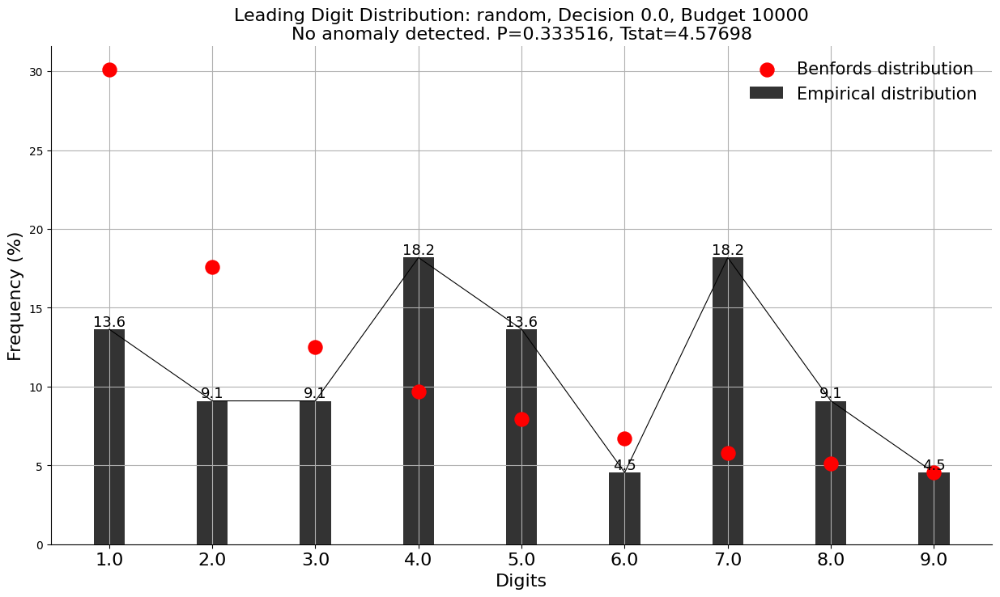

[1680.98 9107.32 6909.45 8870.73 4485.15 4807.46 7080.51 4946.89 5332.95
 2030.83 2696.06 7898.2  3622.68 7830.71 4255.66 7290.38 1359.07 5258.06
 3073.58 5492.64 1422.39 8828.39]
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.193769, Tstat=6.07291


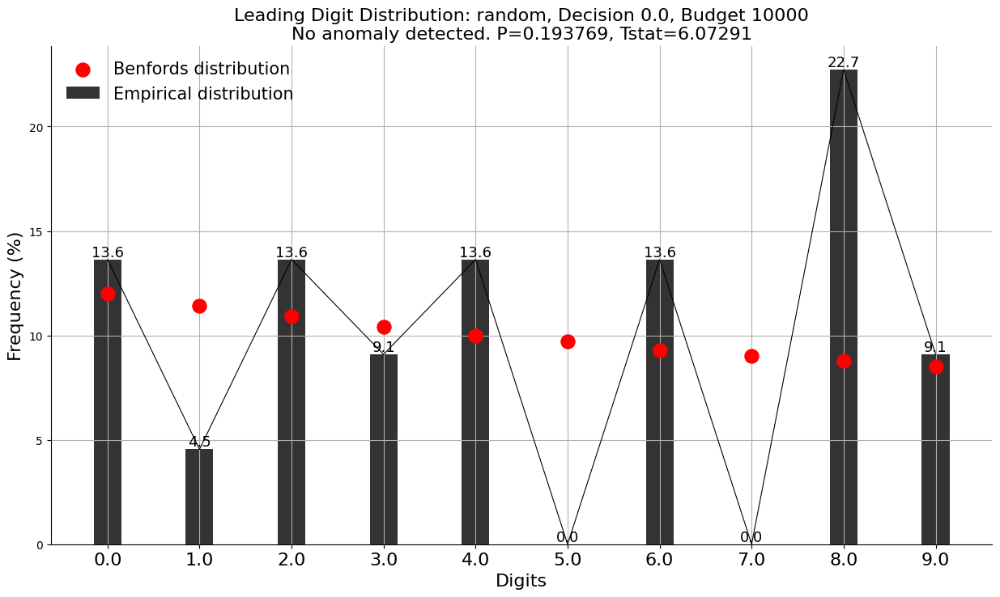

[1680.98 9107.32 6909.45 8870.73 4485.15 4807.46 7080.51 4946.89 5332.95
 2030.83 2696.06 7898.2  3622.68 7830.71 4255.66 7290.38 1359.07 5258.06
 3073.58 5492.64 1422.39 8828.39]
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.127282, Tstat=7.1678


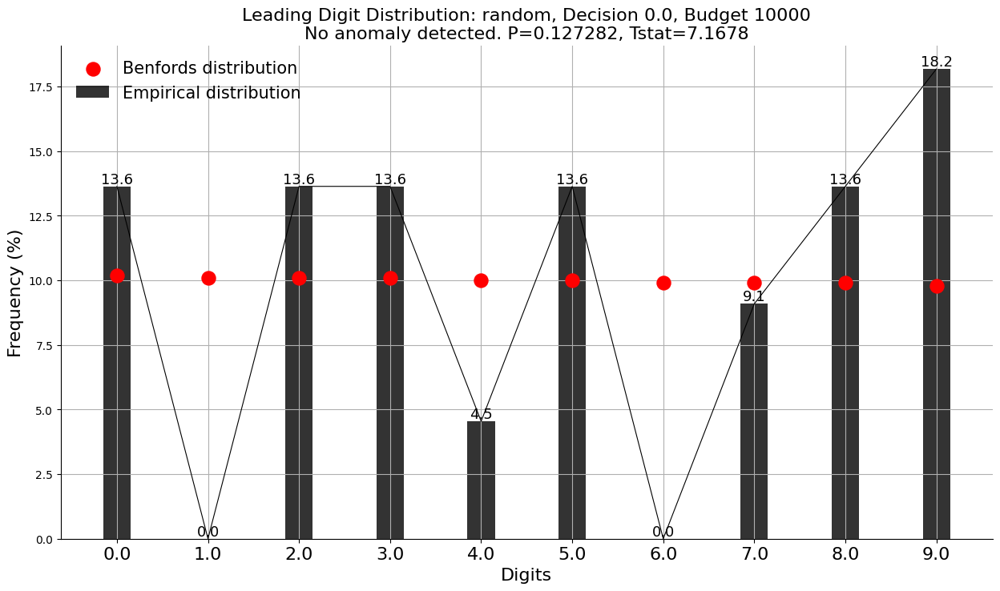

[138415.2   46305.87  66429.43  44488.55 238873.97  10411.5  114318.08
  26060.77  70434.8  312488.32 189101.72  13936.19 156626.02   1020.68
  34185.02  12962.5    4824.   101818.55  95045.72  39776.11  42435.36
  59174.4   85683.54 145785.71   9723.    11616.07   9777.19   6485.87
  51419.59  58563.08  86315.08   9020.32  27289.3   84603.95  63603.45
  95075.37  62802.    28495.4  140826.49 131670.38 150081.62  41120.29
  46970.97  16861.74  90417.23  37540.06  48468.43  38171.72  12870.47
   4959.9  245634.46]
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.48015, Tstat=3.48508


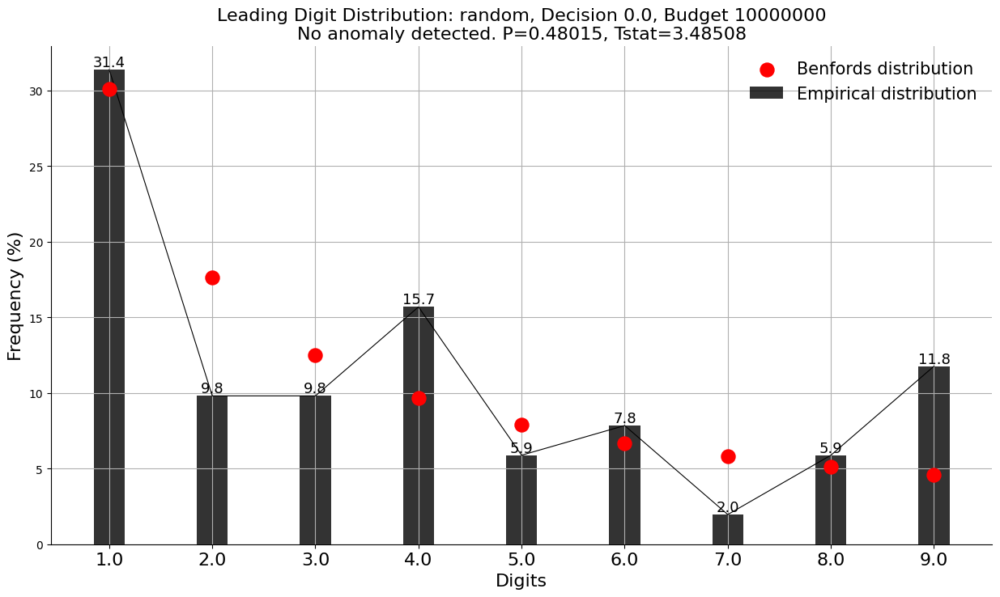

[138415.2   46305.87  66429.43  44488.55 238873.97  10411.5  114318.08
  26060.77  70434.8  312488.32 189101.72  13936.19 156626.02   1020.68
  34185.02  12962.5    4824.   101818.55  95045.72  39776.11  42435.36
  59174.4   85683.54 145785.71   9723.    11616.07   9777.19   6485.87
  51419.59  58563.08  86315.08   9020.32  27289.3   84603.95  63603.45
  95075.37  62802.    28495.4  140826.49 131670.38 150081.62  41120.29
  46970.97  16861.74  90417.23  37540.06  48468.43  38171.72  12870.47
   4959.9  245634.46]
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.971112, Tstat=0.52411


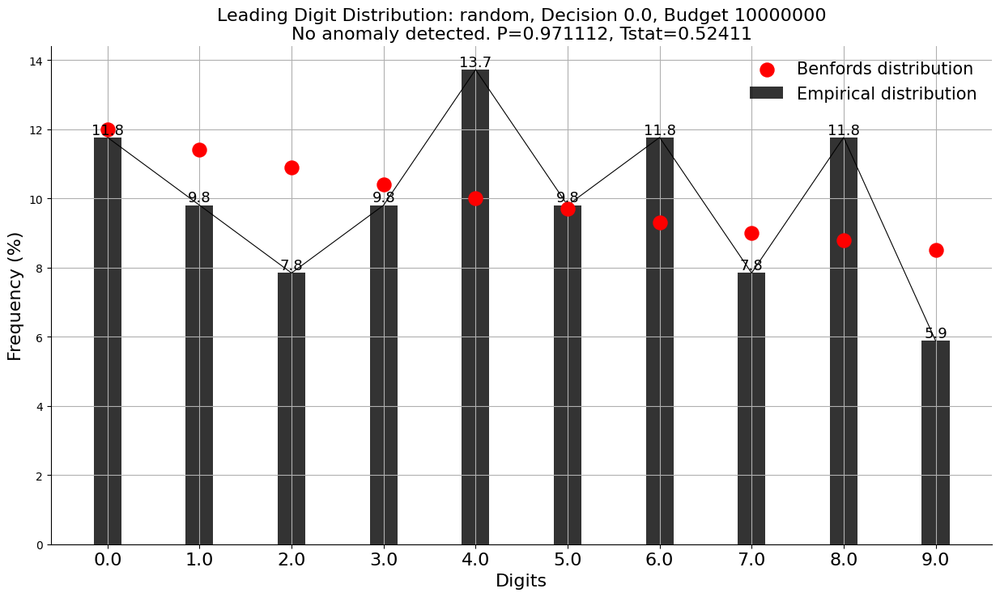

[138415.2   46305.87  66429.43  44488.55 238873.97  10411.5  114318.08
  26060.77  70434.8  312488.32 189101.72  13936.19 156626.02   1020.68
  34185.02  12962.5    4824.   101818.55  95045.72  39776.11  42435.36
  59174.4   85683.54 145785.71   9723.    11616.07   9777.19   6485.87
  51419.59  58563.08  86315.08   9020.32  27289.3   84603.95  63603.45
  95075.37  62802.    28495.4  140826.49 131670.38 150081.62  41120.29
  46970.97  16861.74  90417.23  37540.06  48468.43  38171.72  12870.47
   4959.9  245634.46]
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.259206, Tstat=5.28584


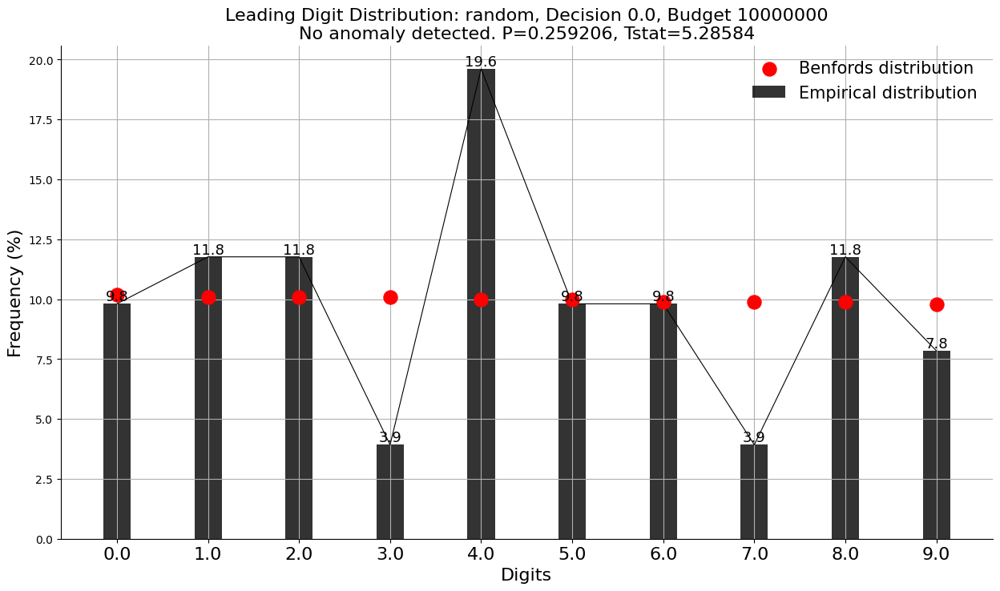

[ 22528.8    6998.34  44488.55  10411.5   95045.72  39776.11  68821.9
 178225.88   9655.48  42435.36  59174.4   67147.66   9723.     9777.19
   6485.87  51419.59  58563.08   9020.32 484343.42  56165.26  27289.3
  39923.52  84603.95  63603.45  95075.37  62802.   106132.36 206290.82
  26781.99 131670.38  19945.6  150081.62  41120.29   3136.32  46970.97
  37540.06]
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00770632, Tstat=13.8746


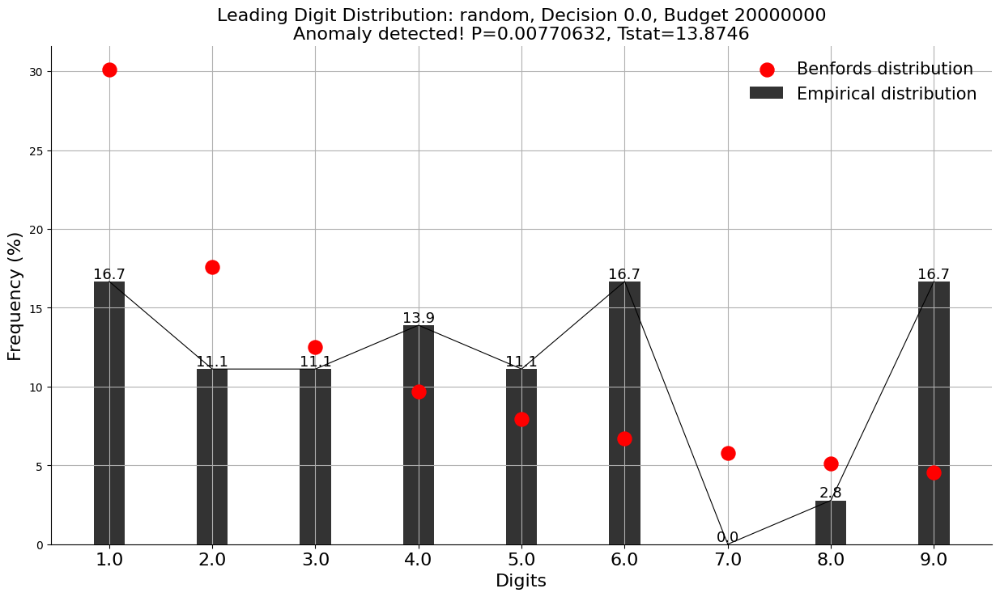

[ 22528.8    6998.34  44488.55  10411.5   95045.72  39776.11  68821.9
 178225.88   9655.48  42435.36  59174.4   67147.66   9723.     9777.19
   6485.87  51419.59  58563.08   9020.32 484343.42  56165.26  27289.3
  39923.52  84603.95  63603.45  95075.37  62802.   106132.36 206290.82
  26781.99 131670.38  19945.6  150081.62  41120.29   3136.32  46970.97
  37540.06]
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.177198, Tstat=6.30947


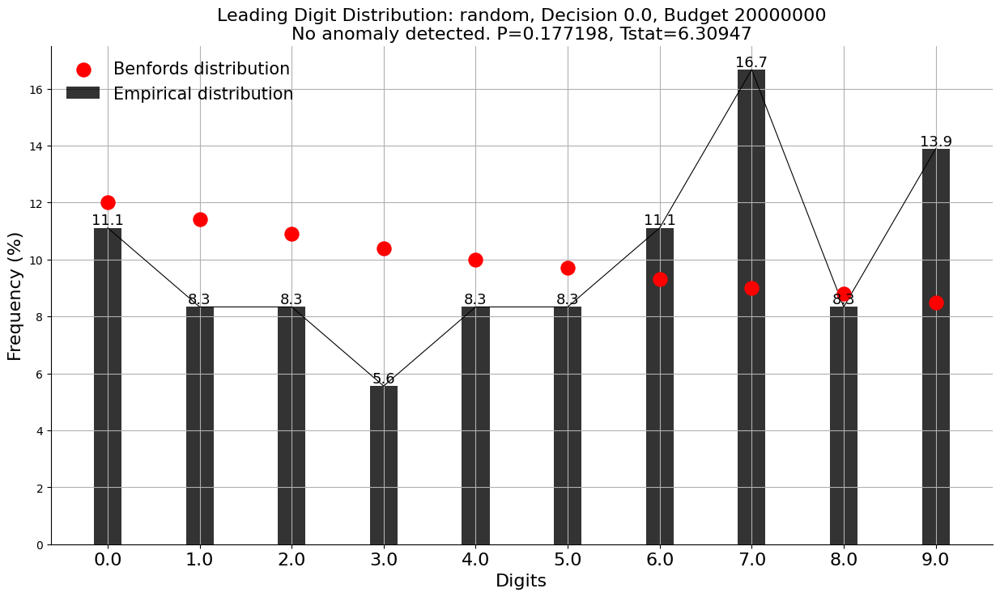

[ 22528.8    6998.34  44488.55  10411.5   95045.72  39776.11  68821.9
 178225.88   9655.48  42435.36  59174.4   67147.66   9723.     9777.19
   6485.87  51419.59  58563.08   9020.32 484343.42  56165.26  27289.3
  39923.52  84603.95  63603.45  95075.37  62802.   106132.36 206290.82
  26781.99 131670.38  19945.6  150081.62  41120.29   3136.32  46970.97
  37540.06]
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.197826, Tstat=6.01775


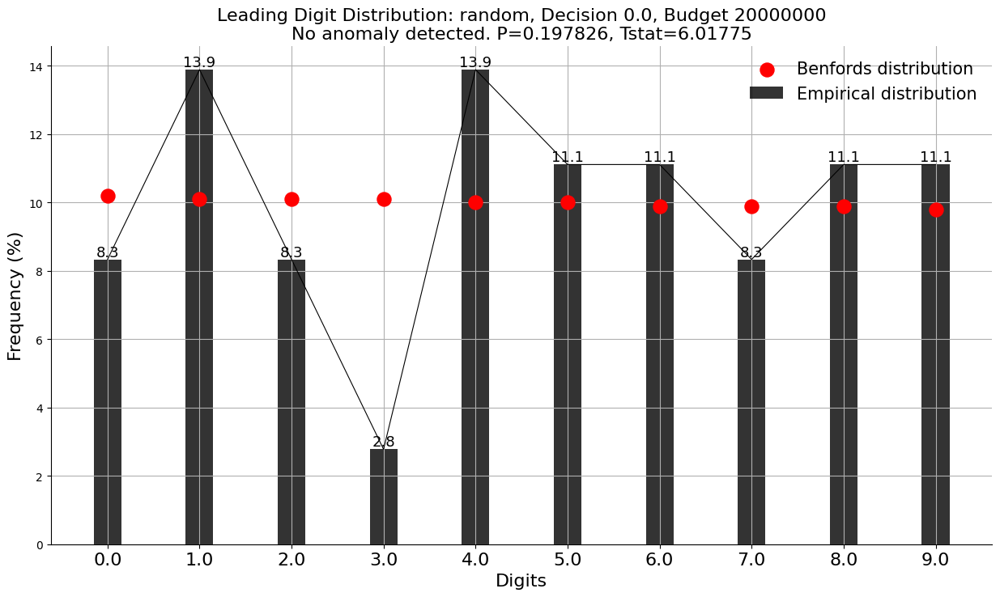

[6372.83 3222.09 4359.6  1873.08 5238.38 1227.56 4596.1  9023.59 5324.27
 5870.86]
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.405706, Tstat=4.00221


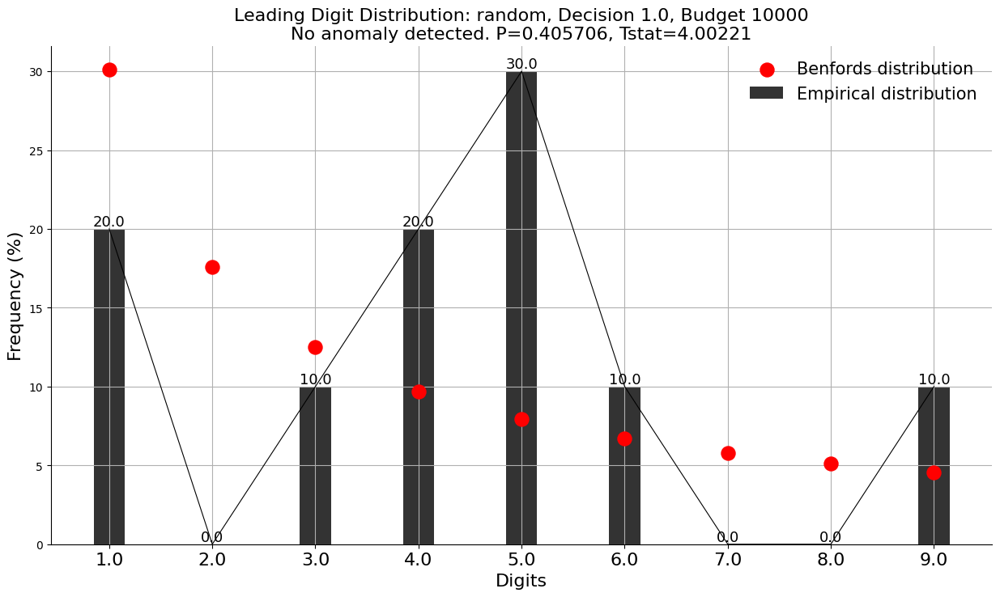

[6372.83 3222.09 4359.6  1873.08 5238.38 1227.56 4596.1  9023.59 5324.27
 5870.86]
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.117016, Tstat=7.38224


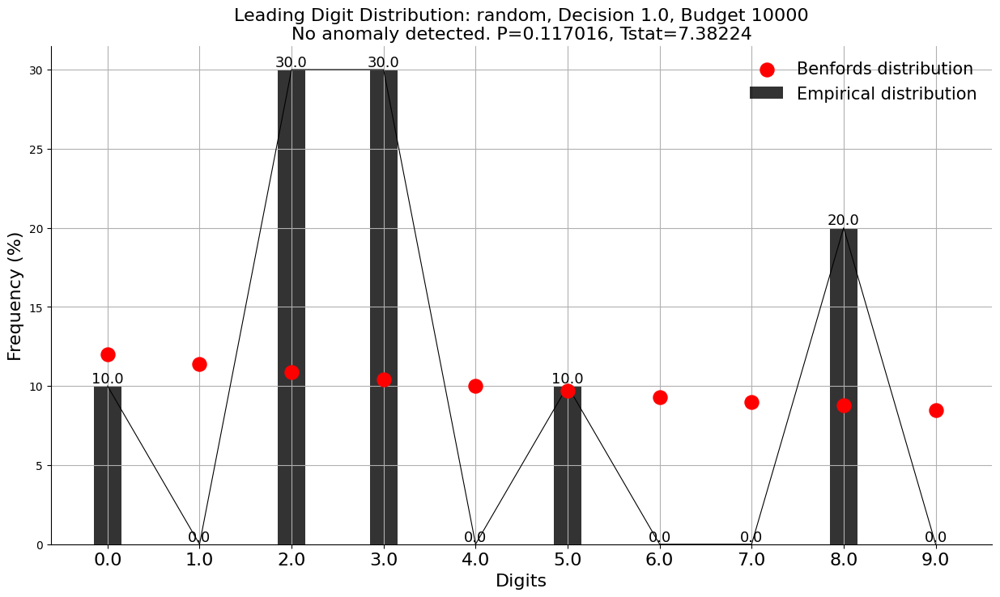

[6372.83 3222.09 4359.6  1873.08 5238.38 1227.56 4596.1  9023.59 5324.27
 5870.86]
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0367718, Tstat=10.2271


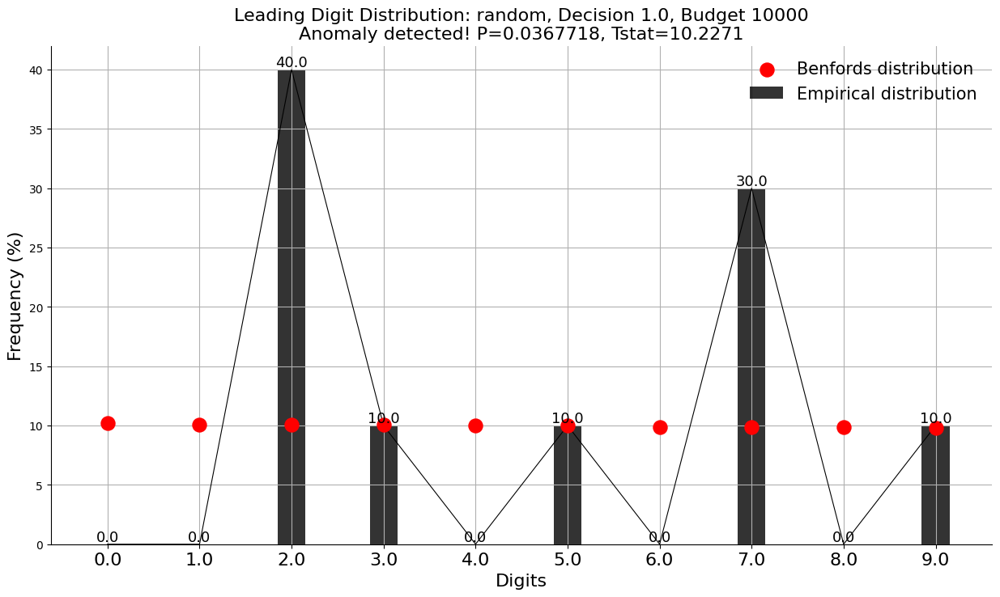

[2.2528800e+04 3.8409090e+04 1.9072675e+05 6.9983400e+03 9.3043300e+03
 2.8002500e+03 4.9302050e+04 2.1371500e+04 2.6438116e+05 6.4381830e+04
 1.8516020e+04 2.1815910e+04 1.1616040e+04 8.4119080e+04 6.3393420e+04
 2.3597850e+04 2.8537790e+04 1.8650130e+04 1.7809200e+04 9.6554800e+03
 1.3034908e+05 1.8816221e+05 6.7147660e+04 3.0794770e+04 3.9302000e+03
 9.1780300e+04 4.8434342e+05 5.6165260e+04 8.1144330e+04 5.8880160e+04
 3.9923520e+04 2.9937850e+04 2.2316000e+02 1.0613236e+05 1.9945600e+04
 3.1363200e+03 3.8006550e+04 2.0348400e+04 1.7996320e+05 5.0316100e+05]
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.903038, Tstat=1.04409


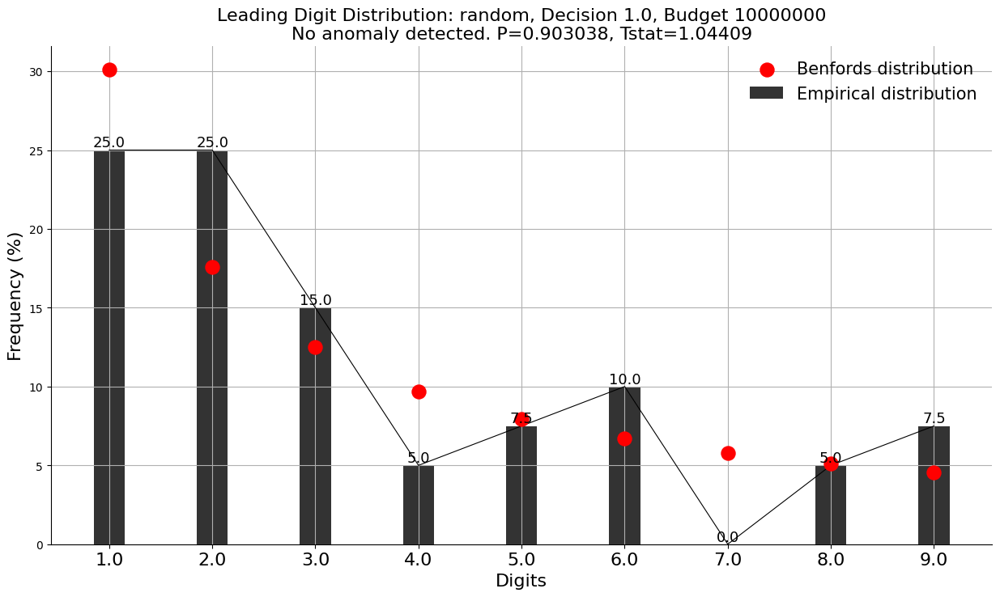

[2.2528800e+04 3.8409090e+04 1.9072675e+05 6.9983400e+03 9.3043300e+03
 2.8002500e+03 4.9302050e+04 2.1371500e+04 2.6438116e+05 6.4381830e+04
 1.8516020e+04 2.1815910e+04 1.1616040e+04 8.4119080e+04 6.3393420e+04
 2.3597850e+04 2.8537790e+04 1.8650130e+04 1.7809200e+04 9.6554800e+03
 1.3034908e+05 1.8816221e+05 6.7147660e+04 3.0794770e+04 3.9302000e+03
 9.1780300e+04 4.8434342e+05 5.6165260e+04 8.1144330e+04 5.8880160e+04
 3.9923520e+04 2.9937850e+04 2.2316000e+02 1.0613236e+05 1.9945600e+04
 3.1363200e+03 3.8006550e+04 2.0348400e+04 1.7996320e+05 5.0316100e+05]
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0248397, Tstat=11.1585


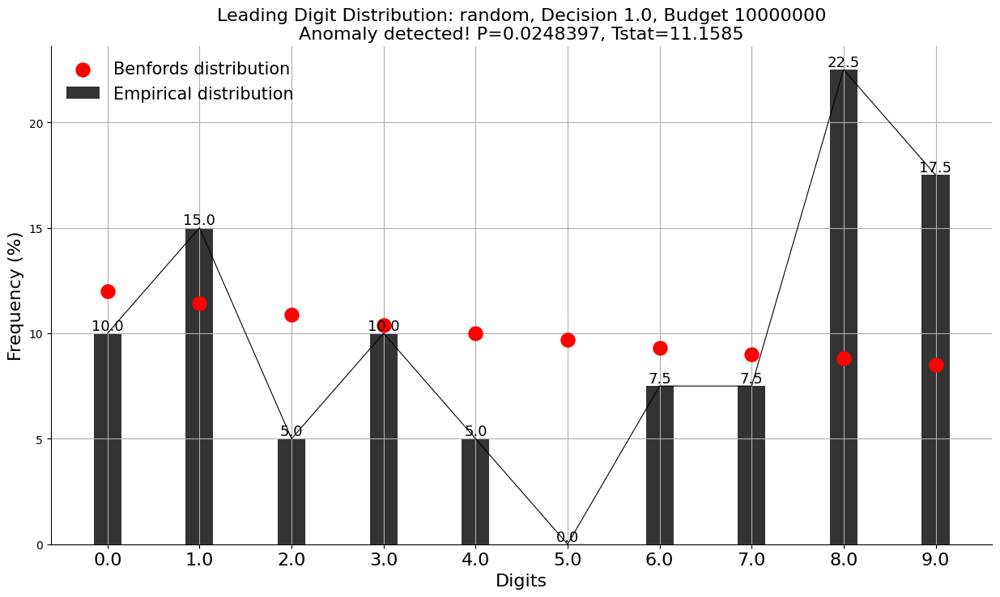

[2.2528800e+04 3.8409090e+04 1.9072675e+05 6.9983400e+03 9.3043300e+03
 2.8002500e+03 4.9302050e+04 2.1371500e+04 2.6438116e+05 6.4381830e+04
 1.8516020e+04 2.1815910e+04 1.1616040e+04 8.4119080e+04 6.3393420e+04
 2.3597850e+04 2.8537790e+04 1.8650130e+04 1.7809200e+04 9.6554800e+03
 1.3034908e+05 1.8816221e+05 6.7147660e+04 3.0794770e+04 3.9302000e+03
 9.1780300e+04 4.8434342e+05 5.6165260e+04 8.1144330e+04 5.8880160e+04
 3.9923520e+04 2.9937850e+04 2.2316000e+02 1.0613236e+05 1.9945600e+04
 3.1363200e+03 3.8006550e+04 2.0348400e+04 1.7996320e+05 5.0316100e+05]
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.285532, Tstat=5.01725


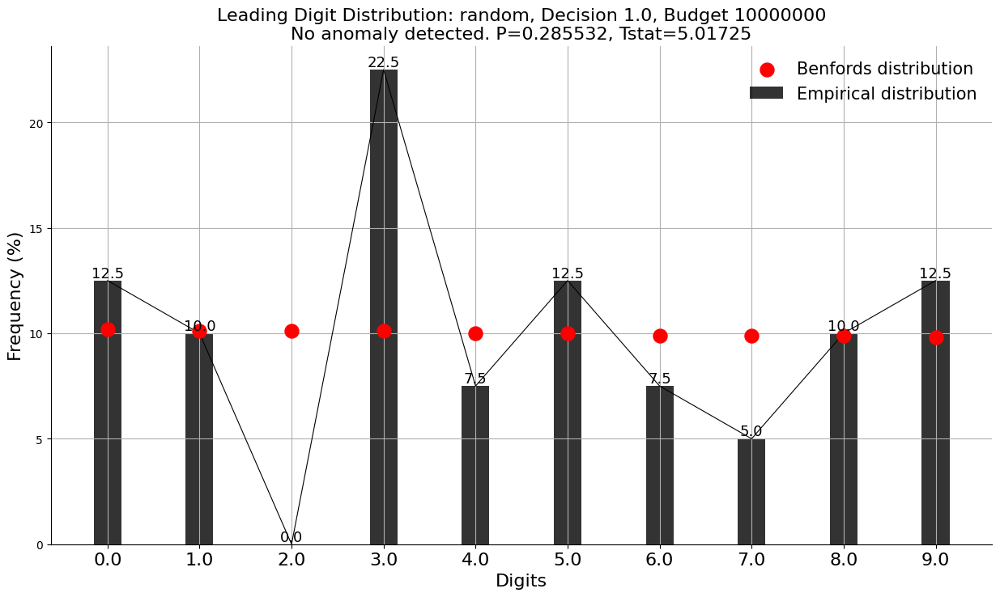

[1.3841520e+05 3.8409090e+04 1.9072675e+05 4.9302050e+04 6.6429430e+04
 2.3887397e+05 2.1371500e+04 6.3393420e+04 2.3597850e+04 2.8537790e+04
 1.8650130e+04 7.2369500e+04 1.5504000e+04 2.2880000e+04 1.7809200e+04
 1.3034908e+05 1.8816221e+05 8.5683540e+04 1.4578571e+05 9.1780300e+04
 8.6315080e+04 8.1144330e+04 5.8880160e+04 2.9937850e+04 2.2316000e+02
 2.8495400e+04 2.2127790e+04 1.4353010e+05 1.3494260e+04 3.5199110e+04
 1.4082649e+05 3.8006550e+04 1.6861740e+04 9.0417230e+04]
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.800989, Tstat=1.6433


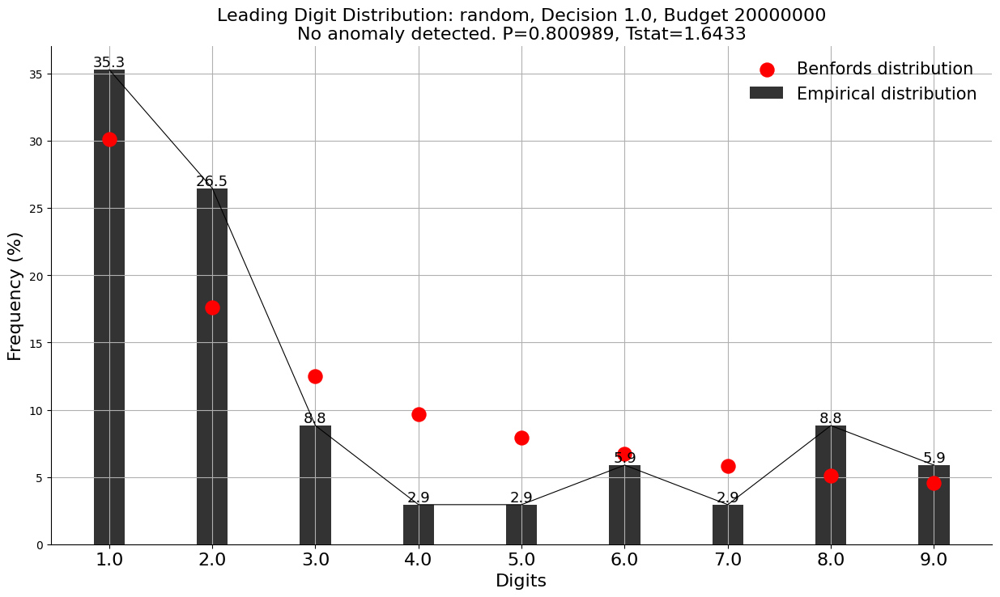

[1.3841520e+05 3.8409090e+04 1.9072675e+05 4.9302050e+04 6.6429430e+04
 2.3887397e+05 2.1371500e+04 6.3393420e+04 2.3597850e+04 2.8537790e+04
 1.8650130e+04 7.2369500e+04 1.5504000e+04 2.2880000e+04 1.7809200e+04
 1.3034908e+05 1.8816221e+05 8.5683540e+04 1.4578571e+05 9.1780300e+04
 8.6315080e+04 8.1144330e+04 5.8880160e+04 2.9937850e+04 2.2316000e+02
 2.8495400e+04 2.2127790e+04 1.4353010e+05 1.3494260e+04 3.5199110e+04
 1.4082649e+05 3.8006550e+04 1.6861740e+04 9.0417230e+04]
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.184754, Tstat=6.19926


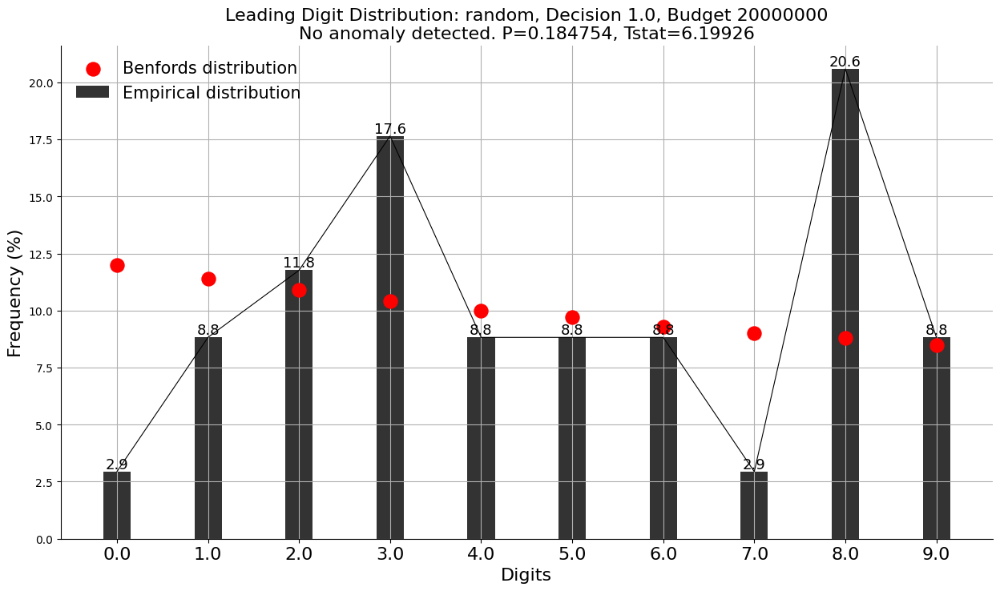

[1.3841520e+05 3.8409090e+04 1.9072675e+05 4.9302050e+04 6.6429430e+04
 2.3887397e+05 2.1371500e+04 6.3393420e+04 2.3597850e+04 2.8537790e+04
 1.8650130e+04 7.2369500e+04 1.5504000e+04 2.2880000e+04 1.7809200e+04
 1.3034908e+05 1.8816221e+05 8.5683540e+04 1.4578571e+05 9.1780300e+04
 8.6315080e+04 8.1144330e+04 5.8880160e+04 2.9937850e+04 2.2316000e+02
 2.8495400e+04 2.2127790e+04 1.4353010e+05 1.3494260e+04 3.5199110e+04
 1.4082649e+05 3.8006550e+04 1.6861740e+04 9.0417230e+04]
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.0631228, Tstat=8.9203


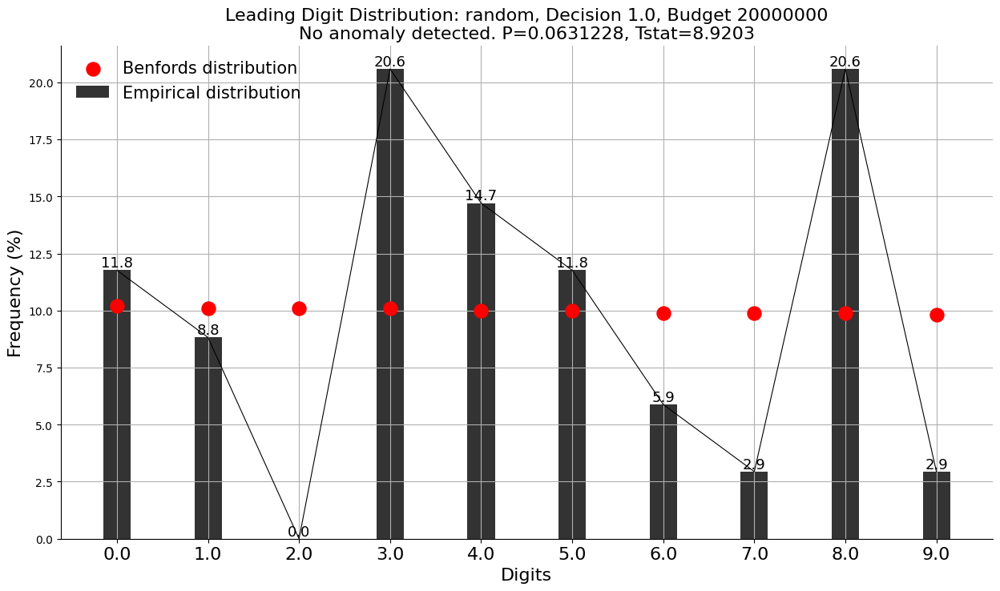

[5231.52 2587.99 9123.03 6372.83 3222.09 7557.98 9107.32 1873.08 4485.15
 4946.89 2696.06 7290.38 5324.27 5492.64 1422.39 5870.86 2650.38]
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.37919, Tstat=4.20331


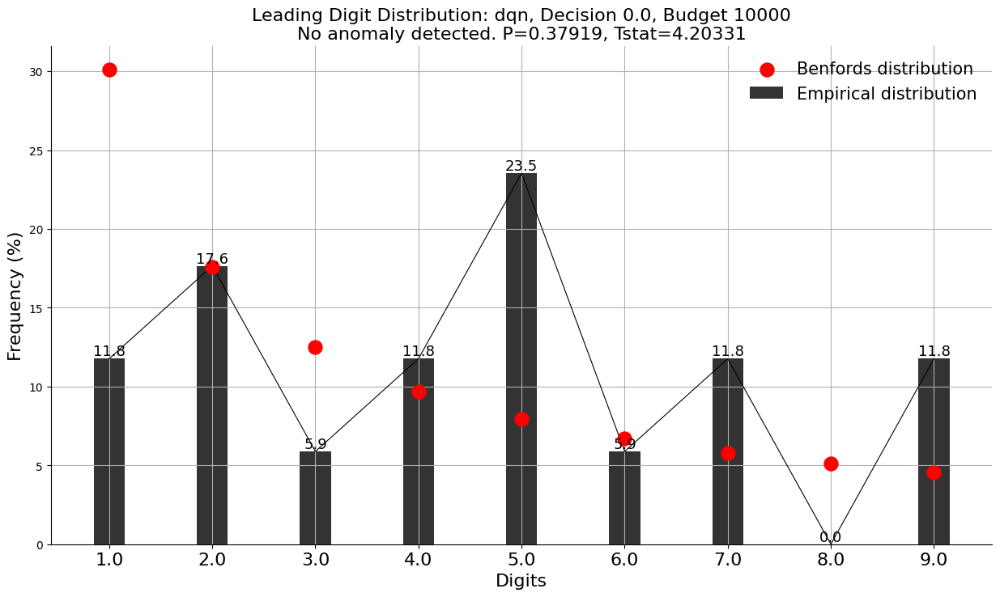

[5231.52 2587.99 9123.03 6372.83 3222.09 7557.98 9107.32 1873.08 4485.15
 4946.89 2696.06 7290.38 5324.27 5492.64 1422.39 5870.86 2650.38]
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.168278, Tstat=6.44517


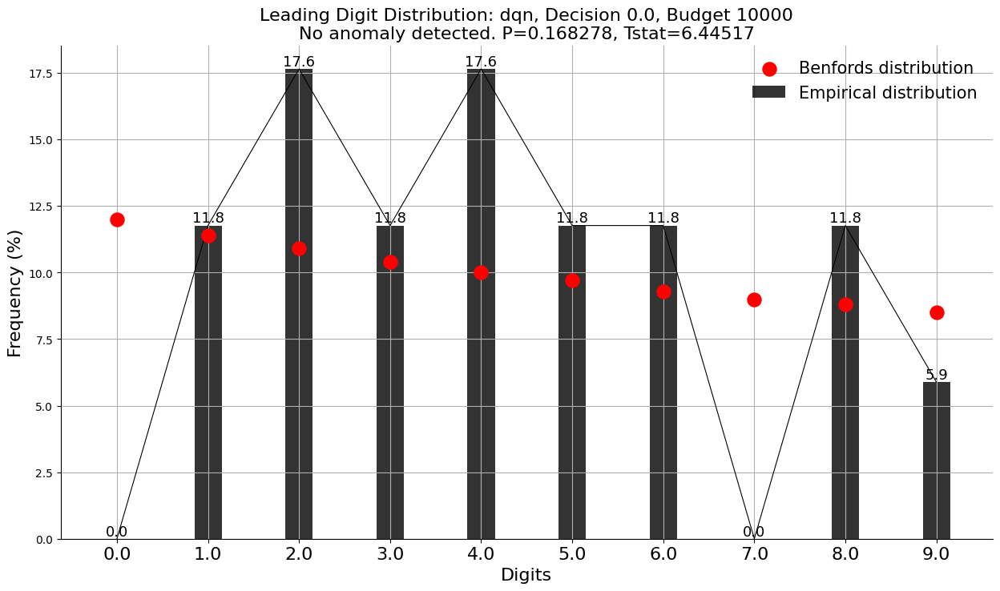

[5231.52 2587.99 9123.03 6372.83 3222.09 7557.98 9107.32 1873.08 4485.15
 4946.89 2696.06 7290.38 5324.27 5492.64 1422.39 5870.86 2650.38]
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.243225, Tstat=5.46048


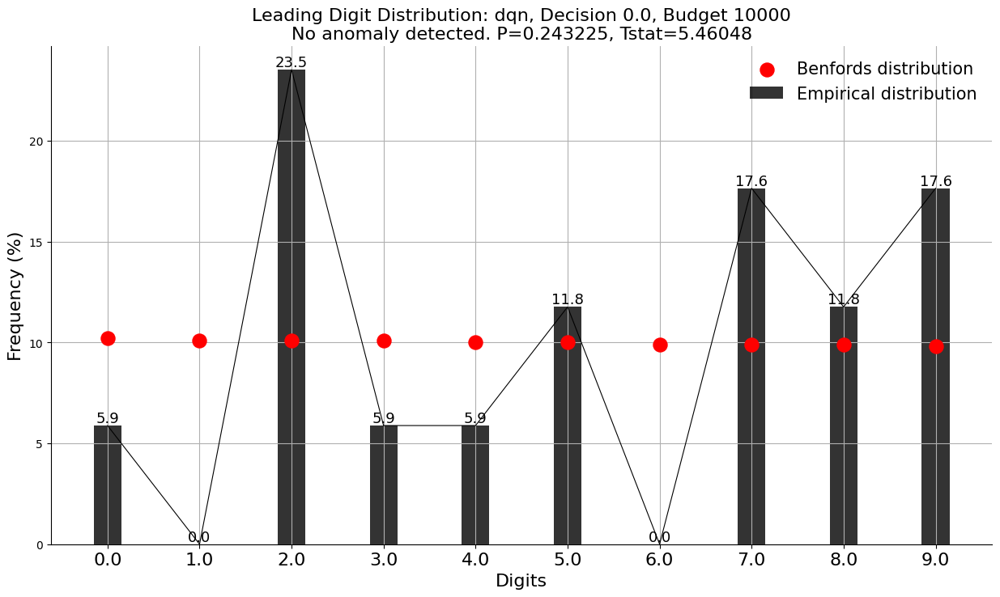

[ 28525.5   39126.17 342235.2  138415.2   38409.09 190726.75   9304.33
  22078.06  66429.43 238873.97 114318.08  95045.72  63393.42  23597.85
  18650.13  39776.11  68821.9   12722.62 130349.08  42435.36  59174.4
  85683.54  67147.66   3930.2    6485.87  51419.59  58563.08 484343.42
  39923.52  84603.95  62802.   131670.38]
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.454847, Tstat=3.65403


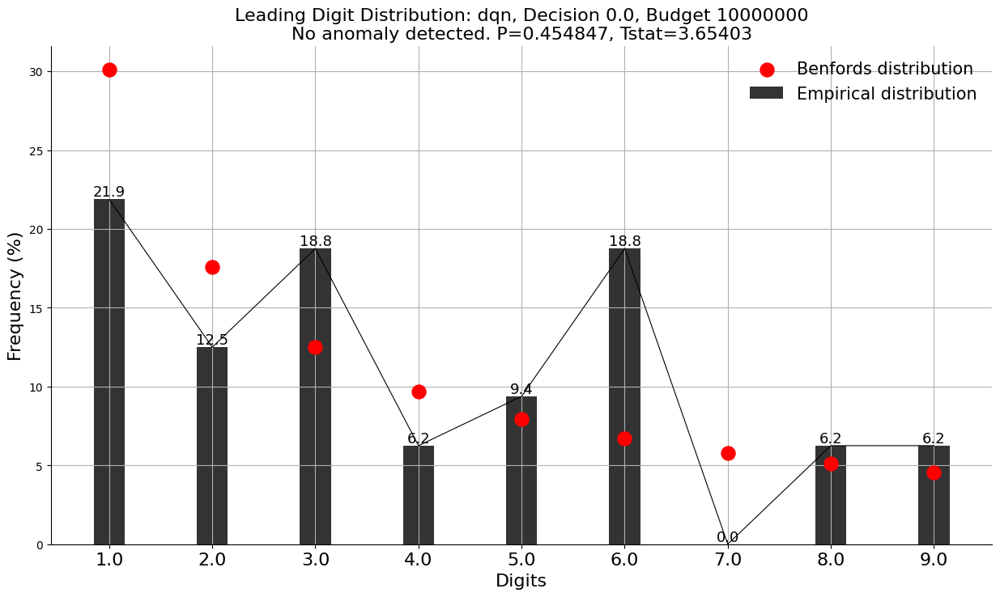

[ 28525.5   39126.17 342235.2  138415.2   38409.09 190726.75   9304.33
  22078.06  66429.43 238873.97 114318.08  95045.72  63393.42  23597.85
  18650.13  39776.11  68821.9   12722.62 130349.08  42435.36  59174.4
  85683.54  67147.66   3930.2    6485.87  51419.59  58563.08 484343.42
  39923.52  84603.95  62802.   131670.38]
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0257356, Tstat=11.0748


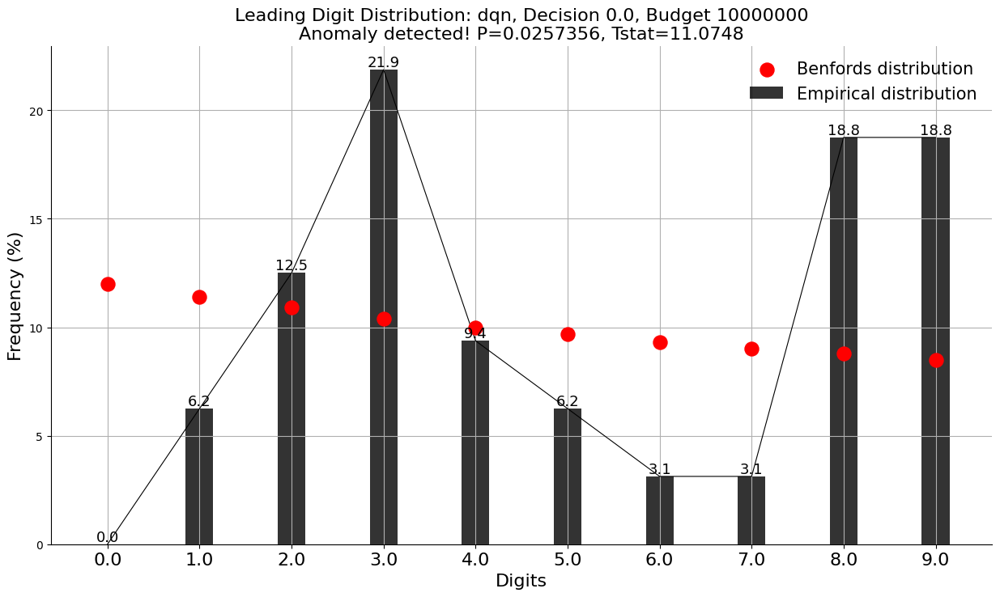

[ 28525.5   39126.17 342235.2  138415.2   38409.09 190726.75   9304.33
  22078.06  66429.43 238873.97 114318.08  95045.72  63393.42  23597.85
  18650.13  39776.11  68821.9   12722.62 130349.08  42435.36  59174.4
  85683.54  67147.66   3930.2    6485.87  51419.59  58563.08 484343.42
  39923.52  84603.95  62802.   131670.38]
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.118143, Tstat=7.35786


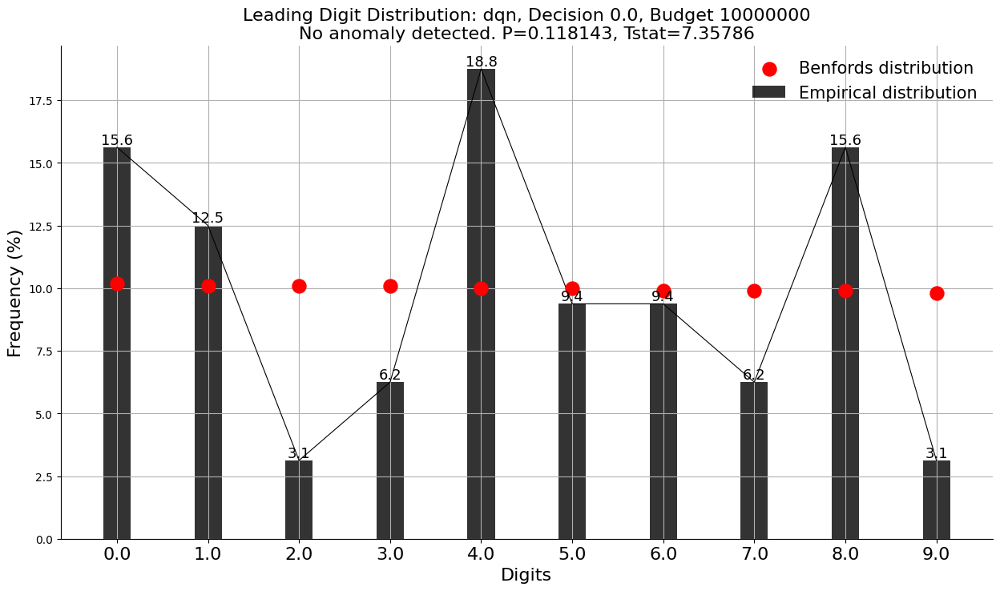

[2.85255000e+04 3.91261700e+04 3.42235200e+05 4.44304800e+04
 1.00355050e+05 1.38415200e+05 3.84090900e+04 2.80025000e+03
 6.64294300e+04 2.38873970e+05 1.14318080e+05 2.60607700e+04
 7.04348000e+04 3.12488320e+05 1.39361900e+04 9.50457200e+04
 6.33934200e+04 6.88219000e+04 2.28800000e+04 1.27226200e+04
 1.78092000e+04 9.65548000e+03 1.30349080e+05 1.19900000e+04
 8.56835400e+04 6.71476600e+04 1.45785710e+05 1.16160700e+04
 3.74228400e+04 8.19508800e+04 5.85630800e+04 8.63150800e+04
 4.84343420e+05 8.11443300e+04 2.99378500e+04 8.46039500e+04
 6.36034500e+04 2.23160000e+02 6.28020000e+04 1.06132360e+05
 2.84954000e+04 2.21277900e+04 1.40826490e+05 1.31670380e+05
 1.99456000e+04 1.50081620e+05 4.11202900e+04 3.13632000e+03
 4.69709700e+04 3.80065500e+04 1.68617400e+04 9.04172300e+04
 3.75400600e+04 4.84684300e+04 3.81717200e+04 1.28704700e+04
 4.95990000e+03 2.03484000e+04 1.79963200e+05 5.03161000e+05
 2.45634460e+05 6.74001500e+04 3.10972245e+06 4.46196000e+03
 4.34079200e+04 2.534304

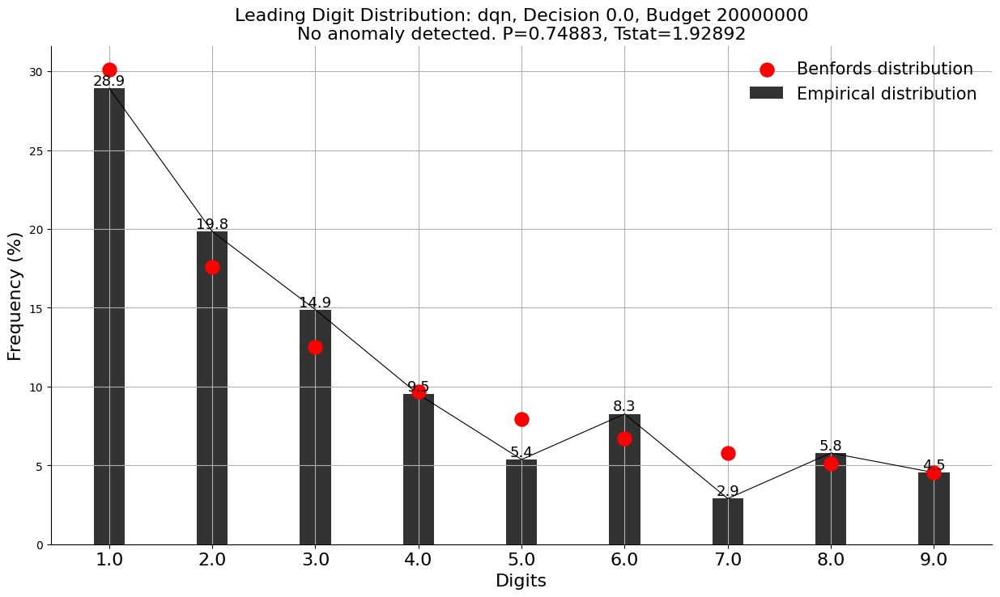

[2.85255000e+04 3.91261700e+04 3.42235200e+05 4.44304800e+04
 1.00355050e+05 1.38415200e+05 3.84090900e+04 2.80025000e+03
 6.64294300e+04 2.38873970e+05 1.14318080e+05 2.60607700e+04
 7.04348000e+04 3.12488320e+05 1.39361900e+04 9.50457200e+04
 6.33934200e+04 6.88219000e+04 2.28800000e+04 1.27226200e+04
 1.78092000e+04 9.65548000e+03 1.30349080e+05 1.19900000e+04
 8.56835400e+04 6.71476600e+04 1.45785710e+05 1.16160700e+04
 3.74228400e+04 8.19508800e+04 5.85630800e+04 8.63150800e+04
 4.84343420e+05 8.11443300e+04 2.99378500e+04 8.46039500e+04
 6.36034500e+04 2.23160000e+02 6.28020000e+04 1.06132360e+05
 2.84954000e+04 2.21277900e+04 1.40826490e+05 1.31670380e+05
 1.99456000e+04 1.50081620e+05 4.11202900e+04 3.13632000e+03
 4.69709700e+04 3.80065500e+04 1.68617400e+04 9.04172300e+04
 3.75400600e+04 4.84684300e+04 3.81717200e+04 1.28704700e+04
 4.95990000e+03 2.03484000e+04 1.79963200e+05 5.03161000e+05
 2.45634460e+05 6.74001500e+04 3.10972245e+06 4.46196000e+03
 4.34079200e+04 2.534304

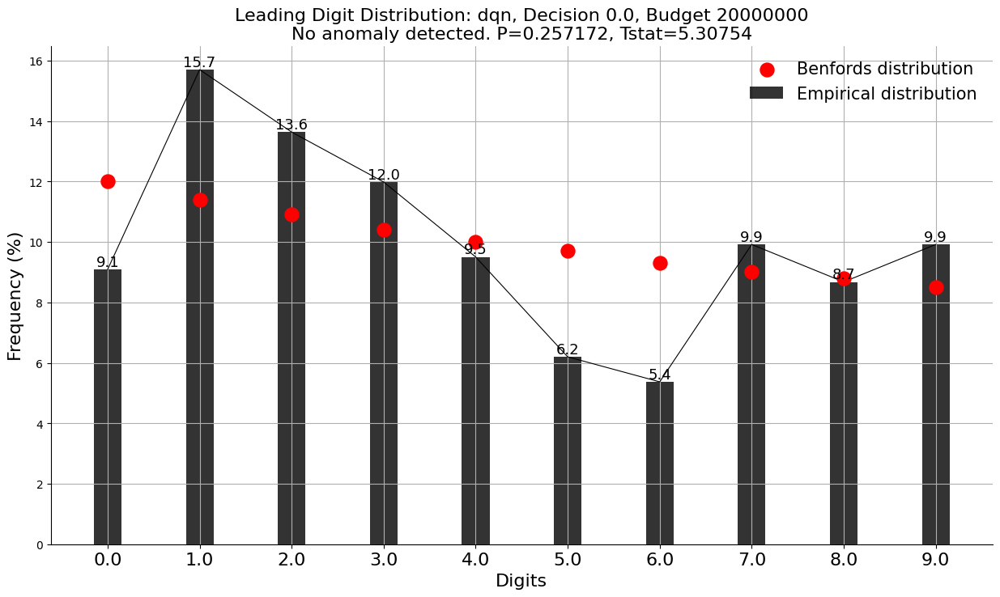

[2.85255000e+04 3.91261700e+04 3.42235200e+05 4.44304800e+04
 1.00355050e+05 1.38415200e+05 3.84090900e+04 2.80025000e+03
 6.64294300e+04 2.38873970e+05 1.14318080e+05 2.60607700e+04
 7.04348000e+04 3.12488320e+05 1.39361900e+04 9.50457200e+04
 6.33934200e+04 6.88219000e+04 2.28800000e+04 1.27226200e+04
 1.78092000e+04 9.65548000e+03 1.30349080e+05 1.19900000e+04
 8.56835400e+04 6.71476600e+04 1.45785710e+05 1.16160700e+04
 3.74228400e+04 8.19508800e+04 5.85630800e+04 8.63150800e+04
 4.84343420e+05 8.11443300e+04 2.99378500e+04 8.46039500e+04
 6.36034500e+04 2.23160000e+02 6.28020000e+04 1.06132360e+05
 2.84954000e+04 2.21277900e+04 1.40826490e+05 1.31670380e+05
 1.99456000e+04 1.50081620e+05 4.11202900e+04 3.13632000e+03
 4.69709700e+04 3.80065500e+04 1.68617400e+04 9.04172300e+04
 3.75400600e+04 4.84684300e+04 3.81717200e+04 1.28704700e+04
 4.95990000e+03 2.03484000e+04 1.79963200e+05 5.03161000e+05
 2.45634460e+05 6.74001500e+04 3.10972245e+06 4.46196000e+03
 4.34079200e+04 2.534304

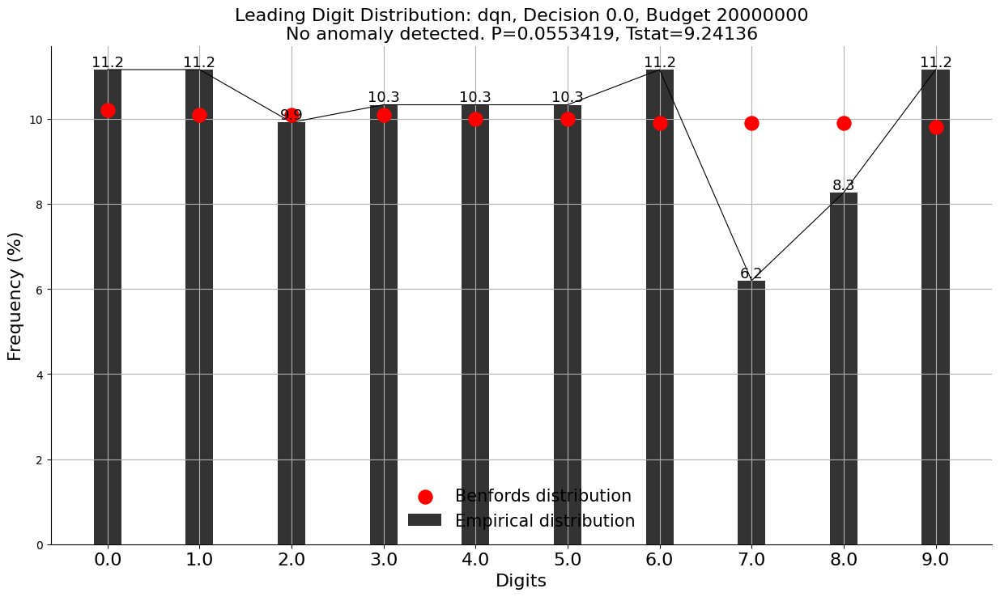

[2589.4  4880.18 1680.98 4359.6  8870.73 7080.51 2030.83 9023.59 1359.07
 5258.06 8828.39]
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.69391, Tstat=2.22798


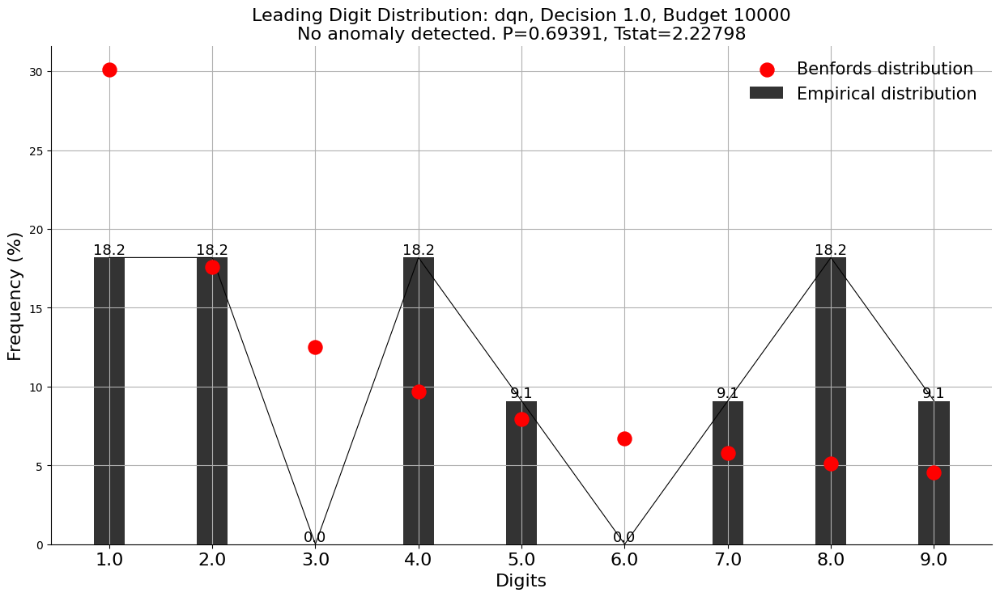

[2589.4  4880.18 1680.98 4359.6  8870.73 7080.51 2030.83 9023.59 1359.07
 5258.06 8828.39]
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.341924, Tstat=4.50526


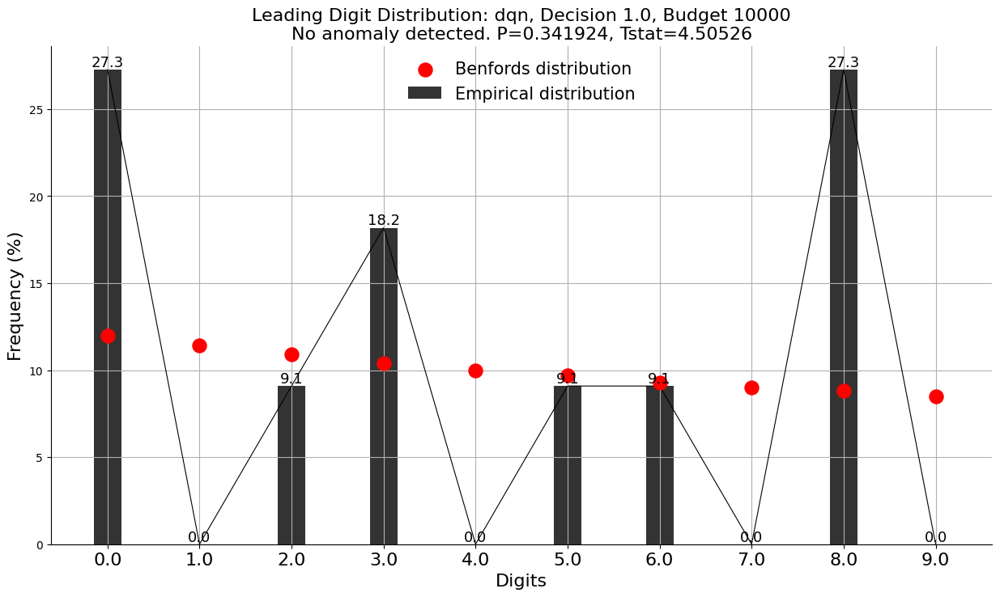

[2589.4  4880.18 1680.98 4359.6  8870.73 7080.51 2030.83 9023.59 1359.07
 5258.06 8828.39]
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.00465522, Tstat=15.0223


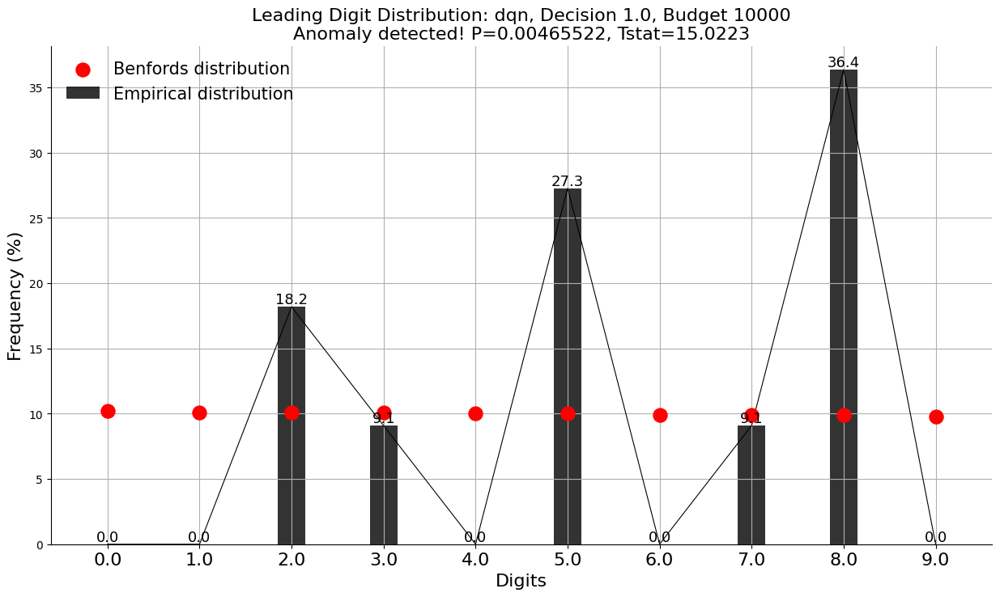

[128226.49  19992.31   4483.47  22528.8    6998.34   2800.25  46305.87
  42528.26  49302.05  44488.55  21371.5   10411.5   28537.79  72369.5
  15504.    22880.   178225.88  17809.2    9655.48 188162.21 145785.71
   9723.    30794.77   9777.19  91780.3   86315.08   9020.32  29937.85
  63603.45  95075.37    223.16 140826.49]
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0174542, Tstat=11.9862


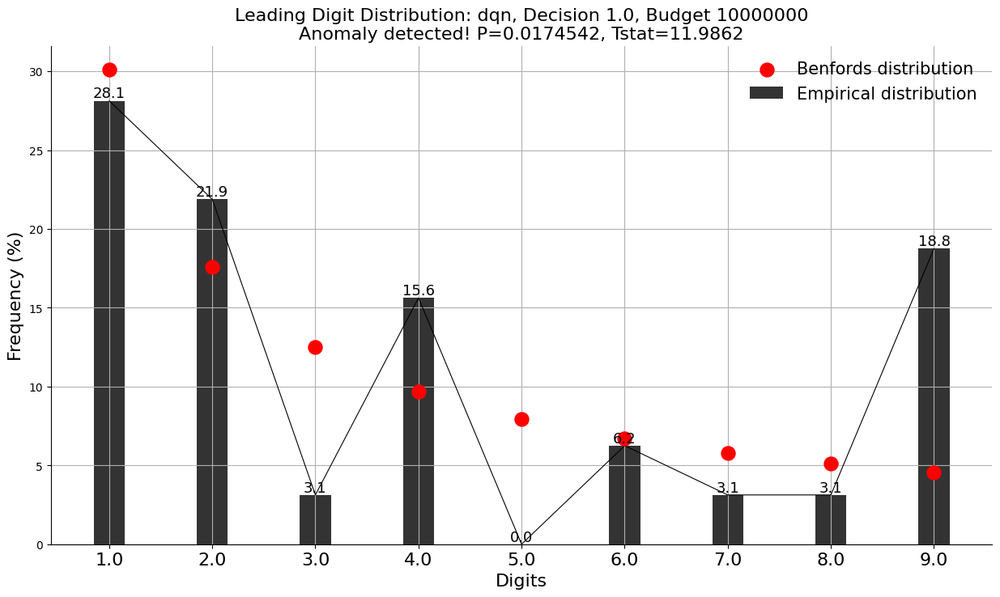

[128226.49  19992.31   4483.47  22528.8    6998.34   2800.25  46305.87
  42528.26  49302.05  44488.55  21371.5   10411.5   28537.79  72369.5
  15504.    22880.   178225.88  17809.2    9655.48 188162.21 145785.71
   9723.    30794.77   9777.19  91780.3   86315.08   9020.32  29937.85
  63603.45  95075.37    223.16 140826.49]
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.671393, Tstat=2.35159


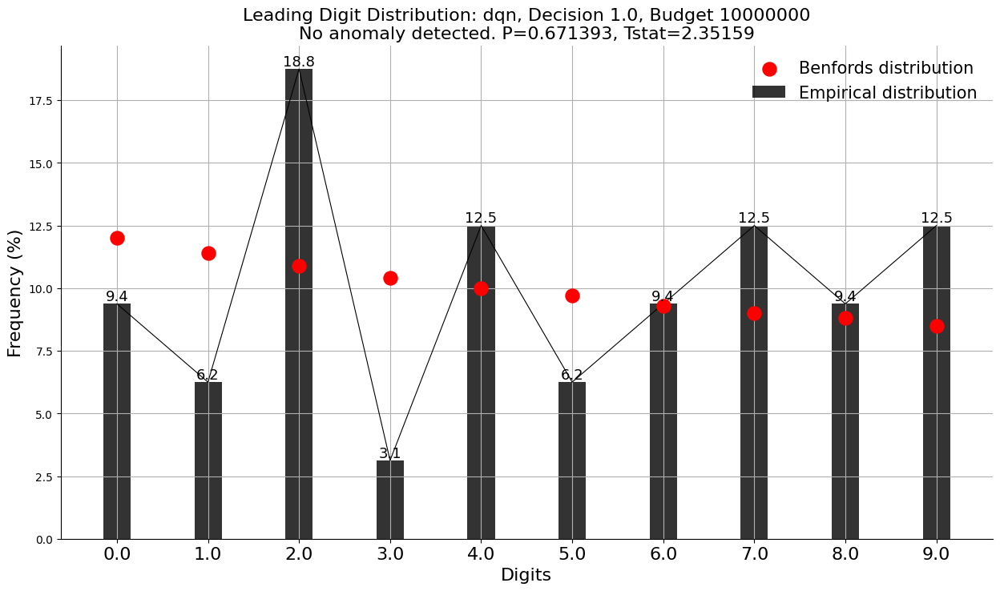

[128226.49  19992.31   4483.47  22528.8    6998.34   2800.25  46305.87
  42528.26  49302.05  44488.55  21371.5   10411.5   28537.79  72369.5
  15504.    22880.   178225.88  17809.2    9655.48 188162.21 145785.71
   9723.    30794.77   9777.19  91780.3   86315.08   9020.32  29937.85
  63603.45  95075.37    223.16 140826.49]
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] Anomaly detected! P=0.0143886, Tstat=12.4358


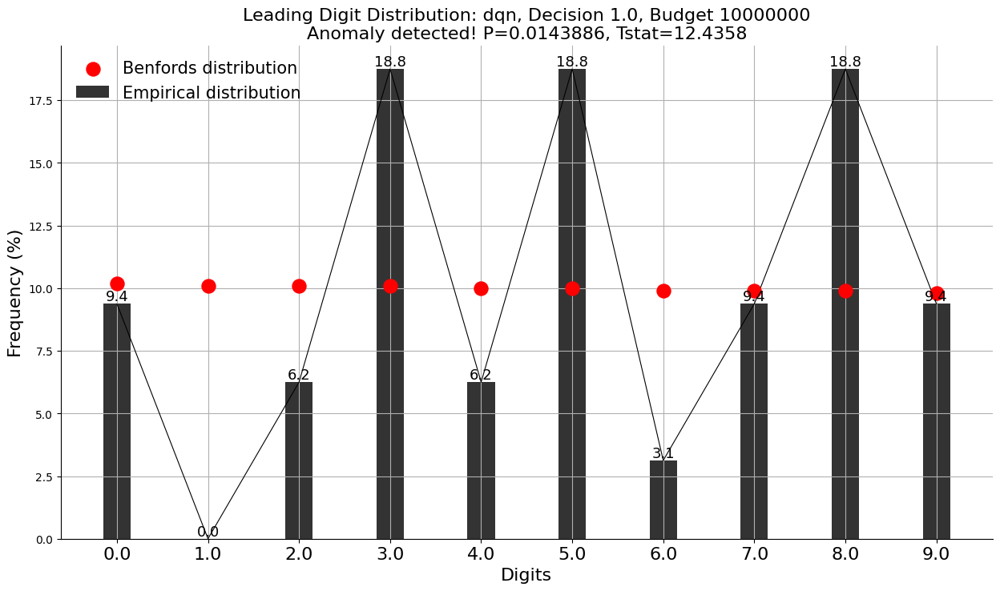

[128226.49  19992.31   4483.47 313634.9   22528.8  190726.75   6998.34
   9304.33  49302.05  44488.55  21371.5   10411.5  189101.72  23597.85
  28537.79  18650.13  39776.11  72369.5   15504.   178225.88 188162.21
  42435.36  32554.58  59174.4    9723.    30794.77   3930.2  229651.43
   9777.19   6485.87  51419.59  91780.3    9020.32  56165.26  39923.52
  95075.37 206290.82   5456.    61433.32  30071.58  35538.65  18508.9
 259941.99]
[benfordslaw] >Analyzing digit position: [1]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.31998, Tstat=4.6956


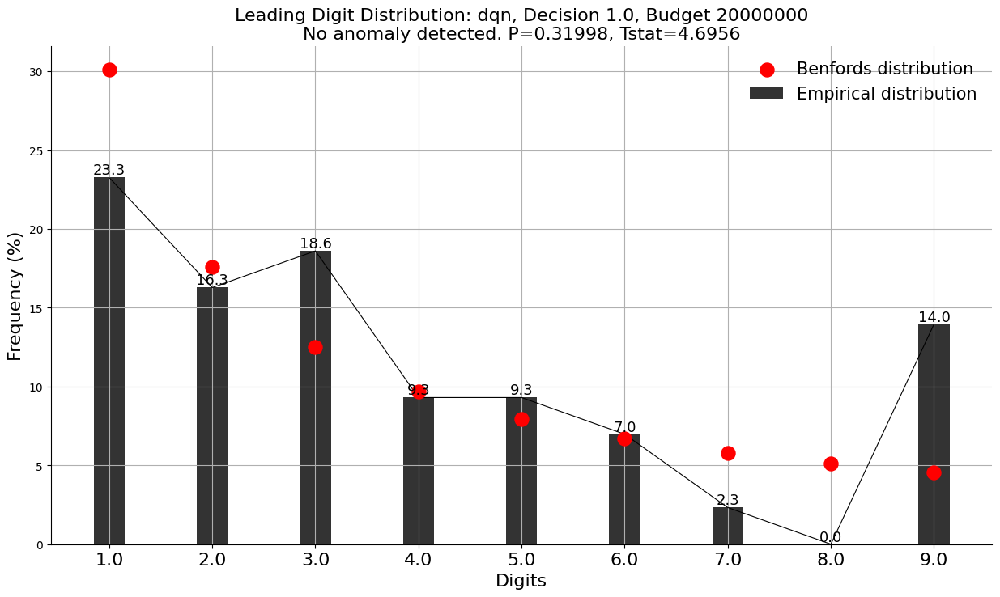

[128226.49  19992.31   4483.47 313634.9   22528.8  190726.75   6998.34
   9304.33  49302.05  44488.55  21371.5   10411.5  189101.72  23597.85
  28537.79  18650.13  39776.11  72369.5   15504.   178225.88 188162.21
  42435.36  32554.58  59174.4    9723.    30794.77   3930.2  229651.43
   9777.19   6485.87  51419.59  91780.3    9020.32  56165.26  39923.52
  95075.37 206290.82   5456.    61433.32  30071.58  35538.65  18508.9
 259941.99]
[benfordslaw] >Analyzing digit position: [2]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.442571, Tstat=3.73836


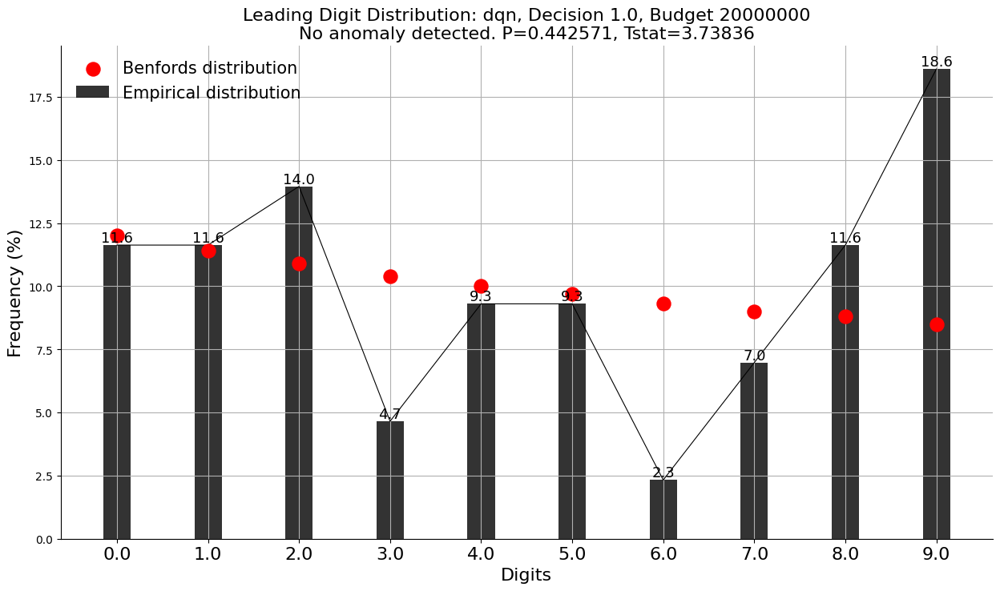

[128226.49  19992.31   4483.47 313634.9   22528.8  190726.75   6998.34
   9304.33  49302.05  44488.55  21371.5   10411.5  189101.72  23597.85
  28537.79  18650.13  39776.11  72369.5   15504.   178225.88 188162.21
  42435.36  32554.58  59174.4    9723.    30794.77   3930.2  229651.43
   9777.19   6485.87  51419.59  91780.3    9020.32  56165.26  39923.52
  95075.37 206290.82   5456.    61433.32  30071.58  35538.65  18508.9
 259941.99]
[benfordslaw] >Analyzing digit position: [3]
[benfordslaw] >[P_ensemble] No anomaly detected. P=0.303489, Tstat=4.84579


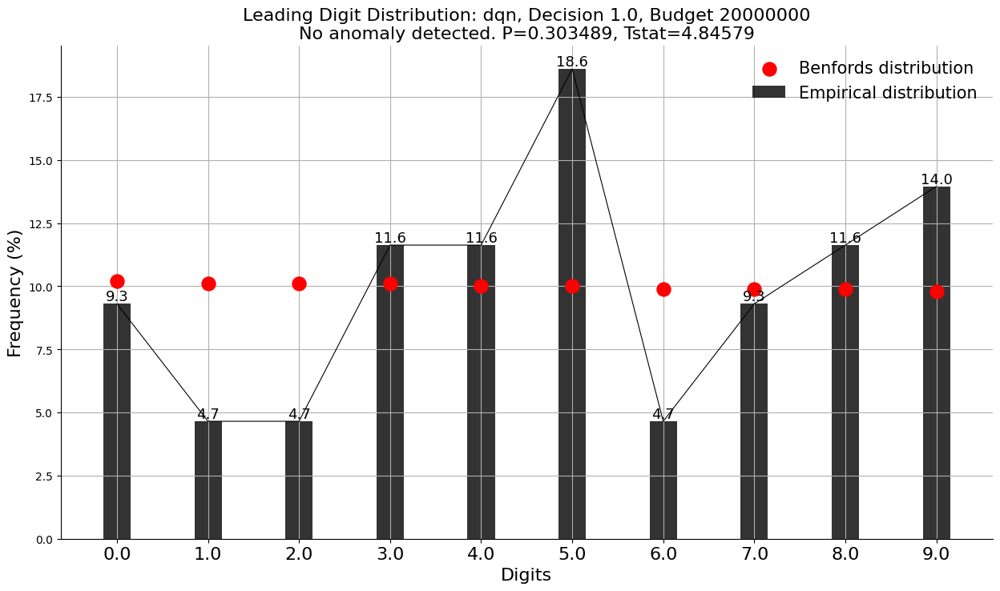

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from benfordslaw import benfordslaw
import numpy as np

# Clean the data by dropping NaN values in the 'value' column
data = data.dropna(subset=['value'])

# Define experiments, decisions, and budgets
experiments = ['random', 'dqn']
decisions = [0.0, 1.0]
budgets = list(data.initial_budget.unique())
# Loop through each combination
for experiment in experiments:
    for decision in decisions:
        for initial_budget in budgets:
            # Filter dataset for the specific combination
            subset = data[(data['experiment'] == experiment) & 
                          (data['decision'] == decision) & 
                          (data['initial_budget'] == initial_budget)]

            # Check if there are values to analyze
            if subset.empty:
                print(f"No data for {experiment}, Decision {decision}, Budget {initial_budget}.")
                continue
            for pos in (1, 2, 3):
                # Perform Benford analysis
                benford = benfordslaw(pos = pos, method = 'freedman')
                print(subset['value'].astype(float).values)
                # Plot Leading Digit Distribution
                benford.fit(subset['value'].values)
                benford.plot(title = f'Leading Digit Distribution: {experiment}, Decision {decision}, Budget {initial_budget}')

                # Perform Chi-Squared Test
                
                # Perform KS Test

                # Cumulative Distribution Plot

                # Residual Plot

                # Mean Absolute Deviation

                # Optionally: ANOVA or Kruskal-Wallis test if comparing multiple groups
                # (this would require gathering results from multiple combinations)


In [15]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from benfordslaw import benfordslaw

# Assuming the dataset 'data' is available
# We'll set up the grid generation function based on the suggestions

def create_benford_grid(data, experiment, results_dir):
    # Filter for the specific experiment
    experiment_data = data[data['experiment'] == experiment]
    
    # Group the data by episodes, decision, and initial_budget
    groups = experiment_data.groupby(['episodes', 'decision', 'initial_budget'])

    # Prepare a list to store the plots for the grid
    final_figures_grid = []

    # Initialize the Benford's Law analyzer
    bl = benfordslaw(method='freedman')

    # Iterate over each group and apply Benford's Law analysis
    for (episodes, decision, initial_budget), group in groups:
        valor_indenizacao = group['valor_indenizacao'].dropna().values
        
        if len(valor_indenizacao) == 0:
            print(f"No indemnity values available for Experiment: {experiment}, Episodes: {episodes}, Decision: {decision}, Initial Budget: {initial_budget}")
            continue
        
        # Apply Benford's Law with Kolmogorov-Smirnov test
        results = bl.fit(valor_indenizacao)
        
        # Generate the plot title, ensuring episode numbers are included
        plot_title = f"Episode: {episodes} - Budget: {initial_budget} - Decision: {decision}"
        fig, ax = bl.plot(title=plot_title)
        
        # Append the figure and metadata for grid creation
        final_figures_grid.append((episodes, decision, initial_budget, fig))
    
    # Sort the plots by episodes, initial_budget, and decision
    final_figures_grid.sort(key=lambda x: (x[0], x[2], x[1]))

    # Define the number of columns and rows for the grid layout
    num_plots = len(final_figures_grid)
    num_cols = 3  # Increasing to 3 columns for better balance
    num_rows = (num_plots + num_cols - 1) // num_cols  # Calculate the necessary number of rows
    
    # Create the figure and axes for the grid
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, num_rows * 5))
    fig.suptitle(f"Benford's Law Grid for {experiment.capitalize()} Experiment", fontsize=18)
    
    # Flatten axes if needed
    axes = axes.flatten() if num_rows > 1 else [axes]
    
    # Plot each figure in the appropriate grid position
    for i, (episodes, decision, initial_budget, plot_fig) in enumerate(final_figures_grid):
        # Clear the grid axis and place the plot in the grid
        axes[i].clear()
        plot_fig.axes[0].get_figure().axes[0].cla()  # Clear the old plot from its figure
        plot_fig.axes[0].set_position([0, 0, 1, 1])
        plot_fig.canvas.draw()
        axes[i].imshow(plot_fig.canvas.buffer_rgba())
        axes[i].set_title(f"Ep: {episodes}, Budget: {initial_budget}, Decision: {decision}", fontsize=10)
        axes[i].axis('off')  # Hide axis for the grid
    
    # Hide any remaining empty axes
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
    
    # Save the final grid figure
    grid_filename = os.path.join(results_dir, f"benford_grid_{experiment}.png")
    fig.savefig(grid_filename, bbox_inches='tight')
    plt.close(fig)
    
    print(f"Grid plot for {experiment} saved to: {grid_filename}")
    return grid_filename

# Simulate creating grid plots for "random" and "dqn"
results_dir = "../.temp/plots"
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

# Load your dataset into a Pandas DataFrame
data = pd.read_csv("../.temp/data/experiment_results/insurenv.csv")

# Execute the function for both experiments
create_benford_grid(data, "random", results_dir)
create_benford_grid(data, "dqn", results_dir)


FileNotFoundError: [Errno 2] No such file or directory: '../.temp/data/experiment_results/insurenv.csv'

In [149]:
import os
# Ensure the directory exists
output_dir = 'experiment_results/plots'
os.makedirs(output_dir, exist_ok=True)

# Create and save the plot
g = sns.FacetGrid(data, col='initial_budget', row='experiment', margin_titles=True, sharex=False)
g.map(plt.hist, 'steps', bins=30, edgecolor='black')
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Distribution of Episode Lengths by Experiment and Initial Budget')

# Save the figure
plot_path = os.path.join(output_dir, 'episode_lengths_by_experiment_and_budget.png')
g.savefig(plot_path)
plt.close(g.fig)

print(f"Plot saved to {plot_path}")


Plot saved to experiment_results/plots\episode_lengths_by_experiment_and_budget.png


In [150]:
from gym_insurance import constants as ct

# Rewards Analytics

C:\Users\nande\AppData\Local\Temp\ipykernel_28256\2626065567.py:6: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='initial_budget', y='rewards', hue='experiment', data=data, estimator='sum', ci=None)


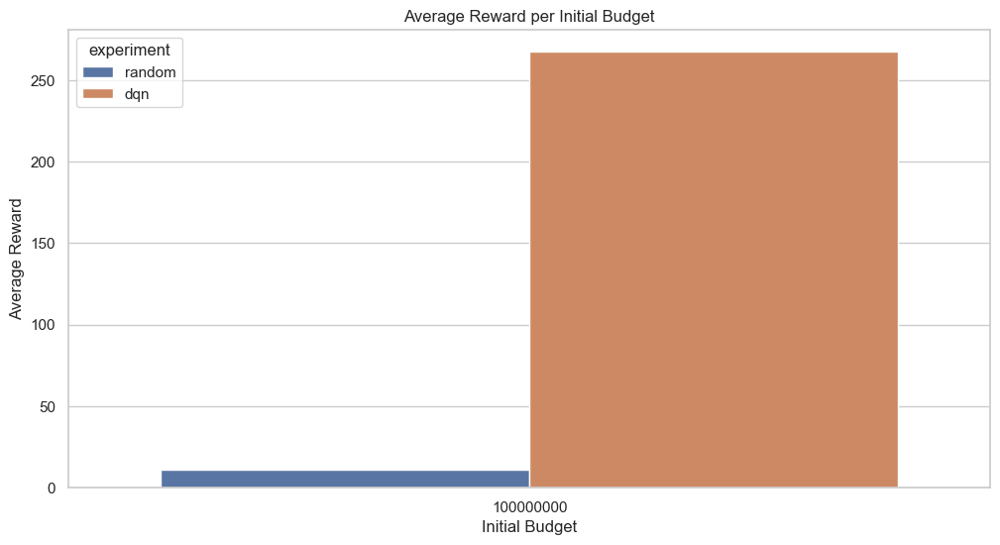

In [153]:
# Setting the aesthetic style of the plots
sns.set(style="whitegrid")

# Plot 1: Average Reward per Initial Budget
plt.figure(figsize=(12, 6))
sns.barplot(x='initial_budget', y='rewards', hue='experiment', data=data, estimator='sum', ci=None)
plt.title('Average Reward per Initial Budget')
plt.xlabel('Initial Budget')
plt.ylabel('Average Reward')
plt.show()


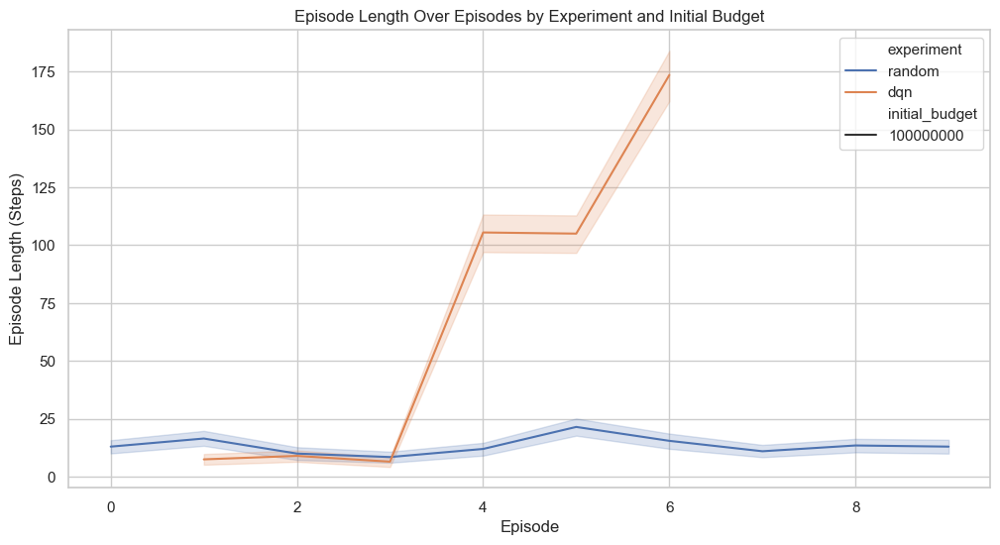

In [154]:
plt.figure(figsize=(12, 6))
sns.lineplot(x='episodes', y='steps', hue='experiment', style='initial_budget', data=data)
plt.title('Episode Length Over Episodes by Experiment and Initial Budget')
plt.xlabel('Episode')
plt.ylabel('Episode Length (Steps)')
plt.show()


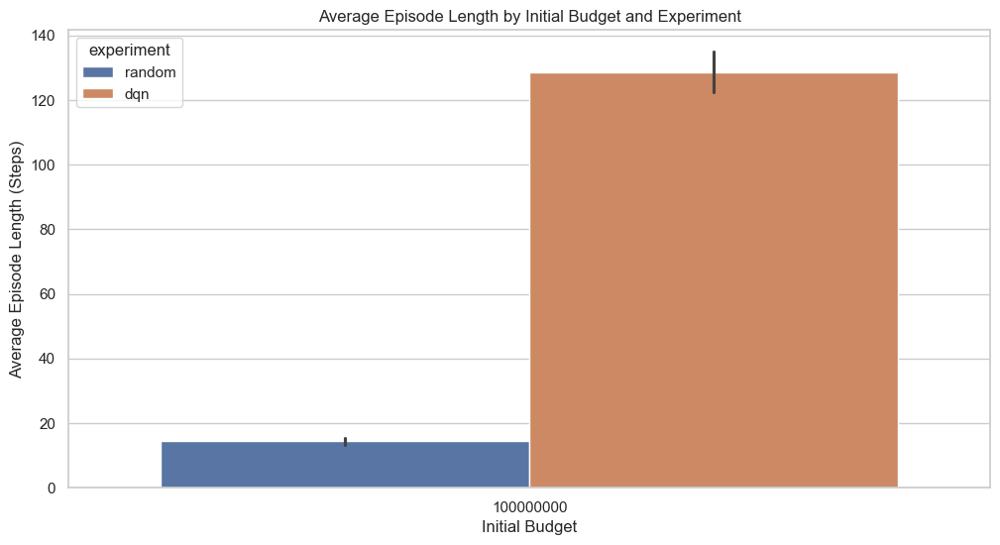

In [133]:
plt.figure(figsize=(12, 6))
sns.barplot(x='initial_budget', y='steps', hue='experiment', data=data)
plt.title('Average Episode Length by Initial Budget and Experiment')
plt.xlabel('Initial Budget')
plt.ylabel('Average Episode Length (Steps)')
plt.show()


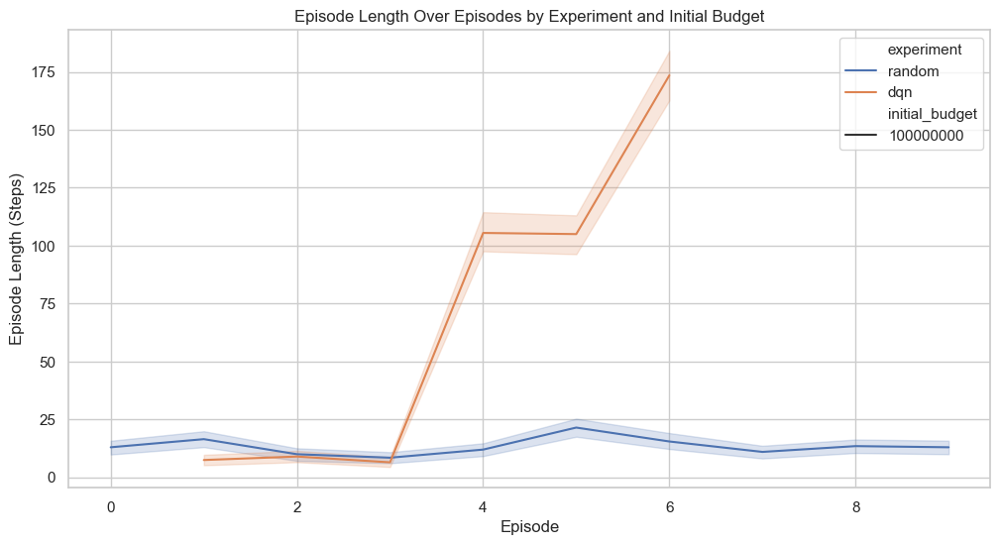

In [134]:
plt.figure(figsize=(12, 6))
sns.lineplot(x='episodes', y='steps', hue='experiment', style='initial_budget', data=data)
plt.title('Episode Length Over Episodes by Experiment and Initial Budget')
plt.xlabel('Episode')
plt.ylabel('Episode Length (Steps)')
plt.show()


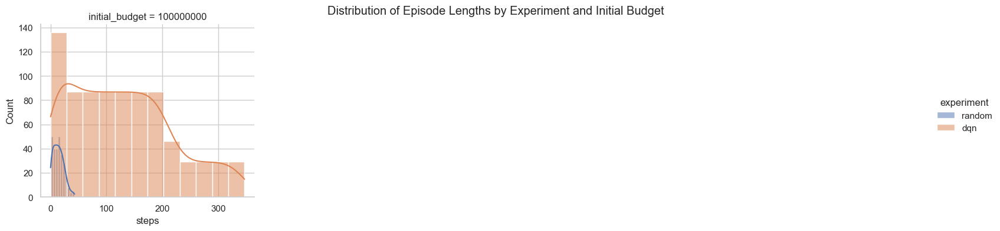

In [155]:
# Separate histograms for each initial budget
g = sns.FacetGrid(data, col='initial_budget', hue='experiment', col_wrap=4, height=4)
g.map(sns.histplot, 'steps', kde=True, multiple='stack')
g.add_legend()
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Distribution of Episode Lengths by Experiment and Initial Budget')
plt.show()

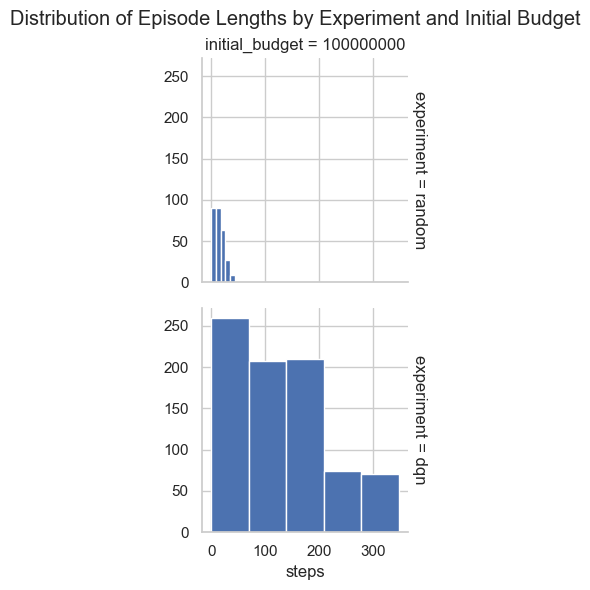

In [158]:
g = sns.FacetGrid(data, col='initial_budget', row='experiment', margin_titles=True)
g.map(plt.hist, 'steps', bins=5)
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Distribution of Episode Lengths by Experiment and Initial Budget')
plt.show()

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

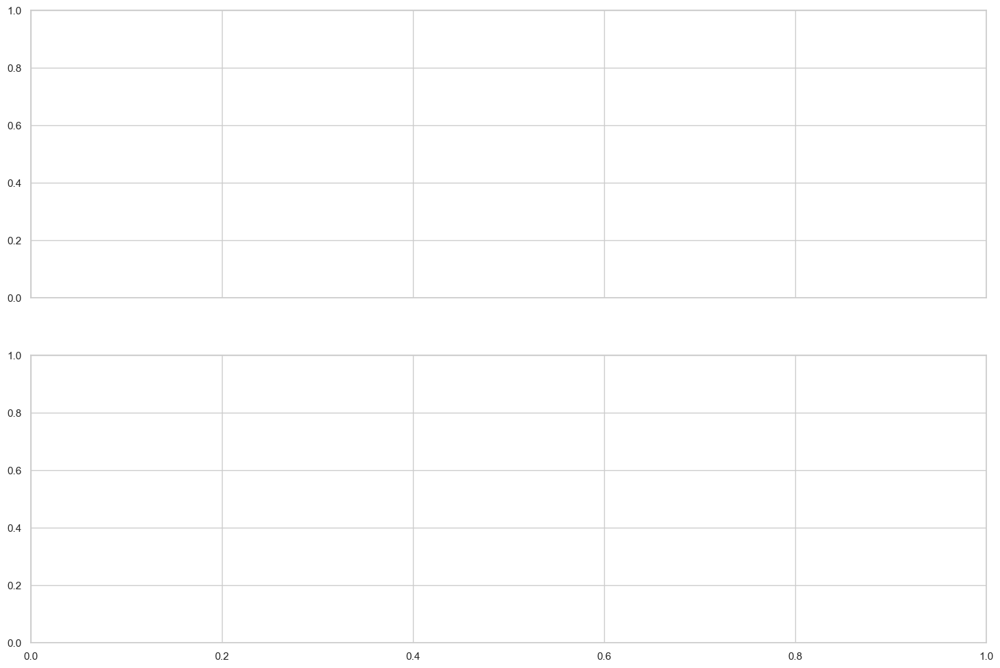

In [159]:

def plot_cumulative_rewards(data, budgets, column='rewards', experiment_types=['dqn', 'random'], window_size=1, save_path='plots'):
    # Set the style of seaborn
    sns.set(style="whitegrid")

    # Make sure the directory exists
    os.makedirs(save_path, exist_ok=True)

    # Define the number of subplots based on the number of budgets and experiment types
    fig, axes = plt.subplots(2, len(budgets), figsize=(18, 12), sharex='col')

    # We assume that the maximum number of episodes is consistent across all budgets
    max_episodes = data['episodes'].max()

    for j, row in enumerate(['Raw', 'Smoothed']):
        for i, budget in enumerate(budgets):
            ax = axes[j, i]
            for experiment in experiment_types:
                # Filter the data for the current experiment and budget
                filtered_data = data.query(f"experiment == '{experiment}' and initial_budget == {budget}")
                # Calculate the cumulative rewards
                cumulative_rewards = filtered_data.groupby("episodes")[column].sum().cumsum()

                # If raw plot, skip smoothing
                if row == 'Raw':
                    rewards_to_plot = cumulative_rewards
                else:
                    # Calculate the moving average for smoothing
                    rewards_to_plot = cumulative_rewards.rolling(window=window_size, min_periods=1).mean()

                # Plot using seaborn lineplot
                sns.lineplot(x=filtered_data['episodes'], y=rewards_to_plot, ax=ax, label=f"{experiment}")

            # Set the title for each subplot in the top row
            if j == 0:
                ax.set_title(f'Budget: {budget}')
            ax.set_xlabel('Episodes')
            ax.set_ylabel(f'{row} Cumulative Rewards')
            ax.legend()
            ax.set_xlim(0, max_episodes)  # Set consistent x-axis limits

    plt.tight_layout()

    # Save the figure
    plot_file_path = os.path.join(save_path, 'cumulative_rewards_comparison.png')
    plt.savefig(plot_file_path)
    print(f"Plot saved to {plot_file_path}")

    plt.show()

# Example usage with a list of budgets
plot_cumulative_rewards(data, budgets = budgets)

In [160]:
df = data.pivot_table(index = "initial_budget", columns = ["experiment", "decision"], values ="budget",aggfunc='count')
df

KeyError: 'budget'

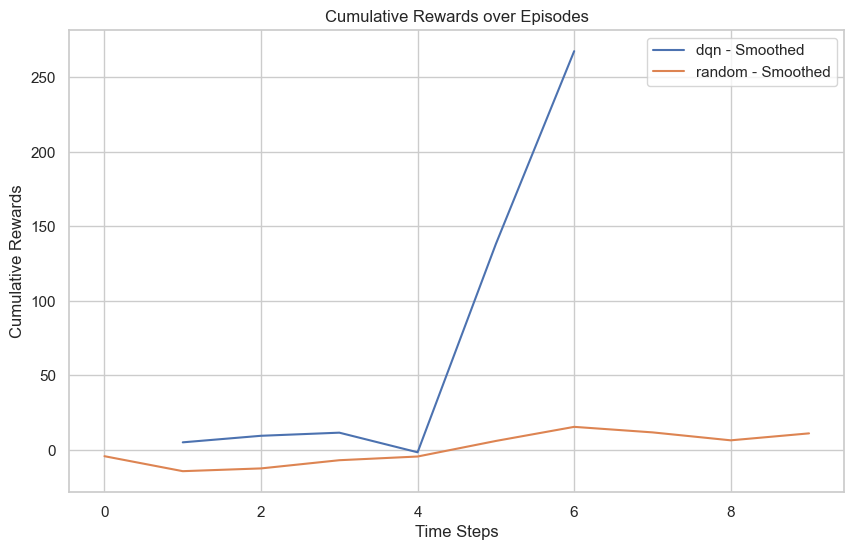

In [164]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_cumulative_rewards(data, budget=100_000_000, column='rewards', experiment_types=['dqn', 'random'], window_size=1):
    plt.figure(figsize=(10, 6))

    for experiment in experiment_types:
        filtered_data = data.query(f"experiment == '{experiment}' and initial_budget == {budget}").reset_index()
        cumulative_rewards = filtered_data.groupby("episodes")[column].sum()
        cumulative_rewards = cumulative_rewards.cumsum()
        # Calculate the moving average for smoothing
        smoothed_rewards = cumulative_rewards.rolling(window=window_size, min_periods=1).mean()

        #plt.plot(cumulative_rewards, label=f"{experiment} - Raw")
        plt.plot(smoothed_rewards, label=f"{experiment} - Smoothed")

    plt.xlabel('Time Steps')
    plt.ylabel('Cumulative Rewards')
    plt.title('Cumulative Rewards over Episodes')
    plt.legend()
    plt.show()

# Example usage
plot_cumulative_rewards(data, budget=100_000_000)


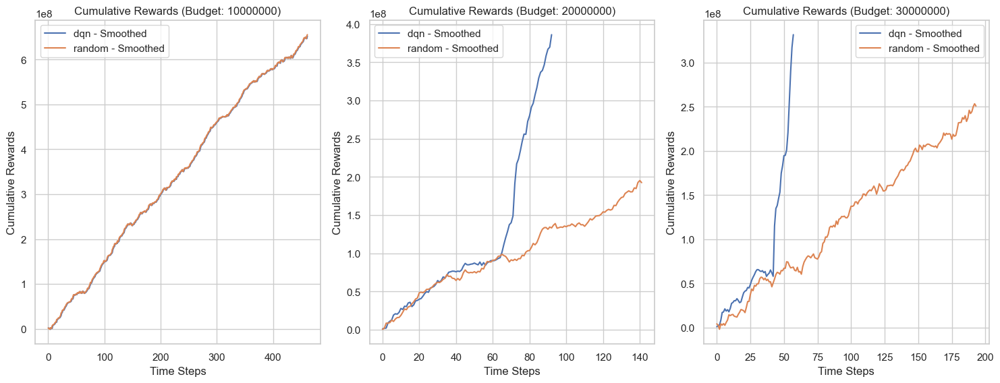

TypeError: 'Axes' object is not subscriptable

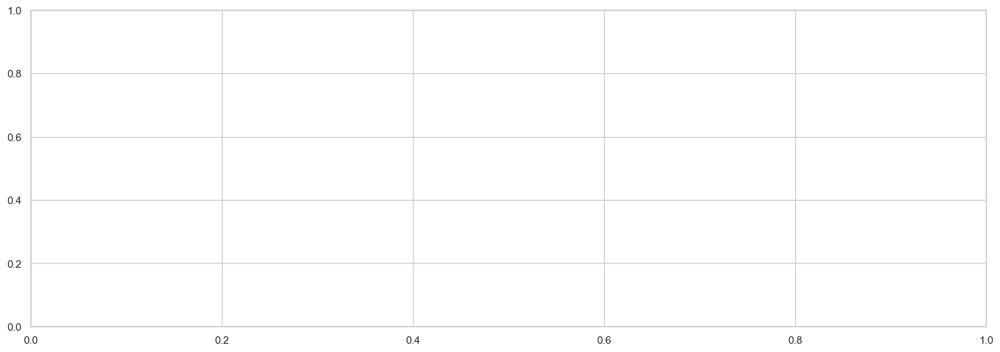

In [165]:
def plot_cumulative_rewards(data, budgets, column='rewards', experiment_types=['dqn', 'random'], window_size=1):
    # Set the style of seaborn
    sns.set(style="whitegrid")

    # Define the number of subplots based on the number of budgets
    fig, axes = plt.subplots(1, len(budgets), figsize=(18, 6), sharey=True)

    for i, budget in enumerate(budgets):
        ax = axes[i]
        for experiment in experiment_types:
            # Filter the data for the current experiment and budget
            filtered_data = data.query(f"experiment == '{experiment}' and initial_budget == {budget}")
            # Calculate the cumulative rewards
            cumulative_rewards = filtered_data.groupby("episodes")[column].sum().cumsum()
            # Calculate the moving average for smoothing
            smoothed_rewards = cumulative_rewards.rolling(window=window_size, min_periods=1).mean()

            # Plot using seaborn lineplot
            sns.lineplot(x=filtered_data['episodes'], y=smoothed_rewards, ax=ax, label=f"{experiment} - {budget}")

        # Set the title for each subplot
        ax.set_title(f'Budget: {budget}')
        ax.set_xlabel('Episodes')
        ax.set_ylabel('Cumulative Rewards')
        ax.legend()

    plt.tight_layout()
    plt.show()

# Example usage with a list of budgets
plot_cumulative_rewards(data, budgets=[100_000_000])

In [166]:
data.query('experiment=="dqn"').groupby(["initial_budget"])["episodes"].max()

initial_budget
100000000    6
Name: episodes, dtype: int64

<Axes: >

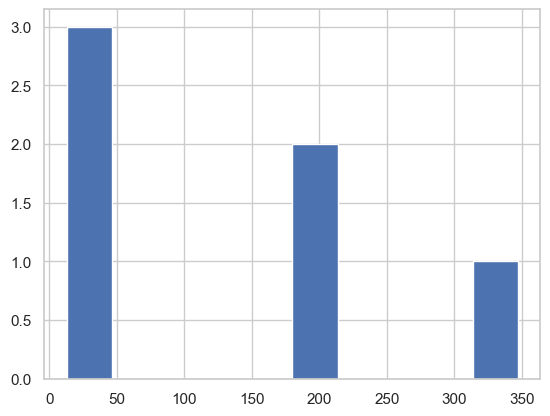

In [167]:
data.query('experiment=="dqn"').groupby(["initial_budget", "episodes"])["steps"].max().hist()

<Axes: >

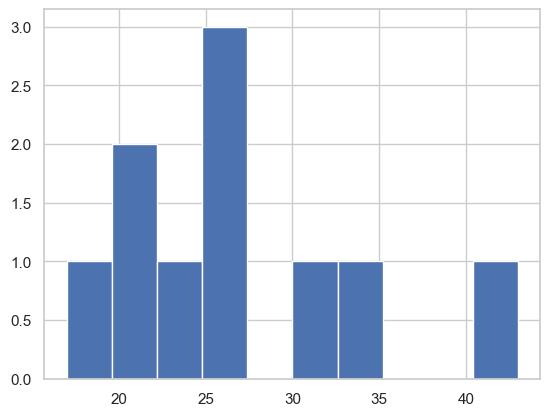

In [168]:
data.query('experiment=="random"').groupby(["initial_budget", "episodes"])["steps"].max().hist()

In [169]:

data.query("experiment =='dqn' and initial_budget == 15000000").rewards.sum()

0.0

In [170]:

data.query("experiment =='dqn' and initial_budget == 15000000").rewards.sum()/data.query("experiment =='random' and initial_budget == 15000000").rewards.sum()


C:\Users\nande\AppData\Local\Temp\ipykernel_28256\3552338379.py:1: RuntimeWarning: invalid value encountered in scalar divide
  data.query("experiment =='dqn' and initial_budget == 15000000").rewards.sum()/data.query("experiment =='random' and initial_budget == 15000000").rewards.sum()


nan

In [14]:
data.query("experiment =='dqn' and initial_budget == 10000000").valor_indenizacao.sum()

0.0

In [15]:
data.query("initial_budget == 10000000").groupby("experiment")['valor_indenizacao'].describe()

,count,mean,std,min,25%,50%,75%,max


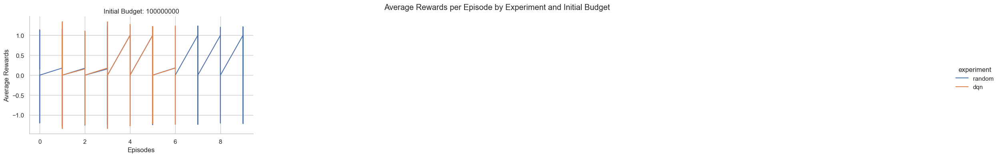

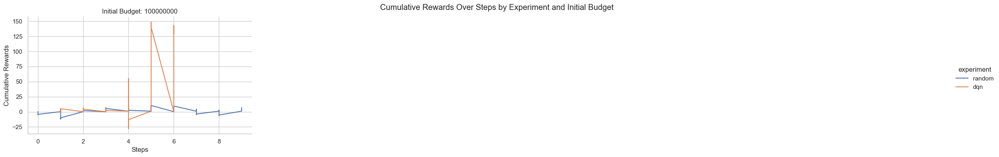

In [173]:

# Adding a cumulative reward column
data['cumulative_rewards'] = data.groupby(['experiment', 'initial_budget', 'episodes'])['rewards'].cumsum()

# Define a function to create faceted plots
def create_faceted_plot(data, x_col, y_col, title, xlabel, ylabel):
    g = sns.FacetGrid(data, col='initial_budget', hue='experiment', col_wrap=4, height=4, aspect=1.5, sharex=False)
    g = g.map(plt.plot, x_col, y_col).add_legend()
    g.set_titles(col_template="Initial Budget: {col_name}")
    g.set_axis_labels(xlabel, ylabel)
    plt.subplots_adjust(top=0.9)
    g.fig.suptitle(title)

# 1. Episodic Metrics Plot
create_faceted_plot(data, 'episodes', 'rewards', 
                    'Average Rewards per Episode by Experiment and Initial Budget', 
                    'Episodes', 'Average Rewards')

# 2. Action vs Rewards Metrics Plot (if action data is available)
# Assuming 'actions' column exists or can be derived
# Uncomment and modify if applicable
# create_faceted_plot(data, 'actions', 'rewards', 
#                     'Average Rewards by Action, Experiment, and Initial Budget', 
#                     'Actions', 'Average Rewards')

# 3. Cumulative Rewards Plot
create_faceted_plot(data, 'episodes', 'cum_rewards', 
                    'Cumulative Rewards Over Steps by Experiment and Initial Budget', 
                    'Steps', 'Cumulative Rewards')

plt.show()

In [174]:
data["cum_rewards"] = data.groupby(["experiment", "initial_budget"])["rewards"].cumsum()

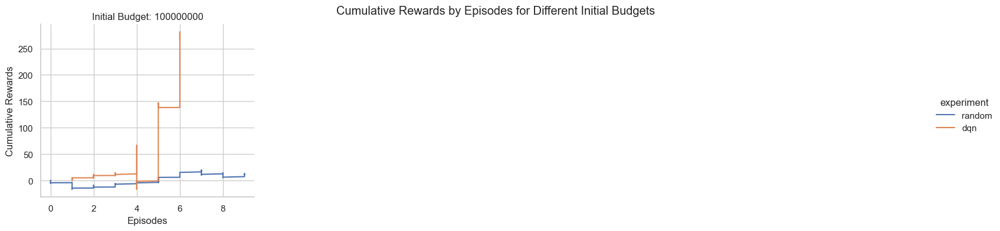

In [175]:
# Create a Faceted Line Plot for Cumulative Rewards by Episodes
def plot_cumulative_rewards_by_episodes(data):
    g = sns.FacetGrid(data, col='initial_budget', hue='experiment', col_wrap=4, height=4, aspect=1, sharex=False)
    g = g.map(plt.plot, 'episodes', 'cum_rewards').add_legend()
    g.set_titles(col_template="Initial Budget: {col_name}")
    g.set_axis_labels("Episodes", "Cumulative Rewards")
    plt.subplots_adjust(top=0.9)
    g.fig.suptitle('Cumulative Rewards by Episodes for Different Initial Budgets')

plot_cumulative_rewards_by_episodes(data)
plt.show()

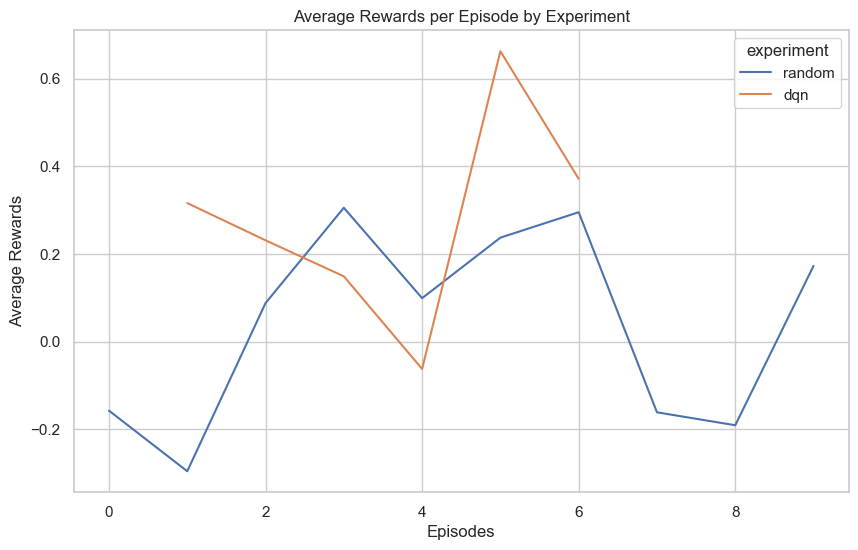

In [176]:

episodic_metrics = data.groupby(['episodes', 'experiment']).agg({'rewards': 'mean'}).reset_index()
plt.figure(figsize=(10, 6))
sns.lineplot(data=episodic_metrics, x='episodes', y='rewards', hue='experiment')
plt.title('Average Rewards per Episode by Experiment')
plt.xlabel('Episodes')
plt.ylabel('Average Rewards')
plt.show()

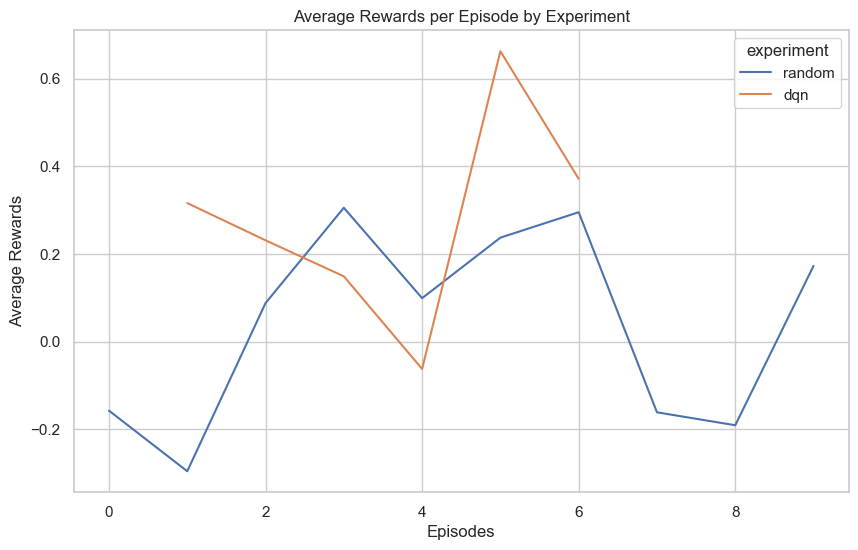

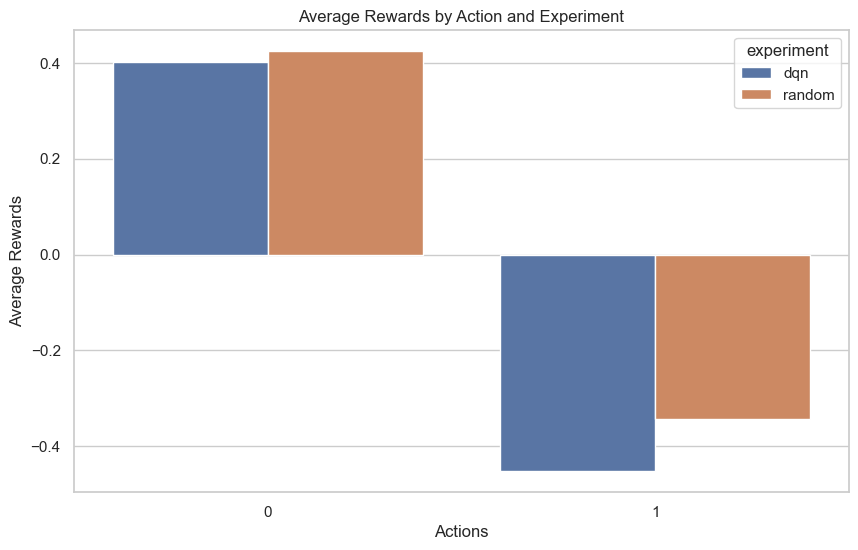

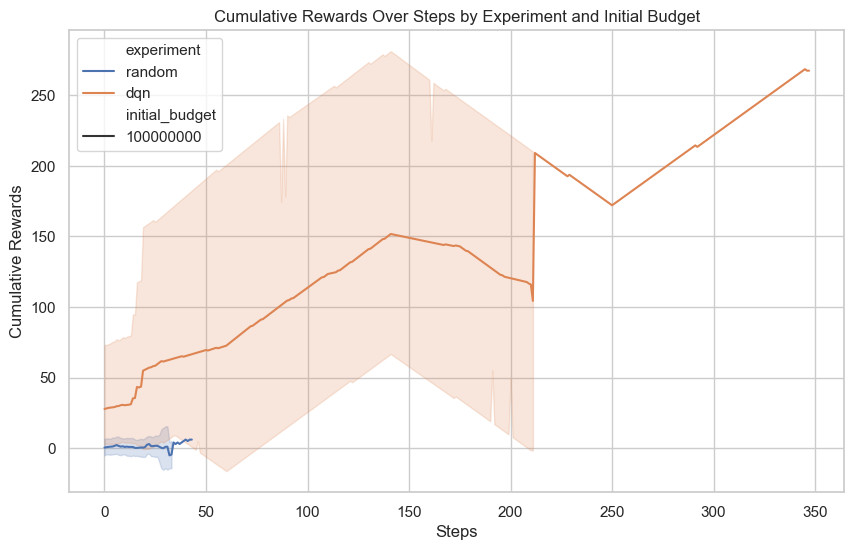

In [177]:
episodic_metrics = data.groupby(['episodes', 'experiment']).agg({'rewards': 'mean'}).reset_index()

## 2. Action vs Rewards Metrics
# Assuming 'actions' column exists or can be derived
action_rewards_metrics = data.groupby(['decision', 'experiment']).agg({'rewards': 'mean'}).reset_index()

## 3. Cumulative Rewards
data['cumulative_rewards'] = data.groupby(['experiment', 'initial_budget'])['rewards'].cumsum()

# Visualization
## Episodic Metrics Plot
plt.figure(figsize=(10, 6))
sns.lineplot(data=episodic_metrics, x='episodes', y='rewards', hue='experiment')
plt.title('Average Rewards per Episode by Experiment')
plt.xlabel('Episodes')
plt.ylabel('Average Rewards')
plt.show()

## Action vs Rewards Metrics Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=action_rewards_metrics, x='decision', y='rewards', hue='experiment')
plt.title('Average Rewards by Action and Experiment')
plt.xlabel('Actions')
plt.ylabel('Average Rewards')
plt.show()

## Cumulative Rewards Plot
plt.figure(figsize=(10, 6))
sns.lineplot(data=data, x='steps', y='cumulative_rewards', hue='experiment', style='initial_budget')
plt.title('Cumulative Rewards Over Steps by Experiment and Initial Budget')
plt.xlabel('Steps')
plt.ylabel('Cumulative Rewards')
plt.show()

In [178]:
data.groupby(["experiment", "initial_budget","decision"])['rewards'].sum()

experiment  initial_budget  decision
dqn         100000000       0           300.537897
                            1           -33.014528
random      100000000       0            58.995824
                            1           -47.918399
Name: rewards, dtype: float64

In [179]:
data

,decision,value,rewards,cum_rewards,initial_budget,wc,woc,steps,nr_documento_segurado,nr_proposta,...,third_digit_5,third_digit_6,third_digit_7,third_digit_8,third_digit_9,third_digit_10,valor_indenizacao,episodes,experiment,cumulative_rewards
0,1,138415.20,0.156323,0.156323,100000000,0.156323,0.000000,0,***74542961,02011165098,...,0.0,0.0,0.0,0.0,1.0,0.0,138415.20,0,random,0.156323
1,1,22528.80,0.213854,0.370177,100000000,0.213854,0.000000,1,***24763915,10000116410000350039,...,0.0,1.0,0.0,0.0,0.0,0.0,22528.80,0,random,0.370177
2,1,38409.09,-1.199387,-0.829210,100000000,0.256494,0.213854,2,***16142915,117641356,...,1.0,0.0,0.0,0.0,0.0,0.0,38409.09,0,random,-0.829210
3,1,190726.75,-1.153892,-1.983102,100000000,0.295966,0.256494,3,***47948987,4500679,...,0.0,0.0,0.0,0.0,0.0,0.0,190726.75,0,random,-1.983102
4,1,6998.34,-1.122165,-3.105267,100000000,0.332123,0.295966,4,***64071949,263518512,...,0.0,0.0,0.0,0.0,0.0,1.0,6998.34,0,random,-3.105267
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
815,0,32670.00,1.038939,266.507620,100000000,0.452226,0.435277,343,***24388915,02011050461,...,0.0,0.0,1.0,0.0,0.0,0.0,32670.00,6,dqn,266.507620
816,0,83650.13,1.038939,267.546559,100000000,0.452226,0.435277,344,***82071950,64791,...,0.0,0.0,1.0,0.0,0.0,0.0,83650.13,6,dqn,267.546559
817,0,137592.06,1.038939,268.585497,100000000,0.452226,0.435277,345,***42727934,64106,...,0.0,0.0,0.0,1.0,0.0,0.0,137592.06,6,dqn,268.585497
818,1,452562.91,-1.062128,267.523369,100000000,0.480322,0.452226,346,***44849968,1000116410000304335,...,0.0,0.0,0.0,0.0,0.0,0.0,452562.91,6,dqn,267.523369


<Axes: >

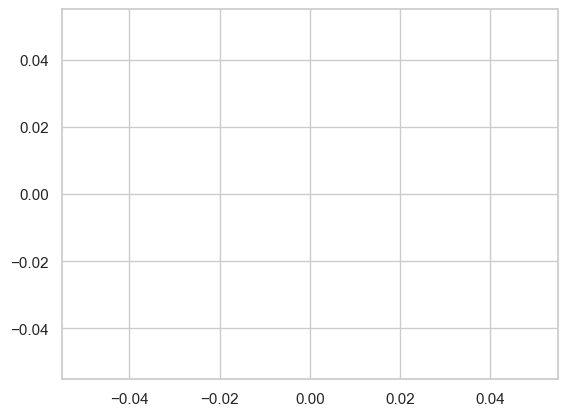

In [180]:
data.query("initial_budget == 1000000 and experiment =='random'")['cum_rewards'].plot()

<Axes: >

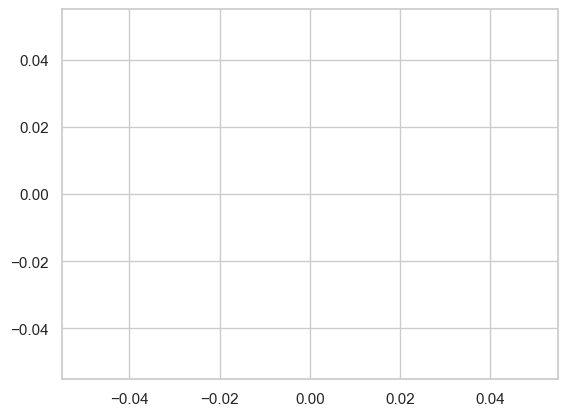

In [181]:
data.query("initial_budget == 1000000 and experiment =='dqn'")['cum_rewards'].plot()

In [182]:
data.query("initial_budget == 15000000").groupby("experiment").steps.sum()

Series([], Name: steps, dtype: int64)

In [183]:
data.groupby("experiment").episodes.max()

experiment
dqn       6
random    9
Name: episodes, dtype: int64

In [184]:
data.query("initial_budget == 1000000 and experiment =='dqn'")['decision'].value_counts()

Series([], Name: count, dtype: int64)

In [185]:
data.filter(regex='budget').columns

Index(['initial_budget'], dtype='object')

In [186]:
data["pct_budget"] = data.budget / data.initial_budget
# Set Pandas display option to show the whole number
pd.set_option('display.float_format', '{:.2f}'.format)

AttributeError: 'DataFrame' object has no attribute 'budget'

In [104]:
summary_budget = data.query("decision ==1").pivot_table(index = ["experiment","initial_budget"], columns = ["episodes"], values = "valor_indenizacao", aggfunc='sum')

In [187]:
summary_budget

NameError: name 'summary_budget' is not defined

In [188]:
import pandas as pd

# Assuming 'data' is your DataFrame

# Create a pivot table to count the decisions
pivot_table = data.query("episodes<10").pivot_table(index="initial_budget", columns=["experiment", "decision"], values="budget", aggfunc='count')

# Normalize the counts to get percentages for each group separately
percentage_table = pivot_table.copy()

for group in ['dqn', 'random']:
    group_columns = [col for col in pivot_table.columns if col[0] == group]
    total_counts_group = pivot_table[group_columns].sum(axis=1)
    percentage_table[group_columns] = pivot_table[group_columns].div(total_counts_group, axis=0) * 100

# Display the percentage table
print(percentage_table)



KeyError: 'budget'

In [189]:
def perform_statistical_tests(data):
    #df = data.query("episodes<10").copy(deep = True)
    # Flatten the multi-level column structure for easier processing
    df.columns = ['_'.join(map(str, col)).strip() for col in df.columns.values]

    # Initialize a dictionary to store test results
    results = {}

    # Independent Samples t-test and Mann-Whitney U Test between dqn and random for each decision
    for decision in [0, 1]:
        dqn_col = f'dqn_{decision}'
        random_col = f'random_{decision}'

        # T-test
        t_stat, t_p = stats.ttest_ind(df[dqn_col], df[random_col], equal_var=False)
        results[f'T-test Decision {decision}'] = t_p

        # Mann-Whitney U Test
        u_stat, u_p = stats.mannwhitneyu(df[dqn_col], df[random_col])
        results[f'Mann-Whitney U Test Decision {decision}'] = u_p

    # Chi-Square Test of Independence
    for budget in df.index:
        obs = df.loc[budget, [f'dqn_{i}' for i in [0, 1]] + [f'random_{i}' for i in [0, 1]]].values.reshape(2, 2)
        chi2, chi_p, _, _ = stats.chi2_contingency(obs)
        results[f'Chi-Square Test Budget {budget}'] = chi_p

    # Fisher's Exact Test
    for budget in df.index:
        obs = df.loc[budget, [f'dqn_{i}' for i in [0, 1]] + [f'random_{i}' for i in [0, 1]]].values.reshape(2, 2)
        _, fisher_p = stats.fisher_exact(obs)
        results[f'Fisher Exact Test Budget {budget}'] = fisher_p

    return pd.DataFrame.from_dict(results, orient='index', columns=['P-Value'])
test_results = perform_statistical_tests(df)
print(test_results)


NameError: name 'df' is not defined